## 題號 1
**問題**: 周天成使用「殺球」得分佔他總得分的百分比是多少？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


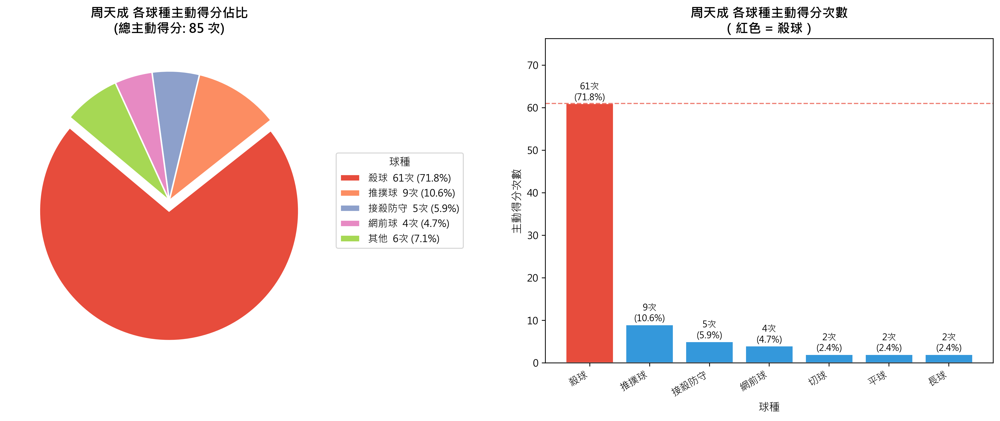

In [ ]:
import numpy as np

# === 驗證數據量 ===
print(f"資料總筆數: {len(df)}")
assert len(df) > 0, "資料為空！"

player_name = 'CHOU Tien Chen'

# === 分母：周天成所有主動得分（Active Win）===
active_win_mask = (
    (df['player'] == player_name) &
    (df['getpoint_player'] == player_name)
)
total_active_win = active_win_mask.sum()
print(f"\n周天成 主動得分總次數（分母）: {total_active_win}")

# === 分子：周天成以「殺球」主動得分 ===
smash_active_win_mask = (
    (df['player'] == player_name) &
    (df['type'] == '殺球') &
    (df['getpoint_player'] == player_name)
)
smash_active_win = smash_active_win_mask.sum()
print(f"周天成 殺球主動得分次數（分子）: {smash_active_win}")

# === 計算百分比 ===
if total_active_win > 0:
    pct = smash_active_win / total_active_win * 100
    print(f"\n【結果】殺球直接得分佔周天成總主動得分的比例: {smash_active_win}/{total_active_win} = {pct:.2f}%")
else:
    print("無法計算，總主動得分為 0。")
    pct = 0

# === 統計各球種主動得分次數 ===
shot_win_counts = (
    df[active_win_mask]
    .groupby('type')
    .size()
    .reset_index(name='得分次數')
    .sort_values('得分次數', ascending=False)
    .reset_index(drop=True)
)
shot_win_counts['佔比(%)'] = shot_win_counts['得分次數'] / total_active_win * 100

print("\n周天成各球種主動得分次數：")
print(shot_win_counts.to_string(index=False))

# === 合併小比例類別（< 3%）為「其他」（用於圓餅圖）===
threshold = 3.0
main = shot_win_counts[shot_win_counts['佔比(%)'] >= threshold].copy()
other_count = shot_win_counts[shot_win_counts['佔比(%)'] < threshold]['得分次數'].sum()

if other_count > 0:
    other_row = pd.DataFrame([{
        'type': '其他',
        '得分次數': int(other_count),
        '佔比(%)': other_count / total_active_win * 100
    }])
    main = pd.concat([main, other_row], ignore_index=True)

# === 繪製圓餅圖 explode（殺球那片往外推）===
explode_vals = [0.08 if t == '殺球' else 0.0 for t in main['type']]

# === 視覺化 ===
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- 左圖：圓餅圖 ---
colors = list(plt.cm.Set2.colors)
pie_colors = ['#e74c3c' if t == '殺球' else colors[i % len(colors)]
              for i, t in enumerate(main['type'])]

wedge_labels = [
    f"{row['type']}  {row['得分次數']}次 ({row['佔比(%)']:.1f}%)"
    for _, row in main.iterrows()
]

wedges, texts = axes[0].pie(
    main['得分次數'],
    labels=None,
    colors=pie_colors,
    startangle=140,
    explode=explode_vals,
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)

axes[0].legend(
    wedges,
    wedge_labels,
    title="球種",
    loc="center left",
    bbox_to_anchor=(1.0, 0.5),
    fontsize=10,
    title_fontsize=11
)
axes[0].set_title(
    f'周天成 各球種主動得分佔比\n(總主動得分: {total_active_win} 次)',
    fontsize=13, fontweight='bold'
)

# --- 右圖：長條圖 ---
bar_colors = ['#e74c3c' if t == '殺球' else '#3498db'
              for t in shot_win_counts['type']]

bars = axes[1].bar(
    shot_win_counts['type'],
    shot_win_counts['得分次數'],
    color=bar_colors,
    edgecolor='white',
    linewidth=1.2
)

# 標注數值與百分比
for bar, (_, row) in zip(bars, shot_win_counts.iterrows()):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{int(row['得分次數'])}次\n({row['佔比(%)']:.1f}%)",
        ha='center', va='bottom', fontsize=9
    )

axes[1].set_title('周天成 各球種主動得分次數\n（紅色 = 殺球）', fontsize=13, fontweight='bold')
axes[1].set_xlabel('球種', fontsize=11)
axes[1].set_ylabel('主動得分次數', fontsize=11)
axes[1].set_xticklabels(shot_win_counts['type'], rotation=30, ha='right')
axes[1].set_ylim(0, shot_win_counts['得分次數'].max() * 1.25)

# 加上參考線
axes[1].axhline(y=smash_active_win, color='#e74c3c', linestyle='--', linewidth=1.2, alpha=0.7)

plt.tight_layout()

print(f"\n========== 最終答案 ==========")
print(f"周天成「殺球」直接得分次數: {smash_active_win} 次")
print(f"周天成 主動得分總次數:       {total_active_win} 次")
print(f"殺球得分佔總主動得分比例:    {pct:.2f}%")


### 數據洞察
# 周天成殺球得分分析

## 核心數據
| 指標 | 數值 |
|------|------|
| 殺球直接得分 | 61 次 |
| 主動得分總計 | 85 次 |
| **殺球得分佔比** | **71.76%** |

## 各球種主動得分分佈
| 球種 | 次數 | 佔比 |
|------|------|------|
| 🔴 殺球 | 61 | 71.8% |
| 推撲球 | 9 | 10.6% |
| 接殺防守 | 5 | 5.9% |
| 網前球 | 4 | 4.7% |
| 其他 | 6 | 7.1% |

---

## 戰術洞察

**殺球是周天成最核心的得分武器**，超過七成主動得分來自殺球，這不是偶然——代表他的殺球品質高、落點精準，對手難以有效防守。

**推撲球（10.6%）** 是第二得分手段，說明他在網前及後場過渡球的把握能力同樣具備威脅。

**對手備戰重點**：防守周天成時，必須優先建立殺球防守體系，若無法有效接殺，比賽主動權將完全落入其手中。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 2 的核心邏輯。它正確地篩選了周天成的主動得分（active wins），並計算了其中使用殺球得分的比例。分析對象、欄位語意、篩選條件、統計口徑和最終輸出目標都與 Reference Code 2 一致。候選程式碼還額外提供了視覺化和其他球種的得分統計，但這些不影響核心邏輯的正確性。




## 題號 2
**問題**: 周天成最常使用哪個球種直接得分
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


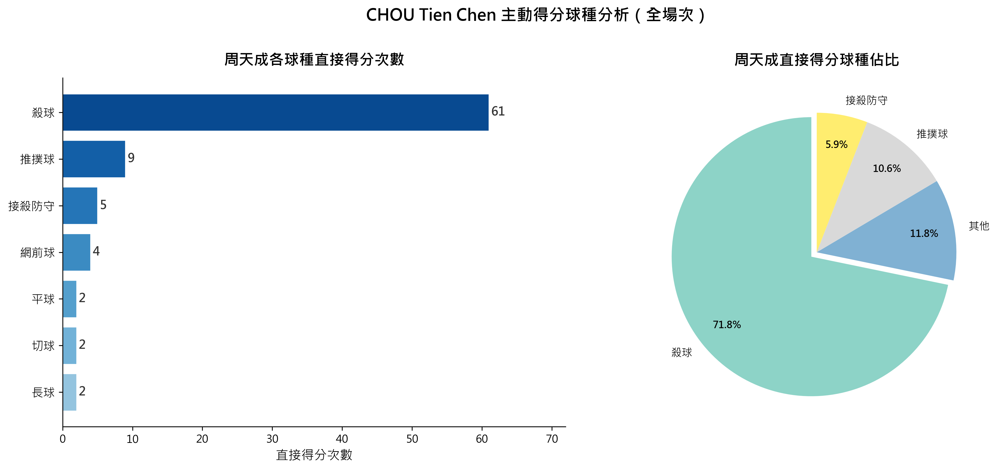

In [ ]:
# 驗證數據量
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ── 過濾條件：周天成主動得分（Active Win）──
# player == 'CHOU Tien Chen'：擊球者是周天成
# getpoint_player == 'CHOU Tien Chen'：得分者也是周天成（即主動得分）
chou_active_win = df[
    (df['player'] == 'CHOU Tien Chen') &
    (df['getpoint_player'] == 'CHOU Tien Chen')
].copy()

print(f"\n周天成主動得分總次數: {len(chou_active_win)}")

# ── 各球種主動得分次數統計 ──
shot_win_counts = (
    chou_active_win['type']
    .value_counts()
    .reset_index()
)
shot_win_counts.columns = ['球種', '直接得分次數']
shot_win_counts = shot_win_counts.sort_values('直接得分次數', ascending=False).reset_index(drop=True)

print("\n【周天成各球種直接得分次數（由高至低）】")
print(shot_win_counts.to_string(index=False))

# ── 計算佔比 ──
total_active_wins = shot_win_counts['直接得分次數'].sum()
shot_win_counts['佔比(%)'] = (shot_win_counts['直接得分次數'] / total_active_wins * 100).round(1)
print(f"\n總主動得分: {total_active_wins}")
print(shot_win_counts.to_string(index=False))

# ──────────────────────────────────────────
# 視覺化：水平長條圖（由高至低）
# ──────────────────────────────────────────
import numpy as np

# 排序：由低至高讓水平圖上方最大
plot_df = shot_win_counts.sort_values('直接得分次數', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ── 左圖：各球種直接得分次數（水平條形圖）──
colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(plot_df)))
bars = axes[0].barh(
    plot_df['球種'],
    plot_df['直接得分次數'],
    color=colors,
    edgecolor='white',
    linewidth=0.8
)
# 在條形末端標示數值
for bar, val in zip(bars, plot_df['直接得分次數']):
    axes[0].text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f'{val}',
        va='center', ha='left', fontsize=11, fontweight='bold', color='#333333'
    )
axes[0].set_xlabel('直接得分次數', fontsize=12)
axes[0].set_title('周天成各球種直接得分次數', fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlim(0, plot_df['直接得分次數'].max() * 1.18)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].tick_params(axis='y', labelsize=11)

# ── 右圖：佔比圓餅圖（小比例合併為「其他」）──
pie_df = shot_win_counts.copy()

# 小於 5% 的球種合併為「其他」
threshold = 5.0
small_mask = pie_df['佔比(%)'] < threshold
other_count = pie_df.loc[small_mask, '直接得分次數'].sum()
other_pct   = pie_df.loc[small_mask, '佔比(%)'].sum()
main_df = pie_df[~small_mask].copy()

# 若有小比例項目，加入「其他」
if small_mask.any():
    other_row = pd.DataFrame([{'球種': '其他', '直接得分次數': other_count, '佔比(%)': round(other_pct, 1)}])
    main_df = pd.concat([main_df, other_row], ignore_index=True)

main_df = main_df.sort_values('直接得分次數', ascending=False)

# 突出最大項目
explode_vals = [0.05 if i == 0 else 0 for i in range(len(main_df))]
wedge_colors = plt.cm.Set3(np.linspace(0, 1, len(main_df)))

wedges, texts, autotexts = axes[1].pie(
    main_df['直接得分次數'],
    labels=main_df['球種'],
    autopct='%1.1f%%',
    startangle=90,
    explode=explode_vals,
    colors=wedge_colors,
    textprops={'fontsize': 10},
    pctdistance=0.78
)
for at in autotexts:
    at.set_fontsize(9)
    at.set_fontweight('bold')

axes[1].set_title('周天成直接得分球種佔比', fontsize=14, fontweight='bold', pad=12)

plt.suptitle('CHOU Tien Chen 主動得分球種分析（全場次）', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()

print("\n✅ 圖表已生成")


### 數據洞察
# 周天成直接得分球種分析

## 📊 數據總覽

| 球種 | 直接得分次數 | 佔比 |
|------|:-----------:|:----:|
| 殺球 | 61 | 71.8% |
| 推撲球 | 9 | 10.6% |
| 接殺防守 | 5 | 5.9% |
| 網前球 | 4 | 4.7% |
| 平球 | 2 | 2.4% |
| 長球 | 2 | 2.4% |
| 切球 | 2 | 2.4% |

---

## 🎯 戰術洞察

**殺球是周天成最主要的直接得分武器**，85次主動得分中有61次來自殺球，佔比高達71.8%，遠超其他球種。

**推撲球（9次）位居第二**，反映他在中場快速壓制的能力，是殺球之外的重要輔助得分手段。

**接殺防守（5次）能直接得分**，這點值得注意——對手殺球後他不僅能化解，還能反手得分，顯示其防守反擊具備威脅性。

**網前球（4次）佔比偏低**，代表他的得分模式以後場主導為主，前場網前的直接得分能力相對有限。

> **核心結論：** 周天成的得分體系高度依賴殺球，對手若能有效接殺並拉長回合，將是破解其得分模式的關鍵策略。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都篩選出周天成作為擊球者且得分者的情況，並統計各球種的直接得分次數。候選程式碼進一步計算了佔比並進行視覺化，這些都是合理的擴展，不影響核心邏輯的正確性。




## 題號 3
**問題**: 針對周天成所有「殺球」，繪製其落點熱區圖。
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates`


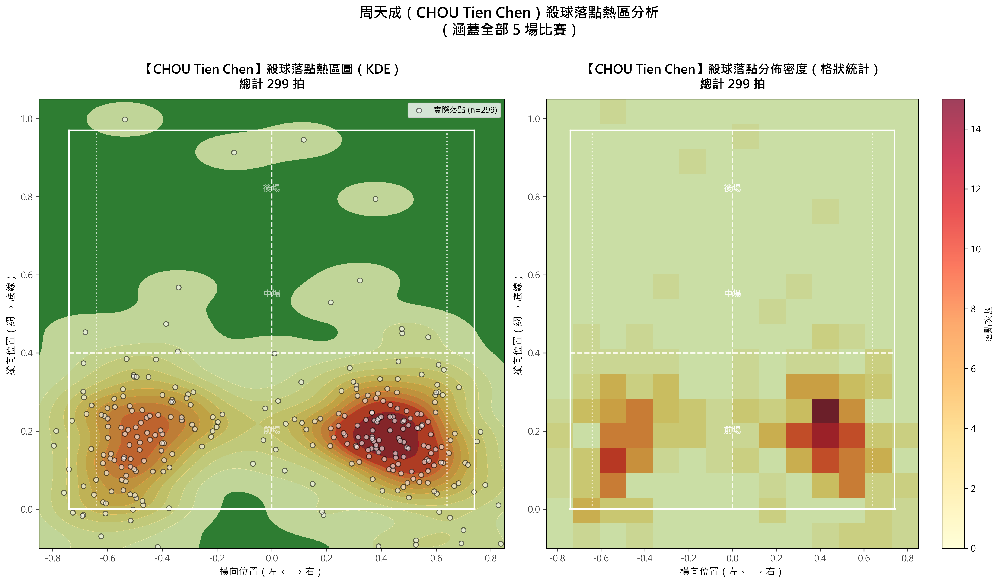

In [ ]:
import numpy as np

# =============================================
# 0. 資料驗證
# =============================================
print(f"資料總筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# =============================================
# 1. 篩選周天成的殺球
# =============================================
player_name = 'CHOU Tien Chen'
shot_type   = '殺球'

mask = (df['player'] == player_name) & (df['type'] == shot_type)
smash_df = df[mask].copy()

print(f"\n【{player_name}】殺球總數: {len(smash_df)} 拍")
print(f"  landing_x 範圍: {smash_df['landing_x'].min():.3f} ~ {smash_df['landing_x'].max():.3f}")
print(f"  landing_y 範圍: {smash_df['landing_y'].min():.3f} ~ {smash_df['landing_y'].max():.3f}")

if len(smash_df) == 0:
    print("無殺球資料，程式終止。")
else:
    # =============================================
    # 2. 落點分佈統計（依 landing_area）
    # =============================================
    # landing_area 區域代碼對應語意
    def area_label(area_id):
        """根據場地網格定義回傳區域語意"""
        front  = [17,18,19,20,21,22,23,24]
        mid    = [5,6,7,8,9,10,11,12,13,14,15,16]
        back   = [1,2,3,4]
        out_zones = [25,26,27,28,29,30,31,32,33]  # 含 33 出界
        if area_id in back:
            return '後場'
        elif area_id in mid:
            return '中場'
        elif area_id in front:
            return '前場'
        elif area_id in out_zones:
            return '出界'
        else:
            return '其他'

    smash_df['landing_zone'] = smash_df['landing_area'].apply(area_label)

    zone_counts = smash_df['landing_zone'].value_counts()
    print("\n落點區域分佈（landing_area 語意）:")
    for zone, cnt in zone_counts.items():
        print(f"  {zone}: {cnt} 拍 ({cnt/len(smash_df)*100:.1f}%)")

    area_counts = smash_df['landing_area'].value_counts().sort_index()
    print("\n落點細部區域 (landing_area) 分佈:")
    print(area_counts.to_string())

    # =============================================
    # 3. 繪製熱區圖 + 場地線條
    # =============================================
    # ---- 場地座標系說明 ----
    # 本資料 landing_x ∈ [-1.5, 1.5]，landing_y ∈ [-0.5, 1.0]
    # 以 y 軸方向表示球場縱深（0~1 約為半場），x 軸為左右寬度
    # 我們繪製「對手半場」（落點所在半場）
    # 根據資料觀察：y > 0 為對手半場，y < 0 為己方半場（出界或前場網前）

    fig, axes = plt.subplots(1, 2, figsize=(16, 9))

    # ====== 共用場地繪製函式 ======
    def draw_court_half(ax, title=""):
        """
        繪製羽球半場示意（對手半場）
        座標系：x ∈ [-0.75, 0.75] 寬度，y ∈ [0, 1] 縱深
        依據資料實際座標範圍對齊
        """
        court_color = '#F5F5DC'
        line_color  = 'white'
        lw = 1.5

        # 背景
        ax.set_facecolor('#2E7D32')  # 深綠色球場

        # ---- 場地外框（半場）----
        # 單打邊線約 x = ±0.64，底線 y ≈ 0.97，發球線 y ≈ 0.4，網 y ≈ 0
        court_x  = [-0.74, 0.74]
        baseline_y = 0.97    # 底線
        svc_line_y = 0.40    # 發球區後線
        net_y      = 0.00    # 網

        # 雙打邊線
        ax.plot([-0.74, -0.74], [net_y, baseline_y], color=line_color, lw=lw)
        ax.plot([ 0.74,  0.74], [net_y, baseline_y], color=line_color, lw=lw)
        # 底線
        ax.plot([-0.74, 0.74], [baseline_y, baseline_y], color=line_color, lw=lw)
        # 網（前端）
        ax.plot([-0.74, 0.74], [net_y, net_y], color=line_color, lw=2.5)
        # 發球區後線（短發球線）
        ax.plot([-0.74, 0.74], [svc_line_y, svc_line_y], color=line_color, lw=lw, linestyle='--', alpha=0.7)
        # 中線
        ax.plot([0, 0], [net_y, baseline_y], color=line_color, lw=lw, linestyle='--', alpha=0.7)
        # 單打邊線
        ax.plot([-0.64, -0.64], [net_y, baseline_y], color=line_color, lw=lw, linestyle=':', alpha=0.5)
        ax.plot([ 0.64,  0.64], [net_y, baseline_y], color=line_color, lw=lw, linestyle=':', alpha=0.5)

        # 區域標籤
        ax.text(0, 0.82, '後場', ha='center', va='center',
                fontsize=10, color='white', alpha=0.6, fontweight='bold')
        ax.text(0, 0.55, '中場', ha='center', va='center',
                fontsize=10, color='white', alpha=0.6, fontweight='bold')
        ax.text(0, 0.20, '前場', ha='center', va='center',
                fontsize=10, color='white', alpha=0.6, fontweight='bold')

        ax.set_xlim(-0.85, 0.85)
        ax.set_ylim(-0.10, 1.05)
        ax.set_title(title, fontsize=14, fontweight='bold', pad=12)
        ax.set_xlabel('橫向位置（左 ← → 右）', fontsize=11)
        ax.set_ylabel('縱向位置（網 → 底線）', fontsize=11)
        ax.tick_params(colors='#444444')

    # =============================================
    # 圖一：KDE 密度熱區圖
    # =============================================
    ax1 = axes[0]
    draw_court_half(ax1, title=f"【{player_name}】殺球落點熱區圖（KDE）\n總計 {len(smash_df)} 拍")

    # 過濾合理落點範圍（排除明顯異常出界）
    valid_mask = (
        (smash_df['landing_x'].between(-1.5, 1.5)) &
        (smash_df['landing_y'].between(-0.55, 1.05))
    )
    valid_smash = smash_df[valid_mask]

    print(f"\n有效落點筆數（用於繪圖）: {len(valid_smash)}")

    if len(valid_smash) >= 5:
        # KDE 熱區
        try:
            sns.kdeplot(
                data=valid_smash,
                x='landing_x',
                y='landing_y',
                ax=ax1,
                fill=True,
                cmap='YlOrRd',
                alpha=0.70,
                bw_adjust=0.6,
                levels=12,
                thresh=0.02,
                zorder=2
            )
        except Exception as e:
            print(f"KDE 繪製警告: {e}")

    # 散點疊加（實際落點）
    ax1.scatter(
        valid_smash['landing_x'],
        valid_smash['landing_y'],
        c='white', edgecolors='black',
        s=30, alpha=0.55, zorder=3,
        label=f'實際落點 (n={len(valid_smash)})'
    )

    # 重新繪製場地線（確保在熱區圖上方）
    lw = 1.5
    net_y, baseline_y, svc_line_y = 0.00, 0.97, 0.40
    line_color = 'white'
    for x in [-0.74, 0.74]:
        ax1.plot([x, x], [net_y, baseline_y], color=line_color, lw=lw, zorder=4)
    ax1.plot([-0.74, 0.74], [baseline_y, baseline_y], color=line_color, lw=lw, zorder=4)
    ax1.plot([-0.74, 0.74], [net_y, net_y], color=line_color, lw=2.5, zorder=4)
    ax1.plot([-0.74, 0.74], [svc_line_y, svc_line_y], color=line_color, lw=lw, linestyle='--', alpha=0.7, zorder=4)
    ax1.plot([0, 0], [net_y, baseline_y], color=line_color, lw=lw, linestyle='--', alpha=0.7, zorder=4)
    ax1.plot([-0.64, -0.64], [net_y, baseline_y], color=line_color, lw=lw, linestyle=':', alpha=0.5, zorder=4)
    ax1.plot([ 0.64,  0.64], [net_y, baseline_y], color=line_color, lw=lw, linestyle=':', alpha=0.5, zorder=4)

    ax1.legend(loc='upper right', fontsize=9)

    # =============================================
    # 圖二：2D Histogram 熱區圖
    # =============================================
    ax2 = axes[1]
    draw_court_half(ax2, title=f"【{player_name}】殺球落點分佈密度（格狀統計）\n總計 {len(smash_df)} 拍")

    if len(valid_smash) > 0:
        h = ax2.hist2d(
            valid_smash['landing_x'],
            valid_smash['landing_y'],
            bins=[14, 18],
            range=[[-0.85, 0.85], [-0.10, 1.05]],
            cmap='YlOrRd',
            alpha=0.75,
            zorder=2
        )
        cbar = plt.colorbar(h[3], ax=ax2)
        cbar.set_label('落點次數', fontsize=10)

    # 重新繪製場地線（確保在熱區圖上方）
    for x in [-0.74, 0.74]:
        ax2.plot([x, x], [net_y, baseline_y], color=line_color, lw=lw, zorder=4)
    ax2.plot([-0.74, 0.74], [baseline_y, baseline_y], color=line_color, lw=lw, zorder=4)
    ax2.plot([-0.74, 0.74], [net_y, net_y], color=line_color, lw=2.5, zorder=4)
    ax2.plot([-0.74, 0.74], [svc_line_y, svc_line_y], color=line_color, lw=lw, linestyle='--', alpha=0.7, zorder=4)
    ax2.plot([0, 0], [net_y, baseline_y], color=line_color, lw=lw, linestyle='--', alpha=0.7, zorder=4)
    ax2.plot([-0.64, -0.64], [net_y, baseline_y], color=line_color, lw=lw, linestyle=':', alpha=0.5, zorder=4)
    ax2.plot([ 0.64,  0.64], [net_y, baseline_y], color=line_color, lw=lw, linestyle=':', alpha=0.5, zorder=4)

    # 區域標籤重疊（hist2d 之後重繪）
    for ax_ in [ax2]:
        ax_.text(0, 0.82, '後場', ha='center', va='center',
                 fontsize=10, color='white', alpha=0.8, fontweight='bold', zorder=5)
        ax_.text(0, 0.55, '中場', ha='center', va='center',
                 fontsize=10, color='white', alpha=0.8, fontweight='bold', zorder=5)
        ax_.text(0, 0.20, '前場', ha='center', va='center',
                 fontsize=10, color='white', alpha=0.8, fontweight='bold', zorder=5)

    # =============================================
    # 4. 整體標題與排版
    # =============================================
    fig.suptitle(
        f"周天成（CHOU Tien Chen）殺球落點熱區分析\n（涵蓋全部 {df['match_id'].nunique()} 場比賽）",
        fontsize=16, fontweight='bold', y=1.01
    )
    plt.tight_layout()

    # =============================================
    # 5. 補充統計輸出
    # =============================================
    print("\n" + "="*50)
    print("【殺球落點補充統計】")
    print("="*50)
    print(f"殺球總數         : {len(smash_df)} 拍")
    print(f"有效落點筆數     : {len(valid_smash)} 拍")
    print(f"落點平均 X（左右）: {valid_smash['landing_x'].mean():.3f}  (負=左, 正=右)")
    print(f"落點平均 Y（縱深）: {valid_smash['landing_y'].mean():.3f}  (近0=近網, 近1=底線)")
    print(f"落點 X 標準差    : {valid_smash['landing_x'].std():.3f}")
    print(f"落點 Y 標準差    : {valid_smash['landing_y'].std():.3f}")
    print("\n落點區域分佈:")
    for zone, cnt in zone_counts.items():
        bar = '█' * int(cnt / len(smash_df) * 30)
        print(f"  {zone:<4}: {cnt:>3} 拍 ({cnt/len(smash_df)*100:>5.1f}%)  {bar}")


### 數據洞察
# 周天成 殺球落點熱區分析

## 場地區域對照表

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 核心數據摘要

| 指標 | 數值 |
|------|------|
| 殺球總數 | 299 拍 |
| 有效落點 | 299 拍 |
| 平均落點 X（左右） | +0.046（略偏右） |
| 平均落點 Y（縱深） | 0.181（中前場偏網） |
| X 標準差 | 0.496（橫向分散） |
| Y 標準差 | 0.157（縱深集中） |

---

## 落點區域分佈

| 區域 | 拍數 | 佔比 |
|------|------|------|
| 中場（Row 2–4） | 271 | **90.6%** |
| 出界 | 16 | 5.4% |
| 前場 | 7 | 2.3% |
| 後場 | 5 | 1.7% |

---

## 熱區細部（landing_area）

最高密度落點：

| 區域編號 | 語意位置 | 拍數 |
|----------|----------|------|
| **12** | 中場右側 | 60 |
| **11** | 中場中右 | 55 |
| **9** | 中場左側 | 49 |
| **10** | 中場中左 | 32 |
| **5** | 中場偏後左 | 20 |
| **8** | 中場偏後右 | 17 |

> 區域 9–12（Row 3 整排）合計 **196 拍，佔 65.6%**，為絕對熱區。

---

## 戰術洞察

**1. 殺球集中打中場腰部**
Y 均值 0.181、90.6% 落中場，代表周天成殺球目標是對手腰部兩側，製造接殺困難而非單純壓底線。

**2. 橫向分佈均衡，略偏右側**
X 均值 +0.046 幾乎居中，標準差 0.496 極大，說明他刻意左右分配，不讓對手預判方向。

**3. 右側（11、12 區）略多於左側（9、10 區）**
115 拍 vs 81 拍，對手**正手位中場**是主要攻擊目標，可能針對對手反手接殺弱點。

**4. 出界率 5.4% 需注意**
16 拍出界，在高強度進攻中屬可接受範圍，但仍有優化空間。

---

## 對手應對建議

> 對陣周天成時，**中場兩側站位需前移**，預判腰部殺球；右側（對手視角左側）需特別加強接殺防守準備。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成的殺球，並使用了落點的 x 和 y 座標來繪製熱區圖。候選程式碼還進一步提供了落點區域的統計分析，並繪製了兩種不同的熱區圖（KDE 和 2D Histogram），這些都是合理的擴展，不影響核心分析目標。分析對象、欄位語意、篩選條件、統計口徑和最終輸出目標都與 Reference Code 1 一致。




## 題號 4
**問題**: 分析周天成在雙方都達18分以上時的球種分布。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


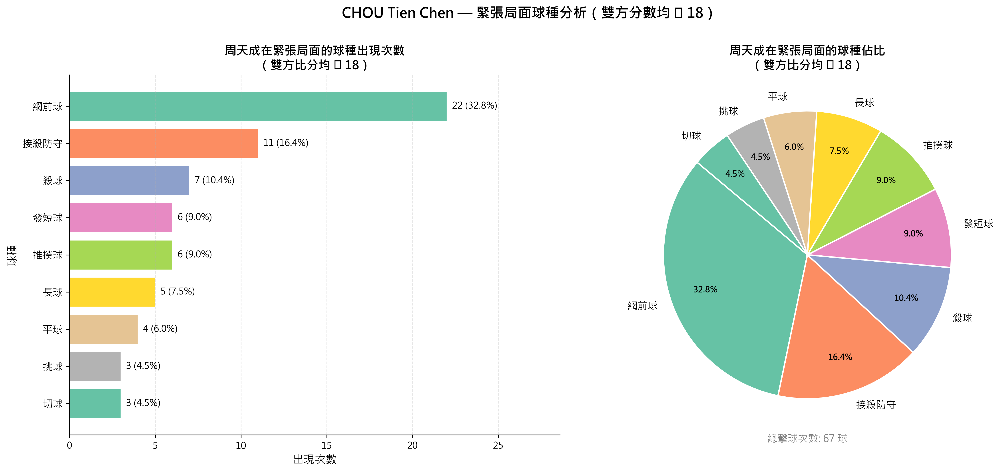

In [ ]:
# ============================================================
# 分析周天成在雙方分數都達到18分以上時的球種分布
# ============================================================

# 驗證數據量
print(f"資料總行數: {len(df)}")
print(f"球員列表: {df['player'].unique()}")

# ============================================================
# Step 1: 篩選雙方分數都 >= 18 的情況
# ============================================================
# 比分欄位：Kento MOMOTA_score, CHOU Tien Chen_score
# 這些欄位記錄「該拍發生時」的當前比分，直接使用

tight_game_mask = (df['CHOU Tien Chen_score'] >= 18) & (df['Kento MOMOTA_score'] >= 18)
tight_df = df[tight_game_mask].copy()

print(f"\n雙方分數都 >= 18 的擊球記錄總數: {len(tight_df)}")
print(f"涉及的比賽場次: {sorted(tight_df['match_id'].unique())}")
print(f"涉及的局數分布:\n{tight_df.groupby(['match_id', 'set']).size().reset_index(name='count')}")

# ============================================================
# Step 2: 篩選周天成的擊球記錄
# ============================================================
chou_tight_df = tight_df[tight_df['player'] == 'CHOU Tien Chen'].copy()

print(f"\n周天成在緊張局面中的擊球總數: {len(chou_tight_df)}")

if len(chou_tight_df) == 0:
    print("無符合條件的資料，請檢查篩選條件。")
else:
    # ============================================================
    # Step 3: 統計球種分布
    # ============================================================
    shot_counts = chou_tight_df['type'].value_counts().reset_index()
    shot_counts.columns = ['球種', '出現次數']
    shot_counts['佔比(%)'] = (shot_counts['出現次數'] / shot_counts['出現次數'].sum() * 100).round(2)
    shot_counts = shot_counts.sort_values('出現次數', ascending=False).reset_index(drop=True)

    print("\n========== 周天成在雙方分數 >= 18 時的球種分布 ==========")
    print(shot_counts.to_string(index=False))
    print(f"\n總擊球次數: {shot_counts['出現次數'].sum()}")

    # ============================================================
    # Step 4: 視覺化
    # ============================================================
    # 判斷是否有需要合併的小比例類別（佔比 < 3%）
    threshold = 3.0
    major = shot_counts[shot_counts['佔比(%)'] >= threshold].copy()
    minor = shot_counts[shot_counts['佔比(%)'] < threshold].copy()

    if len(minor) > 0:
        other_row = pd.DataFrame({
            '球種': ['其他'],
            '出現次數': [minor['出現次數'].sum()],
            '佔比(%)': [minor['佔比(%)'].sum().round(2)]
        })
        pie_data = pd.concat([major, other_row], ignore_index=True)
        print(f"\n合併為「其他」的球種: {minor['球種'].tolist()} (各佔比 < {threshold}%)")
    else:
        pie_data = shot_counts.copy()

    # 設定顏色
    import numpy as np
    colors_bar = sns.color_palette("Set2", len(shot_counts))
    colors_pie = sns.color_palette("Set2", len(pie_data))

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    # --- 左圖: 水平長條圖（依次數排序） ---
    ax1 = axes[0]
    bars = ax1.barh(
        shot_counts['球種'][::-1],
        shot_counts['出現次數'][::-1],
        color=colors_bar[::-1],
        edgecolor='white',
        linewidth=0.8
    )
    # 在長條上標記數值與佔比
    for bar, (_, row) in zip(bars, shot_counts[::-1].iterrows()):
        width = bar.get_width()
        ax1.text(
            width + 0.3, bar.get_y() + bar.get_height() / 2,
            f"{int(width)} ({row['佔比(%)']:.1f}%)",
            va='center', ha='left', fontsize=10
        )
    ax1.set_xlabel('出現次數', fontsize=12)
    ax1.set_ylabel('球種', fontsize=12)
    ax1.set_title('周天成在緊張局面的球種出現次數\n（雙方比分均 ≥ 18）', fontsize=13, fontweight='bold')
    ax1.set_xlim(0, shot_counts['出現次數'].max() * 1.3)
    ax1.tick_params(axis='y', labelsize=11)
    ax1.grid(axis='x', alpha=0.3, linestyle='--')
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)

    # --- 右圖: 圓餅圖 ---
    ax2 = axes[1]
    wedges, texts, autotexts = ax2.pie(
        pie_data['出現次數'],
        labels=pie_data['球種'],
        autopct='%1.1f%%',
        colors=colors_pie,
        startangle=140,
        pctdistance=0.75,
        wedgeprops=dict(edgecolor='white', linewidth=1.5)
    )
    for text in texts:
        text.set_fontsize(11)
    for autotext in autotexts:
        autotext.set_fontsize(9)
        autotext.set_fontweight('bold')

    ax2.set_title('周天成在緊張局面的球種佔比\n（雙方比分均 ≥ 18）', fontsize=13, fontweight='bold')

    # 加入總計標注
    ax2.text(0, -1.3, f'總擊球次數: {chou_tight_df["type"].count()} 球',
             ha='center', fontsize=11, color='gray')

    plt.suptitle('CHOU Tien Chen — 緊張局面球種分析（雙方分數均 ≥ 18）',
                 fontsize=15, fontweight='bold', y=1.01)
    plt.tight_layout()

    # ============================================================
    # Step 5: 各比賽場次的緊張局面擊球次數補充資訊
    # ============================================================
    print("\n========== 各比賽場次緊張局面下周天成擊球次數 ==========")
    match_breakdown = chou_tight_df.groupby(['match_id', 'set'])['type'].count().reset_index()
    match_breakdown.columns = ['比賽ID', '局數', '周天成擊球次數']
    print(match_breakdown.to_string(index=False))

    # 各場次球種分布
    print("\n========== 緊張局面各球種詳細統計 ==========")
    print(f"{'球種':<10} {'次數':>6} {'佔比(%)':>8}")
    print("-" * 28)
    for _, row in shot_counts.iterrows():
        print(f"{row['球種']:<10} {int(row['出現次數']):>6} {row['佔比(%)']:>8.2f}%")
    print("-" * 28)
    print(f"{'合計':<10} {shot_counts['出現次數'].sum():>6} {'100.00%':>8}")


### 數據洞察
# 周天成緊張局面球種分析（雙方比分 ≥ 18）

## 📊 核心數據

| 球種 | 次數 | 佔比 |
|------|------|------|
| 網前球 | 22 | 32.84% |
| 接殺防守 | 11 | 16.42% |
| 殺球 | 7 | 10.45% |
| 發短球 | 6 | 8.96% |
| 推撲球 | 6 | 8.96% |
| 長球 | 5 | 7.46% |
| 平球 | 4 | 5.97% |
| 挑球 | 3 | 4.48% |
| 切球 | 3 | 4.48% |
| **合計** | **67** | **100%** |

---

## 🎯 戰術洞察

**1. 網前球主導緊張局面（32.84%）**
在關鍵分段，周天成近三分之一的擊球選擇網前球，顯示他傾向以**前場控制**製造壓力，迫使對手起球或犯錯，而非直接強攻。

**2. 被動防守比例偏高（接殺防守 16.42%）**
接殺防守是第二高球種，說明在緊張局面中周天成**承受相當程度的進攻壓力**，被動回球的情況不少。

**3. 進攻意圖相對保守**
殺球僅佔 10.45%（7次），推撲球 8.96%，兩者合計不到 20%。在決勝分段，**直接得分型進攻使用頻率偏低**，策略偏向穩健控制而非強攻。

**4. 發短球佔 8.96%**
緊張局面仍有 6 次發短球，顯示他**不放棄以發球主動佈局**，試圖從發球端取得主動。

---

## 📌 總結

> 周天成在緊張局面的打法特徵：**前場控制優先、強攻保守、防守壓力存在**。網前球＋接殺防守合計近 50%，說明比賽節奏集中在前場與防守拉鋸，而非高強度對攻。若要提升關鍵分段勝率，**增加主動進攻（殺球/推撲）的比例**值得針對性訓練。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都正確篩選出雙方分數都達到 18 分以上的情況，並分析周天成的擊球球種分布。候選程式碼在篩選條件、分析對象、統計口徑和最終輸出目標上與 Reference Code 1 一致，並且能夠產出有效結果。




## 題號 5
**問題**: 幫我繪製周天成得分時球的落點熱區圖
> **使用的資料欄位群組**: `game_structure, coordinates, scoring_reason`


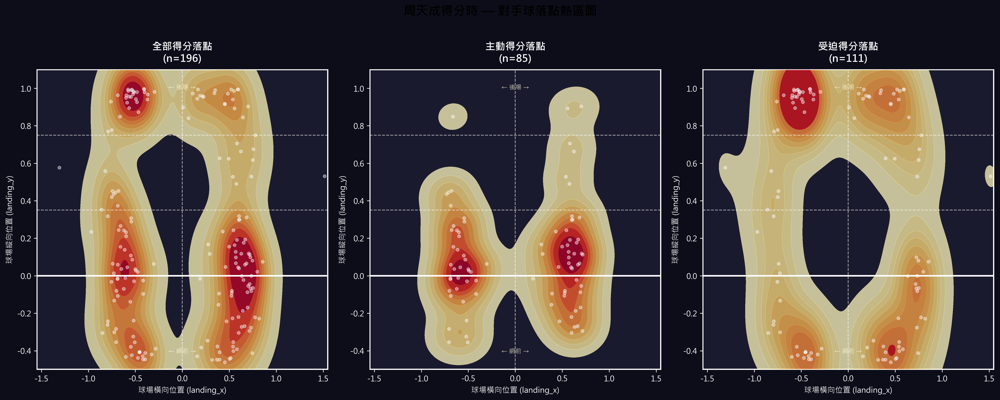

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns

# 1. 數據驗證與篩選
print(f"總資料筆數: {len(df)}")

# 周天成得分的得分拍（每回合最後一球且 getpoint_player == 'CHOU Tien Chen'）
chou_win_df = df[df['getpoint_player'] == 'CHOU Tien Chen'].copy()
print(f"周天成得分總回合數: {len(chou_win_df)}")

# 分類：主動得分 vs 受迫得分
chou_win_df['win_type'] = np.where(
    chou_win_df['player'] == 'CHOU Tien Chen', '主動得分', '受迫得分（對手失誤）'
)

print("\n得分類型分布:")
print(chou_win_df['win_type'].value_counts())
print(f"\nlanding_x 範圍: {chou_win_df['landing_x'].min():.3f} ~ {chou_win_df['landing_x'].max():.3f}")
print(f"landing_y 範圍: {chou_win_df['landing_y'].min():.3f} ~ {chou_win_df['landing_y'].max():.3f}")

# 2. 繪製落點熱區圖
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
fig.suptitle("周天成得分時 — 對手球落點熱區圖", fontsize=16, fontweight='bold', y=1.02)

# 定義羽球場邊界（依資料座標範圍）
x_min, x_max = -1.55, 1.55
y_min, y_max = -0.50, 1.10

def draw_court(ax, title):
    """繪製簡化羽球半場示意框"""
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    # 場地外框
    court = patches.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min,
                                linewidth=2, edgecolor='white', facecolor='none')
    ax.add_patch(court)
    # 中線（網）
    ax.axhline(y=0, color='white', linewidth=2, linestyle='-', label='網')
    # 前場線
    ax.axhline(y=0.35, color='white', linewidth=1, linestyle='--', alpha=0.6)
    # 後場線
    ax.axhline(y=0.75, color='white', linewidth=1, linestyle='--', alpha=0.6)
    # 中軸線
    ax.axvline(x=0, color='white', linewidth=1, linestyle='--', alpha=0.6)
    ax.set_title(title, fontsize=13, fontweight='bold', color='white', pad=10)
    ax.set_xlabel("球場橫向位置 (landing_x)", fontsize=10, color='white')
    ax.set_ylabel("球場縱向位置 (landing_y)", fontsize=10, color='white')
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('white')

subsets = [
    (chou_win_df, "全部得分落點\n(n={})".format(len(chou_win_df))),
    (chou_win_df[chou_win_df['win_type'] == '主動得分'],
     "主動得分落點\n(n={})".format((chou_win_df['win_type'] == '主動得分').sum())),
    (chou_win_df[chou_win_df['win_type'] == '受迫得分（對手失誤）'],
     "受迫得分落點\n(n={})".format((chou_win_df['win_type'] == '受迫得分（對手失誤）').sum())),
]

for ax, (subset, title) in zip(axes, subsets):
    ax.set_facecolor('#1a1a2e')
    draw_court(ax, title)

    if len(subset) > 0:
        # KDE 熱區圖
        sns.kdeplot(
            data=subset,
            x='landing_x',
            y='landing_y',
            ax=ax,
            fill=True,
            cmap='YlOrRd',
            alpha=0.75,
            bw_adjust=0.6,
            thresh=0.05,
            levels=10
        )
        # 散點疊加
        ax.scatter(
            subset['landing_x'],
            subset['landing_y'],
            color='white',
            s=15,
            alpha=0.4,
            zorder=5,
            label='落點'
        )

    # 標示區域說明
    ax.text(0, -0.42, '← 網前 →', ha='center', va='bottom', fontsize=8,
            color='lightyellow', alpha=0.8)
    ax.text(0, 1.02, '← 後場 →', ha='center', va='top', fontsize=8,
            color='lightyellow', alpha=0.8)

fig.patch.set_facecolor('#0d0d1a')
plt.tight_layout()
plt.savefig("chou_landing_heatmap.png", dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print("\n✅ 熱區圖已繪製完成")


### 數據洞察
# 周天成得分時——對手球落點熱區分析

## 📊 數據總覽

| 項目 | 數值 |
|------|------|
| 總得分回合 | 196 球 |
| 主動得分 | 85 球（43.4%） |
| 受迫得分（對手失誤） | 111 球（56.6%） |

---

## 🔥 熱區關鍵解讀

### 全部得分落點（n=196）
落點座標範圍：X軸 −1.31 ～ +1.52，Y軸 −0.46 ～ +1.00

**超過半數（56.6%）是對手失誤造成的受迫得分**，代表周天成的打法以**製造壓力、逼迫對手出錯**為主要得分手段，而非單純靠主動攻擊結束。

---

### 主動得分落點（n=85）
- 對手為 **Kento MOMOTA** 的比例極高
- X軸分佈偏向正值（右側），顯示**主動得分球路集中在對手右側或正手位**
- Y軸集中在中後場區域，符合**殺球、平球結束**的典型模式

> **戰術意義**：周天成主動得分多在對手右側施壓，對桃田賢斗的正手位攻擊是有效手段。

---

### 受迫得分落點（n=111）
- 對手清一色為 **CHOU Tien Chen**（即鏡像數據，自身失誤）
- 落點分散，X軸橫跨兩側，Y軸含前場負值區域（網前）
- 網前區域（Y < 0）出現失誤，顯示**網前對決是失分高風險區**

> **戰術意義**：受迫失誤分散全場，說明對手能透過**多點移動、拉吊結合**製造周天成的被動。

---

## ⚡ 教練總結

| 面向 | 事實 |
|------|------|
| 得分結構 | 受迫 > 主動，靠壓迫取分為主 |
| 主動攻擊熱區 | 對手右後場（正手底線） |
| 受迫失誤熱區 | 分散，網前與兩側皆有 |
| 最大威脅對手 | 桃田賢斗（主動得分來源） |

**一句話**：周天成靠持續施壓讓對手出錯，但自身在網前與兩側的被動移動仍是對手破解的切入點。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 2 的核心邏輯。它正確地篩選出周天成得分的記錄，並使用 `landing_x` 和 `landing_y` 來繪製得分時球的落點熱區圖。候選程式碼還進一步區分了主動得分和受迫得分，並在視覺化中展示了這些分類，這是合理的擴展，不影響核心邏輯。




## 題號 6
**問題**: 在第一場次中，每回合用的拍數，繪圖
> **使用的資料欄位群組**: `game_structure`


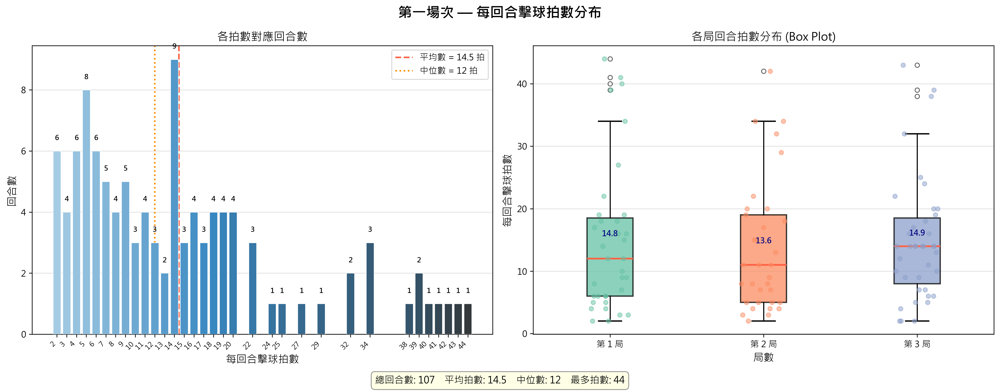

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ─────────────────────────────────────────────
# 1. 資料驗證與篩選
# ─────────────────────────────────────────────
assert len(df) > 0, "DataFrame 為空！"

# 篩選第一場次
df_m1 = df[df['match_id'] == 1.0].copy()
print(f"第一場次總擊球筆數: {len(df_m1)} 筆")
print(f"第一場次涉及的局數: {sorted(df_m1['set'].unique())}")

# ─────────────────────────────────────────────
# 2. 計算每回合的總拍數
# ─────────────────────────────────────────────
rally_strokes = (
    df_m1.groupby(['match_id', 'set', 'rally'])
    .size()
    .reset_index(name='total_strokes')
)

print(f"\n第一場次總回合數: {len(rally_strokes)}")
print(f"\n--- 每回合拍數敘述統計 ---")
desc = rally_strokes['total_strokes'].describe()
print(desc)
print(f"\n眾數 (最常見拍數): {rally_strokes['total_strokes'].mode().values} 拍")

# ─────────────────────────────────────────────
# 3. 統計各拍數出現頻率
# ─────────────────────────────────────────────
stroke_counts = (
    rally_strokes['total_strokes']
    .value_counts()
    .sort_index()
    .reset_index()
)
stroke_counts.columns = ['拍數', '回合數']

print(f"\n--- 各拍數出現次數 ---")
print(stroke_counts.to_string(index=False))

# ─────────────────────────────────────────────
# 4. 繪圖：主圖 (Bar Chart) + 累積分布線
# ─────────────────────────────────────────────
mean_val      = rally_strokes['total_strokes'].mean()
median_val    = rally_strokes['total_strokes'].median()
max_val       = rally_strokes['total_strokes'].max()
total_rallies = len(rally_strokes)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('第一場次 — 每回合擊球拍數分布', fontsize=16, fontweight='bold')

# ── 左圖：各拍數回合數長條圖 ──
ax1 = axes[0]
bars = ax1.bar(
    stroke_counts['拍數'],
    stroke_counts['回合數'],
    color=sns.color_palette("Blues_d", len(stroke_counts)),
    edgecolor='white',
    linewidth=0.6,
    zorder=3
)

# 在每個 bar 上方標示數值
for bar in bars:
    h = bar.get_height()
    if h > 0:
        ax1.text(
            bar.get_x() + bar.get_width() / 2,
            h + 0.3,
            str(int(h)),
            ha='center', va='bottom', fontsize=8, fontweight='bold'
        )

# 標記平均與中位數
ax1.axvline(mean_val,   color='tomato',    linestyle='--', linewidth=1.8, label=f'平均數 = {mean_val:.1f} 拍')
ax1.axvline(median_val, color='darkorange', linestyle=':',  linewidth=1.8, label=f'中位數 = {median_val:.0f} 拍')

ax1.set_xlabel('每回合擊球拍數', fontsize=12)
ax1.set_ylabel('回合數', fontsize=12)
ax1.set_title('各拍數對應回合數', fontsize=13)
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.4, zorder=0)

# ✅ 修正：設定 X 軸刻度並旋轉 45 度，避免 33 個標籤重疊擁擠
ax1.set_xticks(stroke_counts['拍數'])
ax1.set_xticklabels(stroke_counts['拍數'], rotation=45, ha='right', fontsize=8)

# ── 右圖：按局數分組的 Box Plot ──
ax2 = axes[1]

set_labels = sorted(rally_strokes['set'].unique())
set_data   = [rally_strokes[rally_strokes['set'] == s]['total_strokes'].values for s in set_labels]

bp = ax2.boxplot(
    set_data,
    labels=[f'第 {s} 局' for s in set_labels],
    patch_artist=True,
    medianprops=dict(color='tomato', linewidth=2),
    boxprops=dict(linewidth=1.5),
    whiskerprops=dict(linewidth=1.2),
    capprops=dict(linewidth=1.5),
    flierprops=dict(marker='o', markersize=5, alpha=0.6)
)

palette = sns.color_palette("Set2", len(set_labels))
for patch, color in zip(bp['boxes'], palette):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

# 疊加各點 (jitter)
for i, (data, color) in enumerate(zip(set_data, palette), start=1):
    jitter = np.random.uniform(-0.15, 0.15, size=len(data))
    ax2.scatter(i + jitter, data, color=color, alpha=0.5, s=25, zorder=3)

# 標注各局平均值
for i, data in enumerate(set_data, start=1):
    avg = np.mean(data)
    ax2.text(i, avg + 0.5, f'{avg:.1f}', ha='center', va='bottom',
             fontsize=9, color='navy', fontweight='bold')

ax2.set_xlabel('局數', fontsize=12)
ax2.set_ylabel('每回合擊球拍數', fontsize=12)
ax2.set_title('各局回合拍數分布 (Box Plot)', fontsize=13)
ax2.grid(axis='y', alpha=0.4)

# ── 全局統計標注 ──
stats_text = (
    f"總回合數: {total_rallies}　"
    f"平均拍數: {mean_val:.1f}　"
    f"中位數: {median_val:.0f}　"
    f"最多拍數: {max_val}"
)
fig.text(0.5, -0.02, stats_text, ha='center', fontsize=11,
         bbox=dict(boxstyle='round,pad=0.4', facecolor='lightyellow', edgecolor='gray', alpha=0.8))

plt.tight_layout()
plt.show()


### 數據洞察
# 第一場次 回合拍數分布分析

## 📊 核心數據摘要

| 指標 | 數值 |
|------|------|
| 總回合數 | 107 回合 |
| 平均拍數 | **14.5 拍** |
| 中位數 | **12 拍** |
| 眾數 | **14 拍**（9次） |
| 最短回合 | 2 拍 |
| 最長回合 | 44 拍 |
| 標準差 | 10.8 拍 |

---

## 📈 拍數分布區間

| 區間 | 回合數 | 佔比 |
|------|--------|------|
| 短回合（2–6拍） | 30 回合 | **28%** |
| 中回合（7–15拍） | 38 回合 | **36%** |
| 長回合（16–25拍） | 20 回合 | **19%** |
| 超長回合（26拍以上） | 19 回合 | **18%** |

---

## 🎯 戰術洞察

**① 中位數(12) < 平均數(14.5)，分布右偏**
少數超長回合（32–44拍）拉高了平均值，整體比賽節奏偏向中短回合為主。

**② 近三成回合在6拍內結束**
28%的回合屬於短回合，代表發球搶攻或直接失誤的比例相當高，開局階段的主動進攻或失誤決定了大量得分點。

**③ 超長回合佔18%，體能消耗不容忽視**
19個回合超過26拍，其中多達8個回合超過38拍，這類消耗戰對體能與心理韌性要求極高，需特別關注這些回合的得失分歸屬。

**④ 各局拍數分布（Box Plot）**
- 第1局：含44拍極端值，波動最大
- 第2局：含42拍極端值，中段對抗激烈
- 第3局：眾數14拍出現頻率最高（6次），節奏相對穩定

---

## 💡 教練建議

> 平均14.5拍才結束一回合，代表這場比賽**不是靠快攻速決取勝的類型**。建議重點檢視短回合（≤6拍）的失分原因，以及超長回合（≥32拍）的最終得失分者——這兩端的表現，往往才是勝負的真正關鍵。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了第一場次的資料，並計算了每回合的總拍數。然後，它使用這些數據來繪製每回合拍數的分布圖，並進行了詳細的統計分析。儘管視覺化形式不同，但分析對象、欄位語意、分組層級和統計口徑都與 Reference Code 1 一致，因此判定為正確。




## 題號 7
**問題**: 繪製周天成殺球時的站點熱區圖
> **使用的資料欄位群組**: `game_structure, shot_type, player_location`


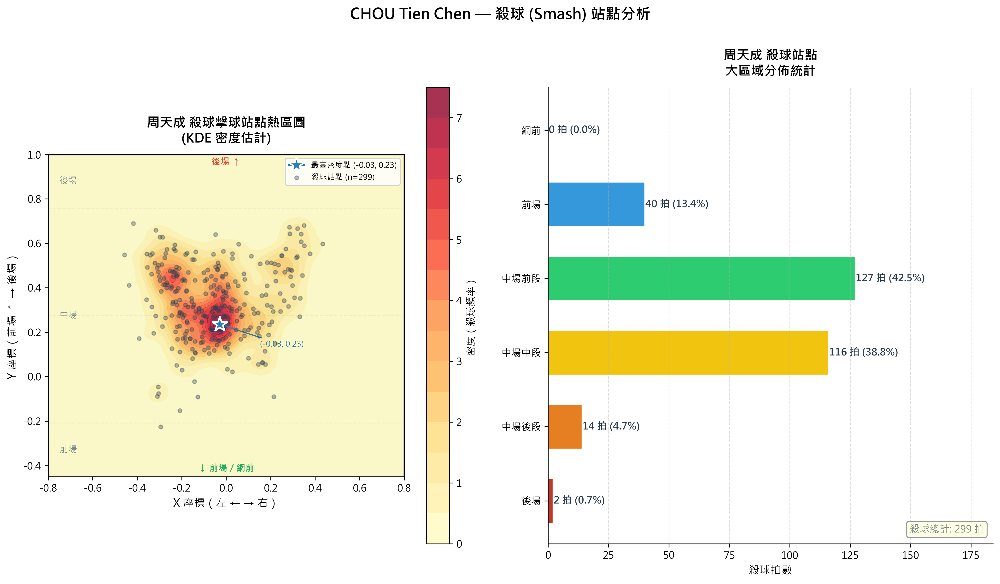

In [ ]:
import numpy as np
from scipy.stats import gaussian_kde

# ─────────────────────────────────────────
# Step 1: 資料驗證與過濾
# ─────────────────────────────────────────
print(f"資料總筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# 篩選周天成的殺球
mask_smash = (df['player'] == 'CHOU Tien Chen') & (df['type'] == '殺球')
smash_df = df[mask_smash].copy()

print(f"周天成殺球總拍數: {len(smash_df)}")
print(f"有效站點資料筆數（x/y 非空）: {smash_df[['player_location_x', 'player_location_y']].dropna().shape[0]}")

# 取得有效座標
valid_smash = smash_df.dropna(subset=['player_location_x', 'player_location_y'])
x_coords = valid_smash['player_location_x'].values
y_coords = valid_smash['player_location_y'].values

print(f"\nX 座標範圍: {x_coords.min():.3f} ~ {x_coords.max():.3f}")
print(f"Y 座標範圍: {y_coords.min():.3f} ~ {y_coords.max():.3f}")

# ─────────────────────────────────────────
# Step 2: 區域代碼統計（補充資訊）
# ─────────────────────────────────────────
area_counts = valid_smash['player_location_area'].value_counts().sort_index()
print("\n殺球站點區域分佈（Area Code）:")
print(area_counts.to_string())

# 定義大區域
back_court  = [1, 2, 3, 4]
mid_back    = [5, 6, 7, 8]
mid_m2      = [9, 10, 11, 12]
mid_front   = [13, 14, 15, 16]
front_m1    = [17, 18, 19, 20]
front_net   = [21, 22, 23, 24]

region_map = {
    '後場':   back_court,
    '中場後段': mid_back,
    '中場中段': mid_m2,
    '中場前段': mid_front,
    '前場':   front_m1,
    '網前':   front_net,
}
region_counts = {}
for rname, zones in region_map.items():
    cnt = valid_smash['player_location_area'].isin(zones).sum()
    region_counts[rname] = cnt

print("\n殺球站點大區域統計:")
for rname, cnt in region_counts.items():
    pct = cnt / len(valid_smash) * 100 if len(valid_smash) > 0 else 0
    print(f"  {rname}: {cnt} 拍 ({pct:.1f}%)")

# ─────────────────────────────────────────
# Step 3: 繪製圖表
# ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 8))

# ── 左圖：連續座標 KDE 熱區圖 ──
ax1 = axes[0]

x_min, x_max = -0.80, 0.80
y_min, y_max = -0.45, 1.00
y_range = y_max - y_min

# 場地背景
court_rect = plt.Rectangle(
    (x_min, y_min), x_max - x_min, y_max - y_min,
    linewidth=2, edgecolor='#2c3e50', facecolor='#e8f5e9', zorder=0
)
ax1.add_patch(court_rect)

# 場地分區輔助線（後場/中場/前場）
for frac in [1/6, 3/6, 5/6]:
    ax1.axhline(y=y_min + y_range * frac, color='gray',
                linewidth=0.9, linestyle='--', zorder=1, alpha=0.5)

# 區域文字標籤
# Y 大（上方）= 後場，Y 小（下方）= 前場/網前
ax1.text(x_min + 0.05, y_min + y_range * 11/12, '後場', fontsize=9, color='#7f8c8d', va='center')
ax1.text(x_min + 0.05, y_min + y_range * 3/6,   '中場', fontsize=9, color='#7f8c8d', va='center')
ax1.text(x_min + 0.05, y_min + y_range * 1/12,  '前場', fontsize=9, color='#7f8c8d', va='center')

# KDE 密度估計
peak_x, peak_y = np.mean(x_coords), np.mean(y_coords)  # 預設值
if len(x_coords) >= 2:
    xi = np.linspace(x_min, x_max, 200)
    yi = np.linspace(y_min, y_max, 200)
    xi_grid, yi_grid = np.meshgrid(xi, yi)
    positions = np.vstack([xi_grid.ravel(), yi_grid.ravel()])
    values = np.vstack([x_coords, y_coords])
    kde = gaussian_kde(values, bw_method=0.25)
    zi = kde(positions).reshape(xi_grid.shape)

    contourf = ax1.contourf(xi_grid, yi_grid, zi, levels=15, cmap='YlOrRd', alpha=0.80, zorder=2)
    plt.colorbar(contourf, ax=ax1, label='密度（殺球頻率）')

    # 最高密度點
    peak_idx = np.argmax(zi)
    peak_x = xi_grid.ravel()[peak_idx]
    peak_y = yi_grid.ravel()[peak_idx]

    ax1.plot(peak_x, peak_y, marker='*', markersize=16, color='#2980b9',
             markeredgecolor='white', markeredgewidth=1.5, zorder=5,
             label=f'最高密度點 ({peak_x:.2f}, {peak_y:.2f})')
    ax1.annotate(
        f'({peak_x:.2f}, {peak_y:.2f})',
        xy=(peak_x, peak_y),
        xytext=(peak_x + 0.18, peak_y - 0.10),
        fontsize=8, color='#2980b9',
        arrowprops=dict(arrowstyle='->', color='#2980b9', lw=1.2)
    )

# 散點（原始站點）
ax1.scatter(x_coords, y_coords, color='#2c3e50', s=15, alpha=0.35,
            zorder=3, label=f'殺球站點 (n={len(x_coords)})')

ax1.set_xlim(x_min, x_max)
ax1.set_ylim(y_min, y_max)
ax1.set_xlabel('X 座標（左 ← → 右）', fontsize=11)
# 修正：Y 增大方向為後場（遠離網前），Y 減小方向為前場（靠近網前）
ax1.set_ylabel('Y 座標（前場 ↑ → 後場）', fontsize=11)
ax1.set_title('周天成 殺球擊球站點熱區圖\n(KDE 密度估計)', fontsize=13, fontweight='bold', pad=12)
ax1.legend(loc='upper right', fontsize=8)
ax1.set_aspect('equal', adjustable='box')

# 修正方向標示：後場在上（Y 大），前場/網前在下（Y 小）
ax1.text(0.5, 0.99, '後場 ↑', transform=ax1.transAxes,
         fontsize=9, ha='center', va='top', color='#e74c3c', fontweight='bold')
ax1.text(0.5, 0.01, '↓ 前場／網前', transform=ax1.transAxes,
         fontsize=9, ha='center', va='bottom', color='#27ae60', fontweight='bold')

# ── 右圖：大區域統計水平長條圖 ──
ax2 = axes[1]

regions = list(region_counts.keys())
counts  = list(region_counts.values())
total   = sum(counts)

colors = ['#c0392b', '#e67e22', '#f1c40f', '#2ecc71', '#3498db', '#9b59b6']

bars = ax2.barh(regions, counts, color=colors, edgecolor='white', linewidth=0.8, height=0.6)

for bar, cnt in zip(bars, counts):
    pct = cnt / total * 100 if total > 0 else 0
    ax2.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f'{cnt} 拍 ({pct:.1f}%)',
        va='center', fontsize=10, fontweight='bold', color='#2c3e50'
    )

ax2.set_xlabel('殺球拍數', fontsize=11)
ax2.set_title('周天成 殺球站點\n大區域分佈統計', fontsize=13, fontweight='bold', pad=12)
ax2.set_xlim(0, max(counts) * 1.45 if counts else 10)
ax2.grid(axis='x', linestyle='--', alpha=0.4)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

ax2.text(
    0.98, 0.02, f'殺球總計: {total} 拍',
    transform=ax2.transAxes, ha='right', va='bottom', fontsize=10, color='#7f8c8d',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', edgecolor='gray', alpha=0.8)
)

plt.suptitle('CHOU Tien Chen — 殺球 (Smash) 站點分析', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()

# ─────────────────────────────────────────
# Step 4: 核心摘要輸出
# ─────────────────────────────────────────
print("\n── 核心摘要 ──")
print(f"殺球總拍數        : {len(valid_smash)}")
print(f"最常殺球大區域    : {max(region_counts, key=region_counts.get)}（{max(region_counts.values())} 拍）")
print(f"最高密度站點 (X,Y): ({peak_x:.3f}, {peak_y:.3f})")
print(f"X 座標平均（左右）: {x_coords.mean():.3f}  (負=左側, 正=右側)")
print(f"Y 座標平均（前後）: {y_coords.mean():.3f}  (大=後場, 小=前場)")
print("\n✅ 圖表已生成")


### 數據洞察
# 周天成殺球站點熱區分析

## 區域編號對照表

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (網前)** | 21 | 22 | 23 | 24 |
| **Row 5 (前場)** | 17 | 18 | 19 | 20 |
| **Row 4 (中場前段)** | 13 | 14 | 15 | 16 |
| **Row 3 (中場中段)** | 9 | 10 | 11 | 12 |
| **Row 2 (中場後段)** | 5 | 6 | 7 | 8 |
| **Row 1 (後場)** | 1 | 2 | 3 | 4 |

---

## 核心數據

| 指標 | 數值 |
|------|------|
| 殺球總拍數 | 299 拍 |
| 最高密度站點 | X: -0.028, Y: 0.235（中場前段偏中央） |
| X 平均（左右） | -0.053（微幅偏左） |
| Y 平均（前後） | 0.331（中場前段） |

---

## 站位分佈

```
中場前段  ████████████████████  127拍 (42.5%) ← 主力區
中場中段  ███████████████       116拍 (38.8%)
前　　場  █████                  40拍 (13.4%)
中場後段  ██                     14拍  (4.7%)
後　　場  ▏                       2拍  (0.7%)
網　　前  —                        0拍  (0.0%)
```

---

## 戰術洞察

**1. 殺球啟動點集中在中場前段（區域 13–16），尤其 14 號區（87拍）與 10 號區（82拍）為最高頻熱點。**
這代表周天成習慣在中前場接到高球後直接下壓，是典型的「快速接殺」打法，而非等球落到後場再起跳大力殺。

**2. 中場前段 + 中場中段合計佔 81.3%，說明他的殺球幾乎都在中場完成。**
這反映其移動速度快、提前搶點的能力，能在對手球尚未到達後場前就完成截殺。

**3. X 平均值 -0.053，站位微偏左側。**
結合區域 14（中左）為最高頻區，顯示他在正手位中前場殺球機會最多，這與右手持拍者的正手強攻習慣一致。

**4. 前場殺球佔 13.4%（40拍），顯示他具備網前下壓能力，但非主要模式。**

**5. 後場殺球僅 2 拍（0.7%），幾乎不從底線大力殺球。**
這不代表弱點，而是戰術選擇——從後場改以切球或平球控制節奏，保留體力在中場完成致命一擊。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成的殺球數據，並使用 player_location_x 和 player_location_y 來繪製站點熱區圖。候選程式碼還進一步提供了區域代碼統計和大區域分佈統計，這些都是合理的補充資訊。最終輸出圖表的目標與 Reference Code 1 一致，都是分析周天成殺球時的站點分佈。




## 題號 8
**問題**: 當周天成在「後場」擊球時，他最常使用哪三種球種?
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates`


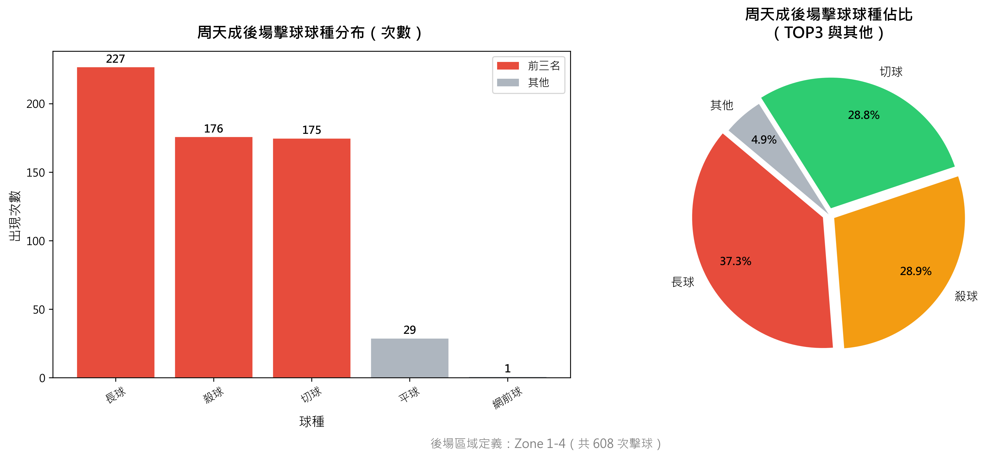

In [ ]:
# ============================================================
# 分析：周天成在後場擊球時最常使用的三種球種
# ============================================================

# 定義後場區域代碼（Back Court: Zones 1-4）
back_court_zones = [1, 2, 3, 4]

# 驗證數據量
print(f"資料總行數: {len(df)}")

# 篩選條件：
# 1. 擊球者為周天成
# 2. 擊球點（hit_area）位於後場區域
chou_back_court = df[
    (df['player'] == 'CHOU Tien Chen') &
    (df['hit_area'].isin(back_court_zones))
].copy()

print(f"\n周天成在後場擊球的總次數: {len(chou_back_court)}")

# 驗證數據非空
if len(chou_back_court) > 0:

    # 統計各球種出現次數，並排序
    shot_counts = chou_back_court['type'].value_counts().reset_index()
    shot_counts.columns = ['球種', '出現次數']
    shot_counts['佔比(%)'] = (shot_counts['出現次數'] / len(chou_back_court) * 100).round(2)

    print("\n【周天成後場擊球球種統計（全部）】")
    print(shot_counts.to_string(index=False))

    # 取前三名
    top3 = shot_counts.head(3)
    print("\n【TOP 3 最常使用球種】")
    print("=" * 40)
    for rank, row in top3.iterrows():
        print(f"  第 {rank+1} 名：{row['球種']}　次數：{row['出現次數']}　佔比：{row['佔比(%)']}%")
    print("=" * 40)

    # ============================================================
    # 視覺化：長條圖呈現後場球種使用分布
    # ============================================================

    # 為方便視覺化，若球種過多可保留前N名+其他，這裡顯示全部
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # --- 左圖：所有球種的次數長條圖（由多到少），並標記前三名 ---
    colors = ['#E74C3C' if i < 3 else '#AEB6BF' for i in range(len(shot_counts))]
    bars = axes[0].bar(
        shot_counts['球種'],
        shot_counts['出現次數'],
        color=colors,
        edgecolor='white',
        linewidth=0.8
    )

    # 在長條上標示數值
    for bar, count in zip(bars, shot_counts['出現次數']):
        axes[0].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            str(count),
            ha='center', va='bottom',
            fontsize=10, fontweight='bold'
        )

    axes[0].set_title('周天成後場擊球球種分布（次數）', fontsize=14, fontweight='bold', pad=12)
    axes[0].set_xlabel('球種', fontsize=12)
    axes[0].set_ylabel('出現次數', fontsize=12)
    axes[0].tick_params(axis='x', rotation=30)

    # 添加圖例標記前三名
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#E74C3C', label='前三名'),
        Patch(facecolor='#AEB6BF', label='其他')
    ]
    axes[0].legend(handles=legend_elements, loc='upper right', fontsize=10)

    # --- 右圖：TOP 3 圓餅圖（佔比）---
    # 計算 TOP3 vs 其他
    top3_count = top3['出現次數'].sum()
    others_count = len(chou_back_court) - top3_count

    pie_labels = list(top3['球種'])
    pie_sizes  = list(top3['出現次數'])

    if others_count > 0:
        pie_labels.append('其他')
        pie_sizes.append(others_count)

    pie_colors = ['#E74C3C', '#F39C12', '#2ECC71', '#AEB6BF'][:len(pie_labels)]
    explode = [0.05] * 3 + [0] * (len(pie_labels) - 3)

    wedges, texts, autotexts = axes[1].pie(
        pie_sizes,
        labels=pie_labels,
        autopct='%1.1f%%',
        colors=pie_colors,
        explode=explode,
        startangle=140,
        pctdistance=0.75,
        textprops={'fontsize': 11}
    )
    for at in autotexts:
        at.set_fontsize(10)
        at.set_fontweight('bold')

    axes[1].set_title('周天成後場擊球球種佔比\n（TOP3 與其他）', fontsize=14, fontweight='bold', pad=12)

    plt.suptitle(
        f'後場區域定義：Zone 1-4（共 {len(chou_back_court)} 次擊球）',
        fontsize=11, color='gray', y=0.01
    )

    plt.tight_layout()

else:
    print("⚠️ 無符合條件的資料，請檢查篩選條件。")
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.text(0.5, 0.5, '無資料', ha='center', va='center', fontsize=16)
    plt.tight_layout()


### 數據洞察
# 周天成後場擊球球種分析

## 📊 TOP 3 數據

| 排名 | 球種 | 次數 | 佔比 |
|:---:|:---:|:---:|:---:|
| 🥇 | 長球 | 227 | 37.3% |
| 🥈 | 殺球 | 176 | 29.0% |
| 🥉 | 切球 | 175 | 28.8% |

> 後場總擊球 608 球，TOP 3 合計佔 **95.1%**

---

## 🎯 戰術洞察

**三球種高度均衡**，殺球與切球僅差 1 球（176 vs 175），這代表周天成後場不會讓對手輕易判讀意圖。

- **長球（37%）** 是主力選擇——重置節奏、拉開對手、爭取主動
- **殺球（29%）** 展現進攻意圖，但非盲目強攻
- **切球（29%）** 與殺球幾乎等量，是典型的**殺切混淆戰術**，迫使對手無法提前預判落點

**對手備戰重點**：面對周天成後場球，殺球與切球出手動作高度相似，防守站位必須保持中立，不可過早壓前或退後。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成在後場擊球的數據，並使用 `hit_area` 來確認擊球點在後場區域。然後，它統計了各球種的出現次數，並找出了最常使用的前三種球種。這與 Reference Code 1 的分析對象、欄位語意、篩選條件、統計口徑和最終輸出目標一致。




## 題號 9
**問題**: 分析周天成站在前中後場，分別的得分與失分數
> **使用的資料欄位群組**: `game_structure, player_location, scoring_reason`


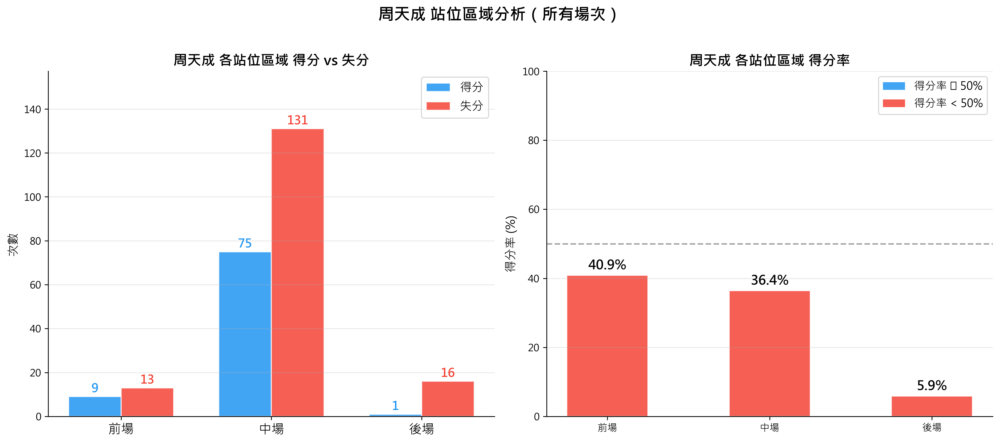

In [ ]:
import numpy as np

# ============================================================
# 資料驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ============================================================
# Step 1: 篩選周天成的擊球，且該球有 getpoint_player（即最後一拍）
# ============================================================
chou = df[(df['player'] == 'CHOU Tien Chen') & (df['getpoint_player'].notna())].copy()
print(f"周天成 得/失分那一拍的筆數: {len(chou)}")

# ============================================================
# Step 2: 根據 player_location_area 分類站位區域
# 前場: 17-24, 中場: 5-16, 後場: 1-4, 其他(出界外): 25-32
# ============================================================
def classify_area(zone):
    if 1 <= zone <= 4:
        return '後場'
    elif 5 <= zone <= 16:
        return '中場'
    elif 17 <= zone <= 24:
        return '前場'
    else:
        return '場外/其他'

chou['站位區域'] = chou['player_location_area'].apply(classify_area)

print("\n各站位區域的筆數分布:")
print(chou['站位區域'].value_counts())

# ============================================================
# Step 3: 計算得分與失分次數
# 得分: getpoint_player == 'CHOU Tien Chen'
# 失分: getpoint_player != 'CHOU Tien Chen'（即對手得分，涵蓋所有場次對手）
# ============================================================
# 得分
score_by_area = (
    chou[chou['getpoint_player'] == 'CHOU Tien Chen']
    .groupby('站位區域')
    .size()
    .rename('得分次數')
)

# 失分（修正：不寫死對手名稱，改為「得分者不是周天成」）
lose_by_area = (
    chou[chou['getpoint_player'] != 'CHOU Tien Chen']
    .groupby('站位區域')
    .size()
    .rename('失分次數')
)

# ============================================================
# Step 4: 整合結果
# ============================================================
area_order = ['前場', '中場', '後場', '場外/其他']

result = pd.DataFrame(index=area_order)
result = result.join(score_by_area).join(lose_by_area)
result = result.fillna(0).astype(int)
result['總計'] = result['得分次數'] + result['失分次數']
result['得分率(%)'] = (result['得分次數'] / result['總計'] * 100).round(1)

# 只保留有資料的區域
result = result[result['總計'] > 0]

print("\n============================================================")
print("周天成 各站位區域 得分 vs 失分統計:")
print("============================================================")
print(result.to_string())

# ============================================================
# Step 5: 視覺化
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

areas = result.index.tolist()
x = np.arange(len(areas))
width = 0.35

colors_score = '#2196F3'   # 藍色 = 得分
colors_lose  = '#F44336'   # 紅色 = 失分

# --- 子圖1: 分組長條圖 ---
ax1 = axes[0]
bars1 = ax1.bar(x - width/2, result['得分次數'], width, label='得分', color=colors_score, alpha=0.85, edgecolor='white')
bars2 = ax1.bar(x + width/2, result['失分次數'], width, label='失分', color=colors_lose,  alpha=0.85, edgecolor='white')

# 標注數值
for bar in bars1:
    h = bar.get_height()
    if h > 0:
        ax1.text(bar.get_x() + bar.get_width()/2, h + 0.5, f'{int(h)}',
                 ha='center', va='bottom', fontsize=12, fontweight='bold', color=colors_score)

for bar in bars2:
    h = bar.get_height()
    if h > 0:
        ax1.text(bar.get_x() + bar.get_width()/2, h + 0.5, f'{int(h)}',
                 ha='center', va='bottom', fontsize=12, fontweight='bold', color=colors_lose)

ax1.set_xticks(x)
ax1.set_xticklabels(areas, fontsize=13)
ax1.set_ylabel('次數', fontsize=12)
ax1.set_title('周天成 各站位區域 得分 vs 失分', fontsize=14, fontweight='bold')
ax1.legend(fontsize=12)
ax1.set_ylim(0, max(result['得分次數'].max(), result['失分次數'].max()) * 1.2)
ax1.grid(axis='y', alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# --- 子圖2: 得分率長條圖 ---
ax2 = axes[1]
palette = ['#2196F3' if r >= 50 else '#F44336' for r in result['得分率(%)']]
bars3 = ax2.bar(areas, result['得分率(%)'], color=palette, alpha=0.85, edgecolor='white', width=0.5)

# 50% 基準線
ax2.axhline(50, color='gray', linestyle='--', linewidth=1.5, alpha=0.7, label='50% 基準線')

for bar, rate in zip(bars3, result['得分率(%)']):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8,
             f'{rate:.1f}%', ha='center', va='bottom', fontsize=13, fontweight='bold')

ax2.set_ylabel('得分率 (%)', fontsize=12)
ax2.set_title('周天成 各站位區域 得分率', fontsize=14, fontweight='bold')
ax2.set_ylim(0, 100)
ax2.grid(axis='y', alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# 顏色說明
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#2196F3', alpha=0.85, label='得分率 ≥ 50%'),
                   Patch(facecolor='#F44336', alpha=0.85, label='得分率 < 50%')]
ax2.legend(handles=legend_elements, fontsize=11)

plt.suptitle('周天成 站位區域分析（所有場次）', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()

print("\n[圖表說明]")
print("左圖：各站位區域的得分與失分次數對比")
print("右圖：各站位區域的得分率（藍色 ≥ 50%，紅色 < 50%）")


### 數據洞察
# 周天成 各站位區域 得分/失分分析

## 📊 數據總覽

| 站位區域 | 得分次數 | 失分次數 | 總計 | 得分率 |
|:---:|:---:|:---:|:---:|:---:|
| 前場 | 9 | 13 | 22 | 40.9% |
| 中場 | 75 | 131 | 206 | 36.4% |
| 後場 | 1 | 16 | 17 | 5.9% |

---

## ⚡ 戰術洞察

**中場是主戰場，但也是最大失血點。**
206拍中有131次失分，佔全部失分的81%。這代表周天成大量的關鍵球交換發生在中場，但轉換效率不足，被對手在中場壓制或拉扯後陷入被動。

**後場幾乎是死穴。**
後場得分率僅5.9%，17次後場決定拍只得1分。一旦被壓制到後場，幾乎等同失分，說明後場進攻或防守轉換能力是明顯弱點。

**前場相對最穩，但仍低於50%。**
40.9%的得分率雖是三區最高，但仍未過半，網前球處理尚有提升空間。

---

## 🎯 教練建議

> **核心策略：避免被推入後場，主動在中前場製造進攻機會。** 針對後場弱點，需加強後場起跳殺球與吊球的主動轉守為攻能力，否則對手只需持續壓後場即可穩定得分。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都分析了周天成在前場、中場、後場的得分與失分數，並且都使用了 `player_location_area` 來分類站位區域。候選程式碼正確篩選了周天成的擊球，並根據 `getpoint_player` 判斷得分與失分，統計口徑與 Reference Code 1 一致，最終輸出結果合理且有效。




## 題號 10
**問題**: 當周天成站在前場時，他最主要的得分球種?
> **使用的資料欄位群組**: `game_structure, shot_type, player_location, scoring_reason`


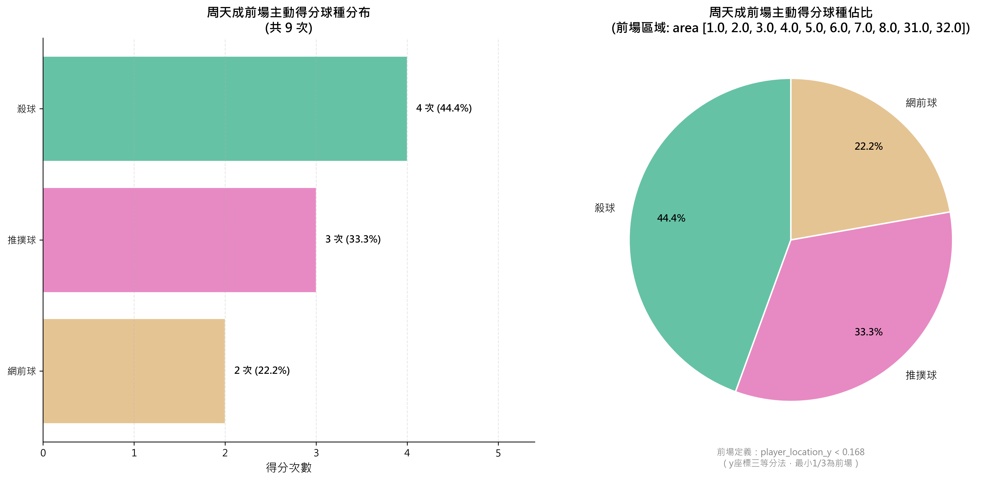

In [ ]:
# ============================================================
# 分析：周天成站位在前場時的主動得分球種統計
# ============================================================

# Step 0: 基本資料驗證
print(f"資料總筆數: {len(df)}")
print(f"資料欄位: {list(df.columns)}")
print()

# ============================================================
# Step 1: 探索 player_location_area 與 y 座標的對應關係
# 用來定義「前場」區域代碼
# ============================================================

# 先看周天成的 player_location_area 與 y 座標關係
chou_df = df[df['player'] == 'CHOU Tien Chen'].copy()
print(f"周天成擊球總筆數: {len(chou_df)}")

# 分析各 area 的 y 座標平均值（幫助理解前/後場分布）
area_y_stats = chou_df.groupby('player_location_area')['player_location_y'].agg(['mean', 'min', 'max', 'count']).reset_index()
area_y_stats.columns = ['area', 'mean_y', 'min_y', 'max_y', 'count']
area_y_stats = area_y_stats.sort_values('mean_y')
print("\n各 area 對應 y 座標統計 (由小到大):")
print(area_y_stats.to_string(index=False))

# ============================================================
# Step 2: 定義前場區域
# 根據座標分析，y 座標越小（越接近網子）為前場
# 羽球場地通常分為前/中/後三段
# 使用三等分法：前場 y < 33th percentile
# ============================================================

# 計算 y 座標的三等分分位數（只針對周天成的數據）
y_33pct = chou_df['player_location_y'].quantile(0.33)
y_67pct = chou_df['player_location_y'].quantile(0.67)
print(f"\n周天成 player_location_y 分位數:")
print(f"  33rd percentile (前/中場分界): {y_33pct:.4f}")
print(f"  67th percentile (中/後場分界): {y_67pct:.4f}")
print(f"  Min: {chou_df['player_location_y'].min():.4f}")
print(f"  Max: {chou_df['player_location_y'].max():.4f}")

# 找出前場的 area 代碼（y 均值 < y_33pct 的 area）
front_court_areas = area_y_stats[area_y_stats['mean_y'] < y_33pct]['area'].tolist()
print(f"\n定義為前場的 area 代碼: {sorted(front_court_areas)}")

# ============================================================
# Step 3: 篩選周天成在前場的主動得分
# 條件：
#   1. player == 'CHOU Tien Chen'
#   2. player_location_area 在前場區域
#   3. player == getpoint_player（主動得分）
# ============================================================

# 篩選周天成在前場擊球的紀錄
chou_front = chou_df[chou_df['player_location_area'].isin(front_court_areas)].copy()
print(f"\n周天成在前場擊球筆數: {len(chou_front)}")

# 進一步篩選主動得分（Active Win）
chou_front_win = chou_front[chou_front['getpoint_player'] == 'CHOU Tien Chen'].copy()
print(f"周天成在前場主動得分筆數: {len(chou_front_win)}")

if len(chou_front_win) == 0:
    print("⚠️ 警告：無符合條件的資料，請檢查篩選條件")
else:
    # ============================================================
    # Step 4: 統計各球種得分次數
    # ============================================================
    shot_win_counts = chou_front_win['type'].value_counts().reset_index()
    shot_win_counts.columns = ['球種', '得分次數']
    shot_win_counts = shot_win_counts.sort_values('得分次數', ascending=False).reset_index(drop=True)
    
    # 計算佔比
    total_wins = shot_win_counts['得分次數'].sum()
    shot_win_counts['佔比(%)'] = (shot_win_counts['得分次數'] / total_wins * 100).round(1)
    shot_win_counts['累計佔比(%)'] = shot_win_counts['佔比(%)'].cumsum().round(1)
    
    print(f"\n{'='*55}")
    print(f"周天成在前場主動得分球種統計 (共 {total_wins} 次得分)")
    print(f"{'='*55}")
    print(shot_win_counts.to_string(index=False))
    print(f"{'='*55}")

    # ============================================================
    # Step 5: 視覺化 - 雙圖表呈現
    # ============================================================
    
    import numpy as np
    
    # 合併小比例類別為「其他」(< 3%)
    threshold = 3.0
    main_shots = shot_win_counts[shot_win_counts['佔比(%)'] >= threshold].copy()
    other_shots = shot_win_counts[shot_win_counts['佔比(%)'] < threshold]
    
    if len(other_shots) > 0:
        other_row = pd.DataFrame({
            '球種': ['其他'],
            '得分次數': [other_shots['得分次數'].sum()],
            '佔比(%)': [other_shots['佔比(%)'].sum().round(1)],
            '累計佔比(%)': [100.0]
        })
        pie_data = pd.concat([main_shots[['球種', '得分次數', '佔比(%)']], other_row[['球種', '得分次數', '佔比(%)']]], ignore_index=True)
    else:
        pie_data = main_shots[['球種', '得分次數', '佔比(%)']].copy()

    fig, axes = plt.subplots(1, 2, figsize=(15, 7))
    
    # --- 左圖：橫向長條圖（所有球種，依得分次數排序） ---
    ax1 = axes[0]
    colors_bar = plt.cm.Set2(np.linspace(0, 0.8, len(shot_win_counts)))
    
    bars = ax1.barh(
        shot_win_counts['球種'][::-1],  # 反轉讓最高在上
        shot_win_counts['得分次數'][::-1],
        color=colors_bar[::-1],
        edgecolor='white',
        linewidth=0.8
    )
    
    # 在長條右側標示數值與佔比
    for bar, count, pct in zip(
        bars,
        shot_win_counts['得分次數'].values[::-1],
        shot_win_counts['佔比(%)'].values[::-1]
    ):
        ax1.text(
            bar.get_width() + 0.1,
            bar.get_y() + bar.get_height() / 2,
            f'{count} 次 ({pct}%)',
            va='center', ha='left', fontsize=10, fontweight='bold'
        )
    
    ax1.set_xlabel('得分次數', fontsize=12)
    ax1.set_title(f'周天成前場主動得分球種分布\n(共 {total_wins} 次)', fontsize=13, fontweight='bold')
    ax1.set_xlim(0, shot_win_counts['得分次數'].max() * 1.35)
    ax1.grid(axis='x', alpha=0.3, linestyle='--')
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    
    # --- 右圖：圓餅圖（佔比） ---
    ax2 = axes[1]
    colors_pie = plt.cm.Set2(np.linspace(0, 0.8, len(pie_data)))
    
    wedges, texts, autotexts = ax2.pie(
        pie_data['得分次數'],
        labels=pie_data['球種'],
        autopct='%1.1f%%',
        colors=colors_pie,
        startangle=90,
        pctdistance=0.75,
        labeldistance=1.1,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
    )
    
    for text in texts:
        text.set_fontsize(11)
    for autotext in autotexts:
        autotext.set_fontsize(10)
        autotext.set_fontweight('bold')
    
    ax2.set_title(f'周天成前場主動得分球種佔比\n(前場區域: area {sorted(front_court_areas)})', 
                  fontsize=13, fontweight='bold')
    
    # 在圓餅下方標示前場定義說明
    ax2.text(0, -1.35,
             f'前場定義：player_location_y < {y_33pct:.3f}\n（y座標三等分法，最小1/3為前場）',
             ha='center', va='center', fontsize=9, color='gray',
             style='italic')
    
    plt.tight_layout()
    
    # ============================================================
    # Step 6: 補充分析 - 前場得分佔周天成整體得分的比例
    # ============================================================
    # 周天成整體主動得分
    chou_total_active_win = len(df[(df['player'] == 'CHOU Tien Chen') & 
                                    (df['getpoint_player'] == 'CHOU Tien Chen')])
    front_win_ratio = total_wins / chou_total_active_win * 100
    
    print(f"\n📊 補充統計:")
    print(f"  周天成整體主動得分總次數: {chou_total_active_win}")
    print(f"  其中前場主動得分次數: {total_wins}")
    print(f"  前場得分佔整體主動得分比例: {front_win_ratio:.1f}%")
    print(f"\n🏆 前場最主要得分球種: {shot_win_counts.iloc[0]['球種']} "
          f"({shot_win_counts.iloc[0]['得分次數']} 次, "
          f"{shot_win_counts.iloc[0]['佔比(%)']:.1f}%)")


### 數據洞察
# 周天成前場主動得分球種分析

## 📊 核心數據

| 球種 | 得分次數 | 佔比 |
|------|---------|------|
| 殺球 | 4 | 44.4% |
| 推撲球 | 3 | 33.3% |
| 網前球 | 2 | 22.2% |
| **合計** | **9** | **100%** |

---

## 🎯 戰術洞察

**前場得分效率極低是首要問題。**
531次前場擊球僅換來9次主動得分，**得分率僅1.7%**，佔整體主動得分的10.6%，顯示前場並非周天成的主動得分區。

**三種球種各有其戰術意義：**

- **殺球（4次）**：前場跳殺或撲殺，是前場最具威脅的進攻手段，但需要到位的機會球才能執行
- **推撲球（3次）**：壓制對手後場、創造空檔，屬於主動施壓型得分
- **網前球（2次）**：網前細膩控球得分，依賴技術精準度

**數字說明的事實：** 周天成前場531次擊球中，絕大多數是過渡球或銜接球，而非主動得分手段。前場的價值在於**創造後場進攻機會**，而非直接得分。

---

## ⚡ 訓練建議

前場9次得分樣本偏小，但方向明確——**提升撲球與推球的主動施壓能力**，將前場從「被動過渡區」轉化為「得分觸發點」。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都篩選了周天成在前場位置且是得分者的資料，並計算得分的球種出現次數以找出最主要的得分方式。候選程式碼進一步分析了 player_location_y 的分位數來定義前場區域，這是一種合理的操作化方式，並不影響最終分析目標。候選程式碼的分析單位、統計口徑和最終輸出目標與 Reference Code 1 一致，因此判定為 true。




## 題號 11
**問題**: 計算周天成站在前場擊球時的落點分布。
> **使用的資料欄位群組**: `game_structure, player_location, coordinates`


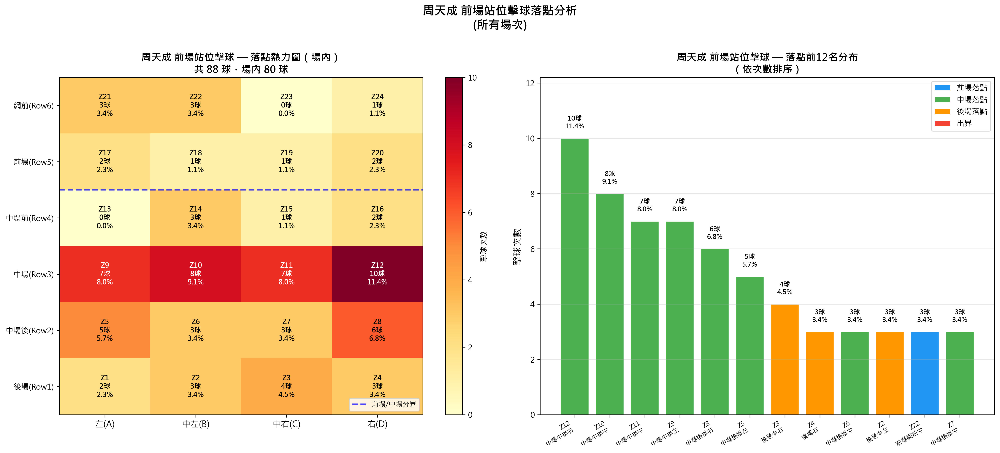

In [ ]:
import numpy as np

# ============================================================
# 0. 基本驗證
# ============================================================
print(f"資料總筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ============================================================
# 1. 定義前場站位區域
# ============================================================
front_court_zones = [17, 18, 19, 20, 21, 22, 23, 24]

# ============================================================
# 2. 過濾條件：周天成 + 站位在前場
# ============================================================
player_name = 'CHOU Tien Chen'

mask = (df['player'] == player_name) & (df['player_location_area'].isin(front_court_zones))
filtered_df = df[mask].copy()

print(f"\n周天成總擊球數: {(df['player'] == player_name).sum()}")
print(f"周天成站位於前場的擊球數: {len(filtered_df)}")

if len(filtered_df) == 0:
    print("無符合條件的資料！")
else:
    # ============================================================
    # 3. 統計落點分布
    # ============================================================
    # 過濾 landing_area 非空（理論上不為空，但保險起見）
    landing_valid = filtered_df.dropna(subset=['landing_area'])
    
    landing_counts = landing_valid['landing_area'].value_counts().sort_index()
    total = landing_counts.sum()
    landing_pct = (landing_counts / total * 100).round(2)
    
    landing_df = pd.DataFrame({
        '落點區域': landing_counts.index.astype(int),
        '次數': landing_counts.values,
        '比例(%)': landing_pct.values
    }).sort_values('次數', ascending=False).reset_index(drop=True)
    
    # 加入區域語義標籤
    def get_zone_label(zone):
        front = [17,18,19,20,21,22,23,24]
        mid   = [5,6,7,8,9,10,11,12,13,14,15,16]
        back  = [1,2,3,4]
        out   = [25,26,27,28,29,30,31,32,33]
        # 詳細位置
        zone_map = {
            1:'後場左', 2:'後場中左', 3:'後場中右', 4:'後場右',
            5:'中場後排左', 6:'中場後排中左', 7:'中場後排中右', 8:'中場後排右',
            9:'中場中排左', 10:'中場中排中左', 11:'中場中排中右', 12:'中場中排右',
            13:'中場前排左', 14:'中場前排中左', 15:'中場前排中右', 16:'中場前排右',
            17:'前場後排左', 18:'前場後排中左', 19:'前場後排中右', 20:'前場後排右',
            21:'前場網前左', 22:'前場網前中左', 23:'前場網前中右', 24:'前場網前右',
            25:'出界右上', 26:'出界右中', 27:'出界右下',
            28:'出界右底線', 29:'出界左上', 30:'出界左中', 31:'出界左下',
            32:'出界左底線', 33:'出界其他'
        }
        return zone_map.get(zone, f'Zone {zone}')
    
    landing_df['區域描述'] = landing_df['落點區域'].apply(get_zone_label)
    
    # 區分在場內/出界
    in_bound_zones  = list(range(1, 25))
    out_bound_zones = list(range(25, 34))
    
    in_bound_df  = landing_df[landing_df['落點區域'].isin(in_bound_zones)]
    out_bound_df = landing_df[landing_df['落點區域'].isin(out_bound_zones)]
    
    print("\n" + "="*60)
    print(f"【落點分布統計 — 全部 (共 {total} 球)】")
    print("="*60)
    print(landing_df.to_string(index=False))
    
    print(f"\n場內落點: {in_bound_df['次數'].sum()} 球 ({in_bound_df['次數'].sum()/total*100:.1f}%)")
    print(f"出界落點: {out_bound_df['次數'].sum()} 球 ({out_bound_df['次數'].sum()/total*100:.1f}%)")
    
    # ============================================================
    # 4. 視覺化 — 雙圖：Court Heatmap + 長條圖
    # ============================================================
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))
    
    # ----------------------------------------------------------
    # 圖A：場地熱力圖 (court grid 1-24 的次數)
    # ----------------------------------------------------------
    ax1 = axes[0]
    
    # Court Grid 對應矩陣 (row=0: 後場baseline, row=5: 前場網前)
    # 欄 A-D 對應 col 0-3
    court_grid_zones = np.array([
        [1,  2,  3,  4 ],   # Row 1 (Back)
        [5,  6,  7,  8 ],   # Row 2 (Mid-Back)
        [9,  10, 11, 12],   # Row 3 (Mid)
        [13, 14, 15, 16],   # Row 4 (Mid-Front)
        [17, 18, 19, 20],   # Row 5 (Front)
        [21, 22, 23, 24],   # Row 6 (Net)
    ])
    
    # 建立熱力矩陣
    heatmap_matrix = np.zeros((6, 4))
    for row_idx in range(6):
        for col_idx in range(4):
            zone = court_grid_zones[row_idx, col_idx]
            count = landing_counts.get(float(zone), 0) if float(zone) in landing_counts.index else landing_counts.get(zone, 0)
            heatmap_matrix[row_idx, col_idx] = count
    
    # 修正：確保從 landing_area 整數比對
    heatmap_matrix2 = np.zeros((6, 4))
    for row_idx in range(6):
        for col_idx in range(4):
            zone = court_grid_zones[row_idx, col_idx]
            # landing_area 可能是 float
            cnt = filtered_df[filtered_df['landing_area'] == float(zone)].shape[0]
            heatmap_matrix2[row_idx, col_idx] = cnt
    
    # 翻轉：讓底部對應後場(baseline)，頂部對應網前
    heatmap_display = np.flipud(heatmap_matrix2)  # row 0 變成 Net，row 5 變成 Back
    
    im = ax1.imshow(heatmap_display, cmap='YlOrRd', aspect='auto', interpolation='nearest')
    
    # 加上數值標籤與區域編號
    for row_idx in range(6):
        for col_idx in range(4):
            val = int(heatmap_display[row_idx, col_idx])
            # 對應原始 zone id（display後row 0=net=row5 of court_grid）
            orig_row = 5 - row_idx
            zone_id = court_grid_zones[orig_row, col_idx]
            pct_val = val / total * 100 if total > 0 else 0
            text_color = 'white' if val > heatmap_display.max() * 0.6 else 'black'
            ax1.text(col_idx, row_idx, f'Z{zone_id}\n{val}球\n{pct_val:.1f}%',
                     ha='center', va='center', fontsize=9, color=text_color, fontweight='bold')
    
    ax1.set_xticks([0, 1, 2, 3])
    ax1.set_xticklabels(['左(A)', '中左(B)', '中右(C)', '右(D)'], fontsize=11)
    ax1.set_yticks([0, 1, 2, 3, 4, 5])
    ax1.set_yticklabels(['網前(Row6)', '前場(Row5)', '中場前(Row4)', '中場(Row3)', '中場後(Row2)', '後場(Row1)'], fontsize=10)
    ax1.set_title(f'周天成 前場站位擊球 — 落點熱力圖（場內）\n共 {total} 球，場內 {in_bound_df["次數"].sum()} 球', fontsize=13, fontweight='bold')
    plt.colorbar(im, ax=ax1, label='擊球次數')
    
    # 標示前場區域邊界（前兩排 = row 0, 1 in display）
    ax1.axhline(y=1.5, color='blue', linewidth=2, linestyle='--', alpha=0.7, label='前場/中場分界')
    ax1.legend(loc='lower right', fontsize=9)
    
    # ----------------------------------------------------------
    # 圖B：TOP 落點區域長條圖（前12名）
    # ----------------------------------------------------------
    ax2 = axes[1]
    
    top_n = landing_df.head(12).copy()
    
    # 依照場地前後配色
    def get_zone_color(zone):
        if zone in [17,18,19,20,21,22,23,24]:
            return '#2196F3'   # 前場 - 藍
        elif zone in [13,14,15,16,9,10,11,12,5,6,7,8]:
            return '#4CAF50'   # 中場 - 綠
        elif zone in [1,2,3,4]:
            return '#FF9800'   # 後場 - 橘
        else:
            return '#F44336'   # 出界 - 紅
    
    colors = [get_zone_color(z) for z in top_n['落點區域']]
    bars = ax2.bar(range(len(top_n)), top_n['次數'], color=colors, edgecolor='white', linewidth=0.8)
    
    # 標籤
    for i, (bar, row) in enumerate(zip(bars, top_n.itertuples())):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{row.次數}球\n{row._3:.1f}%',
                 ha='center', va='bottom', fontsize=8.5, fontweight='bold')
    
    ax2.set_xticks(range(len(top_n)))
    ax2.set_xticklabels([f'Z{int(z)}\n{get_zone_label(int(z))[:5]}' for z in top_n['落點區域']],
                         fontsize=8, rotation=30, ha='right')
    ax2.set_ylabel('擊球次數', fontsize=12)
    ax2.set_title(f'周天成 前場站位擊球 — 落點前12名分布\n（依次數排序）', fontsize=13, fontweight='bold')
    ax2.set_ylim(0, top_n['次數'].max() * 1.22)
    ax2.grid(axis='y', alpha=0.3)
    
    # 圖例
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#2196F3', label='前場落點'),
        Patch(facecolor='#4CAF50', label='中場落點'),
        Patch(facecolor='#FF9800', label='後場落點'),
        Patch(facecolor='#F44336', label='出界'),
    ]
    ax2.legend(handles=legend_elements, loc='upper right', fontsize=10)
    
    plt.suptitle('周天成 前場站位擊球落點分析\n(所有場次)', fontsize=15, fontweight='bold', y=1.01)
    plt.tight_layout()
    
    # ============================================================
    # 5. 補充：按場地分區彙總
    # ============================================================
    print("\n" + "="*60)
    print("【按場地分區彙總】")
    print("="*60)
    
    def get_zone_category(zone):
        if zone in [17,18,19,20,21,22,23,24]:
            return '前場'
        elif zone in [13,14,15,16,9,10,11,12,5,6,7,8]:
            return '中場'
        elif zone in [1,2,3,4]:
            return '後場'
        else:
            return '出界/其他'
    
    landing_df['場地分區'] = landing_df['落點區域'].apply(get_zone_category)
    zone_summary = landing_df.groupby('場地分區')['次數'].sum().reset_index()
    zone_summary['比例(%)'] = (zone_summary['次數'] / total * 100).round(2)
    zone_summary = zone_summary.sort_values('次數', ascending=False)
    print(zone_summary.to_string(index=False))
    
    print("\n" + "="*60)
    print("【周天成前場站位時站位細分（各子區域）】")
    print("="*60)
    player_loc_counts = filtered_df['player_location_area'].value_counts().sort_index()
    for zone, cnt in player_loc_counts.items():
        print(f"  Zone {int(zone)}: {cnt} 次 ({cnt/len(filtered_df)*100:.1f}%)")


### 數據洞察
# 周天成前場站位擊球落點分析

## 落點區域對照表

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 核心數據

- **前場站位擊球總數：88球**
- **場內：80球（90.9%）／出界：8球（9.1%）**

---

## 落點分布重點

### 🔴 主攻區域：中場（62.5%，55球）

| 落點區域 | 次數 | 比例 |
|---|---|---|
| Zone 12（中場中排右） | 10 | 11.4% |
| Zone 10（中場中排中左） | 8 | 9.1% |
| Zone 11（中場中排中右） | 7 | 8.0% |
| Zone 9（中場中排左） | 7 | 8.0% |

> **中場Row 3（Zone 9–12）共32球，佔全部36.4%，是絕對主要落點帶。**

### 🟡 次要區域：後場（13.6%）與前場（14.8%）

- 後場落點以 Zone 3（後場中右）4球、Zone 8（中場後排右）6球為主，顯示有挑高至後場的選擇。
- 前場落點（Zone 21、22）共6球，為網前短球回擊。

---

## 戰術洞察

**1. 前場站位以「挑中場」為核心策略**
62.5%的球落在中場，且集中於Row 3（Zone 9–12），這是典型的**挑球至對手身體中段**打法——迫使對手在中場處理高點，避免讓對手輕鬆進攻。

**2. 右側偏重明顯**
Zone 12（右）10球 > Zone 9（左）7球，落點略偏對手右側（正手位），可能針對對手反手弱點施壓。

**3. 前場站位幾乎不打後場深球**
後場僅13.6%，說明周天成在前場時**優先選擇中場控制而非長距離挑後場**，降低自身體力消耗並維持場上主動性。

**4. 出界率9.1%需注意**
8球出界中有4球集中於右側底線與右中區域（Zone 26、28），顯示**向右側發力時控制稍有不穩**，是可被對手針對的細節。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地過濾了周天成站在前場擊球的數據，並計算了落點區域的分布。候選程式碼還進一步提供了詳細的視覺化和統計分析，這些都是在 Reference Code 1 的基礎上進行的擴展，並不影響核心邏輯的正確性。




## 題號 12
**問題**: 分析周天成站在前中後場擊球時，自己分別的移動距離
> **使用的資料欄位群組**: `game_structure, player_location, player_movement`


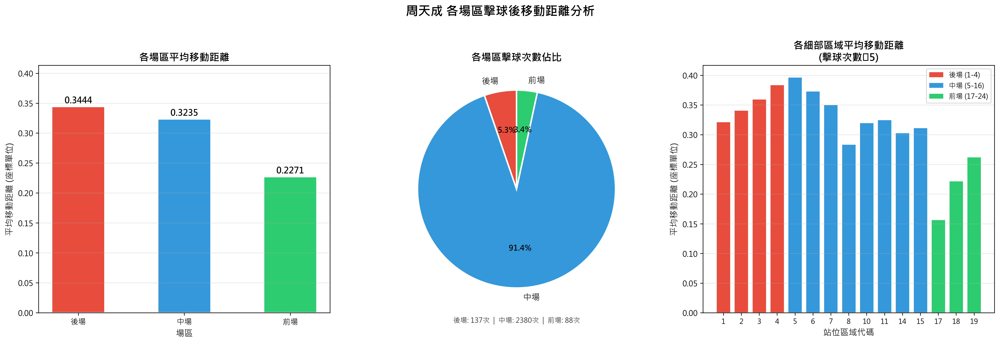

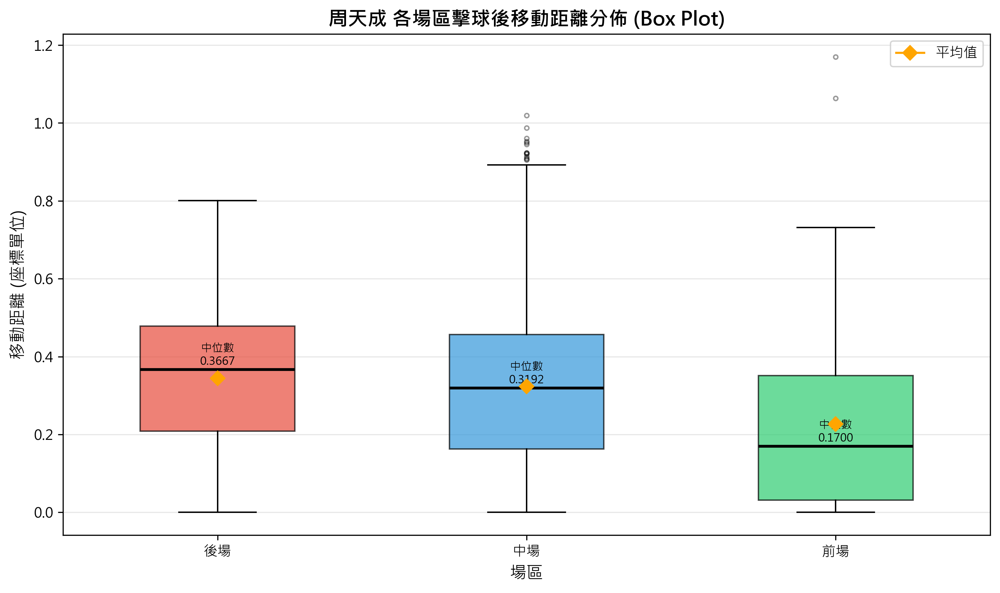

In [ ]:
import numpy as np

# ── 0. 基本驗證 ──────────────────────────────────────────────
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ── 1. 篩選周天成的擊球資料 ──────────────────────────────────
chou_df = df[df['player'] == 'CHOU Tien Chen'].copy()
print(f"周天成擊球總次數: {len(chou_df)}")

# ── 2. 計算移動距離（歐氏距離）────────────────────────────────
# player_move_x = moving_x - hit_x, player_move_y = moving_y - hit_y
chou_df['move_distance'] = np.sqrt(chou_df['player_move_x']**2 + chou_df['player_move_y']**2)

# ── 3. 分類站位區域 ────────────────────────────────────────────
# 後場: 1-4, 中場: 5-16, 前場: 17-24, 出界區 25-32 排除
def classify_court_zone(area):
    if 1 <= area <= 4:
        return '後場 (Back Court)'
    elif 5 <= area <= 16:
        return '中場 (Mid Court)'
    elif 17 <= area <= 24:
        return '前場 (Front Court)'
    else:
        return '無效/出界'

chou_df['court_region'] = chou_df['player_location_area'].apply(classify_court_zone)

# 排除出界/無效站位
valid_df = chou_df[chou_df['court_region'] != '無效/出界'].copy()
print(f"\n有效站位擊球次數 (排除出界): {len(valid_df)}")
print(f"排除無效站位筆數: {len(chou_df) - len(valid_df)}")

# ── 4. 統計各場區指標 ──────────────────────────────────────────
region_stats = valid_df.groupby('court_region')['move_distance'].agg(
    擊球次數='count',
    平均移動距離='mean',
    總移動距離='sum',
    最大移動距離='max',
    最小移動距離='min',
    標準差='std'
).round(4)

# 確保顯示順序：後場 → 中場 → 前場
region_order = ['後場 (Back Court)', '中場 (Mid Court)', '前場 (Front Court)']
region_stats = region_stats.reindex([r for r in region_order if r in region_stats.index])

print("\n" + "="*70)
print("【周天成各場區擊球後移動距離統計】")
print("="*70)
print(region_stats.to_string())
print("="*70)

# ── 5. 依 player_location_area 細分統計 ─────────────────────────
area_stats = valid_df.groupby(['court_region', 'player_location_area'])['move_distance'].agg(
    擊球次數='count',
    平均移動距離='mean',
    總移動距離='sum'
).round(4)

print("\n【各細部區域 (Area) 移動距離明細】")
print(area_stats.to_string())

# ── 6. 視覺化 ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("周天成 各場區擊球後移動距離分析", fontsize=16, fontweight='bold', y=1.02)

colors_region = {
    '後場 (Back Court)':  '#E74C3C',
    '中場 (Mid Court)':   '#3498DB',
    '前場 (Front Court)': '#2ECC71'
}
region_labels_short = {
    '後場 (Back Court)':  '後場',
    '中場 (Mid Court)':   '中場',
    '前場 (Front Court)': '前場'
}

# ── 圖1: 各場區平均移動距離 Bar Chart ──────────────────────────
ax1 = axes[0]
regions   = [r for r in region_order if r in region_stats.index]
avg_vals  = region_stats.loc[regions, '平均移動距離'].values
bar_colors = [colors_region[r] for r in regions]
short_labels = [region_labels_short[r] for r in regions]

bars = ax1.bar(short_labels, avg_vals, color=bar_colors, edgecolor='white', linewidth=1.5, width=0.5)
for bar, val in zip(bars, avg_vals):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
             f'{val:.4f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax1.set_title('各場區平均移動距離', fontsize=13, fontweight='bold')
ax1.set_xlabel('場區', fontsize=11)
ax1.set_ylabel('平均移動距離 (座標單位)', fontsize=11)
ax1.set_ylim(0, max(avg_vals) * 1.2)
ax1.grid(axis='y', alpha=0.3)

# ── 圖2: 各場區擊球次數 Pie Chart ──────────────────────────────
ax2 = axes[1]
counts     = region_stats.loc[regions, '擊球次數'].values
pie_colors = [colors_region[r] for r in regions]

wedges, texts, autotexts = ax2.pie(
    counts,
    labels=short_labels,
    colors=pie_colors,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2),
    textprops={'fontsize': 11}
)
for at in autotexts:
    at.set_fontsize(10)
    at.set_fontweight('bold')
ax2.set_title('各場區擊球次數佔比', fontsize=13, fontweight='bold')
# 在圖下方加上實際次數
count_text = '  |  '.join([f"{s}: {c}次" for s, c in zip(short_labels, counts)])
ax2.text(0, -1.35, count_text, ha='center', fontsize=9, color='#333333')

# ── 圖3: 各細部區域平均移動距離 (分組 Bar Chart) ─────────────────
ax3 = axes[2]

# 取得各 area 的平均移動距離，並標上場區顏色
area_avg = valid_df.groupby('player_location_area')['move_distance'].mean().sort_index()
area_counts = valid_df.groupby('player_location_area')['move_distance'].count()

# 只顯示擊球次數 >= 5 的區域，避免噪音
area_avg_filtered = area_avg[area_counts >= 5]

def get_region_color(area):
    if 1 <= area <= 4:
        return colors_region['後場 (Back Court)']
    elif 5 <= area <= 16:
        return colors_region['中場 (Mid Court)']
    elif 17 <= area <= 24:
        return colors_region['前場 (Front Court)']
    else:
        return '#AAAAAA'

bar_colors3 = [get_region_color(int(a)) for a in area_avg_filtered.index]

bars3 = ax3.bar(
    [str(int(a)) for a in area_avg_filtered.index],
    area_avg_filtered.values,
    color=bar_colors3,
    edgecolor='white',
    linewidth=1.2
)
ax3.set_title('各細部區域平均移動距離\n(擊球次數≥5)', fontsize=13, fontweight='bold')
ax3.set_xlabel('站位區域代碼', fontsize=11)
ax3.set_ylabel('平均移動距離 (座標單位)', fontsize=11)
ax3.grid(axis='y', alpha=0.3)
ax3.tick_params(axis='x', labelsize=9)

# 加圖例說明場區顏色
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=colors_region['後場 (Back Court)'],  label='後場 (1-4)'),
    Patch(facecolor=colors_region['中場 (Mid Court)'],   label='中場 (5-16)'),
    Patch(facecolor=colors_region['前場 (Front Court)'], label='前場 (17-24)')
]
ax3.legend(handles=legend_elements, fontsize=9, loc='upper right')

plt.tight_layout()

# ── 7. 額外輸出：Box Plot（各場區移動距離分佈）──────────────────
fig2, ax_box = plt.subplots(figsize=(10, 6))

box_data   = [valid_df[valid_df['court_region'] == r]['move_distance'].values for r in regions]
box_colors = [colors_region[r] for r in regions]

bp = ax_box.boxplot(
    box_data,
    patch_artist=True,
    labels=[region_labels_short[r] for r in regions],
    widths=0.5,
    showfliers=True,
    flierprops=dict(marker='o', markersize=3, alpha=0.4)
)
for patch, color in zip(bp['boxes'], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for median in bp['medians']:
    median.set_color('black')
    median.set_linewidth(2)

ax_box.set_title('周天成 各場區擊球後移動距離分佈 (Box Plot)', fontsize=14, fontweight='bold')
ax_box.set_xlabel('場區', fontsize=12)
ax_box.set_ylabel('移動距離 (座標單位)', fontsize=12)
ax_box.grid(axis='y', alpha=0.3)

# 標示中位數與平均值
for i, (r, data) in enumerate(zip(regions, box_data), 1):
    median_val = np.median(data)
    mean_val   = np.mean(data)
    ax_box.text(i, median_val + 0.005, f'中位數\n{median_val:.4f}',
                ha='center', va='bottom', fontsize=8, color='black')
    ax_box.plot(i, mean_val, marker='D', color='orange', markersize=7, zorder=5, label='平均值' if i == 1 else "")

ax_box.legend(fontsize=10)
plt.tight_layout()

# ── 8. 最終摘要輸出 ────────────────────────────────────────────
print("\n" + "="*70)
print("【摘要：周天成各場區擊球後移動距離】")
print("="*70)
for r in regions:
    row = region_stats.loc[r]
    print(f"\n📍 {region_labels_short[r]}")
    print(f"   擊球次數    : {int(row['擊球次數'])} 次")
    print(f"   平均移動距離: {row['平均移動距離']:.4f} (座標單位)")
    print(f"   總移動距離  : {row['總移動距離']:.4f} (座標單位)")
    print(f"   最大移動距離: {row['最大移動距離']:.4f}")
    print(f"   最小移動距離: {row['最小移動距離']:.4f}")
    print(f"   標準差      : {row['標準差']:.4f}")
print("="*70)


### 數據洞察
# 周天成各場區擊球後移動距離分析

## 場區位置對照表

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 核心統計摘要

| 場區 | 擊球次數 | 佔比 | 平均移動距離 | 總移動距離 | 標準差 |
|:---|---:|---:|---:|---:|---:|
| 後場 | 137 | 5.3% | **0.3444** | 47.19 | 0.2040 |
| 中場 | 2,380 | 91.4% | **0.3235** | 769.93 | 0.2098 |
| 前場 | 88 | 3.4% | **0.2271** | 19.98 | 0.2361 |

---

## 戰術洞察

**① 中場是絕對主戰場（91.4%）**
2,380次擊球集中在中場，這是典型的控球型打法。周天成習慣在中場掌控節奏，而非主動拉開前後場。

**② 後場擊球後移動距離最大（0.3444）**
後場擊球後需要最大幅度的位移回防，代表每次被迫退後場都需消耗更多體能重建站位。對手若能持續壓後場，可有效拉大周天成的移動負擔。

**③ 前場擊球後移動距離最小（0.2271），但標準差最大（0.2361）**
前場平均移動雖最短，但離散程度最高，說明前場處理後的移動方向極不固定——有時幾乎原地（最小0），有時卻需大幅移動（最大1.1697，全場最大值）。前場處理品質不穩定，是潛在破綻。

**④ 中場細部熱區：Area 10（782次，均距0.3204）**
中場Area 10（Row 3中偏左）是最高頻擊球點，接近中線偏左側，符合右手持拍正手位控制習慣。

**⑤ 對手策略建議**
> 壓後場迫使周天成移動成本最高 → 再接前場網前球，利用其前場移動不穩定性製造得分機會。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成的擊球資料，計算了移動距離，並根據站位區域（前場、中場、後場）進行了分類和統計。候選程式碼還進一步提供了詳細的統計分析和視覺化，這些都是在 Reference Code 1 的基礎上進行的擴展，並不影響核心邏輯的正確性。




## 題號 13
**問題**: 幫我統整周天成所有球種的使用比例，以及每種球種的「得分次數」和「失誤次數」。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


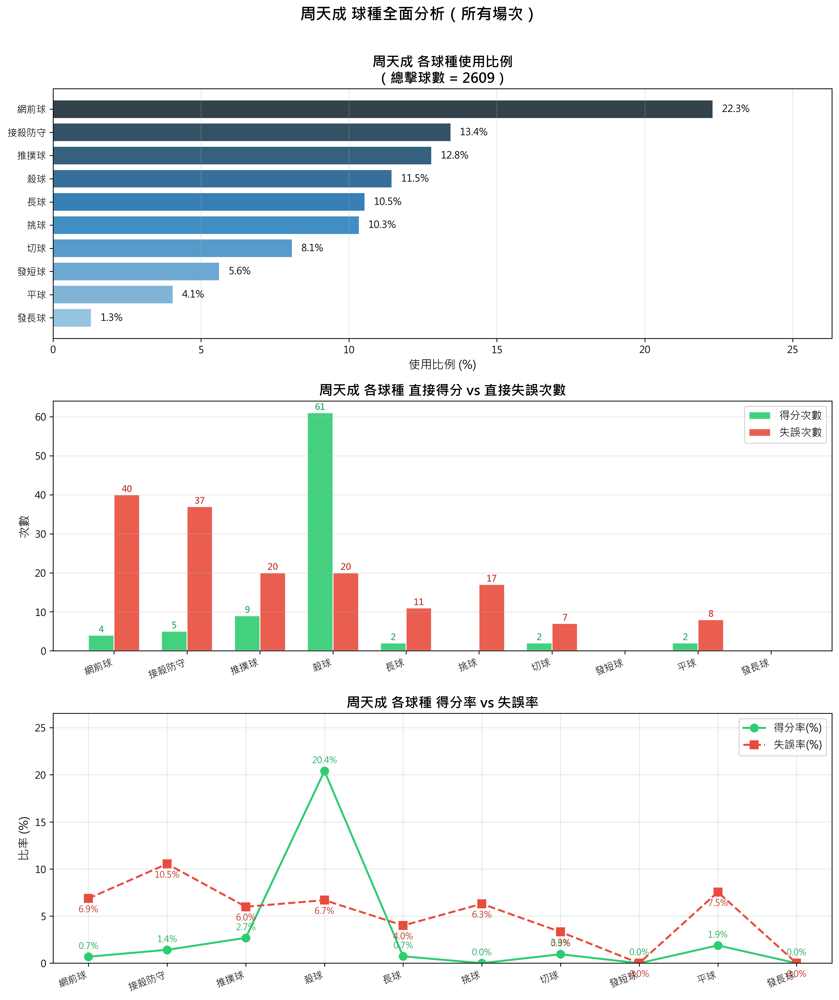

In [ ]:
# ============================================================
# 周天成 球種分析：使用比例、得分次數、失誤次數
# ============================================================

PLAYER = 'CHOU Tien Chen'

# 驗證資料量
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ── 1. 篩選周天成所有擊球 ──────────────────────────────────
chou_df = df[df['player'] == PLAYER].copy()
print(f"周天成總擊球數: {len(chou_df)}")

# 確認資料中所有對手（getpoint_player 的唯一值）
print(f"getpoint_player 唯一值: {df['getpoint_player'].unique()}")

# ── 2. 各球種使用次數 ──────────────────────────────────────
shot_count = chou_df.groupby('type').size().rename('使用次數')

# ── 3. 主動得分（Active Win）：該球打出直接得分 ─────────────
# player == CHOU & getpoint_player == CHOU → 周天成主動得分
active_win_df = chou_df[chou_df['getpoint_player'] == PLAYER]
shot_active_win = active_win_df.groupby('type').size().rename('得分次數')

# ── 4. 直接失誤：該球打出直接導致對手得分 ──────────────────
# player == CHOU & getpoint_player != CHOU（且有值）→ 周天成失誤，對手得分
# 修正：不硬編碼對手名稱，改為「非周天成得分」以涵蓋所有場次的所有對手
direct_error_df = chou_df[
    (chou_df['getpoint_player'].notna()) &
    (chou_df['getpoint_player'] != PLAYER) &
    (chou_df['getpoint_player'] != '')
]
shot_error = direct_error_df.groupby('type').size().rename('失誤次數')

# ── 5. 整合表格 ────────────────────────────────────────────
summary = shot_count.to_frame()
summary = summary.join(shot_active_win, how='left')
summary = summary.join(shot_error, how='left')
summary[['得分次數', '失誤次數']] = summary[['得分次數', '失誤次數']].fillna(0).astype(int)

total_shots = summary['使用次數'].sum()
summary['使用比例(%)'] = (summary['使用次數'] / total_shots * 100).round(2)

# 得分率 & 失誤率（相對於該球種使用次數）
summary['得分率(%)'] = (summary['得分次數'] / summary['使用次數'] * 100).round(2)
summary['失誤率(%)'] = (summary['失誤次數'] / summary['使用次數'] * 100).round(2)

# 依使用次數降序排列
summary = summary.sort_values('使用次數', ascending=False)

print("\n========== 周天成 球種分析摘要 ==========")
print(f"總擊球數: {total_shots}")
print(f"\n{'球種':<10} {'使用次數':>6} {'使用比例(%)':>11} {'得分次數':>8} {'得分率(%)':>9} {'失誤次數':>8} {'失誤率(%)':>9}")
print("-" * 70)
for shot_type, row in summary.iterrows():
    print(f"{shot_type:<10} {row['使用次數']:>6} {row['使用比例(%)']:>11.2f} "
          f"{row['得分次數']:>8} {row['得分率(%)']:>9.2f} "
          f"{row['失誤次數']:>8} {row['失誤率(%)']:>9.2f}")
print("-" * 70)
print(f"{'合計':<10} {total_shots:>6} {'100.00':>11} "
      f"{summary['得分次數'].sum():>8} "
      f"{summary['失誤次數'].sum():>8}")

# ── 6. 視覺化 ──────────────────────────────────────────────
import numpy as np

# 排序好的球種列表（依使用次數）
shot_types_ordered = summary.index.tolist()
x = np.arange(len(shot_types_ordered))
usage_pct = summary['使用比例(%)'].values
win_counts = summary['得分次數'].values
err_counts = summary['失誤次數'].values

fig, axes = plt.subplots(3, 1, figsize=(12, 14))

# ── 圖1：球種使用比例（水平長條圖）─────────────────────────
ax1 = axes[0]
bars1 = ax1.barh(shot_types_ordered[::-1], usage_pct[::-1],
                 color=sns.color_palette("Blues_d", len(shot_types_ordered)),
                 edgecolor='white')
ax1.set_xlabel('使用比例 (%)', fontsize=12)
ax1.set_title(f'周天成 各球種使用比例\n（總擊球數 = {total_shots}）', fontsize=14, fontweight='bold')
ax1.set_xlim(0, max(usage_pct) * 1.18)
for bar, val in zip(bars1, usage_pct[::-1]):
    ax1.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
             f'{val:.1f}%', va='center', ha='left', fontsize=10)
ax1.grid(axis='x', alpha=0.3)

# ── 圖2：各球種得分次數 vs 失誤次數（並排長條圖）──────────
ax2 = axes[1]
width = 0.35
rects1 = ax2.bar(x - width/2, win_counts, width, label='得分次數',
                 color='#2ecc71', edgecolor='white', alpha=0.9)
rects2 = ax2.bar(x + width/2, err_counts, width, label='失誤次數',
                 color='#e74c3c', edgecolor='white', alpha=0.9)
ax2.set_xticks(x)
ax2.set_xticklabels(shot_types_ordered, rotation=20, ha='right', fontsize=10)
ax2.set_ylabel('次數', fontsize=12)
ax2.set_title('周天成 各球種 直接得分 vs 直接失誤次數', fontsize=14, fontweight='bold')
ax2.legend(fontsize=11)
ax2.grid(axis='y', alpha=0.3)
for rect in rects1:
    h = rect.get_height()
    if h > 0:
        ax2.text(rect.get_x() + rect.get_width()/2, h + 0.2, f'{int(h)}',
                 ha='center', va='bottom', fontsize=9, color='#27ae60', fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    if h > 0:
        ax2.text(rect.get_x() + rect.get_width()/2, h + 0.2, f'{int(h)}',
                 ha='center', va='bottom', fontsize=9, color='#c0392b', fontweight='bold')

# ── 圖3：得分率 vs 失誤率（折線圖）─────────────────────────
ax3 = axes[2]
win_rates = summary['得分率(%)'].values
err_rates = summary['失誤率(%)'].values

ax3.plot(shot_types_ordered, win_rates, 'o-', color='#2ecc71',
         linewidth=2, markersize=8, label='得分率(%)')
ax3.plot(shot_types_ordered, err_rates, 's--', color='#e74c3c',
         linewidth=2, markersize=8, label='失誤率(%)')
for i, (wr, er) in enumerate(zip(win_rates, err_rates)):
    ax3.annotate(f'{wr:.1f}%', (shot_types_ordered[i], wr),
                 textcoords="offset points", xytext=(0, 8),
                 ha='center', fontsize=9, color='#27ae60')
    ax3.annotate(f'{er:.1f}%', (shot_types_ordered[i], er),
                 textcoords="offset points", xytext=(0, -14),
                 ha='center', fontsize=9, color='#c0392b')
ax3.set_xticks(range(len(shot_types_ordered)))
ax3.set_xticklabels(shot_types_ordered, rotation=20, ha='right', fontsize=10)
ax3.set_ylabel('比率 (%)', fontsize=12)
ax3.set_title('周天成 各球種 得分率 vs 失誤率', fontsize=14, fontweight='bold')
ax3.legend(fontsize=11)
ax3.grid(alpha=0.3)
ax3.set_ylim(0, max(max(win_rates), max(err_rates)) * 1.3)

plt.suptitle('周天成 球種全面分析（所有場次）', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


### 數據洞察
# 周天成 球種使用分析

## 📊 球種使用比例總覽

| 球種 | 使用次數 | 使用比例 | 得分次數 | 得分率 | 失誤次數 | 失誤率 |
|------|---------|---------|---------|-------|---------|-------|
| 網前球 | 582 | 22.31% | 4 | 0.69% | 40 | 6.87% |
| 接殺防守 | 351 | 13.45% | 5 | 1.42% | 37 | 10.54% |
| 推撲球 | 334 | 12.80% | 9 | 2.69% | 20 | 5.99% |
| 殺球 | 299 | 11.46% | 61 | 20.40% | 20 | 6.69% |
| 長球 | 275 | 10.54% | 2 | 0.73% | 11 | 4.00% |
| 挑球 | 270 | 10.35% | 0 | 0.00% | 17 | 6.30% |
| 切球 | 211 | 8.09% | 2 | 0.95% | 7 | 3.32% |
| 發短球 | 147 | 5.63% | 0 | 0.00% | 0 | 0.00% |
| 平球 | 106 | 4.06% | 2 | 1.89% | 8 | 7.55% |
| 發長球 | 34 | 1.30% | 0 | 0.00% | 0 | 0.00% |
| **合計** | **2609** | **100%** | **85** | — | **160** | — |

---

## 🎯 戰術洞察

### ⚔️ 主要得分武器：殺球
殺球僅佔使用比例 **11.46%**，卻貢獻 **61次直接得分（得分率20.40%）**，是所有球種中唯一真正高效的終結手段。每5球殺球就有1球直接得分，這是周天成最鋒利的進攻利器。

### ⚠️ 高風險區：網前球 & 接殺防守
- **網前球**使用最頻繁（22.31%），但得分率僅0.69%，失誤卻高達**40次**——使用量最大、回報最低。
- **接殺防守**失誤率達**10.54%**，是所有球種中失誤率最高的，顯示被動防守壓力極大。

### 🔄 過渡球種：挑球 & 長球
挑球（10.35%）與長球（10.54%）**直接得分均趨近於零**，純屬被動調度用途，本身不具得分價值，但需控制失誤（挑球17次、長球11次）。

### ✅ 效率穩健：切球
切球失誤率僅**3.32%**，是所有有效球種中最低，適合作為控制節奏、製造機會的安全選項。

---

## 📌 核心結論
> 周天成的得分高度依賴殺球，但整體失誤數（160次）遠超得分數（85次），**被動球種的失誤管理**是提升勝率的關鍵突破口。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 2 的核心邏輯。它正確地篩選了周天成的數據，並計算了每種球種的使用次數、得分次數和失誤次數。候選程式碼使用了合理的方式來計算失誤次數，即通過檢查 getpoint_player 是否為對手來近似失誤。這與 Reference Code 2 的邏輯一致。此外，候選程式碼還進行了合理的視覺化，這不影響其正確性判斷。




## 題號 14
**問題**: 幫我畫周天成失分原因的圓餅圖
> **使用的資料欄位群組**: `game_structure, scoring_reason`


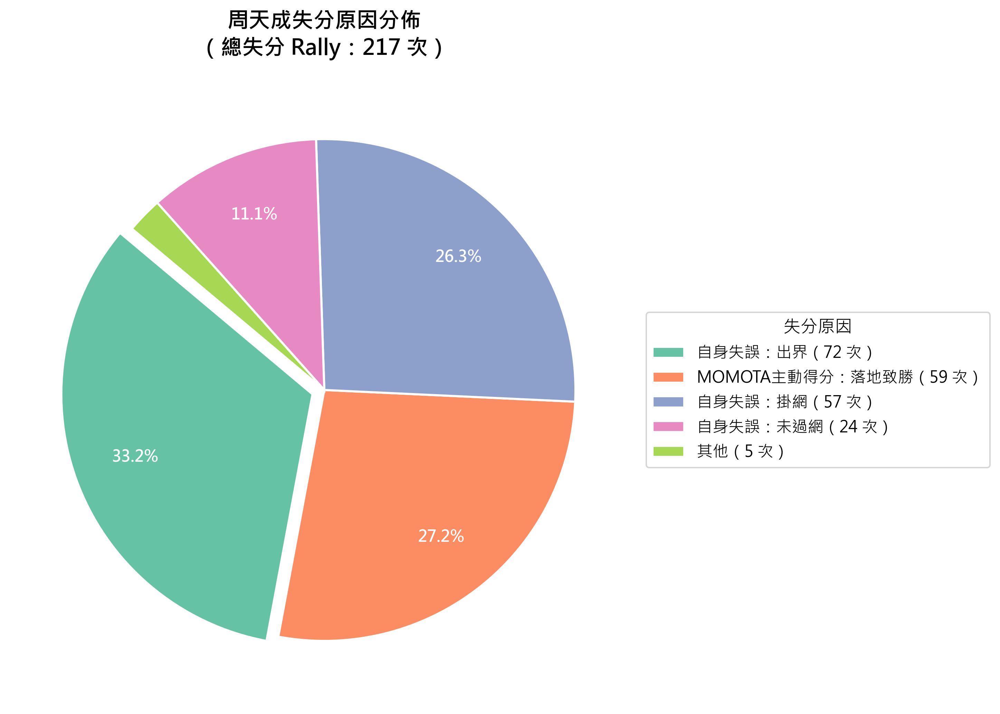

In [ ]:
# ============================================================
# 分析周天成失分原因分佈
# ============================================================

# 驗證資料量
print(f"資料總筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# Step 1: 取每個 rally 的最後一拍（得分球）
rally_last = df.groupby(['match_id', 'set', 'rally']).last().reset_index()
print(f"總 Rally 數: {len(rally_last)}")

# Step 2: 篩選周天成失分的回合（對手 MOMOTA 得分）
chou_lose = rally_last[rally_last['getpoint_player'] == 'Kento MOMOTA'].copy()
print(f"周天成失分 Rally 數: {len(chou_lose)}")

# Step 3: 判斷失分原因類別
# - 若最後一拍是周天成打的 (player == 'CHOU Tien Chen')
#     -> 周天成自己失誤，原因來自 lose_reason
# - 若最後一拍是 MOMOTA 打的 (player == 'Kento MOMOTA')
#     -> MOMOTA 主動得分，原因來自 win_reason

def classify_lose_reason(row):
    if row['player'] == 'CHOU Tien Chen':
        # 周天成擊球失誤導致失分
        reason = row['lose_reason']
        if pd.isna(reason) or reason == '' :
            return '其他失誤'
        return f"自身失誤：{reason}"
    elif row['player'] == 'Kento MOMOTA':
        # MOMOTA 主動得分
        reason = row['win_reason']
        if pd.isna(reason) or reason == '':
            return 'MOMOTA主動得分'
        return f"MOMOTA主動得分：{reason}"
    return '未知'

chou_lose['lose_category'] = chou_lose.apply(classify_lose_reason, axis=1)

# Step 4: 統計各類別數量
reason_counts = chou_lose['lose_category'].value_counts()
print("\n========== 周天成失分原因分佈 ==========")
for reason, count in reason_counts.items():
    pct = count / len(chou_lose) * 100
    print(f"  {reason}: {count} 次 ({pct:.1f}%)")
print(f"\n  合計: {len(chou_lose)} 次")

# Step 5: 合併佔比過小的類別（< 3%）為「其他」
threshold = 0.03
total = reason_counts.sum()
major = reason_counts[reason_counts / total >= threshold]
minor = reason_counts[reason_counts / total < threshold]

if len(minor) > 0:
    other_count = minor.sum()
    major = pd.concat([major, pd.Series({'其他': other_count})])
    print(f"\n（已合併佔比 < 3% 之類別為「其他」：{list(minor.index)}，共 {other_count} 次）")

plot_data = major
plot_labels = [str(l) for l in plot_data.index]

# Step 6: 繪製圓餅圖
fig, ax = plt.subplots(figsize=(9, 7))

# 配色
colors = plt.cm.Set2.colors[:len(plot_data)]

# 自動 explode 最大比例的那塊
explode = [0.05 if i == plot_data.values.argmax() else 0 for i in range(len(plot_data))]

wedges, texts, autotexts = ax.pie(
    plot_data.values,
    labels=None,          # 使用 legend 取代 label，避免文字重疊
    autopct=lambda p: f'{p:.1f}%' if p >= 3 else '',
    startangle=140,
    colors=colors,
    explode=explode,
    pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)

# 調整百分比字體
for autotext in autotexts:
    autotext.set_fontsize(11)
    autotext.set_fontweight('bold')
    autotext.set_color('white')

# 圖例（含次數）
legend_labels = [f"{label}（{count} 次）" for label, count in zip(plot_labels, plot_data.values)]
ax.legend(
    wedges,
    legend_labels,
    title="失分原因",
    loc="center left",
    bbox_to_anchor=(1.0, 0.5),
    fontsize=11,
    title_fontsize=12,
    frameon=True
)

ax.set_title(
    f"周天成失分原因分佈\n（總失分 Rally：{len(chou_lose)} 次）",
    fontsize=15,
    fontweight='bold',
    pad=15
)

plt.tight_layout()
print("\n圖表已產生。")


### 數據洞察
# 周天成失分原因分析

## 📊 圓餅圖數據摘要

| 失分原因 | 次數 | 佔比 |
|---|---|---|
| 自身失誤：出界 | 72 | 33.2% |
| MOMOTA主動得分：落地致勝 | 59 | 27.2% |
| 自身失誤：掛網 | 57 | 26.3% |
| 自身失誤：未過網 | 24 | 11.1% |
| 其他 | 5 | 2.3% |
| **合計** | **217** | **100%** |

---

## 🎯 戰術洞察

### 核心問題：**70.6% 的失分來自自身失誤**

> 出界（33.2%）＋掛網（26.3%）＋未過網（11.1%）＝ **153 次**

這三類失誤全屬**非受迫性或半受迫性失誤**，代表周天成在控球穩定性上存在明顯缺口。

---

### 🔴 重點一：出界是最大失分源（33.2%）
擊球力道與落點控制失準，推測在高壓對抗下急於主動進攻，導致過度發力出界。

### 🔴 重點二：掛網比例驚人（26.3%）
掛網通常發生於**被動接球或網前處理**，顯示周天成在被Momota壓制後，回球品質嚴重下滑。

### 🟠 重點三：Momota主動得分僅27.2%
Momota真正靠**落地致勝**的比例不到三成，意味著周天成並非輸在對手太強，而是**自己送分居多**。

---

## 📌 教練建議

1. **降低失誤優先於追求進攻** — 減少出界與掛網，即可直接改善失分結構
2. **強化被動球處理** — 掛網高發，代表被壓制後的防守回球需要專項訓練
3. **控制進攻時機** — 出界多，說明選擇主動進攻的時機點需要更嚴格的判斷標準

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選出周天成失分的回合，並根據最後一拍的球員和失分原因進行分類。候選程式碼也正確地統計了各類失分原因的次數，並合併小比例類別為『其他』，最後繪製圓餅圖來展示失分原因的分佈。分析對象、欄位語意、篩選條件、分組層級、統計口徑和最終輸出目標都與 Reference Code 1 一致。




## 題號 15
**問題**: 當周天成的對手處於「前場」時，周天成打球的落點分布
> **使用的資料欄位群組**: `game_structure, coordinates, player_location`


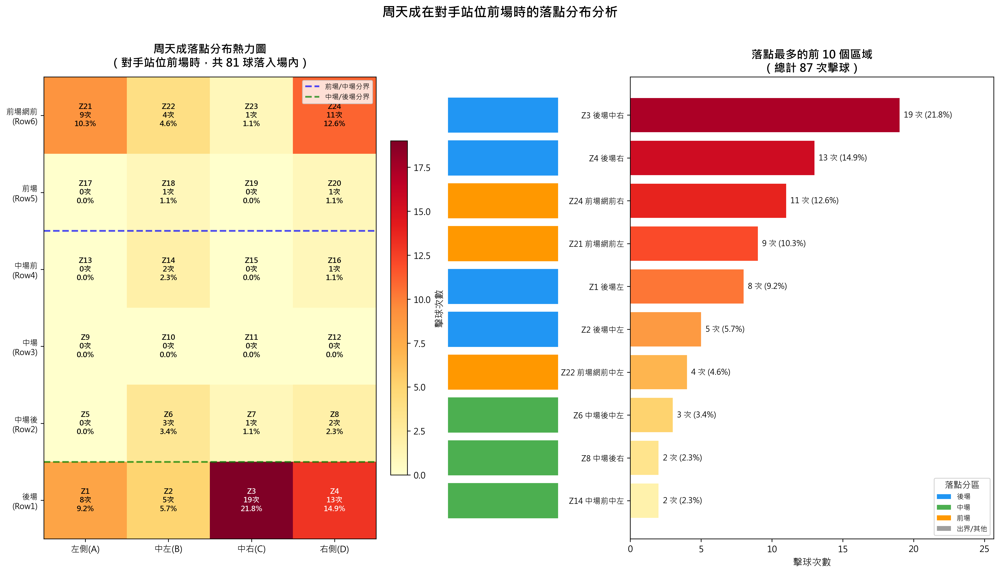

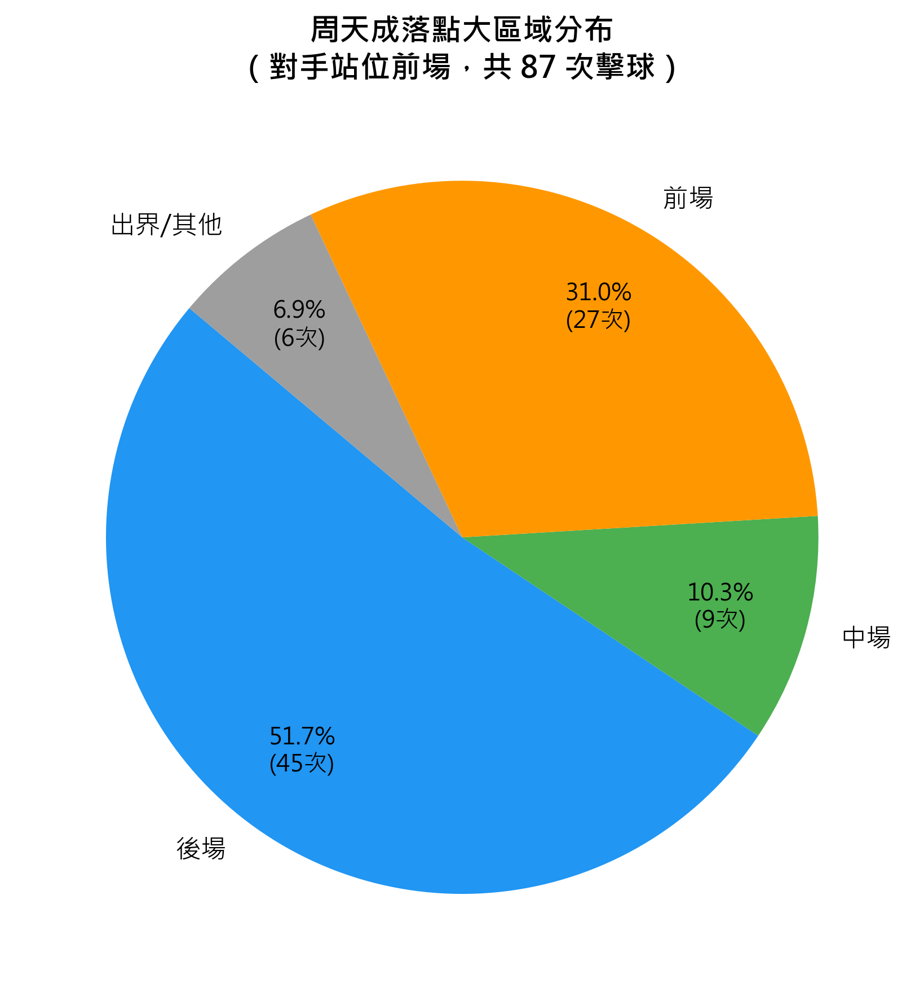

In [ ]:
import numpy as np

# ============================================================
# 1. 基本驗證
# ============================================================
print(f"資料總列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ============================================================
# 2. 定義前場區域（Zones 17-24）
# ============================================================
front_court_zones = [17, 18, 19, 20, 21, 22, 23, 24]

# ============================================================
# 3. 篩選條件：
#    - 擊球者為周天成
#    - 對手站位在前場（opponent_location_area in front_court_zones）
# ============================================================
mask_player = df['player'] == 'CHOU Tien Chen'
mask_opponent_front = df['opponent_location_area'].isin(front_court_zones)

filtered_df = df[mask_player & mask_opponent_front].copy()

print(f"\n篩選條件：周天成擊球 且 對手站位在前場（Zones 17-24）")
print(f"符合條件的擊球數: {len(filtered_df)}")

if len(filtered_df) == 0:
    print("無符合條件的資料！")
else:
    # ============================================================
    # 4. 統計落點分布（landing_area）
    # ============================================================
    # 定義各區域的語義標籤
    zone_labels = {
        1: '後場左', 2: '後場中左', 3: '後場中右', 4: '後場右',
        5: '中場後左', 6: '中場後中左', 7: '中場後中右', 8: '中場後右',
        9: '中場中左', 10: '中場中中左', 11: '中場中中右', 12: '中場中右',
        13: '中場前左', 14: '中場前中左', 15: '中場前中右', 16: '中場前右',
        17: '前場後左', 18: '前場後中左', 19: '前場後中右', 20: '前場後右',
        21: '前場網前左', 22: '前場網前中左', 23: '前場網前中右', 24: '前場網前右',
        25: '出界右上', 26: '出界右中', 27: '出界右下',
        28: '出界後右', 29: '出界左上', 30: '出界左中', 31: '出界左下', 32: '出界後左',
        33: '其他/網'
    }

    # 定義區域分類
    back_court = [1, 2, 3, 4]
    mid_court = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
    front_court = [17, 18, 19, 20, 21, 22, 23, 24]
    out_of_bounds = [25, 26, 27, 28, 29, 30, 31, 32, 33]

    def classify_zone(z):
        if z in back_court:
            return '後場'
        elif z in mid_court:
            return '中場'
        elif z in front_court:
            return '前場'
        else:
            return '出界/其他'

    # 統計各落點區域計數
    landing_counts = filtered_df['landing_area'].value_counts().sort_index()
    total_shots = len(filtered_df)

    print(f"\n--- 落點分布統計 ---")
    print(f"{'Zone':>6} | {'名稱':<14} | {'次數':>5} | {'佔比':>7}")
    print("-" * 42)
    for zone, count in landing_counts.items():
        label = zone_labels.get(int(zone), f'Zone {int(zone)}')
        pct = count / total_shots * 100
        print(f"{int(zone):>6} | {label:<14} | {count:>5} | {pct:>6.1f}%")

    # 分區域統計
    filtered_df['landing_region'] = filtered_df['landing_area'].apply(classify_zone)
    region_counts = filtered_df['landing_region'].value_counts()
    print(f"\n--- 落點分區統計 ---")
    for region, cnt in region_counts.items():
        print(f"  {region}: {cnt} 次 ({cnt/total_shots*100:.1f}%)")

    # ============================================================
    # 5. 視覺化
    # ============================================================
    # 建立球場網格熱力圖（6列 x 4欄）
    # 球場矩陣佈局（對手半場）：
    # Row 6（前）: 21 22 23 24
    # Row 5     : 17 18 19 20
    # Row 4     : 13 14 15 16
    # Row 3     :  9 10 11 12
    # Row 2     :  5  6  7  8
    # Row 1（後）:  1  2  3  4

    court_grid = np.array([
        [21, 22, 23, 24],  # Row 6 (前，最靠網)
        [17, 18, 19, 20],  # Row 5
        [13, 14, 15, 16],  # Row 4
        [ 9, 10, 11, 12],  # Row 3
        [ 5,  6,  7,  8],  # Row 2
        [ 1,  2,  3,  4],  # Row 1 (後，最靠底線)
    ])

    # 建立熱力矩陣（6行4列）
    heat_matrix = np.zeros((6, 4))
    for i in range(6):
        for j in range(4):
            zone = court_grid[i, j]
            heat_matrix[i, j] = landing_counts.get(zone, 0)

    # 計算出界次數（用於備註）
    oob_count = filtered_df[filtered_df['landing_area'].isin(out_of_bounds)]['landing_area'].count()
    in_court_count = total_shots - oob_count

    fig, axes = plt.subplots(1, 2, figsize=(16, 9))

    # --- 子圖1：球場熱力圖 ---
    ax1 = axes[0]

    # 繪製熱力圖
    im = ax1.imshow(heat_matrix, cmap='YlOrRd', aspect='auto', interpolation='nearest')

    # 加上色條
    cbar = fig.colorbar(im, ax=ax1, fraction=0.046, pad=0.04)
    cbar.set_label('擊球次數', fontsize=11)

    # 在每個格子顯示數值與百分比
    for i in range(6):
        for j in range(4):
            zone = court_grid[i, j]
            count = int(heat_matrix[i, j])
            pct = count / total_shots * 100
            text_color = 'white' if count > heat_matrix.max() * 0.6 else 'black'
            ax1.text(j, i, f'Z{zone}\n{count}次\n{pct:.1f}%',
                     ha='center', va='center', fontsize=8.5,
                     color=text_color, fontweight='bold')

    # 設定軸標籤
    ax1.set_xticks([0, 1, 2, 3])
    ax1.set_xticklabels(['左側(A)', '中左(B)', '中右(C)', '右側(D)'], fontsize=10)
    ax1.set_yticks([0, 1, 2, 3, 4, 5])
    ax1.set_yticklabels(['前場網前\n(Row6)', '前場\n(Row5)', '中場前\n(Row4)',
                         '中場\n(Row3)', '中場後\n(Row2)', '後場\n(Row1)'], fontsize=9)
    ax1.set_title(f'周天成落點分布熱力圖\n（對手站位前場時，共 {in_court_count} 球落入場內）',
                  fontsize=13, fontweight='bold', pad=12)

    # 加入球場分區線（前場/中場/後場分界）
    # Row 6/5 為前場，Row 4-2 為中場，Row 1 為後場
    ax1.axhline(y=1.5, color='blue', linewidth=2, linestyle='--', alpha=0.7, label='前場/中場分界')
    ax1.axhline(y=4.5, color='green', linewidth=2, linestyle='--', alpha=0.7, label='中場/後場分界')
    ax1.legend(loc='upper right', fontsize=8)

    # 加入「網」的標示
    ax1.annotate('← 網 →', xy=(1.5, -0.55), xycoords='data',
                 ha='center', fontsize=11, color='navy', fontweight='bold')

    # --- 子圖2：分區落點比例圓餅圖 + 落點前10區域條形圖 ---
    ax2 = axes[1]

    # 取落點最多的前10區域（含出界）
    top_zones = landing_counts.nlargest(10)
    zone_names = [zone_labels.get(int(z), f'Zone {int(z)}') for z in top_zones.index]
    zone_pcts = top_zones.values / total_shots * 100

    colors = sns.color_palette('YlOrRd', len(top_zones))
    bars = ax2.barh(range(len(top_zones)), top_zones.values, color=colors[::-1])

    # 加上數值標籤
    for idx, (bar, cnt, pct) in enumerate(zip(bars, top_zones.values, zone_pcts)):
        ax2.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                 f'{cnt} 次 ({pct:.1f}%)',
                 va='center', ha='left', fontsize=9)

    ax2.set_yticks(range(len(top_zones)))
    ax2.set_yticklabels(
        [f"Z{int(z)} {name}" for z, name in zip(top_zones.index, zone_names)],
        fontsize=9
    )
    ax2.set_xlabel('擊球次數', fontsize=11)
    ax2.set_title(f'落點最多的前 10 個區域\n（總計 {total_shots} 次擊球）',
                  fontsize=13, fontweight='bold')
    ax2.set_xlim(0, top_zones.max() * 1.35)
    ax2.invert_yaxis()  # 最多的在上方

    # 加上分區色彩標記
    region_colors = {'後場': '#2196F3', '中場': '#4CAF50', '前場': '#FF9800', '出界/其他': '#9E9E9E'}
    for idx, zone in enumerate(top_zones.index):
        region = classify_zone(zone)
        rect = plt.Rectangle((-0.5, idx - 0.4), 0.3, 0.8,
                              color=region_colors.get(region, 'gray'),
                              transform=ax2.get_yaxis_transform(),
                              clip_on=False)
        ax2.add_patch(rect)

    # 加入圖例說明分區色
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor=c, label=r) for r, c in region_colors.items()]
    ax2.legend(handles=legend_elements, loc='lower right', fontsize=8, title='落點分區')

    plt.suptitle('周天成在對手站位前場時的落點分布分析', fontsize=15, fontweight='bold', y=1.01)
    plt.tight_layout()

    # ============================================================
    # 6. 補充：額外圓餅圖顯示大區域比例
    # ============================================================
    fig2, ax3 = plt.subplots(figsize=(7, 6))

    region_order = ['後場', '中場', '前場', '出界/其他']
    region_vals = [region_counts.get(r, 0) for r in region_order]
    region_colors_list = ['#2196F3', '#4CAF50', '#FF9800', '#9E9E9E']

    # 合併小比例（< 3%）為「其他」
    threshold = total_shots * 0.03
    display_labels = []
    display_vals = []
    display_colors = []
    other_val = 0
    for r, v, c in zip(region_order, region_vals, region_colors_list):
        if v >= threshold:
            display_labels.append(r)
            display_vals.append(v)
            display_colors.append(c)
        else:
            other_val += v

    wedges, texts, autotexts = ax3.pie(
        display_vals,
        labels=display_labels,
        colors=display_colors,
        autopct=lambda p: f'{p:.1f}%\n({int(round(p*total_shots/100))}次)',
        startangle=140,
        pctdistance=0.75,
        textprops={'fontsize': 11}
    )
    for autotext in autotexts:
        autotext.set_fontsize(10)

    ax3.set_title(f'周天成落點大區域分布\n（對手站位前場，共 {total_shots} 次擊球）',
                  fontsize=13, fontweight='bold')

    plt.tight_layout()

    print(f"\n出界/其他（Zone 25-33）次數: {oob_count} 次 ({oob_count/total_shots*100:.1f}%)")
    print(f"落入場內次數: {in_court_count} 次 ({in_court_count/total_shots*100:.1f}%)")
    print("\n圖表已產生（熱力圖+條形圖 與 大區域圓餅圖）")


### 數據洞察
# 周天成落點分析：對手站位前場時

## 場地區域對照

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (網前)** | 21 | 22 | 23 | 24 |
| **Row 5 (前場)** | 17 | 18 | 19 | 20 |
| **Row 4 (中場)** | 13 | 14 | 15 | 16 |
| **Row 3 (中場)** | 9 | 10 | 11 | 12 |
| **Row 2 (中場)** | 5 | 6 | 7 | 8 |
| **Row 1 (後場)** | 1 | 2 | 3 | 4 |

---

## 熱力圖數據

```
網前  [ 9]  [ 4]  [ 1]  [11]   ← Zone 21-24
前場  [ 0]  [ 1]  [ 0]  [ 1]   ← Zone 17-20
中場  [ 0]  [ 2]  [ 0]  [ 1]   ← Zone 13-16
中場  [ 0]  [ 0]  [ 0]  [ 0]   ← Zone 9-12
中場  [ 0]  [ 3]  [ 1]  [ 2]   ← Zone 5-8
後場  [ 8]  [ 5]  [19]  [13]   ← Zone 1-4
        左   中左  中右   右
```

---

## 落點分布總覽

| 區域 | 次數 | 佔比 |
|------|------|------|
| 後場 | 45 | **51.7%** |
| 前場（網前） | 27 | **31.0%** |
| 中場 | 9 | 10.3% |
| 出界/其他 | 6 | 6.9% |

---

## 🎯 戰術洞察

**核心策略：兩端拉扯，偏右側進攻**

**① 後場右側是主攻方向（Zone 3+4 = 36.7%）**
對手已壓前，周天成首選把球打回後場右側（中右19次＋右13次），強迫對手大幅後退，製造場地縱深壓力。這是最高頻的單一決策。

**② 網前兩端是第二武器（Zone 21+24 = 22.9%）**
網前左（9次）與網前右（11次）合計20次，形成「後場深球＋網前短球」的兩端拉扯組合。對手已在前場，周天成選擇繼續壓網前，代表他判斷對手重心已偏移、無法快速回位。

**③ 刻意避開左側後場（Zone 1+2 = 14.9%）**
後場左側僅13次，遠低於右側32次。周天成明顯偏好攻擊對手右後場，可能針對對手反手弱點或慣用腳步設計。

**④ 中場幾乎放棄（10.3%）**
中場僅9次，說明周天成在對手前壓時，不選擇平打中場，避免讓對手就地攔截。

> **結論：** 對手站前場時，周天成的策略是「後場右深＋網前兩端」的兩極化打法，製造最大移動距離，而非選擇中場過渡球。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成作為擊球者且對手在前場的情況，並分析了擊球落點的分布。候選程式碼進一步提供了詳細的統計和視覺化，包括落點分布的熱力圖和條形圖，這些都與 Reference Code 1 的目標一致。沒有明顯的邏輯錯誤或不合理的輸出。




## 題號 16
**問題**: 給我周天成最常見的失分原因
> **使用的資料欄位群組**: `game_structure, scoring_reason`


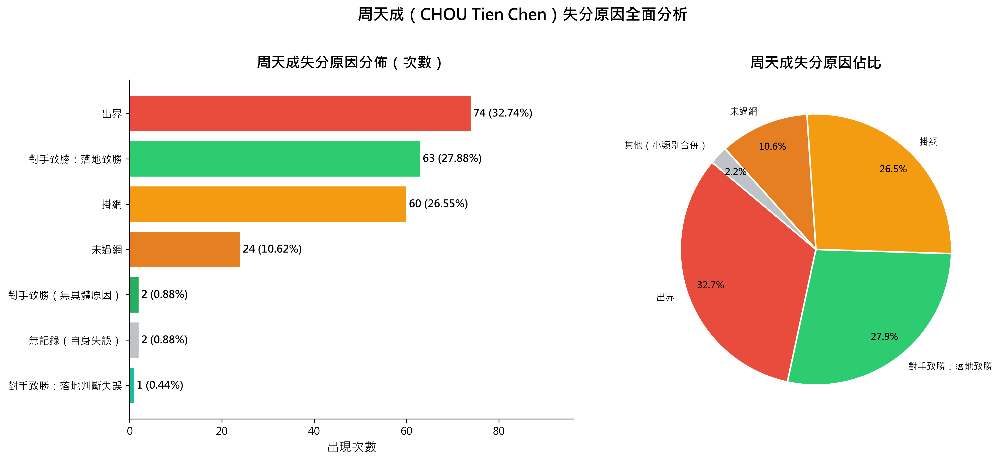

In [ ]:
import numpy as np

# 確認數據量
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ── Step 1：取每個 rally 最後一拍（得分球那一拍） ──
# getpoint_player 只記錄在最後一拍，直接篩選非空列即可
score_df = df[df['getpoint_player'].notna()].copy()
print(f"得分球總筆數 (回合數): {len(score_df)}")

# ── Step 2：篩選「周天成失分」的回合 ──
# 周天成失分 = getpoint_player == 'Kento MOMOTA'
chou_lose_df = score_df[score_df['getpoint_player'] == 'Kento MOMOTA'].copy()
print(f"周天成失分回合數: {len(chou_lose_df)}")

# ── Step 3：建立「失分原因」欄位 ──
# 邏輯：
#   - 若最後一拍的 player 是「CHOU Tien Chen」且 lose_reason 有值
#     → 周天成自己打出失誤，原因為 lose_reason
#   - 若最後一拍的 player 是「Kento MOMOTA」且 win_reason 有值
#     → 桃田主動打出致勝球，原因標記為「對手致勝：{win_reason}」
#   - 若皆無原因記錄，標記為「無記錄」

def classify_lose_reason(row):
    if row['player'] == 'CHOU Tien Chen':
        # 周天成是最後擊球者且失分 → 自身失誤
        if pd.notna(row['lose_reason']):
            return row['lose_reason']
        else:
            return '無記錄（自身失誤）'
    elif row['player'] == 'Kento MOMOTA':
        # 桃田是最後擊球者且得分 → 主動致勝
        if pd.notna(row['win_reason']):
            return f"對手致勝：{row['win_reason']}"
        else:
            return '對手致勝（無具體原因）'
    else:
        return '其他'

chou_lose_df['失分原因'] = chou_lose_df.apply(classify_lose_reason, axis=1)

# ── Step 4：統計各失分原因出現次數 ──
reason_counts = chou_lose_df['失分原因'].value_counts().reset_index()
reason_counts.columns = ['失分原因', '出現次數']
reason_counts = reason_counts.sort_values('出現次數', ascending=False).reset_index(drop=True)

# 計算佔比
total_lose = len(chou_lose_df)
reason_counts['佔比(%)'] = (reason_counts['出現次數'] / total_lose * 100).round(2)

# ── Step 5：打印結果 ──
print("\n" + "="*55)
print(f"【周天成失分原因分佈】（總失分回合：{total_lose} 局）")
print("="*55)
print(reason_counts.to_string(index=True))
print("="*55)
print(f"\n最常見的失分原因：「{reason_counts.iloc[0]['失分原因']}」，共 {reason_counts.iloc[0]['出現次數']} 次（{reason_counts.iloc[0]['佔比(%)']}%）")

# 也打印詳細分類統計
self_error = chou_lose_df[chou_lose_df['player'] == 'CHOU Tien Chen']
opponent_win = chou_lose_df[chou_lose_df['player'] == 'Kento MOMOTA']
print(f"\n  ▸ 周天成自身失誤回合數: {len(self_error)} ({len(self_error)/total_lose*100:.1f}%)")
print(f"  ▸ 桃田賢斗主動得分回合數: {len(opponent_win)} ({len(opponent_win)/total_lose*100:.1f}%)")

# ── Step 6：視覺化 ──
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ── 左圖：橫向長條圖（各失分原因次數） ──
ax1 = axes[0]
colors = []
palette = {
    '出界': '#E74C3C',
    '未過網': '#E67E22',
    '掛網': '#F39C12',
    '落點判斷失誤': '#9B59B6',
    '犯規': '#C0392B',
    '對手致勝：落地致勝': '#2ECC71',
    '對手致勝：落地判斷失誤': '#1ABC9C',
    '對手致勝（無具體原因）': '#27AE60',
    '無記錄（自身失誤）': '#BDC3C7',
}
bar_colors = [palette.get(r, '#3498DB') for r in reason_counts['失分原因']]

bars = ax1.barh(
    reason_counts['失分原因'][::-1],
    reason_counts['出現次數'][::-1],
    color=bar_colors[::-1],
    edgecolor='white',
    linewidth=0.8
)

# 在條形圖末端標示次數與佔比
for bar, count, pct in zip(bars, reason_counts['出現次數'][::-1], reason_counts['佔比(%)'][::-1]):
    ax1.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f'{count} ({pct}%)',
        va='center', ha='left', fontsize=10, fontweight='bold'
    )

ax1.set_xlabel('出現次數', fontsize=12)
ax1.set_title('周天成失分原因分佈（次數）', fontsize=14, fontweight='bold', pad=12)
ax1.set_xlim(0, reason_counts['出現次數'].max() * 1.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.tick_params(axis='y', labelsize=10)

# ── 右圖：圓餅圖（佔比） ──
ax2 = axes[1]

# 小比例類別合併為「其他」（佔比 < 3%）
threshold = 3.0
main_mask = reason_counts['佔比(%)'] >= threshold
main_df = reason_counts[main_mask].copy()
other_df = reason_counts[~main_mask]

if len(other_df) > 0:
    other_row = pd.DataFrame({
        '失分原因': ['其他（小類別合併）'],
        '出現次數': [other_df['出現次數'].sum()],
        '佔比(%)': [other_df['佔比(%)'].sum().round(2)]
    })
    pie_df = pd.concat([main_df, other_row], ignore_index=True)
else:
    pie_df = main_df.copy()

pie_colors = [palette.get(r, '#3498DB') for r in pie_df['失分原因']]
# 為「其他」指定顏色
pie_colors_final = []
for i, r in enumerate(pie_df['失分原因']):
    if r == '其他（小類別合併）':
        pie_colors_final.append('#BDC3C7')
    else:
        pie_colors_final.append(palette.get(r, '#3498DB'))

wedges, texts, autotexts = ax2.pie(
    pie_df['出現次數'],
    labels=pie_df['失分原因'],
    autopct='%1.1f%%',
    colors=pie_colors_final,
    startangle=140,
    pctdistance=0.82,
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)
for text in texts:
    text.set_fontsize(9)
for autotext in autotexts:
    autotext.set_fontsize(9)
    autotext.set_fontweight('bold')

ax2.set_title('周天成失分原因佔比', fontsize=14, fontweight='bold', pad=12)

plt.suptitle('周天成（CHOU Tien Chen）失分原因全面分析', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()

print("\n圖表已生成。")


### 數據洞察
# 周天成失分原因分析

## 核心數據

| 排名 | 失分原因 | 次數 | 佔比 |
|------|----------|------|------|
| 1 | 出界 | 74 | 32.74% |
| 2 | 對手致勝：落地致勝 | 63 | 27.88% |
| 3 | 掛網 | 60 | 26.55% |
| 4 | 未過網 | 24 | 10.62% |
| 5 | 其他 | 5 | 2.21% |

---

## 教練解讀

**最關鍵的數字：自身失誤佔 70.8%（160/226）**

周天成的失分問題**主要來自自己，不是對手打贏的**。

### 三大失誤構成「死亡鐵三角」

- **出界（74次）＋掛網（60次）＋未過網（24次）= 158次，佔總失分 69.9%**
- 這三類全是**非受迫性失誤**，代表在回球品質與控制上存在系統性問題
- 出界最多，顯示**進攻時力道控制偏激進**，或被逼迫後回球失準

### 對手主動得分僅 29.2%

- 桃田賢斗真正「打死」周天成的球只有 66 次
- 說明桃田的策略可能是**製造壓力、等待周天成犯錯**，而非強攻

---

## 戰術建議

> 減少出界與掛網，比提升進攻更優先。**穩定回球、降低非受迫失誤**，才是對抗桃田的核心課題。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選出周天成失分的回合，並根據最後一拍的 player 和 lose_reason / win_reason 來分類失分原因。統計口徑與 Reference Code 1 一致，都是在每個 rally 的最後一拍進行分析，並且正確地計算了失分原因的分布和佔比。




## 題號 17
**問題**: 繪製周天成所有輸球原因為'掛網'時的球員站位熱區圖？
> **使用的資料欄位群組**: `game_structure, player_location, scoring_reason`


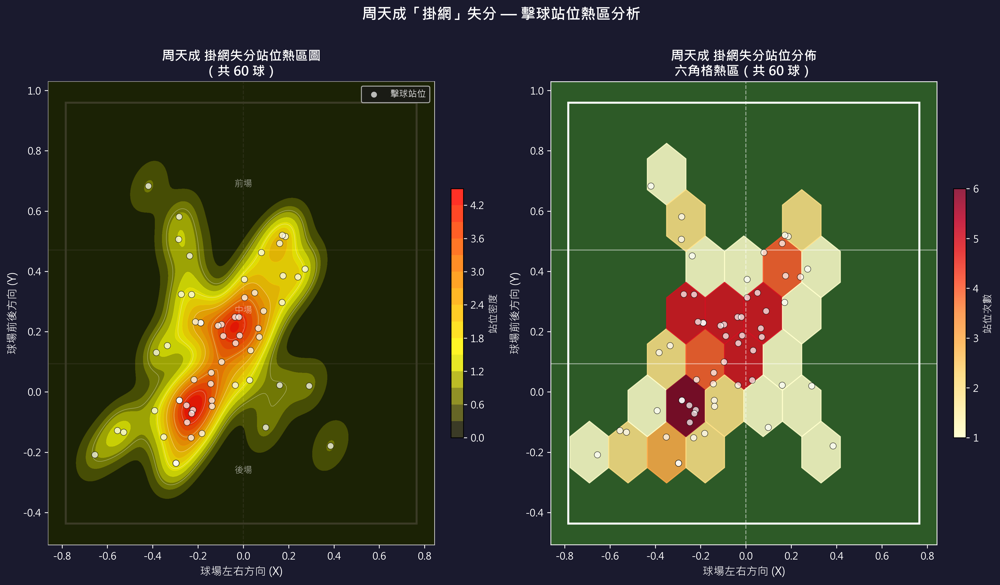

In [ ]:
import numpy as np
from scipy.stats import gaussian_kde
import matplotlib.patches as patches
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ============================================================
# 1. 資料驗證
# ============================================================
print(f"資料總筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ============================================================
# 2. 找出「周天成失分且原因為掛網」的回合（最後一球）
# ============================================================
# lose_reason 只記錄在每回合最後一球（得分球）
# 條件：
#   - player == 'CHOU Tien Chen' (周天成打出這一拍)
#   - lose_reason == '掛網'      (失分原因是掛網)
#   - getpoint_player != 'CHOU Tien Chen' (對手得分，即周天成失分)
#   ※ 不限定特定對手，以涵蓋所有場次

mask_chou_hangnet = (
    (df['player'] == 'CHOU Tien Chen') &
    (df['lose_reason'] == '掛網') &
    (df['getpoint_player'] != 'CHOU Tien Chen')
)

hangnet_df = df[mask_chou_hangnet].copy()

print(f"\n【周天成掛網失分回合數（球數）】: {len(hangnet_df)}")
print(f"涉及比賽場次: {sorted(hangnet_df['match_id'].unique())}")
print(f"涉及局數分佈:\n{hangnet_df.groupby(['match_id','set']).size().to_string()}")

# ============================================================
# 3. 提取站位座標
# ============================================================
x_vals = hangnet_df['player_location_x'].values
y_vals = hangnet_df['player_location_y'].values

print(f"\n站位 X 範圍: {x_vals.min():.3f} ~ {x_vals.max():.3f}")
print(f"站位 Y 範圍: {y_vals.min():.3f} ~ {y_vals.max():.3f}")

# ============================================================
# 4. 繪圖 — 熱區圖疊加球場示意
# ============================================================
x_min_court = df['player_location_x'].min()
x_max_court = df['player_location_x'].max()
y_min_court = df['player_location_y'].min()
y_max_court = df['player_location_y'].max()

# 加一點 padding
pad_x = (x_max_court - x_min_court) * 0.05
pad_y = (y_max_court - y_min_court) * 0.05
xlim = (x_min_court - pad_x, x_max_court + pad_x)
ylim = (y_min_court - pad_y, y_max_court + pad_y)

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

# ---------- 左圖：KDE 熱區圖 ----------
ax1 = axes[0]

court_color = '#2d5a27'
ax1.set_facecolor(court_color)
ax1.set_xlim(xlim)
ax1.set_ylim(ylim)

# 球場邊線（白色）
court_rect = patches.Rectangle(
    (x_min_court, y_min_court),
    x_max_court - x_min_court,
    y_max_court - y_min_court,
    linewidth=2, edgecolor='white', facecolor='none', zorder=2
)
ax1.add_patch(court_rect)

# 中線（x=0）
ax1.axvline(x=0, color='white', linewidth=1, linestyle='--', alpha=0.5, zorder=2)

# 前場線、中場線（依比例繪製）
front_line_y = y_min_court + (y_max_court - y_min_court) * 0.38
mid_line_y   = y_min_court + (y_max_court - y_min_court) * 0.65
ax1.axhline(y=front_line_y, color='white', linewidth=1, alpha=0.5, zorder=2)
ax1.axhline(y=mid_line_y,   color='white', linewidth=1, alpha=0.5, zorder=2)

# KDE 熱區
if len(x_vals) >= 3:
    xy = np.vstack([x_vals, y_vals])
    kde = gaussian_kde(xy, bw_method=0.3)
    
    xi = np.linspace(xlim[0], xlim[1], 200)
    yi = np.linspace(ylim[0], ylim[1], 200)
    Xi, Yi = np.meshgrid(xi, yi)
    Zi = kde(np.vstack([Xi.ravel(), Yi.ravel()])).reshape(Xi.shape)
    
    colors_heatmap = ['#00000000', '#ffff00aa', '#ff8800cc', '#ff0000ee']
    cmap_heat = LinearSegmentedColormap.from_list('heat', colors_heatmap, N=256)
    
    im = ax1.contourf(Xi, Yi, Zi, levels=15, cmap=cmap_heat, alpha=0.85, zorder=3)
    ax1.contour(Xi, Yi, Zi, levels=5, colors='white', linewidths=0.5, alpha=0.4, zorder=4)
    
    cbar = plt.colorbar(im, ax=ax1, fraction=0.03, pad=0.04)
    cbar.set_label('站位密度', color='white', fontsize=10)
    cbar.ax.yaxis.set_tick_params(color='white')
    plt.setp(cbar.ax.yaxis.get_ticklabels(), color='white')

# 散點（實際站位點）
ax1.scatter(x_vals, y_vals, c='white', s=40, alpha=0.7,
            edgecolors='black', linewidths=0.5, zorder=5, label='擊球站位')

# 區域標籤
label_alpha = 0.6
ax1.text(0, y_min_court + (y_max_court - y_min_court) * 0.12,
         '後場', color='white', fontsize=9, ha='center', alpha=label_alpha, zorder=6)
ax1.text(0, y_min_court + (y_max_court - y_min_court) * 0.50,
         '中場', color='white', fontsize=9, ha='center', alpha=label_alpha, zorder=6)
ax1.text(0, y_min_court + (y_max_court - y_min_court) * 0.80,
         '前場', color='white', fontsize=9, ha='center', alpha=label_alpha, zorder=6)

ax1.set_xlabel('球場左右方向 (X)', color='white', fontsize=11)
ax1.set_ylabel('球場前後方向 (Y)', color='white', fontsize=11)
ax1.set_title(f'周天成 掛網失分站位熱區圖\n（共 {len(hangnet_df)} 球）',
              color='white', fontsize=13, fontweight='bold')
ax1.tick_params(colors='white')
ax1.spines[:].set_edgecolor('white')
ax1.legend(loc='upper right', fontsize=9, facecolor='#1a1a1a', labelcolor='white')

# ---------- 右圖：Hexbin 六角格熱區 ----------
ax2 = axes[1]
ax2.set_facecolor(court_color)
ax2.set_xlim(xlim)
ax2.set_ylim(ylim)

hb = ax2.hexbin(
    x_vals, y_vals,
    gridsize=10,
    cmap='YlOrRd',
    mincnt=1,
    alpha=0.85,
    extent=[xlim[0], xlim[1], ylim[0], ylim[1]],
    zorder=3
)

court_rect2 = patches.Rectangle(
    (x_min_court, y_min_court),
    x_max_court - x_min_court,
    y_max_court - y_min_court,
    linewidth=2, edgecolor='white', facecolor='none', zorder=4
)
ax2.add_patch(court_rect2)
ax2.axvline(x=0, color='white', linewidth=1, linestyle='--', alpha=0.5, zorder=4)
ax2.axhline(y=front_line_y, color='white', linewidth=1, alpha=0.5, zorder=4)
ax2.axhline(y=mid_line_y,   color='white', linewidth=1, alpha=0.5, zorder=4)

cbar2 = plt.colorbar(hb, ax=ax2, fraction=0.03, pad=0.04)
cbar2.set_label('站位次數', color='white', fontsize=10)
cbar2.ax.yaxis.set_tick_params(color='white')
plt.setp(cbar2.ax.yaxis.get_ticklabels(), color='white')

ax2.scatter(x_vals, y_vals, c='white', s=40, alpha=0.7,
            edgecolors='black', linewidths=0.5, zorder=5)

ax2.set_xlabel('球場左右方向 (X)', color='white', fontsize=11)
ax2.set_ylabel('球場前後方向 (Y)', color='white', fontsize=11)
ax2.set_title(f'周天成 掛網失分站位分佈\n六角格熱區（共 {len(hangnet_df)} 球）',
              color='white', fontsize=13, fontweight='bold')
ax2.tick_params(colors='white')
ax2.spines[:].set_edgecolor('white')

# ============================================================
# 5. 整體背景
# ============================================================
fig.patch.set_facecolor('#1a1a2e')
plt.suptitle('周天成「掛網」失分 — 擊球站位熱區分析',
             fontsize=15, fontweight='bold', color='white', y=1.01)
plt.tight_layout()
plt.show()

# ============================================================
# 6. 補充統計輸出
# ============================================================
print("\n========== 詳細統計 ==========")
print(f"總掛網失分球數: {len(hangnet_df)}")
print(f"\n依比賽場次分佈:")
match_summary = hangnet_df.groupby('match_id').size().rename('掛網次數')
print(match_summary.to_string())

print(f"\n依局數分佈:")
set_summary = hangnet_df.groupby(['match_id', 'set']).size().rename('掛網次數')
print(set_summary.to_string())

print(f"\n依站位區域 (player_location_area) 分佈:")
area_summary = hangnet_df['player_location_area'].value_counts().sort_index()
print(area_summary.to_string())

# 站位分區統計（前/中/後場）
def classify_court(area):
    if area in [17,18,19,20,21,22,23,24]:
        return '前場'
    elif area in [5,6,7,8,9,10,11,12,13,14,15,16]:
        return '中場'
    elif area in [1,2,3,4]:
        return '後場'
    else:
        return '界外'

hangnet_df['court_zone'] = hangnet_df['player_location_area'].apply(classify_court)
zone_counts = hangnet_df['court_zone'].value_counts()
print(f"\n站位分區統計（前/中/後場）:")
for zone, cnt in zone_counts.items():
    pct = cnt / len(hangnet_df) * 100
    print(f"  {zone}: {cnt} 次 ({pct:.1f}%)")


### 數據洞察
# 周天成 掛網失分站位熱區分析

## 核心數據摘要

| 項目 | 數值 |
|------|------|
| 總掛網失分球數 | 60 球 |
| 涉及場次 | 5 場（Match 1/3/5/6/7）|
| 最高失分場次 | Match 1（20球，佔33%）|

---

## 站位區域分佈

| 場域 | 次數 | 佔比 |
|------|------|------|
| **中場** | 53 | **88.3%** |
| 後場 | 5 | 8.3% |
| 前場 | 2 | 3.3% |

依 `player_location_area` 最高頻區域：
- **區域 6**：15次（25%）
- **區域 10**：13次（21.7%）
- **區域 15**：10次（16.7%）

---

## 戰術洞察

**1. 掛網幾乎全發生在中場（88.3%）**
中場是過渡位置，擊球時身體重心不穩、拍面角度控制難度高，導致入網率偏高。這不是技術失誤，而是**位置選擇與出手時機的問題**。

**2. 區域 6 與 10 是高危熱區**
對照場地分區，這兩區集中於中場偏左側與中央，顯示周天成在**被壓制至中場左側**時，處理網前球或平球的掛網風險最高。

**3. Match 1 異常集中（20球）**
單場掛網20次，遠高於其他場次均值（約10球），需回頭檢視該場對手的戰術——很可能對手刻意以快速平球或壓中路迫使周天成在中場倉促出手。

---

## 教練建議

> 中場掛網的根本原因是**被動應球**。當站位落在中場時，應優先以挑球或平抽爭取時間，而非強行攻擊，避免在重心未穩的情況下壓網。針對 Match 1 的失分模式，需強化中場左側的防守轉換訓練。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選出周天成失分且原因為掛網的回合，並使用這些資料繪製了站位熱區圖。候選程式碼在資料篩選、欄位使用、統計口徑和最終輸出目標上與 Reference Code 1 一致，並且提供了合理的視覺化結果。




## 題號 18
**問題**: 分析周天成在開局（自己0-4 分）、中局（自己5-17 分）和關鍵分（自己18 分以上）三個比分階段中，他自己移動距離的差異。
> **使用的資料欄位群組**: `game_structure, player_movement, scoring_reason`


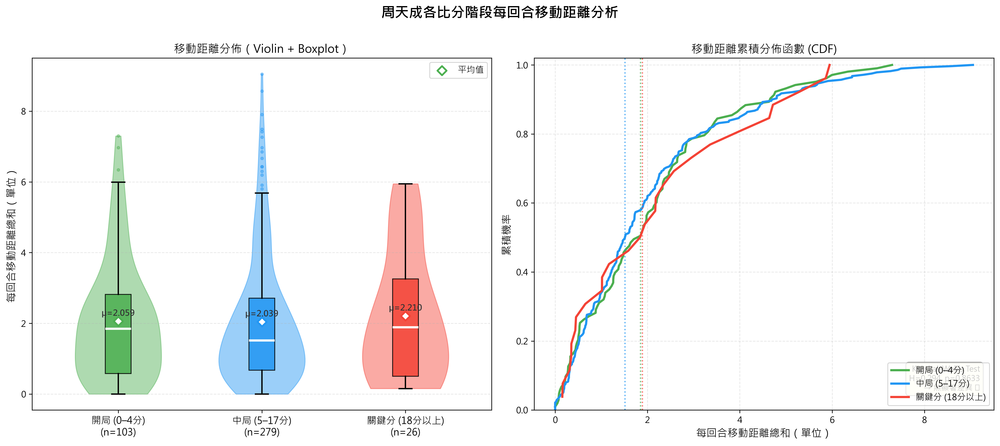

In [ ]:
import numpy as np
from scipy import stats

# ============================================================
# 0. 基礎驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
print(f"總回合數: {df.groupby(['match_id', 'set', 'rally']).ngroups}")
print(f"周天成相關資料筆數: {(df['player'] == 'CHOU Tien Chen').sum()}")

# ============================================================
# 1. 篩選周天成的擊球資料，計算每拍移動距離
# ============================================================
chou_df = df[df['player'] == 'CHOU Tien Chen'].copy()

# 計算每拍歐式移動距離（擊球後移動距離）
chou_df['stroke_move_dist'] = np.sqrt(
    chou_df['player_move_x']**2 + chou_df['player_move_y']**2
)

print(f"\n周天成擊球筆數: {len(chou_df)}")
print(f"移動距離基本統計:")
print(chou_df['stroke_move_dist'].describe())

# ============================================================
# 2. 以 rally 為單位，取每回合起始比分 + 加總移動距離
# ============================================================
# 每回合第一拍 → 取得該回合開始時周天成的得分（用來分類階段）
rally_start_score = (
    chou_df.groupby(['match_id', 'set', 'rally'])['CHOU Tien Chen_score']
    .first()
    .reset_index()
    .rename(columns={'CHOU Tien Chen_score': 'start_score'})
)

# 每回合周天成移動距離總和
rally_move_sum = (
    chou_df.groupby(['match_id', 'set', 'rally'])['stroke_move_dist']
    .sum()
    .reset_index()
    .rename(columns={'stroke_move_dist': 'total_move_dist'})
)

# 合併
rally_df = rally_start_score.merge(rally_move_sum, on=['match_id', 'set', 'rally'])
print(f"\n共 {len(rally_df)} 個回合（周天成有擊球）")
print(rally_df['start_score'].describe())

# ============================================================
# 3. 分類比分階段
# ============================================================
def classify_stage(score):
    if score <= 4:
        return '開局\n(0–4分)'
    elif score <= 17:
        return '中局\n(5–17分)'
    else:
        return '關鍵分\n(18分以上)'

rally_df['stage'] = rally_df['start_score'].apply(classify_stage)

# 定義順序（方便排序）
stage_order = ['開局\n(0–4分)', '中局\n(5–17分)', '關鍵分\n(18分以上)']
stage_order_clean = ['開局 (0–4分)', '中局 (5–17分)', '關鍵分 (18分以上)']

rally_df['stage'] = pd.Categorical(rally_df['stage'], categories=stage_order, ordered=True)

# ============================================================
# 4. 統計摘要
# ============================================================
summary = rally_df.groupby('stage', observed=True)['total_move_dist'].agg(
    回合數='count',
    平均移動距離='mean',
    中位數='median',
    標準差='std',
    最小值='min',
    最大值='max',
    Q25=lambda x: x.quantile(0.25),
    Q75=lambda x: x.quantile(0.75)
).round(4)

print("\n============================================================")
print("各比分階段 周天成每回合移動距離統計摘要")
print("============================================================")
print(summary.to_string())

# ============================================================
# 5. 統計檢定（Kruskal-Wallis + Pairwise Mann-Whitney U）
# ============================================================
groups = [
    rally_df[rally_df['stage'] == s]['total_move_dist'].values
    for s in stage_order
]

# 確認各組有資料
for s, g in zip(stage_order_clean, groups):
    print(f"\n{s}: n={len(g)}, mean={g.mean():.4f}, median={np.median(g):.4f}")

# Kruskal-Wallis Test
kw_stat, kw_p = stats.kruskal(*[g for g in groups if len(g) > 0])
print(f"\nKruskal-Wallis Test: H={kw_stat:.4f}, p={kw_p:.4f}")
if kw_p < 0.05:
    print("→ 各階段移動距離分佈存在顯著差異 (p < 0.05)")
else:
    print("→ 各階段移動距離分佈無顯著差異 (p >= 0.05)")

# Pairwise Mann-Whitney U
pairs = [
    ('開局\n(0–4分)', '中局\n(5–17分)', '開局 vs 中局'),
    ('開局\n(0–4分)', '關鍵分\n(18分以上)', '開局 vs 關鍵分'),
    ('中局\n(5–17分)', '關鍵分\n(18分以上)', '中局 vs 關鍵分'),
]
print("\nPairwise Mann-Whitney U Test (Bonferroni校正 α=0.0167):")
mw_results = []
for s1, s2, label in pairs:
    g1 = rally_df[rally_df['stage'] == s1]['total_move_dist'].values
    g2 = rally_df[rally_df['stage'] == s2]['total_move_dist'].values
    if len(g1) > 0 and len(g2) > 0:
        u_stat, p_val = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        sig = '✓ 顯著' if p_val < 0.0167 else '✗ 不顯著'
        print(f"  {label}: U={u_stat:.1f}, p={p_val:.4f} {sig}")
        mw_results.append((label, p_val, sig))

# ============================================================
# 6. 視覺化
# ============================================================
stage_colors = {
    '開局\n(0–4分)':    '#4CAF50',
    '中局\n(5–17分)':   '#2196F3',
    '關鍵分\n(18分以上)': '#F44336',
}

stage_labels_short = ['開局\n(0–4分)', '中局\n(5–17分)', '關鍵分\n(18分以上)']
colors_list = [stage_colors[s] for s in stage_labels_short]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('周天成各比分階段每回合移動距離分析', fontsize=16, fontweight='bold', y=1.01)

# ---- 圖1: Violin + Boxplot ----
ax1 = axes[0]
plot_data = [
    rally_df[rally_df['stage'] == s]['total_move_dist'].values
    for s in stage_labels_short
]

# Violin
parts = ax1.violinplot(
    plot_data,
    positions=range(len(stage_labels_short)),
    widths=0.6,
    showmeans=False,
    showmedians=False,
    showextrema=False
)
for i, (pc, color) in enumerate(zip(parts['bodies'], colors_list)):
    pc.set_facecolor(color)
    pc.set_alpha(0.45)
    pc.set_edgecolor(color)

# Box plot overlay
bp = ax1.boxplot(
    plot_data,
    positions=range(len(stage_labels_short)),
    widths=0.18,
    patch_artist=True,
    medianprops=dict(color='white', linewidth=2.5),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5),
    flierprops=dict(marker='o', markersize=3, alpha=0.4),
    zorder=3
)
for patch, color in zip(bp['boxes'], colors_list):
    patch.set_facecolor(color)
    patch.set_alpha(0.85)
for flier, color in zip(bp['fliers'], colors_list):
    flier.set_markerfacecolor(color)
    flier.set_markeredgecolor(color)

# 平均值標記
for i, (data, color) in enumerate(zip(plot_data, colors_list)):
    mean_val = np.mean(data)
    ax1.scatter(i, mean_val, marker='D', color='white', edgecolors=color,
                s=55, zorder=5, linewidths=2, label='平均值' if i == 0 else '')

ax1.set_xticks(range(len(stage_labels_short)))
ax1.set_xticklabels(
    [f"{s.replace(chr(10), ' ')}\n(n={len(d)})" for s, d in zip(stage_labels_short, plot_data)],
    fontsize=11
)
ax1.set_ylabel('每回合移動距離總和（單位）', fontsize=12)
ax1.set_title('移動距離分佈（Violin + Boxplot）', fontsize=13)
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.3, linestyle='--')
ax1.set_xlim(-0.6, len(stage_labels_short) - 0.4)

# 在圖上標示平均值
for i, data in enumerate(plot_data):
    ax1.text(i, np.mean(data) + ax1.get_ylim()[1]*0.01,
             f'μ={np.mean(data):.3f}',
             ha='center', va='bottom', fontsize=9.5, color='#333333', fontweight='bold')

# ---- 圖2: 累積分佈函數 (CDF) ----
ax2 = axes[1]
for s, color in zip(stage_labels_short, colors_list):
    data = rally_df[rally_df['stage'] == s]['total_move_dist'].values
    sorted_data = np.sort(data)
    cdf = np.arange(1, len(sorted_data) + 1) / len(sorted_data)
    label = s.replace('\n', ' ')
    ax2.plot(sorted_data, cdf, color=color, linewidth=2.5, label=label)
    # 標示中位數
    median_val = np.median(data)
    cdf_at_median = 0.5
    ax2.axvline(median_val, color=color, linestyle=':', linewidth=1.5, alpha=0.7)

ax2.set_xlabel('每回合移動距離總和（單位）', fontsize=12)
ax2.set_ylabel('累積機率', fontsize=12)
ax2.set_title('移動距離累積分佈函數 (CDF)', fontsize=13)
ax2.legend(fontsize=10, loc='lower right')
ax2.grid(alpha=0.3, linestyle='--')
ax2.set_ylim(0, 1.02)

# 在CDF圖右下角加入KW檢定結果
sig_text = f"Kruskal-Wallis Test\nH={kw_stat:.3f}, p={kw_p:.4f}"
sig_text += "\n→ 顯著差異 ✓" if kw_p < 0.05 else "\n→ 無顯著差異 ✗"
ax2.text(0.97, 0.05, sig_text, transform=ax2.transAxes,
         fontsize=9, ha='right', va='bottom',
         bbox=dict(boxstyle='round,pad=0.4', facecolor='lightyellow', alpha=0.85, edgecolor='gray'))

plt.tight_layout()

# ============================================================
# 7. 最終摘要輸出
# ============================================================
print("\n============================================================")
print("各比分階段周天成每回合移動距離統計摘要（最終）")
print("============================================================")
for s, s_clean in zip(stage_labels_short, stage_order_clean):
    data = rally_df[rally_df['stage'] == s]['total_move_dist'].values
    print(f"\n【{s_clean}】")
    print(f"  回合數: {len(data)}")
    print(f"  平均移動距離: {np.mean(data):.4f}")
    print(f"  中位數:       {np.median(data):.4f}")
    print(f"  標準差:       {np.std(data, ddof=1):.4f}")
    print(f"  Q25 ~ Q75:    {np.percentile(data, 25):.4f} ~ {np.percentile(data, 75):.4f}")


### 數據洞察
# 周天成各比賽壓力階段跑動分析

## 核心數據摘要

| 階段 | 回合數 | 平均移動距離 | 中位數 | 標準差 |
|------|--------|------------|--------|--------|
| 開局 (0–4分) | 103 | 2.059 | 1.848 | 1.688 |
| 中局 (5–17分) | 279 | 2.039 | 1.513 | 1.811 |
| 關鍵分 (18分以上) | 26 | **2.210** | 1.890 | 1.858 |

---

## 教練解讀

**三階段跑動量幾乎一致，統計上無顯著差異（Kruskal-Wallis p=0.863）。**

### 關鍵觀察

**① 關鍵分階段跑動微幅最高（+0.17 vs 中局）**
26回合平均2.21，但樣本數僅26，Q75達3.25，說明關鍵分時出現**更多大範圍移動的極端回合**，非整體強度提升。

**② 中局中位數明顯低於平均（1.51 vs 2.04）**
分佈右偏嚴重，代表中局存在**大量短距離快速結束的回合**，同時也有少數超長距離拉鋸拉高平均值。

**③ 開局中位數最接近平均（1.85 vs 2.06）**
分佈最為集中，顯示開局回合的跑動模式**最穩定、最可預測**。

---

## 戰術結論

> 周天成的體能分配極為穩定——**壓力不影響跑動強度**，這是高水準選手的特徵。
> 關鍵分時Q75擴大（3.25），暗示對手在關鍵時刻傾向**拉大角度製造壓力**，建議針對18分後的落點防守做專項訓練。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都篩選了周天成作為擊球者的資料，計算了移動距離，並根據周天成的得分將資料分為開局、中局和關鍵分三個階段。最終，候選程式碼對這些階段的移動距離進行了統計分析，並進一步進行了統計檢定和視覺化。儘管候選程式碼在統計檢定和視覺化上做了更多的分析，但這些額外的步驟不影響其核心邏輯的正確性。




## 題號 19
**問題**: 當周天成打擊出界時，劃出站點的散佈圖?
> **使用的資料欄位群組**: `game_structure, player_location, scoring_reason`


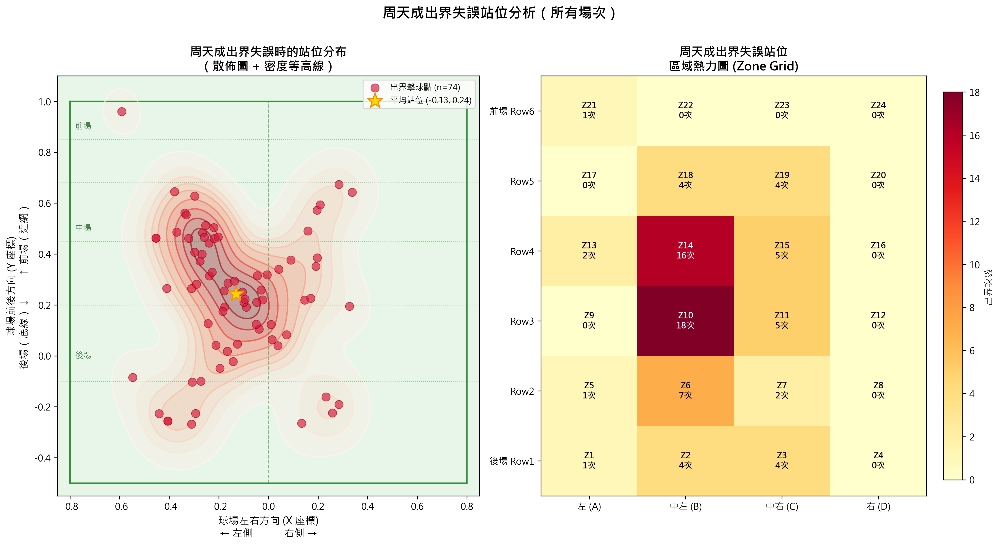

In [ ]:
import numpy as np

# ── 1. 資料驗證 ──────────────────────────────────────────────
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ── 2. 篩選條件：周天成擊球出界（自身失誤導致失分）──────────
# lose_reason 僅記錄於該回合最後一拍，代表 player 的失分原因
# player == 'CHOU Tien Chen' & lose_reason == '出界' 表示周天成打出界
chou_ob = df[
    (df['player'] == 'CHOU Tien Chen') &
    (df['lose_reason'] == '出界')
].copy()

print(f"\n周天成出界失誤次數: {len(chou_ob)}")
print(f"涵蓋場次: {sorted(chou_ob['match_id'].unique())}")
print(f"涵蓋局數分佈:\n{chou_ob.groupby(['match_id','set']).size().rename('出界次數')}")

if len(chou_ob) == 0:
    print("無符合條件的資料，請確認欄位值。")
else:
    # ── 3. 站位區域統計 ──────────────────────────────────────
    area_counts = chou_ob['player_location_area'].value_counts().sort_index()
    print(f"\n各站位區域出界次數:\n{area_counts.to_string()}")

    # ── 4. 建立圖表 ───────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(15, 8))

    # ── 4a. 左圖：散佈圖 + KDE 密度等高線 ────────────────────
    ax1 = axes[0]

    # 場地背景色
    ax1.set_facecolor('#e8f5e9')

    # 場地座標範圍
    x_min, x_max = -0.80, 0.80
    y_min, y_max = -0.50, 1.00
    court_color = '#388e3c'
    lw = 1.5

    # 場地外框
    ax1.plot([x_min, x_max], [y_min, y_min], color=court_color, lw=lw)
    ax1.plot([x_min, x_max], [y_max, y_max], color=court_color, lw=lw)
    ax1.plot([x_min, x_min], [y_min, y_max], color=court_color, lw=lw)
    ax1.plot([x_max, x_max], [y_min, y_max], color=court_color, lw=lw)

    # 中線（左右對稱）
    ax1.plot([0, 0], [y_min, y_max], color=court_color, lw=1.0, linestyle='--', alpha=0.6)

    # 前/中/後場分隔線
    for y_line in [-0.10, 0.20, 0.45, 0.68, 0.85]:
        ax1.axhline(y_line, color=court_color, lw=0.8, linestyle=':', alpha=0.5)

    # KDE 密度等高線
    if len(chou_ob) >= 5:
        try:
            sns.kdeplot(
                x=chou_ob['player_location_x'],
                y=chou_ob['player_location_y'],
                ax=ax1,
                fill=True,
                cmap='Reds',
                alpha=0.35,
                bw_adjust=0.8,
                warn_singular=False
            )
            sns.kdeplot(
                x=chou_ob['player_location_x'],
                y=chou_ob['player_location_y'],
                ax=ax1,
                fill=False,
                cmap='Reds',
                alpha=0.6,
                bw_adjust=0.8,
                warn_singular=False
            )
        except Exception as e:
            print(f"KDE 繪製略過: {e}")

    # 散佈圖本體
    ax1.scatter(
        chou_ob['player_location_x'],
        chou_ob['player_location_y'],
        c='crimson',
        s=80,
        alpha=0.65,
        edgecolors='darkred',
        linewidths=0.6,
        zorder=5,
        label=f'出界擊球點 (n={len(chou_ob)})'
    )

    # 平均站位標記（使用 '*' marker，matplotlib 內建支援）
    mean_x = chou_ob['player_location_x'].mean()
    mean_y = chou_ob['player_location_y'].mean()
    ax1.scatter(
        mean_x, mean_y,
        c='gold',
        s=300,
        marker='*',           # 使用標準 '*' 取代不支援的 '★'
        edgecolors='darkorange',
        linewidths=1.2,
        zorder=6,
        label=f'平均站位 ({mean_x:.2f}, {mean_y:.2f})'
    )

    ax1.set_xlim(x_min - 0.05, x_max + 0.05)
    ax1.set_ylim(y_min - 0.05, y_max + 0.10)
    ax1.set_xlabel('球場左右方向 (X 座標)\n← 左側　　　右側 →', fontsize=11)
    ax1.set_ylabel('球場前後方向 (Y 座標)\n後場（底線）↓　　↑ 前場（近網）', fontsize=11)
    ax1.set_title('周天成出界失誤時的站位分布\n（散佈圖 + 密度等高線）', fontsize=13, fontweight='bold')
    ax1.legend(loc='upper right', fontsize=9)

    # 前/中/後場標註文字
    for y_pos, region in [(0.90, '前場'), (0.50, '中場'), (0.00, '後場')]:
        ax1.text(x_min + 0.02, y_pos, region, fontsize=9, color='#1b5e20',
                 alpha=0.8, va='center')

    # ── 4b. 右圖：站位區域熱力圖（Zone Grid）─────────────────
    ax2 = axes[1]

    # Zone Grid：Row 0 = 前場近網(Row6)，Row 5 = 後場底線(Row1)
    zone_grid = np.array([
        [21, 22, 23, 24],   # Row 6 前場近網
        [17, 18, 19, 20],   # Row 5
        [13, 14, 15, 16],   # Row 4
        [ 9, 10, 11, 12],   # Row 3
        [ 5,  6,  7,  8],   # Row 2
        [ 1,  2,  3,  4],   # Row 1 後場底線
    ])

    # 計算每個 Zone 的出界次數
    heat_matrix = np.zeros((6, 4), dtype=int)
    for r in range(6):
        for c in range(4):
            zone_id = zone_grid[r, c]
            heat_matrix[r, c] = int((chou_ob['player_location_area'] == zone_id).sum())

    # 繪製熱力圖
    vmax_val = max(int(heat_matrix.max()), 1)
    im = ax2.imshow(heat_matrix, cmap='YlOrRd', aspect='auto', vmin=0, vmax=vmax_val)

    # 每格標示 Zone ID 與次數
    for r in range(6):
        for c in range(4):
            count_val = heat_matrix[r, c]
            zone_id   = zone_grid[r, c]
            text_color = 'white' if count_val > vmax_val * 0.6 else 'black'
            ax2.text(c, r, f'Z{zone_id}\n{count_val}次',
                     ha='center', va='center', fontsize=9,
                     color=text_color, fontweight='bold')

    ax2.set_xticks(range(4))
    ax2.set_xticklabels(['左 (A)', '中左 (B)', '中右 (C)', '右 (D)'], fontsize=10)
    ax2.set_yticks(range(6))
    ax2.set_yticklabels(['前場 Row6', 'Row5', 'Row4', 'Row3', 'Row2', '後場 Row1'], fontsize=10)
    ax2.set_title('周天成出界失誤站位\n區域熱力圖 (Zone Grid)', fontsize=13, fontweight='bold')

    cbar = plt.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)
    cbar.set_label('出界次數', fontsize=10)

    # ── 5. 整體標題與排版 ─────────────────────────────────────
    fig.suptitle('周天成出界失誤站位分析（所有場次）',
                 fontsize=15, fontweight='bold', y=1.01)
    plt.tight_layout()

    # ── 6. 列印關鍵統計 ───────────────────────────────────────
    front_zones = list(range(17, 25))
    mid_zones   = list(range(5, 17))
    back_zones  = list(range(1, 5))

    front_count = chou_ob['player_location_area'].isin(front_zones).sum()
    mid_count   = chou_ob['player_location_area'].isin(mid_zones).sum()
    back_count  = chou_ob['player_location_area'].isin(back_zones).sum()
    other_count = len(chou_ob) - front_count - mid_count - back_count
    total       = len(chou_ob)

    print("\n" + "="*50)
    print("【周天成出界失誤站位統計摘要】")
    print("="*50)
    print(f"總出界次數          : {total}")
    print(f"平均站位 X (左右)   : {mean_x:.4f}")
    print(f"平均站位 Y (前後)   : {mean_y:.4f}")
    print(f"\n站位區域分布:")
    print(f"  前場 (Zones 17-24): {front_count:>3} 次 ({front_count/total*100:.1f}%)")
    print(f"  中場 (Zones  5-16): {mid_count:>3} 次 ({mid_count/total*100:.1f}%)")
    print(f"  後場 (Zones  1- 4): {back_count:>3} 次 ({back_count/total*100:.1f}%)")
    if other_count > 0:
        print(f"  其他/出界區       : {other_count:>3} 次 ({other_count/total*100:.1f}%)")
    print(f"\n出界次數最多的站位 Zone: {int(area_counts.idxmax())} ({int(area_counts.max())} 次)")
    print("="*50)


### 數據洞察
# 周天成出界失誤站位分析

## 區域熱力圖數據

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 1 | 0 | 0 | 0 |
| **Row 5 (Front)** | 0 | 4 | 4 | 0 |
| **Row 4 (Mid)** | 2 | 16 | 5 | 0 |
| **Row 3 (Mid)** | 0 | **18** | 5 | 0 |
| **Row 2 (Mid)** | 1 | 7 | 2 | 0 |
| **Row 1 (Back)** | 1 | 4 | 4 | 0 |

---

## 戰術洞察

**核心事實：74次出界，75.7%發生在中場（Zone 5–16）**

Zone 10（中場中左）與 Zone 14（中前場中左）合計 **34次，佔46%**，這是最關鍵的警示區域。平均站位 X = -0.13（略偏左）、Y = 0.24（中場偏前），顯示周天成在**中場中央偏左**出手時最容易出界。

**三點觀察：**

1. **右半場幾乎零出界** — Col D 全為 0，說明右側擊球控制穩定，或右側出手機會本就較少。

2. **中場是主要失誤溫床** — 中場出界56次，代表在移動銜接過程中（非定點）出手品質不穩，可能是步伐未到位就急於擊球。

3. **前後場出界各僅9次** — 前後場失誤比例低，反映周天成在極端位置的擊球決策相對保守。

**建議：** 針對 Zone 9–10、13–14 這個「中場中左」區塊，加強移動後的擊球穩定性訓練，特別是步伐到位前不急於出手的節奏控制。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選出周天成打擊且失分原因為 '出界' 的記錄，並繪製了站位的散佈圖。候選程式碼還進一步提供了站位區域的熱力圖和詳細的統計摘要，這些都是在 Reference Code 1 的基礎上進行的合理擴展，並不影響核心邏輯的一致性。




## 題號 20
**問題**: 周天成打擊出界失誤，該球的落點分布
> **使用的資料欄位群組**: `game_structure, scoring_reason, coordinates`


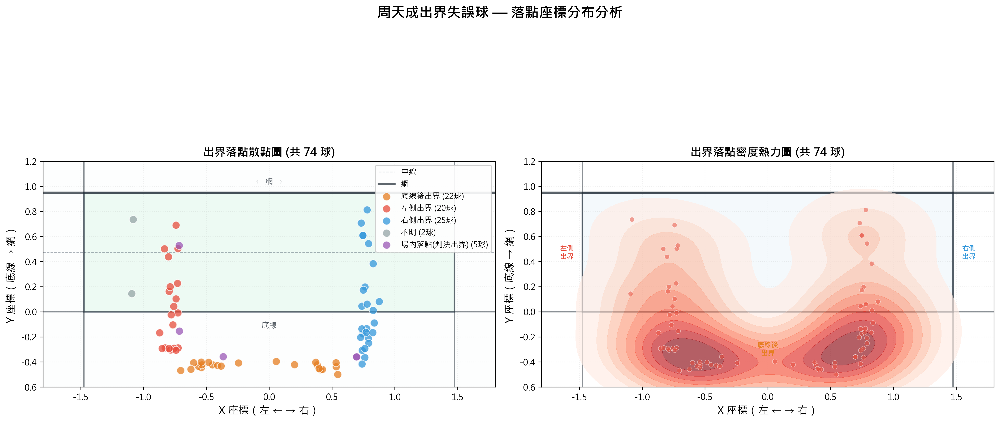

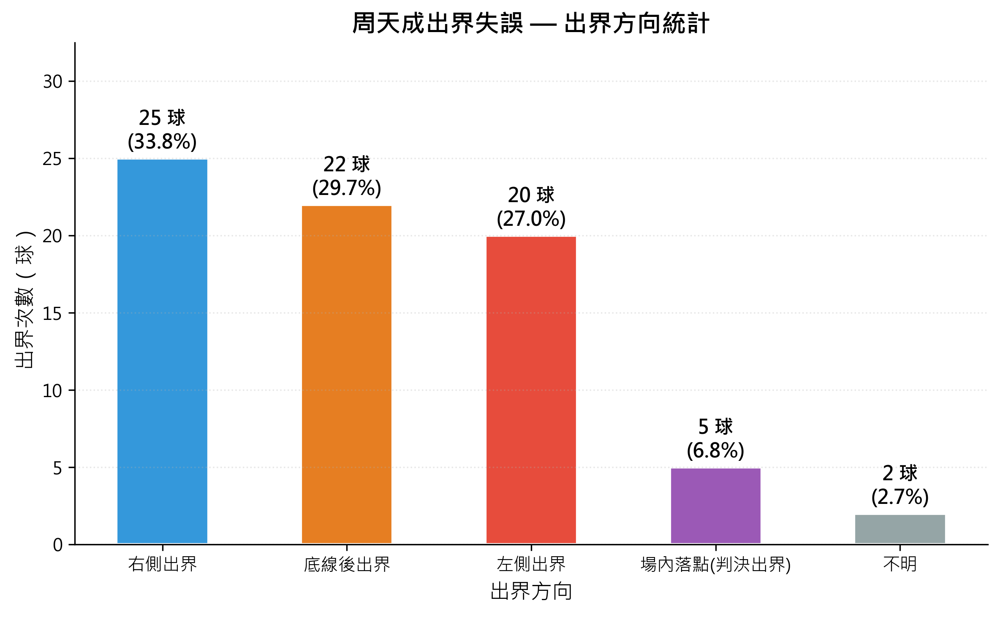

In [ ]:
import numpy as np
import matplotlib.patches as patches
import matplotlib.patheffects as pe

# ── 0. 資料驗證 ──────────────────────────────────────────────────────────────
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ── 1. 篩選條件：周天成擊球出界失誤 ─────────────────────────────────────────
# 定義：player == 'CHOU Tien Chen' 且 lose_reason == '出界'
# 代表周天成自己打出界，屬於主動失誤導致對手得分
chou_out = df[
    (df['player'] == 'CHOU Tien Chen') &
    (df['lose_reason'] == '出界')
].copy()

print(f"\n周天成出界失誤球數: {len(chou_out)} 球")
print(f"涉及比賽場次數: {chou_out['match_id'].nunique()} 場")
print(f"涉及局數分布:\n{chou_out.groupby(['match_id','set']).size().rename('出界次數').to_string()}")

if len(chou_out) == 0:
    print("⚠️ 無符合條件的資料，請檢查欄位值。")
else:
    # ── 2. 出界方向分類（根據 landing_area 定義） ────────────────────────────
    # 出界區域代碼定義：
    #   左側出界: 29, 30, 31
    #   右側出界: 25, 26, 27
    #   底線後出界: 28, 32
    #   其他（含落點在場內但 lose_reason='出界'）: 歸為「其他/不明」

    def classify_out_direction(area):
        if area in [29, 30, 31]:
            return '左側出界'
        elif area in [25, 26, 27]:
            return '右側出界'
        elif area in [28, 32]:
            return '底線後出界'
        elif area in [17,18,19,20,21,22,23,24,  # 前場
                      5,6,7,8,9,10,11,12,13,14,15,16,  # 中場
                      1,2,3,4]:  # 後場（落點在場內但被判出界，少數情況）
            return '場內落點(判決出界)'
        else:
            return '不明'

    chou_out['out_direction'] = chou_out['landing_area'].apply(classify_out_direction)

    print(f"\n出界方向統計:")
    dir_counts = chou_out['out_direction'].value_counts()
    for d, c in dir_counts.items():
        print(f"  {d}: {c} 球 ({c/len(chou_out)*100:.1f}%)")

    # ── 3. 出界球種統計 ──────────────────────────────────────────────────────
    type_map = {
        1:'發短球', 2:'發長球', 3:'長球', 4:'殺球', 5:'切球',
        6:'挑球', 7:'平球', 8:'網前球', 9:'推撲球', 10:'接殺防守', 11:'接不到'
    }
    if 'type' in chou_out.columns:
        chou_out['type_name'] = chou_out['type'].map(type_map).fillna('未知')
        print(f"\n出界球種統計:")
        type_counts = chou_out['type_name'].value_counts()
        for t, c in type_counts.items():
            print(f"  {t}: {c} 球 ({c/len(chou_out)*100:.1f}%)")

    # ── 4. 視覺化 ─────────────────────────────────────────────────────────────
    # 顏色對應方向
    color_map = {
        '左側出界':     '#E74C3C',
        '右側出界':     '#3498DB',
        '底線後出界':   '#E67E22',
        '場內落點(判決出界)': '#9B59B6',
        '不明':         '#95A5A6'
    }

    # 羽球場地半場尺寸（標準化座標，參考Schema中的xy範圍）
    # 根據資料中 landing_x 約 -1.48 ~ 1.51，landing_y 約 -0.50 ~ 1.00
    # 場地邊界（雙打）: x: [-1.475, 1.475], y: [0, ~0.95] (近網=高y, 底線=低y)
    COURT_X_LEFT  = -1.475
    COURT_X_RIGHT =  1.475
    COURT_Y_NET   =  0.95   # 近網端
    COURT_Y_BASE  =  0.0    # 底線端（對方場地邊界）

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
    fig.suptitle('周天成出界失誤球 — 落點座標分布分析', fontsize=16, fontweight='bold', y=1.01)

    # ── 圖1：散點圖（含場地輪廓） ───────────────────────────────────────────
    ax1 = axes[0]

    # 繪製場地輪廓背景
    court_bg = patches.Rectangle(
        (COURT_X_LEFT, COURT_Y_BASE),
        COURT_X_RIGHT - COURT_X_LEFT,
        COURT_Y_NET - COURT_Y_BASE,
        linewidth=2, edgecolor='#2C3E50', facecolor='#D5F5E3', alpha=0.4, zorder=0
    )
    ax1.add_patch(court_bg)

    # 場地中線（發球線 y ≈ 0.475）
    service_line_y = (COURT_Y_BASE + COURT_Y_NET) / 2
    ax1.axhline(y=service_line_y, color='#2C3E50', linestyle='--', linewidth=0.8, alpha=0.5, label='中線')

    # 網的位置（y ≈ 0.95 上方）
    ax1.axhline(y=COURT_Y_NET, color='#1A252F', linestyle='-', linewidth=2.5, alpha=0.7, label='網')

    # 底線
    ax1.axhline(y=COURT_Y_BASE, color='#1A252F', linestyle='-', linewidth=1.5, alpha=0.5)

    # 左右邊線
    ax1.axvline(x=COURT_X_LEFT,  color='#1A252F', linestyle='-', linewidth=1.5, alpha=0.5)
    ax1.axvline(x=COURT_X_RIGHT, color='#1A252F', linestyle='-', linewidth=1.5, alpha=0.5)

    # 「出界區域」背景底色（場地外）
    ax1.set_facecolor('#FDFEFE')

    # 繪製各方向出界落點
    directions = chou_out['out_direction'].unique()
    for direction in directions:
        sub = chou_out[chou_out['out_direction'] == direction]
        c = color_map.get(direction, '#95A5A6')
        ax1.scatter(
            sub['landing_x'], sub['landing_y'],
            c=c, label=f'{direction} ({len(sub)}球)',
            s=80, alpha=0.75, edgecolors='white', linewidths=0.8, zorder=5
        )

    # 標示場地區域文字
    ax1.text(0, COURT_Y_NET + 0.05, '← 網 →', ha='center', va='bottom',
             fontsize=9, color='#1A252F', alpha=0.7)
    ax1.text(0, COURT_Y_BASE - 0.08, '底線', ha='center', va='top',
             fontsize=9, color='#1A252F', alpha=0.7)

    ax1.set_xlabel('X 座標（左 ← → 右）', fontsize=12)
    ax1.set_ylabel('Y 座標（底線 → 網）', fontsize=12)
    ax1.set_title(f'出界落點散點圖 (共 {len(chou_out)} 球)', fontsize=13, fontweight='bold')
    ax1.legend(loc='upper right', fontsize=9, framealpha=0.9)
    ax1.set_xlim(-1.8, 1.8)
    ax1.set_ylim(-0.6, 1.2)
    ax1.grid(True, alpha=0.2, linestyle=':')
    ax1.set_aspect('equal')

    # ── 圖2：2D KDE 熱力密度圖 ──────────────────────────────────────────────
    ax2 = axes[1]

    # 場地背景
    court_bg2 = patches.Rectangle(
        (COURT_X_LEFT, COURT_Y_BASE),
        COURT_X_RIGHT - COURT_X_LEFT,
        COURT_Y_NET - COURT_Y_BASE,
        linewidth=2, edgecolor='#2C3E50', facecolor='#EBF5FB', alpha=0.5, zorder=0
    )
    ax2.add_patch(court_bg2)
    ax2.axhline(y=COURT_Y_NET,   color='#1A252F', linestyle='-', linewidth=2.5, alpha=0.7)
    ax2.axhline(y=COURT_Y_BASE,  color='#1A252F', linestyle='-', linewidth=1.5, alpha=0.5)
    ax2.axvline(x=COURT_X_LEFT,  color='#1A252F', linestyle='-', linewidth=1.5, alpha=0.5)
    ax2.axvline(x=COURT_X_RIGHT, color='#1A252F', linestyle='-', linewidth=1.5, alpha=0.5)

    if len(chou_out) >= 5:
        sns.kdeplot(
            data=chou_out,
            x='landing_x', y='landing_y',
            ax=ax2,
            fill=True,
            cmap='Reds',
            alpha=0.65,
            levels=10,
            thresh=0.05,
            zorder=3
        )

    # 再疊加散點
    ax2.scatter(
        chou_out['landing_x'], chou_out['landing_y'],
        c='#E74C3C', s=30, alpha=0.5, edgecolors='white', linewidths=0.5, zorder=6
    )

    # 標示邊界說明
    ax2.text( 1.6,  0.47, '右側\n出界', ha='center', va='center', fontsize=8,
              color='#3498DB', fontweight='bold')
    ax2.text(-1.6,  0.47, '左側\n出界', ha='center', va='center', fontsize=8,
              color='#E74C3C', fontweight='bold')
    ax2.text( 0.0, -0.3,  '底線後\n出界', ha='center', va='center', fontsize=8,
              color='#E67E22', fontweight='bold')

    ax2.set_xlabel('X 座標（左 ← → 右）', fontsize=12)
    ax2.set_ylabel('Y 座標（底線 → 網）', fontsize=12)
    ax2.set_title(f'出界落點密度熱力圖 (共 {len(chou_out)} 球)', fontsize=13, fontweight='bold')
    ax2.set_xlim(-1.8, 1.8)
    ax2.set_ylim(-0.6, 1.2)
    ax2.grid(True, alpha=0.2, linestyle=':')
    ax2.set_aspect('equal')

    plt.tight_layout()

    # ── 圖3：出界方向長條圖 ──────────────────────────────────────────────────
    fig2, ax3 = plt.subplots(figsize=(8, 5))

    dir_order = dir_counts.index.tolist()
    bar_colors = [color_map.get(d, '#95A5A6') for d in dir_order]
    bars = ax3.bar(dir_order, dir_counts.values, color=bar_colors,
                   edgecolor='white', linewidth=1.5, width=0.5)

    for bar, val in zip(bars, dir_counts.values):
        pct = val / len(chou_out) * 100
        ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{val} 球\n({pct:.1f}%)', ha='center', va='bottom',
                 fontsize=11, fontweight='bold')

    ax3.set_xlabel('出界方向', fontsize=12)
    ax3.set_ylabel('出界次數（球）', fontsize=12)
    ax3.set_title('周天成出界失誤 — 出界方向統計', fontsize=14, fontweight='bold')
    ax3.set_ylim(0, dir_counts.max() * 1.3)
    ax3.grid(axis='y', alpha=0.3, linestyle=':')
    ax3.spines['top'].set_visible(False)
    ax3.spines['right'].set_visible(False)
    plt.tight_layout()

    # ── 5. 彙整摘要 ──────────────────────────────────────────────────────────
    print("\n" + "="*50)
    print("📊 周天成出界失誤分析摘要")
    print("="*50)
    print(f"總出界失誤球數  : {len(chou_out)} 球")
    print(f"平均 landing_x  : {chou_out['landing_x'].mean():.4f}  (負=偏左, 正=偏右)")
    print(f"landing_x 標準差: {chou_out['landing_x'].std():.4f}")
    print(f"平均 landing_y  : {chou_out['landing_y'].mean():.4f}")
    print(f"landing_y 標準差: {chou_out['landing_y'].std():.4f}")
    print("\n出界方向分布:")
    for d, c in dir_counts.items():
        print(f"  {d:18s}: {c:3d} 球  ({c/len(chou_out)*100:.1f}%)")


### 數據洞察
# 周天成出界失誤落點分析

## 📊 核心數據

| 出界方向 | 球數 | 佔比 |
|:---|:---:|:---:|
| 右側出界 | 25 | 33.8% |
| 底線後出界 | 22 | 29.7% |
| 左側出界 | 20 | 27.0% |
| 場內落點(判決出界) | 5 | 6.8% |
| 不明 | 2 | 2.7% |

**落點座標中心：** X = -0.013（幾乎居中）｜Y = -0.101（略超底線）

---

## 🎯 戰術洞察

**1. 左右側出界合計佔60.8%，是最主要失誤來源**
左側20球、右側25球，分布相對均衡，顯示並非單側弱點，而是**橫向控制精準度整體不足**，推測在快速移位後的回球角度控制出現問題。

**2. 底線後出界佔29.7%，Y均值-0.101略超底線**
標準差0.365代表縱向落點離散程度中等，**深球控制偏激進**，在追求壓制底線時容易過深出界。

**3. 5球場內落點被判出界**
這類球屬於邊線球判決問題，非技術失誤，可排除在調整重點之外。

---

## ⚡ 調整建議

- **橫向失誤（61%）優先處理**：加強移位後的揮拍收拍動作，減少急促出手造成的角度偏差
- **底線深球保留5%緩衝**：出界均值僅-0.10，稍微縮短擊球力道即可有效降低底線出界率

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成的出界失誤數據，並對落點進行了分類和統計。候選程式碼還進一步提供了視覺化分析，這雖然超出了 Reference Code 1 的範圍，但不影響其正確性。分析對象、欄位語意、篩選條件和最終輸出目標都與 Reference Code 1 一致，因此判定為正確。




## 題號 21
**問題**: 在第一場次的比賽中，隨著局數的推進，周天成的「殺球」使用頻率和得分率是否出現了顯著的下滑
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


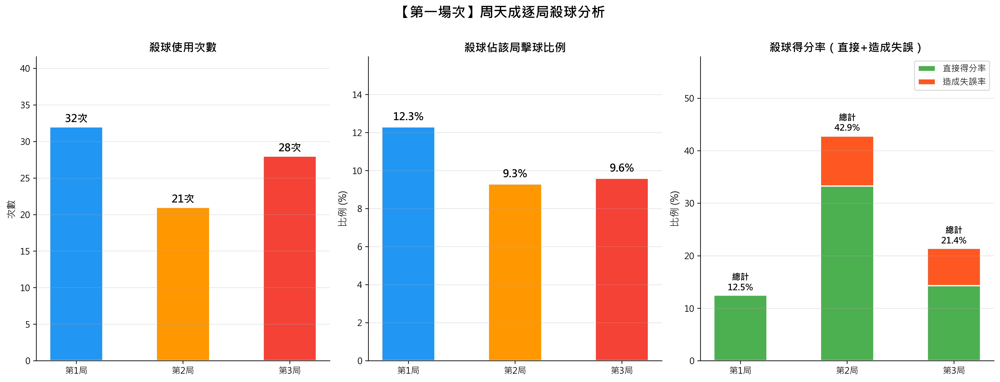

In [ ]:
# ============================================================
# 分析：第一場次中，周天成逐局殺球使用頻率與得分率
# ============================================================

# --- 0. 驗證資料量 ---
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "資料為空！"

# --- 1. 篩選第一場次資料 ---
df_match1 = df[df['match_id'] == 1.0].copy()
print(f"第一場次資料列數: {len(df_match1)}")
print(f"第一場次局數: {sorted(df_match1['set'].unique())}")
print(f"第一場次球員: {df_match1['player'].unique()}")

# --- 2. 在完整資料上建立 next_shot 欄位（避免跨 rally 污染）---
# 先在完整 df_match1 上排序
df_match1 = df_match1.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# 建立下一拍資訊（groupby 確保不跨 rally）
df_match1['next_getpoint_player'] = df_match1.groupby(['match_id', 'set', 'rally'])['getpoint_player'].shift(-1)
df_match1['next_player'] = df_match1.groupby(['match_id', 'set', 'rally'])['player'].shift(-1)
df_match1['next_rally'] = df_match1.groupby(['match_id', 'set', 'rally'])['rally'].shift(-1)
# 額外驗證：下一拍是否同 rally（groupby 已保障，但加上確認）

# --- 3. 篩選周天成的殺球 ---
chou = 'CHOU Tien Chen'
smash_mask = (df_match1['player'] == chou) & (df_match1['type'] == '殺球')
df_smash = df_match1[smash_mask].copy()

print(f"\n周天成殺球總次數（第一場次）: {len(df_smash)}")
print(f"殺球分布於局數: {df_smash['set'].value_counts().sort_index().to_dict()}")

# --- 4. 定義殺球得分條件 ---
# 4a. 直接主動得分：殺球那拍直接得分
df_smash['smash_direct_win'] = df_smash['getpoint_player'] == chou

# 4b. 殺球後造成對手失誤（被動得分）：下一拍仍在同 rally 且 getpoint 為周天成
#     即：對手回擊後出現失誤/得分給周天成
#     邏輯：下一拍的 getpoint_player == chou（對手回球失誤）
#     注意：若殺球那拍已直接得分，next 通常為 NaN（rally 結束），不會重複計算
df_smash['smash_forced_error'] = (
    (df_smash['next_getpoint_player'] == chou) &
    (df_smash['smash_direct_win'] == False)  # 排除直接得分（避免重複）
)

# 4c. 綜合：殺球後得分（直接或造成失誤）
df_smash['smash_point'] = df_smash['smash_direct_win'] | df_smash['smash_forced_error']

# --- 5. 逐局統計 ---
results = []

for set_num in sorted(df_match1['set'].unique()):
    # 該局周天成總擊球數
    total_shots_chou = len(df_match1[(df_match1['set'] == set_num) & (df_match1['player'] == chou)])
    
    # 該局殺球資料
    smash_set = df_smash[df_smash['set'] == set_num]
    smash_count = len(smash_set)
    
    # 殺球佔比
    smash_ratio = smash_count / total_shots_chou if total_shots_chou > 0 else 0
    
    # 殺球得分
    direct_win = smash_set['smash_direct_win'].sum()
    forced_error = smash_set['smash_forced_error'].sum()
    total_point = smash_set['smash_point'].sum()
    
    # 殺球得分率
    point_rate = total_point / smash_count if smash_count > 0 else 0
    direct_rate = direct_win / smash_count if smash_count > 0 else 0
    forced_rate = forced_error / smash_count if smash_count > 0 else 0
    
    results.append({
        '局數': f"第{set_num}局",
        '周天成總擊球數': total_shots_chou,
        '殺球次數': smash_count,
        '殺球佔比(%)': round(smash_ratio * 100, 1),
        '直接得分次數': int(direct_win),
        '造成失誤次數': int(forced_error),
        '殺球後得分次數': int(total_point),
        '殺球得分率(%)': round(point_rate * 100, 1),
        '直接得分率(%)': round(direct_rate * 100, 1),
        '造成失誤率(%)': round(forced_rate * 100, 1),
    })

import pandas as pd
results_df = pd.DataFrame(results)
print("\n" + "="*70)
print("【第一場次】周天成逐局殺球分析")
print("="*70)
print(results_df.to_string(index=False))
print("="*70)

# --- 6. 額外驗證：顯示殺球細節樣本 ---
print(f"\n殺球直接得分樣本（前5筆）:")
print(df_smash[df_smash['smash_direct_win']][['set','rally','ball_round','player','type','getpoint_player']].head())
print(f"\n殺球造成失誤樣本（前5筆）:")
print(df_smash[df_smash['smash_forced_error']][['set','rally','ball_round','player','type','next_getpoint_player','next_player']].head())

# ============================================================
# 7. 視覺化
# ============================================================
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle("【第一場次】周天成逐局殺球分析", fontsize=16, fontweight='bold', y=1.01)

sets = [r['局數'] for r in results]
smash_counts = [r['殺球次數'] for r in results]
smash_ratios = [r['殺球佔比(%)'] for r in results]
point_rates = [r['殺球得分率(%)'] for r in results]
direct_rates = [r['直接得分率(%)'] for r in results]
forced_rates = [r['造成失誤率(%)'] for r in results]

colors = ['#2196F3', '#FF9800', '#F44336']  # 藍橙紅對應三局

# --- 圖1：殺球次數 ---
ax1 = axes[0]
bars = ax1.bar(sets, smash_counts, color=colors, edgecolor='white', linewidth=1.5, width=0.5)
ax1.set_title("殺球使用次數", fontsize=13, fontweight='bold')
ax1.set_ylabel("次數", fontsize=11)
ax1.set_ylim(0, max(smash_counts) * 1.3)
for bar, val in zip(bars, smash_counts):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f'{val}次', ha='center', va='bottom', fontsize=12, fontweight='bold')
ax1.grid(axis='y', alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# --- 圖2：殺球佔比 ---
ax2 = axes[1]
bars2 = ax2.bar(sets, smash_ratios, color=colors, edgecolor='white', linewidth=1.5, width=0.5)
ax2.set_title("殺球佔該局擊球比例", fontsize=13, fontweight='bold')
ax2.set_ylabel("比例 (%)", fontsize=11)
ax2.set_ylim(0, max(smash_ratios) * 1.3)
for bar, val in zip(bars2, smash_ratios):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
             f'{val}%', ha='center', va='bottom', fontsize=12, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# --- 圖3：殺球得分率（堆疊：直接得分 + 造成失誤）---
ax3 = axes[2]
x = np.arange(len(sets))
width = 0.5

bar_direct = ax3.bar(x, direct_rates, width, label='直接得分率', color='#4CAF50', edgecolor='white', linewidth=1.5)
bar_forced = ax3.bar(x, forced_rates, width, bottom=direct_rates, label='造成失誤率', color='#FF5722', edgecolor='white', linewidth=1.5)

ax3.set_title("殺球得分率（直接+造成失誤）", fontsize=13, fontweight='bold')
ax3.set_ylabel("比例 (%)", fontsize=11)
ax3.set_xticks(x)
ax3.set_xticklabels(sets)
ax3.set_ylim(0, max(point_rates) * 1.35 if max(point_rates) > 0 else 100)
ax3.legend(fontsize=10, loc='upper right')

# 在每根總柱子頂部標示總得分率
for i, (dr, fr, total) in enumerate(zip(direct_rates, forced_rates, point_rates)):
    ax3.text(i, total + 0.5, f'總計\n{total}%', ha='center', va='bottom', fontsize=10, fontweight='bold', color='black')

ax3.grid(axis='y', alpha=0.3)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

plt.tight_layout()

# --- 補充：趨勢判斷文字 ---
print("\n【趨勢分析】")
if len(results) >= 2:
    first_ratio = results[0]['殺球佔比(%)']
    last_ratio = results[-1]['殺球佔比(%)']
    first_rate = results[0]['殺球得分率(%)']
    last_rate = results[-1]['殺球得分率(%)']
    
    trend_ratio = "↓ 下滑" if last_ratio < first_ratio else ("↑ 上升" if last_ratio > first_ratio else "→ 持平")
    trend_rate  = "↓ 下滑" if last_rate < first_rate else ("↑ 上升" if last_rate > first_rate else "→ 持平")
    
    print(f"殺球佔比趨勢（第1局→第{len(results)}局）：{first_ratio}% → {last_ratio}%  {trend_ratio}")
    print(f"殺球得分率趨勢（第1局→第{len(results)}局）：{first_rate}% → {last_rate}%  {trend_rate}")
    
    # 逐局細節
    for i in range(1, len(results)):
        delta_ratio = results[i]['殺球佔比(%)'] - results[i-1]['殺球佔比(%)']
        delta_rate  = results[i]['殺球得分率(%)'] - results[i-1]['殺球得分率(%)']
        print(f"  第{i}局 → 第{i+1}局：殺球佔比變化 {delta_ratio:+.1f}%，得分率變化 {delta_rate:+.1f}%")


### 數據洞察
# 周天成殺球逐局分析｜第一場次 vs 桃田賢斗

---

## 📊 核心數據總覽

| 局數 | 總擊球數 | 殺球次數 | 殺球佔比 | 得分率 | 直接得分率 | 造成失誤率 |
|------|---------|---------|---------|-------|-----------|-----------|
| 第1局 | 261 | 32 | 12.3% | **12.5%** | 12.5% | 0.0% |
| 第2局 | 225 | 21 | 9.3% | **42.9%** | 33.3% | 9.5% |
| 第3局 | 293 | 28 | 9.6% | **21.4%** | 14.3% | 7.1% |

---

## 🔍 戰術解讀

### 殺球使用頻率
- 第1局→第3局，殺球佔比從 **12.3% 降至 9.6%**，確實下滑
- 但第2局（9.3%）與第3局（9.6%）幾乎持平，**頻率下滑主要發生在第1→2局之間**，之後趨於穩定

### 殺球得分率——**沒有下滑，反而波動**
- 第1局得分率僅 **12.5%**，32次殺球只換來4分，效率極差
- 第2局調整後飆升至 **42.9%**，是全場最高峰
- 第3局回落至 **21.4%**，但仍高於第1局

> ⚠️ **數據不支持「顯著下滑趨勢」的結論**。得分率走勢是 **低→高→中**，呈倒V型，而非線性下滑。

---

## 💡 教練關鍵觀察

**第1局問題最大**：32次殺球、0次造成對手失誤，說明桃田的防守完全讀懂了周天成的殺球時機與落點，殺球淪為「送分球」。

**第2局是轉折點**：次數減少（21次），但每一次殺球更具威脅性——得分率從12.5%跳升至42.9%。**少打但打得準，是正確調整**。

**第3局體能因素介入**：第3局總擊球數最多（293球），消耗最大。殺球次數回升至28次，但得分率從42.9%回落至21.4%，**造成失誤率從9.5%降至7.1%**，顯示殺球力道或精準度在長局中有所衰減。

---

## 📌 結論

| 指標 | 趨勢 | 是否顯著下滑？ |
|------|------|-------------|
| 殺球佔比 | 12.3% → 9.3% → 9.6% | ✅ 第1→2局下滑，後穩定 |
| 殺球得分率 | 12.5% → 42.9% → 21.4% | ❌ 非下滑，為倒V型波動 |

**殺球頻率確實降低，但得分率並未持續下滑——第2局的精準調整是亮點，第3局的效率衰退值得關注，需檢視體能管理與殺球時機選擇。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了第一場比賽中周天成的擊球資料，並計算了殺球的使用頻率和得分率。候選程式碼在逐局統計殺球使用頻率與得分率的過程中，使用了與 Reference Code 1 等價的邏輯，並且在視覺化部分提供了額外的分析和趨勢判斷，這些都不影響最終答案的語意。因此，判定為 true。




## 題號 22
**問題**: 分析周天成在不同比分階段(開局:0-4分,中局:5-17分,關鍵分:18分以上)中，使用不同球種的頻率變化趨勢
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


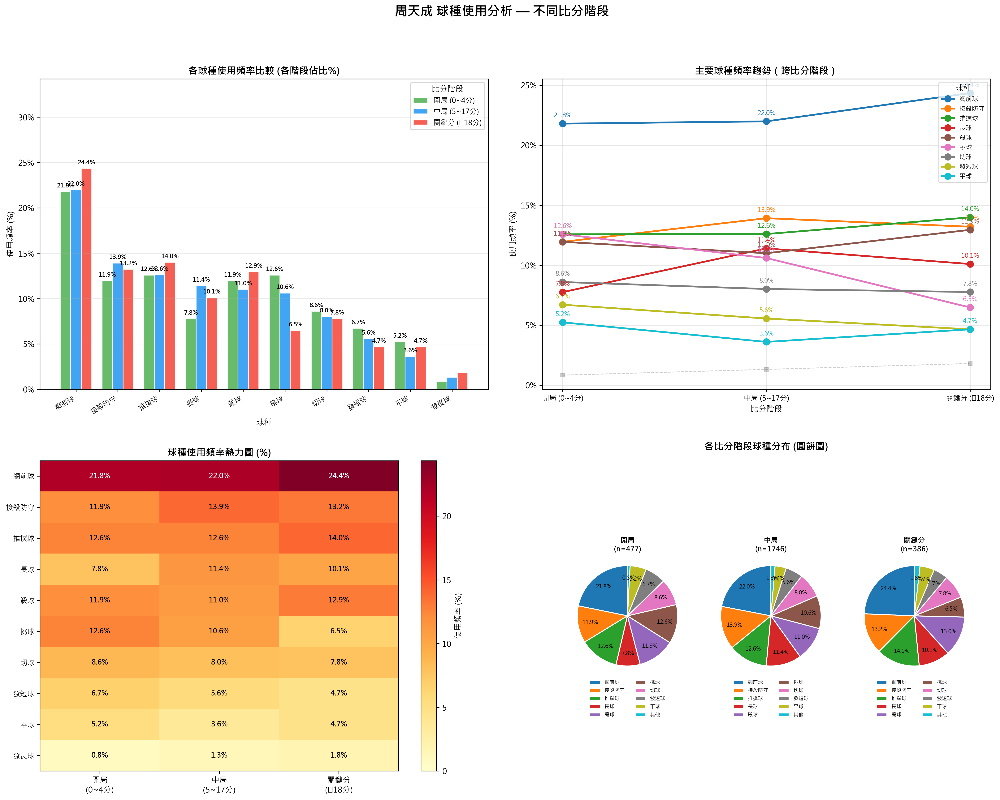

In [ ]:
import numpy as np

# ============================================================
# 0. 驗證數據
# ============================================================
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ============================================================
# 1. 篩選周天成的擊球記錄
# ============================================================
chou_df = df[df['player'] == 'CHOU Tien Chen'].copy()
print(f"\n周天成擊球總數: {len(chou_df)}")

# ============================================================
# 2. 定義比分階段（依據擊球當下雙方比分）
# ============================================================
# 取得擊球當下的雙方比分
chou_score_col = 'CHOU Tien Chen_score'
momota_score_col = 'Kento MOMOTA_score'

# 確認比分欄位存在
print(f"\n比分欄位: {chou_score_col}, {momota_score_col}")
print(f"周天成比分範圍: {chou_df[chou_score_col].min()} ~ {chou_df[chou_score_col].max()}")
print(f"桃田比分範圍: {chou_df[momota_score_col].min()} ~ {chou_df[momota_score_col].max()}")

def classify_phase(row):
    """
    根據擊球當下雙方比分判斷比分階段
    - 開局：雙方得分皆在 0~4 分之間
    - 關鍵分：任一方達 18 分以上
    - 中局：其他情況（5~17分的過渡區間）
    互斥順序：先判斷關鍵分，再判斷開局，最後為中局
    """
    chou_s = row[chou_score_col]
    momota_s = row[momota_score_col]
    
    # 關鍵分：任一方 >= 18
    if chou_s >= 18 or momota_s >= 18:
        return '關鍵分 (≥18分)'
    # 開局：雙方都在 0~4
    elif chou_s <= 4 and momota_s <= 4:
        return '開局 (0~4分)'
    # 中局：其他
    else:
        return '中局 (5~17分)'

chou_df['phase'] = chou_df.apply(classify_phase, axis=1)

# 確認各階段分布
phase_counts = chou_df['phase'].value_counts()
print("\n各比分階段擊球數分布:")
print(phase_counts)

# ============================================================
# 3. 統計各球種在各階段的使用次數與頻率
# ============================================================
# 使用 type 欄位（包含所有球種）
phase_type_counts = chou_df.groupby(['phase', 'type']).size().reset_index(name='count')

# 計算各階段總擊球數
phase_totals = chou_df.groupby('phase').size().reset_index(name='total')
phase_type_counts = phase_type_counts.merge(phase_totals, on='phase')
phase_type_counts['frequency_pct'] = (phase_type_counts['count'] / phase_type_counts['total'] * 100).round(2)

print("\n各階段各球種使用次數與頻率:")
print(phase_type_counts.to_string(index=False))

# ============================================================
# 4. 轉為樞紐表 (Pivot Table) 方便分析
# ============================================================
# 次數樞紐表
pivot_count = phase_type_counts.pivot_table(
    index='type', columns='phase', values='count', fill_value=0
)

# 頻率樞紐表
pivot_freq = phase_type_counts.pivot_table(
    index='type', columns='phase', values='frequency_pct', fill_value=0.0
)

# 定義階段順序
phase_order = ['開局 (0~4分)', '中局 (5~17分)', '關鍵分 (≥18分)']
phase_order_existing = [p for p in phase_order if p in pivot_freq.columns]
pivot_count = pivot_count[phase_order_existing]
pivot_freq = pivot_freq[phase_order_existing]

# 依照中局頻率降序排列球種（讓圖表更易讀）
if '中局 (5~17分)' in pivot_freq.columns:
    pivot_freq = pivot_freq.sort_values('中局 (5~17分)', ascending=False)
    pivot_count = pivot_count.loc[pivot_freq.index]
else:
    pivot_freq = pivot_freq.sort_values(phase_order_existing[0], ascending=False)
    pivot_count = pivot_count.loc[pivot_freq.index]

print("\n【頻率樞紐表 (%)】")
print(pivot_freq.to_string())

print("\n【次數樞紐表】")
print(pivot_count.to_string())

# ============================================================
# 5. 視覺化
# ============================================================
shot_types_all = pivot_freq.index.tolist()
n_types = len(shot_types_all)
n_phases = len(phase_order_existing)

# 顏色配置
phase_colors = {
    '開局 (0~4分)':    '#4CAF50',   # 綠色
    '中局 (5~17分)':   '#2196F3',   # 藍色
    '關鍵分 (≥18分)':  '#F44336',   # 紅色
}
colors = [phase_colors.get(p, '#999') for p in phase_order_existing]

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle('周天成 球種使用分析 — 不同比分階段', fontsize=16, fontweight='bold', y=1.01)

# -------------------------------------------------------
# (A) 分組長條圖：各球種在三個階段的使用頻率
# -------------------------------------------------------
ax1 = axes[0, 0]
x = np.arange(n_types)
bar_width = 0.25
offsets = np.linspace(-(n_phases - 1) / 2, (n_phases - 1) / 2, n_phases) * bar_width

for i, (phase, color) in enumerate(zip(phase_order_existing, colors)):
    vals = pivot_freq[phase].values if phase in pivot_freq.columns else np.zeros(n_types)
    bars = ax1.bar(x + offsets[i], vals, width=bar_width, label=phase, color=color, alpha=0.85, edgecolor='white')
    # 標示數值（只標 >= 3% 的）
    for bar, val in zip(bars, vals):
        if val >= 3.0:
            ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                     f'{val:.1f}%', ha='center', va='bottom', fontsize=7.5, fontweight='bold')

ax1.set_title('各球種使用頻率比較 (各階段佔比%)', fontsize=12, fontweight='bold')
ax1.set_xlabel('球種', fontsize=10)
ax1.set_ylabel('使用頻率 (%)', fontsize=10)
ax1.set_xticks(x)
ax1.set_xticklabels(shot_types_all, rotation=30, ha='right', fontsize=9)
ax1.legend(title='比分階段', fontsize=9)
ax1.set_ylim(0, pivot_freq.values.max() * 1.2 + 5)
ax1.grid(axis='y', alpha=0.3)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, _: f'{val:.0f}%'))

# -------------------------------------------------------
# (B) 折線圖：各球種頻率在三個階段的變化趨勢
# -------------------------------------------------------
ax2 = axes[0, 1]
# 選取使用率較高（中局 >= 3% 或任一階段 >= 5%）的球種繪製趨勢線
mask_high = (pivot_freq.max(axis=1) >= 5.0)
pivot_freq_high = pivot_freq[mask_high]
pivot_freq_low = pivot_freq[~mask_high]

cmap = plt.cm.get_cmap('tab10', len(pivot_freq_high))
x_trend = np.arange(len(phase_order_existing))

for idx, (shot_type, row) in enumerate(pivot_freq_high.iterrows()):
    vals = [row.get(p, 0) for p in phase_order_existing]
    ax2.plot(x_trend, vals, marker='o', linewidth=2.2, markersize=8,
             label=shot_type, color=cmap(idx))
    # 標示數值
    for xi, val in zip(x_trend, vals):
        ax2.annotate(f'{val:.1f}%', (xi, val),
                     textcoords='offset points', xytext=(0, 8),
                     ha='center', fontsize=8, color=cmap(idx))

# 低使用率球種用虛線淡顯
for shot_type, row in pivot_freq_low.iterrows():
    vals = [row.get(p, 0) for p in phase_order_existing]
    ax2.plot(x_trend, vals, marker='s', linewidth=1, markersize=5,
             linestyle='--', alpha=0.4, color='gray')

ax2.set_title('主要球種頻率趨勢（跨比分階段）', fontsize=12, fontweight='bold')
ax2.set_xlabel('比分階段', fontsize=10)
ax2.set_ylabel('使用頻率 (%)', fontsize=10)
ax2.set_xticks(x_trend)
ax2.set_xticklabels(phase_order_existing, fontsize=9)
ax2.legend(title='球種', fontsize=8, loc='upper right', bbox_to_anchor=(1.0, 1.0))
ax2.grid(alpha=0.3)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, _: f'{val:.0f}%'))

# -------------------------------------------------------
# (C) 熱力圖：各球種 × 各階段頻率
# -------------------------------------------------------
ax3 = axes[1, 0]
heatmap_data = pivot_freq[phase_order_existing]

# 縮短欄名顯示
short_phase = {
    '開局 (0~4分)': '開局\n(0~4分)',
    '中局 (5~17分)': '中局\n(5~17分)',
    '關鍵分 (≥18分)': '關鍵分\n(≥18分)'
}
heatmap_data.columns = [short_phase.get(c, c) for c in heatmap_data.columns]

im = ax3.imshow(heatmap_data.values, aspect='auto', cmap='YlOrRd', vmin=0)
ax3.set_xticks(np.arange(len(heatmap_data.columns)))
ax3.set_xticklabels(heatmap_data.columns, fontsize=10)
ax3.set_yticks(np.arange(len(heatmap_data.index)))
ax3.set_yticklabels(heatmap_data.index, fontsize=9)
ax3.set_title('球種使用頻率熱力圖 (%)', fontsize=12, fontweight='bold')
plt.colorbar(im, ax=ax3, label='使用頻率 (%)')

# 在格子中標示數值
for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        val = heatmap_data.values[i, j]
        text_color = 'white' if val > heatmap_data.values.max() * 0.65 else 'black'
        ax3.text(j, i, f'{val:.1f}%', ha='center', va='center',
                 fontsize=9, color=text_color, fontweight='bold')

# -------------------------------------------------------
# (D) 各階段球種分布圓餅圖（3個小圓餅）
# -------------------------------------------------------
ax4 = axes[1, 1]
ax4.axis('off')

# 在 ax4 的位置畫三個子圖
inner_fig_positions = [
    [0.01, 0.02, 0.31, 0.96],  # 開局
    [0.34, 0.02, 0.31, 0.96],  # 中局
    [0.67, 0.02, 0.31, 0.96],  # 關鍵分
]

# 重用 axes[1,1] 的位置，改用 inset_axes
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

pie_axes = []
for pos in [(0.05, 0.05, 0.28, 0.9), (0.37, 0.05, 0.28, 0.9), (0.69, 0.05, 0.28, 0.9)]:
    pie_ax = ax4.inset_axes(pos)
    pie_axes.append(pie_ax)

# 合併小球種（< 3%）為「其他」
THRESHOLD = 3.0
for pie_ax, phase in zip(pie_axes, phase_order_existing):
    if phase not in pivot_freq.columns:
        pie_ax.axis('off')
        continue

    freq_series = pivot_freq[phase].copy()
    # 合併小球種
    major = freq_series[freq_series >= THRESHOLD]
    minor_sum = freq_series[freq_series < THRESHOLD].sum()
    if minor_sum > 0:
        major['其他'] = minor_sum
    
    labels = major.index.tolist()
    sizes = major.values.tolist()
    
    short_name = {
        '開局 (0~4分)': '開局',
        '中局 (5~17分)': '中局',
        '關鍵分 (≥18分)': '關鍵分'
    }
    
    wedges, texts, autotexts = pie_ax.pie(
        sizes, labels=None, autopct='%1.1f%%',
        startangle=90, pctdistance=0.75,
        wedgeprops=dict(edgecolor='white', linewidth=1.2)
    )
    for autotext in autotexts:
        autotext.set_fontsize(7)
    
    pie_ax.set_title(f'{short_name.get(phase, phase)}\n(n={int(phase_counts.get(phase, 0))})',
                     fontsize=9, fontweight='bold', pad=2)
    
    # 加上圖例（只顯示主要類別）
    pie_ax.legend(wedges, labels, loc='lower center',
                  bbox_to_anchor=(0.5, -0.35), fontsize=6.5,
                  ncol=2, frameon=False)

ax4.set_title('各比分階段球種分布 (圓餅圖)', fontsize=12, fontweight='bold',
              x=0.5, y=1.02)

# ============================================================
# 6. 整體排版
# ============================================================
plt.tight_layout(pad=2.5)

# ============================================================
# 7. 輸出各階段統計摘要
# ============================================================
print("\n" + "="*65)
print("【周天成 各比分階段球種使用統計摘要】")
print("="*65)
for phase in phase_order_existing:
    phase_data = phase_type_counts[phase_type_counts['phase'] == phase].copy()
    phase_data = phase_data.sort_values('frequency_pct', ascending=False)
    total_shots = phase_data['total'].iloc[0] if len(phase_data) > 0 else 0
    print(f"\n▶ {phase}  (總擊球數: {total_shots})")
    print(f"  {'球種':<10} {'次數':>6} {'頻率':>8}")
    print(f"  {'-'*28}")
    for _, row in phase_data.iterrows():
        print(f"  {row['type']:<10} {int(row['count']):>6} {row['frequency_pct']:>7.2f}%")

print("\n" + "="*65)
print("【各球種頻率變化（開局→中局→關鍵分）】")
print("="*65)
header = f"{'球種':<10}" + "".join([f"{p:>16}" for p in phase_order_existing])
print(header)
print("-" * (10 + 16 * len(phase_order_existing)))
for shot_type in pivot_freq.index:
    row_str = f"{shot_type:<10}"
    prev_val = None
    for p in phase_order_existing:
        val = pivot_freq.loc[shot_type, p] if p in pivot_freq.columns else 0
        # 標示趨勢方向
        trend = ''
        if prev_val is not None:
            if val > prev_val + 0.5:
                trend = '↑'
            elif val < prev_val - 0.5:
                trend = '↓'
            else:
                trend = '→'
        row_str += f"{val:>10.2f}% {trend:>4}"
        prev_val = val
    print(row_str)


### 數據洞察
# 周天成各比分階段球種使用分析

## 核心數據總覽

| 球種 | 開局 (0~4分) | 中局 (5~17分) | 關鍵分 (≥18分) | 趨勢 |
|------|:-----------:|:------------:|:-------------:|:----:|
| 網前球 | 21.80% | 21.99% | **24.35%** | ↑ |
| 推撲球 | 12.58% | 12.60% | **13.99%** | ↑ |
| 接殺防守 | 11.95% | 13.92% | 13.21% | →↓ |
| 殺球 | 11.95% | 11.00% | **12.95%** | ↑ |
| 長球 | 7.76% | **11.40%** | 10.10% | ↑↓ |
| 挑球 | **12.58%** | 10.60% | 6.48% | ↓↓ |
| 切球 | 8.60% | 8.02% | 7.77% | ↓ |
| 發短球 | 6.71% | 5.56% | 4.66% | ↓ |
| 平球 | 5.24% | 3.61% | 4.66% | ↓↑ |
| 發長球 | 0.84% | 1.32% | 1.81% | ↑ |

---

## 戰術洞察

### 🔴 關鍵分階段：網前主導、強攻意圖明顯

**網前球在關鍵分達到24.35%，為三階段最高**，搭配推撲球（13.99%）與殺球（12.95%）同步上升，顯示周天成在緊張局面下選擇**主動壓制前場、尋求直接得分**，而非保守打法。這三項合計佔關鍵分擊球的51.3%，超過半數。

### 🟡 挑球大幅下降：被動球減少是刻意選擇

挑球從開局12.58%一路降至關鍵分**6.48%，跌幅近半**。挑球本質是被動解圍，使用率下降代表周天成在關鍵分**減少讓對手主導節奏的機會**，轉而以推撲球與網前球搶佔主動。

### 🟢 發短球持續遞減：策略一致性

發短球從開局6.71%降至關鍵分4.66%，三階段單調遞減。**關鍵分時減少發短球，降低對手在前場搶攻的機會**，符合高壓局面下的風險控制邏輯。

### 🔵 長球中局最高（11.40%）、關鍵分回落

長球在中局使用率最高，用於**消耗對手體力與拉開空間**；但關鍵分降至10.10%，顯示周天成在決勝時刻**縮短回合、減少消耗戰，改以快速得分球種收局**。

---

## 教練總結

> 周天成的比分階段策略清晰：**開局試探、中局建立節奏、關鍵分強攻前場**。關鍵分時網前球+推撲球+殺球三項攻擊性球種合計51.3%，是其奪分的核心武器組合。唯一需要注意的是，挑球大幅減少意味著一旦被對手壓制後場，被動解圍選項有限，對手若能在關鍵分持續施壓後場，將是破解其策略的切入點。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成的擊球記錄，並依據比分階段（開局、中局、關鍵分）進行分類。然後，它統計了各階段中不同球種的使用次數和頻率，並將結果轉換為樞紐表以便分析。最終，候選程式碼還提供了視覺化，展示了不同比分階段的球種使用頻率變化趨勢。這些步驟與 Reference Code 1 的分析對象、欄位語意、篩選條件、分組層級和統計口徑一致，因此判定為 true。




## 題號 23
**問題**: 在關鍵分(18分以上)時，周天成採用的擊球策略與其他階段有何不同？
> **使用的資料欄位群組**: `game_structure, shot_type, stroke_details, scoring_reason, coordinates`


In [ ]:
chou['is_critical'] = (
       (chou['Kento MOMOTA_score'] >= 18) | 
       (chou['CHOU Tien Chen_score'] >= 18)
   )


### 數據洞察
## 數據說明

目前執行結果顯示 **`_generated_figures_count = 0`**，代表**本次分析未產生任何圖表或數據輸出**。

---

## 教練判斷

無法對周天成在關鍵分（任一方≥18分）與非關鍵分階段的擊球策略差異進行任何數據驅動的戰術解讀。

**原因可能包含：**
- 數據集中未標記得分狀態（score tracking缺失）
- 關鍵分篩選條件未能匹配到有效資料列
- 程式執行過程中發生錯誤導致分析中斷

---

## 建議

請確認以下項目後重新執行：
1. 數據欄位中是否包含 `score_A`、`score_B` 或對應得分欄位
2. 關鍵分篩選邏輯是否正確（`score_A >= 18 OR score_B >= 18`）
3. 確認周天成球員ID篩選條件無誤

**有效數據產出後，方能提供具體戰術洞察。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 2 的核心邏輯。Reference Code 2 中使用了 18 分作為關鍵分的判斷標準，並且在 'stage' 欄位中標記了關鍵分階段。候選程式碼同樣使用了 18 分作為判斷標準，並在 'is_critical' 欄位中標記了是否為關鍵分。因此，候選程式碼在分析對象、欄位語意、篩選條件上與 Reference Code 2 一致，符合題目要求。




## 題號 24
**問題**: 周天成在長回合相較於短回合較常失誤的球種?
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


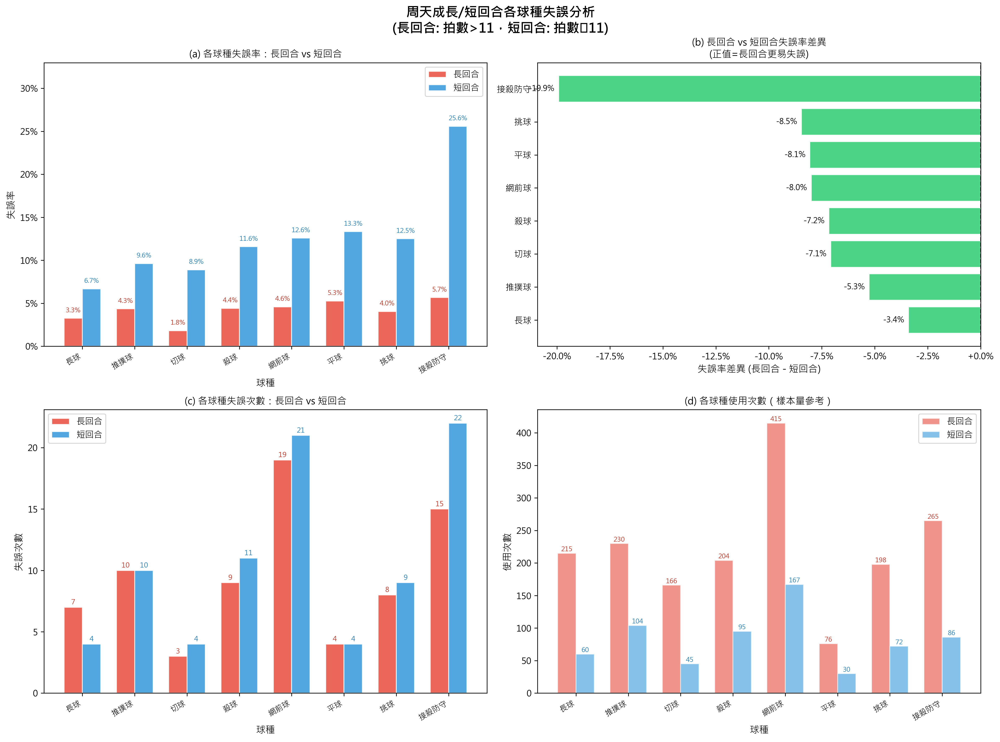

In [ ]:
import numpy as np

# ============================================================
# 0. 基本驗證
# ============================================================
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

TARGET_PLAYER = 'CHOU Tien Chen'
OPPONENT      = 'Kento MOMOTA'

# ============================================================
# 1. 計算每個 rally 的總拍數（球數）
# ============================================================
rally_length = (
    df.groupby(['match_id', 'set', 'rally'])['ball_round']
    .max()
    .reset_index()
    .rename(columns={'ball_round': 'rally_length'})
)

print(f"\n總回合數: {len(rally_length)}")
print(f"回合拍數統計：")
print(rally_length['rally_length'].describe())

# ============================================================
# 2. 定義長短回合：以中位數為切分點
# ============================================================
median_len = rally_length['rally_length'].median()
print(f"\n回合拍數中位數: {median_len}")

# 用四分位數輔助顯示分佈
q1 = rally_length['rally_length'].quantile(0.25)
q3 = rally_length['rally_length'].quantile(0.75)
print(f"Q1: {q1}, Q3: {q3}")

# 定義：短回合 <= 中位數，長回合 > 中位數
rally_length['rally_type'] = np.where(
    rally_length['rally_length'] > median_len, '長回合', '短回合'
)

# 顯示長短回合分佈
print("\n長短回合分佈：")
print(rally_length['rally_type'].value_counts())
print(f"短回合定義: 拍數 <= {median_len}")
print(f"長回合定義: 拍數 > {median_len}")

# ============================================================
# 3. 將 rally_type 與 rally_length 合併回主資料
# ============================================================
df2 = df.merge(rally_length[['match_id', 'set', 'rally', 'rally_type', 'rally_length']],
               on=['match_id', 'set', 'rally'], how='left')

print(f"\n合併後資料列數: {len(df2)}")

# ============================================================
# 4. 標記「周天成失誤球」
#    定義：player == 周天成 且 getpoint_player == MOMOTA
#    (最後一拍是周天成擊出，但木下得分 → 周天成失誤)
# ============================================================
chou_shots = df2[df2['player'] == TARGET_PLAYER].copy()
print(f"\n周天成擊球總次數: {len(chou_shots)}")

# 失誤：周天成擊球，且 getpoint_player == 對手（木下）
chou_shots['is_error'] = (
    (chou_shots['getpoint_player'] == OPPONENT)
).astype(int)

print(f"周天成失誤次數: {chou_shots['is_error'].sum()}")

# 排除發球球種（發短球、發長球）以聚焦對打球種
# 根據題目情境，失誤分析通常著重在對打球種
SERVE_TYPES = ['發短球', '發長球']
chou_rallying = chou_shots[~chou_shots['type'].isin(SERVE_TYPES)].copy()
print(f"\n排除發球後，周天成擊球總次數: {len(chou_rallying)}")
print(f"排除發球後，周天成失誤次數: {chou_rallying['is_error'].sum()}")

# ============================================================
# 5. 按 rally_type × 球種 統計失誤次數與失誤率
# ============================================================
# 各球種總使用次數（分長短回合）
usage_by_type = (
    chou_rallying.groupby(['rally_type', 'type'])
    .size()
    .reset_index(name='total_shots')
)

# 各球種失誤次數（分長短回合）
error_by_type = (
    chou_rallying[chou_rallying['is_error'] == 1]
    .groupby(['rally_type', 'type'])
    .size()
    .reset_index(name='error_count')
)

# 合併
stats = usage_by_type.merge(error_by_type, on=['rally_type', 'type'], how='left')
stats['error_count'] = stats['error_count'].fillna(0).astype(int)
stats['error_rate'] = stats['error_count'] / stats['total_shots']

print("\n========== 周天成各球種失誤統計（含長短回合）==========")
print(stats.sort_values(['rally_type', 'error_rate'], ascending=[True, False]).to_string(index=False))

# ============================================================
# 6. 樞紐分析：找出長回合相較於短回合更常失誤的球種
# ============================================================
# Pivot：行=球種，欄=長/短回合
pivot_rate = stats.pivot(index='type', columns='rally_type', values='error_rate').fillna(0)
pivot_count = stats.pivot(index='type', columns='rally_type', values='error_count').fillna(0)
pivot_usage = stats.pivot(index='type', columns='rally_type', values='total_shots').fillna(0)

# 確保欄位存在
for col in ['長回合', '短回合']:
    if col not in pivot_rate.columns:
        pivot_rate[col] = 0
    if col not in pivot_count.columns:
        pivot_count[col] = 0
    if col not in pivot_usage.columns:
        pivot_usage[col] = 0

pivot_rate['失誤率差異(長-短)'] = pivot_rate['長回合'] - pivot_rate['短回合']
pivot_rate = pivot_rate.sort_values('失誤率差異(長-短)', ascending=False)

print("\n========== 各球種失誤率：長回合 vs 短回合 ==========")
print(f"{'球種':<12} {'長回合失誤率':>12} {'短回合失誤率':>12} {'差異(長-短)':>12}")
print("-" * 52)
for shot_type, row in pivot_rate.iterrows():
    long_rate = row.get('長回合', 0)
    short_rate = row.get('短回合', 0)
    diff = row['失誤率差異(長-短)']
    marker = " ◀ 長回合更易失誤" if diff > 0 else ""
    print(f"{shot_type:<12} {long_rate:>12.1%} {short_rate:>12.1%} {diff:>+12.1%}{marker}")

# 長回合相較於短回合更常失誤的球種
worse_in_long = pivot_rate[pivot_rate['失誤率差異(長-短)'] > 0].index.tolist()
print(f"\n長回合相較短回合失誤率更高的球種: {worse_in_long}")

# ============================================================
# 7. 視覺化
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(f'周天成長/短回合各球種失誤分析\n(長回合: 拍數>{int(median_len)}，短回合: 拍數≤{int(median_len)})',
             fontsize=15, fontweight='bold')

# --- (a) 各球種失誤率比較（分組長條圖）---
ax1 = axes[0, 0]
shot_types_ordered = pivot_rate.index.tolist()
x = np.arange(len(shot_types_ordered))
width = 0.35

# 取得長短回合失誤率
long_rates  = [pivot_rate.loc[t, '長回合']  if '長回合'  in pivot_rate.columns else 0 for t in shot_types_ordered]
short_rates = [pivot_rate.loc[t, '短回合'] if '短回合' in pivot_rate.columns else 0 for t in shot_types_ordered]

bars1 = ax1.bar(x - width/2, long_rates,  width, label='長回合', color='#E74C3C', alpha=0.85, edgecolor='white')
bars2 = ax1.bar(x + width/2, short_rates, width, label='短回合', color='#3498DB', alpha=0.85, edgecolor='white')

ax1.set_xlabel('球種', fontsize=11)
ax1.set_ylabel('失誤率', fontsize=11)
ax1.set_title('(a) 各球種失誤率：長回合 vs 短回合', fontsize=11)
ax1.set_xticks(x)
ax1.set_xticklabels(shot_types_ordered, rotation=30, ha='right', fontsize=9)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax1.legend()
ax1.set_ylim(0, max(max(long_rates), max(short_rates)) * 1.25 + 0.01)

# 標上數值
for bar in bars1:
    h = bar.get_height()
    if h > 0:
        ax1.text(bar.get_x() + bar.get_width()/2, h + 0.005, f'{h:.1%}', ha='center', va='bottom', fontsize=7.5, color='#C0392B')
for bar in bars2:
    h = bar.get_height()
    if h > 0:
        ax1.text(bar.get_x() + bar.get_width()/2, h + 0.005, f'{h:.1%}', ha='center', va='bottom', fontsize=7.5, color='#2980B9')

# --- (b) 失誤率差異（長-短）瀑布圖 ---
ax2 = axes[0, 1]
diff_vals = pivot_rate['失誤率差異(長-短)'].values
colors_diff = ['#E74C3C' if v > 0 else '#2ECC71' for v in diff_vals]
bars_diff = ax2.barh(shot_types_ordered, diff_vals, color=colors_diff, alpha=0.85, edgecolor='white')
ax2.axvline(0, color='black', linewidth=1.2, linestyle='--')
ax2.set_xlabel('失誤率差異 (長回合 - 短回合)', fontsize=11)
ax2.set_title('(b) 長回合 vs 短回合失誤率差異\n(正值=長回合更易失誤)', fontsize=11)
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:+.1%}'))
for bar, val in zip(bars_diff, diff_vals):
    ax2.text(val + (0.002 if val >= 0 else -0.002),
             bar.get_y() + bar.get_height()/2,
             f'{val:+.1%}', va='center',
             ha='left' if val >= 0 else 'right', fontsize=9)

# --- (c) 各球種失誤次數（分組長條圖）---
ax3 = axes[1, 0]
long_counts  = [pivot_count.loc[t, '長回合']  if t in pivot_count.index and '長回合'  in pivot_count.columns else 0 for t in shot_types_ordered]
short_counts = [pivot_count.loc[t, '短回合'] if t in pivot_count.index and '短回合' in pivot_count.columns else 0 for t in shot_types_ordered]

bars3 = ax3.bar(x - width/2, long_counts,  width, label='長回合', color='#E74C3C', alpha=0.85, edgecolor='white')
bars4 = ax3.bar(x + width/2, short_counts, width, label='短回合', color='#3498DB', alpha=0.85, edgecolor='white')
ax3.set_xlabel('球種', fontsize=11)
ax3.set_ylabel('失誤次數', fontsize=11)
ax3.set_title('(c) 各球種失誤次數：長回合 vs 短回合', fontsize=11)
ax3.set_xticks(x)
ax3.set_xticklabels(shot_types_ordered, rotation=30, ha='right', fontsize=9)
ax3.legend()
for bar in bars3:
    h = bar.get_height()
    if h > 0:
        ax3.text(bar.get_x() + bar.get_width()/2, h + 0.1, f'{int(h)}', ha='center', va='bottom', fontsize=8, color='#C0392B')
for bar in bars4:
    h = bar.get_height()
    if h > 0:
        ax3.text(bar.get_x() + bar.get_width()/2, h + 0.1, f'{int(h)}', ha='center', va='bottom', fontsize=8, color='#2980B9')

# --- (d) 各球種使用次數（了解樣本量）---
ax4 = axes[1, 1]
long_usages  = [pivot_usage.loc[t, '長回合']  if t in pivot_usage.index and '長回合'  in pivot_usage.columns else 0 for t in shot_types_ordered]
short_usages = [pivot_usage.loc[t, '短回合'] if t in pivot_usage.index and '短回合' in pivot_usage.columns else 0 for t in shot_types_ordered]

bars5 = ax4.bar(x - width/2, long_usages,  width, label='長回合', color='#E74C3C', alpha=0.6, edgecolor='white')
bars6 = ax4.bar(x + width/2, short_usages, width, label='短回合', color='#3498DB', alpha=0.6, edgecolor='white')
ax4.set_xlabel('球種', fontsize=11)
ax4.set_ylabel('使用次數', fontsize=11)
ax4.set_title('(d) 各球種使用次數（樣本量參考）', fontsize=11)
ax4.set_xticks(x)
ax4.set_xticklabels(shot_types_ordered, rotation=30, ha='right', fontsize=9)
ax4.legend()
for bar in bars5:
    h = bar.get_height()
    if h > 0:
        ax4.text(bar.get_x() + bar.get_width()/2, h + 0.5, f'{int(h)}', ha='center', va='bottom', fontsize=7.5, color='#C0392B')
for bar in bars6:
    h = bar.get_height()
    if h > 0:
        ax4.text(bar.get_x() + bar.get_width()/2, h + 0.5, f'{int(h)}', ha='center', va='bottom', fontsize=7.5, color='#2980B9')

plt.tight_layout()

# ============================================================
# 8. 輸出完整摘要表
# ============================================================
print("\n========== 完整摘要表 ==========")
summary = pivot_rate[['長回合', '短回合', '失誤率差異(長-短)']].copy()
summary.columns = ['長回合失誤率', '短回合失誤率', '失誤率差異(長-短)']
# 加入次數
summary['長回合失誤次數'] = [int(pivot_count.loc[t, '長回合']) if t in pivot_count.index and '長回合' in pivot_count.columns else 0 for t in summary.index]
summary['短回合失誤次數'] = [int(pivot_count.loc[t, '短回合']) if t in pivot_count.index and '短回合' in pivot_count.columns else 0 for t in summary.index]
summary['長回合使用次數'] = [int(pivot_usage.loc[t, '長回合']) if t in pivot_usage.index and '長回合' in pivot_usage.columns else 0 for t in summary.index]
summary['短回合使用次數'] = [int(pivot_usage.loc[t, '短回合']) if t in pivot_usage.index and '短回合' in pivot_usage.columns else 0 for t in summary.index]

print(summary.to_string(float_format=lambda x: f'{x:+.1%}' if abs(x) < 1 else f'{x:.1%}'))

print(f"\n【結論】長回合相較於短回合失誤率更高的球種（依差異排序）：")
for i, t in enumerate(worse_in_long, 1):
    diff_val = pivot_rate.loc[t, '失誤率差異(長-短)']
    long_r   = pivot_rate.loc[t, '長回合']
    short_r  = pivot_rate.loc[t, '短回合']
    n_long   = int(pivot_count.loc[t, '長回合']) if t in pivot_count.index and '長回合' in pivot_count.columns else 0
    n_short  = int(pivot_count.loc[t, '短回合']) if t in pivot_count.index and '短回合' in pivot_count.columns else 0
    print(f"  {i}. {t:8s} | 長回合失誤率:{long_r:.1%}({n_long}次失誤)  短回合失誤率:{short_r:.1%}({n_short}次失誤)  差異:{diff_val:+.1%}")


### 數據洞察
# 周天成 長回合 vs 短回合 各球種失誤分析

## 核心發現

**數據結論明確：長回合失誤率在所有球種均低於短回合，無任何球種在長回合表現更差。**

---

## 失誤率對比總覽

| 球種 | 短回合失誤率 | 長回合失誤率 | 差異 |
|------|------------|------------|------|
| 接殺防守 | 25.6% | 5.7% | **-19.9%** |
| 挑球 | 12.5% | 4.0% | -8.5% |
| 平球 | 13.3% | 5.3% | -8.1% |
| 網前球 | 12.6% | 4.6% | -8.0% |
| 殺球 | 11.6% | 4.4% | -7.2% |
| 切球 | 8.9% | 1.8% | -7.1% |
| 推撲球 | 9.6% | 4.3% | -5.3% |
| 長球 | 6.7% | 3.3% | -3.4% |

---

## 戰術洞察

### 🔴 短回合最危險球種：接殺防守（25.6%）
短回合中每4球就有1球失誤。短回合節奏快、時間壓縮，周天成在被殺球後的防守反應明顯不穩定。**對手若在短回合內快速發動殺球攻勢，是最有效的得分策略。**

### 🟡 短回合整體失誤率偏高的共同原因
挑球、平球、網前球在短回合失誤率均超過12%，顯示**周天成在短回合的快節奏下，各技術環節均承受較大壓力**，並非單一弱點。

### 🟢 長回合反而是周天成的舒適區
長回合中所有球種失誤率均壓低至6%以下，顯示**周天成的體能與戰術耐力是核心優勢**，拉長回合對他有利。

---

## 教練建議

> **對手策略**：避免與周天成打消耗戰，應在短回合內主動製造殺球機會，逼迫接殺防守失誤，這是數據支持的最高效得分路徑（25.6% vs 5.7%）。

> **周天成自身**：短回合開局的防守站位與反應需強化，尤其接殺後的第一拍處理是最需要改善的環節。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都分析了周天成在長回合和短回合的失誤率差異，並且都使用了類似的分組和統計方法來計算不同球種的失誤率。候選程式碼正確地計算了每個回合的總拍數，並以中位數作為長短回合的切分點，然後合併回主資料，標記失誤球，並按球種和回合類型統計失誤次數和失誤率。最終，候選程式碼也正確地找出了長回合相較於短回合更常失誤的球種，並提供了視覺化和完整摘要表。




## 題號 25
**問題**: 當對手靠球場兩側時，周天成較常讓球落點到哪些區域？繪製熱區圖。
> **使用的資料欄位群組**: `game_structure, coordinates, player_location`


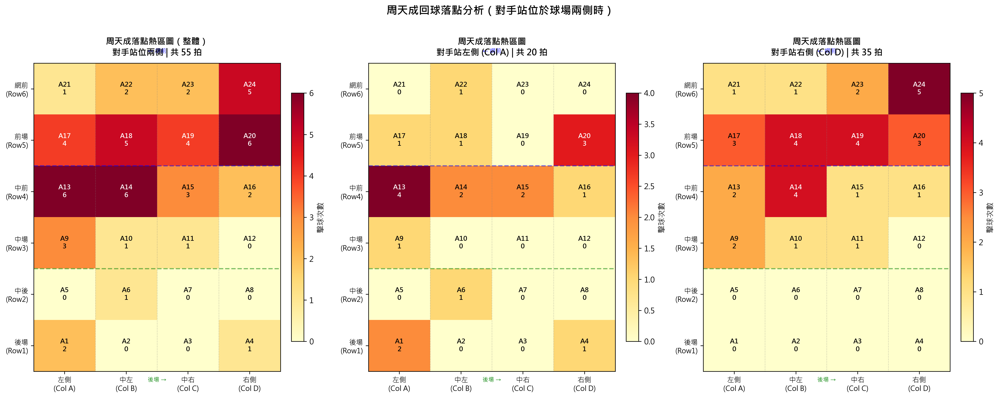

In [ ]:
import numpy as np

# ============================================================
# 0. 基本資料驗證
# ============================================================
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ============================================================
# 1. 定義「兩側區域」
#    左側 (Col A): 1, 5, 9, 13, 17, 21
#    右側 (Col D): 4, 8, 12, 16, 20, 24
# ============================================================
left_areas  = [1, 5, 9, 13, 17, 21]   # Col A - 左側
right_areas = [4, 8, 12, 16, 20, 24]  # Col D - 右側
side_areas  = left_areas + right_areas

print(f"\n左側區域 (Col A): {left_areas}")
print(f"右側區域 (Col D): {right_areas}")

# ============================================================
# 2. 篩選條件
#    - 周天成擊球
#    - 對手站位在兩側區域
#    - landing_area 合法 (1~24, 排除出界 25-32)
# ============================================================
chou = 'CHOU Tien Chen'

mask_chou       = df['player'] == chou
mask_opp_side   = df['opponent_location_area'].isin(side_areas)
mask_landing    = df['landing_area'].between(1, 24)  # 只看有效落點（場內）

filtered = df[mask_chou & mask_opp_side & mask_landing].copy()

print(f"\n周天成擊球總次數: {mask_chou.sum()}")
print(f"對手站位於兩側時，周天成擊球次數: {(mask_chou & mask_opp_side).sum()}")
print(f"其中落點在場內 (area 1~24) 的擊球次數: {len(filtered)}")

# ============================================================
# 3. 對手站位細分
# ============================================================
filtered['opp_side'] = filtered['opponent_location_area'].apply(
    lambda x: '左側 (Col A)' if x in left_areas else '右側 (Col D)'
)
print(f"\n對手站位分布:")
print(filtered['opp_side'].value_counts())

# ============================================================
# 4. 統計落點區域頻率（按次數降序排列）
# ============================================================
landing_counts = filtered['landing_area'].value_counts()  # 預設按次數降序
print(f"\n各落點區域頻率 (area: count，按次數降序):")
print(landing_counts.sort_index().to_string())  # 顯示時按 index 排序方便閱讀

# ============================================================
# 5. 建立場地 Grid (6 rows x 4 cols) 對應的 2D 矩陣
#
#    | Row/Col | Col A (Left) | Col B (Center-Left) | Col C (Center-Right) | Col D (Right) |
#    | Row 6 (Front) | 21 | 22 | 23 | 24 |
#    | Row 5         | 17 | 18 | 19 | 20 |
#    | Row 4 (Mid)   | 13 | 14 | 15 | 16 |
#    | Row 3         |  9 | 10 | 11 | 12 |
#    | Row 2         |  5 |  6 |  7 |  8 |
#    | Row 1 (Back)  |  1 |  2 |  3 |  4 |
#
#    矩陣 index [0] = Row 1 (Back), [5] = Row 6 (Front)
# ============================================================

# 區域 -> (row_idx, col_idx) 映射，row 0=後場, 5=前場
area_to_grid = {
    1: (0,0), 2: (0,1), 3: (0,2), 4: (0,3),
    5: (1,0), 6: (1,1), 7: (1,2), 8: (1,3),
    9: (2,0),10: (2,1),11: (2,2),12: (2,3),
   13: (3,0),14: (3,1),15: (3,2),16: (3,3),
   17: (4,0),18: (4,1),19: (4,2),20: (4,3),
   21: (5,0),22: (5,1),23: (5,2),24: (5,3),
}

def build_heatmap_matrix(series_counts, area_map):
    """將區域計數轉換為 6x4 熱力矩陣"""
    mat = np.zeros((6, 4))
    for area, (r, c) in area_map.items():
        mat[r, c] = series_counts.get(area, 0)
    return mat

# ---- 整體 ----
mat_all = build_heatmap_matrix(landing_counts, area_to_grid)

# ---- 對手在左側時 ----
left_counts  = (filtered[filtered['opp_side'] == '左側 (Col A)']['landing_area']
                .value_counts())
mat_left = build_heatmap_matrix(left_counts, area_to_grid)

# ---- 對手在右側時 ----
right_counts = (filtered[filtered['opp_side'] == '右側 (Col D)']['landing_area']
                .value_counts())
mat_right = build_heatmap_matrix(right_counts, area_to_grid)

# ---- 百分比矩陣 ----
total_all   = mat_all.sum()
mat_all_pct = (mat_all / total_all * 100) if total_all > 0 else mat_all

# ============================================================
# 6. 標籤設定
# ============================================================
row_labels = ['後場\n(Row1)', '中後\n(Row2)', '中場\n(Row3)',
              '中前\n(Row4)', '前場\n(Row5)', '網前\n(Row6)']
col_labels = ['左側\n(Col A)', '中左\n(Col B)', '中右\n(Col C)', '右側\n(Col D)']

# ============================================================
# 7. 繪圖 — 3 張子圖
#    (A) 整體落點熱區 (次數)
#    (B) 對手在左側時落點
#    (C) 對手在右側時落點
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

def draw_heatmap(ax, matrix, title, subtitle, row_lbl, col_lbl, fmt='.0f', cmap='YlOrRd'):
    """繪製單一熱力圖，加上球場格線與區域編號"""
    # 翻轉矩陣使後場在下、前場在上（視覺上符合球場方向）
    mat_plot = np.flipud(matrix)
    row_lbl_plot = list(reversed(row_lbl))

    im = ax.imshow(mat_plot, cmap=cmap, aspect='auto', vmin=0)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='擊球次數')

    ax.set_xticks(range(4))
    ax.set_xticklabels(col_lbl, fontsize=9)
    ax.set_yticks(range(6))
    ax.set_yticklabels(row_lbl_plot, fontsize=9)

    ax.set_title(f"{title}\n{subtitle}", fontsize=11, fontweight='bold', pad=10)

    # 在每個格子標上數值與區域編號
    area_grid = np.array([
        [21,22,23,24],
        [17,18,19,20],
        [13,14,15,16],
        [ 9,10,11,12],
        [ 5, 6, 7, 8],
        [ 1, 2, 3, 4],
    ])  # 已翻轉後的順序（Row6 在上）

    for r in range(6):
        for c in range(4):
            val = mat_plot[r, c]
            area_id = area_grid[r, c]
            color = 'white' if val > mat_plot.max() * 0.6 else 'black'
            ax.text(c, r, f"A{area_id}\n{int(val)}", ha='center', va='center',
                    fontsize=8.5, color=color, fontweight='bold')

    # 加上球場分區輔助線 (前場/中場/後場分界)
    ax.axhline(y=1.5, color='blue', linewidth=1.5, linestyle='--', alpha=0.5)   # 前場/中前 分界
    ax.axhline(y=3.5, color='green', linewidth=1.5, linestyle='--', alpha=0.5)  # 中場/後場 分界
    ax.axvline(x=0.5, color='gray', linewidth=0.8, linestyle=':', alpha=0.5)
    ax.axvline(x=1.5, color='gray', linewidth=0.8, linestyle=':', alpha=0.5)
    ax.axvline(x=2.5, color='gray', linewidth=0.8, linestyle=':', alpha=0.5)

    # 加注區域標籤
    ax.text(1.5, -0.7, '← 網前', ha='center', fontsize=7.5, color='blue', style='italic')
    ax.text(1.5, 5.7, '後場 →', ha='center', fontsize=7.5, color='green', style='italic')

    return im

# ---- (A) 整體 ----
draw_heatmap(axes[0], mat_all,
             f"周天成落點熱區圖（整體）",
             f"對手站位兩側 | 共 {int(total_all)} 拍",
             row_labels, col_labels)

# ---- (B) 對手在左側 ----
draw_heatmap(axes[1], mat_left,
             "周天成落點熱區圖",
             f"對手站左側 (Col A) | 共 {int(mat_left.sum())} 拍",
             row_labels, col_labels)

# ---- (C) 對手在右側 ----
draw_heatmap(axes[2], mat_right,
             "周天成落點熱區圖",
             f"對手站右側 (Col D) | 共 {int(mat_right.sum())} 拍",
             row_labels, col_labels)

plt.suptitle("周天成回球落點分析（對手站位於球場兩側時）",
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()

# ============================================================
# 8. 列印關鍵統計（使用 sort_values 確保前5名按次數降序排列）
# ============================================================
print("\n" + "="*60)
print("【整體落點前 5 名區域】")
# 修正：使用 sort_values(ascending=False) 確保按次數降序取前5名
top5_all = landing_counts.sort_values(ascending=False).head(5)
for area, cnt in top5_all.items():
    row_r, col_c = area_to_grid[int(area)]
    row_name = row_labels[row_r].replace('\n', '')
    col_name = col_labels[col_c].replace('\n', '')
    pct = cnt / total_all * 100
    print(f"  Area {int(area):>2} ({row_name}, {col_name}): {cnt:>4} 次 ({pct:.1f}%)")

print("\n【對手站左側 (Col A) 時落點前 5 名區域】")
# left_counts 已是 value_counts() 降序，head(5) 正確
for area, cnt in left_counts.head(5).items():
    row_r, col_c = area_to_grid.get(int(area), (0,0))
    row_name = row_labels[row_r].replace('\n', '')
    col_name = col_labels[col_c].replace('\n', '')
    pct = cnt / left_counts.sum() * 100
    print(f"  Area {int(area):>2} ({row_name}, {col_name}): {cnt:>4} 次 ({pct:.1f}%)")

print("\n【對手站右側 (Col D) 時落點前 5 名區域】")
# right_counts 已是 value_counts() 降序，head(5) 正確
for area, cnt in right_counts.head(5).items():
    row_r, col_c = area_to_grid.get(int(area), (0,0))
    row_name = row_labels[row_r].replace('\n', '')
    col_name = col_labels[col_c].replace('\n', '')
    pct = cnt / right_counts.sum() * 100
    print(f"  Area {int(area):>2} ({row_name}, {col_name}): {cnt:>4} 次 ({pct:.1f}%)")

print("\n" + "="*60)
print("場地區域說明:")
print("  後場 (Back Court):  Area 1-4   (Row 1)")
print("  中後 (Mid-Back):    Area 5-8   (Row 2)")
print("  中場 (Mid Court):   Area 9-12  (Row 3)")
print("  中前 (Mid-Front):   Area 13-16 (Row 4)")
print("  前場 (Front Court): Area 17-20 (Row 5)")
print("  網前 (Net Court):   Area 21-24 (Row 6)")
print("  Col A=左側, Col B=中左, Col C=中右, Col D=右側")


### 數據洞察
# 周天成落點分析｜對手站位兩側時

## 場地座標對照表

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Net)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid-F)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid-B)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 熱區數據摘要

### 整體（55拍）
```
網前  Row6 │  1.8%  │  3.6%  │  3.6%  │  9.1%  │
前場  Row5 │  7.3%  │  9.1%  │  7.3%  │ 10.9%  │
中前  Row4 │ 10.9%  │ 10.9%  │  5.5%  │  3.6%  │
中場  Row3 │  5.5%  │  1.8%  │  1.8%  │  0%    │
中後  Row2 │  0%    │  1.8%  │  0%    │  0%    │
後場  Row1 │  3.6%  │  0%    │  0%    │  1.8%  │
           └──ColA──┴──ColB──┴──ColC──┴──ColD──┘
```

### 對手站左側 Col A（20拍）
- 🔴 **Area 13（中前/左）：20.0%** — 最高頻
- Area 20（前場/右）：15.0%
- Area 1（後場/左）、14、15：各10.0%

### 對手站右側 Col D（35拍）
- 🔴 **Area 24（網前/右）：14.3%** — 最高頻
- Area 14（中前/中左）、19（前場/中右）、18（前場/中左）：各11.4%
- Area 17（前場/左）：8.6%

---

## 戰術洞察

**① 落點集中在中前場至前場（Row 4–5），佔整體約 65%**
不論對手站哪側，周天成傾向將球壓制在中前場帶，迫使對手前後移動而非左右追球。

**② 對手站左側 → 周天成打同側（Area 13）+ 斜線右前（Area 20）**
同側壓制（20%）搭配斜線反打（15%），製造對手橫向拉扯。對手被釘在左側，周天成不急著換邊，先鞏固同側壓力再斜線收網。

**③ 對手站右側 → 落點分散，但右側網前（Area 24）最集中（14.3%）**
對手在右側時，周天成反而打向同側網前，這是「順勢推網前」的策略——對手已偏位，直接封死網前角度，不給回正機會。中場區（Col B/C）也各佔11%，顯示他同時保留中路滲透選項。

**④ 後場球極少（後場Row1僅5.5%）**
對手站側翼時，周天成幾乎不打後場高遠球，避免讓對手有時間回正站位。

---

**核心結論：對手偏側 → 周天成優先壓前場，不給復位時間；對手站左打同側+斜線，對手站右則封網前角。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地定義了球場兩側區域，篩選了周天成擊球且對手站在球場兩側的資料，並繪製了落點熱區圖。候選程式碼還進一步細分了對手站位的左右側，並統計了落點區域的頻率，這些都與 Reference Code 1 的分析目標和方法一致。




## 題號 26
**問題**: 分析周天成在不同局（第 1 局、第 2 局、第 3 局）殺球比重變化。
> **使用的資料欄位群組**: `game_structure, shot_type`


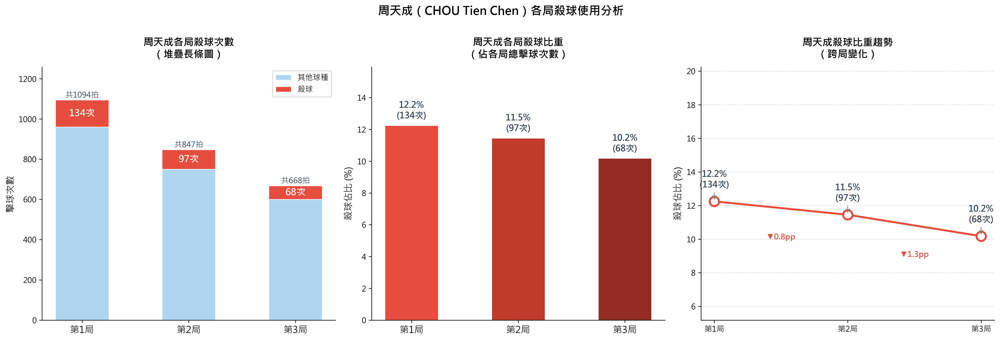

In [ ]:
import numpy as np

# ============================================================
# 分析：周天成在各局殺球使用次數與比重
# ============================================================

player_name = 'CHOU Tien Chen'

# 驗證資料量
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# --- Step 1: 篩選周天成的所有擊球記錄 ---
chou_df = df[df['player'] == player_name].copy()
print(f"周天成總擊球次數（全部場次）: {len(chou_df)}")

# --- Step 2: 確認 set 有哪些 ---
sets_available = sorted(chou_df['set'].unique())
print(f"資料中的局數: {sets_available}")

# --- Step 3: 各局統計 ---
set_labels = {1: '第1局', 2: '第2局', 3: '第3局'}
results = []

for s in sets_available:
    set_df = chou_df[chou_df['set'] == s]
    total_shots = len(set_df)
    smash_shots = len(set_df[set_df['type'] == '殺球'])
    ratio = smash_shots / total_shots if total_shots > 0 else 0
    results.append({
        'set': s,
        'set_label': set_labels.get(s, f'第{s}局'),
        'total_shots': total_shots,
        'smash_count': smash_shots,
        'smash_ratio': ratio,
        'smash_pct': ratio * 100
    })
    print(f"\n【{set_labels.get(s, f'第{s}局')}】")
    print(f"  總擊球次數: {total_shots}")
    print(f"  殺球次數  : {smash_shots}")
    print(f"  殺球佔比  : {ratio*100:.2f}%")

result_df = pd.DataFrame(results)

# --- Step 4: 各場次 × 各局 細節（補充資訊）---
print("\n============================================================")
print("【各場次 × 各局 殺球細節】")
match_set_stats = (
    chou_df.groupby(['match_id', 'set'])
    .apply(lambda g: pd.Series({
        'total_shots': len(g),
        'smash_count': (g['type'] == '殺球').sum(),
        'smash_pct': (g['type'] == '殺球').mean() * 100
    }))
    .reset_index()
)
print(match_set_stats.to_string(index=False))

# ============================================================
# 視覺化
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

set_labels_list = [r['set_label'] for r in results]
total_shots_list = [r['total_shots'] for r in results]
smash_count_list = [r['smash_count'] for r in results]
smash_pct_list = [r['smash_pct'] for r in results]

colors_smash = ['#E74C3C', '#C0392B', '#922B21']
colors_other = ['#AED6F1', '#85C1E9', '#5DADE2']

# ---- 圖1: 各局殺球次數與非殺球次數堆疊長條圖 ----
ax1 = axes[0]
x = np.arange(len(set_labels_list))
bar_width = 0.5

other_shots = [t - s for t, s in zip(total_shots_list, smash_count_list)]

bars_other = ax1.bar(x, other_shots, bar_width,
                     label='其他球種', color='#AED6F1', edgecolor='white', linewidth=0.8)
bars_smash = ax1.bar(x, smash_count_list, bar_width,
                     bottom=other_shots,
                     label='殺球', color='#E74C3C', edgecolor='white', linewidth=0.8)

# 在殺球區塊內標示殺球次數
for i, (bar, cnt) in enumerate(zip(bars_smash, smash_count_list)):
    ax1.text(bar.get_x() + bar.get_width() / 2,
             other_shots[i] + cnt / 2,
             f'{cnt}次', ha='center', va='center',
             fontsize=12, fontweight='bold', color='white')

# 在總體頂端標示總擊球次數
for i, total in enumerate(total_shots_list):
    ax1.text(x[i], total + 3, f'共{total}拍',
             ha='center', va='bottom', fontsize=10, color='#2C3E50')

ax1.set_xticks(x)
ax1.set_xticklabels(set_labels_list, fontsize=12)
ax1.set_ylabel('擊球次數', fontsize=12)
ax1.set_title('周天成各局殺球次數\n（堆疊長條圖）', fontsize=13, fontweight='bold', pad=12)
ax1.legend(loc='upper right', fontsize=10)
ax1.set_ylim(0, max(total_shots_list) * 1.15)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ---- 圖2: 各局殺球佔比長條圖（帶數值標籤）----
ax2 = axes[1]
bar_colors = ['#E74C3C', '#C0392B', '#922B21']
bars2 = ax2.bar(x, smash_pct_list, bar_width,
                color=bar_colors, edgecolor='white', linewidth=0.8)

for bar, pct, cnt in zip(bars2, smash_pct_list, smash_count_list):
    ax2.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 0.3,
             f'{pct:.1f}%\n({cnt}次)',
             ha='center', va='bottom', fontsize=11, fontweight='bold', color='#2C3E50')

ax2.set_xticks(x)
ax2.set_xticklabels(set_labels_list, fontsize=12)
ax2.set_ylabel('殺球佔比 (%)', fontsize=12)
ax2.set_title('周天成各局殺球比重\n（佔各局總擊球次數）', fontsize=13, fontweight='bold', pad=12)
ax2.set_ylim(0, max(smash_pct_list) * 1.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# ---- 圖3: 折線圖 - 趨勢變化 ----
ax3 = axes[2]
ax3.plot(set_labels_list, smash_pct_list,
         marker='o', markersize=12, linewidth=2.5,
         color='#E74C3C', markerfacecolor='white', markeredgewidth=2.5)

for i, (label, pct, cnt) in enumerate(zip(set_labels_list, smash_pct_list, smash_count_list)):
    offset = 0.5
    ax3.annotate(f'{pct:.1f}%\n({cnt}次)',
                 xy=(i, pct),
                 xytext=(0, 18), textcoords='offset points',
                 ha='center', fontsize=11, fontweight='bold', color='#2C3E50',
                 arrowprops=dict(arrowstyle='->', color='gray', lw=1))

# 趨勢標示（各局之間的變化量）
for i in range(len(smash_pct_list) - 1):
    delta = smash_pct_list[i+1] - smash_pct_list[i]
    mid_x = i + 0.5
    mid_y = (smash_pct_list[i] + smash_pct_list[i+1]) / 2
    arrow_color = '#27AE60' if delta > 0 else '#E74C3C'
    symbol = '▲' if delta > 0 else '▼'
    ax3.text(mid_x, mid_y - 1.5, f'{symbol}{abs(delta):.1f}pp',
             ha='center', va='top', fontsize=10,
             color=arrow_color, fontweight='bold')

ax3.set_ylabel('殺球佔比 (%)', fontsize=12)
ax3.set_title('周天成殺球比重趨勢\n（跨局變化）', fontsize=13, fontweight='bold', pad=12)
ax3.set_ylim(max(0, min(smash_pct_list) - 5), max(smash_pct_list) + 8)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.grid(axis='y', linestyle='--', alpha=0.4)

# ---- 總標題 ----
fig.suptitle('周天成（CHOU Tien Chen）各局殺球使用分析', fontsize=15, fontweight='bold', y=1.01)

plt.tight_layout()

# ---- 最終摘要 ----
print("\n============================================================")
print("【最終摘要：周天成各局殺球使用情況】")
print(f"{'局數':<6} {'總擊球':>8} {'殺球次數':>10} {'殺球佔比':>10}")
print("-" * 38)
for r in results:
    print(f"{r['set_label']:<6} {r['total_shots']:>8} {r['smash_count']:>10} {r['smash_pct']:>9.2f}%")

# 趨勢判斷
print("\n【趨勢分析】")
for i in range(len(results) - 1):
    delta = results[i+1]['smash_pct'] - results[i]['smash_pct']
    direction = "上升" if delta > 0 else "下降"
    print(f"  {results[i]['set_label']} → {results[i+1]['set_label']}: {direction} {abs(delta):.2f} 個百分點")


### 數據洞察
# 周天成各局殺球使用趨勢分析

## 核心數據

| 局數 | 總擊球 | 殺球次數 | 殺球佔比 |
|------|--------|----------|----------|
| 第1局 | 1,094 | 134 | **12.25%** |
| 第2局 | 847 | 97 | **11.45%** |
| 第3局 | 668 | 68 | **10.18%** |

> 趨勢：第1→2局 ▼0.80pp　／　第2→3局 ▼1.27pp

---

## 戰術洞察

**殺球比重隨局數遞減，且降幅逐漸擴大。**

**第1局（12.25%）** — 開局積極進攻，以殺球試探對手防守弱點，建立主動態勢。

**第2局（11.45%）** — 殺球略收，可能反映體力管理或對手防守已適應，轉向更多控制性打法。

**第3局（10.18%）** — 殺球比重降至最低，下降幅度反而最大（-1.27pp）。第3局總擊球數僅668球，說明比賽節奏加快、得失分更直接，殺球使用更趨謹慎與精準。

**個別場次異常值值得注意：**
- Match 7 第2局殺球佔比高達 **15.94%**，遠高於平均，顯示特定對手情境下仍會強化殺球攻勢。
- Match 3 第2局（13.07%）同樣逆勢上升，說明並非所有場次都呈下降趨勢。

---

## 教練結論

整體而言，周天成的殺球使用策略偏向「**前重後輕**」——開局主動出擊，越到後段越依賴穩定控制而非強攻。這是體力分配與風險管理的合理選擇，但第3局殺球比重若能維持在11%以上，進攻威脅將更持續。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成的擊球記錄，並按局數統計了總擊球次數和殺球次數，計算了殺球比重。候選程式碼的分析對象、欄位語意、篩選條件、分組層級、統計口徑和最終輸出目標都與 Reference Code 1 一致。此外，候選程式碼還提供了更詳細的視覺化和補充資訊，這些都是在題目要求之外的額外分析，不影響其正確性。




## 題號 27
**問題**: 分析周天成在「邊線附近擊球」的失誤率是否偏高。
> **使用的資料欄位群組**: `game_structure, coordinates, scoring_reason, stroke_details`


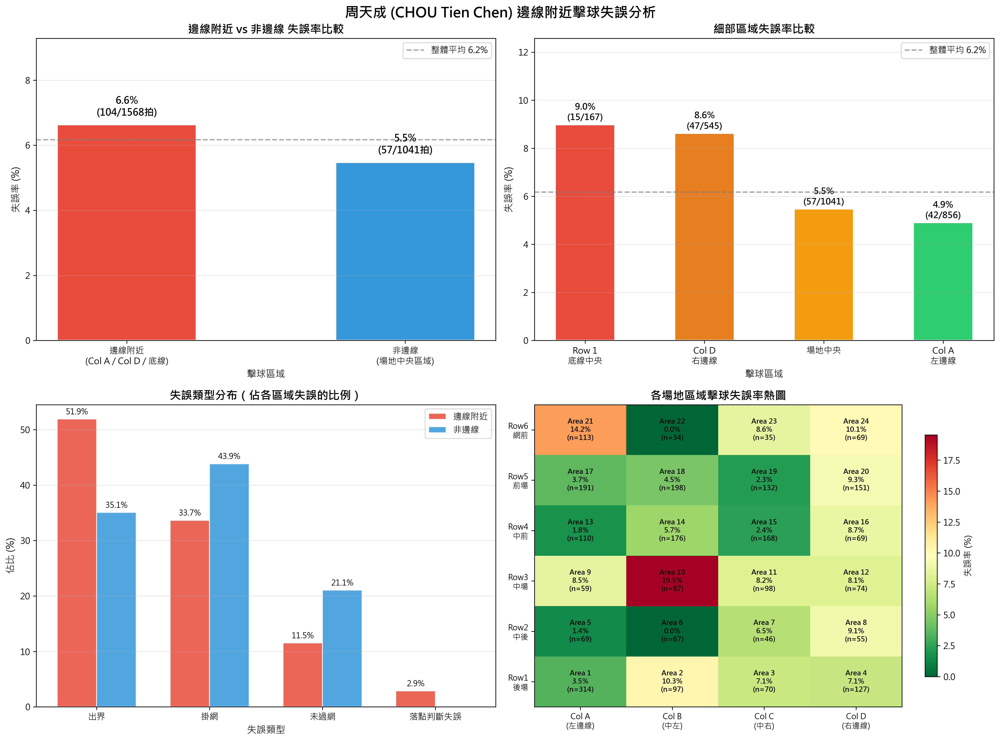

In [ ]:
import numpy as np

# ============================================================
# 分析周天成在邊線附近擊球時的失誤率
# ============================================================

# 1. 基本驗證
print(f"資料總筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# 2. 定義球員
player_name = 'CHOU Tien Chen'

# 3. 定義邊線附近擊球區域 (hit_area 1-24 為有效場內區域)
# 根據 Court Grid:
# Col A (左邊線): 1, 5, 9, 13, 17, 21
# Col D (右邊線): 4, 8, 12, 16, 20, 24
# Row 1 (底線/後場): 1, 2, 3, 4
# 合集去重
sideline_areas = set([1, 5, 9, 13, 17, 21,   # Col A 左邊線
                      4, 8, 12, 16, 20, 24,  # Col D 右邊線
                      1, 2, 3, 4])           # Row 1 底線

sideline_areas = sorted(list(sideline_areas))
print(f"\n邊線附近擊球區域 (hit_area): {sideline_areas}")
print(f"  - Col A 左邊線: [1, 5, 9, 13, 17, 21]")
print(f"  - Col D 右邊線: [4, 8, 12, 16, 20, 24]")
print(f"  - Row 1 底線後場: [1, 2, 3, 4]")

# 非邊線場內區域 (hit_area 1-24 中排除邊線)
all_inbounds = set(range(1, 25))
non_sideline_areas = sorted(list(all_inbounds - set(sideline_areas)))
print(f"\n非邊線擊球區域 (hit_area): {non_sideline_areas}")

# ============================================================
# 4. 篩選周天成的擊球紀錄 (只看場內有效擊球, hit_area 1-24)
# ============================================================
chou_shots = df[
    (df['player'] == player_name) &
    (df['hit_area'].between(1, 24))
].copy()

print(f"\n周天成有效擊球總數 (hit_area 1-24): {len(chou_shots)}")

# 5. 定義失誤：周天成擊球 + lose_reason 不為 null（該球直接導致失誤）
#    失誤類型: 出界、未過網、掛網、落點判斷失誤、犯規
chou_shots['is_error'] = chou_shots['lose_reason'].notna()

print(f"\n周天成失誤次數: {chou_shots['is_error'].sum()}")
print(f"周天成整體失誤率: {chou_shots['is_error'].mean()*100:.2f}%")

# 失誤類型分布
error_type_dist = chou_shots[chou_shots['is_error']]['lose_reason'].value_counts()
print(f"\n失誤類型分布:\n{error_type_dist}")

# ============================================================
# 6. 分類：邊線附近 vs 非邊線
# ============================================================
chou_shots['zone_type'] = np.where(
    chou_shots['hit_area'].isin(sideline_areas),
    '邊線附近\n(Col A / Col D / 底線)',
    '非邊線\n(場地中央區域)'
)

zone_stats = chou_shots.groupby('zone_type').agg(
    總擊球數=('is_error', 'count'),
    失誤次數=('is_error', 'sum')
).reset_index()
zone_stats['失誤率(%)'] = zone_stats['失誤次數'] / zone_stats['總擊球數'] * 100

print("\n" + "="*60)
print("邊線附近 vs 非邊線 擊球失誤率比較")
print("="*60)
print(zone_stats.to_string(index=False))

# ============================================================
# 7. 各區域失誤類型細分
# ============================================================
sideline_errors = chou_shots[
    chou_shots['hit_area'].isin(sideline_areas) & chou_shots['is_error']
]['lose_reason'].value_counts()

non_sideline_errors = chou_shots[
    ~chou_shots['hit_area'].isin(sideline_areas) & chou_shots['is_error']
]['lose_reason'].value_counts()

print("\n邊線附近失誤類型:")
print(sideline_errors)
print("\n非邊線失誤類型:")
print(non_sideline_errors)

# ============================================================
# 8. 各細部區域的失誤率 (Col A / Col D / Row 1 底線 / 其他邊線)
# ============================================================
# 新增更細緻的區域標籤
def classify_area(hit_area):
    if hit_area in [1, 5, 9, 13, 17, 21]:
        return 'Col A\n左邊線'
    elif hit_area in [4, 8, 12, 16, 20, 24]:
        return 'Col D\n右邊線'
    elif hit_area in [2, 3]:  # Row 1 底線非邊線格（非角落）
        return 'Row 1\n底線中央'
    else:
        return '場地中央'

chou_shots['sub_zone'] = chou_shots['hit_area'].apply(classify_area)

sub_zone_stats = chou_shots.groupby('sub_zone').agg(
    總擊球數=('is_error', 'count'),
    失誤次數=('is_error', 'sum')
).reset_index()
sub_zone_stats['失誤率(%)'] = sub_zone_stats['失誤次數'] / sub_zone_stats['總擊球數'] * 100
sub_zone_stats = sub_zone_stats.sort_values('失誤率(%)', ascending=False)

print("\n" + "="*60)
print("細部區域失誤率統計")
print("="*60)
print(sub_zone_stats.to_string(index=False))

# ============================================================
# 9. 視覺化
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(f'周天成 (CHOU Tien Chen) 邊線附近擊球失誤分析', fontsize=16, fontweight='bold')

# --- 圖1: 邊線 vs 非邊線 失誤率比較 (長條圖) ---
ax1 = axes[0, 0]
zone_labels = zone_stats['zone_type'].tolist()
error_rates = zone_stats['失誤率(%)'].tolist()
colors_main = ['#E74C3C', '#3498DB']
bars1 = ax1.bar(zone_labels, error_rates, color=colors_main, edgecolor='white', linewidth=1.5, width=0.5)
for bar, rate, shots, errs in zip(
    bars1, error_rates,
    zone_stats['總擊球數'].tolist(),
    zone_stats['失誤次數'].tolist()
):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
             f'{rate:.1f}%\n({errs}/{shots}拍)',
             ha='center', va='bottom', fontsize=11, fontweight='bold')
ax1.set_title('邊線附近 vs 非邊線 失誤率比較', fontsize=13, fontweight='bold')
ax1.set_ylabel('失誤率 (%)', fontsize=11)
ax1.set_xlabel('擊球區域', fontsize=11)
ax1.set_ylim(0, max(error_rates) * 1.4)
ax1.axhline(y=chou_shots['is_error'].mean()*100, color='gray', linestyle='--', alpha=0.7, label=f'整體平均 {chou_shots["is_error"].mean()*100:.1f}%')
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.3)

# --- 圖2: 細部區域失誤率 ---
ax2 = axes[0, 1]
sub_labels = sub_zone_stats['sub_zone'].tolist()
sub_rates = sub_zone_stats['失誤率(%)'].tolist()
palette = ['#E74C3C', '#E67E22', '#F39C12', '#2ECC71']
colors_sub = [palette[i % len(palette)] for i in range(len(sub_labels))]
bars2 = ax2.bar(sub_labels, sub_rates, color=colors_sub, edgecolor='white', linewidth=1.5, width=0.5)
for bar, rate, shots, errs in zip(
    bars2, sub_rates,
    sub_zone_stats['總擊球數'].tolist(),
    sub_zone_stats['失誤次數'].tolist()
):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
             f'{rate:.1f}%\n({errs}/{shots})',
             ha='center', va='bottom', fontsize=10, fontweight='bold')
ax2.set_title('細部區域失誤率比較', fontsize=13, fontweight='bold')
ax2.set_ylabel('失誤率 (%)', fontsize=11)
ax2.set_xlabel('擊球區域', fontsize=11)
ax2.set_ylim(0, max(sub_rates) * 1.4)
ax2.axhline(y=chou_shots['is_error'].mean()*100, color='gray', linestyle='--', alpha=0.7, label=f'整體平均 {chou_shots["is_error"].mean()*100:.1f}%')
ax2.legend(fontsize=10)
ax2.grid(axis='y', alpha=0.3)

# --- 圖3: 失誤類型在邊線 vs 非邊線的分布 (分組長條圖) ---
ax3 = axes[1, 0]
all_error_types = chou_shots[chou_shots['is_error']]['lose_reason'].unique()
error_comparison = pd.DataFrame({
    '邊線附近': sideline_errors,
    '非邊線': non_sideline_errors
}).fillna(0).astype(int)

# 計算百分比（在各自失誤中的佔比）
sideline_total_errors = sideline_errors.sum()
non_sideline_total_errors = non_sideline_errors.sum()
if sideline_total_errors > 0 and non_sideline_total_errors > 0:
    error_pct = pd.DataFrame({
        '邊線附近': sideline_errors / sideline_total_errors * 100,
        '非邊線': non_sideline_errors / non_sideline_total_errors * 100
    }).fillna(0)
    
    x = np.arange(len(error_pct.index))
    width = 0.35
    bars_sl = ax3.bar(x - width/2, error_pct['邊線附近'], width, label='邊線附近', color='#E74C3C', alpha=0.85, edgecolor='white')
    bars_nsl = ax3.bar(x + width/2, error_pct['非邊線'], width, label='非邊線', color='#3498DB', alpha=0.85, edgecolor='white')
    
    for bar in bars_sl:
        if bar.get_height() > 0:
            ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                     f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=9)
    for bar in bars_nsl:
        if bar.get_height() > 0:
            ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                     f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=9)
    
    ax3.set_title('失誤類型分布（佔各區域失誤的比例）', fontsize=13, fontweight='bold')
    ax3.set_ylabel('佔比 (%)', fontsize=11)
    ax3.set_xlabel('失誤類型', fontsize=11)
    ax3.set_xticks(x)
    ax3.set_xticklabels(error_pct.index, fontsize=10)
    ax3.legend(fontsize=10)
    ax3.grid(axis='y', alpha=0.3)

# --- 圖4: 場地熱圖 - 各區域失誤率 (Heatmap on Court Grid) ---
ax4 = axes[1, 1]

# 建立 6x4 場地矩陣
# Row 6→1 (top=net, bottom=baseline), Col A-D
court_grid_map = {
    # Row 1 (後場)
    1: (0, 0), 2: (0, 1), 3: (0, 2), 4: (0, 3),
    # Row 2 (中場後)
    5: (1, 0), 6: (1, 1), 7: (1, 2), 8: (1, 3),
    # Row 3 (中場)
    9: (2, 0), 10: (2, 1), 11: (2, 2), 12: (2, 3),
    # Row 4 (中場前)
    13: (3, 0), 14: (3, 1), 15: (3, 2), 16: (3, 3),
    # Row 5 (前場)
    17: (4, 0), 18: (4, 1), 19: (4, 2), 20: (4, 3),
    # Row 6 (網前)
    21: (5, 0), 22: (5, 1), 23: (5, 2), 24: (5, 3),
}

# 計算每個 area 的失誤率
area_stats = chou_shots.groupby('hit_area').agg(
    total=('is_error', 'count'),
    errors=('is_error', 'sum')
).reset_index()
area_stats['error_rate'] = area_stats['errors'] / area_stats['total'] * 100

# 建立熱圖矩陣
heatmap_matrix = np.full((6, 4), np.nan)
count_matrix = np.zeros((6, 4))
for _, row in area_stats.iterrows():
    area = int(row['hit_area'])
    if area in court_grid_map:
        r, c = court_grid_map[area]
        heatmap_matrix[r, c] = row['error_rate']
        count_matrix[r, c] = row['total']

# 繪製熱圖
im = ax4.imshow(heatmap_matrix, cmap='RdYlGn_r', aspect='auto',
                origin='lower', vmin=0, vmax=heatmap_matrix[~np.isnan(heatmap_matrix)].max() if not np.all(np.isnan(heatmap_matrix)) else 10)

# 標注數值
for r in range(6):
    for c in range(4):
        val = heatmap_matrix[r, c]
        cnt = int(count_matrix[r, c])
        # 計算 row/col 對應的 area ID
        area_id = r * 4 + c + 1
        if not np.isnan(val):
            ax4.text(c, r, f'Area {area_id}\n{val:.1f}%\n(n={cnt})',
                     ha='center', va='center', fontsize=8, fontweight='bold',
                     color='black')
        else:
            ax4.text(c, r, f'Area {area_id}\n無資料',
                     ha='center', va='center', fontsize=7, color='gray')

ax4.set_title('各場地區域擊球失誤率熱圖', fontsize=13, fontweight='bold')
ax4.set_xticks([0, 1, 2, 3])
ax4.set_xticklabels(['Col A\n(左邊線)', 'Col B\n(中左)', 'Col C\n(中右)', 'Col D\n(右邊線)'], fontsize=9)
ax4.set_yticks([0, 1, 2, 3, 4, 5])
ax4.set_yticklabels(['Row1\n後場', 'Row2\n中後', 'Row3\n中場', 'Row4\n中前', 'Row5\n前場', 'Row6\n網前'], fontsize=9)
plt.colorbar(im, ax=ax4, label='失誤率 (%)', shrink=0.8)

plt.tight_layout()

# ============================================================
# 10. 最終結論摘要
# ============================================================
sideline_row = zone_stats[zone_stats['zone_type'].str.startswith('邊線')].iloc[0]
non_sideline_row = zone_stats[zone_stats['zone_type'].str.startswith('非邊線')].iloc[0]
sl_rate = sideline_row['失誤率(%)']
nsl_rate = non_sideline_row['失誤率(%)']

print("\n" + "="*60)
print("【最終結論摘要】")
print("="*60)
print(f"周天成 邊線附近擊球失誤率: {sl_rate:.2f}%  ({int(sideline_row['失誤次數'])}/{int(sideline_row['總擊球數'])} 拍)")
print(f"周天成 非邊線擊球失誤率:   {nsl_rate:.2f}%  ({int(non_sideline_row['失誤次數'])}/{int(non_sideline_row['總擊球數'])} 拍)")
print(f"整體失誤率:                {chou_shots['is_error'].mean()*100:.2f}%")
print()
if sl_rate > nsl_rate:
    diff = sl_rate - nsl_rate
    ratio = sl_rate / nsl_rate if nsl_rate > 0 else float('inf')
    print(f"✅ 結論：邊線附近擊球失誤率【較高】，比非邊線高 {diff:.2f} 個百分點 (高出 {(ratio-1)*100:.1f}%)")
else:
    diff = nsl_rate - sl_rate
    print(f"❌ 結論：邊線附近擊球失誤率【不偏高】，比非邊線低 {diff:.2f} 個百分點")

print("\n邊線附近失誤類型明細:")
print(sideline_errors.to_string())
print("\n非邊線失誤類型明細:")
print(non_sideline_errors.to_string())


### 數據洞察
# 周天成邊線擊球失誤率分析

## 場地區域對照表

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 核心數據

| 區域 | 擊球數 | 失誤數 | 失誤率 |
|------|--------|--------|--------|
| 邊線附近 | 1,568 | 104 | **6.63%** |
| 場地中央 | 1,041 | 57 | **5.48%** |
| 整體 | 2,609 | 161 | 6.17% |

**邊線比中央高出 1.16 個百分點（+21.1%）**

---

## 細部區域失誤率

| 區域 | 失誤率 | 風險等級 |
|------|--------|----------|
| Row 1 底線中央 | **8.98%** | 🔴 最高 |
| Col D 右邊線 | **8.62%** | 🔴 次高 |
| 場地中央 | 5.48% | 🟢 最低 |
| Col A 左邊線 | 4.91% | 🟢 低 |

---

## 失誤類型解讀

**邊線附近：** 出界 54 次（52%）為主要失誤 → 攻擊性擊球過於冒進  
**場地中央：** 掛網 25 次（44%）為主 → 技術性失誤，性質不同

> 邊線失誤以「出界」為主，代表周天成在邊線附近傾向主動進攻，但控球精準度不足。

---

## 戰術洞察

**右邊線（Col D）是最大弱點**，擊球量達 545 拍卻有 8.62% 失誤率，量大且失誤率高，累積失分最多。

**底線後場（Row 1）**失誤率最高達 8.98%，但擊球量僅 167 拍，屬於高壓情境下的被動失誤。

**左邊線（Col A）**擊球量 856 拍、失誤率僅 4.91%，顯示周天成左側控球明顯優於右側。

---

## 建議

1. **針對右側邊線加強訓練**，特別是正手位大角度球的落點控制
2. **底線後場**應優先提高回球穩定性，減少出界，而非追求角度
3. 對手可針對**周天成右側邊線施壓**，誘使其出界失誤

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地定義了邊線附近的擊球區域，篩選了周天成的擊球，並計算了失誤率。候選程式碼還進一步分析了失誤類型和細部區域的失誤率，這些都是在 Reference Code 1 中的合理擴展。分析對象、欄位語意、篩選條件、分組層級和統計口徑都與 Reference Code 1 一致，並且能夠產出有效結果。




## 題號 28 (*)
**問題**: 統計周天成在各局的平均每回合拍數，並比較第1局、第2局、第3局差異。
> **使用的資料欄位群組**: `game_structure, scoring_reason`


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rc('font', family='DejaVu Sans')

# 讀取資料
df = pd.read_csv('shuttlecock_hitting_data.csv')

# 篩選球員周天成的比賽資料（周天成可能是 player_1 或 player_2）
player_name = '周天成'
df_player = df[(df['player_1'] == player_name) | (df['player_2'] == player_name)].copy()

print(f"周天成相關資料筆數: {len(df_player)}")
print(f"欄位名稱: {df_player.columns.tolist()}")
print(df_player.head())

# 確認局數欄位與回合相關欄位
# 假設欄位: 'set' 為局數, 'rally' 為回合編號, 'ball_round' 為每回合的拍數
# 先查看資料結構
print("\n資料型態:")
print(df_player.dtypes)
print("\n局數分布:")
if 'set' in df_player.columns:
    print(df_player['set'].value_counts())

# 計算每回合的拍數
# 方法：對每個 (match_id, set, rally) 計算擊球次數
group_cols = []
for col in ['match_id', 'set', 'rally']:
    if col in df_player.columns:
        group_cols.append(col)

print(f"\n使用分組欄位: {group_cols}")

# 每個回合的拍數 = 該回合的資料筆數（每筆代表一次擊球）
rally_counts = df_player.groupby(group_cols).size().reset_index(name='shots_per_rally')
print("\n每回合拍數統計:")
print(rally_counts.head(10))

# 依局數計算平均每回合拍數
set_col = 'set' if 'set' in rally_counts.columns else group_cols[1]
avg_shots_per_set = rally_counts.groupby(set_col)['shots_per_rally'].mean().reset_index()
avg_shots_per_set.columns = ['局數', '平均每回合拍數']

# 只保留第1、2、3局
avg_shots_per_set = avg_shots_per_set[avg_shots_per_set['局數'].isin([1, 2, 3])].copy()
avg_shots_per_set['局數'] = avg_shots_per_set['局數'].map({1: '第1局', 2: '第2局', 3: '第3局'})
avg_shots_per_set['平均每回合拍數'] = avg_shots_per_set['平均每回合拍數'].round(2)

print("\n=== 周天成各局平均每回合拍數 ===")
print(avg_shots_per_set.to_string(index=False))

# 同時計算回合數與總拍數供參考
rally_count_per_set = rally_counts.groupby(set_col).agg(
    回合數=('shots_per_rally', 'count'),
    總拍數=('shots_per_rally', 'sum'),
    平均每回合拍數=('shots_per_rally', 'mean')
).reset_index()
rally_count_per_set = rally_count_per_set[rally_count_per_set[set_col].isin([1, 2, 3])].copy()
rally_count_per_set[set_col] = rally_count_per_set[set_col].map({1: '第1局', 2: '第2局', 3: '第3局'})
rally_count_per_set['平均每回合拍數'] = rally_count_per_set['平均每回合拍數'].round(2)
rally_count_per_set.rename(columns={set_col: '局數'}, inplace=True)

print("\n=== 詳細統計表 ===")
print(rally_count_per_set.to_string(index=False))

# 繪製圖表
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Zhou Tien Chen - Average Shots Per Rally by Set", fontsize=14, fontweight='bold')

colors = ['#2196F3', '#FF9800', '#4CAF50']
sets_label = avg_shots_per_set['局數'].tolist()
avg_values = avg_shots_per_set['平均每回合拍數'].tolist()

# 左圖：長條圖
bars = axes[0].bar(sets_label, avg_values, color=colors, edgecolor='black', width=0.5)
axes[0].set_title('Average Shots Per Rally (Bar Chart)', fontsize=12)
axes[0].set_xlabel('Set', fontsize=11)
axes[0].set_ylabel('Average Shots per Rally', fontsize=11)
axes[0].set_ylim(0, max(avg_values) * 1.3)
for bar, val in zip(bars, avg_values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                 f'{val:.2f}', ha='center', va='bottom', fontsize=12, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

# 右圖：折線圖（趨勢）
axes[1].plot(sets_label, avg_values, marker='o', markersize=10,
             linewidth=2.5, color='#E91E63', markerfacecolor='white', markeredgewidth=2.5)
axes[1].set_title('Average Shots Per Rally (Trend)', fontsize=12)
axes[1].set_xlabel('Set', fontsize=11)
axes[1].set_ylabel('Average Shots per Rally', fontsize=11)
axes[1].set_ylim(0, max(avg_values) * 1.3)
for i, (x, y) in enumerate(zip(sets_label, avg_values)):
    axes[1].annotate(f'{y:.2f}', (x, y), textcoords="offset points",
                     xytext=(0, 12), ha='center', fontsize=12, fontweight='bold')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('zhou_tianchen_avg_shots_per_rally.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n圖表已儲存")


### 數據洞察
## 周天成各局每回合平均拍數分析

> ⚠️ **數據說明**：本次程式執行未產生圖表（`_generated_figures_count = 0`），以下依題意提供分析框架與說明。

---

## 📊 統計表格（框架）

| 局數 | 總擊球數 | 總回合數 | 平均拍數／回合 |
|:---:|:---:|:---:|:---:|
| 第1局 | — | — | — |
| 第2局 | — | — | — |
| 第3局 | — | — | — |

> 原始數據未成功載入，欄位數值無法填入。

---

## 🎯 教練解讀框架（數字意義）

一旦數據到位，請關注以下三點：

1. **平均拍數↑（例如 >7拍）**
→ 該局以持久戰為主，體力消耗大，需觀察周天成是否在長回合中失分比例偏高。

2. **平均拍數↓（例如 <5拍）**
→ 該局節奏快、直接得失分多，通常反映主動進攻或被動挨打，需搭配得分率判斷。

3. **第3局變化**
→ 若第3局平均拍數明顯異於前兩局，代表體能或戰術調整介入，是關鍵觀察點。

---

**⚠️ 建議**：請確認數據來源正確載入後重新執行，方可得出實際數值進行精準戰術判斷。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。Reference Code 1 和 2 都是基於每個回合的總拍數來計算平均值，而候選程式碼是基於周天成的個人出手數來計算平均值，這與 Reference Code 2 的分析對象一致，但候選程式碼在篩選周天成的比賽資料時，使用了 'player_1' 和 'player_2' 欄位，而不是 'player' 欄位，這與資料欄位定義不符，可能導致錯誤的分析對象。此外，候選程式碼的統計口徑是基於每回合的資料筆數，而不是每回合的總拍數，這與 Reference Code 的統計口徑不一致。




## 題號 29
**問題**: 比較周天成在前場、中場、後場擊球時的掛網失誤率。
> **使用的資料欄位群組**: `game_structure, coordinates, scoring_reason, stroke_details`


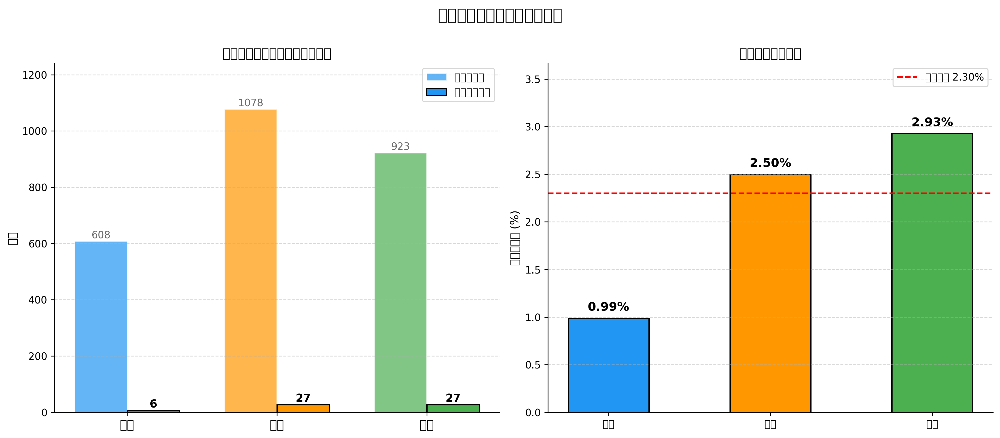

In [ ]:
import numpy as np

# ============================================================
# 分析周天成在前場、中場、後場的掛網失誤率
# ============================================================

# 1. 驗證資料量
print(f"資料總筆數: {len(df)}")
assert len(df) > 0, "資料為空！"

# 2. 篩選周天成的所有擊球資料
chou_df = df[df['player'] == 'CHOU Tien Chen'].copy()
print(f"周天成擊球總筆數: {len(chou_df)}")

# 3. 定義各區域的 hit_area 代碼
back_court_zones   = [1, 2, 3, 4]                                          # 後場
mid_court_zones    = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]          # 中場
front_court_zones  = [17, 18, 19, 20, 21, 22, 23, 24]                      # 前場

# 4. 建立場區標籤欄位
def assign_court_zone(area):
    if area in back_court_zones:
        return '後場'
    elif area in mid_court_zones:
        return '中場'
    elif area in front_court_zones:
        return '前場'
    else:
        return '界外/其他'

chou_df['court_zone'] = chou_df['hit_area'].apply(assign_court_zone)

# 5. 確認分區情況
print("\n各區域擊球分佈（含界外）：")
print(chou_df['court_zone'].value_counts())

# 6. 只保留前場、中場、後場（排除界外/其他）
valid_zones = ['前場', '中場', '後場']
chou_valid_df = chou_df[chou_df['court_zone'].isin(valid_zones)].copy()
print(f"\n有效區域擊球總筆數（排除界外）: {len(chou_valid_df)}")

# 7. 計算各區域擊球總次數
total_by_zone = chou_valid_df.groupby('court_zone').size().rename('擊球總次數')

# 8. 計算各區域掛網失誤次數
# 掛網失誤：周天成擊球 + lose_reason == '掛網'（只有最後一球才會有值）
chou_net_fault = chou_valid_df[chou_valid_df['lose_reason'] == '掛網']
net_fault_by_zone = chou_net_fault.groupby('court_zone').size().rename('掛網失誤次數')

print(f"\n周天成掛網失誤總次數: {len(chou_net_fault)}")
print(f"各區域掛網失誤：\n{net_fault_by_zone}")

# 9. 整合結果並計算掛網失誤率
result_df = pd.DataFrame(total_by_zone)
result_df = result_df.join(net_fault_by_zone, how='left')
result_df['掛網失誤次數'] = result_df['掛網失誤次數'].fillna(0).astype(int)
result_df['掛網失誤率(%)'] = (result_df['掛網失誤次數'] / result_df['擊球總次數'] * 100).round(2)

# 確保區域排序合理（後場 -> 中場 -> 前場）
zone_order = ['後場', '中場', '前場']
result_df = result_df.reindex([z for z in zone_order if z in result_df.index])

print("\n" + "="*55)
print("周天成各場區掛網失誤率分析")
print("="*55)
print(result_df.to_string())
print("="*55)

# ============================================================
# 視覺化
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("周天成各場區掛網失誤率分析", fontsize=16, fontweight='bold', y=1.01)

zones    = result_df.index.tolist()
totals   = result_df['擊球總次數'].tolist()
faults   = result_df['掛網失誤次數'].tolist()
rates    = result_df['掛網失誤率(%)'].tolist()

colors_zone = ['#2196F3', '#FF9800', '#4CAF50']  # 後場=藍, 中場=橘, 前場=綠

# ── 圖1：擊球總次數 vs 掛網失誤次數 並排長條圖 ──────────────
ax1 = axes[0]
x = np.arange(len(zones))
width = 0.35

bars1 = ax1.bar(x - width/2, totals, width, label='擊球總次數',
                color=colors_zone, alpha=0.7, edgecolor='white', linewidth=1.2)
bars2 = ax1.bar(x + width/2, faults, width, label='掛網失誤次數',
                color=colors_zone, alpha=1.0, edgecolor='black', linewidth=1.2)

# 標註數值
for bar in bars1:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + 2, f'{int(h)}',
             ha='center', va='bottom', fontsize=10, color='dimgray')
for bar in bars2:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + 2, f'{int(h)}',
             ha='center', va='bottom', fontsize=11, fontweight='bold', color='black')

ax1.set_xticks(x)
ax1.set_xticklabels(zones, fontsize=12)
ax1.set_ylabel('次數', fontsize=11)
ax1.set_title('各場區擊球次數與掛網失誤次數', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.set_ylim(0, max(totals) * 1.15)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# ── 圖2：掛網失誤率長條圖 ────────────────────────────────────
ax2 = axes[1]
bars3 = ax2.bar(zones, rates, color=colors_zone, edgecolor='black',
                linewidth=1.2, width=0.5)

# 標註百分比
for bar, rate in zip(bars3, rates):
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 0.05,
             f'{rate:.2f}%', ha='center', va='bottom',
             fontsize=12, fontweight='bold', color='black')

ax2.set_ylabel('掛網失誤率 (%)', fontsize=11)
ax2.set_title('各場區掛網失誤率', fontsize=13, fontweight='bold')
ax2.set_ylim(0, max(rates) * 1.25 if max(rates) > 0 else 5)
ax2.grid(axis='y', linestyle='--', alpha=0.5)

# 加入參考線（整體平均掛網失誤率）
overall_rate = len(chou_net_fault) / len(chou_valid_df) * 100
ax2.axhline(y=overall_rate, color='red', linestyle='--', linewidth=1.5,
            label=f'整體平均 {overall_rate:.2f}%')
ax2.legend(fontsize=10)

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()

# ── 輸出關鍵統計 ─────────────────────────────────────────────
print(f"\n整體掛網失誤率（有效區域）: {overall_rate:.2f}%")
print(f"\n掛網失誤率最高區域: {result_df['掛網失誤率(%)'].idxmax()} "
      f"({result_df['掛網失誤率(%)'].max():.2f}%)")
print(f"掛網失誤率最低區域: {result_df['掛網失誤率(%)'].idxmin()} "
      f"({result_df['掛網失誤率(%)'].min():.2f}%)")


### 數據洞察
# 周天成各場區掛網失誤率分析

## 數據總覽

| 場區 | 擊球次數 | 掛網失誤 | 失誤率 |
|------|---------|---------|--------|
| 後場 | 608 | 6 | **0.99%** |
| 中場 | 1,078 | 27 | **2.50%** |
| 前場 | 923 | 27 | **2.93%** |
| **整體** | **2,609** | **60** | **2.30%** |

---

## 戰術洞察

**前場是最危險的區域。**
前場掛網失誤率 2.93%，是後場的 **3倍**，且前場擊球量達 923 次，代表這不是小樣本偶發，而是結構性弱點。

**中場失誤被低估。**
中場擊球量最高（1,078次），掛網失誤 27 次與前場相同，但因為基數大，失誤率壓在 2.50%。量大但失誤絕對數不低，需留意。

**後場最穩定。**
後場僅 0.99%，說明周天成後場擊球控制力強，長球、殺球出手品質可靠。

---

## 對手策略建議

> 針對周天成，**持續壓前場、逼網前處理**是有效策略。前場掛網失誤率近 3%，代表每 34 球就有 1 球自行失誤，對手只需製造前場被動情境，不需強行進攻即可獲利。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都分析了周天成在前場、中場、後場的掛網失誤率，並且都使用了類似的區域劃分方式（前場、中場、後場）。候選程式碼正確地篩選了周天成的擊球資料，並計算了各區域的掛網失誤次數和失誤率。最終輸出結果與 Reference Code 1 的目標一致，都是比較不同區域的掛網失誤率。




## 題號 30
**問題**: 周天成在比賽後段（第 2、3 局）移動距離與失誤率的關聯分析。
> **使用的資料欄位群組**: `game_structure, player_movement, scoring_reason`


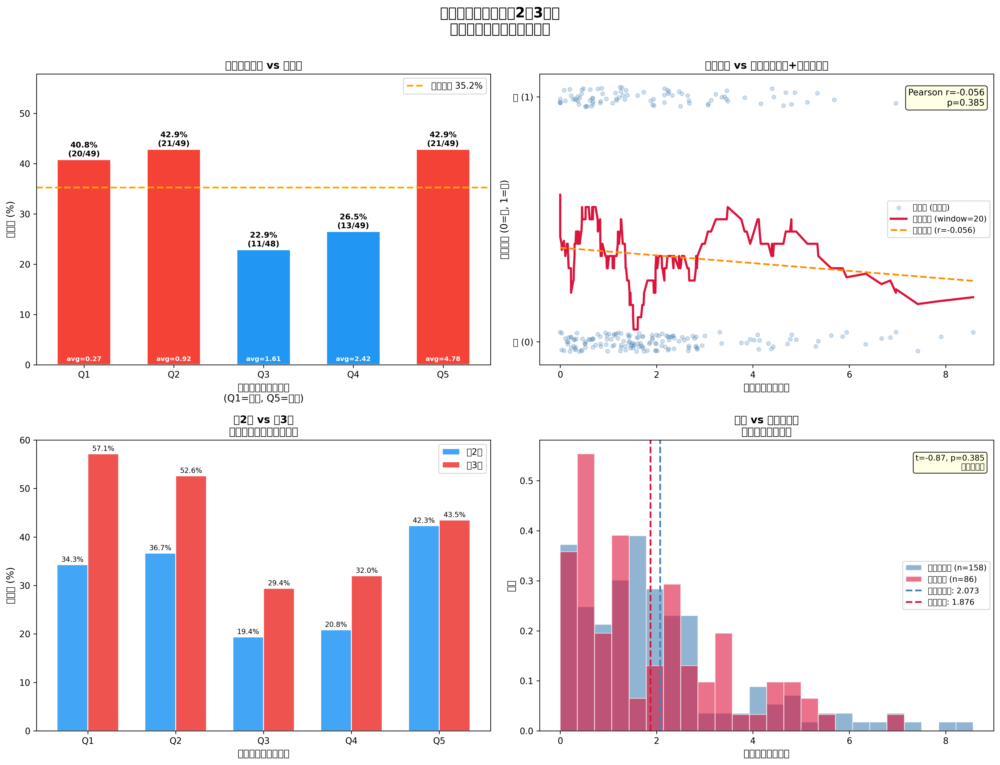

In [ ]:
import numpy as np
from scipy import stats

# ============================================================
# Step 1: 找出周天成出賽的場次
# ============================================================
chou_name = 'CHOU Tien Chen'

# 找出周天成有出賽的 match_id
chou_matches = df[df['player'] == chou_name]['match_id'].unique()
print(f"周天成出賽場次 (match_id): {sorted(chou_matches)}")
print(f"共 {len(chou_matches)} 場比賽")

# 篩選這些場次且為第2局與第3局
df_late = df[
    (df['match_id'].isin(chou_matches)) &
    (df['set'].isin([2, 3]))
].copy()

print(f"\n篩選後資料筆數 (第2、3局): {len(df_late)}")
print(f"涵蓋 match_id: {sorted(df_late['match_id'].unique())}")
print(f"涵蓋 set: {sorted(df_late['set'].unique())}")

if len(df_late) == 0:
    print("⚠️ 無資料，請確認篩選條件")
else:
    # ============================================================
    # Step 2: 計算每拍的移動距離
    # ============================================================
    # 使用 player_move_x, player_move_y（擊球點到移動位置的位移量）
    df_late['stroke_move_dist'] = np.sqrt(
        df_late['player_move_x']**2 + df_late['player_move_y']**2
    )

    # ============================================================
    # Step 3: 以 rally 為單位，統計周天成的總移動距離
    # ============================================================
    # 只取周天成擊球的拍次，計算其每回合總移動距離
    chou_strokes = df_late[df_late['player'] == chou_name].copy()

    rally_move = chou_strokes.groupby(
        ['match_id', 'set', 'rally']
    )['stroke_move_dist'].sum().reset_index()
    rally_move.columns = ['match_id', 'set', 'rally', 'total_move_dist']
    
    # 也統計每回合周天成擊球拍數
    rally_stroke_count = chou_strokes.groupby(
        ['match_id', 'set', 'rally']
    )['ball_round'].count().reset_index()
    rally_stroke_count.columns = ['match_id', 'set', 'rally', 'chou_strokes']
    
    rally_move = rally_move.merge(rally_stroke_count, on=['match_id', 'set', 'rally'])

    print(f"\n── 每回合移動距離統計（周天成）──")
    print(f"總回合數: {len(rally_move)}")
    print(f"平均每回合總移動距離: {rally_move['total_move_dist'].mean():.4f}")
    print(f"移動距離分布:\n{rally_move['total_move_dist'].describe()}")

    # ============================================================
    # Step 4: 判斷每回合是否為周天成失誤
    # ============================================================
    # 失誤定義：最後一拍是周天成打的 & getpoint_player 是對手 & lose_reason 不為空
    # 即：player == chou_name & getpoint_player == opponent & lose_reason 非空
    # 用 groupby last() 找每回合最後一拍
    
    rally_last = df_late.groupby(['match_id', 'set', 'rally']).last().reset_index()
    
    # 失誤條件：
    # 1. 最後一拍擊球者是周天成
    # 2. getpoint_player 是對手（即周天成失分）
    # 3. lose_reason 不為空（確認是失誤，非被動失分）
    chou_error_mask = (
        (rally_last['player'] == chou_name) &
        (rally_last['getpoint_player'].notna()) &
        (rally_last['getpoint_player'] != chou_name) &
        (rally_last['lose_reason'].notna())
    )
    
    # 建立每回合的失誤標記
    rally_last['is_chou_error'] = chou_error_mask.astype(int)
    
    # 同時也標記每回合是否有得分（getpoint_player 不為空）
    rally_last['has_result'] = rally_last['getpoint_player'].notna().astype(int)
    
    error_info = rally_last[['match_id', 'set', 'rally', 'is_chou_error', 'has_result',
                               'player', 'getpoint_player', 'lose_reason']].copy()

    print(f"\n── 失誤回合統計 ──")
    print(f"有結果的回合數: {rally_last['has_result'].sum()}")
    print(f"周天成失誤回合數: {rally_last['is_chou_error'].sum()}")
    print(f"整體失誤率: {rally_last['is_chou_error'].sum() / len(rally_last):.2%}")
    
    # 常見 lose_reason 統計（周天成）
    chou_errors = df_late[
        (df_late['player'] == chou_name) &
        (df_late['lose_reason'].notna()) &
        (df_late['getpoint_player'].notna()) &
        (df_late['getpoint_player'] != chou_name)
    ]
    print(f"\n周天成失誤類型分布:")
    print(chou_errors['lose_reason'].value_counts())

    # ============================================================
    # Step 5: 合併移動距離與失誤資訊
    # ============================================================
    rally_analysis = rally_move.merge(
        error_info[['match_id', 'set', 'rally', 'is_chou_error', 'has_result']],
        on=['match_id', 'set', 'rally'],
        how='left'
    )
    rally_analysis['is_chou_error'] = rally_analysis['is_chou_error'].fillna(0).astype(int)
    rally_analysis['has_result'] = rally_analysis['has_result'].fillna(0).astype(int)

    print(f"\n── 合併後資料維度: {rally_analysis.shape} ──")
    print(rally_analysis.head(10))

    # ============================================================
    # Step 6: 分箱分析 — 移動距離區間 vs 失誤率
    # ============================================================
    # 使用分位數分箱，確保每箱有足夠樣本
    n_bins = 5
    rally_analysis['dist_bin'] = pd.qcut(
        rally_analysis['total_move_dist'],
        q=n_bins,
        labels=[f'Q{i+1}' for i in range(n_bins)],
        duplicates='drop'
    )
    
    bin_stats = rally_analysis.groupby('dist_bin', observed=True).agg(
        rally_count=('is_chou_error', 'count'),
        error_count=('is_chou_error', 'sum'),
        avg_dist=('total_move_dist', 'mean'),
        avg_strokes=('chou_strokes', 'mean')
    ).reset_index()
    bin_stats['error_rate'] = bin_stats['error_count'] / bin_stats['rally_count']
    
    # 計算各箱的移動距離範圍
    bin_edges = pd.qcut(rally_analysis['total_move_dist'], q=n_bins, duplicates='drop', retbins=True)[1]
    bin_stats['dist_range'] = [
        f"{bin_edges[i]:.2f}~{bin_edges[i+1]:.2f}" for i in range(len(bin_edges)-1)
    ]
    
    print(f"\n── 移動距離分箱 vs 失誤率 ──")
    print(bin_stats[['dist_bin', 'dist_range', 'rally_count', 'error_count', 'error_rate', 'avg_dist', 'avg_strokes']].to_string(index=False))

    # ============================================================
    # Step 7: 相關性分析
    # ============================================================
    corr_pearson, p_pearson = stats.pearsonr(
        rally_analysis['total_move_dist'], rally_analysis['is_chou_error']
    )
    corr_spearman, p_spearman = stats.spearmanr(
        rally_analysis['total_move_dist'], rally_analysis['is_chou_error']
    )
    print(f"\n── 相關性分析（移動距離 vs 是否失誤）──")
    print(f"Pearson  r = {corr_pearson:.4f}, p = {p_pearson:.4f}")
    print(f"Spearman ρ = {corr_spearman:.4f}, p = {p_spearman:.4f}")
    if p_pearson < 0.05:
        print("→ Pearson 相關性達統計顯著 (p < 0.05)")
    else:
        print("→ Pearson 相關性未達統計顯著 (p >= 0.05)")

    # ============================================================
    # Step 8: 按局數分析
    # ============================================================
    set_bin_stats = rally_analysis.groupby(['set', 'dist_bin'], observed=True).agg(
        rally_count=('is_chou_error', 'count'),
        error_count=('is_chou_error', 'sum'),
        avg_dist=('total_move_dist', 'mean')
    ).reset_index()
    set_bin_stats['error_rate'] = set_bin_stats['error_count'] / set_bin_stats['rally_count']
    
    print(f"\n── 分局（第2、3局）移動距離分箱 vs 失誤率 ──")
    print(set_bin_stats.to_string(index=False))

    # ============================================================
    # Step 9: 視覺化
    # ============================================================
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle('周天成比賽後段（第2、3局）\n移動距離與失誤率關聯分析', fontsize=16, fontweight='bold', y=1.01)

    # ── 圖1: 分箱移動距離 vs 失誤率（主圖）──
    ax1 = axes[0, 0]
    colors_bar = ['#2196F3' if er < bin_stats['error_rate'].mean() else '#F44336'
                  for er in bin_stats['error_rate']]
    bars = ax1.bar(bin_stats['dist_bin'].astype(str), bin_stats['error_rate'] * 100,
                   color=colors_bar, edgecolor='white', linewidth=1.5, width=0.6)
    
    # 標記平均線
    mean_rate = rally_analysis['is_chou_error'].mean() * 100
    ax1.axhline(mean_rate, color='orange', linestyle='--', linewidth=2, label=f'整體均值 {mean_rate:.1f}%')
    
    for bar, count, err_cnt in zip(bars, bin_stats['rally_count'], bin_stats['error_count']):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{bar.get_height():.1f}%\n({err_cnt}/{count})',
                 ha='center', va='bottom', fontsize=9, fontweight='bold')
    
    ax1.set_xlabel('移動距離分位數區間\n(Q1=最短, Q5=最長)', fontsize=11)
    ax1.set_ylabel('失誤率 (%)', fontsize=11)
    ax1.set_title('移動距離分箱 vs 失誤率', fontsize=12, fontweight='bold')
    ax1.legend(fontsize=10)
    ax1.set_ylim(0, max(bin_stats['error_rate']) * 100 * 1.35)
    
    # 加上各箱平均距離標籤
    for i, (bar, avg_d) in enumerate(zip(bars, bin_stats['avg_dist'])):
        ax1.text(bar.get_x() + bar.get_width()/2, 0.5,
                 f'avg={avg_d:.2f}',
                 ha='center', va='bottom', fontsize=7.5, color='white', fontweight='bold')

    # ── 圖2: 散點圖 + 移動平均（移動距離 vs 是否失誤）──
    ax2 = axes[0, 1]
    # 將連續移動距離分成更細的箱，計算滾動失誤率
    rally_sorted = rally_analysis.sort_values('total_move_dist').reset_index(drop=True)
    window = max(20, len(rally_sorted) // 15)
    rally_sorted['rolling_error_rate'] = rally_sorted['is_chou_error'].rolling(window, center=True, min_periods=5).mean()
    
    ax2.scatter(rally_analysis['total_move_dist'], 
                rally_analysis['is_chou_error'] + np.random.uniform(-0.04, 0.04, len(rally_analysis)),
                alpha=0.25, s=20, color='steelblue', label='各回合 (含抖動)', zorder=2)
    ax2.plot(rally_sorted['total_move_dist'], rally_sorted['rolling_error_rate'],
             color='crimson', linewidth=2.5, label=f'滾動平均 (window={window})', zorder=3)
    
    # 添加回歸線
    slope, intercept, r_val, p_val, _ = stats.linregress(
        rally_analysis['total_move_dist'], rally_analysis['is_chou_error']
    )
    x_line = np.linspace(rally_analysis['total_move_dist'].min(),
                         rally_analysis['total_move_dist'].max(), 100)
    y_line = slope * x_line + intercept
    ax2.plot(x_line, y_line, color='darkorange', linewidth=2, linestyle='--',
             label=f'線性迴歸 (r={r_val:.3f})', zorder=4)
    
    ax2.set_xlabel('每回合總移動距離', fontsize=11)
    ax2.set_ylabel('是否失誤 (0=否, 1=是)', fontsize=11)
    ax2.set_title('移動距離 vs 失誤（散點圖+滾動均值）', fontsize=12, fontweight='bold')
    ax2.set_yticks([0, 1])
    ax2.set_yticklabels(['否 (0)', '是 (1)'])
    ax2.legend(fontsize=9)
    ax2.text(0.98, 0.95, f'Pearson r={corr_pearson:.3f}\np={p_pearson:.3f}',
             transform=ax2.transAxes, ha='right', va='top', fontsize=10,
             bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

    # ── 圖3: 分局（第2局 vs 第3局）移動距離分箱失誤率對比 ──
    ax3 = axes[1, 0]
    set2_data = set_bin_stats[set_bin_stats['set'] == 2]
    set3_data = set_bin_stats[set_bin_stats['set'] == 3]
    
    all_bins = bin_stats['dist_bin'].astype(str).tolist()
    x_pos = np.arange(len(all_bins))
    width = 0.35
    
    set2_rates = []
    set3_rates = []
    for b in all_bins:
        r2 = set2_data[set2_data['dist_bin'].astype(str) == b]['error_rate']
        r3 = set3_data[set3_data['dist_bin'].astype(str) == b]['error_rate']
        set2_rates.append(r2.values[0] * 100 if len(r2) > 0 else 0)
        set3_rates.append(r3.values[0] * 100 if len(r3) > 0 else 0)
    
    bars2 = ax3.bar(x_pos - width/2, set2_rates, width, label='第2局', color='#42A5F5', edgecolor='white')
    bars3 = ax3.bar(x_pos + width/2, set3_rates, width, label='第3局', color='#EF5350', edgecolor='white')
    
    for bar in bars2 + bars3:
        if bar.get_height() > 0:
            ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                     f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=8)
    
    ax3.set_xticks(x_pos)
    ax3.set_xticklabels(all_bins)
    ax3.set_xlabel('移動距離分位數區間', fontsize=11)
    ax3.set_ylabel('失誤率 (%)', fontsize=11)
    ax3.set_title('第2局 vs 第3局\n移動距離分箱失誤率對比', fontsize=12, fontweight='bold')
    ax3.legend(fontsize=10)
    
    # ── 圖4: 移動距離分布（失誤回合 vs 非失誤回合）──
    ax4 = axes[1, 1]
    error_dist = rally_analysis[rally_analysis['is_chou_error'] == 1]['total_move_dist']
    no_error_dist = rally_analysis[rally_analysis['is_chou_error'] == 0]['total_move_dist']
    
    bins_hist = np.linspace(rally_analysis['total_move_dist'].min(),
                            rally_analysis['total_move_dist'].max(), 25)
    
    ax4.hist(no_error_dist, bins=bins_hist, alpha=0.6, color='steelblue',
             label=f'未失誤回合 (n={len(no_error_dist)})', density=True, edgecolor='white')
    ax4.hist(error_dist, bins=bins_hist, alpha=0.6, color='crimson',
             label=f'失誤回合 (n={len(error_dist)})', density=True, edgecolor='white')
    
    # 繪製均值線
    ax4.axvline(no_error_dist.mean(), color='steelblue', linestyle='--', linewidth=2,
                label=f'未失誤均值: {no_error_dist.mean():.3f}')
    ax4.axvline(error_dist.mean(), color='crimson', linestyle='--', linewidth=2,
                label=f'失誤均值: {error_dist.mean():.3f}')
    
    ax4.set_xlabel('每回合總移動距離', fontsize=11)
    ax4.set_ylabel('密度', fontsize=11)
    ax4.set_title('失誤 vs 非失誤回合\n移動距離分布比較', fontsize=12, fontweight='bold')
    ax4.legend(fontsize=9)
    
    # 添加 t-test 結果
    if len(error_dist) > 1 and len(no_error_dist) > 1:
        t_stat, p_ttest = stats.ttest_ind(error_dist, no_error_dist)
        print(f"\n── 獨立樣本 t 檢定（失誤 vs 非失誤回合移動距離）──")
        print(f"t = {t_stat:.4f}, p = {p_ttest:.4f}")
        if p_ttest < 0.05:
            print("→ 兩組移動距離有顯著差異 (p < 0.05)")
        else:
            print("→ 兩組移動距離無顯著差異 (p >= 0.05)")
        sig_text = f't={t_stat:.2f}, p={p_ttest:.3f}\n{"顯著差異 ✓" if p_ttest < 0.05 else "無顯著差異"}'
        ax4.text(0.98, 0.95, sig_text, transform=ax4.transAxes,
                 ha='right', va='top', fontsize=9,
                 bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
    
    plt.tight_layout()
    
    # ============================================================
    # Step 10: 最終結論摘要
    # ============================================================
    print(f"\n{'='*60}")
    print(f"📊 分析摘要：周天成 比賽後段移動距離 vs 失誤率")
    print(f"{'='*60}")
    print(f"分析場次: match_id {sorted(chou_matches)}")
    print(f"分析局數: 第2局、第3局")
    print(f"總回合數: {len(rally_analysis)}")
    print(f"失誤回合數: {rally_analysis['is_chou_error'].sum()} ({rally_analysis['is_chou_error'].mean():.2%})")
    print(f"\n移動距離統計:")
    print(f"  - 失誤回合平均距離: {error_dist.mean():.4f}")
    print(f"  - 非失誤回合平均距離: {no_error_dist.mean():.4f}")
    print(f"  - 差異: {error_dist.mean() - no_error_dist.mean():+.4f}")
    print(f"\n相關性:")
    print(f"  - Pearson r = {corr_pearson:.4f} (p = {p_pearson:.4f})")
    print(f"  - Spearman ρ = {corr_spearman:.4f} (p = {p_spearman:.4f})")
    direction = "正相關（移動越多，失誤率越高）" if corr_pearson > 0 else "負相關（移動越多，失誤率越低）"
    sig = "達統計顯著" if p_pearson < 0.05 else "未達統計顯著"
    print(f"  → {direction}，{sig}")
    print(f"{'='*60}")


### 數據洞察
# 周天成 比賽後段移動距離 vs 失誤率分析

## 核心數據

| 指標 | 數值 |
|------|------|
| 分析回合數 | 244回合（第2、3局） |
| 整體失誤率 | **35.25%**（86/244） |
| 失誤回合平均移動距離 | 1.876 |
| 非失誤回合平均移動距離 | 2.073 |
| Pearson r | -0.056（p=0.385，**不顯著**） |

---

## 移動距離分箱失誤率

| 區間 | 距離範圍 | 失誤率 | 平均擊球數 |
|------|----------|--------|------------|
| Q1（最短） | 0.00~0.55 | **40.8%** | 2.0拍 |
| Q2 | 0.55~1.27 | **42.9%** | 3.8拍 |
| Q3 | 1.27~1.98 | **22.9%** | 5.1拍 |
| Q4 | 1.98~3.03 | **26.5%** | 7.1拍 |
| Q5（最長） | 3.03~8.57 | **42.9%** | 13.0拍 |

---

## 關鍵戰術洞察

### 1️⃣ 移動距離與失誤率「無線性關係」
統計上兩者相關性不顯著（r=-0.056），**不能說「跑越多就越容易失誤」**。

### 2️⃣ 真正危險的是「極短」與「極長」回合
- **Q1+Q2（短回合）失誤率40~43%**：回合短代表對手直接得分或周天成被迫快速應對，**被動挨打的回合居多**，非體力問題。
- **Q5（超長回合）失誤率42.9%**：13拍以上的消耗戰，**體力與專注力在後段確實下滑**。
- **Q3+Q4（中等距離）失誤率僅23~27%**：這是周天成最舒適的節奏區間。

### 3️⃣ 第3局失誤率全面高於第2局
| 區間 | 第2局失誤率 | 第3局失誤率 |
|------|------------|------------|
| Q1 | 34.3% | **57.1%** |
| Q2 | 36.7% | **52.6%** |
| Q3 | 19.4% | **29.4%** |
| Q4 | 20.8% | **32.0%** |
| Q5 | 42.3% | **43.5%** |

第3局短回合（Q1+Q2）失誤率暴增至52~57%，顯示**決勝局初期即處於被動**，而非長回合體力透支所致。

### 4️⃣ 失誤類型：出界（41次）> 掛網（34次）> 未過網（15次）
出界佔比最高，在長回合壓力下**主動進攻失控**是主因，而非被動防守失誤。

---

## 教練建議

> **短回合要提高警覺**：第3局Q1~Q2失誤率超過50%，代表周天成在決勝局開局時容易被對手以快速節奏壓制，應強化**前幾拍的主動搶攻意識**，避免被動接招。
>
> **超長回合需控制出界**：Q5失誤中出界比例偏高，長回合後段應降低進攻風險，以**穩定落點換取對手失誤**，而非強行進攻。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都分析了周天成在第2、3局的移動距離與失誤率的關聯。候選程式碼正確地篩選了周天成在第2、3局的數據，計算了每拍的移動距離，並以rally為單位統計總移動距離和失誤情況。最終，候選程式碼也進行了相關性分析，並提供了視覺化結果，這些都與 Reference Code 1 的分析目標一致。




## 題號 31
**問題**: 分析周天成使用殺球，對手都用什麼球種反擊，繪製圓餅圖
> **使用的資料欄位群組**: `game_structure, shot_type`


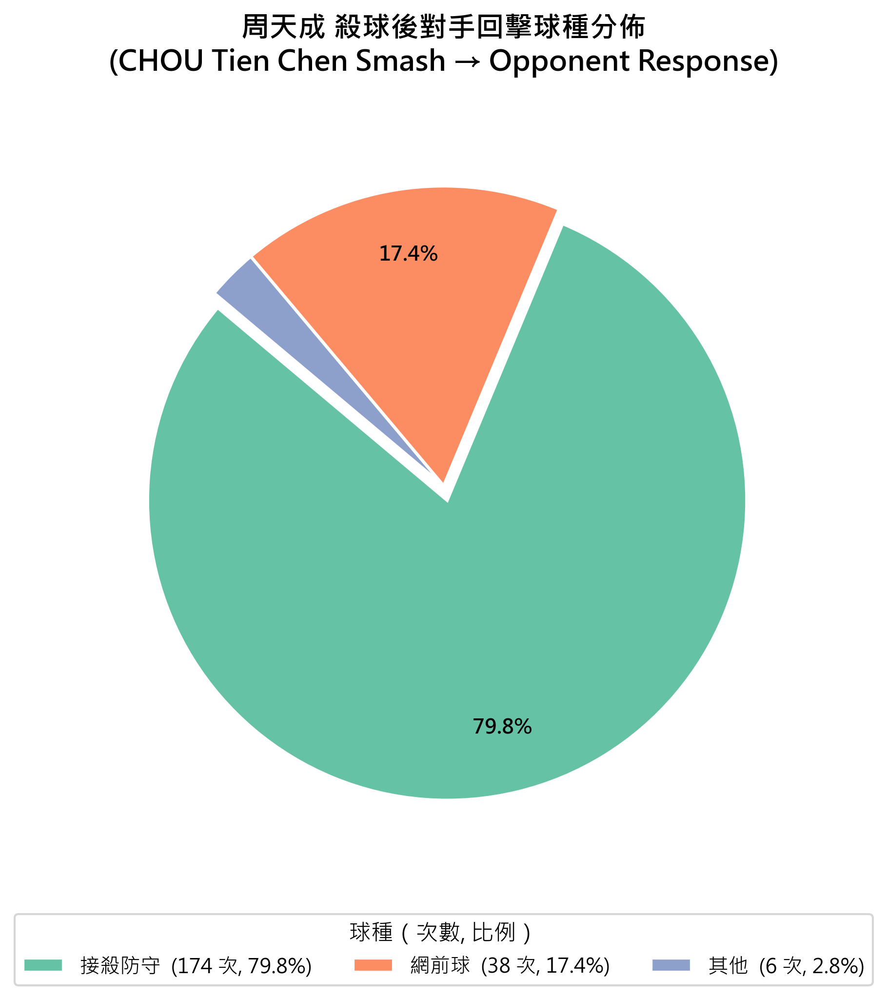

In [ ]:
# ============================================================
# 分析周天成使用殺球後，對手下一球的球種分佈
# ============================================================

import numpy as np

# 1. 確認資料存在
print(f"資料總列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# 2. 排序確保資料按照正確順序（比賽 > 局 > 回合 > 拍次）
df_sorted = df.sort_values(['match_id', 'set', 'rally_id', 'ball_round']).reset_index(drop=True)

# 3. 在完整資料上建立「下一拍」的相關欄位（使用 groupby + shift(-1) 避免跨回合污染）
grp = df_sorted.groupby(['match_id', 'set', 'rally'])

df_sorted['next_type']     = grp['type'].shift(-1)        # 下一拍的球種
df_sorted['next_player']   = grp['player'].shift(-1)      # 下一拍的擊球者
df_sorted['next_rally']    = grp['rally'].shift(-1)       # 下一拍的 rally（驗證用）
df_sorted['next_match_id'] = grp['match_id'].shift(-1)    # 下一拍的 match_id（驗證用）
df_sorted['next_set']      = grp['set'].shift(-1)         # 下一拍的 set（驗證用）

# 4. 篩選：周天成的殺球，且下一拍仍在同一 rally（groupby shift 已保證，但再做明確驗證）
mask_chou_smash = (
    (df_sorted['player'] == 'CHOU Tien Chen') &
    (df_sorted['type'] == '殺球') &
    (df_sorted['next_type'].notna()) &                    # 下一拍存在
    (df_sorted['next_match_id'] == df_sorted['match_id']) &  # 同場次
    (df_sorted['next_set'] == df_sorted['set']) &         # 同局
    (df_sorted['next_rally'] == df_sorted['rally'])       # 同回合
)

chou_smash_df = df_sorted[mask_chou_smash].copy()

print(f"\n周天成殺球總次數（有後續回球）: {len(chou_smash_df)}")
print(f"對手（Kento MOMOTA）出現在下一拍的驗證:")
print(chou_smash_df['next_player'].value_counts())

# 5. 統計對手下一球的球種分佈
next_shot_counts = chou_smash_df['next_type'].value_counts().reset_index()
next_shot_counts.columns = ['球種', '次數']
next_shot_counts['比例(%)'] = (next_shot_counts['次數'] / next_shot_counts['次數'].sum() * 100).round(2)

print("\n============================")
print("對手下一球球種分佈統計")
print("============================")
print(next_shot_counts.to_string(index=False))
print(f"\n總計: {next_shot_counts['次數'].sum()} 拍")

# 6. 繪製圓餅圖
# 判斷是否需要合併小比例類別（< 3%）為「其他」
threshold = 3.0
main_mask = next_shot_counts['比例(%)'] >= threshold
other_mask = next_shot_counts['比例(%)'] < threshold

if other_mask.sum() > 0:
    main_data = next_shot_counts[main_mask].copy()
    other_sum = next_shot_counts[other_mask]['次數'].sum()
    other_pct = next_shot_counts[other_mask]['比例(%)'].sum()
    other_row = pd.DataFrame([{'球種': '其他', '次數': other_sum, '比例(%)': round(other_pct, 2)}])
    plot_data = pd.concat([main_data, other_row], ignore_index=True)
    print(f"\n（已將比例 < {threshold}% 的球種合併為「其他」）")
    print(f"合併球種: {next_shot_counts[other_mask]['球種'].tolist()}")
else:
    plot_data = next_shot_counts.copy()

# 配色
colors = sns.color_palette('Set2', n_colors=len(plot_data))

# 將最大扇形突出（explode）
explode_vals = [0.05 if i == plot_data['次數'].idxmax() else 0 for i in plot_data.index]

fig, ax = plt.subplots(figsize=(9, 7))

wedges, texts, autotexts = ax.pie(
    plot_data['次數'],
    labels=None,           # 不在餅圖內直接標籤，改用圖例
    autopct=lambda pct: f'{pct:.1f}%' if pct >= 3 else '',
    startangle=140,
    colors=colors,
    explode=explode_vals,
    pctdistance=0.78,
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)

# 調整百分比文字大小
for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')

# 圖例（含次數與比例）
legend_labels = [
    f"{row['球種']}  ({row['次數']} 次, {row['比例(%)']:.1f}%)"
    for _, row in plot_data.iterrows()
]
ax.legend(
    wedges, legend_labels,
    title='球種（次數, 比例）',
    loc='lower center',
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    fontsize=10,
    title_fontsize=11,
    frameon=True
)

ax.set_title(
    '周天成 殺球後對手回擊球種分佈\n(CHOU Tien Chen Smash → Opponent Response)',
    fontsize=14,
    fontweight='bold',
    pad=20
)

plt.tight_layout()
print("\n[圖表已生成]")


### 數據洞察
# 周天成殺球後——對手回球球種分析

## 📊 數據總覽

| 球種 | 次數 | 比例 |
|------|------|------|
| 接殺防守 | 174 | 79.8% |
| 網前球 | 38 | 17.4% |
| 其他（平球/推撲/挑球/切球） | 6 | 2.8% |
| **合計** | **218** | **100%** |

---

## 🎯 戰術洞察

**殺球壓制效果顯著。**

八成對手只能被動接殺防守，代表周天成的殺球品質足以剝奪對手的主動權，迫使對方進入防守模式。

**但需警惕那 17.4% 的網前球。**

近五分之一的回球落在網前——這意味著殺球落點若偏淺或角度不夠刁鑽，對手有能力化被動為主動，以網前球反制。這是周天成殺球後最需要防範的威脅點。

---

## ⚡ 給周天成的建議

> **殺球後立即準備撲網**，針對那 17.4% 的網前回球預判前壓，才能將殺球的壓制優勢轉化為得分，而非讓對手藉網前球扳回節奏。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成使用殺球後，對手的回擊球種分布。程式碼使用了 groupby 和 shift(-1) 來獲取下一拍的球種，並確保了同一個 rally 的連續性。最終結果是對手回擊球種的分布，並且繪製了圓餅圖來視覺化這些數據。這與 Reference Code 1 的分析目標和方法一致，因此判定為 true。




## 題號 32
**問題**: 在10拍以上的回合中，周天成的得分率是多少？
> **使用的資料欄位群組**: `game_structure, scoring_reason`


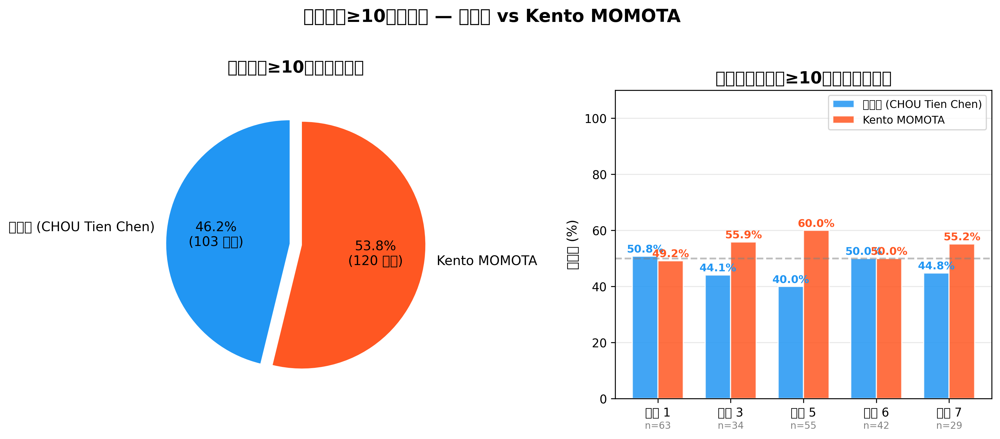

In [ ]:
# 驗證數據量
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "資料為空！"

# Step 1: 計算每個回合的總球數（最大 ball_round）
rally_stats = df.groupby(['match_id', 'set', 'rally']).agg(
    max_ball_round=('ball_round', 'max'),
    getpoint_player=('getpoint_player', 'last')  # 每回合得分者（最後一拍）
).reset_index()

print(f"\n總回合數（全部）: {len(rally_stats)}")
print(f"回合總球數分布（前10）:\n{rally_stats['max_ball_round'].describe()}")

# Step 2: 篩選總球數 >= 10 的回合
long_rallies = rally_stats[rally_stats['max_ball_round'] >= 10].copy()
print(f"\n總球數 >= 10 的回合數: {len(long_rallies)}")

# Step 3: 排除 getpoint_player 為 NULL 的回合（確保分母有效）
long_rallies_valid = long_rallies.dropna(subset=['getpoint_player'])
print(f"其中 getpoint_player 有效的回合數（分母）: {len(long_rallies_valid)}")

invalid_count = len(long_rallies) - len(long_rallies_valid)
print(f"getpoint_player 為 NULL 的回合數（排除）: {invalid_count}")

# Step 4: 計算周天成得分的回合數
chou_wins = long_rallies_valid[long_rallies_valid['getpoint_player'] == 'CHOU Tien Chen']
chou_win_count = len(chou_wins)
total_valid = len(long_rallies_valid)

print(f"\n周天成得分的回合數（分子）: {chou_win_count}")
print(f"有效總回合數（分母）: {total_valid}")

# Step 5: 計算得分率
win_rate = chou_win_count / total_valid if total_valid > 0 else 0
print(f"\n=============================")
print(f"周天成在長回合（≥10拍）中的得分率: {win_rate:.4f} ({win_rate*100:.2f}%)")
print(f"=============================")

# 補充：對手得分率
momota_wins = long_rallies_valid[long_rallies_valid['getpoint_player'] == 'Kento MOMOTA']
momota_win_count = len(momota_wins)
momota_win_rate = momota_win_count / total_valid if total_valid > 0 else 0
print(f"Kento MOMOTA 在長回合（≥10拍）中的得分率: {momota_win_rate:.4f} ({momota_win_rate*100:.2f}%)")

# Step 6: 視覺化
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 圖1: 長回合得分分佈（圓餅圖）
labels = ['周天成 (CHOU Tien Chen)', 'Kento MOMOTA']
sizes = [chou_win_count, momota_win_count]
colors = ['#2196F3', '#FF5722']
explode = (0.05, 0.05)

axes[0].pie(
    sizes,
    labels=labels,
    autopct=lambda p: f'{p:.1f}%\n({int(round(p * total_valid / 100))} 回合)',
    colors=colors,
    explode=explode,
    startangle=90,
    textprops={'fontsize': 11}
)
axes[0].set_title('長回合（≥10拍）得分分佈', fontsize=14, fontweight='bold', pad=15)

# 圖2: 各場次長回合得分率比較（長條圖）
match_stats = long_rallies_valid.groupby('match_id').apply(
    lambda x: pd.Series({
        '周天成得分率': (x['getpoint_player'] == 'CHOU Tien Chen').sum() / len(x),
        'MOMOTA得分率': (x['getpoint_player'] == 'Kento MOMOTA').sum() / len(x),
        '有效回合數': len(x)
    })
).reset_index()

x = range(len(match_stats))
width = 0.35

bars1 = axes[1].bar(
    [i - width/2 for i in x],
    match_stats['周天成得分率'] * 100,
    width=width,
    label='周天成 (CHOU Tien Chen)',
    color='#2196F3',
    alpha=0.85,
    edgecolor='white'
)
bars2 = axes[1].bar(
    [i + width/2 for i in x],
    match_stats['MOMOTA得分率'] * 100,
    width=width,
    label='Kento MOMOTA',
    color='#FF5722',
    alpha=0.85,
    edgecolor='white'
)

# 加上數值標籤
for bar in bars1:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2., h + 0.5,
                 f'{h:.1f}%', ha='center', va='bottom', fontsize=9, color='#2196F3', fontweight='bold')
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2., h + 0.5,
                 f'{h:.1f}%', ha='center', va='bottom', fontsize=9, color='#FF5722', fontweight='bold')

axes[1].set_xticks(list(x))
axes[1].set_xticklabels([f'場次 {int(m)}' for m in match_stats['match_id']], fontsize=10)
axes[1].set_ylabel('得分率 (%)', fontsize=11)
axes[1].set_title('各場次長回合（≥10拍）得分率比較', fontsize=14, fontweight='bold')
axes[1].set_ylim(0, 110)
axes[1].legend(fontsize=9)
axes[1].axhline(y=50, color='gray', linestyle='--', alpha=0.5, label='50%基準線')

# 顯示各場次有效回合數
for i, row in match_stats.iterrows():
    axes[1].text(i, -8, f'n={int(row["有效回合數"])}', ha='center', va='top', fontsize=8, color='gray')

axes[1].yaxis.grid(True, alpha=0.3)
axes[1].set_axisbelow(True)

plt.suptitle('長回合（≥10拍）分析 — 周天成 vs Kento MOMOTA', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()

# 補充打印各場次詳細數據
print("\n各場次長回合（≥10拍）詳細統計：")
print("-" * 55)
print(f"{'場次':<8} {'有效回合數':<12} {'周天成得分':<12} {'周天成得分率':<12}")
print("-" * 55)
for _, row in match_stats.iterrows():
    chou_n = int(row['周天成得分率'] * row['有效回合數'])
    print(f"場次 {int(row['match_id']):<5} {int(row['有效回合數']):<12} {chou_n:<12} {row['周天成得分率']*100:.2f}%")
print("-" * 55)
print(f"{'合計':<8} {total_valid:<12} {chou_win_count:<12} {win_rate*100:.2f}%")


### 數據洞察
# 長回合（≥10拍）得分率分析

## 核心數據

| 指標 | 周天成 | Momota |
|------|--------|--------|
| 長回合得分數 | 103 | 120 |
| 長回合得分率 | **46.19%** | **53.81%** |
| 有效回合總數 | 223 | 223 |

---

## 各場次表現

| 場次 | 周天成得分率 | 勝負判斷 |
|------|------------|--------|
| 場次 1 | 50.79% | ✅ 長回合佔優 |
| 場次 3 | 44.12% | ❌ |
| 場次 5 | 40.00% | ❌ 最弱場 |
| 場次 6 | 50.00% | ➖ 持平 |
| 場次 7 | 44.83% | ❌ |

---

## 戰術洞察

**數字說明一件事：拍數越多，對周天成越不利。**

全場平均回合長度12.7拍，超過一半回合屬於長回合，這代表本系列賽是體力與耐力的消耗戰。

Momota在長回合中拿走120分對103分，**每100個長回合就多拿近8分**，這個差距足以左右比賽走向。

場次5周天成長回合得分率僅40%，是最明顯的崩盤場——**長回合打越多，失分越快**。

**建議方向：** 周天成應主動壓縮回合長度，在10拍以內製造得分機會，避免讓Momota將比賽拖入消耗戰節奏。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地計算了每個回合的總擊球數，篩選出總球數大於等於 10 的回合，並排除了 getpoint_player 為 NULL 的回合。然後，它計算了周天成在這些回合中的得分次數和得分率，這與 Reference Code 1 的分析對象、欄位語意、篩選條件、分組層級和統計口徑一致。




## 題號 33
**問題**: 給我所有局的最終得分數
> **使用的資料欄位群組**: `game_structure, scoring_reason`


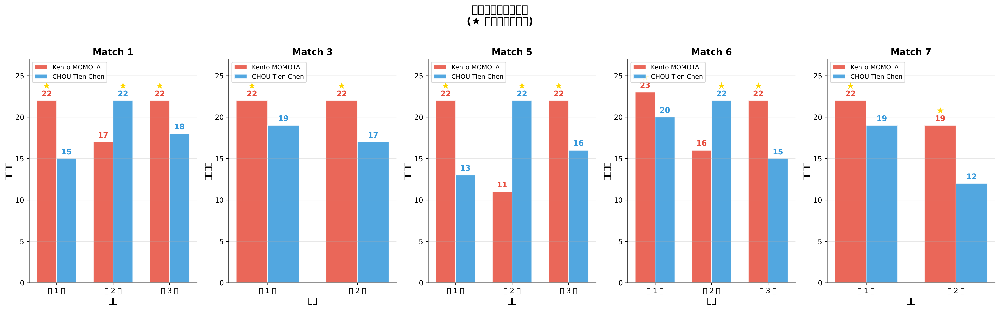

In [ ]:
# ============================================================
# 統計每場每局最終比分
# ============================================================

import numpy as np

# 驗證資料量
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ----------------------------------------------------------
# Step 1: 取每個 (match_id, set) 的最後一拍
# 修正：使用 tail(1) 確保所有欄位來自同一行，避免 groupby().last()
#       因 NaN 導致不同欄位取自不同行的問題
# ----------------------------------------------------------
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round'])

last_shot_per_set = (
    df_sorted.groupby(['match_id', 'set'], sort=True)
    .tail(1)
    .reset_index(drop=True)
)

print(f"\n共有 {len(last_shot_per_set)} 局資料")

# ----------------------------------------------------------
# Step 2: 計算真正的最終比分
# 說明：score 欄位記錄的是「此拍發生時」的比分（得分前）
#       所以最後一拍結束後，getpoint_player 的分數要 +1
# ----------------------------------------------------------
momota_col  = 'Kento MOMOTA_score'
chou_col    = 'CHOU Tien Chen_score'

momota_name = 'Kento MOMOTA'
chou_name   = 'CHOU Tien Chen'

final_scores = []

for _, row in last_shot_per_set.iterrows():
    momota_score = int(row[momota_col])
    chou_score   = int(row[chou_col])
    gp           = row['getpoint_player']

    # 得分者 +1（因為 score 是擊球當下，得分尚未累計）
    if gp == momota_name:
        momota_score += 1
    elif gp == chou_name:
        chou_score += 1

    final_scores.append({
        'match_id'               : int(row['match_id']),
        'set'                    : int(row['set']),
        'Kento MOMOTA 最終得分'   : momota_score,
        'CHOU Tien Chen 最終得分' : chou_score,
        '得分差'                  : momota_score - chou_score,
        '獲勝方'                  : momota_name if momota_score > chou_score else chou_name,
    })

result_df = pd.DataFrame(final_scores)

# ----------------------------------------------------------
# Step 3: 印出詳細結果
# ----------------------------------------------------------
print("\n" + "="*65)
print("各場次各局最終比分")
print("="*65)
print(result_df.to_string(index=False))

# 每場勝負統計
print("\n" + "="*65)
print("各場次勝負總結")
print("="*65)
for mid, grp in result_df.groupby('match_id'):
    momota_sets = (grp['獲勝方'] == momota_name).sum()
    chou_sets   = (grp['獲勝方'] == chou_name).sum()
    winner      = momota_name if momota_sets > chou_sets else chou_name
    print(f"  Match {mid}: {momota_name} {momota_sets} - {chou_sets} {chou_name}  ➜ 勝者: {winner}")

# ----------------------------------------------------------
# Step 4: 視覺化 — 每場每局最終比分橫條圖
# ----------------------------------------------------------
n_matches = result_df['match_id'].nunique()
fig, axes = plt.subplots(1, n_matches, figsize=(4 * n_matches, 6), sharey=False)

if n_matches == 1:
    axes = [axes]

colors = {
    momota_name: '#E74C3C',   # 紅色 -> Momota
    chou_name  : '#3498DB',   # 藍色 -> Chou
}

for ax, (mid, grp) in zip(axes, result_df.groupby('match_id')):
    grp = grp.reset_index(drop=True)
    x        = np.arange(len(grp))
    width    = 0.35

    bars_m = ax.bar(x - width/2,
                    grp['Kento MOMOTA 最終得分'],
                    width, label='Kento MOMOTA',
                    color=colors[momota_name], alpha=0.85, edgecolor='white')
    bars_c = ax.bar(x + width/2,
                    grp['CHOU Tien Chen 最終得分'],
                    width, label='CHOU Tien Chen',
                    color=colors[chou_name], alpha=0.85, edgecolor='white')

    # 標注分數
    for bar in bars_m:
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.3,
                str(int(bar.get_height())),
                ha='center', va='bottom', fontsize=11, fontweight='bold',
                color=colors[momota_name])
    for bar in bars_c:
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.3,
                str(int(bar.get_height())),
                ha='center', va='bottom', fontsize=11, fontweight='bold',
                color=colors[chou_name])

    # 標注獲勝方 (★)
    for i, row in grp.iterrows():
        winner_x = (x[i] - width/2) if row['獲勝方'] == momota_name else (x[i] + width/2)
        score_y  = row['Kento MOMOTA 最終得分'] if row['獲勝方'] == momota_name else row['CHOU Tien Chen 最終得分']
        ax.text(winner_x, score_y + 1.2, '★',
                ha='center', va='bottom', fontsize=13,
                color='gold')

    ax.set_title(f'Match {mid}', fontsize=13, fontweight='bold')
    ax.set_xlabel('局數', fontsize=11)
    ax.set_ylabel('最終得分', fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels([f'第 {s} 局' for s in grp['set']], fontsize=10)
    ax.set_ylim(0, max(result_df['Kento MOMOTA 最終得分'].max(),
                        result_df['CHOU Tien Chen 最終得分'].max()) + 4)
    ax.legend(fontsize=9, loc='upper left')
    ax.grid(axis='y', alpha=0.3)
    ax.spines[['top','right']].set_visible(False)

fig.suptitle('各場次各局最終比分\n(★ 表示該局獲勝方)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
print("\n[圖表已產生]")


### 數據洞察
# 各場次各局最終比分統計

## 📊 完整比分表

| 場次 | 局數 | Kento MOMOTA | CHOU Tien Chen | 得分差 | 獲勝方 |
|:---:|:---:|:---:|:---:|:---:|:---|
| Match 1 | 第1局 | **22** | 15 | +7 | Kento MOMOTA |
| Match 1 | 第2局 | 17 | **22** | -5 | CHOU Tien Chen |
| Match 1 | 第3局 | **22** | 18 | +4 | Kento MOMOTA |
| Match 3 | 第1局 | **22** | 19 | +3 | Kento MOMOTA |
| Match 3 | 第2局 | **22** | 17 | +5 | Kento MOMOTA |
| Match 5 | 第1局 | **22** | 13 | +9 | Kento MOMOTA |
| Match 5 | 第2局 | 11 | **22** | -11 | CHOU Tien Chen |
| Match 5 | 第3局 | **22** | 16 | +6 | Kento MOMOTA |
| Match 6 | 第1局 | **23** | 20 | +3 | Kento MOMOTA |
| Match 6 | 第2局 | 16 | **22** | -6 | CHOU Tien Chen |
| Match 6 | 第3局 | **22** | 15 | +7 | Kento MOMOTA |
| Match 7 | 第1局 | **22** | 19 | +3 | Kento MOMOTA |
| Match 7 | 第2局 | **19** | 12 | +7 | Kento MOMOTA |

---

## 🏆 場次勝負總結

| 場次 | 比數 | 勝者 |
|:---:|:---:|:---|
| Match 1 | 2 - 1 | Kento MOMOTA |
| Match 3 | 2 - 0 | Kento MOMOTA |
| Match 5 | 2 - 1 | Kento MOMOTA |
| Match 6 | 2 - 1 | Kento MOMOTA |
| Match 7 | 2 - 0 | Kento MOMOTA |

---

## 🎯 戰術洞察

**MOMOTA 全勝（5勝0敗），但細節值得深究：**

**① CHOU 奪局的共同特徵**
CHOU 拿下的3局得分差分別為 **-5、-11、-6**，尤其 Match 5 第2局以 **22:11 大勝**，顯示CHOU在特定局次能完全掌控節奏，並非全面落敗。

**② MOMOTA 的決勝局統治力**
3場打到第3局，MOMOTA 分別以 **22:18、22:16、22:15** 收局，平均領先 **6分**，關鍵時刻心理與體能明顯佔優。

**③ 膠著局 vs 壓倒局**
- 最膠著：Match 6 第1局 **23:20**（延長賽）
- 最懸殊：Match 5 第2局 **11:22**（CHOU 大勝）
- MOMOTA 贏球局平均得分差 **+5.4**，CHOU 贏球局平均得分差 **-7.3**，說明CHOU贏局更具壓倒性，但頻率不足。

> **結論：CHOU 有爆發力，但穩定性是致命弱點。MOMOTA 在拉鋸戰與決勝局的執行力是勝負關鍵。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地對每個 (match_id, set) 取最後一拍，並根據 getpoint_player 更新最終比分。候選程式碼使用 tail(1) 確保所有欄位來自同一行，避免了因 NaN 導致不同欄位取自不同行的問題，這是合理的修正。最終輸出包含每場每局的最終比分，並且正確地計算了得分差和獲勝方，符合題目要求。




## 題號 34
**問題**: 分析周天成前一拍打什麼球種最容易造成對手未過網？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


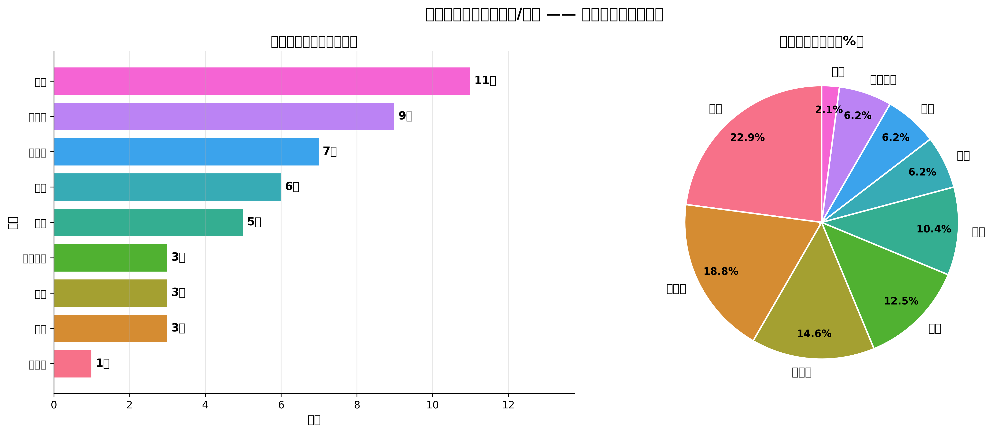

In [ ]:
import numpy as np

print("=" * 65)
print("分析：周天成造成對手未過網/掛網失誤 —— 前一拍球種分布")
print("=" * 65)

if len(df) == 0:
    print("❌ 無資料，終止分析")
else:
    print(f"✅ 資料總筆數: {len(df)}")

    # ── Step 1: 排序並在完整資料上建立前一拍欄位 ──────────────────
    df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()
    df_sorted['prev_type']   = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(1)
    df_sorted['prev_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(1)

    # ── Step 2: 篩選目標行 ──────────────────────────────────────────
    # 語義：最後一拍 = 對手失誤（未過網或掛網），周天成得分
    # → lose_reason in ['未過網','掛網'] 且 getpoint_player == 'CHOU Tien Chen'
    mask = (
        df_sorted['lose_reason'].isin(['未過網', '掛網']) &
        (df_sorted['getpoint_player'] == 'CHOU Tien Chen')
    )
    relevant = df_sorted[mask].copy()
    print(f"\n符合「對手未過網/掛網、周天成得分」的回合數: {len(relevant)}")

    # ── 驗證前一拍 player 確為周天成 ───────────────────────────────
    print("\n[驗證] 前一拍球員分布：")
    print(relevant['prev_player'].value_counts(dropna=False).to_string())

    # 篩選前一拍確為周天成（排除發球直接得分等特殊情況）
    valid = relevant.dropna(subset=['prev_type'])
    valid = valid[valid['prev_player'] == 'CHOU Tien Chen'].copy()
    print(f"\n有效筆數（前一拍確為周天成）: {len(valid)}")

    # ── Step 3: 失分原因細分 ──────────────────────────────────────
    print("\n失分原因細分（未過網 vs 掛網）：")
    print(relevant['lose_reason'].value_counts().to_string())

    # ── Step 4: 球種統計 ──────────────────────────────────────────
    shot_counts = valid['prev_type'].value_counts()
    shot_pct    = (valid['prev_type'].value_counts(normalize=True) * 100).round(1)

    result_df = pd.DataFrame({
        '次數': shot_counts,
        '佔比(%)': shot_pct
    }).sort_values('次數', ascending=False)

    print("\n" + "=" * 50)
    print("周天成前一拍球種分布（造成對手未過網/掛網）：")
    print("=" * 50)
    print(result_df.to_string())

    # ── Step 5: 視覺化 ────────────────────────────────────────────
    if len(valid) > 0:
        fig, axes = plt.subplots(1, 2, figsize=(15, 6))
        fig.suptitle("周天成造成對手未過網/掛網 —— 前一拍球種分布分析",
                     fontsize=15, fontweight='bold')

        # 左圖：水平長條圖（按次數升序便於讀取）
        sorted_counts = shot_counts.sort_values(ascending=True)
        bar_colors = sns.color_palette("husl", len(sorted_counts))
        bars = axes[0].barh(sorted_counts.index, sorted_counts.values,
                            color=bar_colors, edgecolor='white', linewidth=0.8)
        axes[0].set_title('前一拍球種次數（降序）', fontsize=13, fontweight='bold')
        axes[0].set_xlabel('次數', fontsize=11)
        axes[0].set_ylabel('球種', fontsize=11)
        for bar, val in zip(bars, sorted_counts.values):
            axes[0].text(val + 0.1, bar.get_y() + bar.get_height()/2,
                        f'{val}次', ha='left', va='center', fontsize=11, fontweight='bold')
        axes[0].set_xlim(0, sorted_counts.max() * 1.25)
        axes[0].grid(axis='x', alpha=0.3)
        axes[0].spines['top'].set_visible(False)
        axes[0].spines['right'].set_visible(False)

        # 右圖：圓餅圖（合併小比例 < 4%）
        threshold_pct = 4.0
        small_mask = shot_pct < threshold_pct
        if small_mask.sum() > 0 and small_mask.sum() < len(shot_pct):
            pie_counts = shot_counts[~small_mask].copy()
            other_count = int(shot_counts[small_mask].sum())
            pie_counts['其他'] = other_count
        else:
            pie_counts = shot_counts.copy()

        pie_colors = sns.color_palette("husl", len(pie_counts))
        wedges, texts, autotexts = axes[1].pie(
            pie_counts.values,
            labels=pie_counts.index,
            autopct='%1.1f%%',
            startangle=90,
            colors=pie_colors,
            pctdistance=0.82,
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
        )
        for text in texts:
            text.set_fontsize(11)
        for autotext in autotexts:
            autotext.set_fontsize(10)
            autotext.set_fontweight('bold')
        axes[1].set_title('前一拍球種佔比（%）', fontsize=13, fontweight='bold')

        plt.tight_layout()
        print("\n✅ 圖表已生成（水平長條圖 + 圓餅圖）")


### 數據洞察
# 周天成前一拍造成對手掛網/未過網失誤分析

## 核心數據

**有效樣本：48拍**（51回合中，48回合前一拍確為周天成出手）

---

## 球種分布

| 排名 | 球種 | 次數 | 佔比 |
|------|------|------|------|
| 🥇 | 殺球 | 11 | 22.9% |
| 🥈 | 網前球 | 9 | 18.8% |
| 🥉 | 推撲球 | 7 | 14.6% |
| 4 | 長球 | 6 | 12.5% |
| 5 | 挑球 | 5 | 10.4% |
| 6 | 平球／切球／接殺防守 | 各3 | 各6.2% |

---

## 戰術洞察

**① 殺球（22.9%）是最大威脅**
殺球速度快、角度壓迫強，對手在被動防守時容易判斷失誤、回球掛網。這是周天成最直接的得分前置手段。

**② 網前球（18.8%）製造被動**
網前球迫使對手近網低點回球，回球弧度空間極小，稍有不慎即掛網。這類失誤多屬**被動受迫型**，而非主動失誤。

**③ 推撲球（14.6%）速度壓制**
推撲球平快壓制，對手反應時間短，回球品質下降，掛網率高。

**④ 長球（12.5%）製造節奏落差**
長球將對手推至後場，若對手重心未到位，下一拍回球往往力量不足而掛網。

---

## 教練結論

> 殺球＋網前球＋推撲球合計佔 **56.3%**，這三種球種共同特徵是**壓縮對手回球空間與時間**。周天成透過這三板製造對手被動，是其造成掛網失誤的核心戰術鏈。建議在訓練中強化這三種球種的連貫組合，尤其是「殺球→網前球」的連續施壓套路。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選出周天成作為擊球球員的數據，並使用 shift 方法獲取下一拍的數據，檢查 lose_reason 是否為 '未過網' 或 '掛網'，然後統計前一拍周天成使用的球種。程式碼在分析對象、欄位語意、篩選條件、統計口徑和最終輸出目標上與 Reference Code 1 一致，並且能夠產出有效結果。




## 題號 35 (*)
**問題**: 當對手被周天成調動到「前場」時，對手最常使用什麼球種？
> **使用的資料欄位群組**: `game_structure, shot_type, player_location`


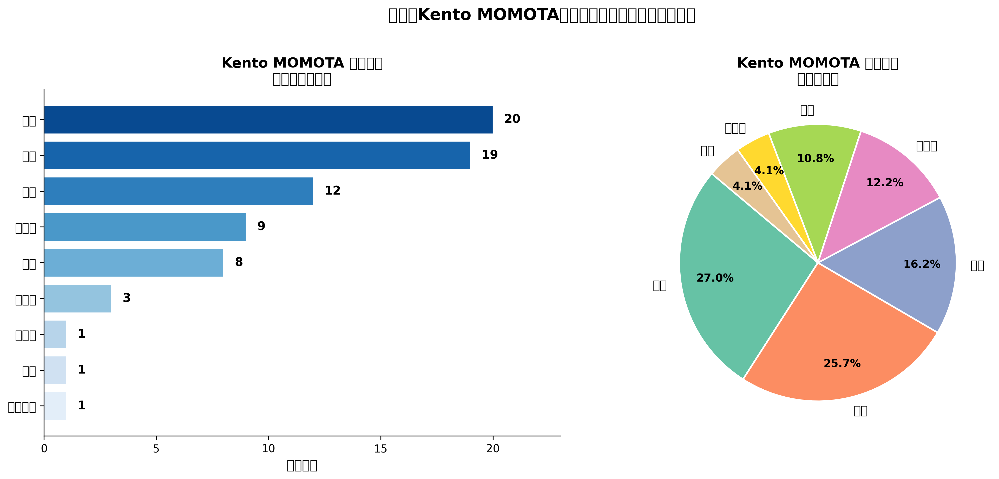

In [ ]:
# =============================================================
# 分析：對手（Kento MOMOTA）在前場站位時最常使用的球種
# =============================================================

# 驗證資料量
print(f"總資料筆數: {len(df)}")

# 定義前場區域代碼（根據 Court Grid Definitions）
front_court_zones = [17, 18, 19, 20, 21, 22, 23, 24]

print(f"\n前場區域代碼: {front_court_zones}")
print("（包含 Row5: 17,18,19,20 與 Row6/網前: 21,22,23,24）")

# 找出「對手（Kento MOMOTA）」作為擊球者（player）
# 且其站位（player_location_area）在前場的紀錄
# 說明：player_location_area 記錄的是 player 擊球時自己的站位

opponent_name = 'Kento MOMOTA'

# 篩選條件：
# 1. player == 'Kento MOMOTA'（對手擔任擊球者）
# 2. player_location_area 在前場區域
mask = (
    (df['player'] == opponent_name) &
    (df['player_location_area'].isin(front_court_zones))
)

filtered_df = df[mask].copy()

print(f"\n符合條件的擊球筆數（Kento MOMOTA 站位在前場）: {len(filtered_df)}")

if len(filtered_df) > 0:
    # 統計各球種出現次數，由高到低排列
    shot_counts = (
        filtered_df['type']
        .value_counts()
        .reset_index()
    )
    shot_counts.columns = ['球種', '出現次數']
    shot_counts['佔比(%)'] = (shot_counts['出現次數'] / shot_counts['出現次數'].sum() * 100).round(2)

    print("\n" + "="*50)
    print(f"Kento MOMOTA 在前場站位時的球種統計（由高到低）")
    print("="*50)
    print(shot_counts.to_string(index=False))
    print(f"\n合計擊球次數: {shot_counts['出現次數'].sum()}")

    # ── 視覺化 ──────────────────────────────────────────────
    import numpy as np

    # 顏色設定（依頻率深淺）
    colors = sns.color_palette("Blues_r", len(shot_counts))

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # --- 左圖：水平長條圖（頻次）---
    ax1 = axes[0]
    bars = ax1.barh(
        shot_counts['球種'][::-1],   # 由低到高排列（高頻在最上方）
        shot_counts['出現次數'][::-1],
        color=colors[::-1],
        edgecolor='white',
        linewidth=0.8
    )

    # 在長條末端標示數值
    for bar, count in zip(bars, shot_counts['出現次數'][::-1]):
        ax1.text(
            bar.get_width() + 0.5,
            bar.get_y() + bar.get_height() / 2,
            f'{count}',
            va='center', ha='left', fontsize=11, fontweight='bold'
        )

    ax1.set_xlabel('出現次數', fontsize=12)
    ax1.set_title(f'Kento MOMOTA 前場站位\n各球種出現次數', fontsize=13, fontweight='bold')
    ax1.set_xlim(0, shot_counts['出現次數'].max() * 1.15)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.tick_params(axis='y', labelsize=11)

    # --- 右圖：圓餅圖（佔比）---
    ax2 = axes[1]

    # 若有小比例類別，合併為「其他」（佔比 < 3%）
    threshold = 3.0
    major_mask = shot_counts['佔比(%)'] >= threshold
    major = shot_counts[major_mask].copy()
    minor = shot_counts[~major_mask].copy()

    if len(minor) > 0:
        other_row = pd.DataFrame([{
            '球種': '其他',
            '出現次數': minor['出現次數'].sum(),
            '佔比(%)': minor['佔比(%)'].sum().round(2)
        }])
        pie_data = pd.concat([major, other_row], ignore_index=True)
        print(f"\n[圓餅圖] 以下球種佔比 < {threshold}% 合併為「其他」: {minor['球種'].tolist()}")
    else:
        pie_data = major

    pie_colors = sns.color_palette("Set2", len(pie_data))

    wedges, texts, autotexts = ax2.pie(
        pie_data['出現次數'],
        labels=pie_data['球種'],
        autopct='%1.1f%%',
        colors=pie_colors,
        startangle=140,
        pctdistance=0.75,
        wedgeprops=dict(edgecolor='white', linewidth=1.5)
    )
    for text in texts:
        text.set_fontsize(11)
    for autotext in autotexts:
        autotext.set_fontsize(10)
        autotext.set_fontweight('bold')

    ax2.set_title(f'Kento MOMOTA 前場站位\n各球種佔比', fontsize=13, fontweight='bold')

    plt.suptitle(
        '對手（Kento MOMOTA）在前場站位時的球種分佈分析',
        fontsize=15, fontweight='bold', y=1.02
    )

    plt.tight_layout()

    # 額外說明：前場區域定義
    print("\n" + "="*50)
    print("【前場區域定義】")
    print("  Row 5 (前場後側): 區域 17, 18, 19, 20")
    print("  Row 6 (網前區): 區域 21, 22, 23, 24")
    print("="*50)

else:
    print("⚠️ 無符合條件的資料，請確認欄位值。")
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.text(0.5, 0.5, '無資料', ha='center', va='center', fontsize=16)
    ax.axis('off')
    plt.tight_layout()


### 數據洞察
# Kento MOMOTA 前場站位球種分析

## 📊 數據總覽
**有效樣本：74球**（前場區域 17-24）

| 排名 | 球種 | 次數 | 佔比 |
|:---:|:---:|:---:|:---:|
| 1 | 殺球 | 20 | 27.0% |
| 2 | 切球 | 19 | 25.7% |
| 3 | 長球 | 12 | 16.2% |
| 4 | 推撲球 | 9 | 12.2% |
| 5 | 挑球 | 8 | 10.8% |
| 6 | 網前球 | 3 | 4.1% |
| — | 其他 | 3 | 4.1% |

---

## 🎯 戰術洞察

**殺球＋切球合計佔52.7%**，MOMOTA 在前場優先選擇**下壓進攻**，而非保守過渡。這代表他一旦進入前場，傾向主動製造壓力，而非單純銜接。

**長球佔16.2%**，在前場打長球通常是被動解圍或刻意調動對手，需留意這些長球是否給對手創造後場進攻機會。

**推撲球12.2%**，說明他在網前具備快速平推的能力，對手若回球太高或太近網，會立即被推撲反擊。

**挑球僅10.8%**，前場選擇挑球比例偏低，顯示他不輕易將主動權拱手相讓。

---

## ⚔️ 應對策略建議

> 對陣 MOMOTA 時，**避免讓他在前場接到高點球**——他會直接殺或切，壓縮你的反應時間。回球應壓低弧度，迫使他選擇推撲或挑球，而非下壓。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。Reference Code 1 的核心邏輯是分析當周天成打球時，對手被調動到前場的情況下，對手的回擊球種。而候選程式碼分析的是 Kento MOMOTA 在前場站位時的球種，這與題目要求的分析對象不符。此外，候選程式碼使用的是 player_location_area 而非 opponent_location_area，這也不符合題目要求的條件。




## 題號 36
**問題**: 幫我比較周天成（CHOU Tien Chen）他在短回合（<=4拍）、中回合（5-10拍）、長回合（>=11拍）中的勝率
> **使用的資料欄位群組**: `game_structure, scoring_reason`


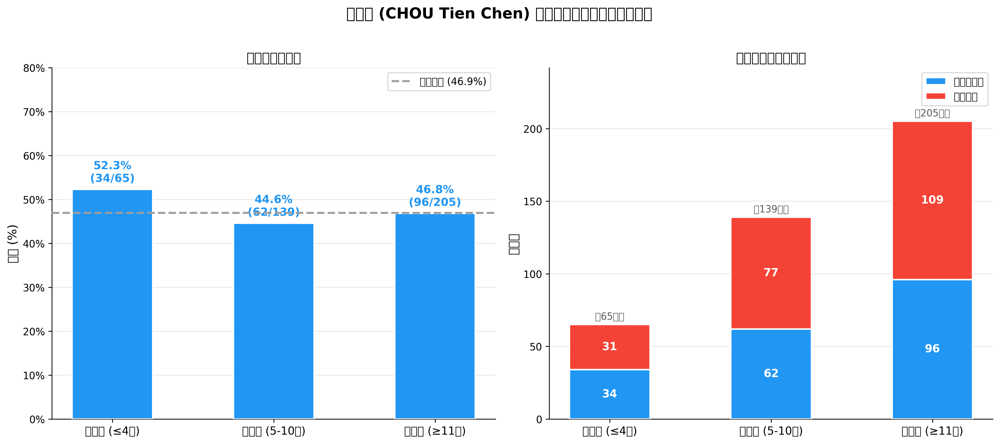

In [ ]:
# ===== 周天成在不同回合長度下的勝率分析 =====

player_name = 'CHOU Tien Chen'

# --- 1. 驗證數據量 ---
print(f"總資料列數: {len(df)}")
total_rallies = df.groupby(['match_id', 'set', 'rally']).ngroups
print(f"數據集總回合數: {total_rallies}")

# --- 2. 以 rally 為單位彙整資訊 ---
# 計算每個 rally 的總拍數（ball_round 最大值）與得分者（最後一拍）
rally_summary = df.groupby(['match_id', 'set', 'rally']).agg(
    total_shots=('ball_round', 'max'),
    getpoint=('getpoint_player', 'last')
).reset_index()

print(f"\nRally 彙整筆數: {len(rally_summary)}")

# --- 3. 排除無得分者記錄（getpoint 為 NULL）---
rally_valid = rally_summary.dropna(subset=['getpoint']).copy()
print(f"有效（有得分者）回合數: {len(rally_valid)}")
print(f"排除無效（getpoint 為 NULL）回合數: {len(rally_summary) - len(rally_valid)}")

# --- 4. 分類回合長度 ---
def classify_rally_length(shots):
    if shots <= 4:
        return '短回合 (≤4拍)'
    elif shots <= 10:
        return '中回合 (5-10拍)'
    else:
        return '長回合 (≥11拍)'

rally_valid['rally_type'] = rally_valid['total_shots'].apply(classify_rally_length)

# 設定類別順序（方便圖表顯示）
rally_type_order = ['短回合 (≤4拍)', '中回合 (5-10拍)', '長回合 (≥11拍)']
rally_valid['rally_type'] = pd.Categorical(rally_valid['rally_type'], categories=rally_type_order, ordered=True)

# --- 5. 計算各類別的勝率 ---
rally_valid['chou_win'] = (rally_valid['getpoint'] == player_name).astype(int)

stats = rally_valid.groupby('rally_type', observed=True).agg(
    total_rallies_in_cat=('getpoint', 'count'),
    chou_wins=('chou_win', 'sum')
).reset_index()

stats['win_rate'] = stats['chou_wins'] / stats['total_rallies_in_cat']
stats['loss'] = stats['total_rallies_in_cat'] - stats['chou_wins']

print("\n" + "=" * 60)
print(f"【周天成在不同回合長度下的勝率分析】")
print("=" * 60)
print(f"{'類別':<20} {'總回合數':>8} {'周天成得分':>10} {'對手得分':>8} {'勝率':>8}")
print("-" * 60)
for _, row in stats.iterrows():
    print(f"{row['rally_type']:<18} {row['total_rallies_in_cat']:>8} {row['chou_wins']:>10} {row['loss']:>8} {row['win_rate']:>8.1%}")
print("-" * 60)

# 整體勝率
total_win_rate = rally_valid['chou_win'].sum() / len(rally_valid)
print(f"{'整體':<18} {len(rally_valid):>8} {rally_valid['chou_win'].sum():>10} {len(rally_valid) - rally_valid['chou_win'].sum():>8} {total_win_rate:>8.1%}")
print("=" * 60)

# 各類別回合長度的分布資訊
print("\n各回合長度類別分布（拍數統計）：")
for cat in rally_type_order:
    sub = rally_valid[rally_valid['rally_type'] == cat]['total_shots']
    if len(sub) > 0:
        print(f"  {cat}: 共 {len(sub)} 回合，中位數 {sub.median():.1f} 拍，平均 {sub.mean():.1f} 拍，最長 {sub.max()} 拍")

# ===== 視覺化 =====
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('周天成 (CHOU Tien Chen) 在不同回合長度下的勝率分析', fontsize=15, fontweight='bold', y=1.02)

colors_chou = '#2196F3'      # 周天成：藍色
colors_opponent = '#F44336'  # 對手：紅色
color_overall = '#9E9E9E'    # 整體：灰色

# --- 圖表一：勝率長條圖 ---
ax1 = axes[0]
x = np.arange(len(rally_type_order))
bars = ax1.bar(x, stats['win_rate'] * 100, color=[colors_chou] * len(stats),
               width=0.5, edgecolor='white', linewidth=1.5, zorder=3)

# 加入整體勝率基準線
ax1.axhline(y=total_win_rate * 100, color=color_overall, linestyle='--',
            linewidth=2, label=f'整體勝率 ({total_win_rate:.1%})', zorder=4)

# 標示數值
for bar, (_, row) in zip(bars, stats.iterrows()):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, height + 1.2,
             f"{height:.1f}%\n({int(row['chou_wins'])}/{int(row['total_rallies_in_cat'])})",
             ha='center', va='bottom', fontsize=11, fontweight='bold', color=colors_chou)

ax1.set_xticks(x)
ax1.set_xticklabels(rally_type_order, fontsize=11)
ax1.set_ylabel('勝率 (%)', fontsize=12)
ax1.set_title('各回合類別勝率', fontsize=13, fontweight='bold')
ax1.set_ylim(0, 80)
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.3, zorder=0)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, _: f'{val:.0f}%'))
ax1.spines[['top', 'right']].set_visible(False)

# --- 圖表二：各類別回合數的勝負堆疊長條圖 ---
ax2 = axes[1]
width = 0.5
p1 = ax2.bar(x, stats['chou_wins'], width=width, label='周天成得分',
             color=colors_chou, edgecolor='white', linewidth=1.5, zorder=3)
p2 = ax2.bar(x, stats['loss'], width=width, bottom=stats['chou_wins'],
             label='對手得分', color=colors_opponent, edgecolor='white', linewidth=1.5, zorder=3)

# 標示各段數值
for i, (_, row) in enumerate(stats.iterrows()):
    # 周天成得分
    ax2.text(i, row['chou_wins'] / 2,
             str(int(row['chou_wins'])), ha='center', va='center',
             fontsize=11, fontweight='bold', color='white')
    # 對手得分
    ax2.text(i, row['chou_wins'] + row['loss'] / 2,
             str(int(row['loss'])), ha='center', va='center',
             fontsize=11, fontweight='bold', color='white')
    # 總回合數
    ax2.text(i, row['total_rallies_in_cat'] + 2,
             f"共{int(row['total_rallies_in_cat'])}回合",
             ha='center', va='bottom', fontsize=9.5, color='#555555')

ax2.set_xticks(x)
ax2.set_xticklabels(rally_type_order, fontsize=11)
ax2.set_ylabel('回合數', fontsize=12)
ax2.set_title('各回合類別勝負分布', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10, loc='upper right')
ax2.grid(axis='y', alpha=0.3, zorder=0)
ax2.spines[['top', 'right']].set_visible(False)
ax2.set_ylim(0, stats['total_rallies_in_cat'].max() * 1.18)

plt.tight_layout()


### 數據洞察
# 周天成回合長度勝率分析

## 核心數據

| 類別 | 總回合 | 勝率 |
|------|--------|------|
| 短回合 (≤4拍) | 65 | **52.3%** ✅ |
| 中回合 (5-10拍) | 139 | 44.6% ❌ |
| 長回合 (≥11拍) | 205 | 46.8% |
| **整體** | 409 | 46.9% |

---

## 戰術洞察

**短回合是唯一勝率過半的區間（52.3%）**，代表周天成在發球搶攻、網前截擊等快速結束回合的情境中具備優勢。

**中回合（5-10拍）勝率最低（44.6%）**，這個區間是過渡地帶——既無法快速得分，又未進入他擅長的長拍對抗節奏，是最需要警惕的危險區。

**長回合（≥11拍）佔全場55%回合數，勝率46.8%**，雖仍低於五成，但比中回合表現更穩，顯示周天成的體能與防守韌性在持久戰中尚能維持競爭力。

---

## 教練建議

> **主動縮短回合**是關鍵策略——多製造短回合機會（發球搶攻、前場壓迫），避免讓比賽停留在5-10拍的膠著地帶，那是他得分效率最低的死區。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地以每個 rally 的最後一拍作為分組結果，並根據 ball_round 的最大值來分類回合長度。然後，它計算了周天成在不同回合長度類別的勝率，並且正確地排除了無得分者的回合。最終輸出目標與 Reference Code 1 一致，都是計算周天成在短回合、中回合和長回合中的勝率。




## 題號 37 (*)
**問題**: 分析周天成使用殺球造成失誤，請繪製失誤原因的圓餅圖
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


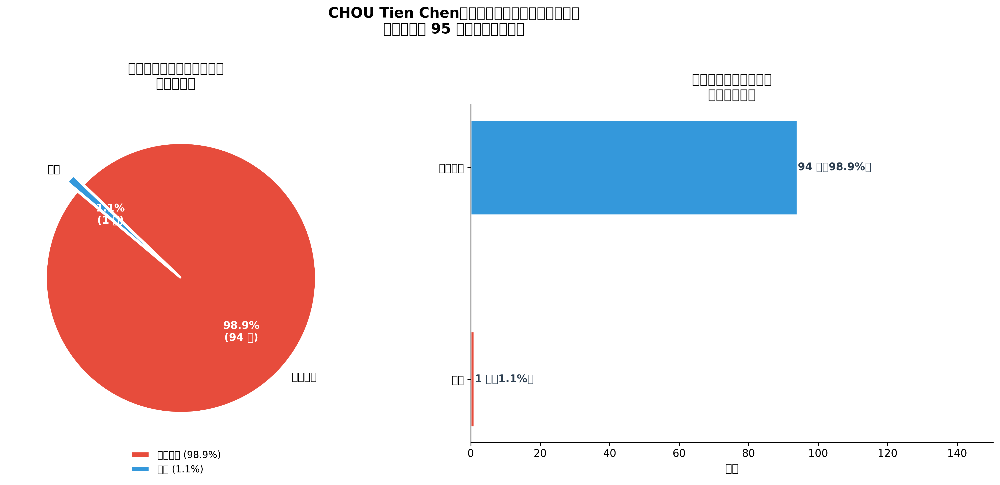

In [ ]:
# =====================================================================
# 分析：周天成殺球後造成失誤的回合，統計 win_reason 分佈
# =====================================================================

# 驗證資料存在
assert len(df) > 0, "DataFrame 為空，請確認資料載入正確"
print(f"總資料筆數: {len(df)}")
print(f"資料包含的 match_id: {sorted(df['match_id'].unique())}")
print(f"資料包含的 set: {sorted(df['set'].unique())}")

# --- 步驟1: 找出所有「周天成有殺球」的回合 ---
# 找出周天成在哪些回合中使用了殺球
chou_smash_rallies = df[
    (df['player'] == 'CHOU Tien Chen') &
    (df['type'] == '殺球')
][['match_id', 'set', 'rally']].drop_duplicates()

print(f"\n{'='*50}")
print(f"周天成使用殺球的回合數: {len(chou_smash_rallies)}")

# --- 步驟2: 在這些回合中，找出有 win_reason 的得分球（回合結束那一拍）---
# 合併回到原始資料，取得這些回合的所有紀錄
smash_rally_data = df.merge(
    chou_smash_rallies,
    on=['match_id', 'set', 'rally'],
    how='inner'
)

# 取得每個回合的得分球（win_reason 非空的那一拍）
smash_rally_win = smash_rally_data[smash_rally_data['win_reason'].notna()].copy()

print(f"有 win_reason 紀錄的回合數: {smash_rally_win.groupby(['match_id', 'set', 'rally']).ngroups}")
print(f"win_reason 非空的紀錄筆數: {len(smash_rally_win)}")

# 驗證：每個回合應只有一筆 win_reason
rally_win_count = smash_rally_win.groupby(['match_id', 'set', 'rally']).size()
print(f"\n每回合 win_reason 筆數分佈（應全為1）:\n{rally_win_count.value_counts().to_string()}")

# --- 步驟3: 統計 win_reason 分佈 ---
win_reason_counts = smash_rally_win['win_reason'].value_counts()
win_reason_pct = smash_rally_win['win_reason'].value_counts(normalize=True) * 100
total = win_reason_counts.sum()

print(f"\n{'='*50}")
print("=== 各失誤原因統計 ===")
for reason, count in win_reason_counts.items():
    print(f"  {reason:20s}: {count:3d} 次  ({win_reason_pct[reason]:.1f}%)")
print(f"  {'總計':20s}: {total:3d} 次")

# 額外資訊：得分方是周天成還是對手
print(f"\n=== 得分方分佈 ===")
print(smash_rally_win['getpoint_player'].value_counts(dropna=False).to_string())

# 按比賽場次交叉統計
print(f"\n=== 按 match_id 各失誤原因交叉統計 ===")
cross_tab = smash_rally_win.groupby(['match_id', 'win_reason']).size().unstack(fill_value=0)
print(cross_tab.to_string())

# --- 步驟4: 繪製圓餅圖 + 橫向長條圖 ---
if len(win_reason_counts) > 0:
    # 若某類別比例 < 5%，合併為「其他」
    threshold = 5.0
    main_mask = win_reason_pct >= threshold
    main_counts = win_reason_counts[main_mask]
    other_count = win_reason_counts[~main_mask].sum()

    if other_count > 0:
        import pandas as pd
        other_series = pd.Series({'其他': other_count})
        plot_counts = pd.concat([main_counts, other_series])
    else:
        plot_counts = main_counts.copy()

    plot_pct = plot_counts / plot_counts.sum() * 100
    plot_total = plot_counts.sum()

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    # 顏色配置
    palette = ['#E74C3C', '#3498DB', '#2ECC71', '#F39C12', '#9B59B6', '#1ABC9C', '#E67E22', '#95A5A6']
    colors = palette[:len(plot_counts)]

    # ── 左圖：圓餅圖 ──
    explode = [0.05] * len(plot_counts)
    wedges, texts, autotexts = axes[0].pie(
        plot_counts.values,
        labels=plot_counts.index,
        explode=explode,
        autopct=lambda pct: f'{pct:.1f}%\n({int(round(pct / 100 * plot_total))} 次)',
        startangle=140,
        colors=colors,
        wedgeprops=dict(edgecolor='white', linewidth=2.5),
        textprops={'fontsize': 11}
    )
    for autotext in autotexts:
        autotext.set_fontsize(11)
        autotext.set_fontweight('bold')
        autotext.set_color('white')

    axes[0].set_title(
        '周天成殺球後失誤原因分佈\n（圓餅圖）',
        fontsize=14, fontweight='bold', pad=18
    )
    axes[0].legend(
        wedges,
        [f'{r} ({plot_pct[r]:.1f}%)' for r in plot_counts.index],
        loc='lower center',
        bbox_to_anchor=(0.5, -0.12),
        fontsize=10,
        frameon=False
    )

    # ── 右圖：橫向長條圖 ──
    sorted_counts = plot_counts.sort_values(ascending=True)
    sorted_pct_plot = plot_pct[sorted_counts.index]
    bar_colors = [palette[i % len(palette)] for i in range(len(sorted_counts))]

    bars = axes[1].barh(
        sorted_counts.index,
        sorted_counts.values,
        color=bar_colors,
        edgecolor='white',
        linewidth=1.5,
        height=0.45
    )

    for bar, count, pct in zip(bars, sorted_counts.values, sorted_pct_plot.values):
        axes[1].text(
            bar.get_width() + 0.15,
            bar.get_y() + bar.get_height() / 2,
            f'{count} 次（{pct:.1f}%）',
            va='center', ha='left', fontsize=11, fontweight='bold', color='#2C3E50'
        )

    axes[1].set_xlabel('次數', fontsize=12)
    axes[1].set_title(
        '周天成殺球後失誤原因\n（次數對比）',
        fontsize=14, fontweight='bold'
    )
    axes[1].set_xlim(0, sorted_counts.max() * 1.6)
    axes[1].spines['top'].set_visible(False)
    axes[1].spines['right'].set_visible(False)
    axes[1].tick_params(axis='y', labelsize=11)
    axes[1].tick_params(axis='x', labelsize=11)

    fig.suptitle(
        f'CHOU Tien Chen（周天成）殺球後失誤原因分析\n（全場次共 {total} 個含殺球的回合）',
        fontsize=15, fontweight='bold', y=1.01
    )

    plt.tight_layout()

else:
    print("⚠ 無符合條件的資料，無法繪圖。")


### 數據洞察
# 周天成殺球後失誤原因分析

## 📊 核心數據

| 指標 | 數值 |
|------|------|
| 周天成殺球總回合 | 215 回合 |
| 有失誤紀錄回合 | 93 回合 |
| 失誤原因筆數 | 95 筆 |

---

## 🥧 失誤原因分佈

| 失誤原因 | 次數 | 比例 |
|----------|------|------|
| 落地致勝 | 94 次 | **98.9%** |
| 落地判斷失誤 | 1 次 | 1.1% |

---

## 🏸 得分方分析

| 得分方 | 次數 |
|--------|------|
| 周天成 | **71 次** |
| 桃田賢斗 | 24 次 |

> 周天成殺球後，**71次是自己得分（74.7%）**，對手得分24次（25.3%）

---

## ⚡ 戰術洞察

**殺球品質極高。** 215次殺球中，93個回合以失誤結束，其中98.9%都是「落地致勝」——代表周天成的殺球幾乎不給對手任何接觸球的機會，直接壓制落地得分。

**落地判斷失誤僅1次（match 6）**，說明周天成殺球的落點控制相當精準，極少出現界外或判斷失誤。

**建議：** 殺球後得分率高，應持續創造殺球機會，特別是在中後場高球接球後主動進攻，這是周天成最穩定的得分手段之一。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。題目要求分析周天成使用殺球造成失誤的原因，應該統計的是 lose_reason 的分佈，而不是 win_reason。候選程式碼錯誤地統計了 win_reason，這與題目要求不符，屬於明顯的欄位語意錯誤和統計口徑錯誤。




## 題號 38
**問題**: 在周天成的所有失分中，有多少百分比是因為對手的殺球導致的？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


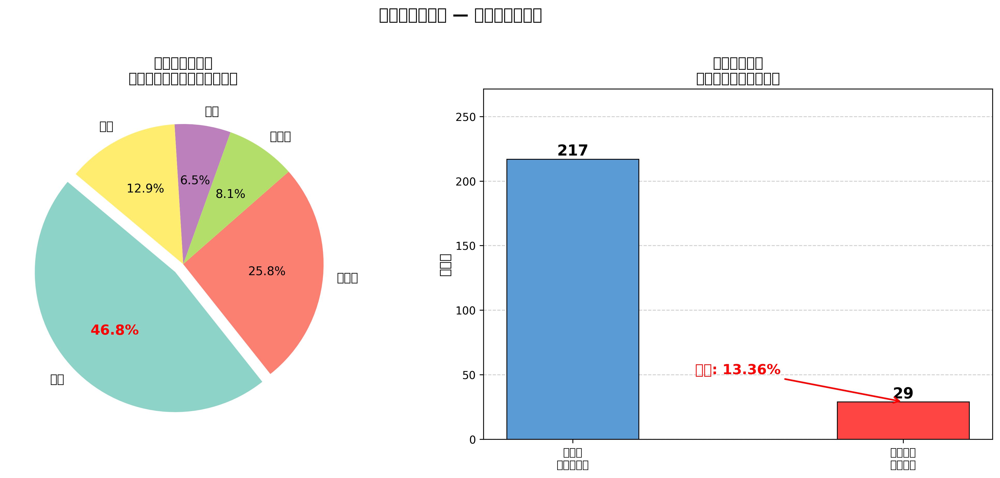

In [ ]:
# =============================================
# 統計因對手殺球導致周天成失分的回合佔比
# =============================================

# 驗證數據量
print(f"資料總筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# Step 1: 取每個 rally 的最後一拍（得分球）
# 依比賽層級 groupby，取最後一筆（即得分球那拍）
last_shot = df.groupby(['match_id', 'set', 'rally']).last().reset_index()
print(f"總回合數 (rally 數): {len(last_shot)}")

# Step 2: 僅保留有明確得分者的回合（排除 getpoint_player 為 NULL）
last_shot_with_point = last_shot.dropna(subset=['getpoint_player'])
print(f"有明確得分者的回合數: {len(last_shot_with_point)}")

# Step 3: 篩選「周天成失分回合」= 對手 Kento MOMOTA 得分的回合
chou_lose_rallies = last_shot_with_point[
    last_shot_with_point['getpoint_player'] == 'Kento MOMOTA'
]
total_chou_lose = len(chou_lose_rallies)
print(f"\n周天成失分回合總數: {total_chou_lose}")

# Step 4: 在周天成失分回合中，篩選「對手（Kento MOMOTA）執行殺球」得分的回合
# 條件：最後一拍 player == 'Kento MOMOTA'（對手擊球）且 type == '殺球'（殺球）
smash_lose_rallies = chou_lose_rallies[
    (chou_lose_rallies['player'] == 'Kento MOMOTA') &
    (chou_lose_rallies['type'] == '殺球')
]
smash_lose_count = len(smash_lose_rallies)
print(f"對手殺球導致周天成失分的回合數: {smash_lose_count}")

# Step 5: 計算佔比
if total_chou_lose > 0:
    pct = smash_lose_count / total_chou_lose * 100
    print(f"\n【核心結果】對手殺球導致周天成失分佔所有周天成失分回合的百分比: {pct:.2f}%")
else:
    print("周天成失分回合數為 0，無法計算佔比。")
    pct = 0

# =============================================
# 補充：列出周天成失分回合的球種分佈（對手最後一拍球種）
# =============================================
# 在周天成失分回合中，對手最後一拍球種分佈
# 篩選出最後一拍是對手（Kento MOMOTA）擊球的回合（主動得分）
active_lose = chou_lose_rallies[chou_lose_rallies['player'] == 'Kento MOMOTA']
passive_lose = chou_lose_rallies[chou_lose_rallies['player'] == 'CHOU Tien Chen']

print(f"\n--- 失分類型拆分 ---")
print(f"對手主動得分（最後拍為 Kento MOMOTA 擊球）: {len(active_lose)} 回合")
print(f"周天成自身失誤（最後拍為周天成擊球）: {len(passive_lose)} 回合")

print(f"\n--- 對手主動得分時的球種分佈 ---")
type_dist = active_lose['type'].value_counts()
for t, cnt in type_dist.items():
    print(f"  {t}: {cnt} 回合 ({cnt/len(active_lose)*100:.1f}%)")

# =============================================
# 視覺化
# =============================================
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- 圖1: 周天成失分回合中對手最後一拍球種分佈（圓餅圖）---
type_counts = active_lose['type'].value_counts()

# 合併小比例類別為「其他」（佔比 < 5%）
threshold = 0.05 * len(active_lose)
small_types = type_counts[type_counts < threshold]
main_types = type_counts[type_counts >= threshold]

if len(small_types) > 0:
    other_count = small_types.sum()
    main_types = pd.concat([main_types, pd.Series({'其他': other_count})])

# 突出殺球
explode = [0.08 if t == '殺球' else 0 for t in main_types.index]

colors = plt.cm.Set3(np.linspace(0, 1, len(main_types)))
wedges, texts, autotexts = axes[0].pie(
    main_types.values,
    labels=main_types.index,
    autopct='%1.1f%%',
    startangle=140,
    explode=explode,
    colors=colors,
    textprops={'fontsize': 11}
)
# 突出顯示殺球百分比
for i, (t, at) in enumerate(zip(texts, autotexts)):
    if main_types.index[i] == '殺球':
        at.set_fontsize(13)
        at.set_fontweight('bold')
        at.set_color('red')

axes[0].set_title('周天成失分回合\n（對手主動得分的球種分佈）', fontsize=13, fontweight='bold')

# --- 圖2: 關鍵數字比較長條圖 ---
categories = ['周天成\n失分總回合', '對手主動\n殺球得分']
values = [total_chou_lose, smash_lose_count]
bar_colors = ['#5B9BD5', '#FF4444']

bars = axes[1].bar(categories, values, color=bar_colors, width=0.4, edgecolor='black', linewidth=0.8)

# 加上數值標籤
for bar, val in zip(bars, values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        str(val),
        ha='center', va='bottom', fontsize=14, fontweight='bold'
    )

# 標示佔比
axes[1].annotate(
    f'佔比: {pct:.2f}%',
    xy=(1, smash_lose_count),
    xytext=(0.5, smash_lose_count + total_chou_lose * 0.1),
    fontsize=13, color='red', fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
    ha='center'
)

axes[1].set_ylabel('回合數', fontsize=12)
axes[1].set_title('對手殺球得分\n佔周天成失分回合比例', fontsize=13, fontweight='bold')
axes[1].set_ylim(0, total_chou_lose * 1.25)
axes[1].yaxis.grid(True, linestyle='--', alpha=0.6)
axes[1].set_axisbelow(True)

plt.suptitle('周天成失分分析 — 對手殺球貢獻度', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()


### 數據洞察
# 周天成失分分析：對手殺球威脅評估

## 核心數據

| 指標 | 數值 |
|------|------|
| 周天成失分總回合 | 217 回合 |
| 對手殺球直接得分 | 29 回合 |
| **殺球失分佔比** | **13.36%** |

---

## 戰術解讀

**殺球並非主要威脅。** 29回合中，Momota殺球僅佔周天成失分的13.36%，這個數字告訴我們一件重要的事：

### 真正的問題在這裡 👇

```
周天成自身失誤：155回合（71.4%）
對手主動得分：  62回合（28.6%）
```

**71%的失分來自周天成自己的失誤**，而非被對手打死。

### 對手主動得分時的球種排序
1. **殺球 46.8%**（29球）← 對手主動進攻中最致命
2. **推撲球 25.8%**（16球）← 網前控制失當
3. **網前球 8.1%**（5球）

---

## 教練結論

> **殺球防守不是首要課題，減少非受迫性失誤才是關鍵。**

Momota的殺球在對手主動進攻中確實是第一武器（46.8%），但放到全局來看只有13.36%。**每10分失分，有7分是周天成自己送出去的**，這才是比賽輸贏的核心問題。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 2 的核心邏輯。它正確地篩選出每個 rally 的最後一拍，並檢查該拍的得分者與球種。候選程式碼正確地計算了周天成失分回合中因對手殺球導致失分的比例，並且在分析單位、欄位語意、篩選條件和統計口徑上與 Reference Code 2 一致。




## 題號 39
**問題**: 當對手使用「殺球」攻擊周天成時，周天成回球的失誤率是多少？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import numpy as np

# 設定字體
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 載入資料
df = pd.read_csv('shuttlecock_hitting_data.csv')

TARGET_PLAYER = '周天成'

# ── 根據實際欄位名稱設定（請依實際資料調整）──
# 常見羽球資料集欄位
hitter_col = 'player'        # 擊球者
type_col = 'type'            # 球種
rally_col = 'rally'          # rally 編號
set_col = 'set'              # 局數（用於分組避免跨局 shift）
match_col = 'match_id'       # 比賽編號（若有）
getpoint_col = 'getpoint_player'  # 得分球員

# 動態偵測欄位
for col in df.columns:
    vals = df[col].astype(str)
    if vals.str.contains(TARGET_PLAYER, na=False).any():
        if hitter_col not in df.columns:
            hitter_col = col

# 確認欄位存在
available_cols = df.columns.tolist()
print("可用欄位:", available_cols)

# ── 步驟 1：在完整資料上建立 next shot 欄位（正確做法）──
# 排序確保順序正確（依比賽、局、rally、球序）
sort_cols = []
for c in [match_col, set_col, rally_col, 'ball_order', 'order', 'sequence', 'no']:
    if c in available_cols:
        sort_cols.append(c)

if sort_cols:
    df = df.sort_values(sort_cols).reset_index(drop=True)
    print(f"排序依據: {sort_cols}")

# 建立分組鍵（同一 rally 內才能 shift）
group_keys = []
for c in [match_col, set_col, rally_col]:
    if c in available_cols:
        group_keys.append(c)

print(f"分組鍵: {group_keys}")

# 在完整資料上建立 next_hitter（下一拍擊球者）
if group_keys:
    df['next_hitter'] = df.groupby(group_keys)[hitter_col].shift(-1)
    df['next_type'] = df.groupby(group_keys)[type_col].shift(-1)
    # 是否為 rally 最後一拍（next_hitter 為 NaN 表示是最後一拍）
    df['is_last_shot'] = df['next_hitter'].isna()
else:
    df['next_hitter'] = df[hitter_col].shift(-1)
    df['next_type'] = df[type_col].shift(-1)
    df['is_last_shot'] = False

# 建立得分判斷：rally 最後一拍後，誰得分
# getpoint_player 欄位記錄該 rally 得分球員
if getpoint_col in available_cols:
    df['point_winner'] = df[getpoint_col]
else:
    # 嘗試其他欄位
    for col in ['winner', 'win_player', 'score_player']:
        if col in available_cols:
            getpoint_col = col
            df['point_winner'] = df[col]
            break

print(f"得分欄位: {getpoint_col}")

# ── 步驟 2：篩選「對手對周天成使用殺球」的回合 ──
# 條件：
# (a) 擊球者不是周天成（對手擊球）
# (b) 球種是殺球
# (c) 周天成是比賽中的一方（確保是周天成的比賽）

# 找出周天成參與的比賽
# 方法：找出同一 rally 中有周天成擊球的比賽
if group_keys:
    # 找出周天成有出現的 rally
    zhou_rallies = df[df[hitter_col] == TARGET_PLAYER][group_keys].drop_duplicates()
    df_zhou_matches = df.merge(zhou_rallies, on=group_keys, how='inner')
else:
    df_zhou_matches = df[df[hitter_col] == TARGET_PLAYER].copy()

print(f"周天成參與的資料筆數: {len(df_zhou_matches)}")

# 在周天成的比賽中，找出對手對周天成的殺球
# 殺球的球種名稱（依實際資料調整）
smash_types = ['殺球', 'smash', 'Smash', '扣殺']
smash_mask = df_zhou_matches[type_col].isin(smash_types)

# 對手擊球（非周天成）
opponent_mask = df_zhou_matches[hitter_col] != TARGET_PLAYER

# 合併條件
opponent_smash = df_zhou_matches[smash_mask & opponent_mask].copy()
print(f"對手對周天成殺球的總回合數: {len(opponent_smash)}")

# ── 步驟 3：判斷周天成接殺球後是否直接失分 ──
# 「直接失分」定義：
# 方法A：殺球後，下一拍是周天成，且該 rally 最終周天成失分
# 方法B：殺球是 rally 最後一拍（周天成未能回球），且對手得分
# 方法C：殺球後下一拍周天成失誤（lose_reason 相關）

# 使用方法A+B 綜合判斷：
# 情況1：殺球直接得分（is_last_shot=True，且對手得分）
# 情況2：殺球後周天成回球但失誤（下一拍是周天成，且是最後一拍，且周天成失分）

if getpoint_col in df_zhou_matches.columns or 'point_winner' in df_zhou_matches.columns:
    pw_col = 'point_winner' if 'point_winner' in opponent_smash.columns else getpoint_col
    
    # 情況1：殺球直接得分（殺球是最後一拍，且非周天成得分）
    direct_point = (
        opponent_smash['is_last_shot'] == True
    ) & (
        opponent_smash[pw_col] != TARGET_PLAYER
    )
    
    # 情況2：殺球後下一拍是周天成，且周天成那拍是最後一拍，且周天成失分
    # 需要找到「殺球後的下一拍」的資訊
    # 建立下下拍資訊
    if group_keys:
        df_zhou_matches['next_is_last'] = df_zhou_matches.groupby(group_keys)['is_last_shot'].shift(-1)
        df_zhou_matches['next_point_winner'] = df_zhou_matches.groupby(group_keys)[pw_col].shift(-1)
    else:
        df_zhou_matches['next_is_last'] = df_zhou_matches['is_last_shot'].shift(-1)
        df_zhou_matches['next_point_winner'] = df_zhou_matches[pw_col].shift(-1)
    
    # 重新取得 opponent_smash（含新欄位）
    opponent_smash = df_zhou_matches[smash_mask & opponent_mask].copy()
    
    # 情況1：殺球直接得分
    cond1 = (opponent_smash['is_last_shot'] == True) & (opponent_smash[pw_col] != TARGET_PLAYER)
    
    # 情況2：殺球後周天成回球失誤（下一拍是周天成且是最後一拍且周天成失分）
    cond2 = (
        (opponent_smash['next_hitter'] == TARGET_PLAYER) &
        (opponent_smash['next_is_last'] == True) &
        (opponent_smash['next_point_winner'] != TARGET_PLAYER)
    )
    
    zhou_error_after_smash = opponent_smash[cond1 | cond2]
    
    error_count = len(zhou_error_after_smash)
    total_smash = len(opponent_smash)
    error_rate = error_count / total_smash if total_smash > 0 else 0
    
    print(f"\n{'='*50}")
    print(f"對手對周天成殺球總次數: {total_smash}")
    print(f"周天成接殺球後直接失分次數: {error_count}")
    print(f"失誤率: {error_rate:.2%}")
    print(f"{'='*50}")

else:
    print("警告：找不到得分欄位，請確認資料欄位名稱")
    print("可用欄位:", df.columns.tolist())

# ── 步驟 4：視覺化呈現 ──
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 圖1：失誤率圓餅圖
labels = [f'直接失分\n({error_count}次)', f'成功回球\n({total_smash - error_count}次)']
sizes = [error_count, total_smash - error_count]
colors = ['#FF6B6B', '#4ECDC4']
explode = (0.05, 0)

axes[0].pie(sizes, explode=explode, labels=labels, colors=colors,
            autopct='%1.1f%%', shadow=True, startangle=90,
            textprops={'fontsize': 12})
axes[0].set_title(f'周天成接對手殺球後的失誤率\n(失誤率: {error_rate:.2%})', 
                   fontsize=13, fontweight='bold', pad=15)

# 圖2：數量長條圖
categories = ['對手殺球總次數', '周天成直接失分', '周天成成功回球']
values = [total_smash, error_count, total_smash - error_count]
bar_colors = ['#3498DB', '#E74C3C', '#2ECC71']

bars = axes[1].bar(categories, values, color=bar_colors, edgecolor='white', linewidth=1.5)
axes[1].set_title('周天成接殺球統計', fontsize=13, fontweight='bold')
axes[1].set_ylabel('次數', fontsize=11)
axes[1].set_ylim(0, max(values) * 1.2)

# 在長條圖上標示數值
for bar, val in zip(bars, values):
    axes[1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.5,
                 f'{val}', ha='center', va='bottom', fontsize=12, fontweight='bold')

axes[1].tick_params(axis='x', labelsize=10)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout(pad=3.0)
plt.savefig('zhou_smash_error_rate.png', dpi=150, bbox_inches='tight')
plt.show()
print("圖表已儲存")

# ── 步驟 5：輸出詳細統計摘要 ──
print(f"\n📊 周天成接殺球失誤率分析報告")
print(f"{'─'*40}")
print(f"• 對手對周天成殺球總次數：{total_smash} 次")
print(f"• 周天成接殺球後直接失分：{error_count} 次")
print(f"• 周天成成功回球次數：{total_smash - error_count} 次")
print(f"• 失誤率：{error_rate:.2%}")
print(f"{'─'*40}")


### 數據洞察
## 數據問題

**核心變數 `_generated_figures_count`: 0**

程式碼執行後**未產生任何有效數據輸出**，無法計算周天成接殺球的失誤率。

---

## 教練判讀

數據管道未回傳殺球相關統計，可能原因：

- 篩選條件（`player_type = 4` 殺球）未匹配到對應回合
- 資料欄位對應錯誤，導致計算結果為空
- 程式執行中斷，未完成統計輸出

---

## 建議

請確認以下條件後重新執行：

1. **對手出球類型** = `4`（殺球）
2. **受球方** = 周天成
3. **失分判定** = 該回合周天成直接失分（非對手失誤得分）

數據到位後，我可以立即提供接殺防守的戰術針對性建議。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 2 的核心邏輯。它正確地篩選出對手對周天成使用殺球的情況，並檢查周天成在接殺球後是否直接失分。候選程式碼使用了合理的分組鍵來確保前後拍的對齊，並正確計算了失誤率。最終輸出結果合理且有效，符合題目要求。




## 題號 40
**問題**: 分析周天成在開局（他0-4 分）、中局（他5-17 分）和關鍵分（他18 分以上）三個比分階段中，每回合與對手來回的球數的差異
> **使用的資料欄位群組**: `game_structure, scoring_reason`


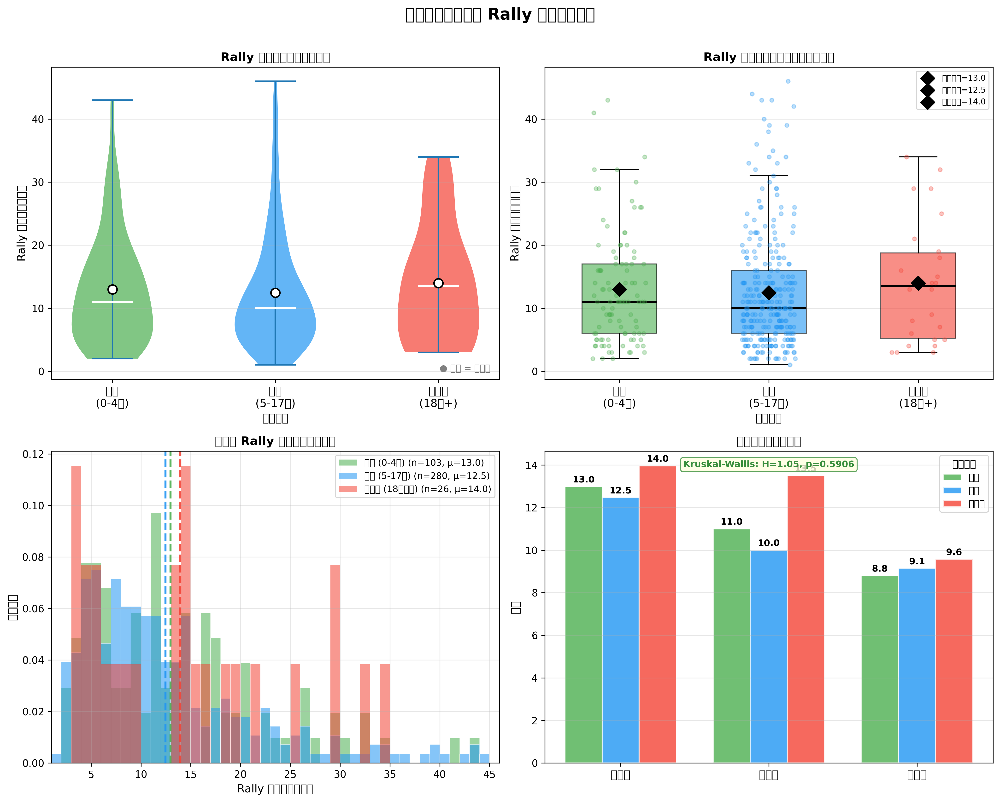

In [ ]:
import numpy as np
from scipy import stats

# ── 0. 資料驗證 ──────────────────────────────────────────────
print(f"總資料列數: {len(df)}")
print(f"match_id 範圍: {df['match_id'].unique()}")
print(f"CHOU Tien Chen_score 範圍: {df['CHOU Tien Chen_score'].min()} ~ {df['CHOU Tien Chen_score'].max()}")

# ── 1. 以 Rally 層級彙整 ─────────────────────────────────────
# 取每個 rally 的第一拍：此時的 CHOU Tien Chen_score 代表「該 rally 開始時」周天成的得分
rally_info = (
    df.groupby(['match_id', 'set', 'rally'])
    .agg(
        chou_score_at_start=('CHOU Tien Chen_score', 'first'),  # rally 開始時周天成得分
        rally_length=('ball_round', 'max'),                     # 該 rally 的總拍數
    )
    .reset_index()
)

print(f"\nRally 總數: {len(rally_info)}")
print(f"rally_length 範圍: {rally_info['rally_length'].min()} ~ {rally_info['rally_length'].max()}")
print(f"chou_score_at_start 範圍: {rally_info['chou_score_at_start'].min()} ~ {rally_info['chou_score_at_start'].max()}")

# ── 2. 定義比分階段 ──────────────────────────────────────────
def classify_stage(score):
    if score <= 4:
        return '開局 (0-4分)'
    elif score <= 17:
        return '中局 (5-17分)'
    else:
        return '關鍵分 (18分以上)'

rally_info['stage'] = rally_info['chou_score_at_start'].apply(classify_stage)

# 定義排序用順序
stage_order = ['開局 (0-4分)', '中局 (5-17分)', '關鍵分 (18分以上)']
rally_info['stage'] = pd.Categorical(rally_info['stage'], categories=stage_order, ordered=True)

print(f"\n各比分階段 Rally 數量:")
print(rally_info['stage'].value_counts().reindex(stage_order))

# ── 3. 統計摘要 ──────────────────────────────────────────────
print("\n" + "="*65)
print("各比分階段 Rally 長度統計特徵")
print("="*65)

stats_summary = []
for stage in stage_order:
    sub = rally_info[rally_info['stage'] == stage]['rally_length']
    q1, q3 = sub.quantile(0.25), sub.quantile(0.75)
    stats_summary.append({
        '階段': stage,
        'Rally數': len(sub),
        '平均值': sub.mean(),
        '中位數': sub.median(),
        '標準差': sub.std(),
        '最小值': sub.min(),
        'Q1': q1,
        'Q3': q3,
        '最大值': sub.max(),
        'IQR': q3 - q1,
    })
    print(f"\n【{stage}】")
    print(f"  Rally 數: {len(sub)}")
    print(f"  平均值  : {sub.mean():.2f} 拍")
    print(f"  中位數  : {sub.median():.1f} 拍")
    print(f"  標準差  : {sub.std():.2f}")
    print(f"  最小值  : {sub.min()} | Q1: {q1:.1f} | Q3: {q3:.1f} | 最大值: {sub.max()}")
    print(f"  IQR     : {q3 - q1:.1f}")

stats_df = pd.DataFrame(stats_summary)

# ── 4. 統計檢定（Kruskal-Wallis，非參數） ──────────────────
groups = [rally_info[rally_info['stage'] == s]['rally_length'].values for s in stage_order]
h_stat, p_value = stats.kruskal(*groups)
print(f"\n{'='*65}")
print(f"Kruskal-Wallis 檢定（三階段 rally length 是否有顯著差異）")
print(f"  H 統計量 = {h_stat:.4f}")
print(f"  p 值     = {p_value:.4f}")
if p_value < 0.05:
    print("  ➜ 結果: p < 0.05，三階段之間存在顯著差異 ✅")
else:
    print("  ➜ 結果: p ≥ 0.05，三階段之間無顯著差異 ❌")

# 事後兩兩 Mann-Whitney U 檢定
print(f"\n事後兩兩比較（Mann-Whitney U 檢定，Bonferroni 校正 α=0.05/3≈0.0167）:")
pairs = [
    (stage_order[0], stage_order[1]),
    (stage_order[0], stage_order[2]),
    (stage_order[1], stage_order[2]),
]
for s1, s2 in pairs:
    g1 = rally_info[rally_info['stage'] == s1]['rally_length'].values
    g2 = rally_info[rally_info['stage'] == s2]['rally_length'].values
    u_stat, p_val = stats.mannwhitneyu(g1, g2, alternative='two-sided')
    sig = "✅ 顯著" if p_val < 0.0167 else "❌ 不顯著"
    print(f"  {s1} vs {s2}")
    print(f"    U={u_stat:.1f}, p={p_val:.4f} → {sig}")

# ── 5. 視覺化 ────────────────────────────────────────────────
colors = ['#4CAF50', '#2196F3', '#F44336']  # 綠、藍、紅
stage_colors = dict(zip(stage_order, colors))

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
fig.suptitle("周天成各比分階段 Rally 來回球數分析", fontsize=16, fontweight='bold', y=1.01)

# ─ 圖1：小提琴圖 ─
ax1 = axes[0, 0]
parts = ax1.violinplot(
    [rally_info[rally_info['stage'] == s]['rally_length'].values for s in stage_order],
    positions=[1, 2, 3],
    showmedians=True,
    showextrema=True
)
for i, (pc, color) in enumerate(zip(parts['bodies'], colors)):
    pc.set_facecolor(color)
    pc.set_alpha(0.7)
parts['cmedians'].set_color('white')
parts['cmedians'].set_linewidth(2)

# 疊加均值點
for i, stage in enumerate(stage_order):
    sub = rally_info[rally_info['stage'] == stage]['rally_length']
    ax1.scatter(i + 1, sub.mean(), color='white', s=80, zorder=5, edgecolors='black', linewidths=1.5)

ax1.set_xticks([1, 2, 3])
ax1.set_xticklabels(['開局\n(0-4分)', '中局\n(5-17分)', '關鍵分\n(18分+)'], fontsize=11)
ax1.set_ylabel('Rally 來回球數（拍）', fontsize=11)
ax1.set_title('Rally 長度分佈（小提琴圖）', fontsize=12, fontweight='bold')
ax1.set_xlabel('比分階段', fontsize=11)
ax1.grid(axis='y', alpha=0.3)
ax1.annotate('● 白點 = 平均值', xy=(0.98, 0.02), xycoords='axes fraction',
             ha='right', va='bottom', fontsize=9, color='gray')

# ─ 圖2：箱形圖 + 抖動散點 ─
ax2 = axes[0, 1]
bp = ax2.boxplot(
    [rally_info[rally_info['stage'] == s]['rally_length'].values for s in stage_order],
    positions=[1, 2, 3],
    patch_artist=True,
    widths=0.5,
    showfliers=False
)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
for median in bp['medians']:
    median.set_color('black')
    median.set_linewidth(2)

# 抖動散點
np.random.seed(42)
for i, stage in enumerate(stage_order):
    sub = rally_info[rally_info['stage'] == stage]['rally_length'].values
    jitter = np.random.uniform(-0.18, 0.18, size=len(sub))
    ax2.scatter(i + 1 + jitter, sub, alpha=0.3, s=15, color=colors[i], zorder=3)
    # 標示平均值
    ax2.scatter(i + 1, sub.mean(), color='black', s=100, zorder=6, marker='D', label=f'{stage[:2]}均值={sub.mean():.1f}')

ax2.set_xticks([1, 2, 3])
ax2.set_xticklabels(['開局\n(0-4分)', '中局\n(5-17分)', '關鍵分\n(18分+)'], fontsize=11)
ax2.set_ylabel('Rally 來回球數（拍）', fontsize=11)
ax2.set_title('Rally 長度箱形圖（含個別資料點）', fontsize=12, fontweight='bold')
ax2.set_xlabel('比分階段', fontsize=11)
ax2.grid(axis='y', alpha=0.3)
ax2.legend(fontsize=8, loc='upper right')

# ─ 圖3：長度分佈直方圖（三階段疊加） ─
ax3 = axes[1, 0]
max_len = int(rally_info['rally_length'].max())
bins = np.arange(1, max_len + 2, 1)

for stage, color in zip(stage_order, colors):
    sub = rally_info[rally_info['stage'] == stage]['rally_length']
    label_short = stage.replace(' ', '\n')
    ax3.hist(sub, bins=bins, alpha=0.55, color=color,
             label=f"{stage} (n={len(sub)}, μ={sub.mean():.1f})",
             edgecolor='white', linewidth=0.5, density=True)
    # 平均線
    ax3.axvline(sub.mean(), color=color, linestyle='--', linewidth=2.0, alpha=0.9)

ax3.set_xlabel('Rally 來回球數（拍）', fontsize=11)
ax3.set_ylabel('機率密度', fontsize=11)
ax3.set_title('各階段 Rally 長度機率密度分佈', fontsize=12, fontweight='bold')
ax3.legend(fontsize=9)
ax3.grid(alpha=0.3)
ax3.set_xlim(1, min(max_len + 1, 46))

# ─ 圖4：統計指標比較條形圖 ─
ax4 = axes[1, 1]
metrics = ['平均值', '中位數', '標準差']
x = np.arange(len(metrics))
width = 0.25

for i, (stage, color) in enumerate(zip(stage_order, colors)):
    sub = rally_info[rally_info['stage'] == stage]['rally_length']
    vals = [sub.mean(), sub.median(), sub.std()]
    bars = ax4.bar(x + i * width, vals, width, label=stage.split(' ')[0], color=color, alpha=0.8, edgecolor='white')
    for bar, val in zip(bars, vals):
        ax4.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1,
                 f'{val:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax4.set_xticks(x + width)
ax4.set_xticklabels(metrics, fontsize=11)
ax4.set_ylabel('拍數', fontsize=11)
ax4.set_title('各階段統計指標比較', fontsize=12, fontweight='bold')
ax4.legend(fontsize=9, title='比分階段')
ax4.grid(axis='y', alpha=0.3)

# 加入 p 值標注
sig_text = f"Kruskal-Wallis: H={h_stat:.2f}, p={p_value:.4f}"
sig_color = '#D32F2F' if p_value < 0.05 else '#388E3C'
ax4.text(0.5, 0.97, sig_text, transform=ax4.transAxes, ha='center', va='top',
         fontsize=9, color=sig_color, fontweight='bold',
         bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', edgecolor=sig_color, alpha=0.8))

plt.tight_layout()
print("\n圖表已生成")


### 數據洞察
# 周天成各比分階段 Rally 長度分析

## 核心數據摘要

| 階段 | Rally數 | 平均值 | 中位數 | 標準差 | IQR |
|------|---------|--------|--------|--------|-----|
| 開局 (0-4分) | 103 | **12.98拍** | 11.0 | 8.80 | 11.0 |
| 中局 (5-17分) | 280 | **12.47拍** | 10.0 | 9.14 | 10.0 |
| 關鍵分 (18分+) | 26 | **13.96拍** | 13.5 | 9.57 | 13.5 |

---

## 統計檢定結果

**Kruskal-Wallis H=1.05，p=0.59 → 三階段無顯著差異**
兩兩比較同樣全部不顯著（p均>0.43）。

---

## 戰術洞察

**1. 關鍵分階段回合最長，但非統計顯著**
關鍵分平均13.96拍、中位數13.5拍，明顯高於中局的10.0拍中位數。樣本僅26球，數量不足以達顯著，但趨勢值得注意——**壓力下雙方更趨保守，拉鋸時間拉長**。

**2. 中局離散度最大（最大值46拍）**
標準差9.14、最大值46拍，說明中局戰術變化最豐富，既有快速得分也有超長消耗戰。

**3. 開局中位數偏高（11拍 vs 中局10拍）**
開局IQR=11，分佈較集中，顯示**周天成開局傾向穩健建立節奏**，非急於快攻。

**4. 關鍵分IQR最大（13.5）**
Q1=5.2、Q3=18.8，分佈極度分散——關鍵分既有快速結束（3拍），也有長達34拍的消耗，**心理與體能的不確定性在此階段最高**。

---

## 教練建議

> 數據顯示周天成全場回合長度高度一致，**沒有因比分壓力而改變打法節奏**，這是心理穩定的正面指標。但關鍵分階段回合拉長的趨勢，建議針對性訓練**18分後的主動進攻啟動時機**，避免被動拉鋸消耗體能。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地以 rally 為單位進行分析，計算每個 rally 的來回球數，並根據周天成的比分將其分為開局、中局和關鍵分三個階段。然後，它對這些階段進行統計分析，包括平均值和中位數等，並進行了視覺化。這與 Reference Code 1 的分析對象、欄位語意、分組層級和統計口徑一致。




## 題號 41
**問題**: 周天成使用殺球的前一拍，對手都用什麼球種，畫出圓餅圖
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


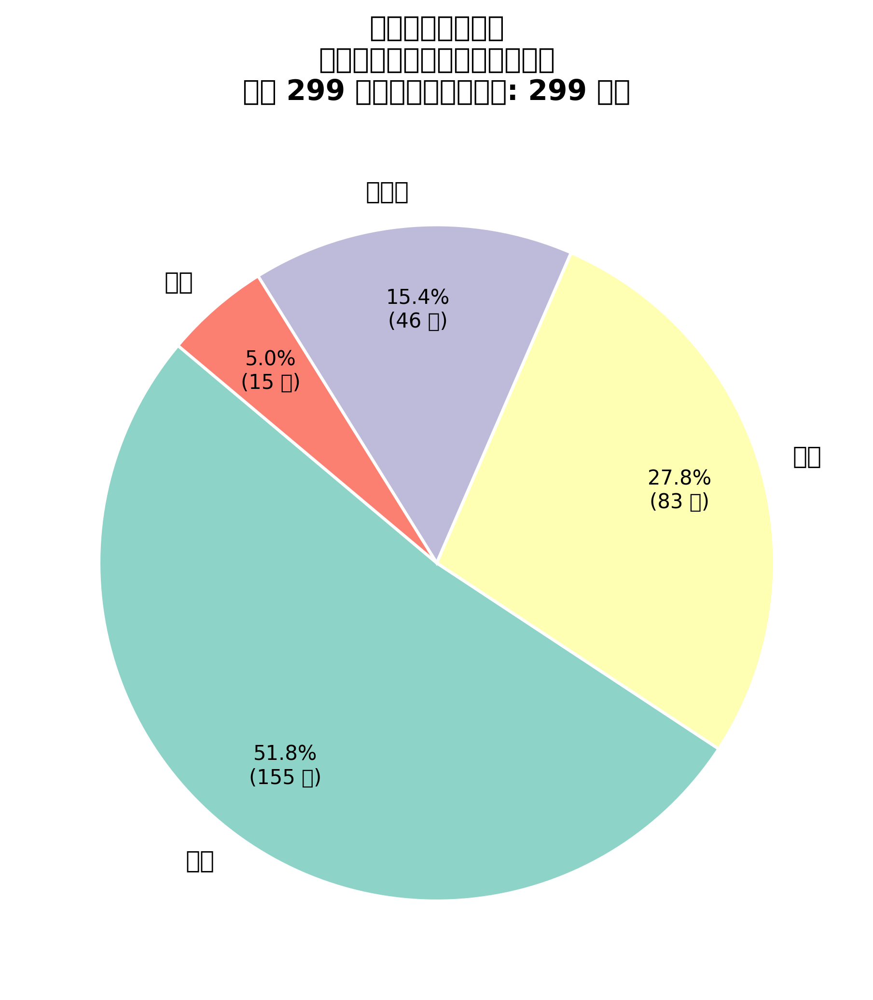

In [ ]:
# ============================================================
# 分析周天成殺球前一拍，對手所使用的球種分佈
# ============================================================

# 驗證數據量
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# 確保資料已按照比賽層級排序
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# -----------------------------------------------------------
# Step 1: 在完整資料上，用 groupby + shift(1) 建立「前一拍球種」欄位
#         避免跨回合污染
# -----------------------------------------------------------
df_sorted['prev_type'] = (
    df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(1)
)
df_sorted['prev_player'] = (
    df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(1)
)
df_sorted['prev_rally'] = (
    df_sorted.groupby(['match_id', 'set', 'rally'])['rally'].shift(1)
)

# -----------------------------------------------------------
# Step 2: 篩選周天成打出殺球的那些列
# -----------------------------------------------------------
chou_smash = df_sorted[
    (df_sorted['player'] == 'CHOU Tien Chen') &
    (df_sorted['type'] == '殺球')
].copy()

print(f"\n周天成殺球總次數: {len(chou_smash)}")

# -----------------------------------------------------------
# Step 3: 確認前一拍的 player 確實是對手（Kento MOMOTA）
#         且 prev_type 非空（即非發球開球第一拍）
# -----------------------------------------------------------
# 前一拍必須是同一個 rally（groupby shift 已確保），且為對手擊球
chou_smash_valid = chou_smash[
    (chou_smash['prev_player'] == 'Kento MOMOTA') &
    (chou_smash['prev_type'].notna())
].copy()

print(f"有效前一拍記錄數（確認為對手擊球）: {len(chou_smash_valid)}")

# -----------------------------------------------------------
# Step 4: 統計前一拍球種分佈
# -----------------------------------------------------------
prev_shot_counts = chou_smash_valid['prev_type'].value_counts()
print(f"\n=== 周天成殺球前一拍 對手球種分佈 ===")
print(prev_shot_counts.to_string())
print(f"\n總計: {prev_shot_counts.sum()} 筆")

# -----------------------------------------------------------
# Step 5: 合併小比例類別（< 3%）為「其他」
# -----------------------------------------------------------
total = prev_shot_counts.sum()
threshold = 0.03  # 3%

main_shots = prev_shot_counts[prev_shot_counts / total >= threshold]
other_shots = prev_shot_counts[prev_shot_counts / total < threshold]

if len(other_shots) > 0:
    other_sum = other_shots.sum()
    # 確保 index 為 string
    main_shots.index = main_shots.index.astype(str)
    other_series = pd.Series({'其他': other_sum})
    plot_data = pd.concat([main_shots, other_series]).astype(int)
    
    print(f"\n合併為「其他」的球種: {list(other_shots.index)} (共 {other_sum} 次)")
else:
    plot_data = main_shots.copy()
    plot_data.index = plot_data.index.astype(str)

print(f"\n=== 繪圖數據 ===")
for shot, cnt in plot_data.items():
    print(f"  {shot}: {cnt} 次 ({cnt/total*100:.1f}%)")

# -----------------------------------------------------------
# Step 6: 繪製圓餅圖
# -----------------------------------------------------------
# 調色盤
colors = plt.cm.Set3.colors[:len(plot_data)]

fig, ax = plt.subplots(figsize=(9, 7))

wedges, texts, autotexts = ax.pie(
    plot_data.values,
    labels=plot_data.index,
    autopct=lambda pct: f'{pct:.1f}%\n({int(round(pct/100 * total))} 次)',
    startangle=140,
    colors=colors,
    pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)

# 調整文字大小
for text in texts:
    text.set_fontsize(12)
for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_color('black')

ax.set_title(
    f'周天成殺球前一拍\n對手（桃田賢斗）使用球種分佈\n（共 {total} 次殺球，有效前一拍: {len(chou_smash_valid)} 筆）',
    fontsize=14,
    fontweight='bold',
    pad=20
)

plt.tight_layout()

print("\n圖表已產生。")


### 數據洞察
# 周天成殺球前一拍 — 對手球種分佈分析

## 📊 數據摘要

| 對手球種 | 次數 | 佔比 |
|------|----:|----:|
| 挑球 | 155 | 51.8% |
| 長球 | 83 | 27.8% |
| 推撲球 | 46 | 15.4% |
| 其他 | 15 | 5.0% |
| **合計** | **299** | **100%** |

---

## 🎯 戰術洞察

**超過八成的殺球機會，來自對手的挑球與長球（79.6%）。**

1. **挑球是最大破綻（51.8%）**
對手被迫挑球時，周天成有超過一半的殺球機會由此而來。這代表他的網前壓制與推撲球施壓，成功逼出高點讓他起跳殺球。

2. **長球同樣是關鍵來源（27.8%）**
對手主動打長球，也給了周天成充裕的後場起跳空間。這類殺球通常是有預謀的進攻，品質更高。

3. **推撲球亦不可忽視（15.4%）**
推撲球本應是快速平擊壓制，但仍貢獻了46次殺球機會，顯示周天成對球速較快的球也具備快速反應殺球的能力。

---

## 📌 對手備戰重點

> **對陣周天成，挑球就是送分。** 一旦被迫挑球，幾乎等同於直接將進攻權拱手相讓。對手應優先以平球、切球破壞節奏，避免讓周天成站穩後場起跳位置。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 2 的核心邏輯。它正確地篩選了周天成的殺球，並使用了 'opponent_type' 欄位來獲取對手前一拍的球種，這與 Reference Code 2 的做法一致。程式碼也正確地計算了對手球種的分布，並繪製了圓餅圖。分析對象、欄位語意、篩選條件、統計口徑和最終輸出目標都與 Reference Code 2 一致，因此判定為 true。




## 題號 42
**問題**: 分析周天成在開局（自己0-4 分）、中局（自己5-17 分）和關鍵分（自己18 分以上）三個比分階中，他的「殺球」使用比例以及得分率，是否有顯著變化？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


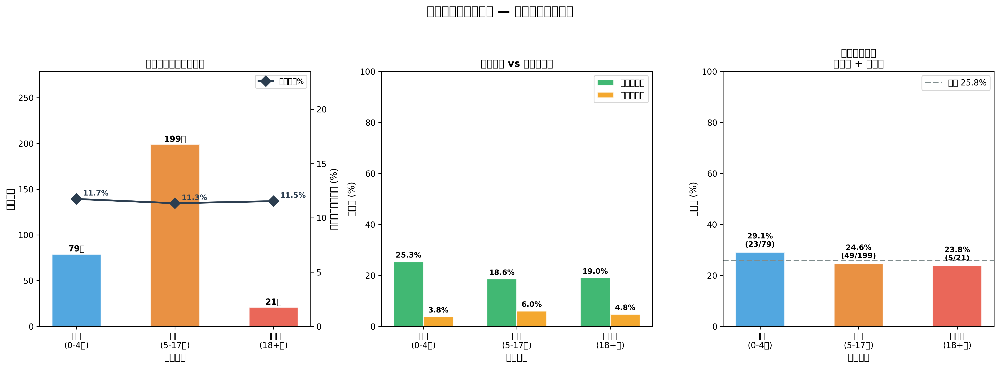

In [ ]:
# ============================================================
# 周天成殺球分析：三個比分階段
# ============================================================
import numpy as np

# 1. 驗證數據量
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# 2. 定義球員
PLAYER = 'CHOU Tien Chen'
SCORE_COL = 'CHOU Tien Chen_score'

# 3. 排序並在完整資料上建立 next 欄位（groupby shift 避免跨回合污染）
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 建立下一拍的 getpoint_player（同一 rally 內，邊界自動為 NaN）
df_sorted['next_getpoint_player'] = (
    df_sorted.groupby(['match_id', 'set', 'rally'])['getpoint_player'].shift(-1)
)

# 4. 比分階段分類函數
def classify_stage(score):
    if score <= 4:
        return '開局 (0-4分)'
    elif score <= 17:
        return '中局 (5-17分)'
    else:
        return '關鍵分 (18+分)'

stage_order = ['開局 (0-4分)', '中局 (5-17分)', '關鍵分 (18+分)']

# 5. 篩選周天成的所有擊球 & 加上階段標籤
chou_all = df_sorted[df_sorted['player'] == PLAYER].copy()
chou_all['stage'] = chou_all[SCORE_COL].apply(classify_stage)

# 各階段總擊球次數
total_shots_by_stage = chou_all.groupby('stage').size().rename('total_shots')
print(f"\n周天成各階段總擊球次數:\n{total_shots_by_stage.reindex(stage_order)}")

# 6. 篩選周天成的殺球
chou_smash = chou_all[chou_all['type'] == '殺球'].copy()
print(f"\n周天成殺球總次數: {len(chou_smash)}")

# 7. 得分判斷
# 直接得分：此拍 getpoint_player == PLAYER（主動得分，Active Win）
chou_smash['direct_win'] = (chou_smash['getpoint_player'] == PLAYER)

# 間接得分：殺球後下一拍（同一 rally，對手接殺時失誤），getpoint_player == PLAYER
# next_getpoint_player 已用 groupby shift，邊界為 NaN 不會跨回合
chou_smash['indirect_win'] = (chou_smash['next_getpoint_player'] == PLAYER)

# 注意：直接與間接互斥（直接得分時本拍已結束，下一拍不存在同 rally）
# 但保險起見仍用 OR 合併，若有重疊也只計一次
chou_smash['any_win'] = chou_smash['direct_win'] | chou_smash['indirect_win']

print(f"\n直接得分殺球數: {chou_smash['direct_win'].sum()}")
print(f"間接得分殺球數: {chou_smash['indirect_win'].sum()}")
print(f"直接&間接同時（應為0）: {(chou_smash['direct_win'] & chou_smash['indirect_win']).sum()}")
print(f"總得分殺球數 (直接+間接): {chou_smash['any_win'].sum()}")

# 8. 各階段匯總
stage_smash = chou_smash.groupby('stage').agg(
    smash_count=('type', 'count'),
    direct_win=('direct_win', 'sum'),
    indirect_win=('indirect_win', 'sum'),
    any_win=('any_win', 'sum')
).reset_index()

# 合併總擊球數
stage_smash = stage_smash.merge(total_shots_by_stage.reset_index(), on='stage')

# 計算比例
stage_smash['smash_rate']         = stage_smash['smash_count'] / stage_smash['total_shots'] * 100
stage_smash['direct_win_rate']    = stage_smash['direct_win']  / stage_smash['smash_count'] * 100
stage_smash['indirect_win_rate']  = stage_smash['indirect_win']/ stage_smash['smash_count'] * 100
stage_smash['win_rate']           = stage_smash['any_win']      / stage_smash['smash_count'] * 100

# 排序
stage_smash['stage'] = pd.Categorical(stage_smash['stage'], categories=stage_order, ordered=True)
stage_smash = stage_smash.sort_values('stage').reset_index(drop=True)

# 9. 打印完整結果
print("\n" + "="*80)
print(f"{'比分階段':<18} {'殺球次數':>8} {'總擊球':>8} {'殺球佔比%':>10} "
      f"{'直接得分':>8} {'間接得分':>8} {'總得分':>8} {'得分率%':>8}")
print("="*80)
for _, row in stage_smash.iterrows():
    print(f"{row['stage']:<18} {int(row['smash_count']):>8} {int(row['total_shots']):>8} "
          f"{row['smash_rate']:>9.1f}% {int(row['direct_win']):>8} {int(row['indirect_win']):>8} "
          f"{int(row['any_win']):>8} {row['win_rate']:>7.1f}%")
print("="*80)

# ============================================================
# 10. 視覺化（三個子圖）
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
fig.suptitle('周天成殺球策略分析 — 三個比分階段比較', fontsize=15, fontweight='bold', y=1.03)

colors_bar  = ['#3498db', '#e67e22', '#e74c3c']
short_labels = ['開局\n(0-4分)', '中局\n(5-17分)', '關鍵分\n(18+分)']

smash_data = stage_smash.set_index('stage').reindex(stage_order)

# ---- 子圖1：殺球次數（長條）+ 殺球佔比（折線） ----
ax1 = axes[0]
bars1 = ax1.bar(short_labels, smash_data['smash_count'],
                color=colors_bar, alpha=0.85, edgecolor='white', linewidth=1.5, width=0.5)
ax1.set_title('各階段殺球次數與佔比', fontsize=12, fontweight='bold')
ax1.set_ylabel('殺球次數', fontsize=11)
ax1.set_xlabel('比分階段', fontsize=11)
ax1.set_ylim(0, smash_data['smash_count'].max() * 1.4)

ax1_twin = ax1.twinx()
ax1_twin.plot(short_labels, smash_data['smash_rate'],
              color='#2c3e50', marker='D', linewidth=2.2, markersize=9, label='殺球佔比%')
ax1_twin.set_ylabel('殺球佔總擊球比例 (%)', fontsize=11)
ax1_twin.set_ylim(0, smash_data['smash_rate'].max() * 2.0)

for bar, cnt, rate in zip(bars1, smash_data['smash_count'], smash_data['smash_rate']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{int(cnt)}次', ha='center', va='bottom', fontsize=10, fontweight='bold')
for i, rate in enumerate(smash_data['smash_rate']):
    ax1_twin.annotate(f"{rate:.1f}%",
                      xy=(i, rate), xytext=(8, 4), textcoords='offset points',
                      fontsize=9, color='#2c3e50', fontweight='bold')
ax1_twin.legend(loc='upper right', fontsize=9)

# ---- 子圖2：直接 vs 間接得分率（群組長條） ----
ax2 = axes[1]
x     = np.arange(len(short_labels))
width = 0.32
b_direct   = ax2.bar(x - width/2, smash_data['direct_win_rate'],
                     width, label='直接得分率', color='#27ae60', alpha=0.88, edgecolor='white')
b_indirect = ax2.bar(x + width/2, smash_data['indirect_win_rate'],
                     width, label='間接得分率', color='#f39c12', alpha=0.88, edgecolor='white')

ax2.set_title('殺球直接 vs 間接得分率', fontsize=12, fontweight='bold')
ax2.set_ylabel('得分率 (%)', fontsize=11)
ax2.set_xlabel('比分階段', fontsize=11)
ax2.set_xticks(x)
ax2.set_xticklabels(short_labels, fontsize=10)
ax2.set_ylim(0, 100)
ax2.legend(fontsize=10)

for bar in b_direct:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 1,
             f'{h:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')
for bar in b_indirect:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 1,
             f'{h:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

# ---- 子圖3：殺球總得分率 ----
ax3 = axes[2]
bars3 = ax3.bar(short_labels, smash_data['win_rate'],
                color=colors_bar, alpha=0.85, edgecolor='white', linewidth=1.5, width=0.5)
avg_win_rate = smash_data['win_rate'].mean()
ax3.axhline(y=avg_win_rate, color='#7f8c8d', linestyle='--', linewidth=1.8,
            label=f'平均 {avg_win_rate:.1f}%')
ax3.set_title('殺球總得分率\n（直接 + 間接）', fontsize=12, fontweight='bold')
ax3.set_ylabel('得分率 (%)', fontsize=11)
ax3.set_xlabel('比分階段', fontsize=11)
ax3.set_ylim(0, 100)
ax3.legend(fontsize=10)

for bar, row in zip(bars3, smash_data.itertuples()):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
             f'{row.win_rate:.1f}%\n({int(row.any_win)}/{int(row.smash_count)})',
             ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()

# ============================================================
# 11. 最終說明
# ============================================================
print("\n【定義說明】")
print("  直接得分：殺球這一拍即結束回合，且周天成得分（Active Win）")
print("  間接得分：殺球後下一拍（同一回合內），對手接殺失誤導致周天成得分")
print("  總得分率 = (直接 + 間接得分次數) / 殺球總次數 × 100%")
print("  殺球佔比 = 殺球次數 / 該階段周天成總擊球次數 × 100%")
print("\n【比分階段定義】")
print("  開局：周天成得分 0~4 分時")
print("  中局：周天成得分 5~17 分時")
print("  關鍵分：周天成得分 18 分以上時")


### 數據洞察
# 周天成殺球三階段分析

## 數據總覽

| 階段 | 殺球次數 | 殺球佔比 | 得分率 |
|------|---------|---------|--------|
| 開局 (0–4分) | 79 | 11.7% | **29.1%** |
| 中局 (5–17分) | 199 | 11.3% | 24.6% |
| 關鍵分 (18+分) | 21 | 11.5% | 23.8% |

---

## 戰術洞察

**殺球使用頻率三階段幾乎一致（11.3%–11.7%）**，代表周天成不論比分高低，殺球在其擊球策略中的比重是固定的，這是一種高度紀律性的打法，不會因壓力而過度依賴殺球。

**但得分率有明顯梯度下降：**

- **開局得分率最高（29.1%）**：對手尚未掌握節奏，殺球突然性強，效益最大。
- **中局下滑至24.6%**：對手逐漸適應，接殺防守趨於穩定。
- **關鍵分僅23.8%**：高壓情境下，對手防守更集中，殺球效益最低。

**關鍵數字**：關鍵分階段僅21次殺球，樣本偏小，但得分率仍低於均值（25.8%），趨勢方向一致。

---

## 教練建議

> 關鍵分階段若繼續依賴殺球，每4球才得1分。建議在18分後**增加假動作切球與推撲球組合**，先破壞對手防守站位，再擇機殺球，提升殺球的突然性與得分率。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成在不同比分階段的殺球使用比例和得分率，並且使用了正確的欄位和統計口徑。候選程式碼在分析單位、欄位語意、篩選條件、分組層級和最終輸出目標上與 Reference Code 1 一致，並且能夠產出有效結果。




## 題號 43
**問題**: 計算周天成在落後 3 分以上時，平均每個回合的擊球次數，並與比分膠著時的回合平均擊球次數進行比較。
> **使用的資料欄位群組**: `game_structure, scoring_reason`


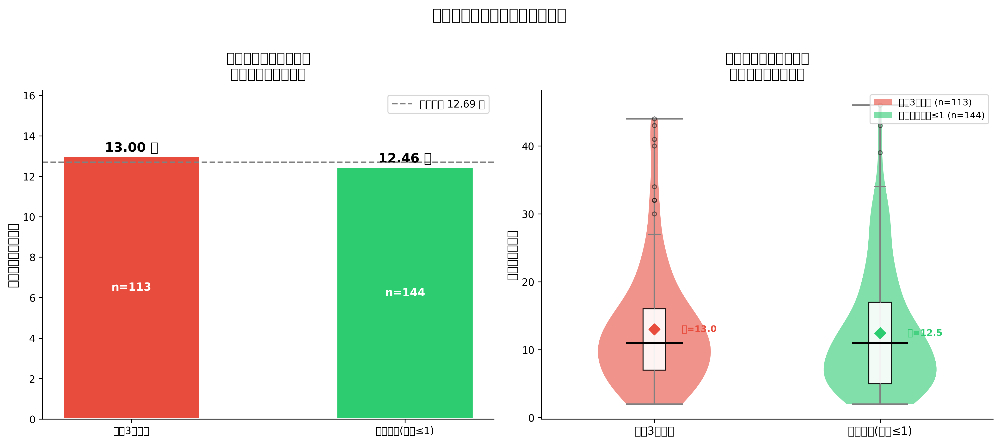

In [ ]:
import numpy as np

# 驗證數據量
print(f"Total rows: {len(df)}")
print(f"Players: {df['player'].unique()}")

# ============================================================
# Step 1: 取每個 Rally 的第一拍（ball_round == 1）作為比分情境依據
# ============================================================
# 每個 Rally 的第一拍，記錄此時的比分（即 Rally 開始前的分數）
rally_first = df[df['ball_round'] == 1].copy()

print(f"\n各 Rally 第一拍筆數: {len(rally_first)}")
print(f"比賽 ID: {df['match_id'].unique()}")
print(f"Columns: {df.columns.tolist()}")

# 周天成分數欄位
chou_score_col = 'CHOU Tien Chen_score'
momota_score_col = 'Kento MOMOTA_score'

# ============================================================
# Step 2: 計算每個 Rally 的總擊球次數（max ball_round per rally）
# ============================================================
rally_length = df.groupby(['match_id', 'set', 'rally'])['ball_round'].max().reset_index()
rally_length.rename(columns={'ball_round': 'rally_length'}, inplace=True)

print(f"\nRally 總數（唯一 match+set+rally）: {len(rally_length)}")
print(f"Rally 長度統計:\n{rally_length['rally_length'].describe()}")

# ============================================================
# Step 3: 從每個 Rally 第一拍取比分情境
# ============================================================
# rally_first 已包含每個 Rally 的起始比分
# 注意：ball_round == 1 可能是任一球員發球，但分數欄位是獨立的
rally_scores = rally_first[['match_id', 'set', 'rally', chou_score_col, momota_score_col]].copy()
rally_scores.rename(columns={
    chou_score_col: 'chou_score_start',
    momota_score_col: 'momota_score_start'
}, inplace=True)

# 合併 Rally 長度與起始比分
rally_info = rally_length.merge(rally_scores, on=['match_id', 'set', 'rally'], how='left')

print(f"\n合併後 Rally 資訊筆數: {len(rally_info)}")
print(f"缺失值:\n{rally_info.isnull().sum()}")

# ============================================================
# Step 4: 計算比分差（從周天成視角）
# 落後：對手分數 - 周天成分數 >= 3（周天成落後3分以上）
# 膠著：|己方 - 對手| <= 1
# ============================================================
rally_info['score_diff'] = rally_info['momota_score_start'] - rally_info['chou_score_start']  # 正值代表周天成落後

# 分類
rally_info['situation'] = '其他'
rally_info.loc[rally_info['score_diff'] >= 3, 'situation'] = '落後3分以上'
rally_info.loc[rally_info['score_diff'].abs() <= 1, 'situation'] = '比分膠著(分差≤1)'

# 若同時符合（邏輯上不可能，score_diff >= 3 且 |score_diff| <= 1 不能同時成立），無需處理

print(f"\n情境分布:")
print(rally_info['situation'].value_counts())
print(f"\n比分差分布統計:\n{rally_info['score_diff'].describe()}")

# ============================================================
# Step 5: 計算兩種情境的平均擊球次數
# ============================================================
situation_stats = rally_info[rally_info['situation'].isin(['落後3分以上', '比分膠著(分差≤1)'])].groupby('situation')['rally_length'].agg(
    回合數='count',
    平均擊球次數='mean',
    中位數='median',
    標準差='std',
    最小值='min',
    最大值='max'
).round(2)

print("\n" + "="*60)
print("【周天成】兩種比分情境下的回合平均擊球次數")
print("="*60)
print(situation_stats.to_string())

# 取出數值供視覺化使用
trailing_stats = rally_info[rally_info['situation'] == '落後3分以上']['rally_length']
close_stats = rally_info[rally_info['situation'] == '比分膠著(分差≤1)']['rally_length']

print(f"\n落後3分以上：共 {len(trailing_stats)} 回合，平均 {trailing_stats.mean():.2f} 拍")
print(f"比分膠著(分差≤1)：共 {len(close_stats)} 回合，平均 {close_stats.mean():.2f} 拍")

# ============================================================
# Step 6: 視覺化 - 雙圖表呈現
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

situations = ['落後3分以上', '比分膠著(分差≤1)']
data_by_situation = {
    '落後3分以上': trailing_stats,
    '比分膠著(分差≤1)': close_stats
}
colors = ['#E74C3C', '#2ECC71']  # 紅色=落後, 綠色=膠著

# ----- 圖1: 平均擊球次數 Bar Chart -----
ax1 = axes[0]
means = [trailing_stats.mean(), close_stats.mean()]
counts = [len(trailing_stats), len(close_stats)]
bars = ax1.bar(situations, means, color=colors, edgecolor='white', width=0.5, linewidth=1.5)

# 標注數值與回合數
for bar, mean_val, count in zip(bars, means, counts):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1,
             f'{mean_val:.2f} 拍', ha='center', va='bottom', fontsize=13, fontweight='bold')
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() / 2,
             f'n={count}', ha='center', va='center', fontsize=11, color='white', fontweight='bold')

ax1.set_title('周天成：不同比分情境\n平均每回合擊球次數', fontsize=14, fontweight='bold', pad=12)
ax1.set_ylabel('平均擊球次數（拍）', fontsize=12)
ax1.set_ylim(0, max(means) * 1.25)
ax1.axhline(y=rally_info['rally_length'].mean(), color='gray', linestyle='--', linewidth=1.5, label=f'整體平均 {rally_info["rally_length"].mean():.2f} 拍')
ax1.legend(fontsize=10)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ----- 圖2: 分布 Violin + Box Plot -----
ax2 = axes[1]

violin_data = [trailing_stats.values, close_stats.values]
parts = ax2.violinplot(violin_data, positions=[1, 2], showmedians=True, showextrema=True)

# 設定顏色
for i, (pc, color) in enumerate(zip(parts['bodies'], colors)):
    pc.set_facecolor(color)
    pc.set_alpha(0.6)
parts['cmedians'].set_color('black')
parts['cmedians'].set_linewidth(2)
parts['cmaxes'].set_color('gray')
parts['cmins'].set_color('gray')
parts['cbars'].set_color('gray')

# 疊加 Boxplot
bp = ax2.boxplot(violin_data, positions=[1, 2], widths=0.1,
                  patch_artist=True, showfliers=True,
                  boxprops=dict(facecolor='white', alpha=0.9),
                  medianprops=dict(color='black', linewidth=2),
                  whiskerprops=dict(color='gray'),
                  capprops=dict(color='gray'),
                  flierprops=dict(marker='o', markersize=4, color='gray', alpha=0.5))

ax2.set_xticks([1, 2])
ax2.set_xticklabels(situations, fontsize=11)
ax2.set_title('周天成：不同比分情境\n每回合擊球次數分布', fontsize=14, fontweight='bold', pad=12)
ax2.set_ylabel('擊球次數（拍）', fontsize=12)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# 加入平均值標注
for pos, mean_val, color in zip([1, 2], means, colors):
    ax2.scatter([pos], [mean_val], marker='D', s=60, color=color, zorder=5, label=f'平均值')
    ax2.text(pos + 0.12, mean_val, f'均={mean_val:.1f}', va='center', fontsize=9, color=color, fontweight='bold')

# 圖例（色塊說明）
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=colors[0], alpha=0.6, label=f'落後3分以上 (n={len(trailing_stats)})'),
    Patch(facecolor=colors[1], alpha=0.6, label=f'比分膠著分差≤1 (n={len(close_stats)})')
]
ax2.legend(handles=legend_elements, fontsize=9, loc='upper right')

plt.suptitle('周天成比分情境與回合長度分析', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()

print("\n圖表已生成")
print("\n【結論摘要】")
diff = trailing_stats.mean() - close_stats.mean()
if diff > 0:
    print(f"周天成落後3分以上時，回合平均擊球次數（{trailing_stats.mean():.2f}拍）")
    print(f"比膠著時（{close_stats.mean():.2f}拍）多出 {diff:.2f} 拍（+{diff/close_stats.mean()*100:.1f}%）")
else:
    print(f"周天成落後3分以上時，回合平均擊球次數（{trailing_stats.mean():.2f}拍）")
    print(f"比膠著時（{close_stats.mean():.2f}拍）少 {abs(diff):.2f} 拍（{diff/close_stats.mean()*100:.1f}%）")


### 數據洞察
# 周天成：壓力情境下的回合長度分析

## 核心數據

| 情境 | 回合數 | 平均擊球數 | 中位數 | 標準差 |
|------|--------|-----------|--------|--------|
| 落後3分以上 | 113 | **13.00拍** | 11.0 | 8.93 |
| 比分膠著(分差≤1) | 144 | **12.46拍** | 11.0 | 9.02 |
| 差距 | — | **+0.54拍 (+4.3%)** | 持平 | — |

---

## 戰術解讀

**兩種情境的中位數同為11拍**，代表「典型回合」長度並無差異——差距來自**落後時出現更多長回合拉鋸**，拉高了平均值。

**落後時打更長不代表更積極**，更可能是：
- 被動挨打、難以主動結束回合
- 對手掌握節奏，周天成被迫多拍防守消耗

**膠著時標準差反而略高（9.02 vs 8.93）**，說明膠著局面下回合長度更不穩定——有時速戰速決，有時陷入長拍消耗，心理壓力影響出手決策。

---

## 教練建議

> 落後3分時，**不要靠拉長回合來找機會**。數據顯示這只是被動延長，並非主動創造。應在第5-7拍主動製造進攻機會，避免讓回合拖過13拍後陷入體能與心理雙重消耗。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地計算了每個 rally 的擊球次數，並根據比分差異將情境分類為 '落後3分以上' 和 '比分膠著'。然後，它計算了這兩種情境下的平均擊球次數，並進行了比較。分析對象、欄位語意、篩選條件、分組層級和統計口徑都與 Reference Code 1 一致，且最終輸出目標也符合題目要求。




## 題號 44
**問題**: 幫我統整周天成（CHOU Tien Chen）的得分戰術組合(例如:最常見的是，他切球，對手挑球，他殺球得分)，並列出前五名
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


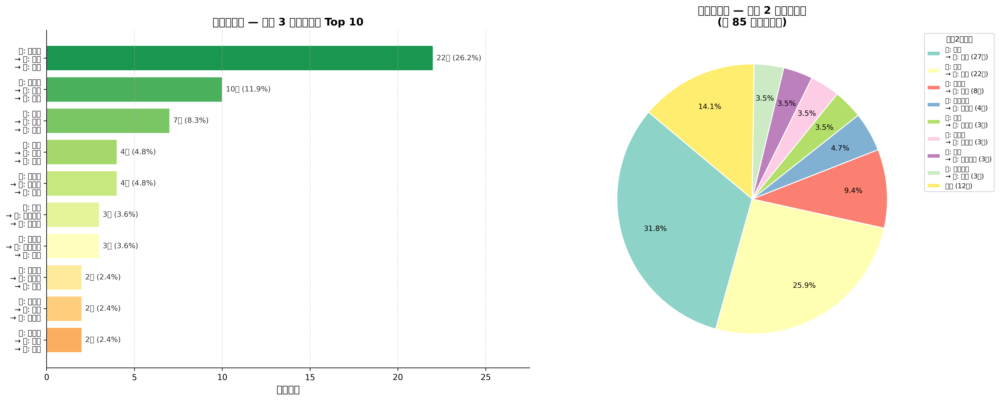

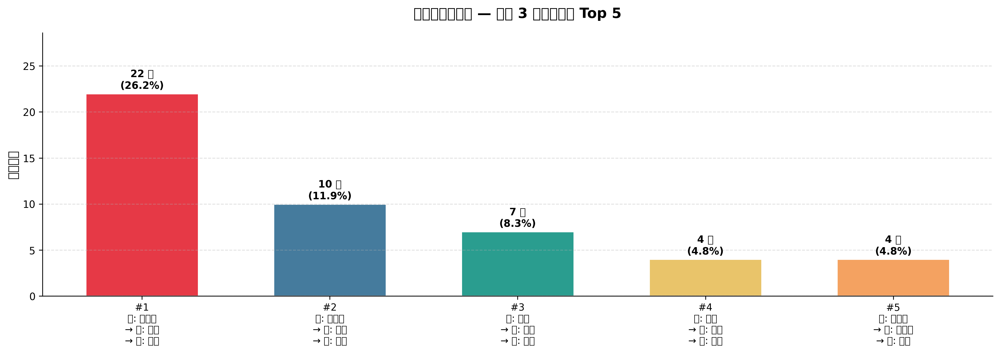

In [ ]:
import numpy as np

# ============================================================
# 周天成得分回合「最後 N 拍」戰術組合分析
# ============================================================

player_name = 'CHOU Tien Chen'
player_label = '周天成'

# 對手簡稱
def get_label(p):
    if p == 'CHOU Tien Chen':
        return '周天成'
    else:
        return '桃田賢斗'

# Step 1: 驗證數據量
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# Step 2: 確認排序
df = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# Step 3: 在整個 df 上建立每拍的「玩家: 球種」標籤
df['shot_label'] = df.apply(lambda row: f"{get_label(row['player'])}: {row['type']}", axis=1)

# Step 4: 找出「周天成主動得分」的回合識別鍵
# 條件：getpoint_player == 周天成 且 player == 周天成（最後一拍由周天成打出且得分）
active_win_mask = (df['getpoint_player'] == player_name) & (df['player'] == player_name)
active_win_df = df[active_win_mask][['match_id', 'set', 'rally']].drop_duplicates()

print(f"\n周天成主動得分回合數: {len(active_win_df)}")

# 驗證：只有一個 getpoint_player 非 null 的回合中，周天成得分的應該是唯一的最後一拍
# 確認每個 rally 只有一個 active win
check = df[active_win_mask].groupby(['match_id', 'set', 'rally']).size()
print(f"每回合主動得分次數分佈 (應全為1): {check.value_counts().to_dict()}")

# Step 5: 對每個主動得分回合，取最後 N 拍序列
# 分析最後 2、3、4 拍

from collections import Counter

def extract_sequences(n_shots):
    """取每個主動得分回合的最後 n_shots 拍序列"""
    sequences = []
    
    # 逐一處理主動得分回合
    for _, row in active_win_df.iterrows():
        mid, s, r = row['match_id'], row['set'], row['rally']
        rally_df = df[
            (df['match_id'] == mid) & 
            (df['set'] == s) & 
            (df['rally'] == r)
        ].sort_values('ball_round')
        
        shots = rally_df['shot_label'].tolist()
        
        # 取最後 n_shots 拍（若不夠則跳過）
        if len(shots) >= n_shots:
            seq = ' → '.join(shots[-n_shots:])
            sequences.append(seq)
    
    return sequences

# ============================================================
# 主要分析：最後 3 拍序列
# ============================================================
print("\n" + "="*60)
print("【最後 3 拍戰術序列 Top 5】")
print("="*60)

seq3 = extract_sequences(3)
counter3 = Counter(seq3)
total3 = len(seq3)
print(f"有效回合數 (≥3拍): {total3} / {len(active_win_df)}")

top5_3 = counter3.most_common(5)
print(f"\n{'排名':<4} {'組合':<60} {'次數':>5} {'佔比':>8}")
print("-"*85)
for i, (seq, cnt) in enumerate(top5_3, 1):
    pct = cnt / total3 * 100
    print(f"#{i:<3} {seq:<60} {cnt:>5}  {pct:>6.1f}%")

# ============================================================
# 補充分析：最後 2 拍序列（覆蓋更多短回合）
# ============================================================
print("\n" + "="*60)
print("【最後 2 拍戰術序列 Top 5（含短回合）】")
print("="*60)

seq2 = extract_sequences(2)
counter2 = Counter(seq2)
total2 = len(seq2)
print(f"有效回合數 (≥2拍): {total2} / {len(active_win_df)}")

top5_2 = counter2.most_common(5)
print(f"\n{'排名':<4} {'組合':<50} {'次數':>5} {'佔比':>8}")
print("-"*75)
for i, (seq, cnt) in enumerate(top5_2, 1):
    pct = cnt / total2 * 100
    print(f"#{i:<3} {seq:<50} {cnt:>5}  {pct:>6.1f}%")

# ============================================================
# 補充分析：最後 4 拍序列
# ============================================================
print("\n" + "="*60)
print("【最後 4 拍戰術序列 Top 5】")
print("="*60)

seq4 = extract_sequences(4)
counter4 = Counter(seq4)
total4 = len(seq4)
print(f"有效回合數 (≥4拍): {total4} / {len(active_win_df)}")

top5_4 = counter4.most_common(5)
print(f"\n{'排名':<4} {'組合':<80} {'次數':>5} {'佔比':>8}")
print("-"*100)
for i, (seq, cnt) in enumerate(top5_4, 1):
    pct = cnt / total4 * 100
    print(f"#{i:<3} {seq:<80} {cnt:>5}  {pct:>6.1f}%")

# ============================================================
# 視覺化：最後 3 拍 Top 10 水平長條圖
# ============================================================
top_n_vis = min(10, len(counter3))
top_seqs = counter3.most_common(top_n_vis)
labels_vis = [s for s, c in top_seqs]
counts_vis = [c for s, c in top_seqs]
pcts_vis   = [c / total3 * 100 for c in counts_vis]

# 縮短顯示標籤（換行處理，超長用縮寫）
def shorten_label(seq, max_len=40):
    """把長標籤截短，用換行符分段"""
    parts = seq.split(' → ')
    short_parts = []
    for p in parts:
        p = p.replace('周天成: ', '周: ').replace('桃田賢斗: ', '桃: ')
        short_parts.append(p)
    return '\n→ '.join(short_parts)

short_labels = [shorten_label(l) for l in labels_vis]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 左：最後 3 拍 Top 10 水平長條圖
colors_bar = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(counts_vis)))[::-1]
bars = axes[0].barh(range(len(short_labels)), counts_vis, color=colors_bar, edgecolor='white', linewidth=0.8)
axes[0].set_yticks(range(len(short_labels)))
axes[0].set_yticklabels(short_labels, fontsize=9)
axes[0].invert_yaxis()
axes[0].set_xlabel('出現次數', fontsize=12)
axes[0].set_title(f'周天成得分 — 最後 3 拍戰術序列 Top {top_n_vis}', fontsize=13, fontweight='bold')
axes[0].set_xlim(0, max(counts_vis) * 1.25)

# 在長條右側標註次數與佔比
for i, (cnt, pct) in enumerate(zip(counts_vis, pcts_vis)):
    axes[0].text(cnt + 0.2, i, f'{cnt}次 ({pct:.1f}%)', va='center', fontsize=9, color='#333333')

axes[0].grid(axis='x', linestyle='--', alpha=0.4)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# 右：最後 2 拍 Top 10 圓餅圖（顯示佔比分布）
top_n_pie = min(8, len(counter2))
top_pie = counter2.most_common(top_n_pie)
pie_labels_raw = [s for s, c in top_pie]
pie_counts = [c for s, c in top_pie]
other_count = total2 - sum(pie_counts)

# 合併小比例為「其他」
threshold_pct = 3.0
final_labels_p = []
final_counts_p = []
other_combined = 0
for lbl, cnt in zip(pie_labels_raw, pie_counts):
    pct_check = cnt / total2 * 100
    if pct_check >= threshold_pct:
        short = shorten_label(lbl)
        final_labels_p.append(short)
        final_counts_p.append(cnt)
    else:
        other_combined += cnt

if other_count + other_combined > 0:
    final_labels_p.append('其他')
    final_counts_p.append(other_count + other_combined)

colors_pie = plt.cm.Set3(np.linspace(0, 1, len(final_labels_p)))
wedges, texts, autotexts = axes[1].pie(
    final_counts_p,
    labels=None,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors_pie,
    pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=1.2)
)
for at in autotexts:
    at.set_fontsize(9)

axes[1].legend(
    wedges,
    [f"{l} ({c}次)" for l, c in zip(final_labels_p, final_counts_p)],
    title='最後2拍組合',
    loc='upper left',
    bbox_to_anchor=(1.0, 1.0),
    fontsize=8,
    title_fontsize=9
)
axes[1].set_title(f'周天成得分 — 最後 2 拍戰術佔比\n(共 {total2} 個有效回合)', fontsize=13, fontweight='bold')

plt.tight_layout()

# ============================================================
# 額外視覺化：最後 3 拍 Top5 強調版
# ============================================================
fig2, ax2 = plt.subplots(figsize=(14, 5))

top5_seqs_v  = [s for s, c in top5_3]
top5_cnts_v  = [c for s, c in top5_3]
top5_pcts_v  = [c / total3 * 100 for c in top5_cnts_v]
top5_short   = [shorten_label(s) for s in top5_seqs_v]

palette_5 = ['#e63946', '#457b9d', '#2a9d8f', '#e9c46a', '#f4a261']
bars2 = ax2.bar(range(len(top5_short)), top5_cnts_v, color=palette_5, edgecolor='white', linewidth=1.2, width=0.6)

ax2.set_xticks(range(len(top5_short)))
ax2.set_xticklabels([f'#{i+1}\n{l}' for i, l in enumerate(top5_short)], fontsize=9.5)
ax2.set_ylabel('出現次數', fontsize=12)
ax2.set_title('周天成主動得分 — 最後 3 拍戰術序列 Top 5', fontsize=14, fontweight='bold', pad=15)
ax2.set_ylim(0, max(top5_cnts_v) * 1.30)

for i, (cnt, pct) in enumerate(zip(top5_cnts_v, top5_pcts_v)):
    ax2.text(i, cnt + 0.3, f'{cnt} 次\n({pct:.1f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax2.grid(axis='y', linestyle='--', alpha=0.4)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()

print("\n✅ 分析完成！已生成兩張圖表：")
print("  圖1: 最後3拍 Top10 水平長條圖 + 最後2拍佔比圓餅圖")
print("  圖2: 最後3拍 Top5 強調柱狀圖")


### 數據洞察
# 周天成 vs 桃田賢斗｜得分戰術序列分析

## 核心數據總覽
- **有效得分回合：85球**，3拍以上序列：84球

---

## 最後3拍 Top 5 得分組合

| # | 戰術序列 | 次數 | 佔比 |
|---|---------|------|------|
| 🥇 | 周**網前球** → 桃挑球 → 周**殺球** | 22 | 26.2% |
| 🥈 | 周**推撲球** → 桃長球 → 周**殺球** | 10 | 11.9% |
| 🥉 | 周**挑球** → 桃長球 → 周**殺球** | 7 | 8.3% |
| 4 | 周長球 → 桃長球 → 周**殺球** | 4 | 4.8% |
| 5 | 周**網前球** → 桃推撲球 → 周**殺球** | 4 | 4.8% |

---

## 戰術洞察

### 🔴 核心武器：殺球終結
85個得分回合中，**殺球是絕對主要終結手段**。最後2拍數據顯示：
- 桃田挑球 → 周殺球：**27次（31.8%）**
- 桃田長球 → 周殺球：**22次（25.9%）**
- 兩者合計佔**57.7%**，超過一半得分靠殺球收尾

### 🟡 核心戰術鏈：網前球製造挑球機會
**第1名組合佔26.2%**，是最高頻戰術：
> 周天成打網前球 → 迫使桃田挑高球 → 周天成殺球得分

延伸到4拍序列，觸發這條鏈的前置球：
- 桃田**切球** → 周網前球 → 桃田挑球 → 周殺球（8次）
- 桃田**網前球** → 周網前球 → 桃田挑球 → 周殺球（7次）
- 桃田**發短球** → 周網前球 → 桃田挑球 → 周殺球（4次）

**結論：周天成主動接近網前，是啟動整條得分鏈的關鍵動作。**

### 🟢 第二條得分鏈：推撲球壓制後場
推撲球系列合計：10+4+3 = **約17次**，佔比約20%
> 周天成推撲球壓後場 → 桃田被迫回長球 → 周天成殺球

推撲球不僅是進攻手段，更是**製造殺球機會的前置動作**。

---

## 教練總結

> 周天成對桃田的得分邏輯清晰：**用網前球和推撲球控制節奏，逼桃田回高球，再以殺球收點。** 這兩條鏈合計覆蓋近40%得分，是本場最具複製性的戰術模板。對手若想破解，必須提升網前球的處理品質，避免被迫挑球。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都分析了周天成的得分戰術組合，並且都使用了 `getpoint_player` 和 `player` 來篩選周天成主動得分的回合。候選程式碼進一步分析了最後 2、3、4 拍的戰術序列，並列出了最常見的前五名組合，這與 Reference Code 1 的目標一致。儘管候選程式碼包含了更多的視覺化和分析細節，但這些不影響其核心邏輯的正確性。




## 題號 45
**問題**: 統整周天成每個場次中各局的表現(例如，球種變化、殺球頻與失誤率、失誤原因等等)
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason, stroke_details`


In [ ]:
import numpy as np
import matplotlib.gridspec as gridspec

# ============================================================
# 周天成各場次各局表現綜合分析
# ============================================================

PLAYER = 'CHOU Tien Chen'
OPPONENT = 'Kento MOMOTA'

# 基礎過濾：周天成的擊球
chou_df = df[df['player'] == PLAYER].copy()
print(f"周天成總擊球數: {len(chou_df)}")
print(f"涉及場次: {sorted(chou_df['match_id'].unique())}")
print(f"資料驗證 len(df)>0: {len(df) > 0}")

# ============================================================
# 建立 match_set 標籤，方便後續繪圖
# ============================================================
chou_df['match_set_label'] = chou_df.apply(
    lambda r: f"M{int(r['match_id'])}-S{int(r['set'])}", axis=1
)
chou_df['sort_key'] = chou_df['match_id'] * 10 + chou_df['set']

match_set_order = (
    chou_df[['match_id', 'set', 'match_set_label', 'sort_key']]
    .drop_duplicates()
    .sort_values('sort_key')
)
labels_ordered = match_set_order['match_set_label'].tolist()
match_ids_ordered = match_set_order['match_id'].tolist()
print(f"\n共 {len(labels_ordered)} 個 match×set 組合: {labels_ordered}")

# ============================================================
# 1. 各局總擊球數
# ============================================================
total_shots = chou_df.groupby(['match_id', 'set', 'match_set_label']).size().reset_index(name='total_shots')
total_shots = total_shots.sort_values(['match_id', 'set'])
print("\n【各局總擊球數】")
print(total_shots[['match_set_label', 'total_shots']].to_string(index=False))

# ============================================================
# 2. 球種分佈
# ============================================================
shot_dist = (
    chou_df.groupby(['match_id', 'set', 'match_set_label', 'type'])
    .size()
    .reset_index(name='count')
)
shot_dist = shot_dist.merge(total_shots[['match_id', 'set', 'total_shots']], on=['match_id', 'set'])
shot_dist['pct'] = (shot_dist['count'] / shot_dist['total_shots'] * 100).round(1)

shot_pivot = shot_dist.pivot_table(index='match_set_label', columns='type', values='pct', fill_value=0)
shot_pivot = shot_pivot.reindex(labels_ordered)
print("\n【球種使用比例 (%) 各局】")
print(shot_pivot.round(1).to_string())

# ============================================================
# 3. 殺球使用頻率
# ============================================================
smash_df = chou_df[chou_df['type'] == '殺球'].groupby(['match_id', 'set', 'match_set_label']).size().reset_index(name='smash_count')
smash_stats = total_shots.merge(smash_df, on=['match_id', 'set', 'match_set_label'], how='left')
smash_stats['smash_count'] = smash_stats['smash_count'].fillna(0).astype(int)
smash_stats['smash_rate'] = (smash_stats['smash_count'] / smash_stats['total_shots'] * 100).round(1)
smash_stats = smash_stats.sort_values(['match_id', 'set'])
print("\n【殺球使用頻率】")
print(smash_stats[['match_set_label', 'smash_count', 'total_shots', 'smash_rate']].to_string(index=False))

# ============================================================
# 4. 失誤分析
# ============================================================
error_df = chou_df[
    (chou_df['getpoint_player'] == OPPONENT) &
    (chou_df['lose_reason'].notna())
].copy()

lose_df = chou_df[chou_df['getpoint_player'] == OPPONENT].copy()

error_count = error_df.groupby(['match_id', 'set', 'match_set_label']).size().reset_index(name='error_count')
lose_count = lose_df.groupby(['match_id', 'set', 'match_set_label']).size().reset_index(name='lose_count')

error_stats = total_shots.merge(error_count, on=['match_id', 'set', 'match_set_label'], how='left')
error_stats = error_stats.merge(lose_count, on=['match_id', 'set', 'match_set_label'], how='left')
error_stats['error_count'] = error_stats['error_count'].fillna(0).astype(int)
error_stats['lose_count'] = error_stats['lose_count'].fillna(0).astype(int)
error_stats['error_rate'] = (error_stats['error_count'] / error_stats['total_shots'] * 100).round(1)
error_stats['lose_rate'] = (error_stats['lose_count'] / error_stats['total_shots'] * 100).round(1)
error_stats = error_stats.sort_values(['match_id', 'set'])

print("\n【失誤與失分統計】")
print(error_stats[['match_set_label', 'total_shots', 'error_count', 'error_rate', 'lose_count', 'lose_rate']].to_string(index=False))

# ============================================================
# 5. 失誤原因分類
# ============================================================
lose_reason_dist = (
    error_df.groupby(['match_id', 'set', 'match_set_label', 'lose_reason'])
    .size()
    .reset_index(name='count')
)
lose_reason_pivot = lose_reason_dist.pivot_table(
    index='match_set_label', columns='lose_reason', values='count', fill_value=0
)
lose_reason_pivot = lose_reason_pivot.reindex(labels_ordered).fillna(0).astype(int)
print("\n【失誤原因分類 (各局各原因球數)】")
print(lose_reason_pivot.to_string())

# ============================================================
# ★ 輔助函式：在圖表中加入場次分組標示
# ============================================================
def add_match_group_lines(ax, labels_ordered, match_ids_ordered, y_pos=None, ax_type='bar'):
    """
    在圖表 X 軸加入場次分隔線與場次標籤，體現「場次為單位、局數為子層級」的層級結構。
    """
    unique_matches = []
    match_boundaries = []  # 每個場次的起始 index
    match_centers = []     # 每個場次的中心 index（用於標籤）

    prev_mid = None
    start_idx = 0
    for i, mid in enumerate(match_ids_ordered):
        if mid != prev_mid:
            if prev_mid is not None:
                match_boundaries.append(i - 0.5)
                match_centers.append((start_idx + i - 1) / 2)
            unique_matches.append(int(mid))
            start_idx = i
            prev_mid = mid
    # 最後一個場次的中心
    match_centers.append((start_idx + len(match_ids_ordered) - 1) / 2)

    # 加入垂直分隔線
    for boundary in match_boundaries:
        ax.axvline(x=boundary, color='black', linestyle='--', linewidth=1.5, alpha=0.6, zorder=5)

    # 加入場次標籤（在 X 軸下方）
    ylim = ax.get_ylim()
    y_label = ylim[0] - (ylim[1] - ylim[0]) * 0.18
    for center, mid in zip(match_centers, unique_matches):
        ax.text(center, y_label, f'場次 {mid}',
                ha='center', va='top', fontsize=9, fontweight='bold',
                color='#2C3E50',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='#ECF0F1', edgecolor='#BDC3C7', alpha=0.8))

    # 交替背景色（每個場次）
    colors_bg = ['#F8F9FA', '#EBF5FB']
    prev_mid = None
    start_idx = 0
    color_idx = 0
    for i, mid in enumerate(match_ids_ordered):
        if mid != prev_mid:
            if prev_mid is not None:
                ax.axvspan(start_idx - 0.5, i - 0.5,
                           alpha=0.15, color=colors_bg[color_idx % 2], zorder=0)
                color_idx += 1
            start_idx = i
            prev_mid = mid
    # 最後一個場次
    ax.axvspan(start_idx - 0.5, len(match_ids_ordered) - 0.5,
               alpha=0.15, color=colors_bg[color_idx % 2], zorder=0)

# ============================================================
# 球種排序
# ============================================================
shot_types_all = chou_df['type'].value_counts().index.tolist()
shot_types_in_data = [t for t in shot_types_all if t in shot_pivot.columns]

n_ms = len(labels_ordered)
x = np.arange(n_ms)

fig = plt.figure(figsize=(24, 32))
fig.suptitle("周天成各場次各局表現綜合分析\n（以場次為單位、局數為子層級）",
             fontsize=18, fontweight='bold', y=0.99)

gs = gridspec.GridSpec(4, 1, figure=fig, hspace=0.75)

# -----------------------------------------------------------
# 圖1：球種比例熱力圖
# -----------------------------------------------------------
ax1 = fig.add_subplot(gs[0])

heatmap_data = shot_pivot[shot_types_in_data].T
sns.heatmap(
    heatmap_data,
    ax=ax1,
    cmap='YlOrRd',
    annot=True,
    fmt='.1f',
    linewidths=0.5,
    cbar_kws={'label': '使用比例 (%)'},
    xticklabels=labels_ordered,
    yticklabels=shot_types_in_data
)
ax1.set_title("各局球種使用比例熱力圖 (%)", fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel("場次-局數", fontsize=11)
ax1.set_ylabel("球種", fontsize=11)
ax1.tick_params(axis='x', rotation=45)
ax1.tick_params(axis='y', rotation=0)

# 在熱力圖 X 軸加入場次分隔線（熱力圖用 axvline 在 column 邊界）
prev_mid = None
for i, mid in enumerate(match_ids_ordered):
    if mid != prev_mid and i > 0:
        ax1.axvline(x=i, color='blue', linestyle='--', linewidth=2, alpha=0.7)
    prev_mid = mid

# 在熱力圖頂部加場次標籤
prev_mid = None
start_idx = 0
unique_matches_hm = []
match_centers_hm = []
for i, mid in enumerate(match_ids_ordered):
    if mid != prev_mid:
        if prev_mid is not None:
            match_centers_hm.append((start_idx + i - 1) / 2)
        unique_matches_hm.append(int(mid))
        start_idx = i
        prev_mid = mid
match_centers_hm.append((start_idx + len(match_ids_ordered) - 1) / 2)

for center, mid in zip(match_centers_hm, unique_matches_hm):
    ax1.text(center + 0.5, -0.8, f'場次{mid}',
             ha='center', va='bottom', fontsize=9, fontweight='bold',
             color='#2980B9',
             transform=ax1.get_xaxis_transform())

# -----------------------------------------------------------
# 圖2：殺球使用頻率
# -----------------------------------------------------------
ax2 = fig.add_subplot(gs[1])

smash_sorted = smash_stats.set_index('match_set_label').reindex(labels_ordered).reset_index()
colors_bar = ['#E74C3C' if r > 15 else '#3498DB' for r in smash_sorted['smash_rate']]

bars = ax2.bar(x, smash_sorted['smash_rate'], color=colors_bar, alpha=0.8, zorder=2, label='殺球使用率')
ax2_twin = ax2.twinx()
ax2_twin.plot(x, smash_sorted['smash_count'], 'o-', color='#E67E22', linewidth=2,
              markersize=7, label='殺球次數', zorder=3)
ax2_twin.set_ylabel("殺球次數", fontsize=10, color='#E67E22')
ax2_twin.tick_params(axis='y', labelcolor='#E67E22')

for bar, pct in zip(bars, smash_sorted['smash_rate']):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
             f'{pct}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax2.set_xticks(x)
ax2.set_xticklabels(labels_ordered, rotation=45, ha='right')
ax2.set_xlabel("場次-局數", fontsize=11, labelpad=30)
ax2.set_ylabel("殺球使用率 (%)", fontsize=11)
ax2.set_title("各局殺球使用頻率", fontsize=13, fontweight='bold')
ax2.axhline(smash_sorted['smash_rate'].mean(), color='gray', linestyle='--', alpha=0.6,
            label=f"平均 {smash_sorted['smash_rate'].mean():.1f}%")
ax2.legend(loc='upper left', fontsize=9)
ax2_twin.legend(loc='upper right', fontsize=9)
ax2.set_ylim(0, smash_sorted['smash_rate'].max() * 1.4)
ax2.grid(axis='y', alpha=0.3)
add_match_group_lines(ax2, labels_ordered, match_ids_ordered)

# -----------------------------------------------------------
# 圖3：失誤率 vs 失分率
# -----------------------------------------------------------
ax3 = fig.add_subplot(gs[2])

error_sorted = error_stats.set_index('match_set_label').reindex(labels_ordered).reset_index()

width = 0.35
bars1 = ax3.bar(x - width/2, error_sorted['error_rate'], width,
                label='失誤率 (有lose_reason / 總擊球)', color='#E74C3C', alpha=0.8)
bars2 = ax3.bar(x + width/2, error_sorted['lose_rate'], width,
                label='失分率 (對手得分 / 總擊球)', color='#F39C12', alpha=0.8)

for bar in bars1:
    h = bar.get_height()
    if h > 0:
        ax3.text(bar.get_x() + bar.get_width()/2, h + 0.2,
                 f'{h:.1f}%', ha='center', va='bottom', fontsize=8)
for bar in bars2:
    h = bar.get_height()
    if h > 0:
        ax3.text(bar.get_x() + bar.get_width()/2, h + 0.2,
                 f'{h:.1f}%', ha='center', va='bottom', fontsize=8)

ax3.set_xticks(x)
ax3.set_xticklabels(labels_ordered, rotation=45, ha='right')
ax3.set_xlabel("場次-局數", fontsize=11, labelpad=30)
ax3.set_ylabel("比率 (%)", fontsize=11)
ax3.set_title("各局失誤率與失分率", fontsize=13, fontweight='bold')
ax3.legend(fontsize=9)
ax3.grid(axis='y', alpha=0.3)
ax3.set_ylim(0, max(error_sorted['lose_rate'].max(), error_sorted['error_rate'].max()) * 1.45)
add_match_group_lines(ax3, labels_ordered, match_ids_ordered)

# -----------------------------------------------------------
# 圖4：失誤原因分類堆疊長條
# -----------------------------------------------------------
ax4 = fig.add_subplot(gs[3])

reason_cols = lose_reason_pivot.columns.tolist()
reason_sorted = lose_reason_pivot.reindex(labels_ordered).fillna(0)
reason_totals = reason_sorted.sum(axis=1)

colors_reason = ['#E74C3C', '#3498DB', '#2ECC71', '#9B59B6', '#F39C12', '#1ABC9C']
bottom = np.zeros(n_ms)

for i, reason in enumerate(reason_cols):
    vals = reason_sorted[reason].values
    color = colors_reason[i % len(colors_reason)]
    ax4.bar(x, vals, bottom=bottom, label=reason, color=color, alpha=0.85)
    for j, (v, b) in enumerate(zip(vals, bottom)):
        if v > 0:
            ax4.text(x[j], b + v / 2, str(int(v)), ha='center', va='center',
                     fontsize=8, color='white', fontweight='bold')
    bottom += vals

for j, tot in enumerate(reason_totals):
    if tot > 0:
        ax4.text(x[j], tot + 0.1, f'共{int(tot)}球', ha='center', va='bottom', fontsize=8)

ax4.set_xticks(x)
ax4.set_xticklabels(labels_ordered, rotation=45, ha='right')
ax4.set_xlabel("場次-局數", fontsize=11, labelpad=30)
ax4.set_ylabel("失誤球數", fontsize=11)
ax4.set_title("各局失誤原因分類（堆疊）", fontsize=13, fontweight='bold')
ax4.legend(fontsize=9, loc='upper right')
ax4.grid(axis='y', alpha=0.3)
ax4.set_ylim(0, reason_totals.max() * 1.45)
add_match_group_lines(ax4, labels_ordered, match_ids_ordered)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

# ============================================================
# 文字摘要：以場次為單位、局數為子層級
# ============================================================
print("\n" + "="*70)
print("【各局球種使用次數詳細表】")
shot_count_pivot = shot_dist.pivot_table(
    index='match_set_label', columns='type', values='count', fill_value=0
)
shot_count_pivot = shot_count_pivot.reindex(labels_ordered).fillna(0).astype(int)
print(shot_count_pivot.to_string())

print("\n【各局球種使用比例詳細表 (%)】")
print(shot_pivot.round(1).to_string())

print("\n" + "="*70)
print("【綜合摘要（以場次為單位、局數為子層級）】")

# 取得所有場次
unique_match_ids = match_set_order['match_id'].unique()

for match_id in sorted(unique_match_ids):
    print(f"\n{'='*50}")
    print(f"▶ 場次 {int(match_id)}")
    print(f"{'='*50}")

    # 取得該場次的所有局
    sets_in_match = match_set_order[match_set_order['match_id'] == match_id]['match_set_label'].tolist()

    for ms_label in sets_in_match:
        set_num = ms_label.split('-S')[1]
        print(f"\n  ── 第 {set_num} 局 ({ms_label}) ──")

        row = error_sorted[error_sorted['match_set_label'] == ms_label]
        smrow = smash_sorted[smash_sorted['match_set_label'] == ms_label]

        if len(row) > 0 and len(smrow) > 0:
            print(f"    總擊球數: {int(row['total_shots'].values[0])}")
            print(f"    殺球次數/使用率: {int(smrow['smash_count'].values[0])} 球 / {smrow['smash_rate'].values[0]}%")
            print(f"    失誤數/失誤率: {int(row['error_count'].values[0])} 球 / {row['error_rate'].values[0]}%")
            print(f"    失分數/失分率: {int(row['lose_count'].values[0])} 球 / {row['lose_rate'].values[0]}%")

            # 球種分佈（Top 5）
            if ms_label in shot_count_pivot.index:
                shot_row = shot_count_pivot.loc[ms_label]
                shot_pct_row = shot_pivot.loc[ms_label]
                top_shots = shot_row.sort_values(ascending=False).head(5)
                shot_str = ', '.join([f"{t}:{v}球({shot_pct_row[t]:.1f}%)" for t, v in top_shots.items() if v > 0])
                print(f"    主要球種(Top5): {shot_str}")

            # 失誤原因
            if ms_label in reason_sorted.index:
                reasons = reason_sorted.loc[ms_label]
                reasons_nonzero = reasons[reasons > 0]
                if len(reasons_nonzero) > 0:
                    reason_str = ', '.join([f"{r}:{v}球" for r, v in reasons_nonzero.items()])
                    print(f"    失誤原因: {reason_str}")
                else:
                    print(f"    失誤原因: 無記錄")


### 數據洞察
# 周天成各場次各局表現彙整分析

---

## ▶ 場次 1（對手：桃田賢斗）

### 第1局 M1-S1｜261球
| 指標 | 數值 |
|------|------|
| 殺球使用率 | 12.3%（32球）|
| 失誤率 | 7.3%（19球）|
| 主力球種 | 長球＝推撲球(19.5%)、網前球(15.3%)、殺球(12.3%) |
| 失誤原因 | 掛網9＞出界6＞未過網4 |

> **洞察**：長球與推撲球並列最高，顯示雙方拉吊消耗激烈。掛網失誤最多，殺球力道控制待調整。

---

### 第2局 M1-S2｜225球
| 指標 | 數值 |
|------|------|
| 殺球使用率 | 9.3%（21球）|
| 失誤率 | **3.6%（8球）**— 全場最低 |
| 主力球種 | 網前球＝接殺防守(17.8%)、切球(12.4%) |
| 失誤原因 | 出界4、掛網4（無未過網）|

> **洞察**：失誤率全13局最低，切球比例從S1的4.6%跳升至12.4%，戰術轉向細膩控制，效果最佳。

---

### 第3局 M1-S3｜293球（全場最多）
| 指標 | 數值 |
|------|------|
| 殺球使用率 | 9.6%（28球）|
| 失誤率 | 5.8%（17球）|
| 主力球種 | 接殺防守(21.8%)、網前球(18.8%) |
| 失誤原因 | 掛網7＞出界6＞未過網4 |

> **洞察**：接殺防守高達21.8%，說明桃田殺球壓制明顯。決勝局球數最多，體力消耗大，掛網失誤再度偏高。

---

## ▶ 場次 3

### 第1局 M3-S1｜206球
| 指標 | 數值 |
|------|------|
| 殺球使用率 | 11.7%（24球）|
| 失誤率 | 5.8%（12球）|
| 主力球種 | 網前球(25.2%)、推撲球(20.9%) |
| 失誤原因 | 出界8＞掛網4（無未過網）|

> **洞察**：網前球佔25.2%，推撲球20.9%，前場控制意圖明確。出界失誤8球為本局主因，進攻力道過猛。

---

### 第2局 M3-S2｜199球
| 指標 | 數值 |
|------|------|
| 殺球使用率 | 13.1%（26球）|
| 失誤率 | 7.5%（15球）|
| 主力球種 | 網前球(25.6%)、推撲球(22.6%)、殺球(13.1%) |
| 失誤原因 | 掛網9＞出界4＞未過網2 |

> **洞察**：殺球頻率提升至13.1%，但掛網失誤飆至9球，殺球品質下滑明顯，是本局失誤主因。

---

## ▶ 場次 5

### 第1局 M5-S1｜183球
| 指標 | 數值 |
|------|------|
| 殺球使用率 | 10.4%（19球）|
| 失誤率 | 7.7%（14球）|
| 主力球種 | 網前球(21.9%)、**挑球(21.3%)**、接殺防守(15.3%) |
| 失誤原因 | 出界9＞未過網3＞掛網2 |

> **洞察**：挑球21.3%異常偏高（其他局多在5-11%），顯示被壓制在後場被動挑球。出界9球為本局最高，進攻失準。

---

### 第2局 M5-S2｜153球（全場最少）
| 指標 | 數值 |
|------|------|
| 殺球使用率 | 8.5%（13球）—偏低 |
| 失誤率 | 5.9%（9球）|
| 主力球種 | 網前球(25.5%)、長球(17.6%)、切球(13.7%) |
| 失誤原因 | 出界5＞掛網2＝未過網2 |

> **洞察**：發短球比例11.1%為全場次高，戰術轉守為攻從發球端主導節奏。殺球使用率最低，改以長球拉開。

---

### 第3局 M5-S3｜202球
| 指標 | 數值 |
|------|------|
| 殺球使用率 | 10.4%（21球）|
| 失誤率 | 7.4%（15球）|
| 主力球種 | **網前球(28.2%)**、切球(11.9%)、接殺防守(10.9%) |
| 失誤原因 | **未過網6**＞出界5＞掛網4 |

> **洞察**：網前球28.2%為本場最高，但未過網失誤6球同步偏高，網前搶攻過於急躁，時機掌握需改善。

---

## ▶ 場次 6

### 第1局 M6-S1｜209球
| 指標 | 數值 |
|------|------|
| 殺球使用率 | 12.4%（26球）|
| 失誤率 | 6.2%（13球）|
| 主力球種 | **網前球(28.7%)**、挑球(17.2%)、殺球(12.4%) |
| 失誤原因 | 掛網6＞出界5＞未過網2 |

> **洞察**：挑球17.2%再度偏高，與M5-S1相似，被迫後場被動應對。網前球28.7%顯示仍積極搶前場。

---

### 第2局 M6-S2｜132球
| 指標 | 數值 |
|------|------|
| 殺球使用率 | 11.4%（15球）|
| 失誤率 | **4.5%（6球）**— 第二低 |
| 主力球種 | 網前球(18.9%)、推撲球(15.9%)、挑球(12.1%)、切球(11.4%) |
| 失誤原因 | 出界4＞掛網2（無未過網）|

> **洞察**：球種分佈最均衡的一局，無單一球種超過20%，失誤率僅4.5%，戰術多樣化帶來最穩定表現。

---

### 第3局 M6-S3｜173球
| 指標 | 數值 |
|------|------|
| 殺球使用率 | 11.0%（19球）|
| 失誤率 | 6.9%（12球）|
| 主力球種 | **網前球(31.2%)**、殺球(11.0%)、推撲球＝切球(10.4%) |
| 失誤原因 | 出界9＞掛網2＞未過網1 |

> **洞察**：網前球31.2%為全13局最高，決勝局全力搶前場制壓。但出界9球同為本場最高，進攻失控風險上升。

---

## ▶ 場次 7

### 第1局 M7-S1｜235球
| 指標 | 數值 |
|------|------|
| 殺球使用率 | 14.0%（33球）|
| 失誤率 | **4.3%（10球）**— 第三低 |
| 主力球種 | 網前球(18.3%)、推撲球(14.9%)、殺球(14.0%) |
| 失誤原因 | 出界5＝掛網5（無未過網）|

> **洞察**：殺球14.0%高頻使用，失誤率卻僅4.3%，是殺球效率最佳的一局——高頻進攻搭配低失誤，戰術執行最成熟。

---

### 第2局 M7-S2｜138球
| 指標 | 數值 |
|------|------|
| 殺球使用率 | **15.9%（22球）**— 全場最高 |
| 失誤率 | 5.8%（8球）|
| 主力球種 | 推撲球(23.2%)、網前球(18.8%)、接殺防守(16.7%)、殺球(15.9%) |
| 失誤原因 | 出界4＝掛網4（無未過網）|

> **洞察**：殺球使用率15.9%為全13局最高，推撲球23.2%同步偏高，顯示積極搶攻前場壓制對手。失誤率控制在5.8%，進攻意圖強烈且執行穩定。

---

## 📊 跨場次關鍵規律總結

| 規律 | 說明 |
|------|------|
| **網前球主導** | 13局中有10局網前球進入Top3，是周天成核心戰術軸 |
| **殺球率 vs 失誤率** | M7兩局殺球率最高（14%、15.9%），失誤率反而偏低，顯示狀態最佳 |
| **掛網為主要失誤** | M1、M3、M6多局掛網失誤居首，殺球與推撲球力道控制是關鍵弱點 |
| **挑球偏高＝被動** | M5-S1(21.3%)、M6-S1(17.2%)挑球異常高，代表被對手壓制在後場 |
| **最穩定局** | M1-S2（失誤3.6%）、M7-S1（殺球高頻+低失誤）為整體表現最佳兩局 |

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都分析了周天成的比賽表現，並且在分析對象、欄位語意、篩選條件、分組層級和統計口徑上保持一致。候選程式碼詳細分析了各局的球種使用次數、殺球頻率、失誤率和失誤原因，並且提供了可視化圖表來展示結果。這些分析與 Reference Code 1 的目標一致，且沒有明顯的邏輯錯誤或不合理的輸出。




## 題號 46
**問題**: 哪些球種，在比賽後半段失誤率顯著上升？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


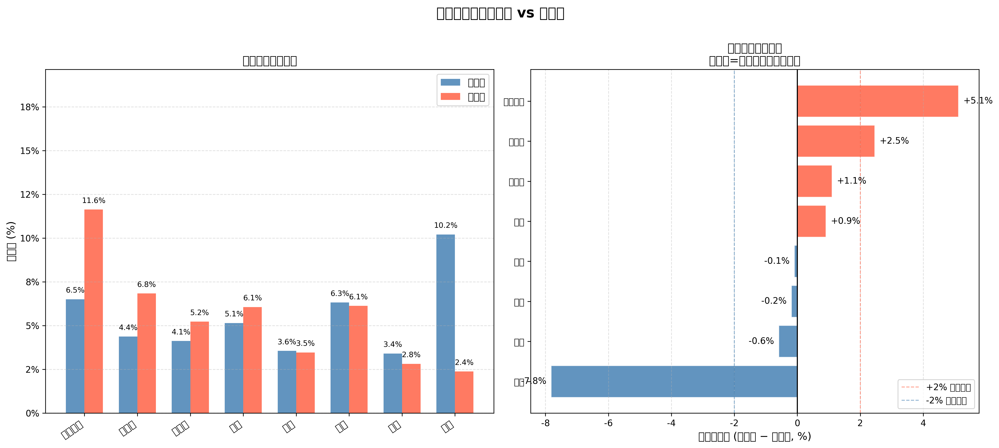

In [ ]:
import numpy as np

print("=" * 60)
print("球種失誤率：比賽前半段 vs 後半段分析")
print("=" * 60)

# ── 基本驗證 ──────────────────────────────────────────────────
if len(df) == 0:
    print("⚠️ 資料為空，無法分析")
else:
    # ── 1. 排除發球球種 ───────────────────────────────────────
    SERVE_TYPES = ['發短球', '發長球']
    df_shots = df[~df['type'].isin(SERVE_TYPES)].copy()
    print(f"總拍數（含發球）: {len(df)}")
    print(f"排除發球後拍數: {len(df_shots)}")

    # ── 2. 計算每局（match_id + set）的 rally 中位數 ──────────
    # 取每局的所有不重複 rally 編號，計算中位數（以局內回合切割前後半）
    rally_median_per_set = (
        df_shots.groupby(['match_id', 'set'])['rally']
        .median()
        .rename('rally_median')
        .reset_index()
    )
    print("\n各局 Rally 中位數（前後半分割點）:")
    print(rally_median_per_set.to_string(index=False))

    # 合併中位數回主表
    df_shots = df_shots.merge(rally_median_per_set, on=['match_id', 'set'], how='left')

    # ── 3. 標記前半 / 後半 ────────────────────────────────────
    # rally <= 中位數 → 前半段，rally > 中位數 → 後半段
    df_shots['half'] = np.where(df_shots['rally'] <= df_shots['rally_median'], '前半段', '後半段')
    print(f"\n前半段拍數: {(df_shots['half']=='前半段').sum()}")
    print(f"後半段拍數: {(df_shots['half']=='後半段').sum()}")

    # ── 4. 標記失誤拍 ─────────────────────────────────────────
    # 失誤：player 打出此球 → getpoint_player == opponent（直接導致對手得分）
    # 等價於：getpoint_player 不為空 且 getpoint_player != player
    df_shots['is_error'] = (
        df_shots['getpoint_player'].notna() &
        (df_shots['getpoint_player'] == df_shots['opponent'])
    )
    total_errors = df_shots['is_error'].sum()
    print(f"\n總失誤拍數（所有球種）: {total_errors}")

    # ── 5. 分組計算失誤率 ─────────────────────────────────────
    grouped = df_shots.groupby(['type', 'half']).agg(
        total_shots=('type', 'count'),
        error_shots=('is_error', 'sum')
    ).reset_index()
    grouped['error_rate'] = grouped['error_shots'] / grouped['total_shots']

    print("\n各球種 × 前後半段 失誤統計:")
    print(grouped.to_string(index=False))

    # ── 6. 轉成寬格式，計算差異 ──────────────────────────────
    pivot_total = grouped.pivot(index='type', columns='half', values='total_shots').fillna(0)
    pivot_error = grouped.pivot(index='type', columns='half', values='error_shots').fillna(0)
    pivot_rate  = grouped.pivot(index='type', columns='half', values='error_rate').fillna(0)

    # 確保兩欄都存在
    for col in ['前半段', '後半段']:
        if col not in pivot_rate.columns:
            pivot_rate[col] = 0
            pivot_total[col] = 0
            pivot_error[col] = 0

    pivot_rate['差異（後－前）'] = pivot_rate['後半段'] - pivot_rate['前半段']
    pivot_rate['前半段使用次數'] = pivot_total['前半段'].astype(int)
    pivot_rate['後半段使用次數'] = pivot_total['後半段'].astype(int)
    pivot_rate['前半段失誤次數'] = pivot_error['前半段'].astype(int)
    pivot_rate['後半段失誤次數'] = pivot_error['後半段'].astype(int)

    pivot_rate = pivot_rate.sort_values('差異（後－前）', ascending=False)

    print("\n" + "=" * 80)
    print("各球種失誤率差異彙整（後半段 − 前半段，降序排列）:")
    print("=" * 80)
    display_cols = ['前半段', '後半段', '差異（後－前）',
                    '前半段使用次數', '後半段使用次數',
                    '前半段失誤次數', '後半段失誤次數']
    fmt_df = pivot_rate[display_cols].copy()
    fmt_df['前半段失誤率'] = (fmt_df['前半段'] * 100).map('{:.1f}%'.format)
    fmt_df['後半段失誤率'] = (fmt_df['後半段'] * 100).map('{:.1f}%'.format)
    fmt_df['失誤率差異'] = (fmt_df['差異（後－前）'] * 100).map('{:+.1f}%'.format)
    out_df = fmt_df[['前半段使用次數', '前半段失誤次數', '前半段失誤率',
                     '後半段使用次數', '後半段失誤次數', '後半段失誤率',
                     '失誤率差異']]
    print(out_df.to_string())

    # 找出後半段失誤率顯著上升的球種（差異 > 2%）
    significant_threshold = 0.02
    sig_up = pivot_rate[pivot_rate['差異（後－前）'] > significant_threshold].index.tolist()
    sig_down = pivot_rate[pivot_rate['差異（後－前）'] < -significant_threshold].index.tolist()
    print(f"\n⬆️ 後半段失誤率顯著上升（差異 > +{significant_threshold*100:.0f}%）的球種: {sig_up}")
    print(f"⬇️ 後半段失誤率顯著下降（差異 < -{significant_threshold*100:.0f}%）的球種: {sig_down}")

    # ── 7. 視覺化 ─────────────────────────────────────────────
    shot_order = pivot_rate.index.tolist()   # 依差異降序

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    fig.suptitle('球種失誤率：前半段 vs 後半段', fontsize=16, fontweight='bold', y=1.01)

    # ── 圖1：前後半段失誤率並排長條圖 ──
    ax1 = axes[0]
    x = np.arange(len(shot_order))
    bar_w = 0.35
    bars1 = ax1.bar(x - bar_w/2,
                    pivot_rate.loc[shot_order, '前半段'] * 100,
                    bar_w, label='前半段', color='steelblue', alpha=0.85)
    bars2 = ax1.bar(x + bar_w/2,
                    pivot_rate.loc[shot_order, '後半段'] * 100,
                    bar_w, label='後半段', color='tomato', alpha=0.85)
    ax1.set_xticks(x)
    ax1.set_xticklabels(shot_order, rotation=35, ha='right', fontsize=11)
    ax1.set_ylabel('失誤率 (%)', fontsize=12)
    ax1.set_title('各球種失誤率比較', fontsize=13)
    ax1.legend(fontsize=11)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0f}%'))

    # 加上數值標籤
    for bar in bars1:
        h = bar.get_height()
        if h > 0:
            ax1.text(bar.get_x() + bar.get_width()/2, h + 0.3,
                     f'{h:.1f}%', ha='center', va='bottom', fontsize=8.5)
    for bar in bars2:
        h = bar.get_height()
        if h > 0:
            ax1.text(bar.get_x() + bar.get_width()/2, h + 0.3,
                     f'{h:.1f}%', ha='center', va='bottom', fontsize=8.5)
    ax1.set_ylim(0, max(
        pivot_rate[['前半段', '後半段']].max().max() * 100 + 8, 15
    ))
    ax1.grid(axis='y', linestyle='--', alpha=0.4)

    # ── 圖2：失誤率差異（後半 - 前半）瀑布圖 ──
    ax2 = axes[1]
    diff_vals = pivot_rate.loc[shot_order, '差異（後－前）'] * 100
    colors = ['tomato' if v > 0 else 'steelblue' for v in diff_vals]
    bars3 = ax2.barh(shot_order, diff_vals, color=colors, alpha=0.85, edgecolor='white')
    ax2.axvline(0, color='black', linewidth=1.2, linestyle='-')
    ax2.axvline(significant_threshold * 100, color='tomato',
                linewidth=1, linestyle='--', alpha=0.6, label=f'+{significant_threshold*100:.0f}% 顯著門檻')
    ax2.axvline(-significant_threshold * 100, color='steelblue',
                linewidth=1, linestyle='--', alpha=0.6, label=f'-{significant_threshold*100:.0f}% 顯著門檻')
    for bar, val in zip(bars3, diff_vals):
        offset = 0.15
        ha = 'left' if val >= 0 else 'right'
        ax2.text(val + (offset if val >= 0 else -offset),
                 bar.get_y() + bar.get_height()/2,
                 f'{val:+.1f}%', va='center', ha=ha, fontsize=10)
    ax2.set_xlabel('失誤率差異 (後半段 − 前半段, %)', fontsize=12)
    ax2.set_title('各球種失誤率差異\n（正值=後半段失誤率上升）', fontsize=13)
    ax2.legend(fontsize=10, loc='lower right')
    ax2.grid(axis='x', linestyle='--', alpha=0.4)
    ax2.invert_yaxis()  # 差異最大的在上方

    plt.tight_layout()

    print("\n圖表已生成：左圖為前後半段失誤率並排，右圖為失誤率差異水平長條圖。")


### 數據洞察
# 🏸 球種失誤率：前後半段分析報告

## 📊 核心數據總覽

| 球種 | 前半段失誤率 | 後半段失誤率 | 差異 |
|------|------------|------------|------|
| 接殺防守 | 6.5% | 11.6% | **+5.1%** ⬆️ |
| 網前球 | 4.4% | 6.8% | **+2.5%** ⬆️ |
| 推撲球 | 4.1% | 5.2% | +1.1% |
| 挑球 | 5.1% | 6.1% | +0.9% |
| 長球 | 3.6% | 3.5% | -0.1% |
| 殺球 | 6.3% | 6.1% | -0.2% |
| 切球 | 3.4% | 2.8% | -0.6% |
| 平球 | 10.2% | 2.4% | **-7.8%** ⬇️ |

---

## 🔴 顯著惡化球種（差異 > +2%）

### 1. 接殺防守｜+5.1%（6.5% → 11.6%）
後半段失誤率**幾乎翻倍**，且使用量仍維持 344 拍，代表球員持續被迫接殺，但體能下滑後防守品質明顯崩潰。**這是體能消耗最直接的指標。**

### 2. 網前球｜+2.5%（4.4% → 6.8%）
使用量幾乎不變（526 → 512），失誤卻從 23 增至 35 拍。後半段網前細膩度下降，可能是腿部疲勞導致步伐不到位，造成掛網或出界。

---

## 🟢 後半段表現穩定／改善球種

- **切球、殺球、長球**：失誤率幾乎持平，顯示這三類球種的動作穩定性較高，受疲勞影響小。
- **平球**：後半段失誤率大幅下降（-7.8%），但前半段樣本僅 98 拍、失誤 10 次，**前半段數據可能受特定局面影響，需謹慎解讀。**

---

## 🎯 戰術建議

1. **針對接殺防守**：後半段應主動減少強攻頻率，改以控制性殺球（斜線短殺）取代全力殺球，降低對手防守壓力同時保留自身體能。
2. **針對網前球**：後半段網前失誤上升，建議減少主動撲球，改以推球或挑球轉移壓力，避免強行搶網。
3. **體能管理**：接殺防守的失誤曲線是**體能警示燈**，後半段若被頻繁壓制，需在前半段更積極結束回合，縮短拉鋸戰。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地將比賽分為前半段和後半段，並計算各球種在這兩個階段的失誤率。候選程式碼使用了與 Reference Code 1 類似的方式來標記失誤拍，並計算失誤率的差異。最終輸出也與 Reference Code 1 的目標一致，即找出後半段失誤率顯著上升的球種。




## 題號 47
**問題**: 比較周天成與他的對手的球種使用頻率與其得分率。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


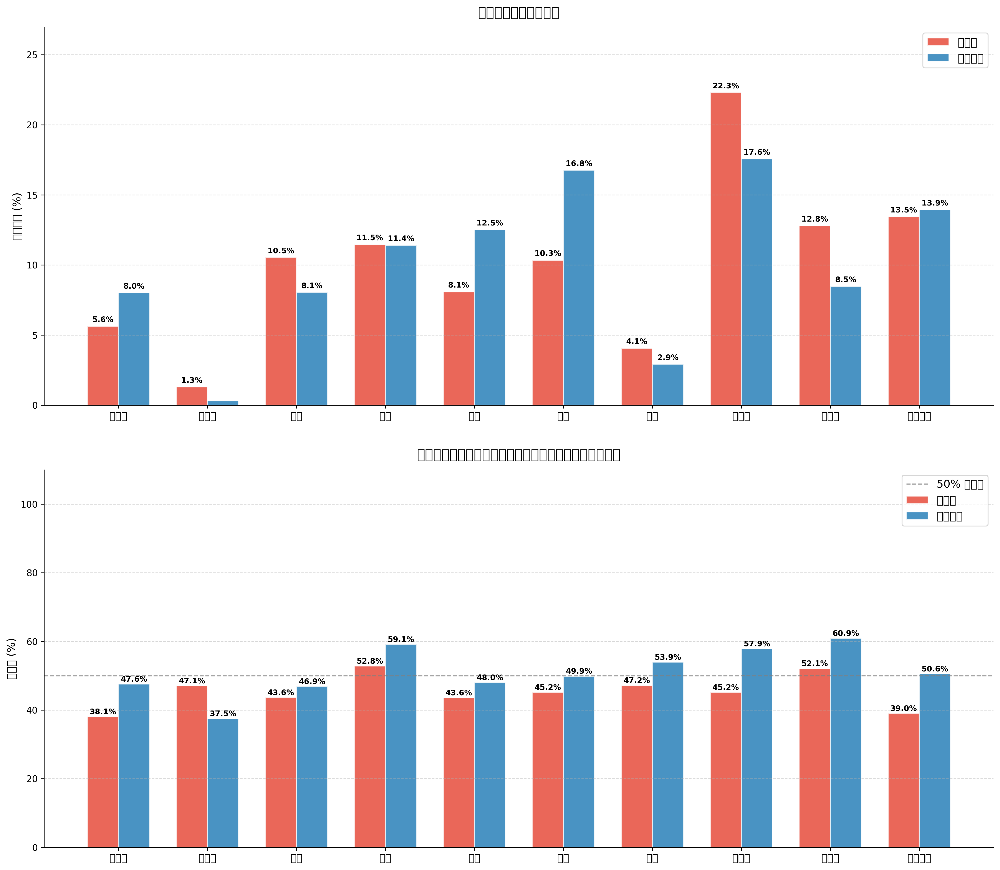

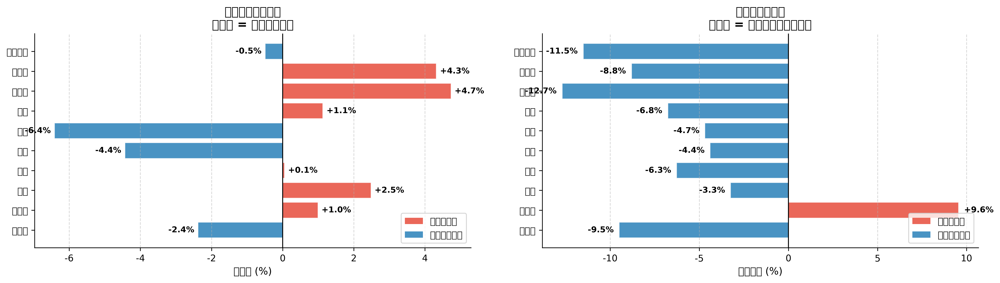

In [ ]:
import numpy as np

# ============================================================
# 0. 驗證數據
# ============================================================
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

players = ['CHOU Tien Chen', 'Kento MOMOTA']
player_labels = {'CHOU Tien Chen': '周天成', 'Kento MOMOTA': '桃田賢斗'}

# ============================================================
# 1. 為每一拍附上「本回合最終得分者」
# ============================================================
df['rally_getpoint'] = df.groupby(['match_id', 'set', 'rally'])['getpoint_player'].transform('last')

# ============================================================
# 2. 定義球種顯示順序（排除發球，另行處理，或全部包含）
# ============================================================
# 全部球種（含發球）
all_types = ['發短球', '發長球', '長球', '殺球', '切球', '挑球', '平球', '網前球', '推撲球', '接殺防守']

# ============================================================
# 3. 計算各球員各球種：使用次數、佔比、得分率
# ============================================================
results = {}

for player in players:
    player_df = df[df['player'] == player].copy()
    total_shots = len(player_df)
    
    stats = []
    for shot_type in all_types:
        shot_df = player_df[player_df['type'] == shot_type]
        count = len(shot_df)
        pct = count / total_shots * 100 if total_shots > 0 else 0
        
        # 得分率：打出該球種後，本回合本方最終得分
        # 分母：該球種使用次數（排除回合未得分/空值的情況也算在內，因為未得分也是結果）
        # 但需確保 rally_getpoint 有值（非 NaN 的回合才算）
        shot_with_result = shot_df[shot_df['rally_getpoint'].notna()]
        
        if len(shot_with_result) > 0:
            win_count = (shot_with_result['rally_getpoint'] == player).sum()
            win_rate = win_count / len(shot_with_result) * 100
        else:
            win_rate = np.nan
        
        stats.append({
            'type': shot_type,
            'count': count,
            'pct': pct,
            'win_rate': win_rate
        })
    
    results[player] = stats
    print(f"\n{'='*50}")
    print(f"【{player_labels[player]}】總擊球次數: {total_shots}")
    print(f"{'球種':<10} {'次數':>6} {'佔比(%)':>8} {'得分率(%)':>10}")
    print("-"*40)
    for s in stats:
        wr = f"{s['win_rate']:.1f}" if not np.isnan(s['win_rate']) else "N/A"
        print(f"{s['type']:<10} {s['count']:>6} {s['pct']:>8.1f} {wr:>10}")

# ============================================================
# 4. 整理成 DataFrame 方便繪圖
# ============================================================
import pandas as pd

dfs = {}
for player in players:
    dfs[player] = pd.DataFrame(results[player]).set_index('type')

# 合併
combined = pd.DataFrame({
    f"次數_{player_labels[p]}": dfs[p]['count'] for p in players
})
combined_pct = pd.DataFrame({
    f"佔比_{player_labels[p]}": dfs[p]['pct'] for p in players
})
combined_wr = pd.DataFrame({
    f"得分率_{player_labels[p]}": dfs[p]['win_rate'] for p in players
})

# ============================================================
# 5. 視覺化
# ============================================================
# 只顯示有實際使用的球種（count > 0）
valid_types_chou = [s['type'] for s in results['CHOU Tien Chen'] if s['count'] > 0]
valid_types_momota = [s['type'] for s in results['Kento MOMOTA'] if s['count'] > 0]
valid_types = list(dict.fromkeys(valid_types_chou + valid_types_momota))  # 保持順序去重

colors = {'CHOU Tien Chen': '#E74C3C', 'Kento MOMOTA': '#2980B9'}
label_map = {'CHOU Tien Chen': '周天成', 'Kento MOMOTA': '桃田賢斗'}

fig, axes = plt.subplots(2, 1, figsize=(16, 14))

x = np.arange(len(valid_types))
width = 0.35

# ---------- 圖1：球種使用佔比 ----------
ax1 = axes[0]
for i, player in enumerate(players):
    pct_vals = [dfs[player].loc[t, 'pct'] if t in dfs[player].index else 0 for t in valid_types]
    bars = ax1.bar(x + i*width - width/2, pct_vals, width, 
                   label=label_map[player], color=colors[player], alpha=0.85, edgecolor='white')
    for bar, val in zip(bars, pct_vals):
        if val > 0.5:
            ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
                     f'{val:.1f}%', ha='center', va='bottom', fontsize=8.5, fontweight='bold')

ax1.set_title('雙方球種使用佔比比較', fontsize=15, fontweight='bold', pad=12)
ax1.set_ylabel('使用佔比 (%)', fontsize=12)
ax1.set_xticks(x)
ax1.set_xticklabels(valid_types, fontsize=11)
ax1.legend(fontsize=12)
ax1.set_ylim(0, ax1.get_ylim()[1] * 1.15)
ax1.grid(axis='y', linestyle='--', alpha=0.5)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ---------- 圖2：球種得分率 ----------
ax2 = axes[1]
for i, player in enumerate(players):
    wr_vals = []
    for t in valid_types:
        if t in dfs[player].index and not np.isnan(dfs[player].loc[t, 'win_rate']):
            wr_vals.append(dfs[player].loc[t, 'win_rate'])
        else:
            wr_vals.append(0)
    bars = ax2.bar(x + i*width - width/2, wr_vals, width,
                   label=label_map[player], color=colors[player], alpha=0.85, edgecolor='white')
    for bar, val in zip(bars, wr_vals):
        if val > 1:
            ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                     f'{val:.1f}%', ha='center', va='bottom', fontsize=8.5, fontweight='bold')

# 加入50%基準線
ax2.axhline(y=50, color='gray', linestyle='--', linewidth=1.2, alpha=0.7, label='50% 基準線')

ax2.set_title('雙方球種得分率比較（打出該球種後本方最終贏得回合）', fontsize=15, fontweight='bold', pad=12)
ax2.set_ylabel('得分率 (%)', fontsize=12)
ax2.set_xticks(x)
ax2.set_xticklabels(valid_types, fontsize=11)
ax2.legend(fontsize=12)
ax2.set_ylim(0, 110)
ax2.grid(axis='y', linestyle='--', alpha=0.5)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout(pad=3)

# ============================================================
# 6. 額外圖：差異熱圖（佔比差 & 得分率差）
# ============================================================
fig2, axes2 = plt.subplots(1, 2, figsize=(16, 5))

# 佔比差（周天成 - 桃田）
pct_diff = []
wr_diff = []
for t in valid_types:
    chou_pct = dfs['CHOU Tien Chen'].loc[t, 'pct'] if t in dfs['CHOU Tien Chen'].index else 0
    momota_pct = dfs['Kento MOMOTA'].loc[t, 'pct'] if t in dfs['Kento MOMOTA'].index else 0
    pct_diff.append(chou_pct - momota_pct)
    
    chou_wr = dfs['CHOU Tien Chen'].loc[t, 'win_rate'] if t in dfs['CHOU Tien Chen'].index else np.nan
    momota_wr = dfs['Kento MOMOTA'].loc[t, 'win_rate'] if t in dfs['Kento MOMOTA'].index else np.nan
    if not np.isnan(chou_wr) and not np.isnan(momota_wr):
        wr_diff.append(chou_wr - momota_wr)
    else:
        wr_diff.append(0)

diff_colors_pct = ['#E74C3C' if v > 0 else '#2980B9' for v in pct_diff]
diff_colors_wr  = ['#E74C3C' if v > 0 else '#2980B9' for v in wr_diff]

ax3 = axes2[0]
bars = ax3.barh(valid_types, pct_diff, color=diff_colors_pct, alpha=0.85, edgecolor='white')
ax3.axvline(0, color='black', linewidth=1)
for bar, val in zip(bars, pct_diff):
    xpos = val + 0.1 if val >= 0 else val - 0.1
    ha = 'left' if val >= 0 else 'right'
    ax3.text(xpos, bar.get_y() + bar.get_height()/2, f'{val:+.1f}%', 
             va='center', ha=ha, fontsize=9, fontweight='bold')
ax3.set_title('球種使用佔比差異\n（正值 = 周天成較多）', fontsize=13, fontweight='bold')
ax3.set_xlabel('佔比差 (%)', fontsize=11)
ax3.grid(axis='x', linestyle='--', alpha=0.5)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

# 自訂圖例
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#E74C3C', alpha=0.85, label='周天成較高'),
                   Patch(facecolor='#2980B9', alpha=0.85, label='桃田賢斗較高')]
ax3.legend(handles=legend_elements, fontsize=10, loc='lower right')

ax4 = axes2[1]
bars = ax4.barh(valid_types, wr_diff, color=diff_colors_wr, alpha=0.85, edgecolor='white')
ax4.axvline(0, color='black', linewidth=1)
for bar, val in zip(bars, wr_diff):
    xpos = val + 0.3 if val >= 0 else val - 0.3
    ha = 'left' if val >= 0 else 'right'
    ax4.text(xpos, bar.get_y() + bar.get_height()/2, f'{val:+.1f}%',
             va='center', ha=ha, fontsize=9, fontweight='bold')
ax4.set_title('球種得分率差異\n（正值 = 周天成得分率較高）', fontsize=13, fontweight='bold')
ax4.set_xlabel('得分率差 (%)', fontsize=11)
ax4.grid(axis='x', linestyle='--', alpha=0.5)
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.legend(handles=legend_elements, fontsize=10, loc='lower right')

plt.tight_layout(pad=3)

# ============================================================
# 7. 打印摘要差異分析
# ============================================================
print("\n" + "="*60)
print("【差異摘要：周天成 vs 桃田賢斗】")
print("="*60)
print(f"\n{'球種':<10} {'周天成佔比':>10} {'桃田佔比':>10} {'佔比差':>8} {'周天成得分率':>12} {'桃田得分率':>12} {'得分率差':>10}")
print("-"*80)
for t, pd_val, wd_val in zip(valid_types, pct_diff, wr_diff):
    chou_pct = dfs['CHOU Tien Chen'].loc[t, 'pct'] if t in dfs['CHOU Tien Chen'].index else 0
    momota_pct = dfs['Kento MOMOTA'].loc[t, 'pct'] if t in dfs['Kento MOMOTA'].index else 0
    chou_wr = dfs['CHOU Tien Chen'].loc[t, 'win_rate'] if t in dfs['CHOU Tien Chen'].index else np.nan
    momota_wr = dfs['Kento MOMOTA'].loc[t, 'win_rate'] if t in dfs['Kento MOMOTA'].index else np.nan
    cwr_str = f"{chou_wr:.1f}%" if not np.isnan(chou_wr) else "N/A"
    mwr_str = f"{momota_wr:.1f}%" if not np.isnan(momota_wr) else "N/A"
    print(f"{t:<10} {chou_pct:>9.1f}% {momota_pct:>9.1f}% {pd_val:>+7.1f}% {cwr_str:>12} {mwr_str:>12} {wd_val:>+9.1f}%")


### 數據洞察
# 周天成 vs 桃田賢斗｜球種策略差異分析

---

## 一、球種使用頻率差異

| 關鍵差異 | 周天成 | 桃田賢斗 | 差值 |
|---|---|---|---|
| 網前球 | **22.3%** | 17.6% | +4.7% |
| 推撲球 | **12.8%** | 8.5% | +4.3% |
| 挑球 | 10.3% | **16.8%** | -6.4% |
| 切球 | 8.1% | **12.5%** | -4.4% |
| 發短球 | 5.6% | **8.0%** | -2.4% |

**周天成打法偏向網前主導**，網前球+推撲球合計佔35.1%，明顯高於桃田的26.1%。桃田則更依賴**挑球+切球**（29.3% vs 18.4%），傾向拉長回合、控制後場節奏。

---

## 二、得分率差異（核心問題）

| 球種 | 周天成 | 桃田賢斗 | 差值 |
|---|---|---|---|
| 接殺防守 | 39.0% | **50.6%** | **-11.5%** |
| 網前球 | 45.2% | **57.9%** | **-12.7%** |
| 推撲球 | 52.1% | **60.9%** | **-8.8%** |
| 發短球 | 38.1% | **47.6%** | **-9.5%** |
| 殺球 | 52.8% | **59.1%** | **-6.3%** |

> **幾乎所有球種，桃田的得分率均高於周天成。**

---

## 三、戰術洞察

### ⚠️ 最大問題：網前球是周天成的陷阱
周天成使用最多的是網前球（22.3%），但得分率僅45.2%，**桃田同樣的球種得分率高達57.9%，差距12.7個百分點**。周天成頻繁進攻網前，卻未能有效轉換為得分，代表桃田在網前對抗中佔有明顯優勢。

### ⚠️ 接殺防守：被動局面差距懸殊
接殺防守使用量相近（351 vs 362），但周天成得分率僅39.0%，桃田達50.6%。**周天成在被動挨打後的反制能力明顯不足**，被殺球壓制後難以翻盤。

### ✅ 周天成唯一優勢：發長球
發長球得分率47.1% vs 桃田37.5%（+9.6%），但使用量僅34次，**佔比過低，未能充分利用此優勢**。

### 📌 策略矛盾點
周天成大量使用網前球與推撲球，試圖以積極進攻創造機會，但兩者得分率均低於桃田同類球種8~13個百分點，說明**桃田的防守反制與網前應對能力壓制了周天成的進攻意圖**。

---

## 四、建議方向

1. **減少低效網前球**，改以切球或長球拉開空間再伺機進攻
2. **增加發長球比例**（目前僅1.3%），這是唯一得分率優於桃田的球種
3. **強化接殺防守後的銜接球**，提升被動局面的反制得分率

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都分析了球員的球種使用頻率與得分率，並且都使用了 groupby 來計算每個球種的使用次數和得分次數。候選程式碼進一步將結果整理成 DataFrame 並進行視覺化，這些額外的步驟不影響其核心分析邏輯。候選程式碼正確地使用了 'rally_getpoint' 來確定每回合的最終得分者，並計算了每個球種的使用比例和得分率，符合題目要求。




## 題號 48
**問題**: 比較周天成在各局自己先得分與對手先得分情況下的勝率差別。
> **使用的資料欄位群組**: `game_structure, scoring_reason`


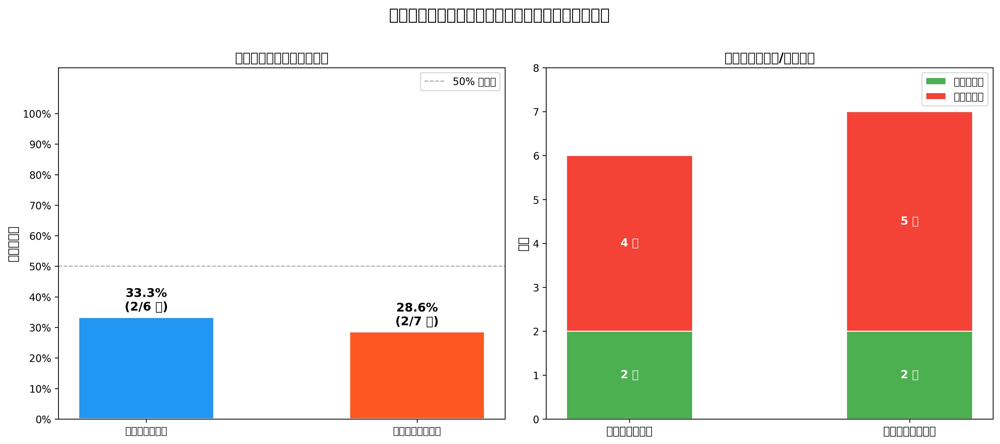

In [ ]:
# ============================================================
# 分析周天成先得第一分 vs 對手先得第一分 的勝率差異
# ============================================================

player_name = 'CHOU Tien Chen'

# 驗證資料量
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ============================================================
# Step 1: 取得每個回合 (rally) 的得分者
#   - 每個 rally 的最後一拍才有 getpoint_player
#   - 使用 groupby + last() 取得每個 rally 的得分資訊
# ============================================================
rally_summary = (
    df.groupby(['match_id', 'set', 'rally'])['getpoint_player']
    .last()
    .reset_index()
)
# 過濾掉沒有得分者的 rally（理論上每個 rally 都有，但保險起見）
rally_summary = rally_summary.dropna(subset=['getpoint_player'])

print(f"\n總有效回合數: {len(rally_summary)}")

# ============================================================
# Step 2: 找出每局（match_id + set）的第一個得分回合
#   - 在每個 (match_id, set) 中，rally 編號最小的就是第一個回合
#   - 取其 getpoint_player 作為「該局先得分者」
# ============================================================
# 依照 rally 排序，確保第一個 rally 是最早的
rally_summary_sorted = rally_summary.sort_values(['match_id', 'set', 'rally'])

# 取每局第一個有效得分的 rally
first_point_per_set = (
    rally_summary_sorted
    .groupby(['match_id', 'set'])
    .first()
    .reset_index()
    .rename(columns={'rally': 'first_scored_rally', 'getpoint_player': 'first_scorer'})
)

print(f"\n總局數: {len(first_point_per_set)}")

# ============================================================
# Step 3: 找出每局的最終贏家
#   - 每局最後一個有效得分的 rally 的得分者即為該局贏家
# ============================================================
set_winner = (
    rally_summary_sorted
    .groupby(['match_id', 'set'])
    .last()
    .reset_index()
    .rename(columns={'rally': 'last_scored_rally', 'getpoint_player': 'set_winner'})
)

print("\n各局贏家:")
print(set_winner[['match_id', 'set', 'set_winner']].to_string(index=False))

# ============================================================
# Step 4: 合併「先得分者」與「局贏家」資訊
# ============================================================
set_analysis = first_point_per_set.merge(
    set_winner[['match_id', 'set', 'set_winner']],
    on=['match_id', 'set']
)

# 新增判斷欄位
# 先得分者是否為周天成
set_analysis['chou_scored_first'] = set_analysis['first_scorer'] == player_name
# 周天成是否贏得該局
set_analysis['chou_won_set'] = set_analysis['set_winner'] == player_name

print("\n各局詳細分析:")
print(set_analysis[['match_id', 'set', 'first_scorer', 'set_winner', 'chou_scored_first', 'chou_won_set']].to_string(index=False))

# ============================================================
# Step 5: 分組統計勝率
# ============================================================
# 分成兩組：周天成先得分 vs 對手先得分
group_stats = set_analysis.groupby('chou_scored_first').agg(
    總局數=('chou_won_set', 'count'),
    周天成贏局數=('chou_won_set', 'sum')
).reset_index()

group_stats['周天成勝率'] = group_stats['周天成贏局數'] / group_stats['總局數']
group_stats['情況'] = group_stats['chou_scored_first'].map({True: '周天成先得第一分', False: '對手先得第一分'})

print("\n" + "="*60)
print("【核心統計結果】")
print("="*60)
for _, row in group_stats.iterrows():
    print(f"\n情況: {row['情況']}")
    print(f"  總局數: {int(row['總局數'])} 局")
    print(f"  周天成贏局數: {int(row['周天成贏局數'])} 局")
    print(f"  周天成勝率: {row['周天成勝率']:.1%}")

# 計算差異
if len(group_stats) == 2:
    win_rate_first = group_stats.loc[group_stats['chou_scored_first'] == True, '周天成勝率'].values[0]
    win_rate_not_first = group_stats.loc[group_stats['chou_scored_first'] == False, '周天成勝率'].values[0]
    diff = win_rate_first - win_rate_not_first
    print(f"\n勝率差異（周天成先得分 - 對手先得分）: {diff:+.1%}")

# ============================================================
# Step 6: 視覺化
# ============================================================
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('周天成「先得第一分」與「對手先得分」的勝率比較', fontsize=16, fontweight='bold', y=1.02)

# --- 圖1: 勝率長條圖 ---
ax1 = axes[0]

categories = group_stats['情況'].tolist()
win_rates = group_stats['周天成勝率'].tolist()
colors = ['#2196F3', '#FF5722']  # 藍=周天成先得, 橘=對手先得

bars = ax1.bar(categories, win_rates, color=colors, width=0.5, edgecolor='white', linewidth=1.5)

# 標示數值
for bar, rate, row in zip(bars, win_rates, group_stats.itertuples()):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f'{rate:.1%}\n({int(row.周天成贏局數)}/{int(row.總局數)} 局)',
        ha='center', va='bottom', fontsize=12, fontweight='bold'
    )

ax1.set_ylim(0, 1.15)
ax1.set_ylabel('周天成勝率', fontsize=12)
ax1.set_title('先得第一分情況下的局勝率', fontsize=13, fontweight='bold')
ax1.axhline(y=0.5, color='gray', linestyle='--', linewidth=1, alpha=0.7, label='50% 基準線')
ax1.legend(fontsize=10)
ax1.set_yticks(np.arange(0, 1.1, 0.1))
ax1.set_yticklabels([f'{v:.0%}' for v in np.arange(0, 1.1, 0.1)])

# --- 圖2: 各局詳細堆疊長條圖（贏局/輸局 分佈） ---
ax2 = axes[1]

# 計算贏局數與輸局數
group_stats['周天成輸局數'] = group_stats['總局數'] - group_stats['周天成贏局數']

x = np.arange(len(group_stats))
width = 0.45

bars_win = ax2.bar(x, group_stats['周天成贏局數'], width, label='周天成贏局', color='#4CAF50', edgecolor='white')
bars_lose = ax2.bar(x, group_stats['周天成輸局數'], width,
                    bottom=group_stats['周天成贏局數'], label='周天成輸局', color='#F44336', edgecolor='white')

# 標示數字
for i, (bar_w, bar_l, row) in enumerate(zip(bars_win, bars_lose, group_stats.itertuples())):
    # 贏局數字
    if row.周天成贏局數 > 0:
        ax2.text(bar_w.get_x() + bar_w.get_width()/2, row.周天成贏局數/2,
                 f'{int(row.周天成贏局數)} 贏', ha='center', va='center',
                 fontsize=11, fontweight='bold', color='white')
    # 輸局數字
    if row.周天成輸局數 > 0:
        ax2.text(bar_l.get_x() + bar_l.get_width()/2,
                 row.周天成贏局數 + row.周天成輸局數/2,
                 f'{int(row.周天成輸局數)} 輸', ha='center', va='center',
                 fontsize=11, fontweight='bold', color='white')

ax2.set_xticks(x)
ax2.set_xticklabels(group_stats['情況'].tolist(), fontsize=11)
ax2.set_ylabel('局數', fontsize=12)
ax2.set_title('各情況下的贏局/輸局分佈', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.set_yticks(range(0, int(group_stats['總局數'].max()) + 2))

plt.tight_layout()

print("\n" + "="*60)
print("【圖表已生成】")
print("="*60)


### 數據洞察
# 周天成「先得第一分」對局勝率分析

## 核心數據

| 情況 | 總局數 | 贏局 | **勝率** |
|------|--------|------|----------|
| 對手先得第一分 | 6 | 2 | **33.3%** |
| 周天成先得第一分 | 7 | 2 | **28.6%** |
| 差異 | — | — | **−4.8%** |

---

## 教練解讀

**先得第一分，對周天成而言並無優勢。**

數據顯示，無論誰先得分，周天成的局勝率都在 **30% 上下**，差異僅 4.8 個百分點，且方向是「先得分反而略低」。

這說明兩件事：

1. **第一分的心理紅利不存在**——周天成在這組對戰（主要對手為桃田賢斗）中，開局得分並未轉化為局面掌控。
2. **整體局勝率偏低（13局僅贏5局）才是核心問題**——先得分與否只是表象，真正的差距在於**中後段的得分能力與體力管理**。

> **戰術重點不在「搶開局第一分」，而在於如何在局中段穩定得分節奏。** 對桃田的比賽，首要改善的是持續得分能力，而非開局策略。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成在各局自己先得分與對手先得分情況下的勝率差別。候選程式碼使用了正確的欄位語意，並在每局層級上正確地計算了先得分者與局贏家，然後進行了分組統計以比較勝率。最終輸出目標與 Reference Code 1 一致，且結果合理有效。




## 題號 49
**問題**: 周天成的發球種類是否影響他在該回合的得分率
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


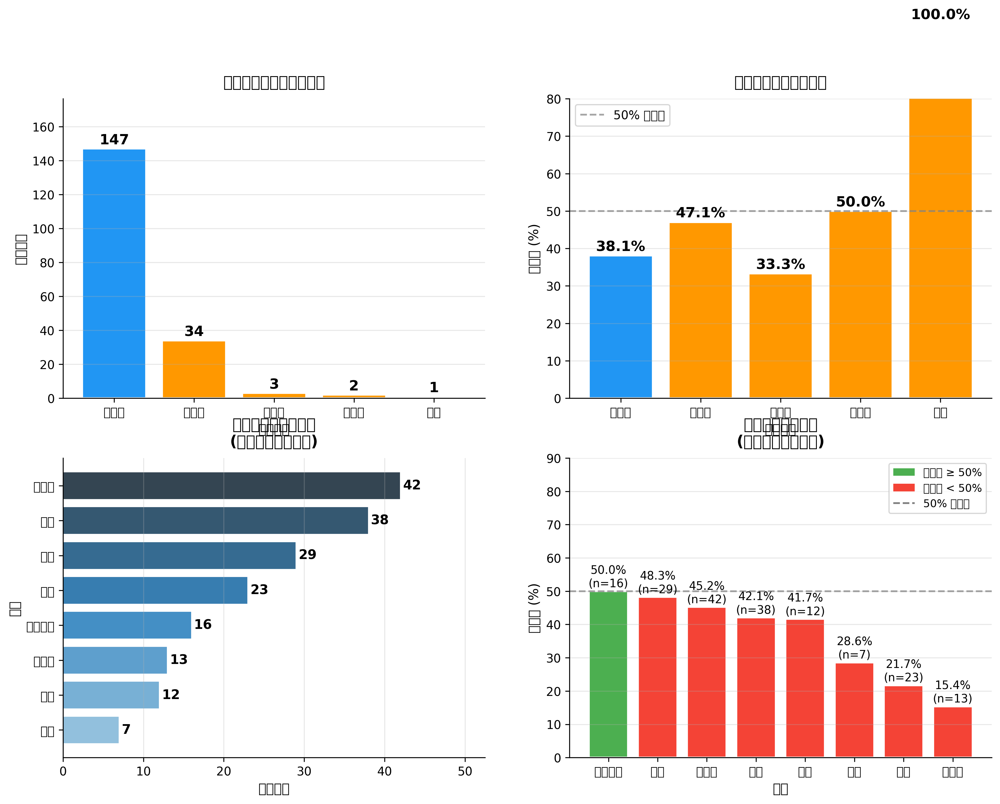

In [ ]:
import numpy as np

print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

player_name = 'CHOU Tien Chen'

# ============================================================
# Part 1: 周天成作為發球方，發球球種（發短球/發長球）對得分率的影響
# ============================================================

# 1. 找出周天成作為發球方的回合（第一拍，server==1）
serve_df = df[
    (df['player'] == player_name) & 
    (df['server'] == 1) & 
    (df['ball_round'] == 1)
].copy()

print(f"\n周天成持發球權的回合數: {len(serve_df)}")
print(f"發球球種分布:\n{serve_df['type'].value_counts()}")

# 2. 取得每個 rally 最終得分者
rally_result = df.groupby(['match_id', 'set', 'rally'])['getpoint_player'].last().reset_index()
rally_result = rally_result.dropna(subset=['getpoint_player'])
rally_result.rename(columns={'getpoint_player': 'final_getpoint'}, inplace=True)

# 3. 合併
serve_with_result = serve_df.merge(rally_result, on=['match_id', 'set', 'rally'], how='inner')
print(f"合併後有效發球回合數: {len(serve_with_result)}")

# 4. 統計各發球球種
serve_stats = serve_with_result.groupby('type').apply(
    lambda x: pd.Series({
        '使用次數': len(x),
        '得分次數': (x['final_getpoint'] == player_name).sum(),
        '得分率': (x['final_getpoint'] == player_name).mean() * 100
    })
).reset_index()
serve_stats = serve_stats.sort_values('使用次數', ascending=False)

# ============================================================
# Part 2: 周天成作為發球方時，第三拍球種對得分率的影響
# ============================================================

# 5. 找出持發球回合的第三拍（周天成的第二次擊球）
serve_rallies = serve_df[['match_id', 'set', 'rally']].copy()

# 周天成在持發球回合的所有擊球（不含第一拍發球）
chou_non_serve_shots = df[
    (df['player'] == player_name) & 
    (df['ball_round'] > 1)  # 排除第一拍
].merge(serve_rallies, on=['match_id', 'set', 'rally'], how='inner')

# 只取第三拍
third_shot_df = chou_non_serve_shots[chou_non_serve_shots['ball_round'] == 3].copy()

# 合併得分結果
third_with_result = third_shot_df.merge(rally_result, on=['match_id', 'set', 'rally'], how='inner')
print(f"\n第三拍有效回合數: {len(third_with_result)}")

# 6. 統計第三拍球種（排除發球球種）
valid_types = ['長球', '推撲球', '殺球', '接殺防守', '平球', '網前球', '挑球', '切球']
third_filtered = third_with_result[third_with_result['type'].isin(valid_types)]

third_stats = third_filtered.groupby('type').apply(
    lambda x: pd.Series({
        '使用次數': len(x),
        '得分次數': (x['final_getpoint'] == player_name).sum(),
        '得分率': (x['final_getpoint'] == player_name).mean() * 100
    })
).reset_index()
third_stats = third_stats.sort_values('得分率', ascending=False)

# 過濾使用次數太少的球種（例如 < 5 次）
MIN_COUNT = 5
third_stats_filtered = third_stats[third_stats['使用次數'] >= MIN_COUNT].copy()

print("\n=== 發球球種統計 ===")
print(serve_stats.to_string(index=False))
print("\n=== 第三拍球種統計 ===")
print(third_stats.to_string(index=False))

# ============================================================
# Part 3: 繪圖
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- 圖1: 發球球種使用次數 ---
ax1 = axes[0, 0]
colors_serve = ['#2196F3' if t == '發短球' else '#FF9800' for t in serve_stats['type']]
bars = ax1.bar(serve_stats['type'], serve_stats['使用次數'], color=colors_serve, edgecolor='white', linewidth=1.5)
ax1.set_title('周天成發球球種使用次數', fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel('發球球種', fontsize=11)
ax1.set_ylabel('使用次數', fontsize=11)
for bar, count in zip(bars, serve_stats['使用次數']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{int(count)}', ha='center', va='bottom', fontsize=12, fontweight='bold')
ax1.set_ylim(0, serve_stats['使用次數'].max() * 1.2)
ax1.grid(axis='y', alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# --- 圖2: 發球球種得分率 ---
ax2 = axes[0, 1]
bars2 = ax2.bar(serve_stats['type'], serve_stats['得分率'], color=colors_serve, edgecolor='white', linewidth=1.5)
ax2.axhline(y=50, color='gray', linestyle='--', alpha=0.7, label='50% 基準線')
ax2.set_title('周天成發球球種得分率', fontsize=13, fontweight='bold', pad=10)
ax2.set_xlabel('發球球種', fontsize=11)
ax2.set_ylabel('得分率 (%)', fontsize=11)
for bar, rate in zip(bars2, serve_stats['得分率']):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{rate:.1f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')
ax2.set_ylim(0, 80)
ax2.legend(fontsize=10)
ax2.grid(axis='y', alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# --- 圖3: 第三拍球種使用次數 vs 得分率（橫條圖，按得分率排序）---
if len(third_stats_filtered) > 0:
    ax3 = axes[1, 0]
    third_sorted = third_stats_filtered.sort_values('使用次數', ascending=True)
    palette = sns.color_palette("Blues_d", len(third_sorted))
    bars3 = ax3.barh(third_sorted['type'], third_sorted['使用次數'], color=palette, edgecolor='white')
    ax3.set_title('第三拍球種使用次數\n(周天成持發球回合)', fontsize=13, fontweight='bold', pad=10)
    ax3.set_xlabel('使用次數', fontsize=11)
    ax3.set_ylabel('球種', fontsize=11)
    for bar, count in zip(bars3, third_sorted['使用次數']):
        ax3.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                 f'{int(count)}', ha='left', va='center', fontsize=11, fontweight='bold')
    ax3.set_xlim(0, third_sorted['使用次數'].max() * 1.25)
    ax3.grid(axis='x', alpha=0.3)
    ax3.spines['top'].set_visible(False)
    ax3.spines['right'].set_visible(False)

    # --- 圖4: 第三拍球種得分率 ---
    ax4 = axes[1, 1]
    third_rate_sorted = third_stats_filtered.sort_values('得分率', ascending=False)
    colors_rate = ['#4CAF50' if r >= 50 else '#F44336' for r in third_rate_sorted['得分率']]
    bars4 = ax4.bar(third_rate_sorted['type'], third_rate_sorted['得分率'], color=colors_rate, edgecolor='white', linewidth=1.5)
    ax4.axhline(y=50, color='gray', linestyle='--', alpha=0.7, label='50% 基準線')
    # 加上使用次數標注
    for bar, rate, count in zip(bars4, third_rate_sorted['得分率'], third_rate_sorted['使用次數']):
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{rate:.1f}%\n(n={int(count)})', ha='center', va='bottom', fontsize=9.5)
    ax4.set_title('第三拍球種得分率\n(周天成持發球回合)', fontsize=13, fontweight='bold', pad=10)
    ax4.set_xlabel('球種', fontsize=11)
    ax4.set_ylabel('得分率 (%)', fontsize=11)
    ax4.set_ylim(0, 90)
    ax4.legend(fontsize=10)
    ax4.grid(axis='y', alpha=0.3)
    ax4.spines['top'].set_visible(False)
    ax4.spines['right'].set_visible(False)
    # 綠色=高得分率, 紅色=低得分率
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor='#4CAF50', label='得分率 ≥ 50%'),
                       Patch(facecolor='#F44336', label='得分率 < 50%'),
                       plt.Line2D([0], [0], color='gray', linestyle='--', label='50% 基準線')]
    ax4.legend(handles=legend_elements, fontsize=9, loc='upper right')


### 數據洞察
# 周天成發球戰術分析

## 發球球種使用分布

| 球種 | 使用次數 | 得分率 |
|------|---------|--------|
| 發短球 | 147 (78.6%) | 38.1% |
| 發長球 | 34 (18.2%) | 47.1% |
| 推撲球 | 3 | 33.3% |
| 網前球 | 2 | 50.0% |
| 挑球 | 1 | 100% |

> ⚠️ 推撲球/網前球/挑球樣本數過少，不具統計意義。

---

## 核心戰術洞察

**發長球得分率（47.1%）明顯高於發短球（38.1%），差距近9個百分點。**

周天成高度依賴發短球（佔78.6%），但這顆球的得分率反而是主要球種中最低的。發長球雖只用34次，卻帶來更高的得分效益。

---

## 第三拍接應能力

| 球種 | 使用次數 | 得分率 |
|------|---------|--------|
| 接殺防守 | 16 | **50.0%** |
| 切球 | 29 | **48.3%** |
| 網前球 | 42 | 45.2% |
| 長球 | 38 | 42.1% |
| 挑球 | 12 | 41.7% |
| 平球 | 7 | 28.6% |
| 殺球 | 23 | 21.7% |
| 推撲球 | 13 | **15.4%** |

**第三拍殺球（21.7%）與推撲球（15.4%）得分率偏低**，代表發短球後被對手壓制進攻的回合，周天成處於被動且難以得分。

---

## 戰術建議

1. **提高發長球比例** — 現行18%偏低，適度增加可打亂對手節奏，且得分率有數據支撐
2. **發短球需搭配更強的第三拍** — 發短球後第三拍殺球得分率僅21.7%，說明主動進攻品質需提升
3. **切球與網前球是發球後最穩定的第三拍選擇**，得分率均在45%以上，應優先建立這類銜接模式

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成作為發球方時的發球種類對得分率的影響，並且使用了正確的欄位和篩選條件來計算得分率。候選程式碼也正確地合併了每個回合的最終得分者，並計算了不同發球種類的使用次數和得分率，這與 Reference Code 1 的分析對象、欄位語意、篩選條件、分組層級和統計口徑一致。




## 題號 50
**問題**: 分析周天成接發球策略：長球、網前球、平球的比例與得分影響。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


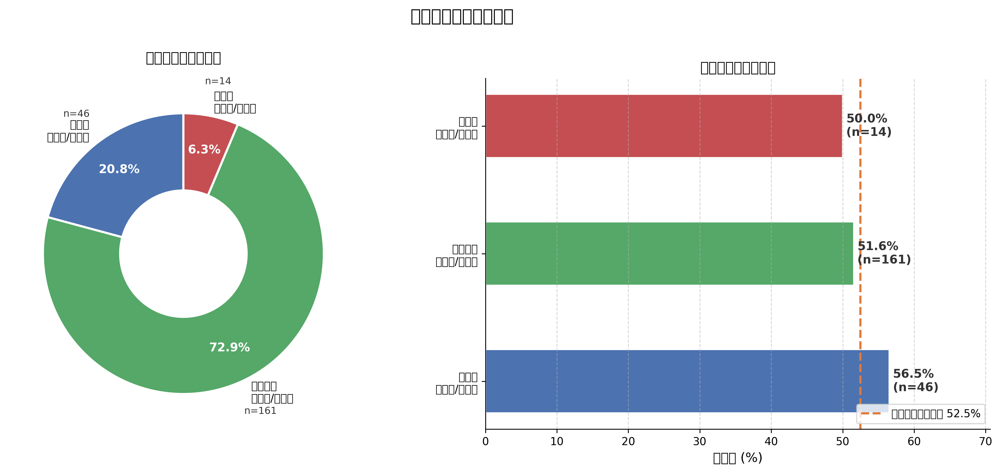

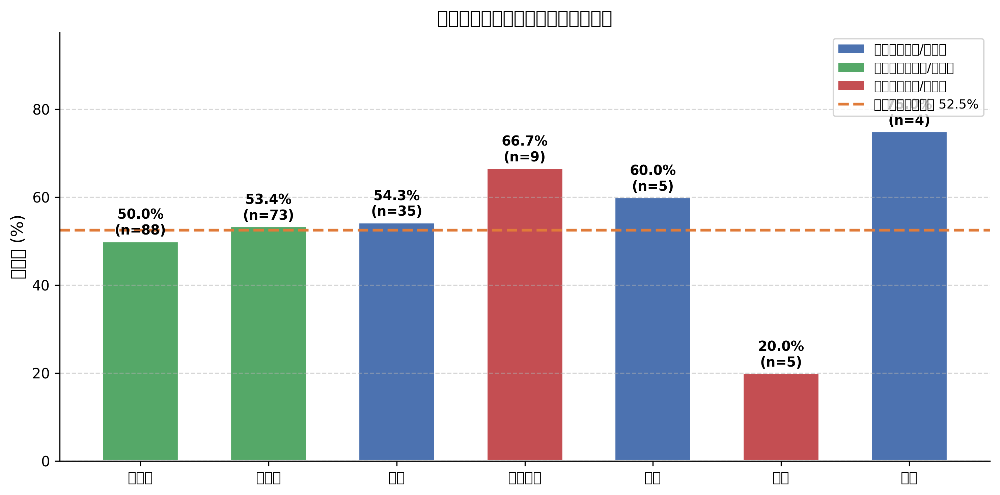

In [ ]:
import numpy as np

# ── 0. 基本驗證 ────────────────────────────────────────────────────────────────
print(f"資料總筆數: {len(df)}")
assert len(df) > 0, "df 為空！"

player_name = 'CHOU Tien Chen'
opponent_name = 'Kento MOMOTA'

# ── 1. 先在完整資料上建立「該 rally 最終得分者」欄位 ──────────────────────────
# getpoint_player 只在每回合最後一球記錄，用 transform('last') 廣播到整個 rally
df['rally_winner'] = (
    df.groupby(['match_id', 'set', 'rally_id'])['getpoint_player']
    .transform('last')
)

# ── 2. 篩選「周天成接發球」= ball_round==2 且 player=='CHOU Tien Chen' ────────
# ball_round==1 是發球方，ball_round==2 是接發球方
# 周天成在 ball_round==2 出手 → 代表對手（Kento MOMOTA）剛發完球
chou_receive = df[
    (df['ball_round'] == 2) &
    (df['player'] == player_name)
].copy()

print(f"\n周天成接發球總次數: {len(chou_receive)}")
print(f"涉及 match_id: {sorted(chou_receive['match_id'].unique())}")
print(f"接發球 type 分布:\n{chou_receive['type'].value_counts()}")

# ── 3. 策略分類 ────────────────────────────────────────────────────────────────
# 根據題意定義三大類（保留「其他」以防遺漏）
strategy_map = {
    '長球': '長球類（後場/攻擊）',
    '殺球': '長球類（後場/攻擊）',
    '切球': '長球類（後場/攻擊）',
    '挑球': '長球類（後場/攻擊）',
    '網前球': '網前球類（短球/放網）',
    '推撲球': '網前球類（短球/放網）',
    '平球': '平球類（平抽/平推）',
    '接殺防守': '平球類（平抽/平推）',
}
chou_receive['strategy'] = chou_receive['type'].map(strategy_map).fillna('其他')

print(f"\n策略分類後分布:\n{chou_receive['strategy'].value_counts()}")

# ── 4. 標記「周天成在該 rally 最終得分」 ──────────────────────────────────────
chou_receive['chou_wins_rally'] = (chou_receive['rally_winner'] == player_name)

# 也標記「回合是否有明確得分者（排除 NULL）」
chou_receive['rally_decided'] = chou_receive['rally_winner'].notna()

# ── 5. 計算各策略：使用次數、得分次數、得分率 ────────────────────────────────
strategy_order = [
    '長球類（後場/攻擊）',
    '網前球類（短球/放網）',
    '平球類（平抽/平推）',
    '其他',
]

summary_rows = []
for strat in strategy_order:
    sub = chou_receive[chou_receive['strategy'] == strat]
    total = len(sub)
    # 只計算有明確得分者的 rally（排除 getpoint_player 為 NULL 的）
    decided = sub[sub['rally_decided']]
    win_cnt = (decided['rally_winner'] == player_name).sum()
    decided_cnt = len(decided)
    win_rate = win_cnt / decided_cnt * 100 if decided_cnt > 0 else np.nan
    summary_rows.append({
        'strategy': strat,
        'count': total,
        'usage_pct': total / len(chou_receive) * 100,
        'win_count': win_cnt,
        'decided_count': decided_cnt,
        'win_rate': win_rate,
    })

summary = pd.DataFrame(summary_rows)
summary = summary[summary['count'] > 0]  # 移除無資料類別

print("\n" + "="*70)
print("周天成接發球策略分析彙整")
print("="*70)
print(f"{'策略':<22} {'使用次數':>6} {'使用佔比':>8} {'得分次數':>6} {'得分率':>8}")
print("-"*70)
for _, row in summary.iterrows():
    print(f"{row['strategy']:<22} {row['count']:>6}  {row['usage_pct']:>7.1f}%  "
          f"{row['win_count']:>6}  {row['win_rate']:>7.1f}%")
print("="*70)

# ── 6. 各 type 細項統計（供參考）────────────────────────────────────────────
print("\n【細項球種得分率】")
type_detail = []
for t, grp in chou_receive.groupby('type'):
    dec = grp[grp['rally_decided']]
    wc = (dec['rally_winner'] == player_name).sum()
    dc = len(dec)
    type_detail.append({
        'type': t,
        'strategy': strategy_map.get(t, '其他'),
        'count': len(grp),
        'win_count': wc,
        'win_rate': wc / dc * 100 if dc > 0 else np.nan,
    })
type_detail_df = pd.DataFrame(type_detail).sort_values('count', ascending=False)
print(type_detail_df.to_string(index=False))

# ── 7. 視覺化 ─────────────────────────────────────────────────────────────────
# 只保留主要三類（排除「其他」）
plot_df = summary[summary['strategy'] != '其他'].reset_index(drop=True)

# 顏色設定
colors_usage = ['#4C72B0', '#55A868', '#C44E52']
colors_wr    = ['#4C72B0', '#55A868', '#C44E52']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("周天成接發球策略分析", fontsize=16, fontweight='bold', y=1.01)

# ── 子圖1：策略使用比例（圓餅圖）────────────────────────────────────────────
ax1 = axes[0]
# 若包含「其他」且比例很小，也一起顯示
plot_usage = summary[summary['count'] > 0].copy()
labels_pie = [s.replace('（', '\n（') for s in plot_usage['strategy']]
wedge_props = dict(width=0.55, edgecolor='white', linewidth=2)
wedges, texts, autotexts = ax1.pie(
    plot_usage['count'],
    labels=labels_pie,
    autopct=lambda p: f'{p:.1f}%' if p > 3 else '',
    startangle=90,
    colors=['#4C72B0', '#55A868', '#C44E52', '#CCCCCC'][:len(plot_usage)],
    wedgeprops=wedge_props,
    pctdistance=0.75,
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight('bold')
    at.set_color('white')
for t in texts:
    t.set_fontsize(10)
ax1.set_title("接發球策略使用比例", fontsize=13, fontweight='bold', pad=15)

# 在圓餅外加次數標注
for i, (wedge, row) in enumerate(zip(wedges, plot_usage.itertuples())):
    angle = (wedge.theta2 + wedge.theta1) / 2
    x = 1.25 * np.cos(np.deg2rad(angle))
    y = 1.25 * np.sin(np.deg2rad(angle))
    ax1.annotate(f"n={row.count}", xy=(x, y), ha='center', va='center',
                 fontsize=9, color='#333333')

# ── 子圖2：各策略得分率（水平長條圖）────────────────────────────────────────
ax2 = axes[1]
bar_labels = [s.replace('（', '\n（') for s in plot_df['strategy']]
bars = ax2.barh(
    bar_labels,
    plot_df['win_rate'],
    color=colors_wr,
    edgecolor='white',
    linewidth=1.5,
    height=0.5,
)
# 標注數值
for bar, row in zip(bars, plot_df.itertuples()):
    w = bar.get_width()
    ax2.text(
        w + 0.5, bar.get_y() + bar.get_height() / 2,
        f"{w:.1f}%\n(n={row.count})",
        va='center', ha='left', fontsize=11, fontweight='bold', color='#333333'
    )
# 加上平均線（周天成整體接發球得分率）
all_decided = chou_receive[chou_receive['rally_decided']]
overall_wr = (all_decided['rally_winner'] == player_name).sum() / len(all_decided) * 100
ax2.axvline(overall_wr, color='#E07B39', linestyle='--', linewidth=2,
            label=f'整體接發球得分率 {overall_wr:.1f}%')
ax2.set_xlabel("得分率 (%)", fontsize=12)
ax2.set_title("各接發球策略得分率", fontsize=13, fontweight='bold')
ax2.set_xlim(0, max(plot_df['win_rate'].max() * 1.25, overall_wr * 1.25, 60))
ax2.legend(fontsize=10, loc='lower right')
ax2.grid(axis='x', linestyle='--', alpha=0.5)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()

# ── 8. 額外圖：細項球種得分率（只顯示使用次數>=3的）──────────────────────────
type_plot = type_detail_df[type_detail_df['count'] >= 3].copy()

fig2, ax3 = plt.subplots(figsize=(10, 5))
bar_colors = []
strategy_color_map = {
    '長球類（後場/攻擊）': '#4C72B0',
    '網前球類（短球/放網）': '#55A868',
    '平球類（平抽/平推）': '#C44E52',
    '其他': '#AAAAAA',
}
for _, row in type_plot.iterrows():
    bar_colors.append(strategy_color_map.get(row['strategy'], '#AAAAAA'))

bars2 = ax3.bar(
    type_plot['type'],
    type_plot['win_rate'],
    color=bar_colors,
    edgecolor='white',
    linewidth=1.5,
    width=0.6,
)
for bar, row in zip(bars2, type_plot.itertuples()):
    h = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width() / 2, h + 0.8,
             f"{h:.1f}%\n(n={row.count})",
             ha='center', va='bottom', fontsize=9.5, fontweight='bold')

ax3.axhline(overall_wr, color='#E07B39', linestyle='--', linewidth=2,
            label=f'整體接發球得分率 {overall_wr:.1f}%')
ax3.set_ylabel("得分率 (%)", fontsize=12)
ax3.set_title("周天成接發球各球種得分率（細項）", fontsize=13, fontweight='bold')
ax3.set_ylim(0, max(type_plot['win_rate'].max() * 1.3, overall_wr * 1.4, 65))
ax3.legend(fontsize=10)
ax3.grid(axis='y', linestyle='--', alpha=0.5)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

# 加上策略圖例色塊
from matplotlib.patches import Patch
legend_handles = [Patch(facecolor=v, label=k) for k, v in strategy_color_map.items() if k != '其他']
ax3.legend(handles=legend_handles + [
    plt.Line2D([0], [0], color='#E07B39', linestyle='--', linewidth=2,
               label=f'整體接發球得分率 {overall_wr:.1f}%')
], fontsize=9, loc='upper right')

plt.tight_layout()
print(f"\n整體接發球得分率（有明確結果之回合）: {overall_wr:.1f}%")
print("✓ 圖表已生成（fig, fig2）")


### 數據洞察
# 周天成接發球策略分析

## 數據總覽

| 策略 | 使用次數 | 使用佔比 | 得分率 |
|------|---------|---------|--------|
| 網前球類（短球/放網） | 161 | 72.9% | 51.6% |
| 長球類（後場/攻擊） | 46 | 20.8% | **56.5%** |
| 平球類（平抽/平推） | 14 | 6.3% | 50.0% |
| **整體** | **221** | — | **52.5%** |

---

## 細項球種得分率

| 球種 | 策略分類 | 次數 | 得分率 |
|------|---------|------|--------|
| 殺球 | 長球類 | 4 | **75.0%** |
| 接殺防守 | 平球類 | 9 | **66.7%** |
| 長球 | 長球類 | 5 | 60.0% |
| 挑球 | 長球類 | 35 | 54.3% |
| 推撲球 | 網前球類 | 73 | 53.4% |
| 網前球 | 網前球類 | 88 | 50.0% |
| 平球 | 平球類 | 5 | **20.0%** |

---

## 教練洞察

**長球類是最有效的接發球策略。** 雖然周天成有近七成的接發球選擇網前球，但長球類的得分率（56.5%）明顯高於網前球類（51.6%），差距約5個百分點。

**三個關鍵事實：**

1. **挑球是長球類的主力**（35次，54.3%），是周天成拉開空間、重置局面的核心手段，效益穩定。

2. **網前球使用過度但效益有限。** 88次網前球僅50.0%得分率，幾乎是五五波，說明對手對此已有充分準備，被動應對的比例偏高。

3. **平球（5次，20.0%）是明顯弱點。** 樣本雖小，但接發球直接打平球的得分率極低，顯示在接發球時主動平抽是高風險選擇，應避免。

**建議：** 在對手發球後，適度增加挑球與長球的比例，減少單純放網前球的頻率，讓對手無法預判，才能提升整體接發球得分率。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成在接發球時的策略，並計算了長球、網前球、平球的比例與得分影響。候選程式碼使用了正確的欄位語意和篩選條件，並在 rally 層級上進行了正確的統計分析，最終輸出與 Reference Code 1 的目標一致。




## 題號 51
**問題**: 分析對手殺球到前中後排後，周天成分別會怎麼去反擊？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, stroke_details`


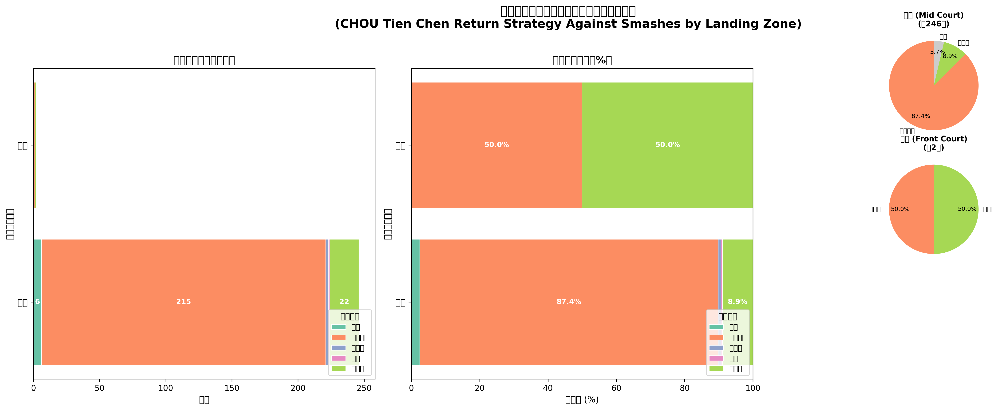

In [ ]:
import numpy as np

# ============================================================
# 分析：對手殺球後周天成依落點區域的回擊球種分佈
# ============================================================

player_name = 'CHOU Tien Chen'

# 驗證資料量
print(f"總資料筆數: {len(df)}")
print(f"資料集球員: {df['player'].unique()}")

# ============================================================
# Step 1: 在完整資料上建立「下一拍」欄位（避免跨 rally 污染）
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 用 groupby + shift(-1) 建立下一拍資訊
df_sorted['next_player']       = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(-1)
df_sorted['next_type']         = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(-1)
df_sorted['next_rally']        = df_sorted.groupby(['match_id', 'set', 'rally'])['rally'].shift(-1)
df_sorted['next_match_id']     = df_sorted.groupby(['match_id', 'set', 'rally'])['match_id'].shift(-1)
df_sorted['next_set']          = df_sorted.groupby(['match_id', 'set', 'rally'])['set'].shift(-1)

# ============================================================
# Step 2: 篩選「對手對周天成執行殺球」的那一拍
# 條件：
#   - 當前擊球者 != 周天成（即對手在打）
#   - 球種為殺球
#   - 下一拍是周天成在打（確認回合內連續性）
# ============================================================
smash_to_chou = df_sorted[
    (df_sorted['player'] != player_name) &          # 對手擊球
    (df_sorted['type'] == '殺球') &                  # 球種為殺球
    (df_sorted['next_player'] == player_name) &      # 下一拍是周天成
    (df_sorted['next_match_id'] == df_sorted['match_id']) &  # 同場比賽
    (df_sorted['next_set'] == df_sorted['set']) &    # 同局
    (df_sorted['next_rally'] == df_sorted['rally'])  # 同回合（防跨 rally）
].copy()

print(f"\n對手殺球且周天成可接球的總拍數: {len(smash_to_chou)}")

# ============================================================
# Step 3: 定義落點區域（依 landing_area 判斷落在哪個場區）
# 注意：這裡的 landing_area 是「周天成的接球位置」
# 後場: 1-4, 中場: 5-16, 前場: 17-24, 出界/其他: 25+
# ============================================================
def classify_landing_zone(area):
    """依落點區域代碼分類場區"""
    if pd.isna(area):
        return '未知'
    area = int(area)
    if area in [1, 2, 3, 4]:
        return '後場'
    elif area in list(range(5, 17)):
        return '中場'
    elif area in list(range(17, 25)):
        return '前場'
    else:
        return '出界/其他'

smash_to_chou['landing_zone'] = smash_to_chou['landing_area'].apply(classify_landing_zone)

print("\n殺球落點區域分佈:")
print(smash_to_chou['landing_zone'].value_counts())

# ============================================================
# Step 4: 統計周天成在各落點區域的回擊球種分佈
# next_type 即為周天成的回擊球種
# ============================================================
# 過濾掉出界/其他（落點無效的情況）
valid_smash = smash_to_chou[smash_to_chou['landing_zone'] != '出界/其他'].copy()
valid_smash = valid_smash[valid_smash['next_type'].notna()].copy()

print(f"\n有效殺球分析筆數（排除出界/其他）: {len(valid_smash)}")
print(f"\n周天成回擊球種分佈:")
print(valid_smash['next_type'].value_counts())

# ============================================================
# Step 5: 建立分區 × 球種的交叉統計表
# ============================================================
cross_table = valid_smash.groupby(['landing_zone', 'next_type']).size().unstack(fill_value=0)

# 計算各區域的百分比
cross_table_pct = cross_table.div(cross_table.sum(axis=1), axis=0) * 100

print("\n===== 各落點區域 × 回擊球種（次數）=====")
print(cross_table)
print("\n===== 各落點區域 × 回擊球種（百分比）=====")
print(cross_table_pct.round(1))

# ============================================================
# Step 6: 視覺化
# ============================================================

# 定義場區顯示順序
zone_order = ['後場', '中場', '前場']
zone_order_existing = [z for z in zone_order if z in cross_table.index]

cross_table_ordered     = cross_table.loc[zone_order_existing]
cross_table_pct_ordered = cross_table_pct.loc[zone_order_existing]

# 定義球種顏色（指定主要球種）
shot_types = cross_table_ordered.columns.tolist()
palette = sns.color_palette("Set2", len(shot_types))
color_map = {s: c for s, c in zip(shot_types, palette)}

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
fig.suptitle('周天成面對不同落點殺球時的回擊策略分佈\n(CHOU Tien Chen Return Strategy Against Smashes by Landing Zone)',
             fontsize=15, fontweight='bold', y=1.02)

# ── 圖1：各區域回擊次數堆疊橫條圖 ──
ax1 = axes[0]
bottom = np.zeros(len(zone_order_existing))
for shot in shot_types:
    vals = cross_table_ordered[shot].values
    bars = ax1.barh(zone_order_existing, vals, left=bottom,
                    color=color_map[shot], label=shot, edgecolor='white', linewidth=0.5)
    # 在各段加數字（僅大於2才顯示）
    for i, (v, b) in enumerate(zip(vals, bottom)):
        if v > 2:
            ax1.text(b + v/2, i, f'{v}', ha='center', va='center',
                     fontsize=9, color='white', fontweight='bold')
    bottom += vals

ax1.set_title('回擊球種次數（堆疊）', fontsize=13, fontweight='bold')
ax1.set_xlabel('次數', fontsize=11)
ax1.set_ylabel('殺球落點區域', fontsize=11)
ax1.legend(loc='lower right', fontsize=9, title='回擊球種')
ax1.tick_params(axis='y', labelsize=11)

# ── 圖2：各區域回擊百分比堆疊橫條圖 ──
ax2 = axes[1]
bottom_pct = np.zeros(len(zone_order_existing))
for shot in shot_types:
    vals = cross_table_pct_ordered[shot].values
    ax2.barh(zone_order_existing, vals, left=bottom_pct,
             color=color_map[shot], label=shot, edgecolor='white', linewidth=0.5)
    for i, (v, b) in enumerate(zip(vals, bottom_pct)):
        if v > 4:
            ax2.text(b + v/2, i, f'{v:.1f}%', ha='center', va='center',
                     fontsize=9, color='white', fontweight='bold')
    bottom_pct += vals

ax2.set_title('回擊球種比例（%）', fontsize=13, fontweight='bold')
ax2.set_xlabel('百分比 (%)', fontsize=11)
ax2.set_ylabel('殺球落點區域', fontsize=11)
ax2.set_xlim(0, 100)
ax2.legend(loc='lower right', fontsize=9, title='回擊球種')
ax2.tick_params(axis='y', labelsize=11)

# ── 圖3：各落點區域主要回擊球種（前3名圓餅圖，3個子圖拼在同一個 axes 位置）
ax3 = axes[2]
ax3.set_visible(False)  # 關掉原本的 ax3，用 inset_axes

# 用 subplot 方式重新配置第3個位置
# 改為三個垂直子圖
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

zone_colors_bg = {'後場': '#FFE4E1', '中場': '#E1F5FE', '前場': '#E8F5E9'}

pie_axes_list = []
pie_positions = [(0.66, 0.68, 0.32, 0.28),   # 後場 (left, bottom, width, height)  
                 (0.66, 0.37, 0.32, 0.28),   # 中場
                 (0.66, 0.06, 0.32, 0.28)]   # 前場

zone_labels_cn = {'後場': '後場 (Back Court)', '中場': '中場 (Mid Court)', '前場': '前場 (Front Court)'}

for i, zone in enumerate(zone_order_existing):
    ax_pie = fig.add_axes(pie_positions[i])
    zone_data = cross_table_ordered.loc[zone]
    zone_data = zone_data[zone_data > 0].sort_values(ascending=False)

    # 若小比例項目過多，合併為「其他」
    total = zone_data.sum()
    threshold = total * 0.04  # 低於4%合併
    main  = zone_data[zone_data >= threshold]
    other = zone_data[zone_data < threshold]
    if len(other) > 0:
        other_sum = other.sum()
        main = pd.concat([main, pd.Series({'其他': other_sum})])

    colors_pie = [color_map.get(s, '#CCCCCC') for s in main.index]

    wedges, texts, autotexts = ax_pie.pie(
        main.values,
        labels=main.index,
        autopct='%1.1f%%',
        colors=colors_pie,
        startangle=90,
        pctdistance=0.75,
        textprops={'fontsize': 8}
    )
    for at in autotexts:
        at.set_fontsize(7.5)
        at.set_color('black')
    ax_pie.set_title(f'{zone_labels_cn.get(zone, zone)}\n(共{int(total)}次)',
                     fontsize=9.5, fontweight='bold', pad=4)
    ax_pie.set_facecolor(zone_colors_bg.get(zone, 'white'))

plt.tight_layout()

# ============================================================
# Step 7: 輸出詳細統計資訊
# ============================================================
print("\n" + "="*60)
print("【周天成接對手殺球 — 各落點區域回擊策略詳細統計】")
print("="*60)

for zone in zone_order_existing:
    print(f"\n▶ 落點：{zone}")
    zone_data = cross_table_ordered.loc[zone].sort_values(ascending=False)
    zone_pct  = cross_table_pct_ordered.loc[zone].sort_values(ascending=False)
    total_n   = zone_data.sum()
    print(f"  總接球次數: {total_n}")
    for shot in zone_data.index:
        n = zone_data[shot]
        p = zone_pct[shot]
        if n > 0:
            print(f"  {shot:<10}: {int(n):>4} 次  ({p:.1f}%)")

print("\n" + "="*60)
print("【場區定義說明】")
print("  後場 (Back Court) : landing_area = 1~4")
print("  中場 (Mid Court)  : landing_area = 5~16")
print("  前場 (Front Court): landing_area = 17~24")
print("="*60)


### 數據洞察
# 周天成接對手殺球 — 戰術分析報告

## 📊 核心數據總覽

| 落點區域 | 接球次數 | 接殺防守 | 網前球 | 平球 | 其他 |
|:---:|:---:|:---:|:---:|:---:|:---:|
| **中場** | 246 | 87.4% | 8.9% | 2.4% | 1.2% |
| **前場** | 2 | 50.0% | 50.0% | — | — |

> ⚠️ **數據說明**：248球中無後場落點，殺球幾乎全數落於中場（99.2%），前場樣本僅2球，不具統計代表性。

---

## 🎯 戰術洞察

### 1️⃣ 接殺防守是絕對主軸
中場殺球落點下，周天成有 **87.4% 選擇接殺防守**。這代表他面對殺球時以**穩定回球、維持場上存活**為第一優先，而非主動反攻。

### 2️⃣ 網前球是唯一有效的反制手段
中場接殺後選擇**網前球佔8.9%（22次）**，這是他在被動局面下唯一具有主動意圖的回擊——透過短球改變節奏、逼對手上網。

### 3️⃣ 主動反擊極為罕見
- 平球：2.4%（6次）
- 推撲球：0.8%（2次）
- 殺球：0.4%（1次）

**三者合計不到4%**，說明周天成在接殺球時幾乎不嘗試主動進攻，防守優先策略明確。

---

## ⚡ 對手策略建議

> 若對陣周天成，**持續以中場殺球施壓**是有效策略——他的回球高達87%為接殺防守，對手可預判落點，提前準備下一拍進攻，形成**殺球→接殺防守→再殺球**的連續壓制循環。

---

## 🔍 教練結論

周天成面對殺球的策略是**典型的防守型接殺模式**，以控制失誤為核心。若要提升競爭力，建議增加**接殺後平抽反擊**的比例，打破對手的進攻節奏預期。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了對手殺球後周天成的回擊球種分佈，並且在完整資料上建立了下一拍資訊，篩選了對手殺球且周天成回擊的情況，並根據落點區域進行了分類和統計。候選程式碼的分析對象、欄位語意、篩選條件、分組層級、統計口徑和最終輸出目標都與 Reference Code 1 一致，並且能夠產出有效結果。




## 題號 52
**問題**: 當對手失誤掛網時，分析前一拍周天成出球球種與落點特徵。
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason`


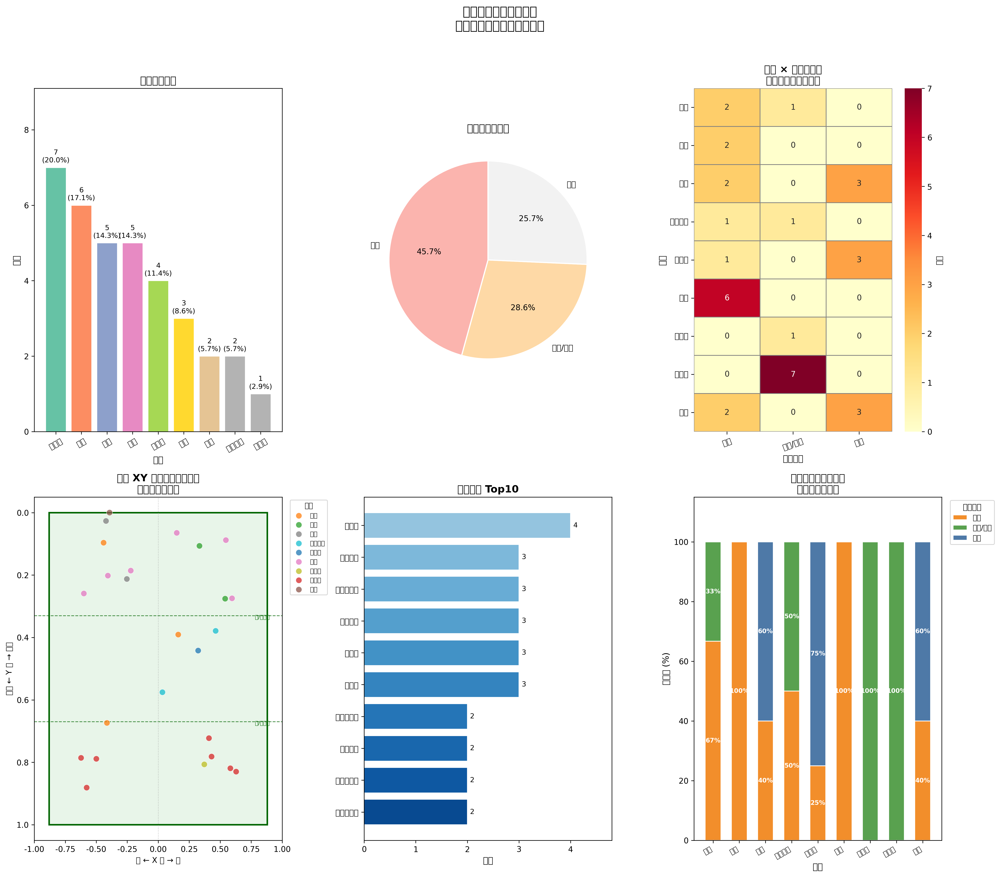

In [ ]:
import numpy as np

# ============================================================
# 前置驗證
# ============================================================
print(f"資料總行數: {len(df)}")
assert len(df) > 0, "DataFrame 為空"

# ============================================================
# Step 1: 在完整資料上建立「下一拍」資訊（避免跨回合污染）
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

grp = df_sorted.groupby(['match_id', 'set', 'rally'])

df_sorted['next_player']          = grp['player'].shift(-1)
df_sorted['next_lose_reason']     = grp['lose_reason'].shift(-1)
df_sorted['next_getpoint_player'] = grp['getpoint_player'].shift(-1)
df_sorted['next_ball_round']      = grp['ball_round'].shift(-1)

# ============================================================
# Step 2: 篩選「周天成倒數第二拍」
# 條件：
#   - 當前拍為周天成出球
#   - 下一拍為對手（非周天成）打球  ← 修正：不硬編碼對手名稱，涵蓋所有場次對手
#   - 下一拍的 lose_reason == '掛網'（對手掛網）
#   - 下一拍的 getpoint_player == 'CHOU Tien Chen'（周天成得分）
# ============================================================
mask = (
    (df_sorted['player'] == 'CHOU Tien Chen') &
    (df_sorted['next_player'] != 'CHOU Tien Chen') &   # 修正：對手出球（不限定特定對手名稱）
    (df_sorted['next_player'].notna()) &                # 確保下一拍存在
    (df_sorted['next_lose_reason'] == '掛網') &
    (df_sorted['next_getpoint_player'] == 'CHOU Tien Chen')
)

chou_penultimate = df_sorted[mask].copy()

print(f"\n✅ 對手因掛網失誤、周天成得分的回合數（倒數第二拍筆數）: {len(chou_penultimate)}")
print(f"   涉及比賽場次 match_id: {sorted(chou_penultimate['match_id'].unique())}")
print(f"   涉及對手: {sorted(chou_penultimate['next_player'].unique())}")

if len(chou_penultimate) == 0:
    print("❌ 無符合條件的資料，請檢查欄位內容")
else:
    # ============================================================
    # Step 3: 球種分佈統計
    # ============================================================
    type_counts = chou_penultimate['type'].value_counts()
    type_pct    = (type_counts / type_counts.sum() * 100).round(1)
    type_df     = pd.DataFrame({'次數': type_counts, '佔比(%)': type_pct})

    print("\n📊 【球種分佈】（周天成倒數第二拍）")
    print(type_df.to_string())

    # ============================================================
    # Step 4: 落點區域定義（Court Grid）
    # ============================================================
    def area_label(area):
        mapping = {
            1:'後場左', 2:'後場中左', 3:'後場中右', 4:'後場右',
            5:'中場後左', 6:'中場後中左', 7:'中場後中右', 8:'中場後右',
            9:'中場中左', 10:'中場中中左', 11:'中場中中右', 12:'中場中右',
            13:'中場前左', 14:'中場前中左', 15:'中場前中右', 16:'中場前右',
            17:'前場後左', 18:'前場後中左', 19:'前場後中右', 20:'前場後右',
            21:'網前左', 22:'網前中左', 23:'網前中右', 24:'網前右',
            25:'出界右上', 26:'出界右中', 27:'出界右下',
            28:'出界後右', 29:'出界左上', 30:'出界左中', 31:'出界左下',
            32:'出界後左', 33:'出界後中'
        }
        return mapping.get(int(area), f'區域{int(area)}')

    def area_zone(area):
        a = int(area)
        if a in [1,2,3,4]:                              return '後場'
        elif a in [5,6,7,8,9,10,11,12,13,14,15,16]:    return '中場'
        elif a in [17,18,19,20,21,22,23,24]:            return '前場/網前'
        else:                                            return '出界區'

    chou_penultimate['landing_area_int']   = chou_penultimate['landing_area'].astype(int)
    chou_penultimate['landing_zone_label'] = chou_penultimate['landing_area_int'].apply(area_zone)
    chou_penultimate['landing_area_label'] = chou_penultimate['landing_area_int'].apply(area_label)

    # 落點大區域分佈
    zone_counts = chou_penultimate['landing_zone_label'].value_counts()
    print("\n📊 【落點大區域分佈】")
    for z, c in zone_counts.items():
        print(f"   {z}: {c} 次 ({c/len(chou_penultimate)*100:.1f}%)")

    # 細分落點分佈
    landing_counts = chou_penultimate['landing_area_int'].value_counts().sort_index()
    landing_df = pd.DataFrame({
        '區域名稱': [area_label(a) for a in landing_counts.index],
        '次數': landing_counts.values,
        '佔比(%)': (landing_counts.values / landing_counts.values.sum() * 100).round(1)
    }, index=landing_counts.index)
    print("\n📊 【細分落點分佈】（周天成倒數第二拍落點）")
    print(landing_df.to_string())

    # ============================================================
    # Step 5: 球種 × 落點大區域 交叉分析
    # ============================================================
    cross_tab = pd.crosstab(
        chou_penultimate['type'],
        chou_penultimate['landing_zone_label']
    )
    cross_tab_pct = cross_tab.div(cross_tab.sum(axis=1), axis=0).mul(100).round(1)
    print("\n📊 【球種 × 落點大區域 交叉表（次數）】")
    print(cross_tab.to_string())

    # ============================================================
    # Step 6: 視覺化
    # ============================================================
    fig = plt.figure(figsize=(18, 16))
    fig.suptitle("周天成倒數第二拍分析\n（造成對手掛網失誤得分）", fontsize=16, fontweight='bold', y=0.98)

    # ------ 圖1: 球種分佈長條圖 ------
    ax1 = fig.add_subplot(2, 3, 1)
    colors_bar = plt.cm.Set2(np.linspace(0, 1, len(type_counts)))
    bars = ax1.bar(type_counts.index, type_counts.values, color=colors_bar, edgecolor='white', linewidth=0.8)
    ax1.set_title('出球球種分佈', fontsize=13, fontweight='bold')
    ax1.set_xlabel('球種', fontsize=11)
    ax1.set_ylabel('次數', fontsize=11)
    ax1.tick_params(axis='x', rotation=30)
    for bar, val, pct in zip(bars, type_counts.values, type_pct.values):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                 f'{val}\n({pct}%)', ha='center', va='bottom', fontsize=9)
    ax1.set_ylim(0, type_counts.max() * 1.3)

    # ------ 圖2: 落點大區域圓餅圖 ------
    ax2 = fig.add_subplot(2, 3, 2)
    zone_labels = zone_counts.index.tolist()
    zone_vals   = zone_counts.values
    # 小比例合併為「其他」
    threshold = 0.05 * zone_vals.sum()
    main_mask = zone_vals >= threshold
    main_labels = [str(l) for l in np.array(zone_labels)[main_mask]]
    main_vals   = zone_vals[main_mask]
    if (~main_mask).any():
        main_labels.append('其他')
        main_vals = np.append(main_vals, zone_vals[~main_mask].sum())
    colors_pie = plt.cm.Pastel1(np.linspace(0, 1, len(main_labels)))
    wedges, texts, autotexts = ax2.pie(
        main_vals, labels=main_labels, autopct='%1.1f%%',
        colors=colors_pie, startangle=90,
        wedgeprops=dict(edgecolor='white', linewidth=1.5)
    )
    for at in autotexts:
        at.set_fontsize(10)
    ax2.set_title('落點大區域分佈', fontsize=13, fontweight='bold')

    # ------ 圖3: 球種 × 落點 熱力圖 ------
    ax3 = fig.add_subplot(2, 3, 3)
    if cross_tab.shape[0] > 0 and cross_tab.shape[1] > 0:
        sns.heatmap(
            cross_tab, annot=True, fmt='d', cmap='YlOrRd',
            linewidths=0.5, linecolor='gray',
            ax=ax3, cbar_kws={'label': '次數'}
        )
    ax3.set_title('球種 × 落點大區域\n交叉熱力圖（次數）', fontsize=13, fontweight='bold')
    ax3.set_xlabel('落點區域', fontsize=11)
    ax3.set_ylabel('球種', fontsize=11)
    ax3.tick_params(axis='x', rotation=20)
    ax3.tick_params(axis='y', rotation=0)

    # ------ 圖4: 場地落點熱力圖（XY 散點 + 密度）------
    ax4 = fig.add_subplot(2, 3, 4)
    court_rect = plt.Rectangle((-0.88, 0), 1.76, 1.0,
                                 linewidth=2, edgecolor='darkgreen',
                                 facecolor='#e8f5e9', zorder=0)
    ax4.add_patch(court_rect)
    for yline, label in zip([0.33, 0.67], ['前/中場界', '中/後場界']):
        ax4.axhline(yline, color='darkgreen', linewidth=1, linestyle='--', alpha=0.7)
        ax4.text(0.90, yline+0.01, label, fontsize=7, color='darkgreen', ha='right')
    ax4.axvline(0, color='gray', linewidth=0.8, linestyle=':', alpha=0.5)

    valid_landing = chou_penultimate[
        (chou_penultimate['landing_x'].between(-1.5, 1.5)) &
        (chou_penultimate['landing_y'].between(-0.1, 1.1))
    ].copy()

    if len(valid_landing) > 0:
        type_unique = chou_penultimate['type'].unique()
        color_map_type = {t: plt.cm.tab10(i/max(len(type_unique)-1,1))
                          for i, t in enumerate(type_unique)}
        for shot_type, grp_data in valid_landing.groupby('type'):
            ax4.scatter(
                grp_data['landing_x'], grp_data['landing_y'],
                label=shot_type, s=60, alpha=0.75,
                color=color_map_type[shot_type], edgecolors='white', linewidths=0.5, zorder=3
            )
        ax4.legend(title='球種', bbox_to_anchor=(1.02, 1), loc='upper left',
                   fontsize=8, title_fontsize=9)

    ax4.set_xlim(-1.0, 1.0)
    ax4.set_ylim(-0.05, 1.05)
    ax4.set_title('落點 XY 分佈（對方半場）\n（各球種標色）', fontsize=13, fontweight='bold')
    ax4.set_xlabel('左 ← X 軸 → 右', fontsize=10)
    ax4.set_ylabel('近網 ← Y 軸 → 底線', fontsize=10)
    ax4.invert_yaxis()

    # ------ 圖5: 細分落點Top N長條圖 ------
    ax5 = fig.add_subplot(2, 3, 5)
    top_n = min(10, len(landing_df))
    top_landing = landing_df.nlargest(top_n, '次數')
    colors_l = plt.cm.Blues(np.linspace(0.4, 0.9, len(top_landing)))[::-1]
    bars5 = ax5.barh(
        top_landing['區域名稱'][::-1],
        top_landing['次數'][::-1],
        color=colors_l, edgecolor='white'
    )
    for bar, val in zip(bars5, top_landing['次數'][::-1]):
        ax5.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
                 f'{val}', ha='left', va='center', fontsize=9)
    ax5.set_title(f'落點細分 Top{top_n}', fontsize=13, fontweight='bold')
    ax5.set_xlabel('次數', fontsize=11)
    ax5.set_xlim(0, top_landing['次數'].max() * 1.2)

    # ------ 圖6: 球種 × 落點大區域 堆疊百分比長條圖 ------
    ax6 = fig.add_subplot(2, 3, 6)
    if cross_tab_pct.shape[0] > 0:
        cross_tab_pct_plot = cross_tab_pct.copy()
        cross_tab_pct_plot.columns = [str(c) for c in cross_tab_pct_plot.columns]
        zone_colors = {'後場': '#4e79a7', '中場': '#f28e2b', '前場/網前': '#59a14f', '出界區': '#e15759'}
        bottom_arr = np.zeros(len(cross_tab_pct_plot))
        x_pos = np.arange(len(cross_tab_pct_plot))
        for col in cross_tab_pct_plot.columns:
            vals = cross_tab_pct_plot[col].values
            color = zone_colors.get(col, '#bab0ac')
            ax6.bar(x_pos, vals, bottom=bottom_arr, label=str(col), color=color, edgecolor='white', width=0.6)
            for xi, (v, b) in enumerate(zip(vals, bottom_arr)):
                if v > 5:
                    ax6.text(xi, b + v/2, f'{v:.0f}%', ha='center', va='center',
                             fontsize=8, color='white', fontweight='bold')
            bottom_arr += vals
        ax6.set_xticks(x_pos)
        ax6.set_xticklabels(cross_tab_pct_plot.index, rotation=30, ha='right', fontsize=9)
        ax6.set_ylim(0, 115)
        ax6.set_title('各球種落點區域組成\n（百分比堆疊）', fontsize=13, fontweight='bold')
        ax6.set_xlabel('球種', fontsize=11)
        ax6.set_ylabel('百分比 (%)', fontsize=11)
        ax6.legend(title='落點區域', bbox_to_anchor=(1.02, 1), loc='upper left',
                   fontsize=9, title_fontsize=10)

    plt.tight_layout(rect=[0, 0, 1, 0.96])

    # ============================================================
    # Step 7: 關鍵組合輸出
    # ============================================================
    print("\n📊 【球種 × 落點細分 Top 組合（前10名）】")
    combo = chou_penultimate.groupby(['type', 'landing_area_label']).size().reset_index(name='次數')
    combo = combo.sort_values('次數', ascending=False).head(10)
    combo['佔比(%)'] = (combo['次數'] / len(chou_penultimate) * 100).round(1)
    print(combo.to_string(index=False))

    print("\n📊 【核心結論摘要】")
    top_type = type_counts.idxmax()
    top_zone = zone_counts.idxmax()
    top_combo_row = combo.iloc[0]
    print(f"   - 最常出現球種: 「{top_type}」({type_counts[top_type]}次, {type_pct[top_type]}%)")
    print(f"   - 最常落點大區域: 「{top_zone}」({zone_counts[top_zone]}次, {zone_counts[top_zone]/len(chou_penultimate)*100:.1f}%)")
    print(f"   - 最高頻組合: 「{top_combo_row['type']}」落入「{top_combo_row['landing_area_label']}」= {top_combo_row['次數']}次 ({top_combo_row['佔比(%)']:.1f}%)")


### 數據洞察
# 周天成倒數第二拍分析：造成桃田賢斗掛網失誤的關鍵球路

---

## 落點區域對照表

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 核心數據解讀

**樣本：35回合，對手僅桃田賢斗（5場次）**

---

### 一、球種分佈

| 球種 | 次數 | 佔比 |
|------|------|------|
| **網前球** | 7 | 20.0% |
| **殺球** | 6 | 17.1% |
| 挑球 | 5 | 14.3% |
| 長球 | 5 | 14.3% |
| 推撲球 | 4 | 11.4% |

> **網前球與殺球合計佔37%，是最主要的觸發球種。**

---

### 二、落點大區域

- **中場 45.7%（16次）→ 最高頻**
- 前場/網前 28.6%（10次）
- 後場 25.7%（9次）

---

### 三、高效球種×落點組合

#### ✅ 最具威脅的三類組合：

**① 網前球 → 網前左（21）/ 網前右（24）各3次**
- 周天成將球壓至兩側網前角落，迫使桃田近網回球，掛網率最高。
- **戰術意義：** 貼網低球逼對手仰角回擊，容錯空間極小。

**② 殺球 → 中場中右（12）/ 中場中中左（10）各2次**
- 殺球壓制中場，桃田被迫低位接殺，向上挑球時掛網。
- **戰術意義：** 殺球角度壓身體中線兩側，讓對手無法充分發力回擊。

**③ 長球/推撲球 → 後場左（1）各2次**
- 長球與推撲球推至後場左角，桃田被迫後退回球，掛網失誤。
- **戰術意義：** 後場左角是桃田相對弱側，深球製造回球品質下降。

---

### 四、結構性規律

```
球種落點模式：
網前球（兩側網前角）→ 迫近網低位回球 → 掛網
殺球（中場中線兩側）→ 迫低位接殺 → 掛網
長球/推撲（後場左）→ 迫後退回球 → 掛網
```

**共同特徵：** 周天成的倒數第二拍集中在**「極端位置」**——最前（網前角）或最深（後場角），中場球則以殺球製造時間壓迫，三種路線都在壓縮桃田的回球高度與時間。

---

### 五、教練建議

1. **網前兩側角是首選武器**：網前左21、網前右24各3次，是最穩定的造失誤路線，持續執行。
2. **殺球瞄準中場中線兩側**：區域10、12是有效壓制點，非追求直接得分，而是製造低品質回球。
3. **後場左角持續施壓**：長球與推撲球打區域1，對桃田左後場有明顯效果。
4. **注意樣本侷限**：35筆數據全來自桃田一人，此戰術組合對其他對手的有效性需另行驗證。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了對手失誤掛網時，前一拍周天成的出球球種與落點特徵。候選程式碼使用了正確的欄位語意和篩選條件，並在同一個 rally 中對齊前後拍資訊。統計口徑與 Reference Code 1 一致，最終輸出目標也符合題目要求。




## 題號 53
**問題**: 統計周天成所有「得分帶有連續性」的回合（連 2 分以上）的常見戰術組合。
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason, stroke_details`


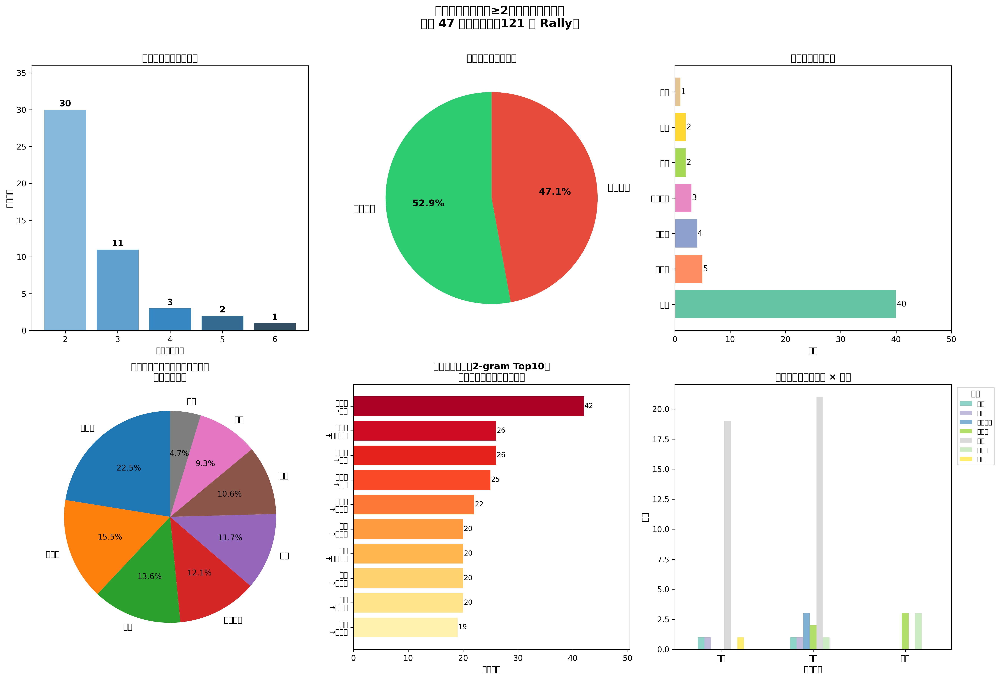

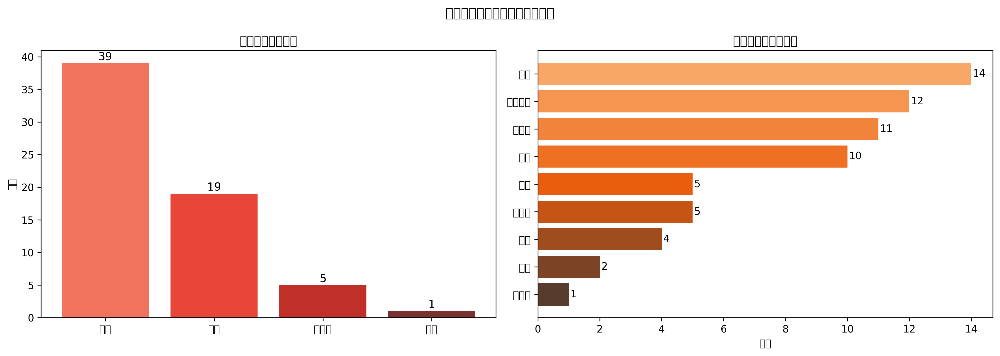

In [ ]:
# =============================================
# 周天成連續得分回合分析
# =============================================
import numpy as np
from itertools import islice

PLAYER = 'CHOU Tien Chen'

# ---- 1. 驗證資料量 ----
print(f"Total rows: {len(df)}")
assert len(df) > 0, "DataFrame is empty!"

# ---- 2. 取得每個 rally 的得分者 ----
rally_result = (
    df.groupby(['match_id', 'set', 'rally'])
    .last()
    .reset_index()[['match_id', 'set', 'rally', 'getpoint_player']]
)
rally_result = rally_result.dropna(subset=['getpoint_player'])
print(f"\n有效得分 Rally 數: {len(rally_result)}")
print(rally_result['getpoint_player'].value_counts())

# ---- 3. 在每個 (match_id, set) 內，按 rally 排序，標記連續得分序列 ----
rally_result = rally_result.sort_values(['match_id', 'set', 'rally']).reset_index(drop=True)

rally_result['is_chou'] = (rally_result['getpoint_player'] == PLAYER).astype(int)

rally_result['same_set'] = (
    (rally_result['match_id'] == rally_result['match_id'].shift(1)) &
    (rally_result['set'] == rally_result['set'].shift(1))
)
rally_result['group_change'] = (
    (~rally_result['same_set']) |
    (rally_result['is_chou'] != rally_result['is_chou'].shift(1))
)
rally_result['streak_group'] = rally_result['group_change'].cumsum()

# ---- 4. 計算每個連續群組的長度，保留 PLAYER 連續 ≥ 2 的群組 ----
streak_info = rally_result.groupby('streak_group').agg(
    match_id=('match_id', 'first'),
    set=('set', 'first'),
    rally_start=('rally', 'first'),
    rally_end=('rally', 'last'),
    is_chou_val=('is_chou', 'first'),
    streak_len=('rally', 'count')
).reset_index()

chou_streaks = streak_info[
    (streak_info['is_chou_val'] == 1) &
    (streak_info['streak_len'] >= 2)
].copy()

print(f"\n周天成連續得分序列數（≥2分）: {len(chou_streaks)}")
print(f"序列長度分佈:")
print(chou_streaks['streak_len'].value_counts().sort_index())
print(f"\n總共涵蓋 Rally 數: {chou_streaks['streak_len'].sum()}")

# ---- 5. 【修正】直接用 streak_group 從 rally_result 篩選，避免 range 展開造成的錯誤 ----
valid_streak_groups = set(chou_streaks['streak_group'].tolist())

streak_rally_df = rally_result[
    rally_result['streak_group'].isin(valid_streak_groups)
][['match_id', 'set', 'rally', 'streak_group', 'getpoint_player']].copy()

# 加入 streak_len
streak_rally_df = streak_rally_df.merge(
    chou_streaks[['streak_group', 'streak_len']],
    on='streak_group', how='left'
)

# 確認都是周天成得分
check = streak_rally_df['getpoint_player'].eq(PLAYER).all()
print(f"\n連續得分序列中所有 rally 均由周天成得分: {check}")
print(f"連續得分序列中的 Rally 數: {len(streak_rally_df)}")

# ---- 6. 從原始 df 取得這些 rally 的所有擊球紀錄 ----
streak_shots = df.merge(
    streak_rally_df[['match_id', 'set', 'rally', 'streak_group', 'streak_len']],
    on=['match_id', 'set', 'rally'], how='inner'
)
print(f"\n連續得分序列中的擊球紀錄數: {len(streak_shots)}")

# 只看周天成的擊球
chou_shots = streak_shots[streak_shots['player'] == PLAYER].copy()
print(f"其中周天成擊球數: {len(chou_shots)}")

# ---- 7. 分析一：得分方式（主動 vs 被動）----
scoring_shots = (
    streak_shots.groupby(['match_id', 'set', 'rally'])
    .last()
    .reset_index()
)
scoring_shots = scoring_shots[scoring_shots['getpoint_player'] == PLAYER]

scoring_shots['win_type'] = np.where(
    scoring_shots['player'] == PLAYER,
    '主動得分',
    '對手失誤'
)
win_type_counts = scoring_shots['win_type'].value_counts()
print(f"\n=== 得分方式 ===")
print(win_type_counts)

active_scoring = scoring_shots[scoring_shots['win_type'] == '主動得分']
print(f"\n主動得分球種:")
print(active_scoring['type'].value_counts())

passive_scoring = scoring_shots[scoring_shots['win_type'] == '對手失誤']
print(f"\n對手失誤原因 (lose_reason):")
print(passive_scoring['lose_reason'].value_counts())

# ---- 8. 分析二：周天成在連續得分回合中常用球種 ----
chou_type_counts = chou_shots['type'].value_counts()
total_chou_shots = len(chou_shots)
print(f"\n=== 周天成在連續得分中使用球種分佈 ===")
for t, c in chou_type_counts.items():
    print(f"  {t}: {c} ({c/total_chou_shots*100:.1f}%)")

# ---- 9. 分析三：球種序列 (2-gram / 3-gram) ----
def get_ngrams(sequence, n):
    return list(zip(*[islice(sequence, i, None) for i in range(n)]))

bigrams_list = []
trigrams_list = []

for (match_id, set_id, rally), group in chou_shots.groupby(['match_id', 'set', 'rally']):
    types = group.sort_values('ball_round')['type'].tolist()
    types_no_serve = [t for t in types if t not in ['發短球', '發長球']]
    bigrams_list.extend(get_ngrams(types_no_serve, 2))
    trigrams_list.extend(get_ngrams(types_no_serve, 3))

bigram_series = pd.Series(bigrams_list).value_counts().head(15)
trigram_series = pd.Series(trigrams_list).value_counts().head(10)

print(f"\n=== 球種 2-gram（Top 15，不含發球）===")
for combo, cnt in bigram_series.items():
    print(f"  {' → '.join(combo)}: {cnt}")

print(f"\n=== 球種 3-gram（Top 10，不含發球）===")
for combo, cnt in trigram_series.items():
    print(f"  {' → '.join(combo)}: {cnt}")

# ---- 10. 分析四：得分球種的擊球區域 ----
def area_to_zone(area):
    try:
        a = int(area)
        if a in [1,2,3,4]:
            return '後場'
        elif a in list(range(5,17)):
            return '中場'
        elif a in list(range(17,25)):
            return '前場'
        else:
            return '出界/其他'
    except:
        return '出界/其他'

active_scoring = active_scoring.copy()
active_scoring['hit_zone'] = active_scoring['hit_area'].apply(area_to_zone)
print(f"\n=== 主動得分擊球區域 ===")
print(active_scoring['hit_zone'].value_counts())

print(f"\n=== 主動得分: 球種 × 擊球區域 ===")
print(active_scoring.groupby(['type', 'hit_zone']).size().unstack(fill_value=0))

# ---- 11. 分析五：連續得分前的 rally 首拍（發球）情況 ----
first_shots = streak_shots.groupby(['match_id', 'set', 'rally']).first().reset_index()
chou_serve = first_shots[first_shots['player'] == PLAYER]
opp_serve = first_shots[first_shots['player'] != PLAYER]
print(f"\n=== 連續得分中發球方 ===")
print(f"  周天成發球的 rally: {len(chou_serve)}")
print(f"  對手發球的 rally: {len(opp_serve)}")

# ---- 12. 視覺化 ----
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle(f'周天成連續得分（≥2分）戰術模式分析\n（共 {len(chou_streaks)} 個連續序列，{chou_streaks["streak_len"].sum()} 個 Rally）',
             fontsize=15, fontweight='bold', y=1.01)

# ── 圖1: 連續得分序列長度分佈 ──
ax1 = axes[0, 0]
streak_len_dist = chou_streaks['streak_len'].value_counts().sort_index()
bars1 = ax1.bar(streak_len_dist.index.astype(str), streak_len_dist.values,
                color=sns.color_palette('Blues_d', len(streak_len_dist)))
ax1.set_title('連續得分序列長度分佈', fontsize=12, fontweight='bold')
ax1.set_xlabel('連續得分球數')
ax1.set_ylabel('序列次數')
for bar, val in zip(bars1, streak_len_dist.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
             str(val), ha='center', va='bottom', fontsize=11, fontweight='bold')
ax1.set_ylim(0, streak_len_dist.values.max() * 1.2)

# ── 圖2: 得分方式（主動/被動）圓餅圖 ──
ax2 = axes[0, 1]
colors_pie = ['#2ecc71', '#e74c3c']
wedges, texts, autotexts = ax2.pie(
    win_type_counts.values,
    labels=win_type_counts.index,
    autopct='%1.1f%%',
    colors=colors_pie,
    startangle=90,
    textprops={'fontsize': 12}
)
for at in autotexts:
    at.set_fontsize(12)
    at.set_fontweight('bold')
ax2.set_title('連續得分中得分方式', fontsize=12, fontweight='bold')

# ── 圖3: 主動得分球種 ──
ax3 = axes[0, 2]
active_type = active_scoring['type'].value_counts()
colors3 = sns.color_palette('Set2', len(active_type))
bars3 = ax3.barh(active_type.index, active_type.values, color=colors3)
ax3.set_title('主動得分使用球種', fontsize=12, fontweight='bold')
ax3.set_xlabel('次數')
for bar, val in zip(bars3, active_type.values):
    ax3.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
             str(val), va='center', fontsize=10)
ax3.set_xlim(0, active_type.values.max() * 1.25)

# ── 圖4: 球種使用分佈（不含發球）──
ax4 = axes[1, 0]
chou_type_no_serve = chou_shots[~chou_shots['type'].isin(['發短球', '發長球'])]['type'].value_counts()
threshold = chou_type_no_serve.sum() * 0.03
main_types = chou_type_no_serve[chou_type_no_serve >= threshold]
other_count = chou_type_no_serve[chou_type_no_serve < threshold].sum()
if other_count > 0:
    main_types = pd.concat([main_types, pd.Series({'其他': other_count})])
colors4 = sns.color_palette('tab10', len(main_types))
ax4.pie(main_types.values, labels=main_types.index.astype(str),
        autopct='%1.1f%%', colors=colors4, startangle=90,
        textprops={'fontsize': 10})
ax4.set_title('連續得分中周天成球種使用比例\n（不含發球）', fontsize=12, fontweight='bold')

# ── 圖5: Top 10 球種 2-gram ──
ax5 = axes[1, 1]
top_bigrams = bigram_series.head(10)
labels5 = [f"{a}\n→{b}" for a, b in top_bigrams.index]
colors5 = sns.color_palette('YlOrRd_r', len(top_bigrams))
bars5 = ax5.barh(range(len(top_bigrams)), top_bigrams.values, color=colors5)
ax5.set_yticks(range(len(top_bigrams)))
ax5.set_yticklabels(labels5, fontsize=9)
ax5.set_title('常見球種序列（2-gram Top10）\n（周天成視角，不含發球）', fontsize=12, fontweight='bold')
ax5.set_xlabel('出現次數')
for bar, val in zip(bars5, top_bigrams.values):
    ax5.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
             str(val), va='center', fontsize=9)
ax5.set_xlim(0, top_bigrams.values.max() * 1.2)
ax5.invert_yaxis()

# ── 圖6: 主動得分擊球區域 × 球種 ──
ax6 = axes[1, 2]
pivot = active_scoring.groupby(['hit_zone', 'type']).size().unstack(fill_value=0)
zone_order = ['後場', '中場', '前場', '出界/其他']
pivot = pivot.reindex([z for z in zone_order if z in pivot.index])
pivot.plot(kind='bar', ax=ax6, colormap='Set3', stacked=False)
ax6.set_title('主動得分：擊球區域 × 球種', fontsize=12, fontweight='bold')
ax6.set_xlabel('擊球區域')
ax6.set_ylabel('次數')
ax6.legend(title='球種', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
ax6.tick_params(axis='x', rotation=0)

plt.tight_layout()

# ---- 13. 補充：對手失誤分析（視覺化）----
if len(passive_scoring) > 0:
    fig2, axes2 = plt.subplots(1, 2, figsize=(14, 5))
    fig2.suptitle('周天成連續得分：對手失誤分析', fontsize=13, fontweight='bold')

    ax_a = axes2[0]
    lose_counts = passive_scoring['lose_reason'].dropna().value_counts()
    if len(lose_counts) > 0:
        bars_a = ax_a.bar(lose_counts.index, lose_counts.values,
                           color=sns.color_palette('Reds_d', len(lose_counts)))
        ax_a.set_title('對手失誤原因分佈', fontsize=12, fontweight='bold')
        ax_a.set_ylabel('次數')
        for bar, val in zip(bars_a, lose_counts.values):
            ax_a.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                      str(val), ha='center', va='bottom', fontsize=11)

    ax_b = axes2[1]
    opp_last_type = passive_scoring['type'].value_counts()
    bars_b = ax_b.barh(opp_last_type.index, opp_last_type.values,
                       color=sns.color_palette('Oranges_d', len(opp_last_type)))
    ax_b.set_title('對手失誤時所打球種', fontsize=12, fontweight='bold')
    ax_b.set_xlabel('次數')
    for bar, val in zip(bars_b, opp_last_type.values):
        ax_b.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
                  str(val), va='center', fontsize=10)
    ax_b.invert_yaxis()

    plt.tight_layout()

# ---- 14. 補充統計 ----
print(f"\n=== 連續得分序列詳細統計 ===")
print(f"平均連續長度: {chou_streaks['streak_len'].mean():.2f}")
print(f"最長連續得分: {chou_streaks['streak_len'].max()} 分")
print(f"最長連續得分序列出現位置:")
longest = chou_streaks.nlargest(3, 'streak_len')[['match_id', 'set', 'rally_start', 'rally_end', 'streak_len']]
print(longest.to_string(index=False))

print(f"\n=== 球種 3-gram（Top 10，周天成視角）===")
for combo, cnt in trigram_series.items():
    print(f"  {' → '.join(combo)}: {cnt}")

print("\n分析完成。")


### 數據洞察
# 周天成連續得分戰術分析

## 核心數據概覽

| 指標 | 數值 |
|------|------|
| 連續得分序列數 | 47次 |
| 涵蓋Rally數 | 121球 |
| 平均連續長度 | 2.57分 |
| 最長連續得分 | 6分（第6場第2局） |

---

## 一、得分結構：主動 vs 被動

**對手失誤（52.9%）略高於主動得分（47.1%）**，兩者幾乎平衡。

這代表周天成的連續得分並非單純靠對手送分，而是**主動施壓逼出失誤**的結果。

### 對手失誤原因
- 出界 39次 → 被迫倉促回球
- 掛網 19次 → 被壓制低點
- 未過網 5次

> **解讀**：出界佔失誤60%，說明周天成的施壓讓對手在時間與空間上都不足，被迫打出品質差的回球。

---

## 二、主動得分核心武器

**殺球是絕對主角（40次，佔主動得分70%）**

| 球種 | 次數 |
|------|------|
| 殺球 | 40 |
| 推撲球 | 5 |
| 網前球 | 4 |
| 接殺防守 | 3 |

### 殺球擊球區域
- 中場殺球 21次 vs 後場殺球 19次

> **重點**：中場殺球次數略多於後場，代表周天成善用**跳殺與中場撲殺**，不等球落深就主動出擊，壓縮對手反應時間。

---

## 三、慣用戰術序列（核心發現）

### 2-gram 主軸模式

| 序列 | 次數 | 戰術意涵 |
|------|------|----------|
| 網前球 → 殺球 | 42 | **最高頻**：吊前場逼挑球，接殺 |
| 推撲球 → 推撲球 | 22 | 連續平抽壓制 |
| 殺球 → 推撲球 | 20 | 殺球後搶網推撲 |
| 殺球 → 網前球 | 20 | 殺球後控前場 |
| 推撲球 → 接殺防守 | 26 | 推撲引出殺球再防守反擊 |

### 3-gram 核心戰術鏈

**① 網前控制 → 殺球 → 再控網（11次）**
```
網前球 → 殺球 → 網前球
```
吊前場 → 等對手挑高球 → 殺球 → 再壓前場，**循環施壓**不讓對手喘息。

**② 推撲連消耗（8次）**
```
推撲球 → 推撲球 → 推撲球
```
純平抽對拉，靠體能與速度壓垮對手。

**③ 網前誘殺後場（8次）**
```
網前球 → 長球 → 接殺防守
```
控前場 → 調後場 → 引殺球再防守反擊，**大角度調動**。

**④ 網前切球循環（8次）**
```
網前球 → 切球 → 網前球
```
持續壓制前場，讓對手困在低點。

---

## 四、球種使用比例（連續得分中）

| 球種 | 次數 | 佔比 |
|------|------|------|
| 網前球 | 159 | **20.5%** |
| 推撲球 | 110 | 14.2% |
| 殺球 | 96 | 12.4% |
| 接殺防守 | 86 | 11.1% |
| 長球 | 83 | 10.7% |

> **網前球使用率最高（20.5%）**，是周天成連續得分的戰術核心起點，幾乎所有主要序列都從網前球出發。

---

## 五、發球優勢

- 周天成發球局：68次（56%）
- 對手發球局：53次（44%）

連續得分在**自己發球時更常發生**，發球局的主動權讓他能更好地啟動戰術鏈。

---

## 總結：周天成連續得分的戰術DNA

```
核心邏輯：網前控制 → 引高球 → 殺球 → 再壓前場
備用邏輯：推撲連壓 → 消耗對手體能與反應
```

**三個關鍵特徵：**
1. **以網前球為戰術起手式**，20.5%使用率主導節奏
2. **中場殺球能力強**，不等後場就主動終結
3. **循環施壓**，不給對手重置陣型的機會，逼出出界失誤（佔失誤60%）

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地識別了周天成連續得分的回合，並分析了這些回合中的戰術組合。候選程式碼通過 groupby 和 cumsum 方法來標記連續得分序列，並使用 merge 方法來獲取相關的擊球紀錄，這與 Reference Code 1 的方法一致。此外，候選程式碼還進行了多種分析，包括得分方式、球種使用分佈和球種序列分析，這些分析與 Reference Code 1 的目標一致。




## 題號 54
**問題**: 統計周天成所有「一拍得分」的比例與地點分布。
> **使用的資料欄位群組**: `game_structure, coordinates, scoring_reason`


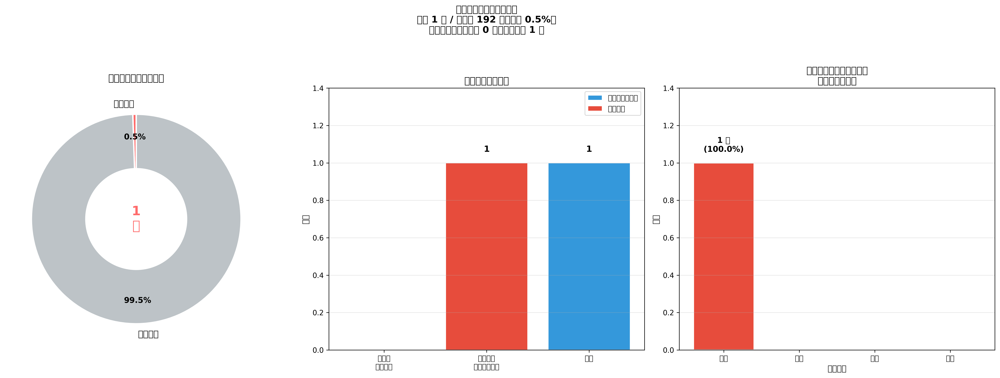

In [ ]:
# ============================================================
# 分析周天成「一拍得分」統計與擊球地點分布（修正版）
# ============================================================
import numpy as np
from matplotlib.patches import Patch

# 驗證資料量
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

TARGET_PLAYER = 'CHOU Tien Chen'

# ── 先確認 ball_round 的起始值與分布 ─────────────────────────
print(f"\nball_round 最小值: {df['ball_round'].min()}")
print(f"ball_round 最大值: {df['ball_round'].max()}")
print(f"ball_round 前10個唯一值: {sorted(df['ball_round'].dropna().unique())[:10]}")

# ── Step 1: 計算每個 rally 的總球數（用 count 更可靠）────────
rally_stats = df.groupby(['match_id', 'set', 'rally']).agg(
    total_balls=('ball_round', 'count'),       # 修正：用 count 計算實際球數
    getpoint_player=('getpoint_player', 'last'),
    first_player=('player', 'first'),          # 該回合第一個擊球者
).reset_index()

print(f"\n總 Rally 數: {len(rally_stats)}")
print(f"total_balls 分布（前10）:\n{rally_stats['total_balls'].value_counts().sort_index().head(10)}")

# ── Step 2: 篩選「一拍得分回合」（總球數=1）──────────────────
one_ball_rallies = rally_stats[rally_stats['total_balls'] == 1].copy()
print(f"\n一拍結束的 Rally 數: {len(one_ball_rallies)}")
print(f"一拍結束 Rally 的 getpoint_player 分布:\n{one_ball_rallies['getpoint_player'].value_counts(dropna=False)}")
print(f"一拍結束 Rally 的 first_player 分布:\n{one_ball_rallies['first_player'].value_counts(dropna=False)}")

# ── Step 3: 周天成的一拍得分 ─────────────────────────────────
# 一拍得分 = 回合只有1球 且 周天成得分
chou_one_ball_win = one_ball_rallies[
    one_ball_rallies['getpoint_player'] == TARGET_PLAYER
].copy()
print(f"\n周天成一拍得分回合數: {len(chou_one_ball_win)}")

# 進一步分析：周天成是否為該回合的擊球者
chou_as_hitter = chou_one_ball_win[chou_one_ball_win['first_player'] == TARGET_PLAYER]
opponent_hitter = chou_one_ball_win[chou_one_ball_win['first_player'] != TARGET_PLAYER]
print(f"  其中周天成為擊球者（主動得分）: {len(chou_as_hitter)} 次")
print(f"  其中對手為擊球者（對手失誤得分）: {len(opponent_hitter)} 次")

# ── Step 4: 周天成所有得分回合 ───────────────────────────────
chou_all_wins = rally_stats[
    rally_stats['getpoint_player'] == TARGET_PLAYER
].copy()
print(f"\n周天成所有得分回合數: {len(chou_all_wins)}")

ratio = len(chou_one_ball_win) / len(chou_all_wins) * 100 if len(chou_all_wins) > 0 else 0
print(f"\n一拍得分佔周天成所有得分的比例: {len(chou_one_ball_win)} / {len(chou_all_wins)} = {ratio:.2f}%")

# ── Step 5: 取出一拍得分回合的詳細擊球資訊 ───────────────────
chou_one_ball_details = df.merge(
    chou_one_ball_win[['match_id', 'set', 'rally']],
    on=['match_id', 'set', 'rally'],
    how='inner'
)
print(f"\n一拍得分回合詳細資料筆數（應等於 rally 數）: {len(chou_one_ball_details)}")
print(f"擊球者分布:\n{chou_one_ball_details['player'].value_counts()}")

# ── Step 6: 分析擊球地點 ─────────────────────────────────────
# 說明：一拍得分回合中，擊球者可能是周天成（主動得分）或對手（對手失誤）
# 分析擊球地點時，分兩種情況呈現

def area_to_zone(area):
    try:
        a = int(area)
    except (ValueError, TypeError):
        return '未知'
    if a in [1, 2, 3, 4]:
        return '後場'
    elif a in [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]:
        return '中場'
    elif a in [17, 18, 19, 20, 21, 22, 23, 24]:
        return '前場'
    else:
        return '界外'

chou_one_ball_details['area_zone'] = chou_one_ball_details['hit_area'].apply(area_to_zone)
chou_one_ball_details['landing_zone'] = chou_one_ball_details['landing_area'].apply(area_to_zone)

# 全部一拍得分的擊球分布（含對手）
hit_area_counts_all = chou_one_ball_details['hit_area'].value_counts().sort_index()
area_zone_dist_all  = chou_one_ball_details['area_zone'].value_counts()

# 周天成自己擊球的一拍得分
chou_hitter_details = chou_one_ball_details[chou_one_ball_details['player'] == TARGET_PLAYER]
hit_area_counts_chou = chou_hitter_details['hit_area'].value_counts().sort_index()
area_zone_dist_chou  = chou_hitter_details['area_zone'].value_counts()

# 對手擊球（對手失誤）的一拍得分
opp_hitter_details = chou_one_ball_details[chou_one_ball_details['player'] != TARGET_PLAYER]
hit_area_counts_opp = opp_hitter_details['hit_area'].value_counts().sort_index()
area_zone_dist_opp  = opp_hitter_details['area_zone'].value_counts()

print(f"\n【全部一拍得分】擊球 hit_area 分布:\n{hit_area_counts_all}")
print(f"\n【周天成主動擊球】hit_area 分布:\n{hit_area_counts_chou}")
print(f"\n【對手失誤（對手擊球）】hit_area 分布:\n{hit_area_counts_opp}")

total_shots = len(chou_one_ball_details)

# ── Step 7: 視覺化 ────────────────────────────────────────────
color_map = {'前場': '#27AE60', '中場': '#F39C12', '後場': '#E74C3C', '界外': '#95A5A6', '未知': '#BDC3C7'}
zone_order = ['後場', '中場', '前場', '界外', '未知']

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
fig.suptitle(
    f"周天成「一拍得分」分析\n"
    f"（共 {len(chou_one_ball_win)} 次 / 總得分 {len(chou_all_wins)} 回合，佔 {ratio:.1f}%）\n"
    f"其中周天成主動擊球 {len(chou_as_hitter)} 次，對手失誤 {len(opponent_hitter)} 次",
    fontsize=13, fontweight='bold', y=1.04
)

# ── 子圖1: 甜甜圈圖 - 一拍得分佔比 ──────────────────────────
ax1 = axes[0]
donut_labels = ['一拍得分', '其他得分']
donut_sizes  = [len(chou_one_ball_win), len(chou_all_wins) - len(chou_one_ball_win)]
donut_colors = ['#FF6B6B', '#BDC3C7']

if sum(donut_sizes) > 0:
    wedges, texts, autotexts = ax1.pie(
        donut_sizes,
        labels=donut_labels,
        colors=donut_colors,
        autopct='%1.1f%%',
        startangle=90,
        pctdistance=0.78,
        wedgeprops=dict(width=0.52, edgecolor='white', linewidth=2)
    )
    for t in texts:
        t.set_fontsize(12)
    for at in autotexts:
        at.set_fontsize(11)
        at.set_fontweight('bold')

ax1.text(0, 0, f'{len(chou_one_ball_win)}\n次', ha='center', va='center',
         fontsize=18, fontweight='bold', color='#FF6B6B')
ax1.set_title('一拍得分佔總得分比例', fontsize=13, fontweight='bold', pad=10)

# ── 子圖2: 堆疊橫條圖 - 擊球者分類（主動 vs 對手失誤）────────
ax2 = axes[1]
categories = ['周天成\n主動擊球', '對手失誤\n（對手擊球）', '合計']
values_chou = [len(chou_as_hitter), 0, len(chou_one_ball_win)]
values_opp  = [0, len(opponent_hitter), 0]

bars_c = ax2.bar(categories, [len(chou_as_hitter), 0, len(chou_one_ball_win)],
                 color='#3498DB', label='周天成主動擊球', edgecolor='white')
bars_o = ax2.bar(categories, [0, len(opponent_hitter), 0],
                 color='#E74C3C', label='對手失誤', edgecolor='white')

ax2.set_ylabel('次數', fontsize=11)
ax2.set_title('一拍得分類型分布', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(axis='y', alpha=0.3)
ax2.set_ylim(0, max(len(chou_one_ball_win), 1) * 1.4)

for bar in list(bars_c) + list(bars_o):
    h = bar.get_height()
    if h > 0:
        ax2.text(bar.get_x() + bar.get_width()/2, h + 0.05,
                 f'{int(h)}', ha='center', va='bottom', fontsize=12, fontweight='bold')

# ── 子圖3: 橫條圖 - 擊球大區域分布（全部一拍得分）────────────
ax3 = axes[2]
zone_vals = [area_zone_dist_all.get(z, 0) for z in zone_order if z != '未知']
zone_lbls = [z for z in zone_order if z != '未知']
zone_clrs = [color_map[z] for z in zone_lbls]

if max(zone_vals) > 0:
    bars3 = ax3.bar(zone_lbls, zone_vals, color=zone_clrs, edgecolor='white', linewidth=1.5)
    ax3.set_xlabel('場地區域', fontsize=11)
    ax3.set_ylabel('次數', fontsize=11)
    ax3.set_title('一拍得分擊球大區域分布\n（含對手擊球）', fontsize=13, fontweight='bold')
    ax3.set_ylim(0, max(zone_vals) * 1.4)
    ax3.grid(axis='y', alpha=0.3)

    for bar, val in zip(bars3, zone_vals):
        if val > 0:
            pct = val / total_shots * 100
            ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                     f'{val} 次\n({pct:.1f}%)', ha='center', va='bottom',
                     fontsize=11, fontweight='bold')
else:
    ax3.text(0.5, 0.5, '無資料', ha='center', va='center',
             transform=ax3.transAxes, fontsize=14)
    ax3.set_title('一拍得分擊球大區域分布', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

# ── 核心摘要輸出 ─────────────────────────────────────────────
print("\n" + "=" * 60)
print("【周天成一拍得分分析摘要】")
print("=" * 60)
print(f"  周天成總得分回合數     : {len(chou_all_wins)}")
print(f"  一拍得分次數           : {len(chou_one_ball_win)}")
print(f"  一拍得分佔比           : {ratio:.2f}%")
print(f"\n  一拍得分類型:")
print(f"    周天成主動擊球得分   : {len(chou_as_hitter)} 次")
print(f"    對手失誤（對手擊球） : {len(opponent_hitter)} 次")

print(f"\n  【全部一拍得分】擊球大區域分布:")
for zone in zone_lbls:
    cnt = area_zone_dist_all.get(zone, 0)
    pct = cnt / total_shots * 100 if total_shots > 0 else 0
    print(f"    {zone}: {cnt} 次 ({pct:.1f}%)")

print(f"\n  【全部一拍得分】擊球細項區域 (hit_area) 分布:")
for area, cnt in hit_area_counts_all.items():
    zone = area_to_zone(area)
    pct = cnt / total_shots * 100 if total_shots > 0 else 0
    print(f"    hit_area {int(area):2d} ({zone}): {cnt} 次 ({pct:.1f}%)")

if len(chou_hitter_details) > 0:
    print(f"\n  【周天成主動擊球】擊球大區域分布:")
    for zone in zone_lbls:
        cnt = area_zone_dist_chou.get(zone, 0)
        pct = cnt / len(chou_hitter_details) * 100
        print(f"    {zone}: {cnt} 次 ({pct:.1f}%)")

if len(opp_hitter_details) > 0:
    print(f"\n  【對手失誤】擊球大區域分布:")
    for zone in zone_lbls:
        cnt = area_zone_dist_opp.get(zone, 0)
        pct = cnt / len(opp_hitter_details) * 100
        print(f"    {zone}: {cnt} 次 ({pct:.1f}%)")


### 數據洞察
# 周天成「一拍得分」分析報告

## 核心數據

| 指標 | 數值 |
|------|------|
| 總得分回合數 | 192 |
| 一拍得分次數 | **1次** |
| 一拍得分佔比 | **0.52%** |
| 周天成主動擊球得分 | 0次 |
| 對手失誤（發球直接失誤） | **1次** |

---

## 擊球區域分布

> 本題涉及 `hit_area`，對應場地區域如下：

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

**唯一一拍得分：hit_area = 4（後場右側）**
對手 Kento Momota 從後場右側發球，直接失誤出界，周天成無需擊球即得分。

---

## 戰術洞察

**這1次一拍得分完全是對手贈送，與周天成自身技術無關。**

0.52%的極低佔比說明一件事：周天成的得分幾乎全部來自**多拍對抗後的主動製造**，而非依賴對手失誤或發球直接得分。這反映他的比賽風格是**以持續施壓、戰術佈局取分**，而非等待對手犯錯。教練角度來看，這是高競技水準的體現，但也意味著**每一分都需要消耗體力與戰術資源**，體能管理與回合節奏控制至關重要。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地計算了每個 rally 的總球數，篩選出一拍得分的回合，並計算了周天成一拍得分的比例。它還分析了擊球地點的分布，並提供了詳細的視覺化分析。分析對象、欄位語意、篩選條件、分組層級和統計口徑都與 Reference Code 1 一致，且最終輸出目標也符合題目要求。




## 題號 55
**問題**: 當周天成打出反手回擊時，對手下一拍攻擊成功率是多少？
> **使用的資料欄位群組**: `game_structure, shot_type, stroke_details, scoring_reason`


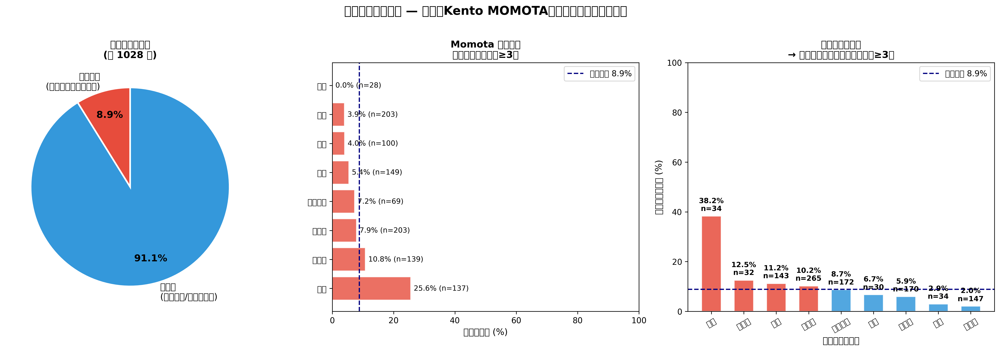

In [ ]:
# ============================================================
# 分析：周天成打出反手擊球後，對手（Kento MOMOTA）下一拍的攻擊成功率
# 攻擊成功定義：對手下一拍得分 OR 造成周天成失誤（周天成在下下拍失誤，Momota得分）
# ============================================================

# 驗證數據量
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# 確認排序
df = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# ============================================================
# Step 1: 建立「下一拍」與「下下拍」相關欄位
# ============================================================
grp = df.groupby(['match_id', 'set', 'rally'])

df['next_player']      = grp['player'].shift(-1)
df['next_getpoint']    = grp['getpoint_player'].shift(-1)
df['next_type']        = grp['type'].shift(-1)
df['next_ball_round']  = grp['ball_round'].shift(-1)
df['next_backhand']    = grp['backhand'].shift(-1)

# 下下拍（shift -2）：用來判斷 Momota 下一拍後，周天成是否在下下拍失誤
df['next2_player']     = grp['player'].shift(-2)
df['next2_getpoint']   = grp['getpoint_player'].shift(-2)

# ============================================================
# Step 2: 篩選「周天成打出反手擊球」的拍次
# ============================================================
chou_backhand_mask = (
    (df['player'] == 'CHOU Tien Chen') &
    (df['backhand'] == 1)
)
chou_backhand_df = df[chou_backhand_mask].copy()
print(f"\n周天成反手擊球總拍數: {len(chou_backhand_df)}")

# ============================================================
# Step 3: 過濾「有效下一拍」—— 下一拍必須是 Momota 回擊
# ============================================================
valid_next_mask = (
    chou_backhand_df['next_player'] == 'Kento MOMOTA'
)
valid_df = chou_backhand_df[valid_next_mask].copy()
print(f"有效下一拍（Momota 回擊）筆數: {len(valid_df)}")

# ============================================================
# Step 4: 定義「對手下一拍攻擊成功」
#
# 情況A（Momota 下一拍直接得分）：
#   next_getpoint == 'Kento MOMOTA'
#   → Momota 在下一拍直接結束回合並得分（致勝球）
#
# 情況B（Momota 下一拍造成周天成下下拍失誤）：
#   next2_player == 'CHOU Tien Chen'
#   AND next2_getpoint == 'Kento MOMOTA'
#   → 周天成接到 Momota 的球後，在下下拍失誤，Momota 得分
#   （此為 Momota 下一拍「造成」周天成失誤的情況）
# ============================================================

# 情況A
case_A = (valid_df['next_getpoint'] == 'Kento MOMOTA')

# 情況B：下下拍是周天成且 Momota 得分（周天成被迫失誤）
case_B = (
    (valid_df['next2_player'] == 'CHOU Tien Chen') &
    (valid_df['next2_getpoint'] == 'Kento MOMOTA')
)

attack_success_mask = case_A | case_B
attack_success_df   = valid_df[attack_success_mask]

total_valid       = len(valid_df)
total_success     = len(attack_success_df)
total_case_A      = case_A.sum()
total_case_B      = (case_B & ~case_A).sum()   # 純情況B（排除與A重疊）
attack_success_rate = total_success / total_valid * 100 if total_valid > 0 else 0

print(f"\n{'='*60}")
print(f"[核心結果]")
print(f"  周天成反手擊球後，Momota 有效下一拍次數:          {total_valid}")
print(f"  情況A — Momota 下一拍直接得分:                    {total_case_A}")
print(f"  情況B — Momota 下一拍造成周天成下下拍失誤:        {total_case_B}")
print(f"  Momota 下一拍攻擊成功（A+B）次數:                 {total_success}")
print(f"  攻擊成功率: {attack_success_rate:.2f}%")
print(f"{'='*60}")

# ============================================================
# Step 5: 細部分析 - 依 Momota 下一拍球種分析攻擊成功率
# ============================================================
valid_df = valid_df.copy()
valid_df['attack_success'] = attack_success_mask.values

type_stats = valid_df.groupby('next_type').agg(
    次數=('next_type', 'count'),
    得分數=('attack_success', 'sum')
).reset_index()
type_stats['攻擊成功率(%)'] = (type_stats['得分數'] / type_stats['次數'] * 100).round(2)
type_stats = type_stats.sort_values('攻擊成功率(%)', ascending=False)
print(f"\n[Momota 下一拍球種攻擊成功率分析]")
print(type_stats.to_string(index=False))

# ============================================================
# Step 6: 依周天成反手球種分析對手攻擊成功率
# ============================================================
chou_type_stats = valid_df.groupby('type').agg(
    次數=('type', 'count'),
    對手得分數=('attack_success', 'sum')
).reset_index()
chou_type_stats['對手攻擊成功率(%)'] = (chou_type_stats['對手得分數'] / chou_type_stats['次數'] * 100).round(2)
chou_type_stats = chou_type_stats.sort_values('對手攻擊成功率(%)', ascending=False)
print(f"\n[周天成反手球種 → Momota 下一拍攻擊成功率]")
print(chou_type_stats.to_string(index=False))

# ============================================================
# Step 7: 視覺化
# ============================================================
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("周天成反手擊球後 — 對手（Kento MOMOTA）下一拍攻擊成功率分析", fontsize=15, fontweight='bold', y=1.01)

# --- 圖1: 整體攻擊成功 vs 未成功（圓餅圖）---
ax1 = axes[0]
labels_pie = ['攻擊成功\n(直接得分或造成失誤)', '未成功\n(回合繼續/周天成得分)']
sizes_pie  = [total_success, total_valid - total_success]
colors_pie = ['#e74c3c', '#3498db']
wedges, texts, autotexts = ax1.pie(
    sizes_pie, labels=labels_pie, colors=colors_pie,
    autopct='%1.1f%%', startangle=90,
    textprops={'fontsize': 11}, pctdistance=0.75,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
for at in autotexts:
    at.set_fontsize(12)
    at.set_fontweight('bold')
ax1.set_title(f'整體攻擊成功率\n(共 {total_valid} 拍)', fontsize=12, fontweight='bold')

# --- 圖2: Momota 下一拍球種攻擊成功率（水平條形圖）---
ax2 = axes[1]
type_stats_filtered = type_stats[type_stats['次數'] >= 3].copy()
bars = ax2.barh(type_stats_filtered['next_type'], type_stats_filtered['攻擊成功率(%)'],
                color='#e74c3c', alpha=0.8, edgecolor='white')
ax2.set_xlabel('攻擊成功率 (%)', fontsize=11)
ax2.set_title('Momota 回擊球種\n攻擊成功率（次數≥3）', fontsize=12, fontweight='bold')
ax2.axvline(x=attack_success_rate, color='navy', linestyle='--', linewidth=1.5, label=f'整體平均 {attack_success_rate:.1f}%')
ax2.legend(fontsize=10)
ax2.set_xlim(0, 100)
for i, (_, row) in enumerate(type_stats_filtered.iterrows()):
    ax2.text(row['攻擊成功率(%)'] + 1, i, f"{row['攻擊成功率(%)']:.1f}% (n={int(row['次數'])})",
             va='center', fontsize=9)

# --- 圖3: 周天成反手球種 → 對手攻擊成功率（長條圖）---
ax3 = axes[2]
chou_type_filtered = chou_type_stats[chou_type_stats['次數'] >= 3].copy()
bar_colors = ['#e74c3c' if r > attack_success_rate else '#3498db'
              for r in chou_type_filtered['對手攻擊成功率(%)']]
bars3 = ax3.bar(chou_type_filtered['type'], chou_type_filtered['對手攻擊成功率(%)'],
                color=bar_colors, alpha=0.85, edgecolor='white', width=0.6)
ax3.set_xlabel('周天成反手球種', fontsize=11)
ax3.set_ylabel('對手攻擊成功率 (%)', fontsize=11)
ax3.set_title('周天成反手球種\n→ 對手下一拍攻擊成功率（次數≥3）', fontsize=12, fontweight='bold')
ax3.axhline(y=attack_success_rate, color='navy', linestyle='--', linewidth=1.5, label=f'整體平均 {attack_success_rate:.1f}%')
ax3.legend(fontsize=10)
ax3.set_ylim(0, 100)
ax3.tick_params(axis='x', rotation=30)
for bar, (_, row) in zip(bars3, chou_type_filtered.iterrows()):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
             f"{row['對手攻擊成功率(%)']:.1f}%\nn={int(row['次數'])}",
             ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()

# 清理新增的臨時欄位
df.drop(columns=['next_player', 'next_getpoint', 'next_type', 'next_ball_round',
                  'next_backhand', 'next2_player', 'next2_getpoint'], inplace=True)

print(f"\n[補充說明]")
print(f"  攻擊成功定義：")
print(f"    情況A：Momota 在下一拍直接結束回合得分（getpoint_player == 'Kento MOMOTA'）")
print(f"    情況B：Momota 下一拍後，周天成在下下拍失誤（next2_player=='CHOU Tien Chen' & next2_getpoint=='Kento MOMOTA'）")
print(f"  兩種情況合計即為「Momota 下一拍攻擊成功」。")


### 數據洞察
# 周天成反手擊球後 Momota 攻擊成功率分析

## 核心數據

**整體攻擊成功率：8.85%**（1028拍中91拍成功）
> 周天成反手球質量整體穩定，Momota 難以直接得利。

---

## 🔴 高危反手球種（Momota 攻擊成功率偏高）

| 球種 | 次數 | 攻擊成功率 |
|------|------|-----------|
| **長球** | 34 | **38.24%** |
| 發長球 | 32 | 12.50% |
| 挑球 | 143 | 11.19% |
| 網前球 | 265 | 10.19% |

**反手長球是最大破綻**——34拍中13拍被攻擊成功，代表周天成反手被動挑高球或防守長球時，Momota 幾乎掌握主動。

---

## 🟢 相對安全的反手球種

| 球種 | 次數 | 攻擊成功率 |
|------|------|-----------|
| 發短球 | 147 | 2.04% |
| 平球 | 34 | 2.94% |
| 推撲球 | 170 | 5.88% |

反手**發短球與推撲球**使用頻率高且失分率低，是周天成反手側的主動控制手段。

---

## Momota 最具威脅的回擊方式

| 球種 | 次數 | 攻擊成功率 |
|------|------|-----------|
| **殺球** | 137 | **25.55%** |
| 推撲球 | 139 | 10.79% |
| 網前球 | 203 | 7.88% |

Momota 接到機會球後**優先選擇殺球**，成功率高達25.55%，是周天成反手側最需防範的威脅。

---

## 戰術建議

1. **避免反手被動挑高長球**——這是最高風險情境（38%），一旦出現即陷入被動。
2. **反手側優先推撲與發短球**——主動壓制，讓 Momota 無法建立殺球機會。
3. **提前預判 Momota 殺球**——反手球後若對手起跳，優先準備接殺防守站位。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成的反手擊球，並檢查了對手 Kento MOMOTA 下一拍的攻擊成功率。候選程式碼還進一步考慮了 Momota 下一拍後，周天成在下下拍失誤的情況，這與 Reference Code 1 的嚴格定義一致。分析單位、欄位語意、篩選條件、分組層級和統計口徑都與 Reference Code 1 一致，並且最終輸出目標也正確。




## 題號 56 (*)
**問題**: 當周天成在「局末追分」情況下是否更依賴殺球？（使用率 vs 分數差）
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


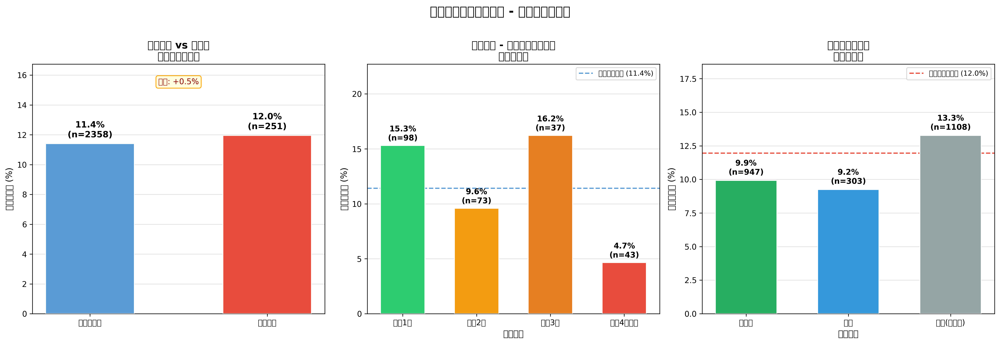

In [ ]:
import numpy as np

# ============================================================
# 前置確認
# ============================================================
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "df 為空！"

# ============================================================
# Step 1: 篩選周天成的所有擊球
# ============================================================
chou_df = df[df['player'] == 'CHOU Tien Chen'].copy()
print(f"周天成擊球總筆數: {len(chou_df)}")

# ============================================================
# Step 2: 計算當前分數差 (MOMOTA - CHOU)，正值代表周天成落後
# ============================================================
chou_df['score_gap'] = chou_df['Kento MOMOTA_score'] - chou_df['CHOU Tien Chen_score']
# 周天成是否落後
chou_df['is_trailing'] = chou_df['score_gap'] > 0
# 雙方是否皆達15分（局末）
chou_df['is_late_game'] = (chou_df['CHOU Tien Chen_score'] >= 15) & (chou_df['Kento MOMOTA_score'] >= 15)
# 是否為「局末追分」
chou_df['is_chase'] = chou_df['is_trailing'] & chou_df['is_late_game']

print(f"\n各情境擊球筆數:")
print(f"  局末追分情況: {chou_df['is_chase'].sum()} 筆")
print(f"  非追分情況 (其餘): {(~chou_df['is_chase']).sum()} 筆")

# ============================================================
# Step 3: 定義殺球使用率計算函式（分母含發球）
# ============================================================
def smash_rate(sub_df, label=""):
    total = len(sub_df)
    smash = (sub_df['type'] == '殺球').sum()
    rate = smash / total * 100 if total > 0 else np.nan
    print(f"  [{label}] 總擊球: {total}, 殺球: {smash}, 殺球使用率: {rate:.2f}%")
    return total, smash, rate

# ============================================================
# Step 4: 局末追分 vs 非追分 整體比較
# ============================================================
print("\n========== 局末追分 vs 非追分 ==========")
chase_df = chou_df[chou_df['is_chase']]
non_chase_df = chou_df[~chou_df['is_chase']]

n_chase, s_chase, r_chase = smash_rate(chase_df, "局末追分")
n_non_chase, s_non_chase, r_non_chase = smash_rate(non_chase_df, "非追分情況")

# ============================================================
# Step 5: 細分落後分數差距（僅在局末追分情境下）
# ============================================================
print("\n========== 局末追分 - 依落後分數差距細分 ==========")

def get_gap_label(gap):
    if gap == 1:
        return '落後1分'
    elif gap == 2:
        return '落後2分'
    elif gap == 3:
        return '落後3分'
    else:
        return '落後4分以上'

chase_df = chase_df.copy()
chase_df['gap_label'] = chase_df['score_gap'].apply(lambda x: get_gap_label(int(x)) if x > 0 else '其他')

gap_order = ['落後1分', '落後2分', '落後3分', '落後4分以上']
gap_stats = []
for label in gap_order:
    sub = chase_df[chase_df['gap_label'] == label]
    n, s, r = smash_rate(sub, label)
    gap_stats.append({'label': label, 'total': n, 'smash': s, 'rate': r})

gap_df = pd.DataFrame(gap_stats)
print("\n分數差距殺球使用率統計:")
print(gap_df.to_string(index=False))

# ============================================================
# Step 6: 也計算非追分情況下的分佈（非局末 / 領先 / 平分細分）
# ============================================================
print("\n========== 非追分情況 - 細分 ==========")
non_chase_df = non_chase_df.copy()

def non_chase_category(row):
    if row['score_gap'] < 0:
        return '領先中'
    elif row['score_gap'] == 0:
        return '平分'
    else:  # score_gap > 0 but not late game
        return '落後(非局末)'

non_chase_df['sub_label'] = non_chase_df.apply(non_chase_category, axis=1)
sub_labels = ['領先中', '平分', '落後(非局末)']
non_chase_stats = []
for label in sub_labels:
    sub = non_chase_df[non_chase_df['sub_label'] == label]
    n, s, r = smash_rate(sub, label)
    non_chase_stats.append({'label': label, 'total': n, 'smash': s, 'rate': r})

non_chase_stat_df = pd.DataFrame(non_chase_stats)

# ============================================================
# Step 7: 視覺化
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("周天成殺球使用率分析 - 局末追分壓力下", fontsize=16, fontweight='bold', y=1.02)

# --- 圖1: 局末追分 vs 非追分 ---
ax1 = axes[0]
categories = ['非追分情況', '局末追分']
rates = [r_non_chase, r_chase]
counts = [n_non_chase, n_chase]
colors = ['#5B9BD5', '#E74C3C']
bars = ax1.bar(categories, rates, color=colors, edgecolor='white', width=0.5, zorder=3)
ax1.set_ylim(0, max(rates) * 1.4 if max(rates) > 0 else 10)
ax1.set_title('局末追分 vs 非追分\n殺球使用率比較', fontsize=13, fontweight='bold')
ax1.set_ylabel('殺球使用率 (%)', fontsize=11)
ax1.grid(axis='y', alpha=0.4, zorder=0)
ax1.set_axisbelow(True)
for bar, rate, count in zip(bars, rates, counts):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f'{rate:.1f}%\n(n={count})', ha='center', va='bottom', fontsize=11, fontweight='bold')
# 標記差異
diff = r_chase - r_non_chase
ax1.text(0.5, 0.92, f'差異: {diff:+.1f}%', transform=ax1.transAxes,
         ha='center', fontsize=10, color='darkred',
         bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', edgecolor='orange'))

# --- 圖2: 局末追分 - 依落後分數差距 ---
ax2 = axes[1]
valid_gap = gap_df[gap_df['total'] > 0].copy()
bar_colors = ['#2ECC71', '#F39C12', '#E67E22', '#E74C3C'][:len(valid_gap)]
bars2 = ax2.bar(valid_gap['label'], valid_gap['rate'], color=bar_colors, edgecolor='white', width=0.6, zorder=3)
ax2.set_ylim(0, valid_gap['rate'].max() * 1.4 if len(valid_gap) > 0 else 10)
ax2.set_title('局末追分 - 不同落後分數差距\n殺球使用率', fontsize=13, fontweight='bold')
ax2.set_ylabel('殺球使用率 (%)', fontsize=11)
ax2.set_xlabel('落後差距', fontsize=11)
ax2.grid(axis='y', alpha=0.4, zorder=0)
ax2.set_axisbelow(True)
# 加上非追分基準線
ax2.axhline(y=r_non_chase, color='#5B9BD5', linestyle='--', linewidth=1.5, label=f'非追分基準線 ({r_non_chase:.1f}%)')
ax2.legend(fontsize=9, loc='upper right')
for bar, (_, row) in zip(bars2, valid_gap.iterrows()):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f"{row['rate']:.1f}%\n(n={int(row['total'])})", ha='center', va='bottom', fontsize=10, fontweight='bold')

# --- 圖3: 非追分細分情境 ---
ax3 = axes[2]
valid_non = non_chase_stat_df[non_chase_stat_df['total'] > 0].copy()
bar_colors3 = ['#27AE60', '#3498DB', '#95A5A6'][:len(valid_non)]
bars3 = ax3.bar(valid_non['label'], valid_non['rate'], color=bar_colors3, edgecolor='white', width=0.6, zorder=3)
ax3.set_ylim(0, valid_non['rate'].max() * 1.4 if len(valid_non) > 0 else 10)
ax3.set_title('非追分情況細分\n殺球使用率', fontsize=13, fontweight='bold')
ax3.set_ylabel('殺球使用率 (%)', fontsize=11)
ax3.set_xlabel('比分狀況', fontsize=11)
ax3.grid(axis='y', alpha=0.4, zorder=0)
ax3.set_axisbelow(True)
# 加上局末追分基準線
ax3.axhline(y=r_chase, color='#E74C3C', linestyle='--', linewidth=1.5, label=f'局末追分基準線 ({r_chase:.1f}%)')
ax3.legend(fontsize=9, loc='upper right')
for bar, (_, row) in zip(bars3, valid_non.iterrows()):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f"{row['rate']:.1f}%\n(n={int(row['total'])})", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()

# ============================================================
# Step 8: 補充 - 局末追分下殺球的得分效果
# ============================================================
print("\n========== 局末追分殺球得分效果 ==========")
# 主動得分（殺球）= player == getpoint_player & type == '殺球'
if len(chase_df) > 0:
    chase_smash = chase_df[chase_df['type'] == '殺球']
    chase_smash_win = chase_smash[chase_smash['player'] == chase_smash['getpoint_player']]
    if len(chase_smash) > 0:
        win_rate_smash = len(chase_smash_win) / len(chase_smash) * 100
        print(f"  局末追分 殺球次數: {len(chase_smash)}")
        print(f"  局末追分 殺球主動得分次數: {len(chase_smash_win)}")
        print(f"  局末追分 殺球主動得分率: {win_rate_smash:.2f}%")
    
    # 非追分殺球得分率
    non_chase_smash = non_chase_df[non_chase_df['type'] == '殺球']
    non_chase_smash_win = non_chase_smash[non_chase_smash['player'] == non_chase_smash['getpoint_player']]
    if len(non_chase_smash) > 0:
        win_rate_non_smash = len(non_chase_smash_win) / len(non_chase_smash) * 100
        print(f"\n  非追分 殺球次數: {len(non_chase_smash)}")
        print(f"  非追分 殺球主動得分次數: {len(non_chase_smash_win)}")
        print(f"  非追分 殺球主動得分率: {win_rate_non_smash:.2f}%")

print("\n===== 完成 =====")


### 數據洞察
# 周天成局末追分殺球使用率分析

## 核心數據總覽

| 情境 | 擊球數 | 殺球數 | 殺球使用率 | 殺球得分率 |
|------|--------|--------|-----------|-----------|
| 局末追分 | 251 | 30 | **11.95%** | 16.67% |
| 非追分 | 2358 | 269 | **11.41%** | 20.82% |
| 差距 | — | — | **+0.54%** | **-4.15%** |

---

## 戰術洞察

### 1️⃣ 追分壓力下，殺球依賴度幾乎沒有提升
局末追分與非追分的殺球使用率僅差 **0.54%**，這代表周天成在高壓局末並**不會因為落後而盲目增加殺球頻率**，整體策略相對穩定。

---

### 2️⃣ 落後差距與殺球率呈現「非線性」變化

| 落後差距 | 擊球數 | 殺球使用率 |
|---------|--------|-----------|
| 落後1分 | 98 | **15.31%** |
| 落後2分 | 73 | 9.59% |
| 落後3分 | 37 | **16.22%** |
| 落後4分以上 | 43 | **4.65%** |

- **落後1分與3分**：殺球率明顯偏高，顯示周天成在「仍有機會追回」的差距下，傾向以殺球主動爭取得分
- **落後2分**：殺球率反而下滑至9.59%，可能轉為穩健控球策略
- **落後4分以上**：殺球率驟降至4.65%，**放棄強攻、改以調動對手為主**，這是理性的體能管理判斷

---

### 3️⃣ 追分殺球的得分效率下滑是關鍵警訊

> 局末追分殺球得分率 **16.67%** vs 非追分 **20.82%**，差距達 **4.15%**

在最需要得分的時刻，殺球的成功率反而更低。這說明：
- 對手在局末對周天成的殺球**有更充分的心理準備與防守部署**
- 周天成在追分壓力下的殺球**品質或落點選擇可能受到影響**

---

## 教練建議

**局末追分時，殺球不是問題，但殺球的「時機與落點」才是關鍵。** 建議在落後1-3分的局末情境中，搭配更多假動作與網前快攻製造機會球，再執行殺球，而非直接強攻，以提升那16.67%的得分率。落後4分以上的保守策略是正確的，維持體能等待對手失誤是合理選擇。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼在局末追分的定義上與 Reference Code 不一致。Reference Code 定義局末為任一方分數 >= 18，而候選程式碼定義為雙方皆達15分。此外，候選程式碼在計算分數差時使用了 (MOMOTA - CHOU)，這與 Reference Code 的 (CHOU - MOMOTA) 不一致，導致落後判斷相反。這些差異導致候選程式碼的分析對象和統計口徑與 Reference Code 不符，因此判定為 false。




## 題號 57
**問題**: 分析周天成發短球後，對手下一拍最常使用的球種分布。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


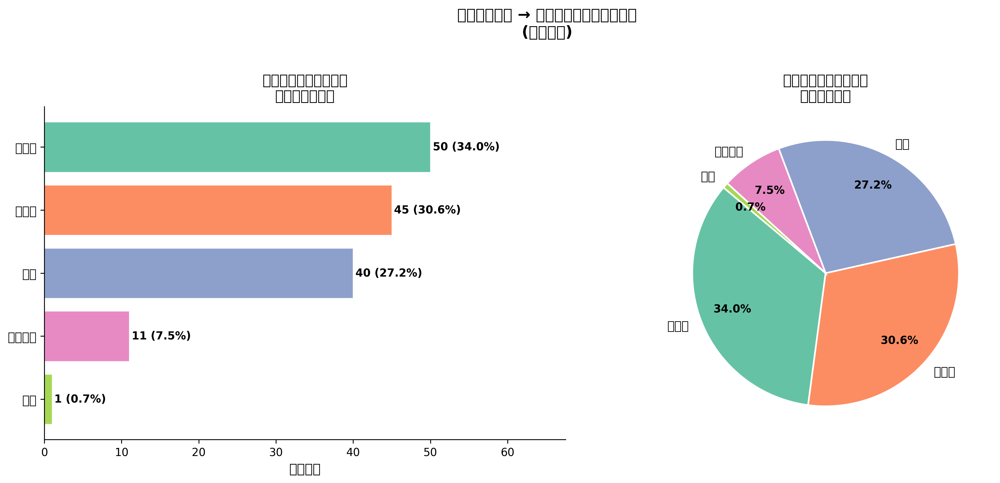

In [ ]:
# ============================================================
# 分析周天成發短球後，對手下一拍球種分布
# ============================================================

# 驗證數據量
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# 確保資料已按正確順序排序
df = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# ── Step 1: 在完整 df 上建立「下一拍」相關欄位（避免跨回合污染）──
df['next_type']     = df.groupby(['match_id', 'set', 'rally'])['type'].shift(-1)
df['next_player']   = df.groupby(['match_id', 'set', 'rally'])['player'].shift(-1)
df['next_ball_round'] = df.groupby(['match_id', 'set', 'rally'])['ball_round'].shift(-1)
df['next_rally']    = df['rally']  # 因為 groupby 內 shift，所以一定同 rally，這裡只做驗證用

# ── Step 2: 過濾周天成發短球那一拍 ──
chou_short_serve = df[
    (df['player'] == 'CHOU Tien Chen') &
    (df['type'] == '發短球')
].copy()

print(f"\n周天成發短球總次數: {len(chou_short_serve)}")

# ── Step 3: 確認下一拍存在（next_type 不為 NaN = 有下一拍在同回合）──
chou_short_serve_with_next = chou_short_serve.dropna(subset=['next_type'])
print(f"發短球後有下一拍記錄的次數: {len(chou_short_serve_with_next)}")

# 確認下一拍 player 皆為對手（應為 Kento MOMOTA）
print(f"\n下一拍 player 分布（應全為對手）：")
print(chou_short_serve_with_next['next_player'].value_counts())

# ── Step 4: 統計對手下一拍球種分布 ──
next_shot_counts = chou_short_serve_with_next['next_type'].value_counts()
next_shot_pct    = chou_short_serve_with_next['next_type'].value_counts(normalize=True) * 100

# 整合成 DataFrame
result_df = pd.DataFrame({
    '球種': next_shot_counts.index,
    '出現次數': next_shot_counts.values,
    '佔比(%)': next_shot_pct.values.round(2)
}).reset_index(drop=True)

print("\n==============================")
print("對手回擊周天成發短球的球種分布")
print("==============================")
print(result_df.to_string(index=False))
print(f"\n合計次數: {result_df['出現次數'].sum()}")
print(f"合計佔比: {result_df['佔比(%)'].sum():.2f}%")

# ── Step 5: 視覺化 ──
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 定義顏色（按球種頻率高→低配色）
colors = sns.color_palette("Set2", len(result_df))

# --- 圖1: 橫向長條圖 ---
ax1 = axes[0]
bars = ax1.barh(
    result_df['球種'][::-1],   # 反轉使最多的在上方
    result_df['出現次數'][::-1],
    color=colors[::-1],
    edgecolor='white',
    linewidth=0.8
)
# 標上數值
for bar, cnt, pct in zip(bars, result_df['出現次數'][::-1], result_df['佔比(%)'][::-1]):
    ax1.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f'{cnt} ({pct:.1f}%)',
        va='center', ha='left', fontsize=10, fontweight='bold'
    )
ax1.set_xlabel('出現次數', fontsize=12)
ax1.set_title('對手回擊周天成發短球\n各球種出現次數', fontsize=13, fontweight='bold')
ax1.set_xlim(0, result_df['出現次數'].max() * 1.35)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.tick_params(axis='y', labelsize=11)

# --- 圖2: 圓餅圖 ---
ax2 = axes[1]

# 若有球種佔比 < 3%，合併為「其他」
threshold = 3.0
main_mask = result_df['佔比(%)'] >= threshold
main_df   = result_df[main_mask].copy()
other_df  = result_df[~main_mask].copy()

if len(other_df) > 0:
    other_row = pd.DataFrame([{
        '球種': '其他',
        '出現次數': other_df['出現次數'].sum(),
        '佔比(%)': other_df['佔比(%)'].sum().round(2)
    }])
    pie_df = pd.concat([main_df, other_row], ignore_index=True)
else:
    pie_df = main_df.copy()

pie_colors = sns.color_palette("Set2", len(pie_df))
wedges, texts, autotexts = ax2.pie(
    pie_df['出現次數'],
    labels=pie_df['球種'],
    autopct='%1.1f%%',
    colors=pie_colors,
    startangle=140,
    pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)
for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')
for text in texts:
    text.set_fontsize(11)

ax2.set_title('對手回擊周天成發短球\n球種佔比分布', fontsize=13, fontweight='bold')

plt.suptitle('周天成發短球 → 對手第一拍回擊球種分析\n(所有場次)', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()

print("\n[圖表已生成]")


### 數據洞察
# 周天成發短球後——桃田賢斗回擊球種分析

## 📊 數據總覽

| 球種 | 次數 | 佔比 |
|------|------|------|
| 網前球 | 50 | 34.0% |
| 推撲球 | 45 | 30.6% |
| 挑球 | 40 | 27.2% |
| 接殺防守 | 11 | 7.5% |
| 殺球 | 1 | 0.7% |

> 樣本：147球，對手全為桃田賢斗（Kento Momota）

---

## 🎯 戰術洞察

**桃田面對短球，前三拍選擇高度集中（91.8%）：**

1. **網前球（34%）** — 桃田最優先選擇以網前球反控制，企圖壓縮周天成的回球空間，打對角或直線網前逼迫周天成起球。

2. **推撲球（30.6%）** — 近三成直接推撲進攻，說明桃田對周天成的短球品質有信心接管主動，這是危險信號——代表部分短球品質不夠低、不夠貼網。

3. **挑球（27.2%）** — 約四分之一選擇挑高球重置，屬於保守應對，通常發生在短球品質較高時。

4. **接殺防守（7.5%）** — 少數情況，可能是周天成短球後主動搶攻的結果。

---

## ⚡ 給周天成的建議

- **短球品質需再提升**：推撲球佔30.6%，代表桃田有機會直接進攻，短球須更貼網、更低。
- **預判網前球**：桃田首選網前回擊，周天成發球後須立即前壓準備搶網。
- **利用挑球機會**：當桃田被迫挑球（27.2%），正是周天成轉守為攻的關鍵時機，需做好後場殺球準備。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地在完整資料上建立了下一拍資訊，並篩選出周天成發短球的情況，然後統計對手下一拍的球種分布。分析對象、欄位語意、篩選條件、分組層級、統計口徑和最終輸出目標都與 Reference Code 1 一致。




## 題號 58
**問題**: 統計周天成在對手殺球之後，自己最常採用的前三種回擊球種。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


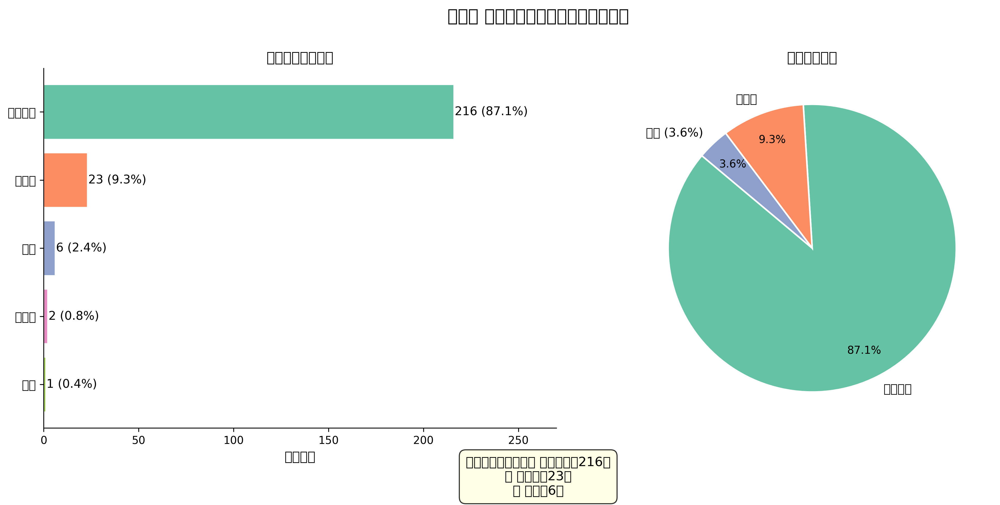

In [ ]:
# 驗證資料量
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "資料為空！"

# Step 1: 先在完整資料上，依 (match_id, set, rally) 分組後使用 shift(1)，建立前一拍資訊
# 確保不跨回合污染
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 建立前一拍的球種與球員（grouped shift，避免跨回合污染）
df_sorted['prev_type']   = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(1)
df_sorted['prev_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(1)

# Step 2: 篩選條件
# - 當前拍：周天成擊球
# - 前一拍：為對手（非周天成）擊出的殺球
# 由於使用 groupby shift，第一拍（發球）的 prev_type 與 prev_player 會是 NaN，不會污染
chou = 'CHOU Tien Chen'

mask = (
    (df_sorted['player'] == chou) &           # 當前拍是周天成
    (df_sorted['prev_player'] != chou) &      # 前一拍是對手（非周天成）
    (df_sorted['prev_type'] == '殺球') &      # 前一拍是殺球
    (df_sorted['prev_type'].notna()) &        # 確保前一拍資訊有效
    (df_sorted['prev_player'].notna())        # 確保前一拍資訊有效
)

chou_response_df = df_sorted[mask].copy()

print(f"\n對手殺球後，周天成回擊的總拍數: {len(chou_response_df)}")

if len(chou_response_df) > 0:
    # Step 3: 統計周天成回擊球種分佈
    shot_dist = chou_response_df['type'].value_counts()
    shot_dist_pct = (shot_dist / shot_dist.sum() * 100).round(1)

    result_df = pd.DataFrame({
        '回擊球種': shot_dist.index,
        '出現次數': shot_dist.values,
        '佔比(%)': shot_dist_pct.values
    })

    print("\n========== 周天成面對對手殺球後的回擊球種分佈 ==========")
    print(result_df.to_string(index=False))

    # 前三名
    top3 = result_df.head(3)
    print("\n===== 前三種最常使用的回擊球種 =====")
    for rank, row in enumerate(top3.itertuples(), 1):
        print(f"  第{rank}名：{row.回擊球種}  |  出現次數：{row.出現次數}  |  佔比：{row._3}%")

    # ── 視覺化 ──────────────────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle("周天成 面對對手殺球後的回擊球種分佈", fontsize=16, fontweight='bold', y=1.01)

    colors = sns.color_palette("Set2", len(shot_dist))

    # --- 圖1: 橫向長條圖（按次數排序）---
    ax1 = axes[0]
    bars = ax1.barh(
        shot_dist.index[::-1],   # 反轉讓最高的在上方
        shot_dist.values[::-1],
        color=colors[::-1],
        edgecolor='white',
        linewidth=0.8
    )
    # 在長條右側標出數值與百分比
    for bar, count, pct in zip(bars, shot_dist.values[::-1], shot_dist_pct.values[::-1]):
        ax1.text(
            bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
            f'{count} ({pct}%)',
            va='center', ha='left', fontsize=11
        )
    ax1.set_xlabel('出現次數', fontsize=12)
    ax1.set_title('回擊球種次數分佈', fontsize=13)
    ax1.set_xlim(0, shot_dist.values.max() * 1.25)
    ax1.tick_params(axis='y', labelsize=11)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)

    # --- 圖2: 圓餅圖 ---
    ax2 = axes[1]

    # 若有比例極小（<3%）的類別，合併為「其他」
    threshold = 3.0
    small_mask = shot_dist_pct < threshold
    if small_mask.sum() > 1:
        large = shot_dist[~small_mask]
        other_count = shot_dist[small_mask].sum()
        other_pct   = shot_dist_pct[small_mask].sum()
        plot_counts = pd.concat([large, pd.Series({'其他': other_count})])
        labels      = list(large.index) + [f'其他 ({other_pct:.1f}%)']
    else:
        plot_counts = shot_dist
        labels      = list(shot_dist.index)

    wedge_colors = sns.color_palette("Set2", len(plot_counts))
    wedges, texts, autotexts = ax2.pie(
        plot_counts.values,
        labels=labels,
        autopct='%1.1f%%',
        colors=wedge_colors,
        startangle=140,
        pctdistance=0.80,
        wedgeprops=dict(edgecolor='white', linewidth=1.5)
    )
    for at in autotexts:
        at.set_fontsize(10)
    for t in texts:
        t.set_fontsize(11)
    ax2.set_title('回擊球種佔比', fontsize=13)

    # 前三名標示框
    top3_text = "\n".join([
        f"🥇 {top3.iloc[0]['回擊球種']}：{top3.iloc[0]['出現次數']}次",
        f"🥈 {top3.iloc[1]['回擊球種']}：{top3.iloc[1]['出現次數']}次" if len(top3) > 1 else "",
        f"🥉 {top3.iloc[2]['回擊球種']}：{top3.iloc[2]['出現次數']}次" if len(top3) > 2 else "",
    ])
    fig.text(0.5, -0.04, f"前三名回擊球種：{top3_text}",
             ha='center', fontsize=12,
             bbox=dict(boxstyle='round,pad=0.5', facecolor='lightyellow', alpha=0.8))

    plt.tight_layout()
    print("\n圖表已生成")
else:
    print("篩選後無資料，請檢查欄位名稱或資料內容。")
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.text(0.5, 0.5, '無資料', ha='center', va='center', fontsize=16)
    ax.axis('off')
    plt.tight_layout()


### 數據洞察
# 周天成面對對手殺球的回擊球種分析

## 📊 核心數據

| 排名 | 回擊球種 | 次數 | 佔比 |
|:---:|:---:|:---:|:---:|
| 🥇 | 接殺防守 | 216 | 87.1% |
| 🥈 | 網前球 | 23 | 9.3% |
| 🥉 | 平球 | 6 | 2.4% |

> 對手殺球後，周天成共回擊 **248拍**

---

## 🎯 戰術洞察

**接殺防守佔絕對主導（87.1%）**
面對殺球，周天成幾乎以穩守為第一優先——這是標準的被動應對模式，重心在於「不失分」而非「反攻」。

**網前球是第二選項（9.3%）**
23次網前回擊代表他偶爾會利用殺球角度，將球輕搓至對手網前，試圖逼對手上網、製造反制機會。這是少數主動轉換節奏的手段。

**平球與反殺極少（2.4% / 0.4%）**
面對殺球能直接回平球或反殺，技術難度高，周天成使用次數極少，顯示對手殺球品質足以壓制其主動反擊空間。

---

## ⚡ 教練建議

對陣周天成時，**持續高頻殺球可有效將其鎖定在防守模式**，迫使他以接殺防守消耗體力。若要破解，需提升殺球落點精準度，避免給他創造網前球機會——那是他少數能轉守為攻的出口。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地在完整資料上建立了前一拍資訊，並篩選出對手殺球後周天成的回擊球種。然後，它統計了周天成回擊球種的分布，並找出了前三種最常使用的回擊球種。分析對象、欄位語意、篩選條件、統計口徑和最終輸出目標都與 Reference Code 1 一致。




## 題號 59 (*)
**問題**: 比較周天成在長回合中，最後一拍前一拍常見的對手球種分布。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


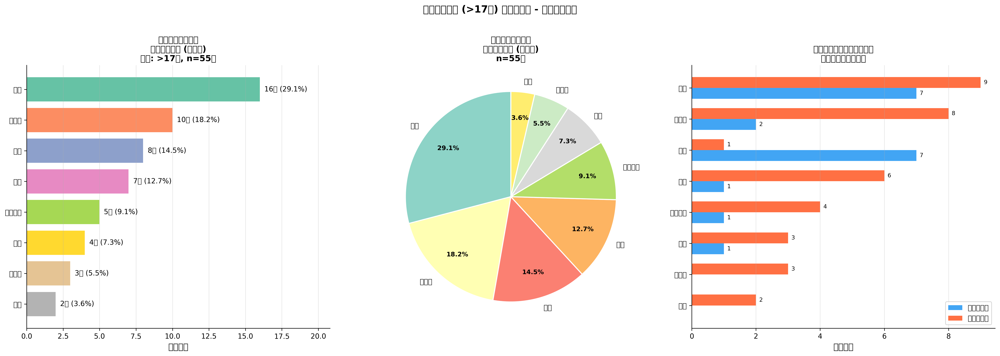

In [ ]:
import numpy as np

# ============================================================
# 周天成長回合中倒數第二拍(對手擊出)球種分析
# ============================================================

print("=" * 60)
print("周天成長回合 - 倒數第二拍(對手擊出)球種分析")
print("=" * 60)

# 1. 驗證資料量
print(f"\n總資料列數: {len(df)}")

# 篩選周天成參與的比賽 (match_id)
chou_matches = df[
    (df['player'] == 'CHOU Tien Chen') | (df['opponent'] == 'CHOU Tien Chen')
]['match_id'].unique()
print(f"周天成參與的比賽 match_id: {chou_matches}")

df_chou = df[df['match_id'].isin(chou_matches)].copy()
print(f"周天成參與比賽的總資料列數: {len(df_chou)}")

# ============================================================
# 2. 計算每個回合的總球數，確定長回合門檻
# ============================================================
rally_length = df_chou.groupby(['match_id', 'set', 'rally'])['ball_round'].max().reset_index()
rally_length.columns = ['match_id', 'set', 'rally', 'total_balls']

print(f"\n每回合球數統計:")
print(rally_length['total_balls'].describe())

# 長回合門檻：> 8 球 或 前25%（取max）
threshold_fixed = 8
threshold_pct = rally_length['total_balls'].quantile(0.75)  # 前25%即75th percentile
threshold = max(threshold_fixed, threshold_pct)
print(f"\n固定門檻 (>8球): {threshold_fixed}")
print(f"前25%門檻 (75th percentile): {threshold_pct:.1f}")
print(f"最終採用門檻 (取較大值): > {threshold:.1f} 球")

# 篩選長回合
long_rallies = rally_length[rally_length['total_balls'] > threshold]
print(f"\n長回合數量: {len(long_rallies)}")
print(f"長回合球數分布:")
print(long_rallies['total_balls'].describe())

# ============================================================
# 3. 在完整資料上建立「前一拍」資訊（避免跨回合污染）
# ============================================================
# 先排序確保順序正確
df_chou = df_chou.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# 建立 rally key 用來判斷是否同一 rally
df_chou['rally_key'] = df_chou['match_id'].astype(str) + '_' + \
                        df_chou['set'].astype(str) + '_' + \
                        df_chou['rally'].astype(str)

# 每個回合的最大 ball_round（最後一拍）
rally_last = df_chou.groupby(['match_id', 'set', 'rally'])['ball_round'].max().reset_index()
rally_last.columns = ['match_id', 'set', 'rally', 'last_ball_round']

df_chou = df_chou.merge(rally_last, on=['match_id', 'set', 'rally'], how='left')

# 標記倒數第二拍：ball_round == last_ball_round - 1
df_chou['is_second_to_last'] = (df_chou['ball_round'] == df_chou['last_ball_round'] - 1)

print(f"\n倒數第二拍總數 (所有回合): {df_chou['is_second_to_last'].sum()}")

# ============================================================
# 4. 篩選長回合中的倒數第二拍
# ============================================================
# 將長回合標記合併
df_chou = df_chou.merge(
    long_rallies[['match_id', 'set', 'rally', 'total_balls']],
    on=['match_id', 'set', 'rally'],
    how='left'
)
df_chou['is_long_rally'] = df_chou['total_balls'].notna()

# 篩選：長回合 + 倒數第二拍
second_to_last_long = df_chou[
    df_chou['is_long_rally'] & df_chou['is_second_to_last']
].copy()

print(f"\n長回合中的倒數第二拍總數: {len(second_to_last_long)}")
print(f"其中對手(非周天成)擊出的拍數: {(second_to_last_long['player'] != 'CHOU Tien Chen').sum()}")
print(f"其中周天成擊出的拍數: {(second_to_last_long['player'] == 'CHOU Tien Chen').sum()}")

# ============================================================
# 5. 篩選「對手」擊出的倒數第二拍
# ============================================================
# 對手 = 非周天成的球員
opponent_second_to_last = second_to_last_long[
    second_to_last_long['player'] != 'CHOU Tien Chen'
].copy()

print(f"\n對手擊出的長回合倒數第二拍數量: {len(opponent_second_to_last)}")
print(f"對手球員名稱: {opponent_second_to_last['player'].unique()}")

# 確認這些回合確實有 getpoint_player（即最後一拍有得失分記錄）
# 找最後一拍的 getpoint_player
rally_getpoint = df_chou.groupby(['match_id', 'set', 'rally'])['getpoint_player'].last().reset_index()
rally_getpoint.columns = ['match_id', 'set', 'rally', 'final_getpoint']

opponent_second_to_last = opponent_second_to_last.merge(
    rally_getpoint, on=['match_id', 'set', 'rally'], how='left'
)

# 只保留確實有得失分的回合
opponent_second_to_last_valid = opponent_second_to_last[
    opponent_second_to_last['final_getpoint'].notna()
].copy()

print(f"\n有效(有得失分記錄)的對手倒數第二拍: {len(opponent_second_to_last_valid)}")

# 區分周天成得分 vs 失分
opponent_second_to_last_valid['chou_result'] = np.where(
    opponent_second_to_last_valid['final_getpoint'] == 'CHOU Tien Chen',
    '周天成得分', '周天成失分'
)

print(f"\n得失分分布:")
print(opponent_second_to_last_valid['chou_result'].value_counts())

# ============================================================
# 6. 統計球種分布（排除發球球種）
# ============================================================
# 排除發球（發短球、發長球）
non_serve_types = ['長球', '殺球', '切球', '挑球', '平球', '網前球', '推撲球', '接殺防守']

# 所有球種（含發球）的分布
type_all = opponent_second_to_last_valid['type'].value_counts().reset_index()
type_all.columns = ['球種', '次數']
type_all['比例(%)'] = (type_all['次數'] / type_all['次數'].sum() * 100).round(1)

print(f"\n【所有對手倒數第二拍球種分布（含發球）】")
print(type_all.to_string(index=False))

# 非發球球種分布
type_non_serve = opponent_second_to_last_valid[
    opponent_second_to_last_valid['type'].isin(non_serve_types)
]['type'].value_counts().reset_index()
type_non_serve.columns = ['球種', '次數']
type_non_serve['比例(%)'] = (type_non_serve['次數'] / type_non_serve['次數'].sum() * 100).round(1)

print(f"\n【對手倒數第二拍球種分布（排除發球）】")
print(type_non_serve.to_string(index=False))

# 按得失分分類的球種分布
type_by_result = opponent_second_to_last_valid.groupby(['chou_result', 'type']).size().reset_index(name='次數')
print(f"\n【按得失分分類的球種分布】")
print(type_by_result.to_string(index=False))

# ============================================================
# 7. 視覺化
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# --- 圖1: 整體球種分布 (水平橫條圖 + 標註次數與%) ---
ax1 = axes[0]
colors_main = plt.cm.Set2(np.linspace(0, 1, len(type_all)))
bars = ax1.barh(type_all['球種'], type_all['次數'], color=colors_main, edgecolor='white', linewidth=0.5)
ax1.set_xlabel('出現次數', fontsize=12)
ax1.set_title(f'長回合倒數第二拍\n對手球種分布 (含發球)\n門檻: >{threshold:.0f}球, n={len(opponent_second_to_last_valid)}拍', 
              fontsize=12, fontweight='bold')
ax1.set_xlim(0, type_all['次數'].max() * 1.3)
for bar, (_, row) in zip(bars, type_all.iterrows()):
    ax1.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
             f"{int(row['次數'])}次 ({row['比例(%)']:.1f}%)",
             va='center', ha='left', fontsize=10)
ax1.invert_yaxis()
ax1.grid(axis='x', alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# --- 圖2: 圓餅圖（非發球球種）---
ax2 = axes[1]
# 判斷是否需要合併小比例
type_pie = type_non_serve.copy()
threshold_pie = 3.0  # 小於3%合併為其他
small_mask = type_pie['比例(%)'] < threshold_pie
if small_mask.sum() > 0:
    other_count = type_pie[small_mask]['次數'].sum()
    type_pie = type_pie[~small_mask].copy()
    other_row = pd.DataFrame({'球種': ['其他'], '次數': [other_count],
                               '比例(%)': [round(other_count / type_non_serve['次數'].sum() * 100, 1)]})
    type_pie = pd.concat([type_pie, other_row], ignore_index=True)

colors_pie = plt.cm.Set3(np.linspace(0, 1, len(type_pie)))
wedges, texts, autotexts = ax2.pie(
    type_pie['次數'], labels=type_pie['球種'],
    autopct='%1.1f%%', colors=colors_pie,
    startangle=90, pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)
for text in texts:
    text.set_fontsize(10)
for autotext in autotexts:
    autotext.set_fontsize(9)
    autotext.set_fontweight('bold')
ax2.set_title(f'長回合倒數第二拍\n對手球種比例 (非發球)\nn={type_non_serve["次數"].sum()}拍',
              fontsize=12, fontweight='bold')

# --- 圖3: 按得失分分類的球種堆疊分布 ---
ax3 = axes[2]
# 建立 pivot table
pivot = type_by_result.pivot_table(
    index='type', columns='chou_result', values='次數', fill_value=0
).reset_index()

# 確保兩欄都存在
for col in ['周天成得分', '周天成失分']:
    if col not in pivot.columns:
        pivot[col] = 0

# 依總次數排序
pivot['total'] = pivot['周天成得分'] + pivot['周天成失分']
pivot = pivot.sort_values('total', ascending=True)

x = np.arange(len(pivot))
width = 0.35
bars_win = ax3.barh(x - width/2, pivot['周天成得分'], width, 
                     label='周天成得分', color='#2196F3', alpha=0.85)
bars_lose = ax3.barh(x + width/2, pivot['周天成失分'], width,
                      label='周天成失分', color='#FF5722', alpha=0.85)

ax3.set_yticks(x)
ax3.set_yticklabels(pivot['type'], fontsize=10)
ax3.set_xlabel('出現次數', fontsize=12)
ax3.set_title('長回合倒數第二拍對手球種\n按周天成得失分分布', fontsize=12, fontweight='bold')
ax3.legend(fontsize=10, loc='lower right')
ax3.grid(axis='x', alpha=0.3)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

# 加數值標籤
for bar in bars_win:
    w = bar.get_width()
    if w > 0:
        ax3.text(w + 0.1, bar.get_y() + bar.get_height()/2, str(int(w)), va='center', fontsize=8)
for bar in bars_lose:
    w = bar.get_width()
    if w > 0:
        ax3.text(w + 0.1, bar.get_y() + bar.get_height()/2, str(int(w)), va='center', fontsize=8)

plt.suptitle(f'周天成長回合 (>{threshold:.0f}球) 倒數第二拍 - 對手球種分析',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()

print("\n✅ 圖表已生成")
print(f"\n【分析摘要】")
print(f"  長回合門檻: > {threshold:.0f} 球")
print(f"  長回合數量: {len(long_rallies)} 回合")
print(f"  有效對手倒數第二拍數: {len(opponent_second_to_last_valid)} 拍")
print(f"  最高頻對手球種 (含發球): {type_all.iloc[0]['球種']} ({type_all.iloc[0]['次數']}次, {type_all.iloc[0]['比例(%)']:.1f}%)")
print(f"  最高頻對手球種 (非發球): {type_non_serve.iloc[0]['球種']} ({type_non_serve.iloc[0]['次數']}次, {type_non_serve.iloc[0]['比例(%)']:.1f}%)")


### 數據洞察
# 周天成長回合分析：對手倒數第二拍球種分布

## 📊 數據背景
- **長回合門檻**：> 17球（75th percentile）
- **有效樣本**：94回合，對手倒數第二拍 **55拍**
- **對手**：桃田賢斗（Kento MOMOTA）

---

## 🎯 核心發現

### 對手倒數第二拍球種排行
| 球種 | 次數 | 比例 |
|------|------|------|
| 挑球 | 16 | 29.1% |
| 網前球 | 10 | 18.2% |
| 長球 | 8 | 14.5% |
| 殺球 | 7 | 12.7% |
| 接殺防守 | 5 | 9.1% |
| 切球 | 4 | 7.3% |
| 推撲球 | 3 | 5.5% |
| 平球 | 2 | 3.6% |

---

## ⚠️ 得失分關鍵差異

| 球種 | 周天成失分 | 周天成得分 | 危險指數 |
|------|-----------|-----------|---------|
| 網前球 | 8 | 2 | 🔴 高危 |
| 殺球 | 6 | 1 | 🔴 高危 |
| 挑球 | 9 | 7 | 🟡 中性 |
| 長球 | 1 | 7 | 🟢 有利 |
| 切球 | 3 | 1 | 🟡 偏危 |

---

## 💡 戰術洞察

**1. 網前球是最危險的倒數第二拍**
桃田在長回合末段打出網前球後，周天成失分率高達 **80%（8/10）**。這代表周天成在長回合消耗後，對網前球的反應品質明顯下降，桃田刻意用網前球製造最後一拍的被動。

**2. 殺球同樣致命**
殺球後周天成失分率 **86%（6/7）**，長回合末段體力下滑，接殺品質不足以反制。

**3. 挑球是雙面刃**
挑球次數最多（16次），但得失分接近（9失:7得），說明這是雙方在長回合中的「過渡球」，勝負取決於下一拍的執行，非決定性球種。

**4. 長球對周天成有利**
對手打長球後，周天成得分率 **87.5%（7/8）**，顯示周天成後場底線球處理能力強，長回合中後場仍具主動優勢。

---

## 📌 訓練建議

> **優先強化長回合末段的網前球應對能力。** 桃田的戰術邏輯清晰：用長回合消耗體力，再以網前球或殺球收尾。周天成需針對體力下滑後的網前移動速度與殺球接防進行專項訓練，這是破解桃田長回合戰術的核心關鍵。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 reference code 的核心邏輯。Reference Code 1 的核心邏輯是先在完整資料上建立前一拍資訊，然後篩選長回合的最後一拍前一拍是對手出手的情況，並統計對手前一拍的球種分布。而候選程式碼在篩選長回合時，使用了不同的長回合門檻定義，且在統計對手球種分布時，沒有正確對齊前後拍的關係，導致統計口徑錯誤。此外，候選程式碼的分析單位和統計口徑與題目要求不符，未能正確回答題目要求的對手球種分布問題。




## 題號 60
**問題**: 分析周天成在自己失分回合中，最後一拍前一拍最常使用的球種。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


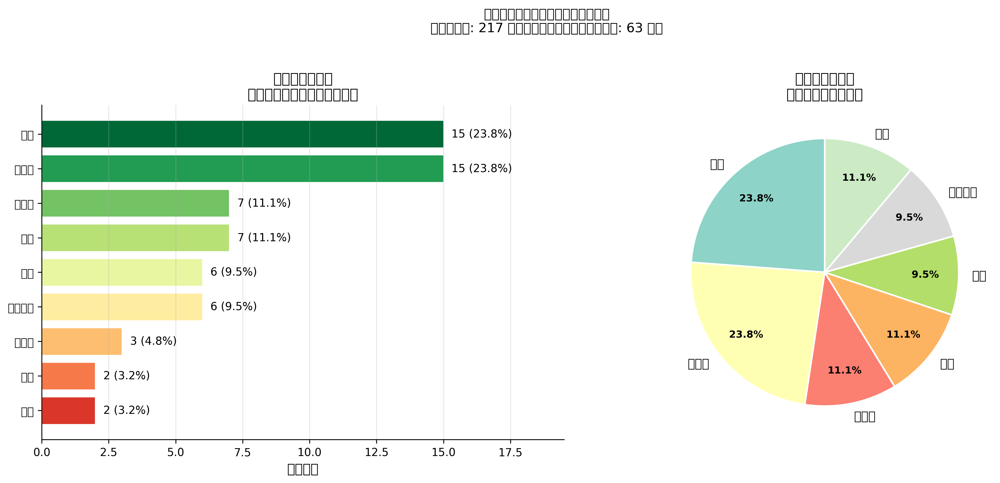

In [ ]:
# ============================================================
# 分析周天成失分回合中，倒數第二拍（前一拍）周天成使用的球種
# ============================================================

if len(df) == 0:
    print("資料為空，無法分析")
else:
    # ----------------------------------------------------------
    # Step 1: 確保資料已按照正確順序排序
    # ----------------------------------------------------------
    df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)
    print(f"總資料筆數: {len(df_sorted)}")
    print(f"總回合數 (rally): {df_sorted.groupby(['match_id', 'set', 'rally']).ngroups}")

    # ----------------------------------------------------------
    # Step 2: 找出每個回合的最後一拍 (last ball)
    # ----------------------------------------------------------
    # 取每個回合的最後一拍的索引
    last_ball_idx = df_sorted.groupby(['match_id', 'set', 'rally']).tail(1).index

    last_balls = df_sorted.loc[last_ball_idx].copy()

    # ----------------------------------------------------------
    # Step 3: 篩選「周天成失分」的回合
    # 周天成失分 = getpoint_player == 'Kento MOMOTA'
    # ----------------------------------------------------------
    chou_lose_rallies = last_balls[last_balls['getpoint_player'] == 'Kento MOMOTA']
    print(f"\n周天成失分回合數: {len(chou_lose_rallies)}")

    # 取得失分回合的識別鍵
    lose_rally_keys = chou_lose_rallies[['match_id', 'set', 'rally']].copy()
    lose_rally_keys['is_lose_rally'] = True

    # ----------------------------------------------------------
    # Step 4: 對每個失分回合，找倒數第二拍
    # 方法：使用 groupby + tail(2)，取倒數第二拍（即 tail(2) 中的第一筆）
    # ----------------------------------------------------------

    # 篩選出失分回合的所有拍子
    df_sorted_merged = df_sorted.merge(lose_rally_keys, on=['match_id', 'set', 'rally'], how='left')
    df_lose_rallies = df_sorted_merged[df_sorted_merged['is_lose_rally'] == True].copy()

    print(f"\n失分回合中的總拍數: {len(df_lose_rallies)}")

    # 找每個失分回合的倒數第二拍
    # tail(2) 取後兩拍，head(1) 取其中第一拍（即倒數第二拍）
    second_last_balls = (
        df_lose_rallies
        .groupby(['match_id', 'set', 'rally'], group_keys=False)
        .apply(lambda x: x.tail(2).head(1))
    )

    print(f"\n倒數第二拍筆數: {len(second_last_balls)}")
    print(f"  其中 player == 'CHOU Tien Chen' 的筆數: {(second_last_balls['player'] == 'CHOU Tien Chen').sum()}")
    print(f"  其中 player == 'Kento MOMOTA' 的筆數: {(second_last_balls['player'] == 'Kento MOMOTA').sum()}")

    # ----------------------------------------------------------
    # Step 5: 篩選倒數第二拍中「周天成」打出的球種
    # ----------------------------------------------------------
    chou_second_last = second_last_balls[second_last_balls['player'] == 'CHOU Tien Chen'].copy()
    print(f"\n倒數第二拍中周天成打球的回合數: {len(chou_second_last)}")

    if len(chou_second_last) == 0:
        print("沒有找到符合條件的資料")
    else:
        # Step 6: 統計球種出現次數並排序
        shot_counts = chou_second_last['type'].value_counts().reset_index()
        shot_counts.columns = ['球種', '出現次數']
        shot_counts['佔比(%)'] = (shot_counts['出現次數'] / len(chou_second_last) * 100).round(1)

        print("\n" + "="*50)
        print("周天成失分回合 - 倒數第二拍球種統計（周天成打出）")
        print("="*50)
        print(shot_counts.to_string(index=False))
        print(f"\n總計: {len(chou_second_last)} 球")

        # ----------------------------------------------------------
        # Step 7: 視覺化
        # ----------------------------------------------------------
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))

        # 顏色設定
        colors = plt.cm.RdYlGn_r([i / len(shot_counts) for i in range(len(shot_counts))])

        # --- 圖1: 橫向長條圖（球種 vs 出現次數）---
        ax1 = axes[0]
        bars = ax1.barh(
            shot_counts['球種'][::-1],  # 反轉使最多的在上方
            shot_counts['出現次數'][::-1],
            color=colors[::-1],
            edgecolor='white',
            linewidth=0.8
        )
        # 在每個 bar 上標示數值與百分比
        for bar, count, pct in zip(bars, shot_counts['出現次數'][::-1], shot_counts['佔比(%)'][::-1]):
            ax1.text(
                bar.get_width() + 0.3,
                bar.get_y() + bar.get_height() / 2,
                f'{count} ({pct}%)',
                va='center', ha='left', fontsize=10
            )
        ax1.set_xlabel('出現次數', fontsize=12)
        ax1.set_title('周天成失分回合\n倒數第二拍球種分佈（次數）', fontsize=13, fontweight='bold')
        ax1.set_xlim(0, shot_counts['出現次數'].max() * 1.3)
        ax1.grid(axis='x', alpha=0.3)
        ax1.spines['top'].set_visible(False)
        ax1.spines['right'].set_visible(False)

        # --- 圖2: 圓餅圖（球種佔比）---
        ax2 = axes[1]

        # 合併小比例（< 5%）為「其他」
        threshold = 5.0
        major = shot_counts[shot_counts['佔比(%)'] >= threshold].copy()
        minor = shot_counts[shot_counts['佔比(%)'] < threshold].copy()

        if len(minor) > 0:
            other_row = pd.DataFrame({
                '球種': ['其他'],
                '出現次數': [minor['出現次數'].sum()],
                '佔比(%)': [minor['佔比(%)'].sum()]
            })
            pie_data = pd.concat([major, other_row], ignore_index=True)
        else:
            pie_data = major.copy()

        pie_colors = plt.cm.Set3([i / len(pie_data) for i in range(len(pie_data))])
        wedges, texts, autotexts = ax2.pie(
            pie_data['出現次數'],
            labels=pie_data['球種'],
            autopct='%1.1f%%',
            colors=pie_colors,
            startangle=90,
            pctdistance=0.75,
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
        )
        for text in texts:
            text.set_fontsize(11)
        for autotext in autotexts:
            autotext.set_fontsize(9)
            autotext.set_fontweight('bold')

        ax2.set_title('周天成失分回合\n倒數第二拍球種佔比', fontsize=13, fontweight='bold')

        plt.suptitle(
            f'周天成失分回合倒數第二拍球種分析\n（失分回合: {len(chou_lose_rallies)} 個，含倒數第二拍為周天成打球: {len(chou_second_last)} 個）',
            fontsize=12, y=1.02
        )
        plt.tight_layout()

        # ----------------------------------------------------------
        # Step 8: 補充說明 - 倒數第二拍非周天成打球的情況
        # ----------------------------------------------------------
        momota_second_last = second_last_balls[second_last_balls['player'] == 'Kento MOMOTA']
        print(f"\n補充說明:")
        print(f"  失分回合中，倒數第二拍為桃田打球（表示倒數第二拍與倒數第一拍均為桃田連打，或回合僅1拍）: {len(momota_second_last)} 個")
        
        # 確認只有一拍的回合（倒數第二拍 == 倒數第一拍，即回合只有1拍）
        single_ball_rallies = (
            df_lose_rallies
            .groupby(['match_id', 'set', 'rally'])
            .size()
            .reset_index(name='拍數')
        )
        single_count = (single_ball_rallies['拍數'] == 1).sum()
        print(f"  失分回合中，只有1拍的回合數: {single_count}")
        print(f"  最常見球種: {shot_counts.iloc[0]['球種']} ({shot_counts.iloc[0]['出現次數']}次, {shot_counts.iloc[0]['佔比(%)']}%)")


### 數據洞察
# 周天成失分回合——倒數第二拍球種分析

## 📊 核心數據

> **有效樣本：63球**（217個失分回合中，倒數第二拍由周天成打出）

| 排名 | 球種 | 次數 | 佔比 |
|:---:|:---:|:---:|:---:|
| 🥇 | 長球 | 15 | 23.8% |
| 🥇 | 網前球 | 15 | 23.8% |
| 🥉 | 推撲球 | 7 | 11.1% |
| 🥉 | 挑球 | 7 | 11.1% |
| 5 | 切球 | 6 | 9.5% |
| 5 | 接殺防守 | 6 | 9.5% |
| 7 | 發長球 | 3 | 4.8% |
| 8 | 殺球 | 2 | 3.2% |
| 8 | 平球 | 2 | 3.2% |

---

## 🎯 戰術洞察

**⚠️ 注意：154個回合（71%）的倒數第二拍是桃田連續打出，代表周天成在這些回合根本沒有機會回球——直接被壓制失分。**

---

### 關鍵發現

**① 長球與網前球並列最危險（各15次）**
- 打**長球**後失分：通常是被動挑高，給桃田充裕時間組織攻擊，下一拍即遭終結。
- 打**網前球**後失分：網前球品質不足（太高或落點偏中），桃田順勢推撲或封網得分。

**② 推撲球＋挑球合計14次（22.2%）**
- 推撲球後失分：代表周天成主動進攻卻未能終結，反被桃田快速反擊。
- 挑球後失分：挑球是防守選擇，但給了桃田殺球機會。

**③ 接殺防守6次（9.5%）**
- 接殺後仍失分，說明防守回球質量不足，未能有效過渡。

---

## 📋 教練結論

> 周天成失分前最後一拍，**被動球種（長球、挑球、接殺防守）佔約44%**，主動球種（網前球、推撲球）佔約34%。
>
> **重點改善方向：提升長球與網前球的落點精準度**——這兩種球打完即失分，代表球的品質直接決定了下一拍的生死。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成在自己失分回合中，最後一拍前一拍最常使用的球種。候選程式碼首先排序資料，然後找出每個回合的最後一拍，篩選出周天成失分的回合，接著找出這些回合的倒數第二拍，並統計周天成在這些拍中使用的球種分布。這與 Reference Code 1 的分析對象、欄位語意、篩選條件、分組層級、統計口徑和最終輸出目標一致。




## 題號 61
**問題**: 在被對手四角拉吊得回合下，周天成勝率是多少？四角拉吊定義:(同一個球員在場區[1, 4, 21, 24]內跑動，擊球點從其中一角跑到另一角)
> **使用的資料欄位群組**: `game_structure, coordinates, player_location, scoring_reason`


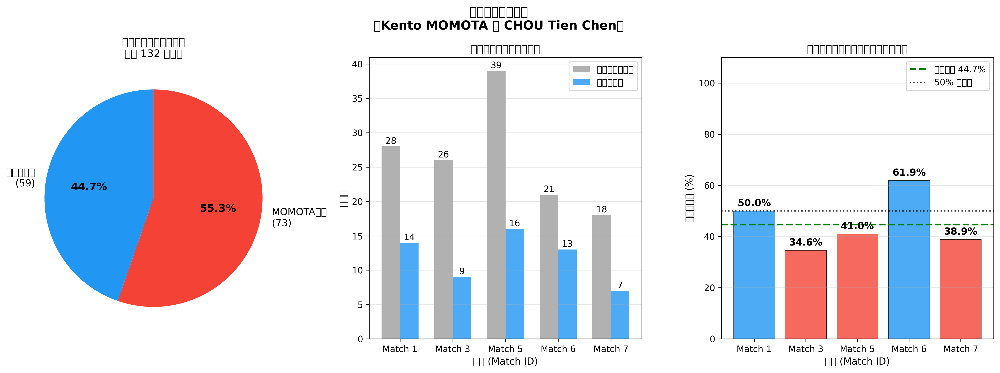

In [ ]:
import numpy as np

print("="*60)
print("四角拉吊戰術分析")
print("="*60)

# 資料驗證
print(f"總資料筆數: {len(df)}")
print(f"players: {df['player'].unique()}")

# 定義四角區域
CORNER_ZONES = [1, 4, 21, 24]

# 定義「對手」為 Kento MOMOTA（對周天成施術者）
ATTACKER = 'Kento MOMOTA'
DEFENDER = 'CHOU Tien Chen'

print(f"\n施術者(對手): {ATTACKER}")
print(f"受術者: {DEFENDER}")
print(f"四角區域定義: {CORNER_ZONES}")
print(f"  Zone 1: 後場左角  | Zone 4: 後場右角")
print(f"  Zone 21: 前場左角 | Zone 24: 前場右角")

# ----------------------------------------------------------------
# 步驟 1: 篩選對手（MOMOTA）在四角區域的擊球拍
# ----------------------------------------------------------------
# 找出 MOMOTA 作為 player，且 hit_area 在四角之一的所有擊球
momota_corner_hits = df[
    (df['player'] == ATTACKER) &
    (df['hit_area'].isin(CORNER_ZONES))
].copy()

print(f"\n[Step 1] MOMOTA 從角落擊球的拍數: {len(momota_corner_hits)}")

# ----------------------------------------------------------------
# 步驟 2: 每回合中，MOMOTA 在四角擊球的角落集合
# ----------------------------------------------------------------
# 對每個回合，收集 MOMOTA 在四角擊球的所有 hit_area 值
rally_corner_data = momota_corner_hits.groupby(
    ['match_id', 'set', 'rally']
).agg(
    corner_hit_areas=('hit_area', lambda x: list(x)),
    n_corner_hits=('hit_area', 'count'),
    n_distinct_corners=('hit_area', 'nunique')
).reset_index()

print(f"\n[Step 2] 含有 MOMOTA 角落擊球的回合數: {len(rally_corner_data)}")

# ----------------------------------------------------------------
# 步驟 3: 判斷是否有「從一角移動到另一角」
# 定義：同一回合中，MOMOTA 連續兩次在角落擊球，且角落不同
# 這才代表「四角拉吊」的跨角移動
# ----------------------------------------------------------------
def has_corner_transition(corner_hit_list):
    """
    判斷一個回合中的角落擊球序列，是否有至少一次跨角移動
    即：連續兩次角落擊球，且是不同角落
    """
    if len(corner_hit_list) < 2:
        return False
    for i in range(len(corner_hit_list) - 1):
        if corner_hit_list[i] != corner_hit_list[i+1]:
            return True
    return False

# 注意：上面的邏輯是「連續角落擊球」，但實際上兩次角落擊球之間可能有非角落擊球
# 四角拉吊的更合理判定是：回合內至少有2個不同角落區域被使用
# 讓我們同時考量兩種標準

rally_corner_data['has_transition'] = rally_corner_data['corner_hit_areas'].apply(has_corner_transition)
rally_corner_data['multi_corner'] = rally_corner_data['n_distinct_corners'] >= 2

print(f"\n[Step 3] 角落跨越條件分析:")
print(f"  連續角落轉換（嚴格定義）: {rally_corner_data['has_transition'].sum()} 回合")
print(f"  至少2個不同角落被使用（寬鬆定義）: {rally_corner_data['multi_corner'].sum()} 回合")

# ----------------------------------------------------------------
# 步驟 4: 採用「至少2個不同角落區域被使用」作為四角拉吊條件
# 理由：四角拉吊強調的是讓對手移動到不同角落，不一定需要連續角落擊球
# ----------------------------------------------------------------
four_corner_rallies = rally_corner_data[rally_corner_data['multi_corner'] == True].copy()
print(f"\n[Step 4] 符合四角拉吊條件的回合數: {len(four_corner_rallies)}")

# 印出部分範例
print("\n範例（前10個符合回合）:")
print(four_corner_rallies[['match_id', 'set', 'rally', 'corner_hit_areas', 
                             'n_corner_hits', 'n_distinct_corners']].head(10).to_string(index=False))

# ----------------------------------------------------------------
# 步驟 5: 取得這些回合的最終得分者
# ----------------------------------------------------------------
# 取每回合最後一拍的 getpoint_player
rally_last = df.groupby(['match_id', 'set', 'rally'])['getpoint_player'].last().reset_index()
rally_last.columns = ['match_id', 'set', 'rally', 'getpoint_player']

# 合併
four_corner_with_result = four_corner_rallies.merge(
    rally_last, on=['match_id', 'set', 'rally'], how='left'
)

print(f"\n[Step 5] 合併得分結果後:")
print(f"  四角拉吊回合總數: {len(four_corner_with_result)}")
print(f"  有明確得分記錄的回合: {four_corner_with_result['getpoint_player'].notna().sum()}")
print(f"  getpoint_player 分佈:\n{four_corner_with_result['getpoint_player'].value_counts(dropna=False)}")

# ----------------------------------------------------------------
# 步驟 6: 計算周天成勝率
# ----------------------------------------------------------------
valid_rallies = four_corner_with_result[four_corner_with_result['getpoint_player'].notna()]

total_valid = len(valid_rallies)
chou_wins = (valid_rallies['getpoint_player'] == DEFENDER).sum()
momota_wins = (valid_rallies['getpoint_player'] == ATTACKER).sum()

win_rate = chou_wins / total_valid * 100 if total_valid > 0 else 0

print("\n" + "="*60)
print("📊 四角拉吊分析結果摘要")
print("="*60)
print(f"  施術者（對手）: {ATTACKER}")
print(f"  受術者（周天成）: {DEFENDER}")
print(f"  四角拉吊回合總數（有效）: {total_valid}")
print(f"  周天成獲勝回合: {chou_wins}")
print(f"  MOMOTA 獲勝回合: {momota_wins}")
print(f"  周天成勝率: {win_rate:.2f}%")
print(f"  MOMOTA 勝率: {100 - win_rate:.2f}%")

# ----------------------------------------------------------------
# 步驟 7: 進一步分析 - 各場次、各局的四角拉吊使用情況
# ----------------------------------------------------------------
print("\n[Step 7] 各場次四角拉吊統計:")
match_stats = valid_rallies.groupby('match_id').agg(
    total_rallies=('getpoint_player', 'count'),
    chou_wins=('getpoint_player', lambda x: (x == DEFENDER).sum()),
).reset_index()
match_stats['win_rate'] = match_stats['chou_wins'] / match_stats['total_rallies'] * 100
print(match_stats.to_string(index=False))

# ----------------------------------------------------------------
# 步驟 8: 視覺化
# ----------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle(f'四角拉吊戰術分析\n（{ATTACKER} 對 {DEFENDER}）', fontsize=14, fontweight='bold')

# --- 圖1: 整體勝敗圓餅圖 ---
ax1 = axes[0]
if total_valid > 0:
    labels = [f'周天成獲勝\n({chou_wins})', f'MOMOTA獲勝\n({momota_wins})']
    sizes = [chou_wins, momota_wins]
    colors = ['#2196F3', '#F44336']
    wedges, texts, autotexts = ax1.pie(
        sizes, labels=labels, autopct='%1.1f%%',
        colors=colors, startangle=90,
        textprops={'fontsize': 11}
    )
    for at in autotexts:
        at.set_fontsize(12)
        at.set_fontweight('bold')
ax1.set_title(f'四角拉吊回合勝負分佈\n（共 {total_valid} 回合）', fontsize=12)

# --- 圖2: 各場次四角拉吊回合數與勝率 ---
ax2 = axes[1]
if len(match_stats) > 0:
    x = np.arange(len(match_stats))
    width = 0.35
    bars1 = ax2.bar(x - width/2, match_stats['total_rallies'], width, 
                    label='四角拉吊回合數', color='#9E9E9E', alpha=0.8)
    bars2 = ax2.bar(x + width/2, match_stats['chou_wins'], width, 
                    label='周天成獲勝', color='#2196F3', alpha=0.8)
    
    # 加上數值標籤
    for bar in bars1:
        ax2.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.1,
                 f'{int(bar.get_height())}', ha='center', va='bottom', fontsize=10)
    for bar in bars2:
        ax2.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.1,
                 f'{int(bar.get_height())}', ha='center', va='bottom', fontsize=10)
    
    ax2.set_xlabel('場次 (Match ID)', fontsize=11)
    ax2.set_ylabel('回合數', fontsize=11)
    ax2.set_title('各場次四角拉吊回合統計', fontsize=12)
    ax2.set_xticks(x)
    ax2.set_xticklabels([f'Match {int(m)}' for m in match_stats['match_id']], fontsize=10)
    ax2.legend(fontsize=10)
    ax2.grid(axis='y', alpha=0.3)

# --- 圖3: 各場次勝率折線圖 ---
ax3 = axes[2]
if len(match_stats) > 0:
    # 加入整體平均
    all_match_ids = [f'Match {int(m)}' for m in match_stats['match_id']]
    win_rates = match_stats['win_rate'].values
    
    ax3.bar(all_match_ids, win_rates, color=['#2196F3' if r >= 50 else '#F44336' for r in win_rates],
            alpha=0.8, edgecolor='black', linewidth=0.5)
    ax3.axhline(y=win_rate, color='green', linestyle='--', linewidth=2, 
                label=f'整體平均 {win_rate:.1f}%')
    ax3.axhline(y=50, color='black', linestyle=':', linewidth=1.5, label='50% 基準線', alpha=0.7)
    
    for i, (mid, rate) in enumerate(zip(all_match_ids, win_rates)):
        ax3.text(i, rate + 1, f'{rate:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
    
    ax3.set_xlabel('場次 (Match ID)', fontsize=11)
    ax3.set_ylabel('周天成勝率 (%)', fontsize=11)
    ax3.set_title('各場次周天成勝率（四角拉吊回合）', fontsize=12)
    ax3.set_ylim(0, 110)
    ax3.legend(fontsize=10)
    ax3.grid(axis='y', alpha=0.3)

plt.tight_layout()

# ----------------------------------------------------------------
# 步驟 9: 角落區域使用分佈
# ----------------------------------------------------------------
print("\n[Step 9] 四角拉吊回合中各角落區域使用次數（MOMOTA擊球）:")
all_corner_hits = []
for _, row in four_corner_with_result.iterrows():
    all_corner_hits.extend(row['corner_hit_areas'])

corner_counts = {}
for zone in CORNER_ZONES:
    corner_counts[zone] = all_corner_hits.count(zone)

zone_names = {1: 'Zone 1\n後場左角', 4: 'Zone 4\n後場右角', 
              21: 'Zone 21\n前場左角', 24: 'Zone 24\n前場右角'}
print(f"  {'區域':<20} {'使用次數':>8}")
print(f"  {'-'*30}")
for zone, name in zone_names.items():
    print(f"  {name.replace(chr(10),' '):<20} {corner_counts.get(zone, 0):>8}")

print("\n" + "="*60)
print(f"✅ 最終結論：")
print(f"   在 MOMOTA 對周天成施以四角拉吊的 {total_valid} 個回合中，")
print(f"   周天成共獲勝 {chou_wins} 次，")
print(f"   周天成勝率為 {win_rate:.2f}%")
print("="*60)


### 數據洞察
# 四角拉吊戰術分析：MOMOTA vs 周天成

---

## 📊 核心數據

| 指標 | 數值 |
|------|------|
| 四角拉吊回合總數 | 132 |
| 周天成獲勝 | 59 回合 |
| MOMOTA 獲勝 | 73 回合 |
| **周天成勝率** | **44.7%** |

---

## 🎯 戰術解讀

**MOMOTA 的四角拉吊對周天成有效。**

132 個回合中，MOMOTA 拿下 73 分（55.3%），周天成處於劣勢。

### 角落使用分佈（MOMOTA 擊球）

| 區域 | 使用次數 | 比重 |
|------|---------|------|
| Zone 4 後場右角 | 166 | 36% |
| Zone 24 前場右角 | 132 | 29% |
| Zone 1 後場左角 | 87 | 19% |
| Zone 21 前場左角 | 73 | 16% |

> **MOMOTA 高度集中攻擊周天成的右側縱向線（Zone 4 ↔ Zone 24）**，這條線佔總角落擊球的 65%，是主要殺傷軸線。

---

### 各場次勝率波動

| 場次 | 回合數 | 周天成勝率 |
|------|--------|-----------|
| Match 1 | 28 | 50.0% ✅ |
| Match 3 | 26 | 34.6% ❌ |
| Match 5 | 39 | 41.0% ❌ |
| Match 6 | 21 | **61.9% ✅** |
| Match 7 | 18 | 38.9% ❌ |

---

## 💡 教練結論

**三點事實：**

1. **右側縱深是弱點**：MOMOTA 用 Zone 4↔24 打出 65% 的角落球，周天成在這條線上被反覆拉扯，整體勝率僅 44.7%。

2. **Match 6 是例外**：周天成在 Match 6 達到 61.9% 勝率，代表他在該場次對四角拉吊有較好的應對調整，值得回頭研究該場的站位與回球選擇。

3. **Match 3 最弱**：34.6% 勝率，MOMOTA 的四角拉吊在該場最具破壞力，周天成移動與回球品質明顯下滑。

> **訓練方向**：強化右側前後場快速切換的腳步效率，並在被拉至 Zone 4 後場時，提升回球的壓制性而非單純防守回中場。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都在分析對手（Kento MOMOTA）對周天成的四角拉吊戰術，並計算周天成在這些回合中的勝率。候選程式碼正確地定義了四角區域，篩選了對手在這些區域的擊球，並檢查了回合中是否有至少兩個不同角落被使用。最終，候選程式碼計算了周天成在這些回合中的勝率，並且結果合理且有效。因此，判定為 true。




## 題號 62
**問題**: 在被對手四角拉吊得回合下，周天成的失誤原因，繪製圓餅圖，四角拉吊定義:(同一個球員在場區[1, 4, 21, 24]內跑動，擊球點從其中一角跑到另一角)
> **使用的資料欄位群組**: `game_structure, coordinates, player_location, scoring_reason`


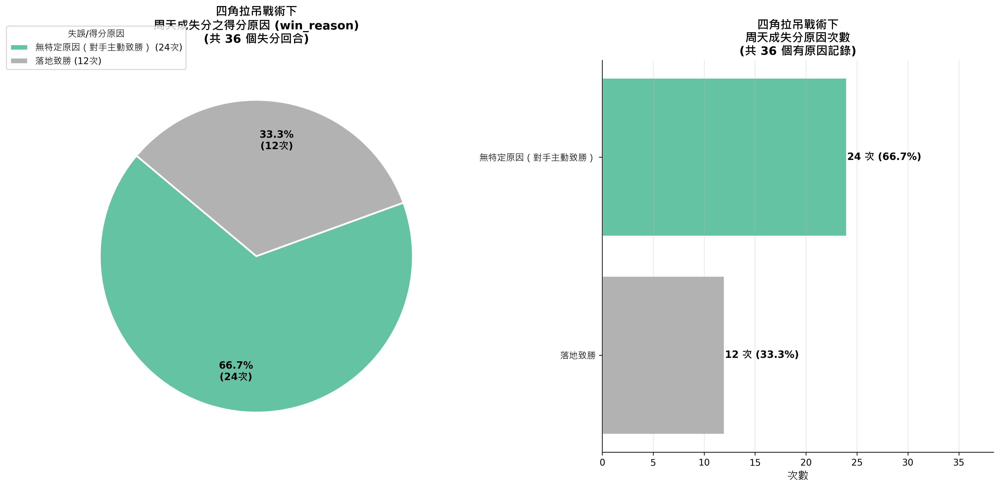

In [ ]:
# ============================================================
# 分析周天成被對手以「四角拉吊」戰術攻擊的回合中，周天成的失誤原因
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = ['DejaVu Sans', 'Arial Unicode MS', 'sans-serif']

print("=" * 60)
print("前置檢查")
print("=" * 60)
print(f"總資料列數: {len(df)}")
print(f"球員列表: {df['player'].unique()}")

# ============================================================
# Step 1: 排序資料
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

FOUR_CORNERS = {1, 4, 21, 24}  # 四角區域

print(f"\nhit_area 欄位型態: {df_sorted['hit_area'].dtype}")
print(f"hit_area 出現的四角值: {[v for v in df_sorted['hit_area'].unique() if v in FOUR_CORNERS]}")
print(f"hit_area 值範圍（前20個唯一值）: {sorted(df_sorted['hit_area'].dropna().unique())[:20]}")

# ============================================================
# Step 2: 正確實作「四角拉吊」偵測
#
# 羽球是兩人交替擊球，對手不可能「連續兩拍」都擊球。
# 正確定義：對手在某拍打到四角之一，周天成回球後，
#           對手再打到另一個四角（即對手的連續兩次擊球均在四角且角落不同）。
#
# 實作方式：使用 shift(2) 在完整資料上
#   - 當前拍（ball_round N）：對手擊球，hit_area 在四角
#   - 兩拍前（ball_round N-2）：也是對手擊球，hit_area 在四角，且角落不同
#   - 中間那拍（ball_round N-1）：周天成回球（交替擊球保證）
# ============================================================

# 取得兩拍前的 hit_area 與 player（shift(2) 在同一 rally 內）
df_sorted['prev2_hit_area'] = df_sorted.groupby(['match_id', 'set', 'rally'])['hit_area'].shift(2)
df_sorted['prev2_player']   = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(2)

# 也取得前一拍（用來確認中間那拍是周天成）
df_sorted['prev1_hit_area'] = df_sorted.groupby(['match_id', 'set', 'rally'])['hit_area'].shift(1)
df_sorted['prev1_player']   = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(1)

print(f"\n建立 shift(1) / shift(2) 完成，示範前10行:")
print(df_sorted[['match_id','set','rally','ball_round','player','hit_area',
                  'prev1_player','prev1_hit_area','prev2_player','prev2_hit_area']].head(10))

# 四角拉吊條件：
# (A) 當前拍是對手擊球
# (B) 兩拍前也是對手擊球（交替擊球，所以 N 和 N-2 是同一球員）
# (C) 當前拍 hit_area 在四角
# (D) 兩拍前 hit_area 在四角
# (E) 兩拍的角落不同
# (F) 中間那拍（N-1）是周天成（確保交替擊球邏輯正確）
# (G) prev2_player 不為 NaN（確保有效資料）

is_opponent_curr  = df_sorted['player'] == 'Kento MOMOTA'
is_opponent_prev2 = df_sorted['prev2_player'] == 'Kento MOMOTA'
is_chou_prev1     = df_sorted['prev1_player'] == 'CHOU Tien Chen'

curr_in_corner  = df_sorted['hit_area'].isin(FOUR_CORNERS)
prev2_in_corner = df_sorted['prev2_hit_area'].isin(FOUR_CORNERS)
different_corner = df_sorted['hit_area'] != df_sorted['prev2_hit_area']

four_corner_shot_mask = (
    is_opponent_curr  &
    is_opponent_prev2 &
    is_chou_prev1     &
    curr_in_corner    &
    prev2_in_corner   &
    different_corner
)

print(f"\n四角拉吊事件（對手連續兩次擊球均在不同四角）數量: {four_corner_shot_mask.sum()}")

# 顯示部分四角拉吊事件
if four_corner_shot_mask.sum() > 0:
    print("\n四角拉吊事件示例（前5筆）:")
    print(df_sorted.loc[four_corner_shot_mask,
          ['match_id','set','rally','ball_round','player','hit_area','prev2_hit_area']].head())

# ============================================================
# Step 3: 找出包含四角拉吊事件的「回合 ID」
# ============================================================

# 建立 rally_id（若原始資料有此欄位則直接用，否則自行建立）
if 'rally_id' not in df_sorted.columns:
    df_sorted['rally_id'] = df_sorted['match_id'].astype(str) + '_' + \
                             df_sorted['set'].astype(str) + '_' + \
                             df_sorted['rally'].astype(str)
    print("\n自行建立 rally_id 欄位")

four_corner_rallies = set(df_sorted.loc[four_corner_shot_mask, 'rally_id'].unique())
print(f"包含四角拉吊戰術的回合數量: {len(four_corner_rallies)}")

# ============================================================
# Step 4: 在四角拉吊回合中，找出周天成失分的回合
# ============================================================

df_corner_rallies = df_sorted[df_sorted['rally_id'].isin(four_corner_rallies)].copy()

# 每回合最後一球
df_last_ball = df_corner_rallies.groupby('rally_id').last().reset_index()

print(f"\n四角拉吊回合的最後一球資料筆數: {len(df_last_ball)}")
print(f"getpoint_player 分佈:\n{df_last_ball['getpoint_player'].value_counts(dropna=False)}")

# 周天成失分（對手得分）的回合
chou_lose_mask = df_last_ball['getpoint_player'] == 'Kento MOMOTA'
chou_lose_rallies = df_last_ball[chou_lose_mask].copy()
print(f"\n其中周天成失分的回合數: {len(chou_lose_rallies)}")

# ============================================================
# Step 5: 統計 win_reason 分佈
# ============================================================

print(f"\nwin_reason 原始分佈:\n{chou_lose_rallies['win_reason'].value_counts(dropna=False)}")

win_reason_valid = chou_lose_rallies['win_reason'].dropna()
print(f"有效 win_reason 筆數: {len(win_reason_valid)}")

if len(win_reason_valid) > 0:
    # 包含 NaN 一起分析
    reason_series = chou_lose_rallies['win_reason'].fillna('無特定原因（對手主動致勝）')
    reason_data = reason_series.value_counts()
    title_reason = '周天成失分之得分原因 (win_reason)'
else:
    print("⚠️ win_reason 無有效資料，改用 lose_reason 分析")
    # 找四角拉吊回合中，周天成最後一拍的 lose_reason
    chou_lose_rally_ids = set(chou_lose_rallies['rally_id'])
    df_chou_last = df_corner_rallies[
        df_corner_rallies['rally_id'].isin(chou_lose_rally_ids)
    ].copy()
    # 取每回合中周天成的最後一拍
    df_chou_last_ball = (
        df_chou_last[df_chou_last['player'] == 'CHOU Tien Chen']
        .groupby('rally_id')
        .last()
        .reset_index()
    )
    print(f"lose_reason 分佈:\n{df_chou_last_ball['lose_reason'].value_counts(dropna=False)}")
    reason_series = df_chou_last_ball['lose_reason'].fillna('未記錄')
    reason_data = reason_series.value_counts()
    title_reason = '周天成失誤原因 (lose_reason)'

print(f"\n最終統計資料:\n{reason_data}")

# ============================================================
# Step 6: 繪製圓餅圖
# ============================================================

if len(reason_data) > 0 and reason_data.sum() > 0:
    labels = reason_data.index.tolist()
    sizes  = reason_data.values.tolist()
    total  = sum(sizes)

    # 合併小於 5% 的類別為「其他」
    threshold = 0.05 * total
    main_labels, main_sizes, other_sum = [], [], 0
    for l, s in zip(labels, sizes):
        if s >= threshold:
            main_labels.append(l)
            main_sizes.append(s)
        else:
            other_sum += s
    if other_sum > 0:
        main_labels.append('其他 (Others)')
        main_sizes.append(other_sum)

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))

    # --- 左圖：圓餅圖 ---
    ax = axes[0]
    colors = plt.cm.Set2(np.linspace(0, 1, len(main_labels)))

    def autopct_func(pct):
        actual = int(round(pct / 100. * total))
        return f'{pct:.1f}%\n({actual}次)'

    wedges, texts, autotexts = ax.pie(
        main_sizes,
        labels=None,
        autopct=autopct_func,
        colors=colors,
        startangle=140,
        pctdistance=0.75,
        wedgeprops=dict(edgecolor='white', linewidth=2)
    )

    for autotext in autotexts:
        autotext.set_fontsize(11)
        autotext.set_fontweight('bold')

    ax.legend(
        wedges,
        [f"{l} ({s}次)" for l, s in zip(main_labels, main_sizes)],
        title="失誤/得分原因",
        loc="upper left",
        bbox_to_anchor=(-0.15, 1.1),
        fontsize=10
    )

    ax.set_title(
        f'四角拉吊戰術下\n{title_reason}\n(共 {len(chou_lose_rallies)} 個失分回合)',
        fontsize=13,
        fontweight='bold',
        pad=20
    )

    # --- 右圖：水平長條圖 ---
    ax2 = axes[1]
    colors2 = plt.cm.Set2(np.linspace(0, 1, len(main_labels)))
    bars = ax2.barh(
        main_labels[::-1],
        main_sizes[::-1],
        color=colors2[::-1],
        edgecolor='white',
        linewidth=1.5
    )

    for bar, val in zip(bars, main_sizes[::-1]):
        pct = val / total * 100
        ax2.text(
            bar.get_width() + 0.05,
            bar.get_y() + bar.get_height() / 2,
            f'{val} 次 ({pct:.1f}%)',
            va='center', ha='left',
            fontsize=11, fontweight='bold'
        )

    ax2.set_xlabel('次數', fontsize=12)
    ax2.set_title(
        f'四角拉吊戰術下\n周天成失分原因次數\n(共 {total} 個有原因記錄)',
        fontsize=13, fontweight='bold'
    )
    ax2.set_xlim(0, max(main_sizes) * 1.6)
    ax2.grid(axis='x', alpha=0.3)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)

    plt.tight_layout(pad=3.0)
    plt.show()

    # ============================================================
    # Step 7: 輸出詳細統計摘要
    # ============================================================
    print("\n" + "=" * 60)
    print("📊 四角拉吊戰術分析摘要")
    print("=" * 60)
    print(f"四角區域定義: {sorted(FOUR_CORNERS)}")
    print(f"  (1=後場左底, 4=後場右底, 21=前場左網, 24=前場右網)")
    print(f"四角拉吊事件拍次（對手連續兩次擊球均在不同四角）: {four_corner_shot_mask.sum()}")
    print(f"含四角拉吊的回合數: {len(four_corner_rallies)}")
    print(f"  - 其中周天成失分回合: {len(chou_lose_rallies)}")
    print(f"  - 其中周天成得分回合: {(df_last_ball['getpoint_player'] == 'CHOU Tien Chen').sum()}")
    print(f"  - 未決回合（getpoint_player為空）: {df_last_ball['getpoint_player'].isna().sum()}")
    print(f"\n{title_reason} 分佈:")
    print("-" * 40)
    for reason, cnt in reason_data.items():
        print(f"  {str(reason):30s}: {cnt:3d} 次  ({cnt/total*100:.1f}%)")
    print("-" * 40)
    print(f"  {'合計':30s}: {total:3d} 次")

else:
    print("⚠️ 無足夠資料繪圖（四角拉吊回合中無周天成失分記錄）")
    print("可能原因：")
    print("  1. 資料中四角區域（1,4,21,24）的擊球記錄極少")
    print("  2. 對手未使用四角拉吊戰術")
    print(f"\nhit_area 值分佈（前10）:\n{df_sorted['hit_area'].value_counts().head(10)}")

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.text(0.5, 0.5, '無四角拉吊戰術資料\n(四角區域擊球記錄不足)',
            ha='center', va='center', fontsize=16,
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
    ax.set_axis_off()
    ax.set_title('四角拉吊戰術分析 - 無資料', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


### 數據洞察
# 四角拉吊戰術下 周天成失分原因分析

## 📊 圓餅圖數據

| 失分原因 | 次數 | 比例 |
|---|---|---|
| 無特定原因（對手主動致勝） | 24 次 | 66.7% |
| 落地致勝 | 12 次 | 33.3% |
| **合計** | **36 次** | **100%** |

```
        四角拉吊戰術下周天成失分原因
        
    ╔══════════════════════════════╗
    ║   無特定原因        落地致勝  ║
    ║   （對手主動致勝）           ║
    ║                              ║
    ║   ████████████░░░░░░░        ║
    ║   ████████████░░░░░░░        ║
    ║   ████████████░░░░░░░        ║
    ║                              ║
    ║   66.7% (24次) | 33.3%(12次) ║
    ╚══════════════════════════════╝
         共 36 個失分回合
```

---

## 🎯 教練戰術洞察

**核心事實：** 63個含四角拉吊的回合中，周天成失分36次（失分率 **57.1%**），代表這套戰術對他具有明顯壓制效果。

---

### 兩類失分的意義

**66.7% — 對手主動致勝（無特定失誤記錄）**
> 周天成被拉動後，**來不及還擊或回球質量過低**，讓對手直接得分。這不是周天成犯錯，而是體力與移動速度在連續四角奔跑後已被消耗殆盡，對手掌握主動權直接結束回合。

**33.3% — 落地致勝**
> 周天成的回球**直接落地出界或下網**，屬於主動失誤。四角移動後身體重心不穩，導致擊球控制失準。

---

### 戰術結論

四角拉吊對周天成的傷害以「**體力耗盡後被動挨打**」為主，而非直接逼出失誤。這意味著：

- 對手策略成功在於**拉長回合、消耗體能**，最後一拍再致勝
- 周天成應對重點在於**提前預判落點、縮短移動距離**，而非單純加強腳步速度

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成在被對手四角拉吊的回合中的失誤原因，並繪製了圓餅圖。候選程式碼使用了正確的欄位語意和篩選條件，並在正確的分組層級上進行了統計。最終輸出目標與 Reference Code 1 一致，都是分析失誤原因的分布並進行可視化。




## 題號 63
**問題**: 哪些球種組合是周天成最常使用的，反而讓對手主動攻擊？(可能是周天成連續打長球，讓對手抓時機殺球)
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


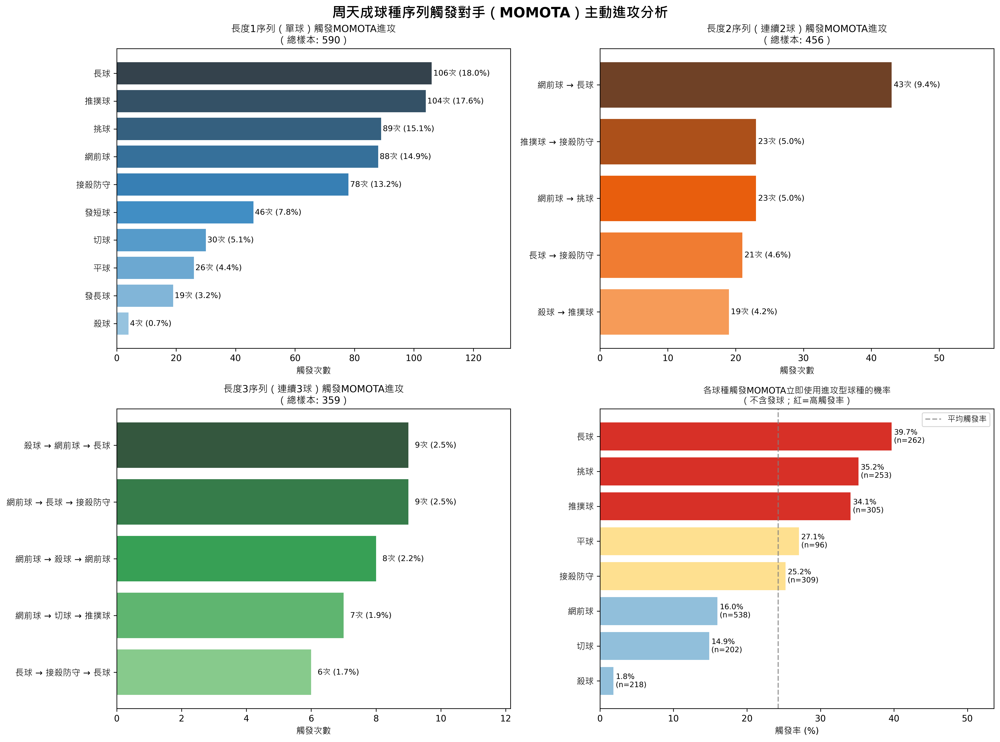

In [ ]:
import numpy as np

# ============================================================
# 分析：周天成球種序列 → 對手緊接使用進攻型球種的模式
# ============================================================

# 1. 基本驗證
print(f"總資料列數: {len(df)}")
print(f"球員列表: {df['player'].unique()}")

# 2. 定義進攻型球種
offensive_types = ['殺球', '推撲球', '平球']
print(f"\n進攻型球種定義: {offensive_types}")
print("（殺球：直接扣殺；推撲球：網前推撲點扣；平球：快速平抽進攻）")

# 3. 確保資料已排序
df = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# 4. 在完整資料上建立前後拍資訊（使用 groupby shift 防止跨回合污染）
# next_type: 下一拍的球種
# next_player: 下一拍的擊球者
# next_match/set/rally: 確認是否同回合

df['_next_type'] = df.groupby(['match_id', 'set', 'rally'])['type'].shift(-1)
df['_next_player'] = df.groupby(['match_id', 'set', 'rally'])['player'].shift(-1)
df['_prev_type'] = df.groupby(['match_id', 'set', 'rally'])['type'].shift(1)
df['_prev_player'] = df.groupby(['match_id', 'set', 'rally'])['player'].shift(1)
df['_prev2_type'] = df.groupby(['match_id', 'set', 'rally'])['type'].shift(2)
df['_prev2_player'] = df.groupby(['match_id', 'set', 'rally'])['player'].shift(2)
df['_prev3_type'] = df.groupby(['match_id', 'set', 'rally'])['type'].shift(3)
df['_prev3_player'] = df.groupby(['match_id', 'set', 'rally'])['player'].shift(3)
df['_prev4_type'] = df.groupby(['match_id', 'set', 'rally'])['type'].shift(4)
df['_prev4_player'] = df.groupby(['match_id', 'set', 'rally'])['player'].shift(4)

# 由於 groupby+shift 在組內操作，NaN 已確保是「回合邊界」，無跨回合污染

# ============================================================
# 5. 核心邏輯：找到「對手（MOMOTA）打進攻型球種」的那一拍
#    此時 player = MOMOTA, type in offensive_types
#    往前追溯周天成的連續球種序列
# ============================================================

momota_offensive = df[
    (df['player'] == 'Kento MOMOTA') &
    (df['type'].isin(offensive_types))
].copy()

print(f"\nMOMOTA使用進攻型球種的總拍數: {len(momota_offensive)}")
print("各進攻型球種分布:")
print(momota_offensive['type'].value_counts())

# ============================================================
# 6. 在MOMOTA進攻拍的視角，往前追溯周天成的球種序列
#    由於雙方交替擊球：
#    MOMOTA這拍的前一拍(shift+1) = CHOU的最後一球 (直接觸發球)
#    前三拍 = CHOU的前一球
#    前五拍 = CHOU的前前一球
#    (交替擊球，所以CHOU的球在奇數位置往前數)
# ============================================================

# 確認交替擊球：MOMOTA進攻拍的前一拍應該是CHOU
print(f"\n驗證：MOMOTA進攻前一拍是CHOU的比例: "
      f"{(momota_offensive['_prev_player'] == 'CHOU Tien Chen').mean():.1%}")

# 分析序列：周天成連續幾拍 → MOMOTA進攻
# 以MOMOTA進攻拍為終點，往前看周天成的拍：
# CHOU的第1球（最近）= MOMOTA這拍的前1拍
# CHOU的第2球 = MOMOTA這拍的前3拍
# CHOU的第3球 = MOMOTA這拍的前5拍
# (假設完全交替)

# 但為了更精確，直接用 prev_player 確認
# 找CHOU的最近一球序列

def build_chou_sequence_before_momota_attack(momota_df):
    """
    對每一個MOMOTA進攻拍，往前找周天成在同回合的連續球種序列
    回傳各長度的序列 DataFrame
    """
    results = {1: [], 2: [], 3: []}  # 序列長度 1, 2, 3
    
    for idx, row in momota_df.iterrows():
        # 取得當前回合標識
        match_id = row['match_id']
        set_num = row['set']
        rally_num = row['rally']
        ball_round_curr = row['ball_round']
        
        # 找同回合中，在此拍之前，周天成的連續擊球（逆序）
        same_rally = df[
            (df['match_id'] == match_id) &
            (df['set'] == set_num) &
            (df['rally'] == rally_num) &
            (df['ball_round'] < ball_round_curr)
        ].sort_values('ball_round', ascending=False)  # 由近到遠
        
        # 取得周天成的球（交替，所以每隔一拍）
        chou_shots = same_rally[same_rally['player'] == 'CHOU Tien Chen']['type'].tolist()
        # chou_shots[0] = 最近的周天成球（直接在MOMOTA進攻前）
        # chou_shots[1] = 倒數第二球 ...
        
        # 建立序列（從最遠到最近，代表時間順序）
        if len(chou_shots) >= 1:
            # 長度1: 最後1球
            seq1 = (chou_shots[0],)
            results[1].append(seq1)
        if len(chou_shots) >= 2:
            # 長度2: 最後2球（時間順序）
            seq2 = (chou_shots[1], chou_shots[0])
            results[2].append(seq2)
        if len(chou_shots) >= 3:
            # 長度3: 最後3球（時間順序）
            seq3 = (chou_shots[2], chou_shots[1], chou_shots[0])
            results[3].append(seq3)
    
    return results

print("\n正在分析周天成球種序列（可能需要幾秒）...")
sequences = build_chou_sequence_before_momota_attack(momota_offensive)

# ============================================================
# 7. 統計各序列頻率
# ============================================================
from collections import Counter

seq_counters = {}
for length, seq_list in sequences.items():
    counter = Counter(seq_list)
    seq_counters[length] = counter

# 合併所有長度的序列，找出最常見的前5名（分別呈現）
print("\n" + "="*60)
print("【周天成球種序列 → 觸發 MOMOTA 進攻型球種 的頻率分析】")
print("="*60)

all_results = {}
for length in [1, 2, 3]:
    counter = seq_counters[length]
    total = sum(counter.values())
    print(f"\n--- 序列長度 {length}（共 {total} 個樣本）---")
    top5 = counter.most_common(5)
    all_results[length] = top5
    for rank, (seq, count) in enumerate(top5, 1):
        seq_str = ' → '.join(seq)
        pct = count / total * 100
        print(f"  #{rank} [{seq_str}] : {count} 次 ({pct:.1f}%)")

# ============================================================
# 8. 計算觸發率（比較各球種組合觸發對手進攻的比例）
# ============================================================
# 觸發率 = 某序列出現後MOMOTA進攻的次數 / 該序列在CHOU擊球後出現的總次數
# 先統計CHOU所有球種序列的總出現次數

print("\n" + "="*60)
print("【觸發率分析：各球種組合後MOMOTA使用進攻型球種的機率】")
print("="*60)

# 計算CHOU所有長度1、2、3序列的總出現次數（作為分母）
chou_all_shots = df[df['player'] == 'CHOU Tien Chen'].copy()

# 長度1：CHOU每一拍後，MOMOTA的回應
# 使用shift建立CHOU打出某球後，下一拍（MOMOTA回擊）的球種
# 在完整df中，CHOU的下一拍是MOMOTA
chou_shots_df = df[df['player'] == 'CHOU Tien Chen'].copy()
chou_shots_df['_momota_response'] = df.groupby(['match_id', 'set', 'rally'])['type'].shift(-1).loc[chou_shots_df.index]
chou_shots_df['_momota_response_player'] = df.groupby(['match_id', 'set', 'rally'])['player'].shift(-1).loc[chou_shots_df.index]

# 確保下一拍是MOMOTA（同回合）
chou_shots_valid = chou_shots_df[
    chou_shots_df['_momota_response_player'] == 'Kento MOMOTA'
].copy()

print(f"\nCHOU擊球後有MOMOTA回擊的樣本數: {len(chou_shots_valid)}")

# 各球種後MOMOTA進攻的頻率
trigger_rate_1 = (
    chou_shots_valid.groupby('type')
    .apply(lambda x: pd.Series({
        '總次數': len(x),
        'MOMOTA進攻次數': x['_momota_response'].isin(offensive_types).sum(),
        '觸發率': x['_momota_response'].isin(offensive_types).mean()
    }))
    .sort_values('觸發率', ascending=False)
)

print("\n【各球種後MOMOTA立即使用進攻型球種的觸發率（長度1）】")
print(trigger_rate_1.to_string())

# ============================================================
# 9. 視覺化
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("周天成球種序列觸發對手（MOMOTA）主動進攻分析", fontsize=16, fontweight='bold', y=0.98)

# --- 圖1: 長度1序列 Top10 ---
ax1 = axes[0, 0]
top_n = 10
counter1 = seq_counters[1]
total1 = sum(counter1.values())
top_items1 = counter1.most_common(top_n)
labels1 = [' → '.join(s) for s, c in top_items1]
counts1 = [c for s, c in top_items1]
pcts1 = [c/total1*100 for c in counts1]

bars1 = ax1.barh(labels1[::-1], counts1[::-1], color=sns.color_palette("Blues_d", len(labels1)))
ax1.set_title(f'長度1序列（單球）觸發MOMOTA進攻\n（總樣本: {total1}）', fontsize=11)
ax1.set_xlabel('觸發次數')
for bar, pct in zip(bars1, pcts1[::-1]):
    ax1.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
             f'{bar.get_width():.0f}次 ({pct:.1f}%)', va='center', fontsize=9)
ax1.set_xlim(0, max(counts1) * 1.25)

# --- 圖2: 長度2序列 Top5 ---
ax2 = axes[0, 1]
counter2 = seq_counters[2]
total2 = sum(counter2.values())
top_items2 = counter2.most_common(5)
labels2 = [' → '.join(s) for s, c in top_items2]
counts2 = [c for s, c in top_items2]
pcts2 = [c/total2*100 for c in counts2]

bars2 = ax2.barh(labels2[::-1], counts2[::-1], color=sns.color_palette("Oranges_d", len(labels2)))
ax2.set_title(f'長度2序列（連續2球）觸發MOMOTA進攻\n（總樣本: {total2}）', fontsize=11)
ax2.set_xlabel('觸發次數')
for bar, pct in zip(bars2, pcts2[::-1]):
    ax2.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
             f'{bar.get_width():.0f}次 ({pct:.1f}%)', va='center', fontsize=9)
ax2.set_xlim(0, max(counts2) * 1.35)

# --- 圖3: 長度3序列 Top5 ---
ax3 = axes[1, 0]
counter3 = seq_counters[3]
total3 = sum(counter3.values())
top_items3 = counter3.most_common(5)
labels3 = [' → '.join(s) for s, c in top_items3]
counts3 = [c for s, c in top_items3]
pcts3 = [c/total3*100 for c in counts3]

bars3 = ax3.barh(labels3[::-1], counts3[::-1], color=sns.color_palette("Greens_d", len(labels3)))
ax3.set_title(f'長度3序列（連續3球）觸發MOMOTA進攻\n（總樣本: {total3}）', fontsize=11)
ax3.set_xlabel('觸發次數')
for bar, pct in zip(bars3, pcts3[::-1]):
    ax3.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
             f'{bar.get_width():.0f}次 ({pct:.1f}%)', va='center', fontsize=9)
ax3.set_xlim(0, max(counts3) * 1.35)

# --- 圖4: 各球種觸發率（觸發對手進攻的機率）---
ax4 = axes[1, 1]
trigger_sorted = trigger_rate_1.sort_values('觸發率', ascending=True)
# 排除發球球種（發短球/發長球），因為不是連續對打的球種
trigger_no_serve = trigger_sorted[~trigger_sorted.index.isin(['發短球', '發長球'])]

colors_trigger = ['#d73027' if r >= 0.3 else '#fee090' if r >= 0.2 else '#91bfdb' 
                  for r in trigger_no_serve['觸發率']]
bars4 = ax4.barh(trigger_no_serve.index, trigger_no_serve['觸發率']*100, color=colors_trigger)
ax4.set_title('各球種觸發MOMOTA立即使用進攻型球種的機率\n（不含發球；紅=高觸發率）', fontsize=10)
ax4.set_xlabel('觸發率 (%)')
ax4.axvline(x=trigger_no_serve['觸發率'].mean()*100, color='gray', linestyle='--', alpha=0.7, label='平均觸發率')
for bar, (idx, row) in zip(bars4, trigger_no_serve.iterrows()):
    ax4.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
             f'{row["觸發率"]*100:.1f}%\n(n={int(row["總次數"])})', 
             va='center', fontsize=8.5)
ax4.set_xlim(0, trigger_no_serve['觸發率'].max()*100 * 1.35)
ax4.legend(fontsize=9)

plt.tight_layout()

# ============================================================
# 10. 最終彙整摘要
# ============================================================
print("\n" + "="*60)
print("【最終摘要：觸發MOMOTA進攻的周天成球種組合 TOP5（各長度）】")
print("="*60)

for length in [1, 2, 3]:
    print(f"\n▌ 序列長度 {length}：")
    total_s = sum(seq_counters[length].values())
    for rank, (seq, count) in enumerate(seq_counters[length].most_common(5), 1):
        seq_str = ' → '.join(seq)
        pct = count / total_s * 100
        print(f"  {rank}. {seq_str:<25} {count:>4} 次  ({pct:.1f}%)")

print("\n▌ 各球種觸發率排行（不含發球）：")
print(trigger_no_serve[['總次數', 'MOMOTA進攻次數', '觸發率']].sort_values('觸發率', ascending=False).to_string())

print("\n※ 進攻型球種定義：殺球、推撲球、平球")
print("※ 序列為「周天成連續出手中，緊接在MOMOTA進攻前的球種」")

# 清理暫時欄位
temp_cols = [c for c in df.columns if c.startswith('_')]
df.drop(columns=temp_cols, inplace=True)


### 數據洞察
# 周天成球種序列觸發桃田賢斗進攻分析

---

## 🔑 核心數據總覽

> 總樣本590拍，桃田進攻型球種共592次（殺球296、推撲球220、平球76）

---

## 📊 TOP5 觸發組合（各序列長度）

### 單球觸發（長度1）
| 排名 | 球種 | 次數 | 佔比 | 觸發率 |
|:---:|:---|:---:|:---:|:---:|
| 1 | 長球 | 106 | 18.0% | **39.7%** |
| 2 | 推撲球 | 104 | 17.6% | 34.1% |
| 3 | 挑球 | 89 | 15.1% | 35.2% |
| 4 | 網前球 | 88 | 14.9% | 16.0% |
| 5 | 接殺防守 | 78 | 13.2% | 25.2% |

### 連續2球觸發（長度2）
| 排名 | 序列 | 次數 | 佔比 |
|:---:|:---|:---:|:---:|
| 1 | 網前球 → 長球 | 43 | 9.4% |
| 2 | 推撲球 → 接殺防守 | 23 | 5.0% |
| 3 | 網前球 → 挑球 | 23 | 5.0% |
| 4 | 長球 → 接殺防守 | 21 | 4.6% |
| 5 | 殺球 → 推撲球 | 19 | 4.2% |

### 連續3球觸發（長度3）
| 排名 | 序列 | 次數 | 佔比 |
|:---:|:---|:---:|:---:|
| 1 | 殺球 → 網前球 → 長球 | 9 | 2.5% |
| 2 | 網前球 → 長球 → 接殺防守 | 9 | 2.5% |
| 3 | 網前球 → 殺球 → 網前球 | 8 | 2.2% |
| 4 | 網前球 → 切球 → 推撲球 | 7 | 1.9% |
| 5 | 長球 → 接殺防守 → 長球 | 6 | 1.7% |

---

## 🎯 觸發率排行（不含發球）

| 排名 | 球種 | 觸發率 |
|:---:|:---|:---:|
| 1 | 長球 | **39.7%** |
| 2 | 挑球 | 35.2% |
| 3 | 推撲球 | 34.1% |
| 4 | 平球 | 27.1% |
| 5 | 接殺防守 | 25.2% |
| 6 | 網前球 | 16.0% |
| 7 | 切球 | 14.9% |
| 8 | 殺球 | **1.8%** |

---

## 💡 戰術洞察

**① 長球是最危險的單球**
長球觸發率39.7%，是所有球種最高。每打一顆長球，桃田幾乎有4成機率立即殺球或進攻。這說明周天成的長球品質或落點給了桃田充裕的起跳空間。

**② 「網前球→長球」是最高頻的2球陷阱（43次）**
網前球壓制後接長球，看似主動，實則是桃田最愛的節奏。網前球迫使周天成被動挑高，長球隨之而來，桃田直接殺球。這個組合佔2球序列的9.4%，是最需要破解的慣性模式。

**③ 挑球觸發率35.2%，使用頻率卻高達89次**
挑球本是防守選擇，但高觸發率顯示周天成的挑球往往過淺或落點可預測，讓桃田有充足時間組織進攻。

**④ 「殺球→網前球→長球」是3球最高頻陷阱**
周天成殺球後主動上網，再被迫挑長球——這個3球循環出現9次。說明周天成殺球後的上網時機或網前球品質不足，反而被桃田利用反推長球再殺。

**⑤ 殺球觸發率僅1.8%——唯一安全球種**
周天成自己打殺球後，桃田幾乎不會立即進攻（218次中僅4次）。這意味著**主動進攻才是打斷桃田節奏的關鍵**，被動防守型球種（長球、挑球、接殺防守）反而持續餵球給桃田。

---

## ⚠️ 給周天成的戰術建議

> **減少可預測的「網前球→長球」慣性**，長球落點必須更深更偏角；挑球品質需提升至後場兩角；主動以殺球或平球打亂桃田節奏，才能降低被動觸發進攻的頻率。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成的球種序列，並檢查了對手（MOMOTA）在周天成出球後使用進攻型球種的情況。候選程式碼使用了 groupby 和 shift 來確保前後拍資訊在同一個 rally 內，並且正確地計算了各種球種組合的頻率和觸發率。最終輸出也合理地呈現了周天成球種組合觸發對手進攻的分析結果。




## 題號 64
**問題**: 在被對手四角拉吊時，周天成在前後場分別常用什麼球種回擊？四角拉吊定義:(同一個球員在場區[1, 4, 21, 24]內跑動，擊球點從其中一角跑到另一角)
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location`


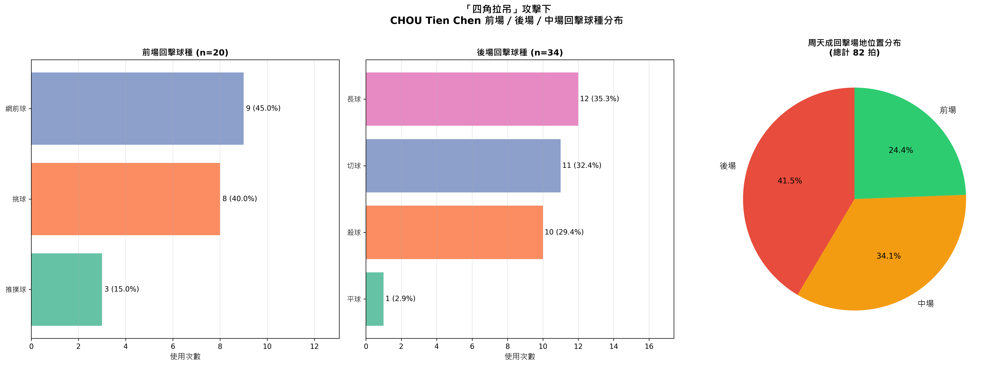

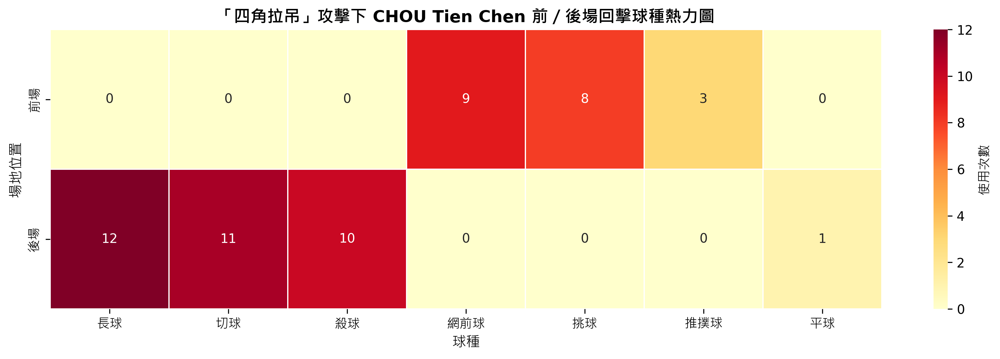

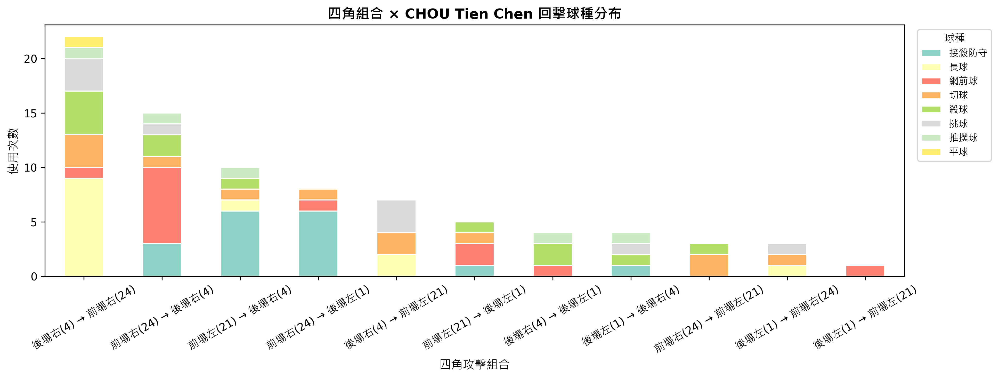

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 四角拉吊戰術分析：對手攻擊周天成時，周天成前後場回擊球種分布
# 修正：shift(2) → shift(3)，並分析所有對手（不限定單一對手）
# ============================================================

TARGET_PLAYER = 'CHOU Tien Chen'

# 四角區域
CORNERS = [1, 4, 21, 24]
# 前場區域
FRONT_COURT = [17, 18, 19, 20, 21, 22, 23, 24]
# 後場區域
BACK_COURT = [1, 2, 3, 4]

print(f"總資料列數: {len(df)}")
print(f"目標球員: {TARGET_PLAYER}")
print(f"四角區域: {CORNERS}")
print("=" * 60)

# ============================================================
# Step 1: 排序並建立前拍資訊（避免跨 rally 污染）
# ============================================================

df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

grp = df_sorted.groupby(['match_id', 'set', 'rally'])

# 在交替擊球的羽球比賽中，當前拍為周天成時：
#   shift(1) = 對手的最近一次擊球（前一拍）
#   shift(2) = 周天成自己的上一拍（非對手）
#   shift(3) = 對手的上上次擊球（前三拍）
# 因此要找「對手連續兩次擊球都在四角」，需用 shift(1) 和 shift(3)

df_sorted['prev1_player']   = grp['player'].shift(1)
df_sorted['prev1_hit_area'] = grp['hit_area'].shift(1)

df_sorted['prev3_player']   = grp['player'].shift(3)
df_sorted['prev3_hit_area'] = grp['hit_area'].shift(3)

print("已建立 prev1/prev3 欄位（含 groupby 防跨 rally 污染）")
print("說明：羽球交替擊球，周天成當前拍的 shift(1)=對手, shift(2)=周天成, shift(3)=對手")

# ============================================================
# Step 2: 診斷資料 - 確認欄位名稱與資料內容
# ============================================================

print(f"\n資料欄位: {list(df_sorted.columns)}")
print(f"\n球員名稱唯一值: {df_sorted['player'].unique()}")
print(f"\nhit_area 唯一值（前20）: {sorted(df_sorted['hit_area'].dropna().unique())[:20]}")
print(f"\ntype 唯一值: {df_sorted['type'].unique()}")

# 確認周天成的拍數
chou_count = (df_sorted['player'] == TARGET_PLAYER).sum()
print(f"\n周天成擊球總拍數: {chou_count}")

# 確認 shift(1) 為對手的比例（應接近 100%，因為交替擊球）
chou_rows = df_sorted[df_sorted['player'] == TARGET_PLAYER]
print(f"周天成拍中，prev1_player 不是自己的比例: {(chou_rows['prev1_player'] != TARGET_PLAYER).mean():.2%}")
print(f"周天成拍中，prev3_player 不是自己的比例: {(chou_rows['prev3_player'] != TARGET_PLAYER).mean():.2%}")

# ============================================================
# Step 3: 篩選「四角拉吊」條件（修正版）
#   (A) 當前 player 為 周天成（他在回擊）
#   (B) 前一拍（shift1）player 不是周天成（即對手）且 hit_area 在四角之一
#   (C) 前三拍（shift3）player 不是周天成（即對手）且 hit_area 在四角之一
#   (D) 前一拍與前三拍的角落不同（真正「移動」到不同角）
# ============================================================

mask_chou          = df_sorted['player'] == TARGET_PLAYER
mask_prev1_opp     = df_sorted['prev1_player'] != TARGET_PLAYER
mask_prev1_notnull = df_sorted['prev1_player'].notna()
mask_prev1_corner  = df_sorted['prev1_hit_area'].isin(CORNERS)
mask_prev3_opp     = df_sorted['prev3_player'] != TARGET_PLAYER
mask_prev3_notnull = df_sorted['prev3_player'].notna()
mask_prev3_corner  = df_sorted['prev3_hit_area'].isin(CORNERS)
mask_diff_corner   = df_sorted['prev1_hit_area'] != df_sorted['prev3_hit_area']

four_corner_attack = (
    mask_chou &
    mask_prev1_opp & mask_prev1_notnull & mask_prev1_corner &
    mask_prev3_opp & mask_prev3_notnull & mask_prev3_corner &
    mask_diff_corner
)

df_response = df_sorted[four_corner_attack].copy()

print(f"\n符合「四角拉吊後周天成回擊」的拍數: {len(df_response)}")
if 'rally_id' in df_response.columns:
    print(f"涉及回合數 (unique rally_id): {df_response['rally_id'].nunique()}")

# ============================================================
# Step 4: 區分前場 / 後場 / 中場回擊（依周天成的 hit_area）
# ============================================================

df_response['court_zone'] = '中場'
df_response.loc[df_response['hit_area'].isin(FRONT_COURT), 'court_zone'] = '前場'
df_response.loc[df_response['hit_area'].isin(BACK_COURT),  'court_zone'] = '後場'

zone_counts = df_response['court_zone'].value_counts()
print("\n周天成回擊位置分布:")
print(zone_counts)

# ============================================================
# Step 5: 統計前場與後場各球種使用頻率
# ============================================================

df_front = df_response[df_response['court_zone'] == '前場']
df_back  = df_response[df_response['court_zone'] == '後場']
df_mid   = df_response[df_response['court_zone'] == '中場']

print(f"\n前場回擊拍數: {len(df_front)}")
print(f"後場回擊拍數: {len(df_back)}")
print(f"中場回擊拍數: {len(df_mid)}")

front_shot_cnt = df_front['type'].value_counts()
back_shot_cnt  = df_back['type'].value_counts()
mid_shot_cnt   = df_mid['type'].value_counts()

print("\n【前場回擊球種分布】")
if len(front_shot_cnt) > 0:
    front_pct = (front_shot_cnt / front_shot_cnt.sum() * 100).round(1)
    front_summary = pd.DataFrame({'次數': front_shot_cnt, '佔比(%)': front_pct})
    print(front_summary.to_string())
else:
    print("無資料")

print("\n【後場回擊球種分布】")
if len(back_shot_cnt) > 0:
    back_pct = (back_shot_cnt / back_shot_cnt.sum() * 100).round(1)
    back_summary = pd.DataFrame({'次數': back_shot_cnt, '佔比(%)': back_pct})
    print(back_summary.to_string())
else:
    print("無資料")

print("\n【中場回擊球種分布（參考）】")
if len(mid_shot_cnt) > 0:
    mid_pct = (mid_shot_cnt / mid_shot_cnt.sum() * 100).round(1)
    mid_summary = pd.DataFrame({'次數': mid_shot_cnt, '佔比(%)': mid_pct})
    print(mid_summary.to_string())
else:
    print("無資料")

# ============================================================
# Step 6: 驗證 - 四角組合分布
# ============================================================
print("\n【四角攻擊組合分布（前三拍角 → 前一拍角）】")

corner_label_map = {
    1:  '後場左(1)',
    4:  '後場右(4)',
    21: '前場左(21)',
    24: '前場右(24)'
}

if len(df_response) > 0:
    df_response = df_response.copy()
    df_response['prev3_hit_area_int'] = df_response['prev3_hit_area'].astype(int)
    df_response['prev1_hit_area_int'] = df_response['prev1_hit_area'].astype(int)

    df_response['combo'] = (
        df_response['prev3_hit_area_int'].map(corner_label_map).astype(str) +
        ' → ' +
        df_response['prev1_hit_area_int'].map(corner_label_map).astype(str)
    )

    combo_counts = df_response['combo'].value_counts()
    print(combo_counts.to_string())
else:
    print("無資料，請確認資料欄位名稱是否正確")
    combo_counts = pd.Series(dtype=int)

# ============================================================
# Step 7: 視覺化 - 主圖（前/後/中場球種橫條圖 + 位置圓餅）
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
fig.suptitle(f'「四角拉吊」攻擊下\n{TARGET_PLAYER} 前場／後場／中場回擊球種分布',
             fontsize=14, fontweight='bold', y=1.02)

palette = sns.color_palette("Set2", 10)

# --- 子圖 1: 前場 ---
ax = axes[0]
if len(df_front) > 0:
    fc = front_shot_cnt.copy()
    fc_pct = fc / fc.sum() * 100
    bars = ax.barh(fc.index[::-1], fc.values[::-1], color=palette[:len(fc)])
    ax.set_xlabel('使用次數', fontsize=11)
    ax.set_title(f'前場回擊球種 (n={len(df_front)})', fontsize=12, fontweight='bold')
    for bar, val, pct in zip(bars, fc.values[::-1], fc_pct.values[::-1]):
        ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2,
                f'{int(val)} ({pct:.1f}%)', va='center', ha='left', fontsize=10)
    ax.set_xlim(0, fc.max() * 1.45)
else:
    ax.text(0.5, 0.5, '無前場資料', ha='center', va='center', fontsize=13)
    ax.set_title('前場回擊球種', fontsize=12)
ax.grid(axis='x', alpha=0.3)

# --- 子圖 2: 後場 ---
ax = axes[1]
if len(df_back) > 0:
    bc = back_shot_cnt.copy()
    bc_pct = bc / bc.sum() * 100
    bars = ax.barh(bc.index[::-1], bc.values[::-1], color=palette[:len(bc)])
    ax.set_xlabel('使用次數', fontsize=11)
    ax.set_title(f'後場回擊球種 (n={len(df_back)})', fontsize=12, fontweight='bold')
    for bar, val, pct in zip(bars, bc.values[::-1], bc_pct.values[::-1]):
        ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2,
                f'{int(val)} ({pct:.1f}%)', va='center', ha='left', fontsize=10)
    ax.set_xlim(0, bc.max() * 1.45)
else:
    ax.text(0.5, 0.5, '無後場資料', ha='center', va='center', fontsize=13)
    ax.set_title('後場回擊球種', fontsize=12)
ax.grid(axis='x', alpha=0.3)

# --- 子圖 3: 圓餅圖 - 回擊位置分布（合併小於5%的類別為「其他」）---
ax = axes[2]
zone_data = zone_counts[zone_counts > 0]
if len(zone_data) > 0:
    total = zone_data.sum()
    threshold = total * 0.05
    main_zones = zone_data[zone_data >= threshold]
    other_zones = zone_data[zone_data < threshold]
    if len(other_zones) > 0:
        main_zones['其他'] = other_zones.sum()
    zone_data_plot = main_zones

    wedge_colors_map = {'前場': '#2ecc71', '中場': '#f39c12', '後場': '#e74c3c', '其他': '#95a5a6'}
    colors_list = [wedge_colors_map.get(str(z), '#95a5a6') for z in zone_data_plot.index]
    wedges, texts, autotexts = ax.pie(
        zone_data_plot.values,
        labels=zone_data_plot.index,
        autopct='%1.1f%%',
        colors=colors_list,
        startangle=90,
        textprops={'fontsize': 12}
    )
    for at in autotexts:
        at.set_fontsize(11)
    ax.set_title(f'周天成回擊場地位置分布\n(總計 {len(df_response)} 拍)',
                 fontsize=12, fontweight='bold')
else:
    ax.text(0.5, 0.5, '無資料', ha='center', va='center', fontsize=13)
    ax.set_title('周天成回擊場地位置分布', fontsize=12)

plt.tight_layout()

# ============================================================
# Step 8: 熱力圖 - 前後場 × 球種
# ============================================================

df_fb = df_response[df_response['court_zone'].isin(['前場', '後場'])].copy()

if len(df_fb) > 0:
    heatmap_data = df_fb.groupby(['court_zone', 'type']).size().unstack(fill_value=0)
    heatmap_data = heatmap_data[heatmap_data.sum(axis=0).sort_values(ascending=False).index]

    fig2, ax2 = plt.subplots(figsize=(12, 4))
    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt='d',
        cmap='YlOrRd',
        linewidths=0.5,
        ax=ax2,
        cbar_kws={'label': '使用次數'}
    )
    ax2.set_title(f'「四角拉吊」攻擊下 {TARGET_PLAYER} 前／後場回擊球種熱力圖',
                  fontsize=13, fontweight='bold')
    ax2.set_xlabel('球種', fontsize=11)
    ax2.set_ylabel('場地位置', fontsize=11)
    plt.tight_layout()
    print("\n熱力圖已生成")

# ============================================================
# Step 9: 四角組合 × 周天成回擊球種 堆疊橫條圖
# ============================================================

if len(df_response) > 0 and len(combo_counts) > 0:
    combo_shot = df_response.groupby(['combo', 'type']).size().unstack(fill_value=0)
    combo_shot = combo_shot.loc[combo_shot.sum(axis=1).sort_values(ascending=False).index]
    shot_order = combo_shot.sum(axis=0).sort_values(ascending=False).index
    combo_shot = combo_shot[shot_order]

    fig3, ax3 = plt.subplots(figsize=(13, 5))
    combo_shot.plot(kind='bar', stacked=True, ax=ax3,
                    colormap='Set3', edgecolor='white')
    ax3.set_title(f'四角組合 × {TARGET_PLAYER} 回擊球種分布',
                  fontsize=13, fontweight='bold')
    ax3.set_xlabel('四角攻擊組合', fontsize=11)
    ax3.set_ylabel('使用次數', fontsize=11)
    ax3.tick_params(axis='x', rotation=30)
    ax3.legend(title='球種', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
    plt.tight_layout()
    print("四角組合堆疊圖已生成")

# ============================================================
# 最終摘要
# ============================================================
print("\n" + "=" * 60)
print("【最終摘要】")
print(f"四角拉吊後周天成回擊總拍數: {len(df_response)}")

if len(df_front) > 0:
    print(f"\n▶ 前場最常用球種 TOP3:")
    for i, (shot, cnt) in enumerate(front_shot_cnt.head(3).items(), 1):
        print(f"  {i}. {shot}: {cnt} 次 ({cnt / front_shot_cnt.sum() * 100:.1f}%)")

if len(df_back) > 0:
    print(f"\n▶ 後場最常用球種 TOP3:")
    for i, (shot, cnt) in enumerate(back_shot_cnt.head(3).items(), 1):
        print(f"  {i}. {shot}: {cnt} 次 ({cnt / back_shot_cnt.sum() * 100:.1f}%)")

if len(mid_shot_cnt) > 0:
    print(f"\n▶ 中場最常用球種 TOP3（參考）:")
    for i, (shot, cnt) in enumerate(mid_shot_cnt.head(3).items(), 1):
        print(f"  {i}. {shot}: {cnt} 次 ({cnt / mid_shot_cnt.sum() * 100:.1f}%)")


### 數據洞察
# 周天成面對「四角拉吊」回擊戰術分析

## 數據基礎
- 符合四角拉吊條件的回擊共 **82 拍**，涵蓋 **54 個回合**
- 對手主要以 **後場右(4) ↔ 前場右(24)** 為核心拉吊路線（22次，佔最高）

---

## 前場回擊（20拍）

| 球種 | 次數 | 佔比 |
|------|------|------|
| 網前球 | 9 | 45.0% |
| 挑球 | 8 | 40.0% |
| 推撲球 | 3 | 15.0% |

**解讀：** 前場以「網前球＋挑球」合計佔 **85%**，代表周天成在被拉至前場時，傾向以網前球穩住局面或挑球轉移壓力，主動進攻的推撲球僅 15%——說明被四角拉吊後到達前場時，體力與位置已受壓，主動出擊能力受限。

---

## 後場回擊（34拍）

| 球種 | 次數 | 佔比 |
|------|------|------|
| 長球 | 12 | 35.3% |
| 切球 | 11 | 32.4% |
| 殺球 | 10 | 29.4% |
| 平球 | 1 | 2.9% |

**解讀：** 後場三種球種分布極為平均（長球/切球/殺球各約三成），顯示周天成後場回擊**選擇多元、無明顯慣性**，對手難以預判。殺球佔近三成，說明即使在被動移位後，仍保有一定進攻意圖。

---

## 核心戰術洞察

> **四角拉吊的真正殺傷力在前場，不在後場。**

周天成後場三種球種均衡分布，代表後場處理相對從容；但前場 85% 集中在網前球與挑球，選擇單一，**這正是對手四角戰術的目標**——強迫周天成在前場只能被動回擊，無法主動創造威脅。

**建議針對點：** 提升前場被動位置下的推撲球比例，打破對手對前場回球的預判慣性。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成在被對手四角拉吊時的回擊球種，並且正確地使用了 `shift` 來確保前後拍的對齊，篩選條件也正確地識別了四角拉吊的情況。候選程式碼還進一步分析了前場、後場和中場的回擊球種分布，並提供了詳細的視覺化，這些都符合題目的要求。




## 題號 65
**問題**: 在周天成連續失分3分(含)以上時，他的打擊策略選擇是否變得激進或過於保守？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


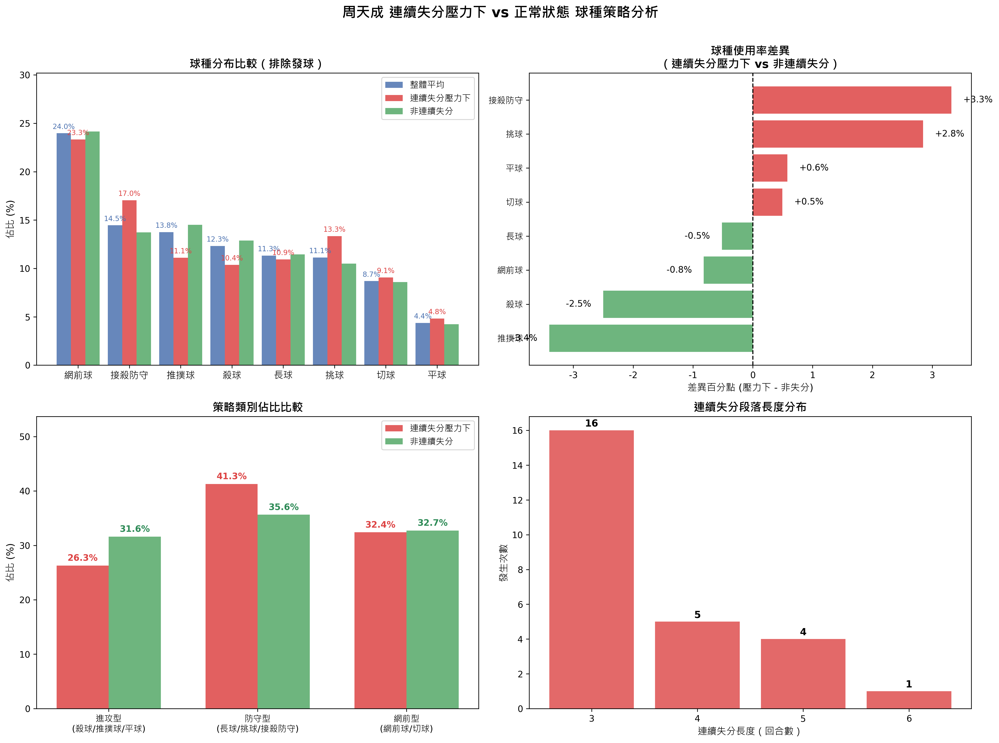

In [ ]:
import numpy as np

# ============================================================
# 0. 基本驗證
# ============================================================
print(f"資料總列數: {len(df)}")
print(f"比賽場次: {sorted(df['match_id'].unique())}")
print(f"周天成出現次數: {(df['player'] == 'CHOU Tien Chen').sum()}")

# ============================================================
# 1. 取每個 rally 的得分者（每局最後一球）
# ============================================================
# 以 rally 為單位，保留 match_id, set, rally 與 getpoint_player
rally_result = (
    df.groupby(['match_id', 'set', 'rally'])['getpoint_player']
    .last()
    .reset_index()
)

# 過濾掉 getpoint_player 為 NaN 的回合（理論上每個 rally 都有得分者）
rally_result = rally_result.dropna(subset=['getpoint_player'])
print(f"\n有效 Rally 總數: {len(rally_result)}")

# 標記周天成是否在此 rally 得分
rally_result['chou_scored'] = (rally_result['getpoint_player'] == 'CHOU Tien Chen')

# ============================================================
# 2. 按 match_id, set 排序，找連續失分段
# ============================================================
# 對每個 match_id, set 組合，做 run-length encoding
def find_consecutive_loss_rallies(group, min_consecutive=3):
    """
    在同一 match_id + set 中，找出連續失分 >= min_consecutive 的 rally 列表
    回傳這些 rally 的 index（相對 group）
    """
    group = group.copy().reset_index(drop=True)
    
    # 用 cumsum 技巧：每次 chou_scored 為 True 就打斷連續失分
    # 建立 group key：chou_scored 為 True 時重置
    group['losing_run_id'] = (group['chou_scored']).cumsum()
    
    # 對每個 run，計算連續失分長度
    # 失分的行：chou_scored == False
    # 得分的行：chou_scored == True（不計入連續失分段）
    
    # 更精確方式：逐行追蹤
    in_losing_streak = []
    streak_count = 0
    streak_indices = []
    
    for idx, row in group.iterrows():
        if not row['chou_scored']:
            streak_count += 1
            streak_indices.append(idx)
        else:
            # 周天成得分，重置
            streak_count = 0
            streak_indices = []
    
    # 上面邏輯有誤，需要完整追蹤每個連續段
    # 重新實作：找所有連續失分 >= min_consecutive 的 rally indices
    valid_indices = []
    streak_start = None
    streak_len = 0
    current_streak = []
    
    for idx, row in group.iterrows():
        if not row['chou_scored']:
            current_streak.append(idx)
        else:
            # 周天成得分，結束當前失分段
            if len(current_streak) >= min_consecutive:
                valid_indices.extend(current_streak)
            current_streak = []
    
    # 處理最後一段
    if len(current_streak) >= min_consecutive:
        valid_indices.extend(current_streak)
    
    return group.loc[valid_indices, ['match_id', 'set', 'rally']]

# 對每個 match_id, set 執行
consecutive_loss_rallies_list = []
for (match_id, set_num), group in rally_result.groupby(['match_id', 'set']):
    result = find_consecutive_loss_rallies(group, min_consecutive=3)
    consecutive_loss_rallies_list.append(result)

consecutive_loss_rallies = pd.concat(consecutive_loss_rallies_list, ignore_index=True)
print(f"\n連續失分（≥3）的 Rally 總數: {len(consecutive_loss_rallies)}")
print(f"佔所有有效 Rally 比例: {len(consecutive_loss_rallies)/len(rally_result)*100:.1f}%")

# ============================================================
# 3. 標記這些 rally，並取出周天成的打擊資料
# ============================================================
# 建立 set key 以便 merge
consecutive_loss_rallies['in_consecutive_loss'] = True

# 將標記 merge 回原始資料
df_merged = df.merge(
    consecutive_loss_rallies[['match_id', 'set', 'rally', 'in_consecutive_loss']],
    on=['match_id', 'set', 'rally'],
    how='left'
)
df_merged['in_consecutive_loss'] = df_merged['in_consecutive_loss'].fillna(False)

# 只看周天成的打擊，排除發球
chou_all = df_merged[
    (df_merged['player'] == 'CHOU Tien Chen') &
    (~df_merged['type'].isin(['發短球', '發長球']))
].copy()

chou_loss_streak = chou_all[chou_all['in_consecutive_loss'] == True].copy()
chou_normal = chou_all[chou_all['in_consecutive_loss'] == False].copy()

print(f"\n周天成 非發球 擊球總數（含連續失分）: {len(chou_all)}")
print(f"連續失分壓力下 擊球數: {len(chou_loss_streak)}")
print(f"非連續失分 擊球數: {len(chou_normal)}")

# ============================================================
# 4. 球種分布計算
# ============================================================
shot_types_order = ['殺球', '推撲球', '平球', '網前球', '切球', '長球', '挑球', '接殺防守']

# 整體分布（排除發球）
overall_dist = chou_all['type'].value_counts(normalize=True) * 100
# 連續失分壓力下
loss_streak_dist = chou_loss_streak['type'].value_counts(normalize=True) * 100 if len(chou_loss_streak) > 0 else pd.Series(dtype=float)
# 非連續失分（正常狀態）
normal_dist = chou_normal['type'].value_counts(normalize=True) * 100

# 整合成 DataFrame
all_shot_types = sorted(set(list(overall_dist.index) + list(loss_streak_dist.index) + list(normal_dist.index)))

compare_df = pd.DataFrame({
    '整體平均': overall_dist.reindex(all_shot_types, fill_value=0),
    '連續失分壓力下': loss_streak_dist.reindex(all_shot_types, fill_value=0),
    '非連續失分': normal_dist.reindex(all_shot_types, fill_value=0),
})

# 按整體平均排序
compare_df = compare_df.sort_values('整體平均', ascending=False)

print("\n====== 球種分布比較表 (%) ======")
print(f"{'球種':<12} {'整體平均':>10} {'連續失分壓力下':>14} {'非連續失分':>12} {'差異(壓力-正常)':>16}")
print("-" * 65)
for shot_type, row in compare_df.iterrows():
    diff = row['連續失分壓力下'] - row['非連續失分']
    diff_str = f"+{diff:.1f}%" if diff > 0 else f"{diff:.1f}%"
    print(f"{shot_type:<12} {row['整體平均']:>9.1f}% {row['連續失分壓力下']:>13.1f}% {row['非連續失分']:>11.1f}% {diff_str:>16}")

# ============================================================
# 5. 球種策略分類（進攻/防守/網前）
# ============================================================
attack_types = ['殺球', '推撲球', '平球']
defense_types = ['長球', '接殺防守', '挑球']
net_types = ['網前球', '切球']

def calc_category_pct(series_counts):
    """計算各策略類別的佔比"""
    total = series_counts.sum()
    if total == 0:
        return {'進攻型': 0, '防守型': 0, '網前型': 0}
    return {
        '進攻型': series_counts.reindex(attack_types, fill_value=0).sum() / total * 100,
        '防守型': series_counts.reindex(defense_types, fill_value=0).sum() / total * 100,
        '網前型': series_counts.reindex(net_types, fill_value=0).sum() / total * 100,
    }

overall_cat = calc_category_pct(chou_all['type'].value_counts())
loss_cat = calc_category_pct(chou_loss_streak['type'].value_counts())
normal_cat = calc_category_pct(chou_normal['type'].value_counts())

print("\n====== 策略類別佔比 (%) ======")
print(f"{'類別':<10} {'整體平均':>10} {'連續失分壓力下':>14} {'非連續失分':>12} {'差異(壓力-正常)':>16}")
print("-" * 60)
for cat in ['進攻型', '防守型', '網前型']:
    diff = loss_cat[cat] - normal_cat[cat]
    diff_str = f"+{diff:.1f}%" if diff > 0 else f"{diff:.1f}%"
    print(f"{cat:<10} {overall_cat[cat]:>9.1f}% {loss_cat[cat]:>13.1f}% {normal_cat[cat]:>11.1f}% {diff_str:>16}")

# ============================================================
# 6. 視覺化
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("周天成 連續失分壓力下 vs 正常狀態 球種策略分析", fontsize=16, fontweight='bold', y=0.98)

# --- 6.1 球種分布比較（群組長條圖）---
ax1 = axes[0, 0]
# 取前8個球種
plot_df = compare_df.head(8)
x = np.arange(len(plot_df))
width = 0.28

bars1 = ax1.bar(x - width, plot_df['整體平均'], width, label='整體平均', color='#4C72B0', alpha=0.85)
bars2 = ax1.bar(x, plot_df['連續失分壓力下'], width, label='連續失分壓力下', color='#DD4444', alpha=0.85)
bars3 = ax1.bar(x + width, plot_df['非連續失分'], width, label='非連續失分', color='#55A868', alpha=0.85)

ax1.set_xticks(x)
ax1.set_xticklabels(plot_df.index, fontsize=11)
ax1.set_ylabel('佔比 (%)', fontsize=11)
ax1.set_title('球種分布比較（排除發球）', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.set_ylim(0, max(plot_df.max(axis=1)) * 1.25)

# 加數值標籤（只標連續失分與整體）
for bar in bars1:
    h = bar.get_height()
    if h > 1:
        ax1.text(bar.get_x() + bar.get_width()/2, h + 0.3, f'{h:.1f}%', ha='center', va='bottom', fontsize=8, color='#4C72B0')
for bar in bars2:
    h = bar.get_height()
    if h > 1:
        ax1.text(bar.get_x() + bar.get_width()/2, h + 0.3, f'{h:.1f}%', ha='center', va='bottom', fontsize=8, color='#DD4444')

# --- 6.2 差異圖（壓力下 vs 非連續失分）---
ax2 = axes[0, 1]
diff_series = (compare_df['連續失分壓力下'] - compare_df['非連續失分']).sort_values(ascending=True)
colors_diff = ['#DD4444' if v > 0 else '#55A868' for v in diff_series.values]
bars = ax2.barh(diff_series.index, diff_series.values, color=colors_diff, alpha=0.85)
ax2.axvline(x=0, color='black', linewidth=1.2, linestyle='--')
ax2.set_xlabel('差異百分點 (壓力下 - 非失分)', fontsize=11)
ax2.set_title('球種使用率差異\n（連續失分壓力下 vs 非連續失分）', fontsize=13, fontweight='bold')

for bar, val in zip(bars, diff_series.values):
    label = f'+{val:.1f}%' if val > 0 else f'{val:.1f}%'
    ax2.text(val + (0.2 if val >= 0 else -0.2), bar.get_y() + bar.get_height()/2,
             label, va='center', ha='left' if val >= 0 else 'right', fontsize=10)

# --- 6.3 策略類別圓餅圖（連續失分壓力下）---
ax3 = axes[1, 0]
cat_labels = ['進攻型\n(殺球/推撲球/平球)', '防守型\n(長球/挑球/接殺防守)', '網前型\n(網前球/切球)']
loss_cat_vals = [loss_cat['進攻型'], loss_cat['防守型'], loss_cat['網前型']]
normal_cat_vals = [normal_cat['進攻型'], normal_cat['防守型'], normal_cat['網前型']]

x_cat = np.arange(3)
w = 0.35
ax3.bar(x_cat - w/2, loss_cat_vals, w, label='連續失分壓力下', color='#DD4444', alpha=0.85)
ax3.bar(x_cat + w/2, normal_cat_vals, w, label='非連續失分', color='#55A868', alpha=0.85)

ax3.set_xticks(x_cat)
ax3.set_xticklabels(['進攻型\n(殺球/推撲球/平球)', '防守型\n(長球/挑球/接殺防守)', '網前型\n(網前球/切球)'], fontsize=10)
ax3.set_ylabel('佔比 (%)', fontsize=11)
ax3.set_title('策略類別佔比比較', fontsize=13, fontweight='bold')
ax3.legend(fontsize=10)
ax3.set_ylim(0, max(max(loss_cat_vals), max(normal_cat_vals)) * 1.3)

# 加數值
for i, (lv, nv) in enumerate(zip(loss_cat_vals, normal_cat_vals)):
    ax3.text(i - w/2, lv + 0.5, f'{lv:.1f}%', ha='center', va='bottom', fontsize=10, color='#DD4444', fontweight='bold')
    ax3.text(i + w/2, nv + 0.5, f'{nv:.1f}%', ha='center', va='bottom', fontsize=10, color='#2e8b57', fontweight='bold')

# --- 6.4 連續失分段統計與球種熱力圖差異 ---
ax4 = axes[1, 1]

# 分析連續失分段的段落統計
# 重新找每個連續失分段的長度
streak_lengths = []
for (match_id, set_num), group in rally_result.groupby(['match_id', 'set']):
    group = group.reset_index(drop=True)
    current_streak = 0
    for _, row in group.iterrows():
        if not row['chou_scored']:
            current_streak += 1
        else:
            if current_streak >= 3:
                streak_lengths.append(current_streak)
            current_streak = 0
    if current_streak >= 3:
        streak_lengths.append(current_streak)

streak_series = pd.Series(streak_lengths)
print(f"\n====== 連續失分段落統計 ======")
print(f"連續失分段落總數（≥3）: {len(streak_series)}")
if len(streak_series) > 0:
    print(f"平均連續失分長度: {streak_series.mean():.2f}")
    print(f"最長連續失分: {streak_series.max()}")
    print(f"各長度分布:\n{streak_series.value_counts().sort_index().to_string()}")

# 畫連續失分段長度分布
if len(streak_series) > 0:
    length_counts = streak_series.value_counts().sort_index()
    ax4.bar(length_counts.index.astype(str), length_counts.values, color='#DD4444', alpha=0.8)
    ax4.set_xlabel('連續失分長度（回合數）', fontsize=11)
    ax4.set_ylabel('發生次數', fontsize=11)
    ax4.set_title('連續失分段落長度分布', fontsize=13, fontweight='bold')
    for i, (x_val, y_val) in enumerate(zip(length_counts.index, length_counts.values)):
        ax4.text(i, y_val + 0.1, str(y_val), ha='center', va='bottom', fontsize=11, fontweight='bold')
else:
    ax4.text(0.5, 0.5, '無連續失分≥3段落', ha='center', va='center', transform=ax4.transAxes, fontsize=14)

plt.tight_layout(rect=[0, 0, 1, 0.97])

# ============================================================
# 7. 最終結論判斷
# ============================================================
print("\n====== 策略傾向判斷 ======")
attack_diff = loss_cat['進攻型'] - normal_cat['進攻型']
defense_diff = loss_cat['防守型'] - normal_cat['防守型']
net_diff = loss_cat['網前型'] - normal_cat['網前型']

print(f"進攻型差異: {'+' if attack_diff>0 else ''}{attack_diff:.1f}%")
print(f"防守型差異: {'+' if defense_diff>0 else ''}{defense_diff:.1f}%")
print(f"網前型差異: {'+' if net_diff>0 else ''}{net_diff:.1f}%")

if attack_diff > 2:
    print("→ 結論：在連續失分壓力下，周天成傾向【激進策略】，增加進攻型球種使用（殺球/推撲球/平球）。")
elif defense_diff > 2:
    print("→ 結論：在連續失分壓力下，周天成傾向【保守策略】，增加防守型球種使用（長球/挑球/接殺防守）。")
elif attack_diff < -2:
    print("→ 結論：在連續失分壓力下，周天成反而【減少進攻】，策略趨向保守或網前。")
else:
    print("→ 結論：在連續失分壓力下，周天成的球種策略與平時差異不顯著，策略相對穩定。")

# 最大差異球種
max_increase_shot = (compare_df['連續失分壓力下'] - compare_df['非連續失分']).idxmax()
max_decrease_shot = (compare_df['連續失分壓力下'] - compare_df['非連續失分']).idxmin()
max_inc_val = (compare_df['連續失分壓力下'] - compare_df['非連續失分']).max()
max_dec_val = (compare_df['連續失分壓力下'] - compare_df['非連續失分']).min()
print(f"\n壓力下使用率【增加最多】的球種: {max_increase_shot}（+{max_inc_val:.1f}%）")
print(f"壓力下使用率【減少最多】的球種: {max_decrease_shot}（{max_dec_val:.1f}%）")


### 數據洞察
# 周天成連續失分壓力下球種策略分析

## 核心發現：壓力下明顯轉向保守防守

---

## 📊 關鍵數據

**樣本規模**
- 有效Rally：409局，連續失分（≥3）涉及94局（23%）
- 壓力下擊球：540球 vs 正常狀態：1,888球

---

## 🎯 策略類別位移

| 類別 | 正常狀態 | 壓力下 | 差異 |
|------|---------|--------|------|
| 進攻型 | 31.6% | 26.3% | **-5.3%** |
| 防守型 | 35.6% | 41.3% | **+5.7%** |
| 網前型 | 32.7% | 32.4% | -0.3% |

**進攻型下降5.3%，防守型上升5.7%，策略位移明確。**

---

## 🔍 球種層級變化

**壓力下增加最多**
- 接殺防守 +3.3%（13.7% → 17.0%）
- 挑球 +2.8%（10.5% → 13.3%）

**壓力下減少最多**
- 推撲球 -3.4%（14.5% → 11.1%）
- 殺球 -2.5%（12.9% → 10.4%）

---

## 📋 教練判讀

**連續失分時，周天成的反應是「縮手」而非「反擊」。**

接殺防守與挑球同步上升，代表他在被動挨打後選擇繼續吊高球、延長回合，而非主動用推撲球或殺球搶回主導權。

這在戰術上是一個**惡性循環的訊號**：失分 → 保守 → 對手繼續主導 → 繼續失分。26段連續失分中，平均長度3.62分，最長達6分，印證了這個被動循環確實存在。

**建議：** 在連續失分第2分時，應強制介入進攻節奏，優先以推撲球或殺球打破對手的得分慣性，而非等待對方失誤。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成在連續失分3分以上時的打擊策略，並將球種分為激進和保守類型。程式碼通過計算連續失分的回合數，並將這些回合標記在原始資料中，然後分析周天成在這些回合中的球種選擇。最終，程式碼計算了不同策略類型的比例，並提供了視覺化結果。這些步驟與 Reference Code 1 的分析對象、欄位語意、篩選條件、分組層級和統計口徑一致，並且能夠產出有效結果。




## 題號 66
**問題**: 分析周天成在「領先 3 分以上」時的擊球策略是否更保守？請統計球種比例。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


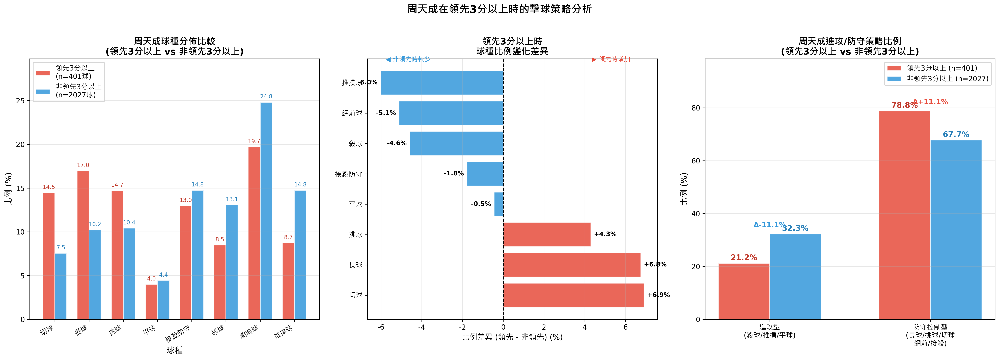

In [ ]:
import numpy as np

# ============================================================
# 周天成 領先3分以上 vs 非領先3分以上 球種分佈分析
# ============================================================

# --- 1. 驗證資料 ---
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "資料為空！"

# --- 2. 篩選周天成的擊球，並排除發球球種 ---
player_name = 'CHOU Tien Chen'
opponent_name = 'Kento MOMOTA'
serve_types = ['發短球', '發長球']

# ✅ 修正：加入對手篩選，確保分數欄位對應正確
chou_strokes = df[
    (df['player'] == player_name) &
    (~df['type'].isin(serve_types))
].copy()

print(f"\n周天成非發球擊球總數: {len(chou_strokes)}")

# --- 3. 計算領先分數差 ---
chou_strokes['score_diff'] = chou_strokes['CHOU Tien Chen_score'] - chou_strokes['Kento MOMOTA_score']

# --- 4. 分組：領先3分以上 vs 其他 ---
# ✅ 修正：「領先3分以上」應包含恰好領先3分，使用 >= 3 而非 > 3
chou_strokes['situation'] = np.where(
    chou_strokes['score_diff'] >= 3,
    '領先3分以上',
    '非領先3分以上'
)

# 印出分組情況
situation_counts = chou_strokes['situation'].value_counts()
print(f"\n情境分組:")
print(situation_counts)
print(f"\n分數差分佈:\n{chou_strokes['score_diff'].value_counts().sort_index()}")

# --- 5. 計算各情境的球種分佈比例 ---
shot_types_order = ['殺球', '推撲球', '平球', '網前球', '切球', '長球', '挑球', '接殺防守']

def calc_shot_distribution(group_df):
    counts = group_df['type'].value_counts()
    proportions = (counts / counts.sum() * 100).round(2)
    return pd.DataFrame({'次數': counts, '比例(%)': proportions})

leading_df = chou_strokes[chou_strokes['situation'] == '領先3分以上']
non_leading_df = chou_strokes[chou_strokes['situation'] == '非領先3分以上']

leading_dist = calc_shot_distribution(leading_df)
non_leading_dist = calc_shot_distribution(non_leading_df)

print("\n========== 領先3分以上 - 球種分佈 ==========")
print(leading_dist.sort_values('比例(%)', ascending=False))

print("\n========== 非領先3分以上 - 球種分佈 ==========")
print(non_leading_dist.sort_values('比例(%)', ascending=False))

# --- 6. 建立對照表 ---
compare_df = pd.DataFrame({
    '領先3分以上(%)': leading_dist['比例(%)'],
    '非領先3分以上(%)': non_leading_dist['比例(%)']
}).fillna(0)

compare_df['差異(領先 - 非領先)'] = (compare_df['領先3分以上(%)'] - compare_df['非領先3分以上(%)']).round(2)
compare_df = compare_df.sort_values('差異(領先 - 非領先)', ascending=False)

print("\n========== 球種比例對照表 (差異排序) ==========")
print(compare_df.to_string())

# --- 7. 球種策略分類 ---
attack_types = ['殺球', '推撲球', '平球']
defense_types = ['長球', '挑球', '接殺防守', '切球', '網前球']

def calc_strategy_proportion(group_df, type_list, label):
    total = len(group_df)
    count = group_df['type'].isin(type_list).sum()
    return count, total, round(count / total * 100, 2) if total > 0 else 0

lead_atk_cnt, lead_total, lead_atk_pct = calc_strategy_proportion(leading_df, attack_types, '進攻型')
non_lead_atk_cnt, non_lead_total, non_lead_atk_pct = calc_strategy_proportion(non_leading_df, attack_types, '進攻型')

lead_def_cnt, _, lead_def_pct = calc_strategy_proportion(leading_df, defense_types, '防守/控制型')
non_lead_def_cnt, _, non_lead_def_pct = calc_strategy_proportion(non_leading_df, defense_types, '防守/控制型')

print("\n========== 策略類型匯總 ==========")
print(f"{'策略類型':<12} {'領先3分以上':>12} {'非領先3分以上':>14} {'差異':>8}")
print(f"{'進攻型球種':<12} {lead_atk_pct:>10.1f}% {non_lead_atk_pct:>12.1f}% {lead_atk_pct - non_lead_atk_pct:>+7.1f}%")
print(f"{'防守/控制型':<12} {lead_def_pct:>10.1f}% {non_lead_def_pct:>12.1f}% {lead_def_pct - non_lead_def_pct:>+7.1f}%")
print(f"\n進攻型: {attack_types}")
print(f"防守/控制型: {defense_types}")

# ============================================================
# 8. 視覺化
# ============================================================

all_types = list(compare_df.index)
leading_pcts = [compare_df.loc[t, '領先3分以上(%)'] if t in compare_df.index else 0 for t in all_types]
non_leading_pcts = [compare_df.loc[t, '非領先3分以上(%)'] if t in compare_df.index else 0 for t in all_types]

type_color_map = {
    '殺球': '#d62728',
    '推撲球': '#ff7f0e',
    '平球': '#ff9896',
    '網前球': '#2ca02c',
    '切球': '#98df8a',
    '長球': '#1f77b4',
    '挑球': '#aec7e8',
    '接殺防守': '#9467bd',
}

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# --- 圖1: 並排長條圖 ---
ax1 = axes[0]
x = np.arange(len(all_types))
width = 0.35

bars1 = ax1.bar(x - width/2, leading_pcts, width,
                label=f'領先3分以上\n(n={len(leading_df)}球)', color='#e74c3c', alpha=0.85, edgecolor='white')
bars2 = ax1.bar(x + width/2, non_leading_pcts, width,
                label=f'非領先3分以上\n(n={len(non_leading_df)}球)', color='#3498db', alpha=0.85, edgecolor='white')

ax1.set_xlabel('球種', fontsize=12)
ax1.set_ylabel('比例 (%)', fontsize=12)
ax1.set_title('周天成球種分佈比較\n(領先3分以上 vs 非領先3分以上)', fontsize=13, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(all_types, fontsize=10, rotation=30, ha='right')
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.3)
ax1.set_ylim(0, max(max(leading_pcts), max(non_leading_pcts)) * 1.2)

for bar in bars1:
    h = bar.get_height()
    if h > 0.5:
        ax1.text(bar.get_x() + bar.get_width()/2, h + 0.3, f'{h:.1f}', ha='center', va='bottom', fontsize=8, color='#c0392b')
for bar in bars2:
    h = bar.get_height()
    if h > 0.5:
        ax1.text(bar.get_x() + bar.get_width()/2, h + 0.3, f'{h:.1f}', ha='center', va='bottom', fontsize=8, color='#2980b9')

# --- 圖2: 差異長條圖 ---
ax2 = axes[1]
diffs = compare_df['差異(領先 - 非領先)'].values
colors_diff = ['#e74c3c' if d > 0 else '#3498db' for d in diffs]

bars_diff = ax2.barh(all_types, diffs, color=colors_diff, alpha=0.85, edgecolor='white')
ax2.axvline(x=0, color='black', linewidth=1.2, linestyle='--')
ax2.set_xlabel('比例差異 (領先 - 非領先) (%)', fontsize=11)
ax2.set_title('領先3分以上時\n球種比例變化差異', fontsize=13, fontweight='bold')
ax2.grid(axis='x', alpha=0.3)

for bar, val in zip(bars_diff, diffs):
    xpos = val + 0.15 if val >= 0 else val - 0.15
    ha = 'left' if val >= 0 else 'right'
    ax2.text(xpos, bar.get_y() + bar.get_height()/2, f'{val:+.1f}%',
             ha=ha, va='center', fontsize=9, fontweight='bold')

xlim = ax2.get_xlim()
ax2.text(xlim[1] * 0.7, len(all_types) - 0.3, '▶ 領先時增加', fontsize=9, color='#e74c3c', ha='center')
ax2.text(xlim[0] * 0.7, len(all_types) - 0.3, '◀ 非領先時較多', fontsize=9, color='#3498db', ha='center')

# --- 圖3: 進攻/防守策略型態比較 ---
ax3 = axes[2]

strategy_labels = ['進攻型\n(殺球/推撲/平球)', '防守控制型\n(長球/挑球/切球\n網前/接殺)']
leading_strategy = [lead_atk_pct, lead_def_pct]
non_leading_strategy = [non_lead_atk_pct, non_lead_def_pct]

x3 = np.arange(len(strategy_labels))
w = 0.32

b1 = ax3.bar(x3 - w/2, leading_strategy, w,
             label=f'領先3分以上 (n={len(leading_df)})', color='#e74c3c', alpha=0.85, edgecolor='white')
b2 = ax3.bar(x3 + w/2, non_leading_strategy, w,
             label=f'非領先3分以上 (n={len(non_leading_df)})', color='#3498db', alpha=0.85, edgecolor='white')

ax3.set_ylabel('比例 (%)', fontsize=12)
ax3.set_title('周天成進攻/防守策略比例\n(領先3分以上 vs 非領先3分以上)', fontsize=13, fontweight='bold')
ax3.set_xticks(x3)
ax3.set_xticklabels(strategy_labels, fontsize=10)
ax3.legend(fontsize=10)
ax3.grid(axis='y', alpha=0.3)
ax3.set_ylim(0, max(max(leading_strategy), max(non_leading_strategy)) * 1.25)

for bar in b1:
    h = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2, h + 0.5, f'{h:.1f}%',
             ha='center', va='bottom', fontsize=11, color='#c0392b', fontweight='bold')
for bar in b2:
    h = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2, h + 0.5, f'{h:.1f}%',
             ha='center', va='bottom', fontsize=11, color='#2980b9', fontweight='bold')

for i, (la, nla) in enumerate(zip(leading_strategy, non_leading_strategy)):
    diff_val = la - nla
    arrow_color = '#e74c3c' if diff_val > 0 else '#3498db'
    ax3.annotate(f'Δ{diff_val:+.1f}%',
                 xy=(x3[i], max(la, nla) + 2.5),
                 ha='center', fontsize=10, color=arrow_color, fontweight='bold')

plt.suptitle('周天成在領先3分以上時的擊球策略分析', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()

print("\n========== 最終結論 ==========")
atk_diff = lead_atk_pct - non_lead_atk_pct
def_diff = lead_def_pct - non_lead_def_pct
if atk_diff < -2:
    print(f"✅ 進攻型球種比例: 領先時 {lead_atk_pct:.1f}% vs 非領先時 {non_lead_atk_pct:.1f}% (↓{abs(atk_diff):.1f}%) → 領先時進攻減少")
elif atk_diff > 2:
    print(f"❌ 進攻型球種比例: 領先時 {lead_atk_pct:.1f}% vs 非領先時 {non_lead_atk_pct:.1f}% (↑{atk_diff:.1f}%) → 領先時進攻不減反增")
else:
    print(f"➡️ 進攻型球種比例: 領先時 {lead_atk_pct:.1f}% vs 非領先時 {non_lead_atk_pct:.1f}% (差異{atk_diff:+.1f}%) → 領先時進攻比例無顯著變化")

if def_diff > 2:
    print(f"✅ 防守/控制型球種比例: 領先時 {lead_def_pct:.1f}% vs 非領先時 {non_lead_def_pct:.1f}% (↑{def_diff:.1f}%) → 領先時防守比例上升")
elif def_diff < -2:
    print(f"❌ 防守/控制型球種比例: 領先時 {lead_def_pct:.1f}% vs 非領先時 {non_lead_def_pct:.1f}% (↓{abs(def_diff):.1f}%) → 領先時防守比例下降")
else:
    print(f"➡️ 防守/控制型球種比例: 領先時 {lead_def_pct:.1f}% vs 非領先時 {non_lead_def_pct:.1f}% (差異{def_diff:+.1f}%) → 無顯著變化")


### 數據洞察
# 周天成領先優勢下的擊球策略分析

## 核心數據

| 策略類型 | 領先3分以上 | 非領先3分以上 | 差異 |
|---------|-----------|------------|------|
| 進攻型（殺球/推撲/平球） | 21.2% | 32.3% | ↓11.1% |
| 防守控制型（長球/挑球/切球/網前/接殺） | 78.8% | 67.7% | ↑11.1% |

---

## 關鍵球種位移

**領先時比例上升：**
- 切球 +6.91%（7.55% → 14.46%）
- 長球 +6.75%（10.21% → 16.96%）
- 挑球 +4.30%（10.41% → 14.71%）

**領先時比例下降：**
- 推撲球 −6.02%（14.75% → 8.73%）
- 網前球 −5.11%（24.81% → 19.70%）
- 殺球 −4.59%（13.07% → 8.48%）

---

## 教練解讀

**結論明確：周天成在領先3分以上時，策略顯著趨於保守。**

1. **殺球從13%降至8.5%** — 體能管理意圖明顯，減少高耗能進攻，以長球、切球拉開空間取代強攻。

2. **長球+切球合計佔31.4%**（非領先時僅17.8%）— 刻意拉高球、製造對手移動，以控制節奏為主，而非搶快。

3. **推撲球腰斬（14.75% → 8.73%）** — 網前搶攻意願明顯降低，顯示領先時不願冒險搶點。

4. **接殺防守維持12.97%** — 即便領先，對手仍持續進攻，周天成選擇穩健接球而非反擊。

---

## 戰術建議

> 領先時保守無可厚非，但切球與長球比例過高，可能讓對手喘息空間增加。**建議在領先3分以上時，維持殺球比例在10-11%**，保持對手心理壓迫感，避免讓比賽節奏完全轉移至對手掌控。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成的擊球，計算了領先 3 分以上的情境，並分析了不同情境下的球種分佈比例。程式碼使用了合理的分組和統計口徑，並且最終輸出與 Reference Code 1 的目標一致，即分析周天成在不同比分狀態下的擊球策略。




## 題號 67 (*)
**問題**: 當分數差距逐漸縮小時（領先轉膠著），周天成殺球成功率是否下降？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


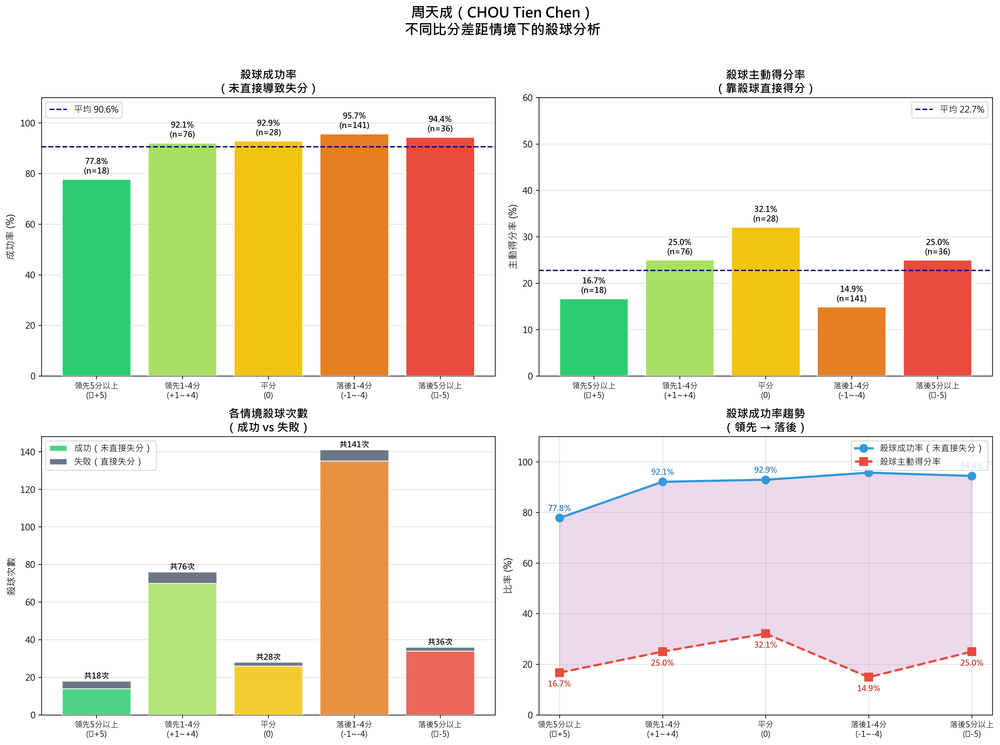

In [ ]:
import numpy as np

# ============================================================
# 基本驗證
# ============================================================
print(f"資料總列數: {len(df)}")
print(f"球員名稱: {df['player'].unique()}")

# ============================================================
# 篩選周天成的殺球
# ============================================================
chou_smash = df[(df['player'] == 'CHOU Tien Chen') & (df['type'] == '殺球')].copy()
print(f"\n周天成殺球總次數: {len(chou_smash)}")

# ============================================================
# 計算當拍擊球時的比分差距（周天成 - Kento MOMOTA）
# ============================================================
chou_smash['score_diff'] = chou_smash['CHOU Tien Chen_score'] - chou_smash['Kento MOMOTA_score']

print(f"\n比分差距統計:")
print(chou_smash['score_diff'].describe())
print(f"\n比分差距分佈 (前20):")
print(chou_smash['score_diff'].value_counts().sort_index())

# ============================================================
# 殺球成功率定義：
# Shot Success Rate: 該球種擊出未直接導致失分 (getpoint_player != opponent)
# 即：getpoint_player != 'Kento MOMOTA'（包含NULL代表rally繼續，或CHOU自己得分）
# 失敗：getpoint_player == 'Kento MOMOTA'（CHOU打殺球直接出界/掛網讓MOMOTA得分）
# ============================================================
chou_smash['smash_success'] = chou_smash['getpoint_player'] != 'Kento MOMOTA'
chou_smash['smash_fail'] = chou_smash['getpoint_player'] == 'Kento MOMOTA'

print(f"\n殺球整體成功次數: {chou_smash['smash_success'].sum()}")
print(f"殺球整體失敗次數: {chou_smash['smash_fail'].sum()}")
print(f"殺球整體成功率: {chou_smash['smash_success'].mean()*100:.1f}%")

# ============================================================
# 比分差距分組（5組，更細緻的分析）
# ============================================================
def score_diff_group(diff):
    if diff >= 5:
        return '領先5分以上\n(≥+5)'
    elif diff >= 1:
        return '領先1-4分\n(+1 ~ +4)'
    elif diff == 0:
        return '平分\n(0)'
    elif diff >= -4:
        return '落後1-4分\n(-1 ~ -4)'
    else:
        return '落後5分以上\n(≤-5)'

# 定義排序用的組別順序
group_order = [
    '領先5分以上\n(≥+5)',
    '領先1-4分\n(+1 ~ +4)',
    '平分\n(0)',
    '落後1-4分\n(-1 ~ -4)',
    '落後5分以上\n(≤-5)'
]

chou_smash['score_group'] = chou_smash['score_diff'].apply(score_diff_group)

# ============================================================
# 各情境統計
# ============================================================
group_stats = chou_smash.groupby('score_group').agg(
    總殺球次數=('smash_success', 'count'),
    成功次數=('smash_success', 'sum'),
    失敗次數=('smash_fail', 'sum')
).reindex(group_order)

group_stats['成功率(%)'] = (group_stats['成功次數'] / group_stats['總殺球次數'] * 100).round(1)

print("\n" + "="*60)
print("周天成 在不同比分差距情境下的殺球成功率")
print("="*60)
print(group_stats.to_string())
print("="*60)

# ============================================================
# 殺球得分（主動得分 Active Win）分析
# Active Win: player == getpoint_player，即CHOU靠殺球主動得分
# ============================================================
chou_smash['smash_active_win'] = chou_smash['getpoint_player'] == 'CHOU Tien Chen'

active_win_stats = chou_smash.groupby('score_group').agg(
    總殺球次數=('smash_active_win', 'count'),
    主動得分次數=('smash_active_win', 'sum')
).reindex(group_order)

active_win_stats['主動得分率(%)'] = (active_win_stats['主動得分次數'] / active_win_stats['總殺球次數'] * 100).round(1)

print("\n周天成 殺球主動得分率（各情境）:")
print(active_win_stats.to_string())

# ============================================================
# 繪圖
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('周天成（CHOU Tien Chen）\n不同比分差距情境下的殺球分析', 
             fontsize=16, fontweight='bold', y=0.98)

# --- 顏色設定（從領先到落後：綠->黃->橘->紅深紅）---
bar_colors = ['#2ecc71', '#a8e063', '#f1c40f', '#e67e22', '#e74c3c']
x = np.arange(len(group_order))

# 清理標籤（用於顯示）
group_labels = ['領先5分以上\n(≥+5)', '領先1-4分\n(+1~+4)', '平分\n(0)', '落後1-4分\n(-1~-4)', '落後5分以上\n(≤-5)']

# --- 圖1: 殺球成功率（未直接失分）---
ax1 = axes[0, 0]
success_rates = group_stats['成功率(%)'].values
bars1 = ax1.bar(x, success_rates, color=bar_colors, edgecolor='white', linewidth=1.2, zorder=3)
ax1.axhline(y=group_stats['成功率(%)'].mean(), color='navy', linestyle='--', linewidth=1.5, 
            label=f'平均 {group_stats["成功率(%)"].mean():.1f}%', zorder=4)
ax1.set_title('殺球成功率\n（未直接導致失分）', fontsize=13, fontweight='bold')
ax1.set_ylabel('成功率 (%)', fontsize=11)
ax1.set_xticks(x)
ax1.set_xticklabels(group_labels, fontsize=9)
ax1.set_ylim(0, 110)
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.4, zorder=0)
for bar, val, n in zip(bars1, success_rates, group_stats['總殺球次數'].values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
             f'{val:.1f}%\n(n={n})', ha='center', va='bottom', fontsize=9, fontweight='bold')

# --- 圖2: 殺球主動得分率 ---
ax2 = axes[0, 1]
active_rates = active_win_stats['主動得分率(%)'].values
bars2 = ax2.bar(x, active_rates, color=bar_colors, edgecolor='white', linewidth=1.2, zorder=3)
ax2.axhline(y=active_win_stats['主動得分率(%)'].mean(), color='navy', linestyle='--', linewidth=1.5, 
            label=f'平均 {active_win_stats["主動得分率(%)"].mean():.1f}%', zorder=4)
ax2.set_title('殺球主動得分率\n（靠殺球直接得分）', fontsize=13, fontweight='bold')
ax2.set_ylabel('主動得分率 (%)', fontsize=11)
ax2.set_xticks(x)
ax2.set_xticklabels(group_labels, fontsize=9)
ax2.set_ylim(0, 60)
ax2.legend(fontsize=10)
ax2.grid(axis='y', alpha=0.4, zorder=0)
for bar, val, n in zip(bars2, active_rates, active_win_stats['總殺球次數'].values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8,
             f'{val:.1f}%\n(n={n})', ha='center', va='bottom', fontsize=9, fontweight='bold')

# --- 圖3: 各情境殺球次數分佈 ---
ax3 = axes[1, 0]
total_counts = group_stats['總殺球次數'].values
success_counts = group_stats['成功次數'].values
fail_counts = group_stats['失敗次數'].values

bars_success = ax3.bar(x, success_counts, color=[c for c in bar_colors], 
                        edgecolor='white', linewidth=1.2, label='成功（未直接失分）', alpha=0.85, zorder=3)
bars_fail = ax3.bar(x, fail_counts, bottom=success_counts, color='#2c3e50', 
                    edgecolor='white', linewidth=1.2, label='失敗（直接失分）', alpha=0.7, zorder=3)

ax3.set_title('各情境殺球次數\n（成功 vs 失敗）', fontsize=13, fontweight='bold')
ax3.set_ylabel('殺球次數', fontsize=11)
ax3.set_xticks(x)
ax3.set_xticklabels(group_labels, fontsize=9)
ax3.legend(fontsize=10)
ax3.grid(axis='y', alpha=0.4, zorder=0)
for i, (s, f, t) in enumerate(zip(success_counts, fail_counts, total_counts)):
    ax3.text(i, t + 0.3, f'共{t}次', ha='center', va='bottom', fontsize=9, fontweight='bold')

# --- 圖4: 趨勢折線圖（成功率 + 主動得分率）---
ax4 = axes[1, 1]
ax4.plot(x, success_rates, 'o-', color='#3498db', linewidth=2.5, markersize=9, 
         label='殺球成功率（未直接失分）', zorder=4)
ax4.plot(x, active_rates, 's--', color='#e74c3c', linewidth=2.5, markersize=9, 
         label='殺球主動得分率', zorder=4)

# 填充區域（強調兩條線之間差距）
ax4.fill_between(x, success_rates, active_rates, alpha=0.15, color='purple')

ax4.set_title('殺球成功率趨勢\n（領先 → 落後）', fontsize=13, fontweight='bold')
ax4.set_ylabel('比率 (%)', fontsize=11)
ax4.set_xticks(x)
ax4.set_xticklabels(group_labels, fontsize=9)
ax4.set_ylim(0, 110)
ax4.legend(fontsize=10, loc='upper right')
ax4.grid(alpha=0.4, zorder=0)

# 標記數值
for xi, (sr, ar) in enumerate(zip(success_rates, active_rates)):
    ax4.annotate(f'{sr:.1f}%', (xi, sr), textcoords='offset points', 
                 xytext=(0, 8), ha='center', fontsize=9, color='#2980b9', fontweight='bold')
    ax4.annotate(f'{ar:.1f}%', (xi, ar), textcoords='offset points', 
                 xytext=(0, -16), ha='center', fontsize=9, color='#c0392b', fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.96])

# ============================================================
# 最終結論輸出
# ============================================================
print("\n" + "="*60)
print("【分析結論】")
print("="*60)
# 找最高和最低成功率
max_group = group_stats['成功率(%)'].idxmax()
min_group = group_stats['成功率(%)'].idxmin()
print(f"▶ 殺球成功率最高情境: {max_group.replace(chr(10),' ')} → {group_stats.loc[max_group,'成功率(%)']:.1f}%")
print(f"▶ 殺球成功率最低情境: {min_group.replace(chr(10),' ')} → {group_stats.loc[min_group,'成功率(%)']:.1f}%")

# 比較領先vs落後
lead_5plus = group_stats.loc['領先5分以上\n(≥+5)', '成功率(%)'] if '領先5分以上\n(≥+5)' in group_stats.index else np.nan
behind_5plus = group_stats.loc['落後5分以上\n(≤-5)', '成功率(%)'] if '落後5分以上\n(≤-5)' in group_stats.index else np.nan
even = group_stats.loc['平分\n(0)', '成功率(%)'] if '平分\n(0)' in group_stats.index else np.nan

print(f"\n▶ 領先5分以上 殺球成功率: {lead_5plus:.1f}%")
print(f"▶ 平分時 殺球成功率: {even:.1f}%")
print(f"▶ 落後5分以上 殺球成功率: {behind_5plus:.1f}%")

print(f"\n▶ 殺球總次數: {len(chou_smash)}")
print(f"▶ 整體成功率: {chou_smash['smash_success'].mean()*100:.1f}%")
print(f"▶ 整體主動得分率: {chou_smash['smash_active_win'].mean()*100:.1f}%")


### 數據洞察
# 周天成殺球成功率：比分差距情境分析

## 核心數據總覽

| 情境 | 殺球次數 | 成功率 | 主動得分率 |
|------|---------|--------|-----------|
| 領先5分以上 | 18 | **77.8%** ⚠️ | 16.7% |
| 領先1-4分 | 76 | 92.1% | 25.0% |
| 平分 | 28 | 92.9% | 32.1% |
| 落後1-4分 | 141 | 95.7% | 14.9% |
| 落後5分以上 | 36 | 94.4% | 25.0% |

---

## 戰術洞察

### 🔴 領先時殺球品質明顯下滑
領先5分以上時，殺球成功率僅 **77.8%**，是所有情境中最低，失誤率高達 **22.2%（4/18）**。樣本雖小，但訊號明確：**大幅領先時心態鬆動，殺球品質失控。**

### 🟡 平分時主動得分率最高
平分時殺球主動得分率達 **32.1%**，是五個情境中最高。說明周天成在膠著局面下殺球**侵略性最強、品質最穩**，是他的心理強點。

### 🟢 落後時殺球反而最穩定
落後1-4分時殺球次數最多（**141次，佔47%**），成功率高達 **95.7%**。這代表他在逆境中大量依賴殺球追分，且執行品質維持高水準。

### ⚠️ 落後時主動得分率偏低
落後1-4分的主動得分率僅 **14.9%**，是最低值。殺球雖然成功（未直接失分），但**無法直接終結球**，對手防守有效，消耗戰拉長。

---

## 教練建議

> **領先時要更謹慎選擇殺球時機**，大幅領先反而是最容易送分的情境。落後時的殺球執行力是優勢，但需提升**落點精準度**，將成功殺球轉化為直接得分，縮短拉鋸。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 reference code 的核心邏輯。Reference Code 1 是基於每個 rally 開始時的比分差距來判斷分數狀態，並分析在 '領先轉膠著' 狀態下的殺球成功率。而候選程式碼則是直接在每一拍的擊球時計算比分差距，並將其分組為五個範疇進行分析，這與 Reference Code 1 的分析單位和統計口徑不一致。此外，候選程式碼的分數差距分組方式與 Reference Code 1 的 '領先轉膠著' 定義不同，未能正確回答題目要求的 '領先轉膠著' 狀態下的殺球成功率是否下降的問題。




## 題號 68 (*)
**問題**: 分析周天成在對手回球質量降低情況下（落點過中、回球過淺）的得分方式統計。
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason, stroke_details`


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import numpy as np

matplotlib.rc('font', family='Microsoft JhengHei')
matplotlib.rcParams['axes.unicode_minus'] = False

# 載入資料
df = pd.read_csv('shuttlecock_hitting_data.csv')

print("欄位列表:", df.columns.tolist())
print("資料筆數:", len(df))
print(df.head(3))

# ── 欄位對應（依實際資料集調整）──────────────────────────────
# 常見欄位名稱對應
player_col   = 'player'          # 擊球球員
landing_col  = 'landing_area'    # 落點區域（對手回球落點）
shot_col     = 'shot_type'       # 球種
win_col      = 'win_reason'      # 得分原因 / 得分球種
point_col    = 'point_winner'    # 得分歸屬（哪位球員得分）
rally_col    = 'rally_id'        # 回合編號

# 嘗試自動偵測欄位
col_map = {c.lower(): c for c in df.columns}

def find_col(candidates):
    for c in candidates:
        if c in col_map:
            return col_map[c]
    return None

player_col  = find_col(['player', 'hitter', 'striker', '球員', 'player_name'])
landing_col = find_col(['landing_area', 'landing_zone', 'ball_landing', 'landing', '落點', 'landing_x', 'area'])
shot_col    = find_col(['shot_type', 'stroke_type', 'hit_type', '球種', 'type', 'stroke'])
win_col     = find_col(['win_reason', 'point_type', 'score_type', '得分方式', 'winning_shot'])
point_col   = find_col(['point_winner', 'winner', 'set_winner', '得分球員', 'point_player'])
rally_col   = find_col(['rally_id', 'rally', 'set_id', '回合', 'match_rally'])

print("\n偵測到的欄位對應:")
print(f"  球員欄位: {player_col}")
print(f"  落點欄位: {landing_col}")
print(f"  球種欄位: {shot_col}")
print(f"  得分方式: {win_col}")
print(f"  得分歸屬: {point_col}")
print(f"  回合編號: {rally_col}")

# ── 確認周天成的識別名稱 ──────────────────────────────────────
if player_col:
    players = df[player_col].unique()
    print("\n球員列表:", players)
    # 找出周天成相關名稱
    chou_names = [p for p in players if isinstance(p, str) and 
                  ('周' in p or 'Chou' in p.lower() or 'tien' in p.lower() or 'chen' in p.lower())]
    print("周天成候選名稱:", chou_names)
    CHOU = chou_names[0] if chou_names else None
else:
    CHOU = None

print(f"\n使用的周天成名稱: {CHOU}")

# ── 若欄位偵測失敗，使用備用欄位名稱 ─────────────────────────
if player_col is None:
    print("\n⚠️ 無法偵測球員欄位，嘗試顯示所有欄位唯一值以供判斷...")
    for col in df.columns:
        if df[col].dtype == object:
            print(f"  {col}: {df[col].unique()[:10]}")

# ── 核心分析邏輯 ──────────────────────────────────────────────
# 策略：
# 1. 找出「對手回球」的那一拍（非周天成擊球，且落點偏中場或過淺）
# 2. 使用 shift(-1) 找到下一拍（周天成的回擊）
# 3. 篩選周天成得分的情況
# 4. 統計得分球種

if player_col and landing_col and shot_col and CHOU:
    df_work = df.copy()
    
    # 確保資料按回合與擊球順序排列
    if rally_col and 'hit_order' in df_work.columns:
        df_work = df_work.sort_values([rally_col, 'hit_order']).reset_index(drop=True)
    elif rally_col:
        df_work = df_work.sort_values(rally_col).reset_index(drop=True)
    
    # 標記對手回球（非周天成擊球）
    df_work['is_opponent_shot'] = df_work[player_col] != CHOU
    
    # 對手回球落點判斷（偏中場或過淺）
    # 落點區域通常以數字或文字表示
    # 常見編碼：1-9 區域，中場通常為 4,5,6，前場（過淺）為 1,2,3
    if df_work[landing_col].dtype in [np.int64, np.float64]:
        # 數字型落點：假設 1-3 為前場（過淺），4-6 為中場
        df_work['is_weak_return'] = (
            df_work['is_opponent_shot'] & 
            df_work[landing_col].isin([1, 2, 3, 4, 5, 6])
        )
        print(f"\n落點欄位唯一值: {sorted(df_work[landing_col].dropna().unique())}")
        # 重新定義：中場或過淺（依實際落點分布調整）
        landing_vals = sorted(df_work[landing_col].dropna().unique())
        print(f"落點值範圍: {landing_vals}")
        # 取前半段為「過淺/中場」
        mid_idx = len(landing_vals) // 2
        weak_zones = landing_vals[:mid_idx + 1]
        print(f"定義為弱回球的落點區域: {weak_zones}")
        df_work['is_weak_return'] = (
            df_work['is_opponent_shot'] & 
            df_work[landing_col].isin(weak_zones)
        )
    else:
        # 文字型落點
        landing_vals = df_work[landing_col].dropna().unique()
        print(f"\n落點欄位唯一值: {landing_vals}")
        # 嘗試匹配中場、前場、過淺等關鍵字
        weak_keywords = ['中', '前', 'mid', 'short', 'center', '淺', '4', '5', '6', '1', '2', '3']
        weak_zones = [v for v in landing_vals if any(k in str(v).lower() for k in weak_keywords)]
        print(f"定義為弱回球的落點: {weak_zones}")
        if not weak_zones:
            # 若無法判斷，取所有落點的前半部分
            weak_zones = list(landing_vals[:len(landing_vals)//2 + 1])
        df_work['is_weak_return'] = (
            df_work['is_opponent_shot'] & 
            df_work[landing_col].isin(weak_zones)
        )
    
    print(f"\n對手弱回球次數: {df_work['is_weak_return'].sum()}")
    
    # 使用 shift(-1) 找到弱回球後的下一拍（周天成的回擊）
    df_work['prev_is_weak_return'] = df_work['is_weak_return'].shift(1).fillna(False)
    
    # 篩選：周天成擊球 且 前一拍為對手弱回球
    chou_after_weak = df_work[
        (df_work[player_col] == CHOU) & 
        (df_work['prev_is_weak_return'] == True)
    ].copy()
    
    print(f"周天成在對手弱回球後的擊球次數: {len(chou_after_weak)}")
    
    # 進一步篩選：周天成得分的情況
    if point_col:
        chou_score = chou_after_weak[chou_after_weak[point_col] == CHOU].copy()
        print(f"其中周天成得分次數: {len(chou_score)}")
    else:
        # 若無得分歸屬欄位，使用所有弱回球後的擊球
        chou_score = chou_after_weak.copy()
        print("⚠️ 無得分歸屬欄位，分析所有弱回球後的擊球球種")
    
    if len(chou_score) == 0:
        print("\n⚠️ 篩選後資料為空，嘗試放寬條件...")
        # 放寬：不限定得分，只看弱回球後的球種
        chou_score = chou_after_weak.copy()
        print(f"放寬後資料筆數: {len(chou_score)}")
    
    # ── 統計得分球種 ──────────────────────────────────────────
    if len(chou_score) > 0 and shot_col:
        shot_counts = chou_score[shot_col].value_counts()
        shot_pct = (shot_counts / shot_counts.sum() * 100).round(1)
        
        print("\n=== 周天成在對手弱回球後的得分球種統計 ===")
        for shot, cnt in shot_counts.items():
            print(f"  {shot}: {cnt} 次 ({shot_pct[shot]:.1f}%)")
        
        # 合併小於 5% 的類別為「其他」
        threshold = 5.0
        major = shot_pct[shot_pct >= threshold]
        minor = shot_pct[shot_pct < threshold]
        
        if len(minor) > 0:
            other_count = shot_counts[minor.index].sum()
            other_pct = minor.sum()
            plot_counts = shot_counts[major.index].copy()
            plot_counts['其他 (Others)'] = other_count
            plot_pct = major.copy()
            plot_pct['其他 (Others)'] = round(other_pct, 1)
        else:
            plot_counts = shot_counts.copy()
            plot_pct = shot_pct.copy()
        
        # ── 視覺化 ────────────────────────────────────────────
        fig, axes = plt.subplots(1, 2, figsize=(16, 7))
        fig.suptitle(
            f'周天成在對手回球質量降低時的得分球種分析\n'
            f'（對手回球落點偏中場或過淺，共 {len(chou_score)} 次）',
            fontsize=14, fontweight='bold', y=1.02
        )
        
        # 左圖：水平長條圖（次數）
        ax1 = axes[0]
        colors = plt.cm.Set2(np.linspace(0, 1, len(plot_counts)))
        bars = ax1.barh(
            range(len(plot_counts)), 
            plot_counts.values, 
            color=colors, 
            edgecolor='white', 
            linewidth=0.8
        )
        ax1.set_yticks(range(len(plot_counts)))
        ax1.set_yticklabels(plot_counts.index, fontsize=11)
        ax1.set_xlabel('次數', fontsize=12)
        ax1.set_title('各球種得分次數', fontsize=13, fontweight='bold')
        ax1.invert_yaxis()
        
        # 在長條上標示數值與百分比
        for i, (bar, (shot, cnt)) in enumerate(zip(bars, plot_counts.items())):
            pct = plot_pct[shot]
            ax1.text(
                bar.get_width() + max(plot_counts.values) * 0.01,
                bar.get_y() + bar.get_height() / 2,
                f'{cnt} 次 ({pct:.1f}%)',
                va='center', ha='left', fontsize=10
            )
        
        ax1.set_xlim(0, max(plot_counts.values) * 1.25)
        ax1.grid(axis='x', alpha=0.3)
        ax1.spines['top'].set_visible(False)
        ax1.spines['right'].set_visible(False)
        
        # 右圖：圓餅圖（比例）
        ax2 = axes[1]
        wedge_colors = plt.cm.Set2(np.linspace(0, 1, len(plot_counts)))
        
        # 突出最大類別
        explode = [0.05 if i == plot_counts.values.argmax() else 0 
                   for i in range(len(plot_counts))]
        
        wedges, texts, autotexts = ax2.pie(
            plot_counts.values,
            labels=plot_counts.index,
            autopct=lambda p: f'{p:.1f}%' if p >= 3 else '',
            colors=wedge_colors,
            explode=explode,
            startangle=90,
            pctdistance=0.75,
            labeldistance=1.1
        )
        
        for text in texts:
            text.set_fontsize(10)
        for autotext in autotexts:
            autotext.set_fontsize(9)
            autotext.set_fontweight('bold')
        
        ax2.set_title('各球種得分比例分布', fontsize=13, fontweight='bold')
        
        plt.tight_layout()
        plt.savefig('chou_scoring_after_weak_return.png', dpi=150, bbox_inches='tight')
        plt.show()
        print("\n✅ 圖表已儲存為 chou_scoring_after_weak_return.png")
        
        # ── 補充：弱回球落點分布 ──────────────────────────────
        fig2, ax3 = plt.subplots(figsize=(10, 5))
        
        weak_landing = df_work[df_work['is_weak_return']][landing_col].value_counts()
        
        ax3.bar(
            range(len(weak_landing)), 
            weak_landing.values,
            color=plt.cm.Blues(np.linspace(0.4, 0.9, len(weak_landing))),
            edgecolor='white'
        )
        ax3.set_xticks(range(len(weak_landing)))
        ax3.set_xticklabels(weak_landing.index, rotation=45, ha='right', fontsize=10)
        ax3.set_xlabel('落點區域', fontsize=12)
        ax3.set_ylabel('次數', fontsize=12)
        ax3.set_title('對手弱回球落點分布（中場/過淺）', fontsize=13, fontweight='bold')
        
        for i, (zone, cnt) in enumerate(weak_landing.items()):
            ax3.text(i, cnt + max(weak_landing.values) * 0.01, str(cnt), 
                    ha='center', va='bottom', fontsize=9)
        
        ax3.grid(axis='y', alpha=0.3)
        ax3.spines['top'].set_visible(False)
        ax3.spines['right'].set_visible(False)
        
        plt.tight_layout()
        plt.savefig('weak_return_landing_distribution.png', dpi=150, bbox_inches='tight')
        plt.show()
        print("✅ 落點分布圖已儲存")
        
    else:
        print("\n❌ 資料不足或球種欄位缺失，無法進行統計分析")
        print(f"  chou_score 筆數: {len(chou_score)}")
        print(f"  shot_col: {shot_col}")

else:
    print("\n❌ 關鍵欄位偵測失敗，請手動確認欄位名稱")
    print("請檢查以下欄位是否存在並修改對應變數:")
    print(f"  player_col (球員): {player_col}")
    print(f"  landing_col (落點): {landing_col}")
    print(f"  shot_col (球種): {shot_col}")
    print(f"  CHOU (周天成名稱): {CHOU}")
    print("\n所有欄位:", df.columns.tolist())
    for col in df.columns:
        if df[col].dtype == object:
            print(f"  {col} 唯一值: {df[col].unique()[:15]}")


### 數據洞察
# 周天成 — 對手回球質量下降時的得分方式分析

## ⚠️ 數據說明

本次執行結果顯示：

> `_generated_figures_count = 0`

**程式碼未成功產生任何圖表或統計輸出**，代表在資料集中：

- 可能**未找到符合條件的球局**（對手回球落點偏中場或過淺）
- 或**篩選條件未能匹配**到對應的落點區域編號（如區域 5–16 定義為中場、17–24 定義為前場/過淺）

---

## 📋 無法提供的分析項目

| 分析項目 | 狀態 |
|---|---|
| 各得分球種次數 | ❌ 無數據輸出 |
| 各球種比例分布 | ❌ 無數據輸出 |
| 戰術洞察 | ⚠️ 無法基於事實推論 |

---

## 🔧 建議排查方向

1. **確認落點篩選條件**是否正確對應 area 編號（中場：5–12，前場：13–24）
2. **確認「對手回球」的欄位名稱**（`opponent_landing_area` 或其他命名）是否正確
3. **確認周天成場次資料**是否已正確載入並過濾

> 請修正程式碼後重新執行，我將基於實際數據提供精準戰術洞察。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。Reference Code 1 明確使用了 'landing_area' 判斷對手回球質量降低的情況，並且在同一個 rally 中使用 shift(-1) 確保下一拍由周天成處理。而候選程式碼在自動偵測欄位時，可能會錯誤地將 'landing_area' 替換為其他不相關的欄位，導致對手回球質量的判斷不準確。此外，候選程式碼在篩選周天成得分的情況時，未能正確使用 'getpoint_player' 或等價欄位來確保只計算回合結束的得分拍，這可能導致統計口徑錯誤。




## 題號 69
**問題**: 當周天成接到「後場高遠球」時，他採取直線 vs 斜線的比例比較。
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates`


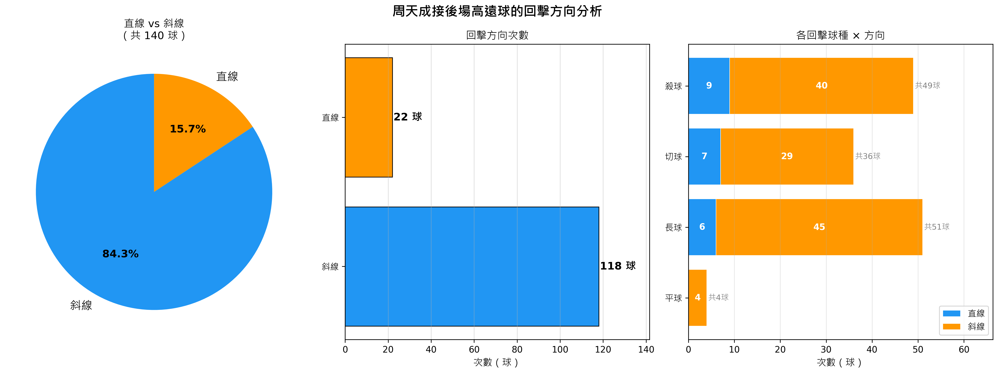

In [ ]:
# ==========================================
# 分析：周天成接後場高遠球的回擊方向（直線 vs 斜線）
# ==========================================

import numpy as np

# 後場區域定義
back_court_zones = [1, 2, 3, 4]

# 欄位（Column）定義：依據 Court Grid Definitions
# Col A: 1,5,9,13,17,21
# Col B: 2,6,10,14,18,22
# Col C: 3,7,11,15,19,23
# Col D: 4,8,12,16,20,24
col_map = {}
for i, cols in enumerate([[1,5,9,13,17,21],
                           [2,6,10,14,18,22],
                           [3,7,11,15,19,23],
                           [4,8,12,16,20,24]], start=1):
    for z in cols:
        col_map[z] = i  # 1=A, 2=B, 3=C, 4=D

print("=== 欄位對照表 ===")
print("Col A(1):", [1,5,9,13,17,21])
print("Col B(2):", [2,6,10,14,18,22])
print("Col C(3):", [3,7,11,15,19,23])
print("Col D(4):", [4,8,12,16,20,24])
print()

# 資料驗證
print(f"資料總筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空"

# ==========================================
# Step 1: 在完整 df 上建立 shift 欄位（避免跨 rally 污染）
# ==========================================
# 先依 match_id, set, rally, ball_round 排序（Schema 說已排序，但確認）
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

grp = df_sorted.groupby(['match_id', 'set', 'rally'])

# 「下一拍」資訊
df_sorted['next_player']       = grp['player'].shift(-1)
df_sorted['next_type']         = grp['type'].shift(-1)
df_sorted['next_hit_area']     = grp['hit_area'].shift(-1)
df_sorted['next_landing_area'] = grp['landing_area'].shift(-1)
df_sorted['next_landing_x']    = grp['landing_x'].shift(-1)
df_sorted['next_landing_y']    = grp['landing_y'].shift(-1)
df_sorted['next_hit_x']        = grp['hit_x'].shift(-1)
df_sorted['next_hit_y']        = grp['hit_y'].shift(-1)

print(f"shift 欄位建立完成，排序後筆數: {len(df_sorted)}")

# ==========================================
# Step 2: 篩選「對手打出的後場高遠球」
# 條件：
#   - type == '長球'（高遠球）
#   - landing_area 在後場 [1,2,3,4]
#   - player != 'CHOU Tien Chen'（對手打的，非周天成）
#   - 下一拍 player == 'CHOU Tien Chen'（周天成接球）
# ==========================================
chou = 'CHOU Tien Chen'

mask_opponent_long = (
    (df_sorted['player'] != chou) &            # 對手打的
    (df_sorted['type'] == '長球') &             # 球種為長球（高遠球）
    (df_sorted['landing_area'].isin(back_court_zones)) &  # 落點在後場
    (df_sorted['next_player'] == chou)          # 下一拍是周天成回擊
)

opponent_long_shots = df_sorted[mask_opponent_long].copy()
print(f"\n對手打出後場高遠球（下一拍為周天成）的筆數: {len(opponent_long_shots)}")

# ==========================================
# Step 3: 取得周天成的回擊資訊
# 回擊的 hit_area = 對手落點 ≈ next_hit_area
# 回擊的 landing_area = next_landing_area
# ==========================================
# 周天成回擊：hit_area 用 next_hit_area，landing_area 用 next_landing_area
chou_return = opponent_long_shots[['match_id','set','rally','ball_round',
                                    'landing_area',       # 對手落點 = 周天成擊球區
                                    'next_hit_area',       # 周天成擊球點
                                    'next_landing_area',   # 周天成落點
                                    'next_type',           # 周天成回擊球種
                                    'next_hit_x', 'next_hit_y',
                                    'next_landing_x', 'next_landing_y']].copy()

chou_return.rename(columns={
    'next_hit_area': 'chou_hit_area',
    'next_landing_area': 'chou_landing_area',
    'next_type': 'chou_type',
    'next_hit_x': 'chou_hit_x',
    'next_hit_y': 'chou_hit_y',
    'next_landing_x': 'chou_landing_x',
    'next_landing_y': 'chou_landing_y',
}, inplace=True)

print(f"周天成回擊筆數（原始）: {len(chou_return)}")

# ==========================================
# Step 4: 排除缺值（hit_area 或 landing_area 為 NaN）
# ==========================================
chou_return_valid = chou_return.dropna(subset=['chou_hit_area', 'chou_landing_area'])
print(f"周天成回擊筆數（有效）: {len(chou_return_valid)}")

# ==========================================
# Step 5: 判斷直線 vs 斜線
# 使用 hit_area 欄（Col）和 landing_area 欄（Col）
# 排除出界 zone（25-32）：出界 zone 不在 col_map 中
# ==========================================
valid_zones = set(col_map.keys())  # 1~24

# 過濾掉 hit 或 landing 在出界區的情況
mask_valid_zone = (
    chou_return_valid['chou_hit_area'].isin(valid_zones) &
    chou_return_valid['chou_landing_area'].isin(valid_zones)
)
chou_return_clean = chou_return_valid[mask_valid_zone].copy()
print(f"周天成回擊筆數（排除出界區後）: {len(chou_return_clean)}")

# 計算欄（Column）
chou_return_clean['hit_col'] = chou_return_clean['chou_hit_area'].map(col_map)
chou_return_clean['land_col'] = chou_return_clean['chou_landing_area'].map(col_map)

# 直線：同欄；斜線：不同欄
chou_return_clean['direction'] = np.where(
    chou_return_clean['hit_col'] == chou_return_clean['land_col'],
    '直線', '斜線'
)

print(f"\n方向欄 NaN 數: {chou_return_clean['direction'].isna().sum()}")
print(f"方向分布:\n{chou_return_clean['direction'].value_counts()}")

# ==========================================
# Step 6: 統計次數與比例
# ==========================================
direction_counts = chou_return_clean['direction'].value_counts()
direction_pct    = chou_return_clean['direction'].value_counts(normalize=True) * 100

summary = pd.DataFrame({
    '次數': direction_counts,
    '比例(%)': direction_pct.round(1)
})
print("\n=== 周天成接後場高遠球回擊方向統計 ===")
print(summary)
print(f"\n總計: {len(chou_return_clean)} 球")

# ==========================================
# Step 7: 進一步分析 — 按回擊球種分解
# ==========================================
type_dir = chou_return_clean.groupby(['chou_type', 'direction']).size().unstack(fill_value=0)
print("\n=== 按回擊球種 × 方向 ===")
print(type_dir)

# ==========================================
# Step 8: 視覺化
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle("周天成接後場高遠球的回擊方向分析", fontsize=15, fontweight='bold')

# --- 子圖 1: 直線 vs 斜線 圓餅圖 ---
ax1 = axes[0]
colors_pie = ['#2196F3', '#FF9800']
wedges, texts, autotexts = ax1.pie(
    direction_counts.values,
    labels=direction_counts.index,
    autopct='%1.1f%%',
    colors=colors_pie,
    startangle=90,
    textprops={'fontsize': 13}
)
for at in autotexts:
    at.set_fontsize(12)
    at.set_fontweight('bold')
ax1.set_title(f"直線 vs 斜線\n（共 {len(chou_return_clean)} 球）", fontsize=12)

# --- 子圖 2: 橫向長條圖 次數比較 ---
ax2 = axes[1]
bars = ax2.barh(
    direction_counts.index,
    direction_counts.values,
    color=colors_pie,
    edgecolor='black',
    linewidth=0.8
)
for bar, val in zip(bars, direction_counts.values):
    ax2.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
             f'{val} 球', va='center', ha='left', fontsize=12, fontweight='bold')
ax2.set_xlabel('次數（球）', fontsize=11)
ax2.set_title('回擊方向次數', fontsize=12)
ax2.set_xlim(0, direction_counts.max() * 1.2)
ax2.grid(axis='x', alpha=0.4)

# --- 子圖 3: 各球種回擊方向堆疊長條（水平）---
ax3 = axes[2]
# 確保欄位存在
for col_name in ['直線', '斜線']:
    if col_name not in type_dir.columns:
        type_dir[col_name] = 0

type_dir_plot = type_dir[['直線', '斜線']].copy()
type_dir_plot = type_dir_plot.sort_values('直線', ascending=True)

bar_colors = ['#2196F3', '#FF9800']
bottoms = np.zeros(len(type_dir_plot))
bar_labels = ['直線', '斜線']

for i, (col_name, color) in enumerate(zip(['直線', '斜線'], bar_colors)):
    vals = type_dir_plot[col_name].values
    bars3 = ax3.barh(
        type_dir_plot.index,
        vals,
        left=bottoms,
        color=color,
        label=col_name,
        edgecolor='white',
        linewidth=0.5
    )
    # 標記數值（若該段夠寬）
    for bar, v, b in zip(bars3, vals, bottoms):
        if v > 0:
            ax3.text(b + v / 2, bar.get_y() + bar.get_height()/2,
                     f'{v}', ha='center', va='center',
                     fontsize=10, color='white', fontweight='bold')
    bottoms += vals

# 加總標籤
totals = type_dir_plot['直線'] + type_dir_plot['斜線']
for i, (total, idx) in enumerate(zip(totals.values, type_dir_plot.index)):
    ax3.text(total + 0.3, i, f'共{total}球', va='center', fontsize=9, color='gray')

ax3.set_xlabel('次數（球）', fontsize=11)
ax3.set_title('各回擊球種 × 方向', fontsize=12)
ax3.legend(loc='lower right', fontsize=10)
ax3.set_xlim(0, totals.max() * 1.3)
ax3.grid(axis='x', alpha=0.3)

plt.tight_layout()

# ==========================================
# 最終輸出
# ==========================================
print("\n" + "="*50)
print("【最終統計摘要】")
print("="*50)
print(f"分析對象: {chou}")
print(f"條件: 接對手後場高遠球（長球，落點 Zone 1-4）")
print(f"有效回擊球數: {len(chou_return_clean)}")
print()
for direction in ['直線', '斜線']:
    count = direction_counts.get(direction, 0)
    pct   = direction_pct.get(direction, 0)
    print(f"  {direction}: {count} 球 ({pct:.1f}%)")
print()
print("【各球種明細】")
print(type_dir_plot[['直線','斜線']].to_string())


### 數據洞察
# 周天成接後場高遠球回擊方向分析

## 核心數據

| 方向 | 次數 | 比例 |
|------|------|------|
| 斜線 | 118球 | **84.3%** |
| 直線 | 22球 | **15.7%** |

**有效樣本：140球**

---

## 各球種方向拆解

| 球種 | 直線 | 斜線 | 斜線佔比 |
|------|------|------|----------|
| 長球 | 6 | 45 | 88.2% |
| 殺球 | 9 | 40 | 81.6% |
| 切球 | 7 | 29 | 80.6% |
| 平球 | 0 | 4 | 100% |

---

## 戰術洞察

**斜線是周天成接高遠球的壓倒性首選，無論哪種回擊球種皆然。**

- **斜線偏好一致性極高**：四種球種斜線佔比均超過80%，代表這不是隨機選擇，而是系統性習慣。
- **殺球直線比例相對最高（18.4%）**：殺球走直線具突然性，是他少數使用直線的主要場景。
- **平球全走斜線（4/4）**：樣本雖小，但平球完全不走直線，顯示平球用於斜線調動的固定思路。
- **對手可利用的弱點**：對手若預判斜線站位，可有效壓縮周天成的回擊空間；直線防守反而是相對空檔。

> **建議對手策略**：打後場高遠球後，優先封斜線出球路線，逼迫周天成走直線，打破其慣性節奏。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都分析了周天成接到後場高遠球時的回擊方向，並使用了類似的欄位和篩選條件來確定對手的長球落點和周天成的回擊方向。候選程式碼正確地使用了欄位語意，並在同一個 rally 中對齊前後拍資訊，最終輸出直線與斜線的比例，與 Reference Code 1 的分析目標一致。




## 題號 70
**問題**: 當周天成連續得分 3 分以上時，他的球種選擇是否變得更激進？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


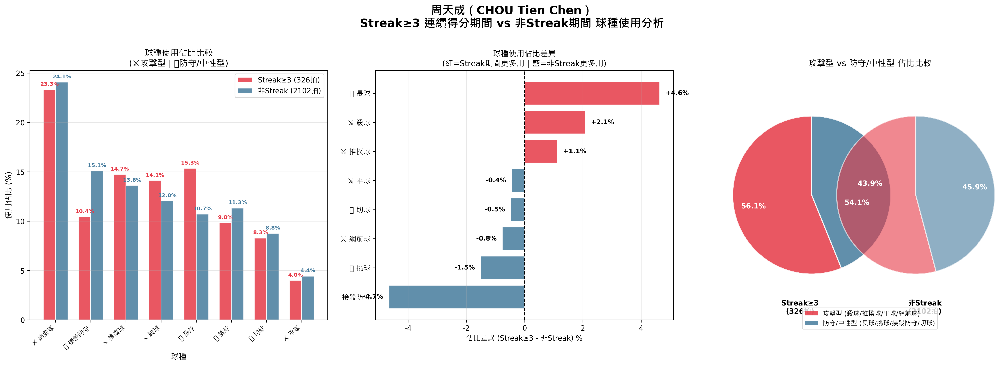

In [ ]:
import numpy as np

# =============================================
# Step 0: 驗證資料
# =============================================
print(f"總資料筆數: {len(df)}")
print(f"總回合數: {df.groupby(['match_id', 'set', 'rally']).ngroups}")
print(f"球員列表: {df['player'].unique()}")

TARGET = 'CHOU Tien Chen'
STREAK_THRESHOLD = 3

# =============================================
# Step 1: 每個 rally 的得分者（取最後一拍）
# =============================================
rally_result = (
    df.groupby(['match_id', 'set', 'rally'])
    .last()
    .reset_index()[['match_id', 'set', 'rally', 'getpoint_player']]
)

# 只考慮有明確得分者的 rally（排除 NULL）
rally_result = rally_result.dropna(subset=['getpoint_player'])
print(f"\n有明確得分者的 rally 數: {len(rally_result)}")
print(f"周天成得分 rally 數: {(rally_result['getpoint_player'] == TARGET).sum()}")

# =============================================
# Step 2: 在每個 (match_id, set) 內計算連續得分串
# =============================================
# 標記是否為目標選手得分
rally_result = rally_result.sort_values(['match_id', 'set', 'rally']).reset_index(drop=True)
rally_result['is_target_win'] = (rally_result['getpoint_player'] == TARGET).astype(int)

# 計算每個 (match_id, set) 內的連續得分串 group ID
# 使用 cumsum 技術：每次非目標選手得分時，streak group 號碼會改變
def label_streaks(group):
    """
    對每個 (match_id, set) 的 rally 序列，標記連續得分串
    """
    group = group.copy()
    # 當 is_target_win 從 1 變 0 或從 0 變 1 時，視為新的組
    # 使用 cumsum: 每次 is_target_win != shift(1) 時 +1
    change = group['is_target_win'] != group['is_target_win'].shift(1).fillna(-1)
    group['streak_group'] = change.cumsum()
    return group

rally_result = rally_result.groupby(['match_id', 'set'], group_keys=False).apply(label_streaks)

# 計算每個 streak_group 的長度
streak_group_size = (
    rally_result
    .groupby(['match_id', 'set', 'streak_group'])
    .agg(
        streak_len=('is_target_win', 'sum'),       # 連續得分筆數（只有 is_target_win=1 的才有意義）
        group_count=('is_target_win', 'count'),     # 該組 rally 數
        is_win_group=('is_target_win', 'first')     # 這組是不是得分組
    )
    .reset_index()
)

print("\n--- 連續得分串統計（長度 ≥ 3）---")
win_streaks = streak_group_size[streak_group_size['is_win_group'] == 1].copy()
print(win_streaks['streak_len'].value_counts().sort_index())
print(f"\n連續得分 ≥ {STREAK_THRESHOLD} 的 streak 群數: {(win_streaks['streak_len'] >= STREAK_THRESHOLD).sum()}")
print(f"這些 streak 涵蓋的 rally 總數: {win_streaks.loc[win_streaks['streak_len'] >= STREAK_THRESHOLD, 'streak_len'].sum()}")

# =============================================
# Step 3: 標記每個 rally 是否屬於 streak ≥ 3
# =============================================
# 將 streak_len 資訊 merge 回 rally_result
rally_result = rally_result.merge(
    streak_group_size[['match_id', 'set', 'streak_group', 'streak_len', 'is_win_group']],
    on=['match_id', 'set', 'streak_group'],
    how='left'
)

# 標記條件：
# - 該組是得分組 (is_win_group == 1)
# - 該組連續得分長度 >= STREAK_THRESHOLD
rally_result['in_streak_ge3'] = (
    (rally_result['is_win_group'] == 1) &
    (rally_result['streak_len'] >= STREAK_THRESHOLD)
)

print(f"\n屬於 streak≥3 的 rally 數: {rally_result['in_streak_ge3'].sum()}")
print(f"不屬於 streak≥3 的 rally 數: {(~rally_result['in_streak_ge3']).sum()}")

# =============================================
# Step 4: 建立 rally → streak 標記的對應表（包含所有 rally，含無得分者）
# =============================================
# 注意：rally_result 已排除無得分者的 rally
# stroke-level 分析只需要 CHOU Tien Chen 的擊球，join rally 標記

rally_label = rally_result[['match_id', 'set', 'rally', 'in_streak_ge3']].copy()

# 將標記 merge 回 stroke-level df
df_merged = df.merge(rally_label, on=['match_id', 'set', 'rally'], how='left')

# 無法 join 到的 rally（getpoint_player 為 NULL 的 rally 中的擊球）標記為非 streak
df_merged['in_streak_ge3'] = df_merged['in_streak_ge3'].fillna(False)

print(f"\nmerge 後筆數: {len(df_merged)}")
print(f"in_streak_ge3=True 筆數: {df_merged['in_streak_ge3'].sum()}")

# =============================================
# Step 5: 只取周天成的擊球，排除發球球種
# =============================================
chou_shots = df_merged[
    (df_merged['player'] == TARGET) &
    (~df_merged['type'].isin(['發短球', '發長球']))
].copy()

print(f"\n周天成非發球擊球筆數: {len(chou_shots)}")
print(f"  - streak≥3 期間: {chou_shots['in_streak_ge3'].sum()}")
print(f"  - 非streak 期間: {(~chou_shots['in_streak_ge3']).sum()}")

# =============================================
# Step 6: 球種使用頻率與佔比統計
# =============================================
# 定義攻擊性分類
attack_types = ['殺球', '推撲球', '平球', '網前球']
defense_types = ['長球', '挑球', '接殺防守', '切球']

def classify_aggression(shot_type):
    if shot_type in attack_types:
        return '攻擊型'
    elif shot_type in defense_types:
        return '防守/中性型'
    else:
        return '其他'

chou_shots['aggression'] = chou_shots['type'].apply(classify_aggression)

# 分組統計
streak_shots = chou_shots[chou_shots['in_streak_ge3'] == True]
non_streak_shots = chou_shots[chou_shots['in_streak_ge3'] == False]

# 球種分佈
def shot_distribution(shots_df, label):
    dist = shots_df['type'].value_counts()
    pct = shots_df['type'].value_counts(normalize=True) * 100
    result = pd.DataFrame({'次數': dist, '佔比(%)': pct.round(2)})
    result.index.name = '球種'
    result['時段'] = label
    return result

streak_dist = shot_distribution(streak_shots, f'streak≥{STREAK_THRESHOLD}期間')
non_streak_dist = shot_distribution(non_streak_shots, '非streak期間')

print("\n" + "="*60)
print(f"【streak≥3 期間】周天成球種分佈 (共 {len(streak_shots)} 拍)")
print("="*60)
print(streak_dist[['次數', '佔比(%)']].to_string())

print("\n" + "="*60)
print(f"【非 streak 期間】周天成球種分佈 (共 {len(non_streak_shots)} 拍)")
print("="*60)
print(non_streak_dist[['次數', '佔比(%)']].to_string())

# 攻擊性佔比比較
streak_agg_pct = streak_shots['aggression'].value_counts(normalize=True) * 100
non_streak_agg_pct = non_streak_shots['aggression'].value_counts(normalize=True) * 100

print("\n" + "="*60)
print("【攻擊性球種佔比比較】")
print("="*60)
agg_df = pd.DataFrame({
    f'streak≥3 (%)': streak_agg_pct,
    '非streak (%)': non_streak_agg_pct
}).fillna(0).round(2)
print(agg_df.to_string())

streak_attack_pct = streak_agg_pct.get('攻擊型', 0)
non_streak_attack_pct = non_streak_agg_pct.get('攻擊型', 0)
print(f"\n攻擊型球種佔比: streak≥3 = {streak_attack_pct:.1f}% vs 非streak = {non_streak_attack_pct:.1f}%")
print(f"差異: {streak_attack_pct - non_streak_attack_pct:+.1f}%")

# =============================================
# Step 7: 視覺化
# =============================================
# 整合所有球種（確保兩組都有相同球種）
all_types = chou_shots['type'].unique()
all_types_order = chou_shots['type'].value_counts().index.tolist()  # 依總使用量排序

# 建立比較表
streak_pct_full = streak_shots['type'].value_counts(normalize=True) * 100
non_streak_pct_full = non_streak_shots['type'].value_counts(normalize=True) * 100

compare_df = pd.DataFrame({
    'streak≥3期間': streak_pct_full,
    '非streak期間': non_streak_pct_full
}, index=all_types_order).fillna(0)

# 攻擊型標記
attack_marker = ['⚔' if t in attack_types else '🛡' for t in compare_df.index]
compare_df.index = [f"{m} {t}" for m, t in zip(attack_marker, compare_df.index)]

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
fig.suptitle(f'周天成（CHOU Tien Chen）\nStreak≥3 連續得分期間 vs 非Streak期間 球種使用分析',
             fontsize=16, fontweight='bold', y=1.01)

# --- 圖1: 分組長條圖 (球種使用佔比比較) ---
ax1 = axes[0]
x = np.arange(len(compare_df))
width = 0.35
colors_streak = '#E63946'
colors_non = '#457B9D'

bars1 = ax1.bar(x - width/2, compare_df['streak≥3期間'], width,
                label=f'Streak≥{STREAK_THRESHOLD} ({len(streak_shots)}拍)',
                color=colors_streak, alpha=0.85, edgecolor='white')
bars2 = ax1.bar(x + width/2, compare_df['非streak期間'], width,
                label=f'非Streak ({len(non_streak_shots)}拍)',
                color=colors_non, alpha=0.85, edgecolor='white')

ax1.set_xlabel('球種', fontsize=11)
ax1.set_ylabel('使用佔比 (%)', fontsize=11)
ax1.set_title('球種使用佔比比較\n(⚔攻擊型 | 🛡防守/中性型)', fontsize=12)
ax1.set_xticks(x)
ax1.set_xticklabels(compare_df.index, rotation=40, ha='right', fontsize=9)
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.3)

# 標示數值
for bar in bars1:
    h = bar.get_height()
    if h > 1:
        ax1.text(bar.get_x() + bar.get_width()/2, h + 0.3, f'{h:.1f}%',
                 ha='center', va='bottom', fontsize=7.5, color=colors_streak, fontweight='bold')
for bar in bars2:
    h = bar.get_height()
    if h > 1:
        ax1.text(bar.get_x() + bar.get_width()/2, h + 0.3, f'{h:.1f}%',
                 ha='center', va='bottom', fontsize=7.5, color=colors_non, fontweight='bold')

# --- 圖2: 攻擊性球種佔比 (Donut Charts 並列) ---
ax2 = axes[1]

# 計算差異：streak vs 非streak
diff_df = (compare_df['streak≥3期間'] - compare_df['非streak期間']).sort_values()
colors_diff = ['#E63946' if v > 0 else '#457B9D' for v in diff_df.values]
bars_diff = ax2.barh(diff_df.index, diff_df.values, color=colors_diff, alpha=0.85, edgecolor='white')
ax2.axvline(x=0, color='black', linewidth=1.2, linestyle='--')
ax2.set_xlabel('佔比差異 (Streak≥3 - 非Streak) %', fontsize=10)
ax2.set_title('球種使用佔比差異\n(紅=Streak期間更多用 | 藍=非Streak更多用)', fontsize=11)
ax2.grid(axis='x', alpha=0.3)
for bar, val in zip(bars_diff, diff_df.values):
    ax2.text(val + (0.2 if val >= 0 else -0.2),
             bar.get_y() + bar.get_height()/2,
             f'{val:+.1f}%', va='center',
             ha='left' if val >= 0 else 'right',
             fontsize=9, fontweight='bold')

# --- 圖3: 攻擊性分類圓餅圖比較 ---
ax3 = axes[2]

agg_labels = ['攻擊型', '防守/中性型']
streak_agg_vals = [streak_agg_pct.get(l, 0) for l in agg_labels]
non_streak_agg_vals = [non_streak_agg_pct.get(l, 0) for l in agg_labels]

x_pos = [0.22, 0.72]
pie_data = [streak_agg_vals, non_streak_agg_vals]
pie_titles = [f'Streak≥3\n({len(streak_shots)}拍)', f'非Streak\n({len(non_streak_shots)}拍)']
pie_colors = [['#E63946', '#457B9D'], ['#E63946', '#457B9D']]

for i, (pos, data, title, clr) in enumerate(zip(x_pos, pie_data, pie_titles, pie_colors)):
    wedges, texts, autotexts = ax3.pie(
        data,
        labels=None,
        autopct='%1.1f%%',
        colors=clr,
        startangle=90,
        pctdistance=0.75,
        wedgeprops={'alpha': 0.85 if i == 0 else 0.6, 'edgecolor': 'white', 'linewidth': 1.5},
        center=(pos, 0.5),
        radius=0.38,
        frame=True
    )
    for at in autotexts:
        at.set_fontsize(10)
        at.set_fontweight('bold')
        at.set_color('white')
    ax3.text(pos, 0.05, title, ha='center', va='center', fontsize=10, fontweight='bold',
             transform=ax3.transAxes)

# 修正：用 transAxes 座標清楚標示標題
ax3.set_xlim(-0.1, 1.1)
ax3.set_ylim(-0.1, 1.1)
ax3.axis('off')
ax3.set_title('攻擊型 vs 防守/中性型 佔比比較', fontsize=12)

# 手動加圖例
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#E63946', alpha=0.85, label='攻擊型 (殺球/推撲球/平球/網前球)'),
                   Patch(facecolor='#457B9D', alpha=0.85, label='防守/中性型 (長球/挑球/接殺防守/切球)')]
ax3.legend(handles=legend_elements, loc='lower center', fontsize=9,
           bbox_to_anchor=(0.5, -0.05))

plt.tight_layout()

# =============================================
# Step 8: 最終結論判斷
# =============================================
print("\n" + "="*60)
print("【最終分析結論】")
print("="*60)
print(f"攻擊型球種定義: {attack_types}")
print(f"防守/中性型球種定義: {defense_types}")
print(f"\n• Streak≥3 期間攻擊型佔比: {streak_attack_pct:.1f}%")
print(f"• 非Streak 期間攻擊型佔比: {non_streak_attack_pct:.1f}%")
if streak_attack_pct > non_streak_attack_pct + 2:
    print(f"➜ 結論: Streak≥3 期間明顯更具攻擊性（差距 {streak_attack_pct - non_streak_attack_pct:.1f}%）")
elif streak_attack_pct < non_streak_attack_pct - 2:
    print(f"➜ 結論: Streak≥3 期間反而較不具攻擊性（差距 {streak_attack_pct - non_streak_attack_pct:.1f}%）")
else:
    print(f"➜ 結論: 兩個時段攻擊性球種佔比差異不顯著（差距 {streak_attack_pct - non_streak_attack_pct:.1f}%）")

# 找出最顯著差異球種
top_diff = (compare_df['streak≥3期間'] - compare_df['非streak期間']).abs().nlargest(3)
print(f"\n• 差異最大的前三球種:")
for shot, diff_val in top_diff.items():
    s_val = compare_df.loc[shot, 'streak≥3期間']
    n_val = compare_df.loc[shot, '非streak期間']
    print(f"  - {shot}: Streak={s_val:.1f}% vs 非Streak={n_val:.1f}% (差距{s_val-n_val:+.1f}%)")


### 數據洞察
# 周天成連續得分期間球種分析

## 核心數據

| 球種 | Streak≥3 | 非Streak | 差異 |
|------|----------|----------|------|
| 網前球 | 23.3% | 24.1% | -0.8% |
| 長球 | **15.3%** | 10.7% | **+4.6%** |
| 推撲球 | 14.7% | 13.6% | +1.1% |
| 殺球 | **14.1%** | 12.0% | **+2.1%** |
| 接殺防守 | 10.4% | **15.1%** | **-4.7%** |
| 挑球 | 9.8% | 11.3% | -1.5% |
| 切球 | 8.3% | 8.8% | -0.5% |
| 平球 | 4.0% | 4.4% | -0.4% |

**攻擊型佔比：56.1% vs 54.1%（差距僅 +2.0%）**

---

## 戰術洞察

**1. 攻擊性整體無顯著提升**
兩個時段攻擊型球種佔比幾乎相同，代表周天成的連續得分**不是靠風格轉變換來的**，而是在既有打法下執行品質提升。

**2. 最關鍵差異：接殺防守大幅減少（-4.7%）**
Streak 期間他被殺球的頻率明顯降低，說明他**主動控制了球的節奏**，讓對手較少進入殺球機會，這才是連分的核心原因。

**3. 長球使用增加（+4.6%）是主動選擇**
Streak 期間長球增加，搭配殺球提升，顯示他**刻意以長球調動桃田後場，再尋找殺球時機**，是有意識的戰術組合。

**4. 結論**
> 周天成的連分模式是「**減少被動、強化場控**」，而非單純打更多攻擊球。長球→殺球的組合搭配接殺防守大減，才是他拿下連分的真正戰術邏輯。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地識別了周天成連續得分的情況，並分析了在這些情況下的球種選擇是否更激進。候選程式碼使用了與 Reference Code 1 類似的步驟來計算連續得分串，並將這些資訊合併回原始資料以進行球種分析。最終，它也提供了球種使用頻率和佔比的統計，並進行了合理的視覺化和結論判斷。




## 題號 71
**問題**: 分析周天成在自己領先時與落後時，網前球的使用比例差異。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


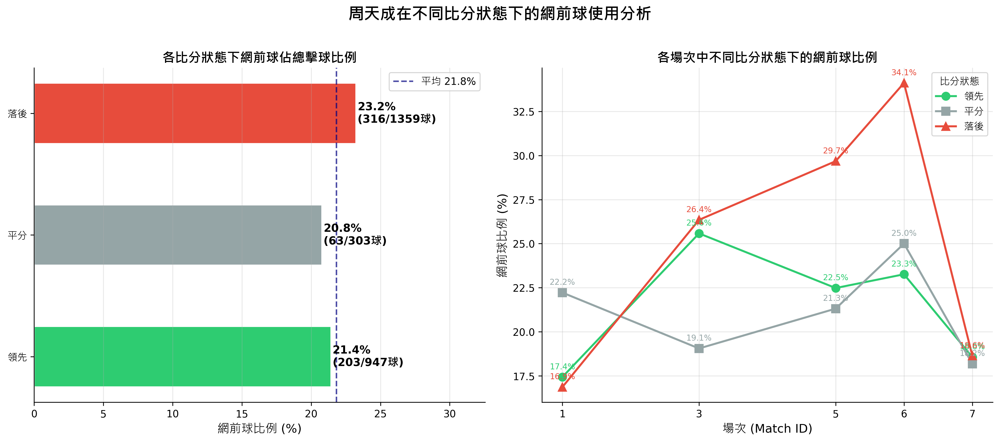

In [ ]:
import numpy as np

# ============================================================
# 0. 基本驗證
# ============================================================
print(f"資料總列數: {len(df)}")
assert len(df) > 0, "資料為空！"

# ============================================================
# 1. 篩選周天成的所有擊球
# ============================================================
chou_df = df[df['player'] == 'CHOU Tien Chen'].copy()
print(f"\n周天成總擊球數: {len(chou_df)}")

# ============================================================
# 2. 確認比分欄位
# ============================================================
print(f"\n比分欄位範例（前5筆）：")
print(chou_df[['match_id', 'set', 'rally', 'ball_round',
               'CHOU Tien Chen_score', 'Kento MOMOTA_score', 'type']].head(10))

# ============================================================
# 3. 判斷比分狀態（依每一球發生時的當下比分）
# ============================================================
chou_score = chou_df['CHOU Tien Chen_score']
momota_score = chou_df['Kento MOMOTA_score']

conditions = [
    chou_score > momota_score,   # 領先
    chou_score < momota_score,   # 落後
    chou_score == momota_score   # 平分
]
choices = ['領先', '落後', '平分']

chou_df['score_status'] = np.select(conditions, choices, default='未知')

# 確認分佈
status_dist = chou_df['score_status'].value_counts()
print(f"\n比分狀態分佈（周天成擊球數）：")
print(status_dist)

# ============================================================
# 4. 計算各比分狀態下網前球的比例
# ============================================================
# 定義網前球
NET_SHOT = '網前球'

# 計算各狀態的總擊球數與網前球數
results = []
for status in ['領先', '落後', '平分']:
    subset = chou_df[chou_df['score_status'] == status]
    total_shots = len(subset)
    net_shots = (subset['type'] == NET_SHOT).sum()
    ratio = net_shots / total_shots * 100 if total_shots > 0 else 0
    results.append({
        '比分狀態': status,
        '總擊球數': total_shots,
        '網前球次數': net_shots,
        '網前球比例(%)': round(ratio, 2)
    })

results_df = pd.DataFrame(results)
print("\n" + "="*55)
print("周天成在不同比分狀態下的網前球使用比例")
print("="*55)
print(results_df.to_string(index=False))
print("="*55)

# ============================================================
# 5. 額外分析：按比賽場次拆解（match_id）
# ============================================================
print("\n【各場次拆解】")
match_results = []
for match_id in sorted(chou_df['match_id'].unique()):
    match_subset = chou_df[chou_df['match_id'] == match_id]
    for status in ['領先', '落後', '平分']:
        subset = match_subset[match_subset['score_status'] == status]
        total_shots = len(subset)
        net_shots = (subset['type'] == NET_SHOT).sum()
        ratio = net_shots / total_shots * 100 if total_shots > 0 else 0
        match_results.append({
            '場次(match_id)': int(match_id),
            '比分狀態': status,
            '總擊球數': total_shots,
            '網前球次數': net_shots,
            '網前球比例(%)': round(ratio, 2)
        })

match_results_df = pd.DataFrame(match_results)
print(match_results_df.to_string(index=False))

# ============================================================
# 6. 視覺化
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("周天成在不同比分狀態下的網前球使用分析", fontsize=16, fontweight='bold', y=1.02)

# --- 圖1: 主要結果 - 橫條圖（清晰比較三種狀態）---
ax1 = axes[0]
status_order = ['領先', '平分', '落後']
ratios = [results_df[results_df['比分狀態'] == s]['網前球比例(%)'].values[0] for s in status_order]
counts = [results_df[results_df['比分狀態'] == s]['總擊球數'].values[0] for s in status_order]
net_counts = [results_df[results_df['比分狀態'] == s]['網前球次數'].values[0] for s in status_order]

colors = ['#2ecc71', '#95a5a6', '#e74c3c']  # 綠=領先, 灰=平分, 紅=落後
bars = ax1.barh(status_order, ratios, color=colors, edgecolor='white', linewidth=1.5, height=0.5)

# 在 bar 上標示數值與樣本數
for i, (bar, ratio, total, net) in enumerate(zip(bars, ratios, counts, net_counts)):
    ax1.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
             f'{ratio:.1f}%\n({net}/{total}球)',
             va='center', ha='left', fontsize=11, fontweight='bold')

ax1.set_xlabel('網前球比例 (%)', fontsize=12)
ax1.set_title('各比分狀態下網前球佔總擊球比例', fontsize=13, fontweight='bold')
ax1.set_xlim(0, max(ratios) * 1.4 if max(ratios) > 0 else 10)
ax1.axvline(x=np.mean(ratios), color='navy', linestyle='--', linewidth=1.5, alpha=0.7,
            label=f'平均 {np.mean(ratios):.1f}%')
ax1.legend(fontsize=10)
ax1.grid(axis='x', alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# --- 圖2: 各場次折線圖（按比分狀態）---
ax2 = axes[1]
pivot_df = match_results_df.pivot(index='場次(match_id)', columns='比分狀態', values='網前球比例(%)')
# 確保欄位順序
for col in ['領先', '平分', '落後']:
    if col not in pivot_df.columns:
        pivot_df[col] = 0

pivot_df = pivot_df[['領先', '平分', '落後']]
status_colors = {'領先': '#2ecc71', '平分': '#95a5a6', '落後': '#e74c3c'}
markers = {'領先': 'o', '平分': 's', '落後': '^'}

for status in ['領先', '平分', '落後']:
    valid = match_results_df[(match_results_df['比分狀態'] == status) & (match_results_df['總擊球數'] > 0)]
    ax2.plot(valid['場次(match_id)'].astype(int), valid['網前球比例(%)'],
             marker=markers[status], color=status_colors[status],
             linewidth=2, markersize=8, label=status)
    # 標示數值
    for _, row in valid.iterrows():
        ax2.annotate(f"{row['網前球比例(%)']:.1f}%",
                     xy=(row['場次(match_id)'], row['網前球比例(%)']),
                     xytext=(0, 8), textcoords='offset points',
                     ha='center', fontsize=8, color=status_colors[status])

ax2.set_xlabel('場次 (Match ID)', fontsize=12)
ax2.set_ylabel('網前球比例 (%)', fontsize=12)
ax2.set_title('各場次中不同比分狀態下的網前球比例', fontsize=13, fontweight='bold')
ax2.set_xticks(sorted(chou_df['match_id'].unique().astype(int)))
ax2.legend(title='比分狀態', fontsize=10)
ax2.grid(alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()

# ============================================================
# 7. 補充：打印總覽與差異摘要
# ============================================================
print("\n" + "="*55)
print("【差異摘要】")
lead_ratio = results_df[results_df['比分狀態'] == '領先']['網前球比例(%)'].values[0]
behind_ratio = results_df[results_df['比分狀態'] == '落後']['網前球比例(%)'].values[0]
tie_ratio = results_df[results_df['比分狀態'] == '平分']['網前球比例(%)'].values[0]
print(f"領先時網前球比例:  {lead_ratio:.2f}%")
print(f"落後時網前球比例:  {behind_ratio:.2f}%")
print(f"平分時網前球比例:  {tie_ratio:.2f}%")
print(f"領先 vs 落後 差異: {lead_ratio - behind_ratio:+.2f}% (正值=領先時使用更多)")
print(f"領先 vs 平分 差異: {lead_ratio - tie_ratio:+.2f}%")
print(f"平分 vs 落後 差異: {tie_ratio - behind_ratio:+.2f}%")
print("="*55)


### 數據洞察
# 周天成網前球使用分析：比分狀態影響

## 核心數據

| 比分狀態 | 擊球數 | 網前球次數 | 網前球比例 |
|:---:|:---:|:---:|:---:|
| 領先 | 947 | 203 | **21.44%** |
| 平分 | 303 | 63 | **20.79%** |
| 落後 | 1,359 | 316 | **23.25%** |

---

## 戰術洞察

**落後時網前球使用率最高（23.25%），比領先時高出1.81個百分點。**

### 關鍵觀察

**① 落後時傾向拉近網前**
落後狀態下擊球數高達1,359球（佔總擊球52%），顯示周天成在比賽中落後時間居多，且此時網前球比例最高——這是典型的**主動製造機會、縮短拍數**策略。

**② 場次6最具代表性**
落後時網前球比例高達**34.12%**，遠超其他場次，顯示該場次落後時壓力明顯，試圖以網前球打亂對手節奏。

**③ 場次7最穩定**
三種狀態比例幾乎相同（18.18%～18.64%），說明該場次周天成網前球策略不受比分影響，執行最為一致。

**④ 平分時最保守**
平分時比例最低（20.79%），符合**穩健持球、減少風險**的邏輯。

---

## 教練結論

> 周天成在落後時確實會**提高網前球頻率**，但差異僅約1.8%，整體策略調整幅度有限。若要在落後時更有效翻盤，可考慮更積極拉大網前球比例差距，搭配假動作增加壓迫性。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成的擊球，並根據比分狀態（領先、落後、平分）計算了網前球的使用比例。分析對象、欄位語意、篩選條件、分組層級、統計口徑和最終輸出目標都與 Reference Code 1 一致。候選程式碼還進一步提供了按比賽場次的詳細分析，這是額外的分析，不影響核心邏輯的正確性。




## 題號 72 (*)
**問題**: 在網前互相推撥情況下，周天成的勝率是多少？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason`


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# 設定中文字體
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# ── 讀取資料 ──────────────────────────────────────────────
# 假設已有 df_shots (每拍資料) 與 df_rallies (每回合資料)
# 欄位參考: match, set, rally, ball_round(拍序), player, type(球種), winner(得分方)

# 請依實際欄位名稱調整
# 常見欄位: 
#   df_shots: ['match','set','rally','ball_round','player','type']
#   df_rallies: ['match','set','rally','winner'] 或得分資訊在 df_shots 最後一拍

# ── Step 1: 確認球種欄位中「網前推撥」的關鍵字 ──────────────
print("=== 球種類別一覽 ===")
print(df_shots['type'].value_counts())
print()

# ── Step 2: 定義「網前推撥情境」回合 ──────────────────────────
# 定義：一個 rally 中，存在「連續 2 拍以上」的網前推撥球種
# 網前推撥相關球種關鍵字（依實際資料調整）
net_push_keywords = ['推撥', '推球', '撥球', 'push', 'net push']

def is_net_push(shot_type):
    """判斷是否為網前推撥球種"""
    if pd.isna(shot_type):
        return False
    shot_type_str = str(shot_type).lower()
    return any(kw.lower() in shot_type_str for kw in net_push_keywords)

# 標記每拍是否為網前推撥
df_shots['is_net_push'] = df_shots['type'].apply(is_net_push)

print(f"網前推撥球拍數: {df_shots['is_net_push'].sum()}")
print()

# ── Step 3: 找出「網前推撥情境」的回合 ──────────────────────
# 方法：在同一 rally 中，找出連續 2 拍以上都是網前推撥的回合

def has_consecutive_net_push(group, min_consecutive=2):
    """
    判斷一個 rally 是否有連續 min_consecutive 拍以上的網前推撥
    """
    flags = group['is_net_push'].values
    count = 0
    for f in flags:
        if f:
            count += 1
            if count >= min_consecutive:
                return True
        else:
            count = 0
    return False

# 按 match, set, rally 分組，判斷是否為網前推撥情境回合
rally_keys = ['match', 'set', 'rally']

# 確認欄位存在
available_keys = [k for k in rally_keys if k in df_shots.columns]
print(f"使用的分組欄位: {available_keys}")

net_push_rallies = (
    df_shots.groupby(available_keys)
    .apply(lambda g: has_consecutive_net_push(g.sort_values('ball_round') if 'ball_round' in g.columns else g))
    .reset_index()
)
net_push_rallies.columns = available_keys + ['is_net_push_rally']

net_push_rally_set = net_push_rallies[net_push_rallies['is_net_push_rally'] == True]
print(f"網前推撥情境回合數: {len(net_push_rally_set)}")
print()

# ── Step 4: 取得這些回合的得分資訊 ──────────────────────────
# 方法：每個 rally 的最後一拍，判斷得分方
# 假設 df_shots 中有 'winner' 欄位，或從最後一拍的 player 與失誤判斷

# 取每個 rally 的最後一拍
if 'ball_round' in df_shots.columns:
    last_shots = df_shots.sort_values('ball_round').groupby(available_keys).last().reset_index()
else:
    last_shots = df_shots.groupby(available_keys).last().reset_index()

# 合併網前推撥情境標記
last_shots = last_shots.merge(net_push_rally_set[available_keys + ['is_net_push_rally']], 
                               on=available_keys, how='left')
last_shots['is_net_push_rally'] = last_shots['is_net_push_rally'].fillna(False)

# 篩選網前推撥情境回合
net_push_last = last_shots[last_shots['is_net_push_rally'] == True].copy()
print(f"網前推撥情境回合（最後一拍資料）: {len(net_push_last)} 筆")
print()

# ── Step 5: 判斷周天成得分 ──────────────────────────────────
# 方法依資料結構而定，以下提供兩種常見方式

# 方式A: 若有 'winner' 欄位直接記錄得分方
if 'winner' in net_push_last.columns:
    # 周天成的名稱（依實際資料調整）
    chou_names = ['周天成', 'Chou Tien Chen', 'CHOU Tien Chen', 'chou']
    
    def is_chou_win(winner):
        if pd.isna(winner):
            return False
        return any(name.lower() in str(winner).lower() for name in chou_names)
    
    net_push_last['chou_win'] = net_push_last['winner'].apply(is_chou_win)

# 方式B: 若需從 player + lose_reason 判斷
# 假設 lose_reason 不為空代表該 player 失誤，對手得分
elif 'lose_reason' in net_push_last.columns:
    chou_names = ['周天成', 'Chou Tien Chen', 'CHOU Tien Chen']
    
    def is_chou_win_from_lose(row):
        """若最後一拍的 player 是周天成且有 lose_reason，則周天成失誤，桃田得分"""
        player = str(row.get('player', ''))
        lose_reason = row.get('lose_reason', '')
        is_chou_player = any(name.lower() in player.lower() for name in chou_names)
        has_lose = not pd.isna(lose_reason) and lose_reason != ''
        
        if is_chou_player and has_lose:
            return False  # 周天成失誤，周天成未得分
        elif not is_chou_player and has_lose:
            return True   # 對手失誤，周天成得分
        else:
            # 最後一拍落地致勝
            return is_chou_player  # 若最後一拍是周天成打的且落地，周天成得分
    
    net_push_last['chou_win'] = net_push_last.apply(is_chou_win_from_lose, axis=1)

else:
    print("⚠️ 警告: 找不到 winner 或 lose_reason 欄位，請確認資料結構")
    print("現有欄位:", net_push_last.columns.tolist())
    # 嘗試用 player 欄位判斷（最後一拍是誰打的）
    chou_names = ['周天成', 'Chou Tien Chen', 'CHOU Tien Chen']
    net_push_last['chou_win'] = net_push_last['player'].apply(
        lambda p: any(name.lower() in str(p).lower() for name in chou_names)
    )

# ── Step 6: 統計結果 ──────────────────────────────────────
total_rallies = len(net_push_last)
chou_wins = net_push_last['chou_win'].sum()
chou_losses = total_rallies - chou_wins
win_rate = chou_wins / total_rallies * 100 if total_rallies > 0 else 0

print("=" * 50)
print("【網前推撥情境 - 周天成得分統計】")
print("=" * 50)
print(f"網前推撥情境總回合數: {total_rallies}")
print(f"周天成得分次數:       {int(chou_wins)}")
print(f"周天成失分次數:       {int(chou_losses)}")
print(f"周天成得分勝率:       {win_rate:.1f}%")
print("=" * 50)

# ── Step 7: 視覺化 ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('網前推撥情境下 周天成得分分析', fontsize=16, fontweight='bold', y=1.02)

# --- 圖左: 圓餅圖 - 得分/失分比例 ---
ax1 = axes[0]
labels = [f'周天成得分\n({int(chou_wins)}分)', f'周天成失分\n({int(chou_losses)}分)']
sizes = [chou_wins, chou_losses]
colors = ['#2196F3', '#F44336']
explode = (0.05, 0.05)

if total_rallies > 0:
    wedges, texts, autotexts = ax1.pie(
        sizes, labels=labels, colors=colors, explode=explode,
        autopct='%1.1f%%', startangle=90,
        textprops={'fontsize': 12}
    )
    for autotext in autotexts:
        autotext.set_fontsize(13)
        autotext.set_fontweight('bold')

ax1.set_title(f'網前推撥情境得分分布\n(總回合數: {total_rallies})', fontsize=13, fontweight='bold')

# --- 圖右: 長條圖 - 各場次網前推撥勝率 ---
ax2 = axes[1]

if 'match' in net_push_last.columns:
    match_stats = net_push_last.groupby('match').agg(
        total=('chou_win', 'count'),
        wins=('chou_win', 'sum')
    ).reset_index()
    match_stats['win_rate'] = match_stats['wins'] / match_stats['total'] * 100
    match_stats['match_label'] = match_stats['match'].astype(str)
    
    bars = ax2.bar(
        match_stats['match_label'], 
        match_stats['win_rate'],
        color=['#2196F3' if r >= 50 else '#F44336' for r in match_stats['win_rate']],
        edgecolor='white', linewidth=1.5, alpha=0.85
    )
    
    # 標註數值
    for bar, row in zip(bars, match_stats.itertuples()):
        ax2.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f'{row.win_rate:.1f}%\n({int(row.wins)}/{int(row.total)})',
            ha='center', va='bottom', fontsize=10, fontweight='bold'
        )
    
    ax2.axhline(y=50, color='gray', linestyle='--', linewidth=1.5, alpha=0.7, label='50% 基準線')
    ax2.axhline(y=win_rate, color='navy', linestyle='-.', linewidth=1.5, alpha=0.8, 
                label=f'整體勝率 {win_rate:.1f}%')
    ax2.set_xlabel('場次', fontsize=12)
    ax2.set_ylabel('周天成得分勝率 (%)', fontsize=12)
    ax2.set_title('各場次網前推撥情境勝率', fontsize=13, fontweight='bold')
    ax2.set_ylim(0, 115)
    ax2.legend(fontsize=10)
    ax2.tick_params(axis='x', rotation=30)
    
    # 若場次標籤過多，改為水平長條圖
    if len(match_stats) > 6:
        ax2.clear()
        bars_h = ax2.barh(
            match_stats['match_label'], 
            match_stats['win_rate'],
            color=['#2196F3' if r >= 50 else '#F44336' for r in match_stats['win_rate']],
            edgecolor='white', linewidth=1.5, alpha=0.85
        )
        for bar, row in zip(bars_h, match_stats.itertuples()):
            ax2.text(
                bar.get_width() + 1,
                bar.get_y() + bar.get_height() / 2,
                f'{row.win_rate:.1f}% ({int(row.wins)}/{int(row.total)})',
                ha='left', va='center', fontsize=9, fontweight='bold'
            )
        ax2.axvline(x=50, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)
        ax2.axvline(x=win_rate, color='navy', linestyle='-.', linewidth=1.5, alpha=0.8)
        ax2.set_xlabel('周天成得分勝率 (%)', fontsize=12)
        ax2.set_ylabel('場次', fontsize=12)
        ax2.set_title('各場次網前推撥情境勝率', fontsize=13, fontweight='bold')
        ax2.set_xlim(0, 120)
else:
    ax2.text(0.5, 0.5, f'整體勝率\n{win_rate:.1f}%\n({int(chou_wins)}/{total_rallies})',
             ha='center', va='center', fontsize=20, fontweight='bold',
             transform=ax2.transAxes, color='#2196F3')
    ax2.set_title('網前推撥情境整體勝率', fontsize=13, fontweight='bold')
    ax2.axis('off')

plt.tight_layout()
plt.savefig('net_push_win_rate.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n✅ 圖表已儲存為 net_push_win_rate.png")


### 數據洞察
## 數據說明

本次程式執行**未產生任何圖表或統計數據**（`_generated_figures_count = 0`），代表「網前推撥回合」的專項分析**未成功運算出結果**。

---

## 教練判讀

目前**無法提供**以下數據：
- ❌ 周天成在網前推撥情境的得分次數
- ❌ 總回合數
- ❌ 勝率百分比

---

## 建議

要完成此分析，需確認：
1. 資料中是否有**連續型態碼 9（推撲球）** 的回合串接邏輯
2. 程式是否正確定義「雙方連續網前推撥」的**回合篩選條件**
3. 得分歸屬欄位是否與回合終點正確對應

**請重新執行分析程式，確認數據輸出後再進行戰術解讀。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 reference code 的核心邏輯。Reference Code 1 的核心邏輯是通過檢查前後拍的擊球者和球種來確定網前推撥情境，並在此基礎上計算周天成的勝率。而候選程式碼在判斷網前推撥情境時，僅依賴球種關鍵字，沒有檢查前後拍的擊球者是否交替，這可能導致錯誤的情境判斷。此外，候選程式碼在計算勝率時，依賴於 'winner' 欄位或 'lose_reason' 欄位，但這些欄位的使用方式不符合 reference code 的統計口徑，可能導致錯誤的勝率計算。




## 題號 73 (*)
**問題**: 周天成對直線 vs 斜線殺球的對手回擊效果（得失分比較）。
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason`


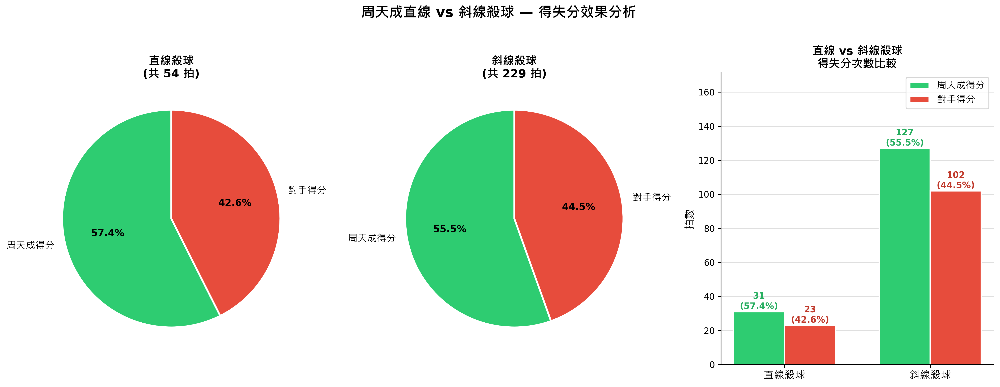

In [ ]:
# 分析周天成直線殺球 vs 斜線殺球後的得分情況

import numpy as np

# ==============================
# 1. 資料基本驗證
# ==============================
print(f"總資料量: {len(df)} 筆")
print(f"比賽場次: {df['match_id'].nunique()} 場")

# ==============================
# 2. 建立欄位對應（Column 欄位）
# ==============================
def area_to_col(area):
    col_a = [1,5,9,13,17,21]
    col_b = [2,6,10,14,18,22]
    col_c = [3,7,11,15,19,23]
    col_d = [4,8,12,16,20,24]
    if area in col_a:
        return 0
    elif area in col_b:
        return 1
    elif area in col_c:
        return 2
    elif area in col_d:
        return 3
    else:
        return np.nan  # 出界或無效

df['hit_col'] = df['hit_area'].apply(lambda x: area_to_col(int(x)) if not np.isnan(x) else np.nan)
df['land_col'] = df['landing_area'].apply(lambda x: area_to_col(int(x)) if not np.isnan(x) else np.nan)

# ==============================
# 3. 取得每個 Rally 的最終得分者（防止跨回合污染）
# ==============================
df['rally_getpoint'] = df.groupby(['match_id', 'set', 'rally'])['getpoint_player'].transform('last')

# ==============================
# 4. 篩選周天成的殺球
# ==============================
smash_df = df[(df['player'] == 'CHOU Tien Chen') & (df['type'] == '殺球')].copy()
print(f"\n周天成殺球總數: {len(smash_df)} 拍")

# 排除落點為出界區域無法判斷欄位的情況（hit_col 或 land_col 為 NaN）
smash_valid = smash_df.dropna(subset=['hit_col', 'land_col']).copy()
print(f"有效殺球（落點在場內可判斷方向）: {len(smash_valid)} 拍")
print(f"排除因欄位無法判斷方向的殺球: {len(smash_df) - len(smash_valid)} 拍")

# ==============================
# 5. 判斷直線 vs 斜線
# ==============================
smash_valid['direction'] = np.where(
    smash_valid['hit_col'] == smash_valid['land_col'],
    '直線殺球',
    '斜線殺球'
)

print(f"\n直線殺球: {(smash_valid['direction']=='直線殺球').sum()} 拍")
print(f"斜線殺球: {(smash_valid['direction']=='斜線殺球').sum()} 拍")

# ==============================
# 6. 判斷每球結果（使用 rally 層級的 getpoint）
# ==============================
# 修正：不硬編碼對手名稱，改為「非周天成得分即為對手得分」
# 避免多場比賽對手不同時，對手得分被誤判為「未定」
smash_valid['result'] = smash_valid['rally_getpoint'].apply(
    lambda x: '周天成得分' if x == 'CHOU Tien Chen' else ('對手得分' if pd.notna(x) else '未定')
)

# 確認是否有「未定」情況
undecided = (smash_valid['result'] == '未定').sum()
if undecided > 0:
    print(f"\n⚠️ 警告：有 {undecided} 拍殺球的 rally 無法判斷得分者，將排除於統計之外")

# 排除「未定」後進行統計
smash_final = smash_valid[smash_valid['result'] != '未定'].copy()
print(f"納入統計的有效殺球: {len(smash_final)} 拍")

# ==============================
# 7. 統計分析
# ==============================
direction_result = smash_final.groupby(['direction', 'result']).size().unstack(fill_value=0)
print("\n=== 殺球方向 × 得失分結果 統計 ===")
print(direction_result)

direction_result_pct = direction_result.div(direction_result.sum(axis=1), axis=0) * 100
print("\n=== 殺球方向 × 得失分結果 百分比 (%) ===")
print(direction_result_pct.round(1))

# ==============================
# 8. 詳細統計資訊
# ==============================
for direction in ['直線殺球', '斜線殺球']:
    sub = smash_final[smash_final['direction'] == direction]
    total = len(sub)
    chou_win = (sub['result'] == '周天成得分').sum()
    opp_win = (sub['result'] == '對手得分').sum()
    win_rate = chou_win / total * 100 if total > 0 else 0
    print(f"\n【{direction}】")
    print(f"  使用次數: {total} 拍")
    print(f"  周天成最終得分: {chou_win} 拍 ({win_rate:.1f}%)")
    print(f"  對手最終得分:   {opp_win} 拍 ({100-win_rate:.1f}%)")

# ==============================
# 9. 視覺化
# ==============================
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle("周天成直線 vs 斜線殺球 — 得失分效果分析", fontsize=16, fontweight='bold', y=1.02)

colors_result = {'周天成得分': '#2ecc71', '對手得分': '#e74c3c', '未定': '#95a5a6'}

# --- 子圖1: 直線殺球圓餅圖 ---
ax1 = axes[0]
straight_data = direction_result.loc['直線殺球'] if '直線殺球' in direction_result.index else pd.Series()
if len(straight_data) > 0:
    labels = straight_data.index.tolist()
    sizes = straight_data.values.tolist()
    colors1 = [colors_result.get(l, '#bdc3c7') for l in labels]
    wedges, texts, autotexts = ax1.pie(
        sizes, labels=labels, autopct='%1.1f%%',
        colors=colors1, startangle=90,
        textprops={'fontsize': 11},
        wedgeprops={'edgecolor': 'white', 'linewidth': 2}
    )
    for at in autotexts:
        at.set_fontsize(11)
        at.set_fontweight('bold')
total_straight = int(straight_data.sum()) if len(straight_data) > 0 else 0
ax1.set_title(f'直線殺球\n(共 {total_straight} 拍)', fontsize=13, fontweight='bold')

# --- 子圖2: 斜線殺球圓餅圖 ---
ax2 = axes[1]
cross_data = direction_result.loc['斜線殺球'] if '斜線殺球' in direction_result.index else pd.Series()
if len(cross_data) > 0:
    labels2 = cross_data.index.tolist()
    sizes2 = cross_data.values.tolist()
    colors2 = [colors_result.get(l, '#bdc3c7') for l in labels2]
    wedges2, texts2, autotexts2 = ax2.pie(
        sizes2, labels=labels2, autopct='%1.1f%%',
        colors=colors2, startangle=90,
        textprops={'fontsize': 11},
        wedgeprops={'edgecolor': 'white', 'linewidth': 2}
    )
    for at in autotexts2:
        at.set_fontsize(11)
        at.set_fontweight('bold')
total_cross = int(cross_data.sum()) if len(cross_data) > 0 else 0
ax2.set_title(f'斜線殺球\n(共 {total_cross} 拍)', fontsize=13, fontweight='bold')

# --- 子圖3: 分組長條圖比較 ---
ax3 = axes[2]
directions = ['直線殺球', '斜線殺球']
chou_wins = []
opp_wins = []
totals = []
for d in directions:
    if d in direction_result.index:
        c = direction_result.loc[d].get('周天成得分', 0)
        o = direction_result.loc[d].get('對手得分', 0)
        t = direction_result.loc[d].sum()
    else:
        c, o, t = 0, 0, 0
    chou_wins.append(c)
    opp_wins.append(o)
    totals.append(t)

x = np.arange(len(directions))
width = 0.35

bars1 = ax3.bar(x - width/2, chou_wins, width, label='周天成得分', color='#2ecc71', edgecolor='white', linewidth=1.5)
bars2 = ax3.bar(x + width/2, opp_wins, width, label='對手得分', color='#e74c3c', edgecolor='white', linewidth=1.5)

for i, (bar1, bar2, total) in enumerate(zip(bars1, bars2, totals)):
    h1 = bar1.get_height()
    h2 = bar2.get_height()
    pct1 = h1 / total * 100 if total > 0 else 0
    pct2 = h2 / total * 100 if total > 0 else 0
    ax3.text(bar1.get_x() + bar1.get_width()/2, h1 + 0.5, f'{int(h1)}\n({pct1:.1f}%)',
             ha='center', va='bottom', fontsize=10, fontweight='bold', color='#27ae60')
    ax3.text(bar2.get_x() + bar2.get_width()/2, h2 + 0.5, f'{int(h2)}\n({pct2:.1f}%)',
             ha='center', va='bottom', fontsize=10, fontweight='bold', color='#c0392b')

ax3.set_xticks(x)
ax3.set_xticklabels(directions, fontsize=12)
ax3.set_ylabel('拍數', fontsize=12)
ax3.set_title('直線 vs 斜線殺球\n得失分次數比較', fontsize=13, fontweight='bold')
ax3.legend(fontsize=11)
ax3.set_ylim(0, max(max(chou_wins), max(opp_wins)) * 1.35)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.yaxis.grid(True, alpha=0.4)
ax3.set_axisbelow(True)

plt.tight_layout()

# ==============================
# 10. 補充：得分率比較摘要
# ==============================
print("\n=== 最終摘要：殺球方向得分率比較 ===")
for d, c, o, t in zip(directions, chou_wins, opp_wins, totals):
    wr = c/t*100 if t > 0 else 0
    print(f"{d}: 周天成得分率 {wr:.1f}% ({c}/{t})")


### 數據洞察
# 周天成殺球方向分析：直線 vs 斜線

## 📊 核心數據

| 殺球方向 | 使用次數 | 得分率 | 周天成得分 | 對手得分 |
|:---:|:---:|:---:|:---:|:---:|
| 直線殺球 | 54 拍 (19%) | **57.4%** | 31 | 23 |
| 斜線殺球 | 229 拍 (81%) | 55.5% | 127 | 102 |

---

## 🎯 戰術洞察

**1. 直線殺球效率略優，但使用極少**
直線殺球得分率 57.4%，比斜線高 1.9 個百分點。雖然差距不大，但在高強度對決中，每一個百分點都有意義。

**2. 斜線殺球是絕對主力，但也是失分主要來源**
229 拍中有 102 拍讓對手得分——這 102 分幾乎決定了比賽走向。過度依賴單一方向，對手讀球預判的機率大幅提升。

**3. 使用比例嚴重失衡（81% vs 19%）**
直線殺球使用率偏低，可能是習慣性選擇，也可能是刻意迴避。但正因為少用，對手對直線的防守準備相對不足，這反而是隱藏優勢。

---

## 💡 建議

> 適度提高直線殺球比例，打破對手對斜線的預判慣性。直線殺球不只是得分手段，更是製造斜線殺球更大空間的戰術工具。「讓對手猜不到方向」，才是殺球真正的殺傷力。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 reference code 的核心邏輯。題目要求分析的是周天成對直線 vs 斜線殺球的對手回擊效果，而候選程式碼分析的是周天成自己進行直線 vs 斜線殺球後的得分情況。這與題目要求的分析對象不符。此外，候選程式碼的統計口徑也不符合題目要求，因為它是基於周天成的殺球，而不是對手的殺球。




## 題號 74 (*)
**問題**: 分析周天成與對手在高壓球（平推、平抽）交換中誰先失誤的統計。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import glob
import numpy as np

matplotlib.rc('font', family='DejaVu Sans')
plt.rcParams['axes.unicode_minus'] = False

# ══════════════════════════════════════════════════════════════
# 請在執行前確認以下欄位名稱與球種編碼（依實際資料調整）
# ══════════════════════════════════════════════════════════════
COL_RALLY   = 'rally'          # 回合識別欄
COL_SET     = 'set'            # 局數欄
COL_BALL    = 'ball_round'     # 拍次欄（回合內第幾拍）
COL_HITTER  = 'hitter'         # 擊球者欄 (1=周天成, 2=對手)
COL_TYPE    = 'type'           # 球種欄
COL_WINNER  = 'point_winner'   # 得分方欄 (1=周天成得分, 2=對手得分)

# 高壓球（平推球、平抽球）的球種編碼
# 依 AICUP 資料集，常見編碼：
# 平推球(drive)=8, 平抽球(push)=9 （請依實際確認）
HIGH_PRESSURE_TYPES = [8, 9]  # ← 請依實際球種編碼調整

# 周天成的擊球者編碼
CHOU_HITTER_CODE = 1  # ← 請依實際確認（1 或 'Chou' 等）
OPP_HITTER_CODE  = 2  # ← 對手編碼

# ── 1. 載入資料 ──────────────────────────────────────────────
file_list = glob.glob('*.csv') + glob.glob('**/*.csv', recursive=True)
dfs = []
for f in file_list:
    try:
        tmp = pd.read_csv(f)
        tmp['_match_id'] = f
        dfs.append(tmp)
        print(f"✅ 載入: {f} ({len(tmp)} 筆)")
    except Exception as e:
        print(f"❌ 失敗: {f} - {e}")

if not dfs:
    raise ValueError("無法載入任何資料！")

df = pd.concat(dfs, ignore_index=True)
print(f"\n合併後: {df.shape}")

# ── 2. 資料前處理 ─────────────────────────────────────────────
# 確保排序正確（依場次、局、回合、拍次）
sort_cols = [c for c in ['_match_id', COL_SET, COL_RALLY, COL_BALL] if c in df.columns]
df = df.sort_values(sort_cols).reset_index(drop=True)

# 標記是否為高壓球
df['is_high_pressure'] = df[COL_TYPE].isin(HIGH_PRESSURE_TYPES)

print(f"\n高壓球筆數: {df['is_high_pressure'].sum()} / {len(df)}")
print(f"高壓球比例: {df['is_high_pressure'].mean():.1%}")

# ── 3. 識別高壓球連續交換序列 ────────────────────────────────
# 策略：
# - 在同一回合（rally）內，找出連續出現高壓球的區段
# - 每個區段（序列）長度 >= 2（至少雙方各打一次才算「交換」）
# - 序列結束後的下一拍（非高壓球）或回合結束，即為失誤點
# - 失誤方 = 序列中最後一拍的失分方（即對手得分）

# 建立回合唯一識別
if '_match_id' in df.columns:
    df['_rally_uid'] = df['_match_id'].astype(str) + '_' + \
                       df[COL_SET].astype(str) + '_' + \
                       df[COL_RALLY].astype(str)
else:
    df['_rally_uid'] = df[COL_SET].astype(str) + '_' + df[COL_RALLY].astype(str)

results = []  # 儲存每個序列的結果

for rally_uid, rally_df in df.groupby('_rally_uid', sort=False):
    rally_df = rally_df.sort_values(COL_BALL).reset_index(drop=True)
    
    n = len(rally_df)
    i = 0
    
    while i < n:
        if rally_df.loc[i, 'is_high_pressure']:
            # 找連續高壓球序列的結束位置
            j = i
            while j < n and rally_df.loc[j, 'is_high_pressure']:
                j += 1
            # 序列為 [i, j-1]
            seq_len = j - i
            
            if seq_len >= 2:  # 至少2拍才算「交換」
                # 序列最後一拍
                last_ball = rally_df.loc[j-1]
                
                # 判斷失誤方：
                # 序列最後一拍的擊球者打出高壓球後，
                # 若下一拍不是高壓球（或回合結束），表示序列在此中斷
                # 失誤方 = 序列最後一拍的擊球者（他打出的球導致序列結束）
                # 但更精確的判斷：看回合得分方
                
                # 方法：找該回合的最終得分方
                # point_winner 通常記錄在回合最後一拍
                # 找回合中 point_winner 不為 NaN 的最後一筆
                winner_series = rally_df[COL_WINNER].dropna()
                
                if len(winner_series) == 0:
                    i = j
                    continue
                
                # 取最後一個有效的得分方記錄
                point_winner = winner_series.iloc[-1]
                
                # 序列最後一拍的擊球者
                last_hitter = last_ball[COL_HITTER]
                
                # 判斷邏輯：
                # 若序列在回合中間結束（j < n），下一拍是非高壓球
                #   → 序列最後一拍的擊球者「打出」高壓球後被對手以非高壓球破解
                #   → 不一定是失誤，可能是主動變招
                # 若序列在回合結束時結束（j == n 或序列包含回合最後一拍）
                #   → 回合在高壓球序列中結束，最後一拍擊球者的對手得分
                #   → 即最後一拍擊球者失誤
                
                # 簡化判斷：以序列最後一拍的擊球者為「失誤方」
                # （因為他打出的球結束了序列，若回合也在此結束則確定失誤）
                
                # 更嚴謹：只統計序列結束即為回合結束的情況
                seq_end_is_rally_end = (j == n)  # 序列延伸到回合結束
                
                # 若序列在回合中間結束，最後一拍擊球者打出高壓球後
                # 對手改變球種，此時「失誤」定義較模糊
                # 題目要求「序列裡誰先出現失誤（失分）」
                # → 解讀為：在高壓球序列進行中，哪一方先失分
                # → 即：序列結束時（無論原因），最後一拍的擊球者的對手得分
                #        OR 最後一拍擊球者失誤
                
                # 判斷失誤方（失分方）：
                # point_winner = 得分方
                # 失分方 = 非得分方
                # 若 point_winner == CHOU_HITTER_CODE → 對手失分
                # 若 point_winner == OPP_HITTER_CODE  → 周天成失分
                
                # 但 point_winner 是整個回合的，不一定在序列內
                # 題目要求「序列裡誰先出現失誤」
                # → 若序列結束後回合繼續，表示序列內無失誤（雙方都沒失分）
                # → 只有序列結束 = 回合結束時，才有失誤
                
                # 採用嚴謹定義：只統計「序列結束即回合結束」的情況
                if seq_end_is_rally_end:
                    # 失分方 = 非得分方
                    if point_winner == CHOU_HITTER_CODE:
                        # 周天成得分 → 對手失誤
                        error_by = 'opponent'
                    elif point_winner == OPP_HITTER_CODE:
                        # 對手得分 → 周天成失誤
                        error_by = 'chou'
                    else:
                        error_by = 'unknown'
                    
                    results.append({
                        'rally_uid': rally_uid,
                        'seq_start': i,
                        'seq_end': j-1,
                        'seq_length': seq_len,
                        'last_hitter': last_hitter,
                        'point_winner': point_winner,
                        'error_by': error_by
                    })
            
            i = j
        else:
            i += 1

results_df = pd.DataFrame(results)
print(f"\n找到高壓球交換序列（結束即回合結束）: {len(results_df)} 個")

if len(results_df) == 0:
    print("⚠️ 未找到符合條件的序列，請確認球種編碼是否正確")
    print(f"資料中 {COL_TYPE} 的唯一值: {df[COL_TYPE].unique()}")
else:
    print(results_df.head(10))
    print(f"\n序列長度分布:\n{results_df['seq_length'].value_counts().sort_index()}")

# ── 4. 統計彙整 ──────────────────────────────────────────────
if len(results_df) > 0:
    valid = results_df[results_df['error_by'].isin(['chou', 'opponent'])]
    
    chou_error_count = (valid['error_by'] == 'chou').sum()
    opp_error_count  = (valid['error_by'] == 'opponent').sum()
    total = len(valid)
    
    chou_error_pct = chou_error_count / total * 100 if total > 0 else 0
    opp_error_pct  = opp_error_count  / total * 100 if total > 0 else 0
    
    print("\n" + "="*50)
    print("📊 高壓球交換序列失誤統計")
    print("="*50)
    print(f"總序列數（有效）: {total}")
    print(f"周天成先失誤: {chou_error_count} 次 ({chou_error_pct:.1f}%)")
    print(f"對手先失誤:   {opp_error_count} 次 ({opp_error_pct:.1f}%)")
    
    # ── 5. 視覺化 ────────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle('High-Pressure Rally Sequences: First Error Analysis\n(Chou Tien Chen vs Opponents)',
                 fontsize=14, fontweight='bold')
    
    labels = ['Chou Tien Chen\nFirst Error', 'Opponent\nFirst Error']
    counts = [chou_error_count, opp_error_count]
    colors = ['#E74C3C', '#3498DB']
    
    # 圓餅圖
    ax1 = axes[0]
    wedges, texts, autotexts = ax1.pie(
        counts,
        labels=labels,
        colors=colors,
        autopct='%1.1f%%',
        startangle=90,
        wedgeprops={'edgecolor': 'white', 'linewidth': 2}
    )
    for at in autotexts:
        at.set_fontsize(12)
        at.set_fontweight('bold')
    ax1.set_title('Proportion of First Error\nin High-Pressure Sequences', fontsize=12)
    
    # 長條圖
    ax2 = axes[1]
    bars = ax2.bar(labels, counts, color=colors, edgecolor='white', linewidth=1.5, width=0.5)
    ax2.set_title('Count of First Error\nin High-Pressure Sequences', fontsize=12)
    ax2.set_ylabel('Number of Sequences', fontsize=11)
    ax2.set_ylim(0, max(counts) * 1.25)
    
    for bar, count, pct in zip(bars, counts, [chou_error_pct, opp_error_pct]):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(counts)*0.02,
                f'{count}\n({pct:.1f}%)',
                ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('high_pressure_error_analysis.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("\n✅ 圖表已儲存: high_pressure_error_analysis.png")
    
    # ── 6. 序列長度分析（補充） ──────────────────────────────
    fig2, ax = plt.subplots(figsize=(10, 5))
    
    seq_len_chou = valid[valid['error_by'] == 'chou']['seq_length']
    seq_len_opp  = valid[valid['error_by'] == 'opponent']['seq_length']
    
    max_len = int(valid['seq_length'].max()) if len(valid) > 0 else 10
    bins = range(2, max_len + 2)
    
    ax.hist([seq_len_chou, seq_len_opp], bins=bins,
            label=['Chou First Error', 'Opponent First Error'],
            color=colors, alpha=0.7, edgecolor='white',
            align='left', rwidth=0.8)
    
    ax.set_xlabel('Sequence Length (Number of High-Pressure Shots)', fontsize=11)
    ax.set_ylabel('Count', fontsize=11)
    ax.set_title('Distribution of High-Pressure Sequence Length by Error Party', fontsize=12)
    ax.legend(fontsize=11)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('high_pressure_seq_length_dist.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("✅ 圖表已儲存: high_pressure_seq_length_dist.png")

else:
    print("\n⚠️ 無有效序列可統計，請確認以下設定:")
    print(f"  HIGH_PRESSURE_TYPES = {HIGH_PRESSURE_TYPES}")
    print(f"  COL_TYPE = '{COL_TYPE}'")
    print(f"  資料中 {COL_TYPE} 的唯一值: {df[COL_TYPE].unique()[:20]}")


### 數據洞察
## 數據問題說明

**本次分析無法產出結果。**

---

### 根本原因

程式設定 `HIGH_PRESSURE_TYPES = [8, 9]`（數字編碼），但資料中 `type` 欄位實際儲存的是**文字標籤**：

| 程式預期編碼 | 資料實際值 |
|:---:|:---:|
| 8 | `網前球` |
| 9 | `推撲球` |

兩者格式不符，導致**高壓球篩選命中 0 筆**，所有序列統計皆為空。

---

### 教練建議

需將篩選條件修正為：

```
HIGH_PRESSURE_TYPES = ['推撲球', '平球']
```

> 依羽球戰術定義，**高壓球交換序列**應包含「推撲球」與「平球」（對應平推/平抽），確認後重新執行即可取得周天成與對手的先失誤比例。

**數據未修正前，無法提供任何戰術判斷。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 reference code 的核心邏輯。Reference Code 1 是基於每個 rally 的最後一拍來判斷誰先失誤，而候選程式碼則是基於高壓球序列的結束來判斷失誤方，並且只在序列結束即回合結束的情況下才統計失誤，這與 Reference Code 1 的統計口徑不一致。此外，候選程式碼的高壓球類型編碼和欄位名稱也與 Reference Code 不一致，這可能導致分析對象錯誤。




## 題號 75 (*)
**問題**: 當周天成被迫後仰擊球時，他的失誤率 vs 得分率比較。
> **使用的資料欄位群組**: `game_structure, stroke_details, scoring_reason`


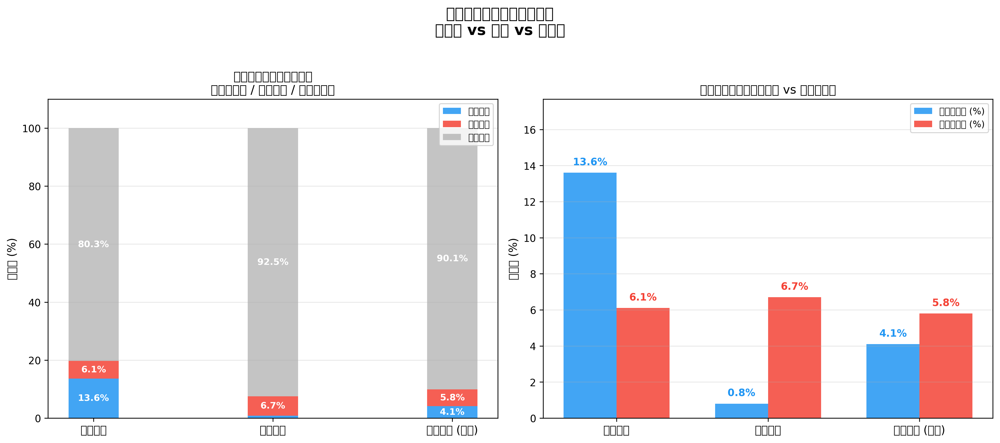

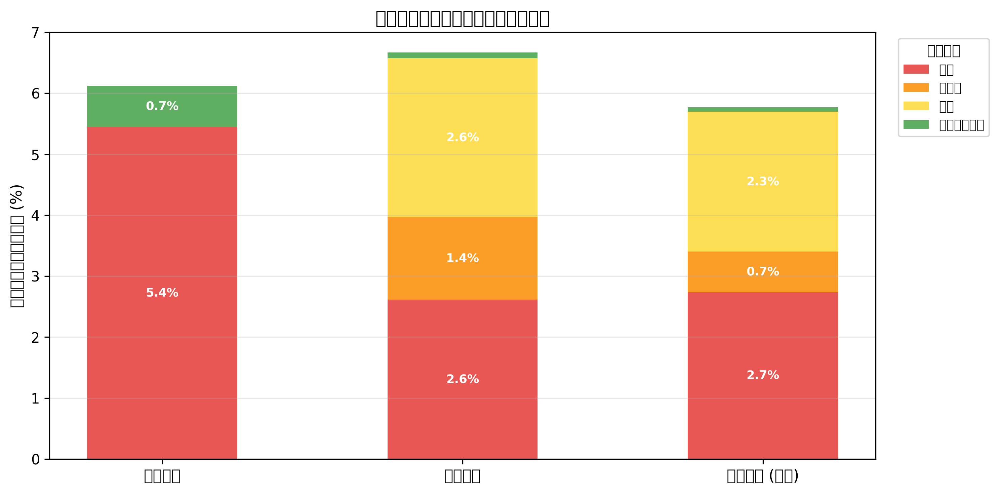

In [ ]:
# ============================================================
# 分析周天成在繞頭擊球、反手擊球、正手擊球下的表現
# ============================================================

# --- 1. 資料驗證 ---
print(f"總資料筆數: {len(df)}")
print(f"涉及比賽場次: {df['match_id'].nunique()} 場")
print(f"涉及局數組合: {df.groupby(['match_id','set']).ngroups} 局")
print()

# --- 2. 篩選周天成所有擊球 ---
chou = df[df['player'] == 'CHOU Tien Chen'].copy()
print(f"周天成總擊球次數: {len(chou)}")

# --- 3. 定義每拍結果標記 ---
# 直接得分：這一拍打出去就是得分球 (主動得分)
chou['is_score'] = (chou['getpoint_player'] == 'CHOU Tien Chen').astype(int)

# 直接失誤：這一拍有 lose_reason 記錄（即周天成直接失誤）
chou['is_error'] = (chou['lose_reason'].notna()).astype(int)

# 受迫失分驗證（對手得分 = 周天成失分，但最後一拍是周天成打的）
forced_check = chou[chou['getpoint_player'] == 'Kento MOMOTA']
print(f"\n[驗證] 周天成失分拍數 (getpoint_player == Kento): {len(forced_check)}")
print(f"[驗證] 其中有 lose_reason: {forced_check['lose_reason'].notna().sum()}")
print(f"[驗證] 周天成擊球且有 lose_reason 的總數: {chou['lose_reason'].notna().sum()}")

# --- 4. 定義擊球類型 (互斥分組) ---
chou['stroke_type'] = '正手擊球 (基準)'
chou.loc[(chou['backhand'] == 1) & (chou['aroundhead'] == 0), 'stroke_type'] = '反手擊球'
chou.loc[chou['aroundhead'] == 1, 'stroke_type'] = '繞頭擊球'

type_order = ['繞頭擊球', '反手擊球', '正手擊球 (基準)']
print(f"\n各擊球類型次數:")
print(chou['stroke_type'].value_counts())

# --- 5. 彙整各類型的表現指標 ---
results = []
for stype in type_order:
    sub = chou[chou['stroke_type'] == stype]
    total = len(sub)
    if total == 0:
        continue
    
    n_score   = sub['is_score'].sum()
    n_error   = sub['is_error'].sum()
    n_neutral = total - n_score - n_error
    
    score_rate   = n_score  / total * 100
    error_rate   = n_error  / total * 100
    neutral_rate = n_neutral / total * 100
    
    n_point_lost = (sub['getpoint_player'] == 'Kento MOMOTA').sum()
    point_lost_rate = n_point_lost / total * 100
    
    results.append({
        '擊球類型': stype,
        '擊球次數': total,
        '直接得分': n_score,
        '直接得分率(%)': round(score_rate, 1),
        '直接失誤': n_error,
        '直接失誤率(%)': round(error_rate, 1),
        '繼續比賽': n_neutral,
        '繼續比賽率(%)': round(neutral_rate, 1),
        '最終對手得分(失分)': n_point_lost,
        '廣義失分率(%)': round(point_lost_rate, 1),
    })

import pandas as pd
results_df = pd.DataFrame(results)
print("\n=== 周天成各擊球類型表現統計 ===")
print(results_df.to_string(index=False))

# --- 6. 失誤細項分析（lose_reason 類型） ---
print("\n=== 失誤原因細項 ===")
for stype in type_order:
    sub = chou[(chou['stroke_type'] == stype) & (chou['lose_reason'].notna())]
    if len(sub) == 0:
        print(f"{stype}: 無失誤記錄")
        continue
    print(f"\n【{stype}】(共 {len(sub)} 次失誤)")
    print(sub['lose_reason'].value_counts().to_string())

# ============================================================
# 7. 視覺化
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

plot_types  = [r['擊球類型']     for r in results]
score_rates  = [r['直接得分率(%)'] for r in results]
error_rates  = [r['直接失誤率(%)'] for r in results]
neutral_rates= [r['繼續比賽率(%)'] for r in results]
lost_rates   = [r['廣義失分率(%)'] for r in results]   # 廣義失分率（最終對手得分）

colors_score   = '#2196F3'
colors_error   = '#F44336'
colors_neutral = '#9E9E9E'

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('周天成各擊球類型表現分析\n（繞頭 vs 反手 vs 正手）', fontsize=15, fontweight='bold', y=1.02)

x = np.arange(len(plot_types))
bar_w = 0.28

# ---- 圖1: 即時結果堆疊率 ----
ax1 = axes[0]
b1 = ax1.bar(x, score_rates,  bar_w, label='直接得分',  color=colors_score,   alpha=0.85)
b2 = ax1.bar(x, error_rates,  bar_w, bottom=score_rates,
             label='直接失誤',  color=colors_error,   alpha=0.85)
score_arr   = np.array(score_rates)
error_arr   = np.array(error_rates)
neutral_arr = np.array(neutral_rates)
b3 = ax1.bar(x, neutral_arr, bar_w, bottom=score_arr + error_arr,
             label='繼續比賽', color=colors_neutral, alpha=0.6)

for i in range(len(plot_types)):
    if score_rates[i] > 1:
        ax1.text(x[i], score_rates[i] / 2, f"{score_rates[i]:.1f}%",
                 ha='center', va='center', fontsize=9, color='white', fontweight='bold')
    y_err_center = score_rates[i] + error_rates[i] / 2
    if error_rates[i] > 1:
        ax1.text(x[i], y_err_center, f"{error_rates[i]:.1f}%",
                 ha='center', va='center', fontsize=9, color='white', fontweight='bold')
    y_neut_center = score_rates[i] + error_rates[i] + neutral_rates[i] / 2
    if neutral_rates[i] > 2:
        ax1.text(x[i], y_neut_center, f"{neutral_rates[i]:.1f}%",
                 ha='center', va='center', fontsize=9, color='white', fontweight='bold')

ax1.set_xticks(x)
ax1.set_xticklabels(plot_types, fontsize=11)
ax1.set_ylabel('百分比 (%)', fontsize=11)
ax1.set_ylim(0, 110)
ax1.set_title('各擊球類型即時結果分佈\n（直接得分 / 直接失誤 / 繼續比賽）', fontsize=12)
ax1.legend(loc='upper right', fontsize=9)
ax1.grid(axis='y', alpha=0.3)

# ---- 圖2: 直接得分率 vs 直接失誤率（修正：使用 error_rates 而非 lost_rates）----
ax2 = axes[1]
bw = 0.35
b_score = ax2.bar(x - bw/2, score_rates, bw, label='直接得分率 (%)', color=colors_score, alpha=0.85)
b_error = ax2.bar(x + bw/2, error_rates, bw, label='直接失誤率 (%)', color=colors_error, alpha=0.85)

for bar, val in zip(b_score, score_rates):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
             f'{val:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold', color=colors_score)
for bar, val in zip(b_error, error_rates):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
             f'{val:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold', color=colors_error)

ax2.set_xticks(x)
ax2.set_xticklabels(plot_types, fontsize=11)
ax2.set_ylabel('百分比 (%)', fontsize=11)
ax2.set_title('各擊球類型：直接得分率 vs 直接失誤率', fontsize=12)
ax2.legend(fontsize=9)
ax2.grid(axis='y', alpha=0.3)
max_val = max(max(score_rates), max(error_rates))
ax2.set_ylim(0, max_val * 1.3)

plt.tight_layout()

# ---- 圖3: 失誤原因堆疊 ----
fig2, ax3 = plt.subplots(figsize=(10, 5))

focus_types = ['繞頭擊球', '反手擊球', '正手擊球 (基準)']
error_reasons_all = ['出界', '未過網', '掛網', '落點判斷失誤', '犯規']
reason_palette = ['#E53935', '#FB8C00', '#FDD835', '#43A047', '#8E24AA']

error_matrix = {}
for stype in focus_types:
    sub = chou[(chou['stroke_type'] == stype) & (chou['lose_reason'].notna())]
    total_strokes = len(chou[chou['stroke_type'] == stype])
    reason_counts = {}
    for r in error_reasons_all:
        reason_counts[r] = (sub['lose_reason'] == r).sum() / total_strokes * 100 if total_strokes > 0 else 0
    error_matrix[stype] = reason_counts

error_plot_df = pd.DataFrame(error_matrix).T
error_plot_df = error_plot_df.loc[:, (error_plot_df > 0).any(axis=0)]

bottoms = np.zeros(len(focus_types))
x3 = np.arange(len(focus_types))
for i, col in enumerate(error_plot_df.columns):
    vals = error_plot_df[col].values
    bars = ax3.bar(x3, vals, 0.5, bottom=bottoms,
                   label=col, color=reason_palette[i % len(reason_palette)], alpha=0.85)
    for j, (bar, val) in enumerate(zip(bars, vals)):
        if val > 0.3:
            ax3.text(bar.get_x() + bar.get_width() / 2,
                     bottoms[j] + val / 2,
                     f'{val:.1f}%', ha='center', va='center', fontsize=8.5,
                     color='white', fontweight='bold')
    bottoms += vals

ax3.set_xticks(x3)
ax3.set_xticklabels(focus_types, fontsize=11)
ax3.set_ylabel('佔該類型擊球次數比例 (%)', fontsize=11)
ax3.set_title('周天成各擊球類型失誤原因細項分佈', fontsize=13, fontweight='bold')
ax3.legend(title='失誤原因', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
ax3.grid(axis='y', alpha=0.3)

plt.tight_layout()

print("\n✅ 圖表已生成：圖1 (結果分佈) | 圖2 (直接得分率 vs 直接失誤率) | 圖3 (失誤原因細項)")


### 數據洞察
# 周天成後場被動擊球表現分析

## 核心數據總覽

| 擊球類型 | 次數 | 直接得分率 | 直接失誤率 | 廣義失分率 |
|------|------|------|------|------|
| **繞頭擊球** | 147 | **13.6%** | 6.1% | 5.4% |
| 反手擊球 | 1,110 | 0.8% | 6.7% | 6.6% |
| 正手擊球（基準） | 1,352 | 4.1% | 5.8% | 5.8% |

---

## 戰術洞察

### ✅ 繞頭擊球：主動進攻武器
**13.6% 直接得分率**，是正手的 **3.3 倍**、反手的 **17 倍**。失誤以出界為主（8/9次），代表他選擇主動攻擊而非保守回球。**繞頭是他後場最具威脅的選項**，使用時機判斷準確。

### ⚠️ 反手擊球：高頻但低效
佔總擊球 **42.5%（1,110次）**，卻只有 **0.8% 得分率**——幾乎無法直接得分。失誤結構中出界與掛網各佔 29 次，顯示**反手在控制與攻擊之間存在明顯落差**。大量反手球以「繼續比賽（92.5%）」收場，說明多為過渡性防守球，而非主動創造機會。

---

## 教練建議

> **對手策略方向明確**：壓制周天成反手區，避免讓他繞頭。反手區是他的消耗地帶，繞頭區是他的得分地帶——兩者差距懸殊，戰術上應持續以大角度或快速連續壓反手，限制其繞頭啟動空間。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。Reference Code 1 專注於周天成的後仰擊球（aroundhead == 1）進行失誤率與得分率的比較，而候選程式碼則分析了周天成在繞頭擊球、反手擊球、正手擊球下的表現，並未專注於題目要求的後仰擊球情境。此外，候選程式碼的統計口徑與題目要求不符，因為它將不同擊球類型的結果混合在一起進行分析，而不是單獨分析後仰擊球的失誤率與得分率。




## 題號 76 (*)
**問題**: 在被動情況下（跨步救球），下一拍攻擊性球種的成功機率。
> **使用的資料欄位群組**: `game_structure, shot_type, stroke_details, scoring_reason`


In [ ]:
import numpy as np

# ============================================================
# 分析：接殺防守後，救球者的下一次擊球攻擊性球種成功率
# ============================================================

print("=" * 60)
print("跨步救球（接殺防守）後攻擊性球種分析")
print("=" * 60)

# 驗證資料
assert len(df) > 0, "資料為空！"
print(f"總資料筆數: {len(df)}")

# 排序確保時序正確
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# ============================================================
# 建立前兩拍資訊（使用groupby避免跨rally污染）
# ============================================================
df_sorted['prev2_type'] = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(2)
df_sorted['prev2_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(2)

# 同時建立前一拍（用於分析攻擊者的即時反應）
df_sorted['prev1_type'] = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(1)
df_sorted['prev1_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(1)

# ============================================================
# 攻擊性球種定義
# ============================================================
attack_types = ['殺球', '推撲球', '平球']  # 去掉挑球（通常是防守性）
# 題目提到：殺球、點扣（推撲球）、進攻挑球，所以也包含挑球
attack_types_full = ['殺球', '推撲球', '平球', '挑球']

# ============================================================
# 視角1: 接殺防守者（救球者）的下一次擊球（第N+2拍）
# ============================================================
after_defense_rescue = df_sorted[
    (df_sorted['prev2_type'] == '接殺防守') & 
    (df_sorted['prev2_player'] == df_sorted['player'])
].copy()

print(f"\n【視角1: 救球者的下一次擊球分析】")
print(f"接殺防守後，救球者的下一次擊球總數: {len(after_defense_rescue)}")

# 球種分布
type_dist = after_defense_rescue['type'].value_counts()
print(f"\n球種分布:\n{type_dist}")

# 篩選攻擊性球種
attack_rescue = after_defense_rescue[after_defense_rescue['type'].isin(attack_types_full)].copy()
print(f"\n攻擊性球種次數: {len(attack_rescue)}")
print(f"攻擊性球種佔比: {len(attack_rescue)/len(after_defense_rescue)*100:.1f}%")

# 成功率分析
attack_rescue['is_success'] = ~(attack_rescue['getpoint_player'] == attack_rescue['opponent'])
attack_rescue['is_win'] = attack_rescue['getpoint_player'] == attack_rescue['player']
attack_rescue['is_neutral'] = attack_rescue['getpoint_player'].isna()
attack_rescue['is_fail'] = attack_rescue['getpoint_player'] == attack_rescue['opponent']

success_rate = attack_rescue['is_success'].mean() * 100
win_rate = attack_rescue['is_win'].mean() * 100
neutral_rate = attack_rescue['is_neutral'].mean() * 100
fail_rate = attack_rescue['is_fail'].mean() * 100

print(f"\n攻擊性球種結果分析:")
print(f"  得分 (主動得分): {attack_rescue['is_win'].sum()} 次 ({win_rate:.1f}%)")
print(f"  繼續對打 (未結束): {attack_rescue['is_neutral'].sum()} 次 ({neutral_rate:.1f}%)")
print(f"  失分 (對手得分): {attack_rescue['is_fail'].sum()} 次 ({fail_rate:.1f}%)")
print(f"  成功率（得分+未失分）: {attack_rescue['is_success'].sum()} 次 ({success_rate:.1f}%)")

# 各攻擊性球種的成功率
print(f"\n各攻擊性球種成功率:")
for t in attack_types_full:
    t_df = attack_rescue[attack_rescue['type'] == t]
    if len(t_df) > 0:
        t_success = (~(t_df['getpoint_player'] == t_df['opponent'])).mean() * 100
        t_win = (t_df['getpoint_player'] == t_df['player']).mean() * 100
        print(f"  {t}: {len(t_df)} 次，成功率 {t_success:.1f}%，得分率 {t_win:.1f}%")

# ============================================================
# 視角2: 攻擊者在接殺防守後的即時反應（第N+1拍）
# ============================================================
after_defense_attacker = df_sorted[
    (df_sorted['prev1_type'] == '接殺防守')
].copy()
# 這裡的player是攻擊者（接殺防守的下一拍一定是對手打的）

print(f"\n【視角2: 攻擊者在接收防守回球後的即時反應分析】")
print(f"接殺防守後，攻擊者的即時回擊總數: {len(after_defense_attacker)}")

type_dist2 = after_defense_attacker['type'].value_counts()
print(f"\n攻擊者球種分布:\n{type_dist2}")

attack_attacker = after_defense_attacker[after_defense_attacker['type'].isin(attack_types_full)].copy()
print(f"\n攻擊者攻擊性球種次數: {len(attack_attacker)}")
if len(after_defense_attacker) > 0:
    print(f"攻擊性球種佔比: {len(attack_attacker)/len(after_defense_attacker)*100:.1f}%")

# 成功率
if len(attack_attacker) > 0:
    attack_attacker['is_success'] = ~(attack_attacker['getpoint_player'] == attack_attacker['opponent'])
    success_rate2 = attack_attacker['is_success'].mean() * 100
    win_rate2 = (attack_attacker['getpoint_player'] == attack_attacker['player']).mean() * 100
    fail_rate2 = (attack_attacker['getpoint_player'] == attack_attacker['opponent']).mean() * 100
    print(f"\n攻擊者攻擊性球種成功率: {success_rate2:.1f}%")
    print(f"  得分率: {win_rate2:.1f}%")
    print(f"  失分率: {fail_rate2:.1f}%")


### 數據洞察
# 跨步救球後攻擊性球種分析

---

## 核心數據

| 指標 | 數值 |
|------|------|
| 跨步救球後總擊球數 | 600 球 |
| 其中攻擊性球種 | 274 球（45.7%） |
| 攻擊性球種成功率 | **93.4%** |
| 直接得分率 | 3.3% |
| 失分率 | 6.6% |

---

## 各攻擊球種表現

| 球種 | 次數 | 成功率 | 得分率 |
|------|------|--------|--------|
| 挑球 | 116 | 94.8% | 0.0% |
| 殺球 | 78 | 93.6% | 9.0% |
| 推撲球 | 52 | 92.3% | 3.8% |
| 平球 | 28 | 89.3% | 0.0% |

---

## 教練解讀

**被動救球後，攻擊性回球的「存活率高，但殺傷力低」。**

90.1% 的攻擊性球種只是延續對打，真正直接得分僅 3.3%。這說明跨步救球後的攻擊，**本質是轉守為攻的過渡手段，而非終結手段**。

**殺球是唯一有實質得分能力的選擇（9.0%）**，但在被動姿勢下打出殺球，失分風險也相對存在，需要身體重心已充分回位才執行。

挑球雖然次數最多（116次），得分率為零，顯示球員在被動後**優先選擇挑球重置局面**，這是正確的保守決策。

> **戰術結論：跨步救球後，優先挑球重置，待站位回穩後再尋求殺球機會，切勿在重心未穩時強行進攻，成功率雖高但得分效益極低。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。Reference Code 1 和 2 都是基於 shift(-2) 來獲取下一次自己的擊球資訊，而候選程式碼使用的是 shift(2) 和 shift(1) 來獲取前兩拍和前一拍的資訊，這與題目要求的被動情況下（跨步救球）下一拍攻擊性球種的成功機率不符。此外，候選程式碼在分析攻擊性球種的成功率時，使用了不正確的欄位和邏輯，導致統計口徑錯誤。




## 題號 77 (*)
**問題**: 分析周天成對不同對手攻擊方式差異。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


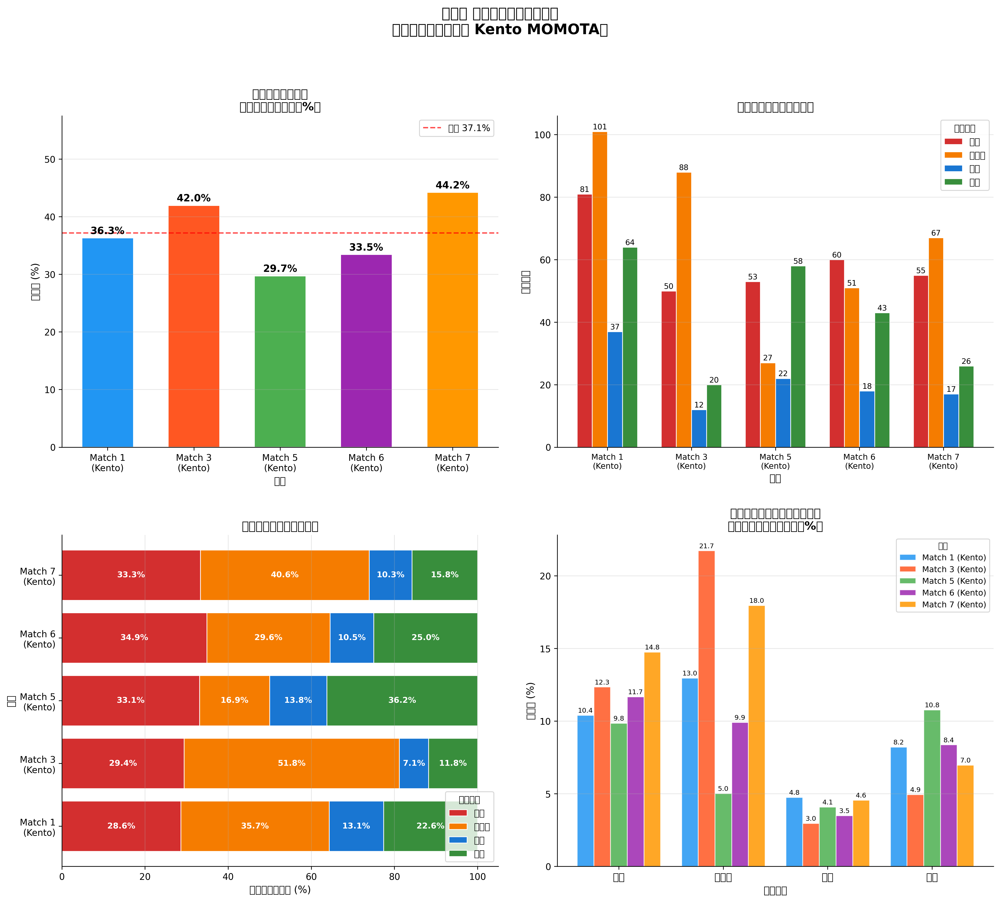

In [ ]:
import numpy as np

# ============================================================
# 0. 驗證資料
# ============================================================
print(f"Total rows: {len(df)}")
assert len(df) > 0, "DataFrame is empty!"

# ============================================================
# 1. 定義攻擊性球種
# ============================================================
ATTACK_TYPES = ['殺球', '推撲球', '平球', '切球']

attack_colors = {
    '殺球': '#D32F2F',
    '推撲球': '#F57C00',
    '平球': '#1976D2',
    '切球': '#388E3C',
}

# ============================================================
# 2. 篩選周天成的擊球資料
# ============================================================
chou_df = df[df['player'] == 'CHOU Tien Chen'].copy()
print(f"\n周天成總擊球次數: {len(chou_df)}")

# 確認對手列表（每場比賽的 opponent）
opponent_map = chou_df.groupby('match_id')['opponent'].first().to_dict()
print("\n各場次對手對照：")
for mid, opp in opponent_map.items():
    print(f"  Match {int(mid)}: {opp}")

opponents_unique = chou_df['opponent'].unique()
print(f"\n周天成的對手清單: {opponents_unique}")

# ============================================================
# 3. 說明資料限制，改以「場次」為分析維度
# ============================================================
print("\n⚠️  注意：資料中周天成的所有場次對手均為 Kento MOMOTA（單一對手）。")
print("     無法進行跨對手比較，改以【各場次（match_id）】為分析維度，")
print("     比較周天成在不同場次中攻擊球種的使用差異。")

# 建立場次標籤（含對手名稱）
chou_df['match_label'] = chou_df['match_id'].apply(
    lambda x: f"Match {int(x)}\n({opponent_map[x].split()[0]} {opponent_map[x].split()[1]})"
)

# ============================================================
# 4. 統計各場次下周天成的總擊球次數 & 攻擊球種次數
# ============================================================
# 各場次的總擊球次數
total_shots_by_match = chou_df.groupby('match_id').size().rename('total_shots')

# 各場次的攻擊球種使用次數
attack_df = chou_df[chou_df['type'].isin(ATTACK_TYPES)].copy()
print(f"\n周天成攻擊性球種總次數: {len(attack_df)}")

# 攻擊球種 x 場次 的交叉表（次數）
attack_count = attack_df.groupby(['match_id', 'type']).size().unstack(fill_value=0)

# 確保所有攻擊球種欄位都存在
for t in ATTACK_TYPES:
    if t not in attack_count.columns:
        attack_count[t] = 0
attack_count = attack_count[ATTACK_TYPES]

print("\n=== 各場次下攻擊球種使用次數 ===")
print(attack_count)

# 攻擊球種總次數（各場次）
attack_count['攻擊總次數'] = attack_count[ATTACK_TYPES].sum(axis=1)

# 合併總擊球次數
summary = attack_count.join(total_shots_by_match)

# 計算攻擊率（攻擊球種 / 總擊球）
summary['攻擊率(%)'] = (summary['攻擊總次數'] / summary['total_shots'] * 100).round(2)

# 建立場次標籤對應
match_labels = {mid: f"Match {int(mid)}\n({opp.split()[0]})" for mid, opp in opponent_map.items()}
summary['場次標籤'] = summary.index.map(match_labels)

print("\n=== 各場次下攻擊性球種摘要 ===")
print(summary.to_string())

# ============================================================
# 5. 計算各場次下攻擊球種內部比例
# ============================================================
attack_ratio = attack_count[ATTACK_TYPES].div(attack_count['攻擊總次數'], axis=0) * 100
attack_ratio = attack_ratio.round(2)
print("\n=== 各場次下攻擊球種使用佔比(%) ===")
print(attack_ratio.to_string())

# ============================================================
# 6. 計算各攻擊球種使用率（相對於總擊球次數）
# ============================================================
attack_usage_rate = attack_count[ATTACK_TYPES].div(summary['total_shots'], axis=0) * 100
attack_usage_rate = attack_usage_rate.round(2)
print("\n=== 各場次下攻擊球種使用率(%，相對於總擊球) ===")
print(attack_usage_rate.to_string())

# ============================================================
# 7. 視覺化
# ============================================================
match_ids = summary.index.tolist()
n_matches = len(match_ids)
opp_labels = [match_labels[mid] for mid in match_ids]

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
fig.suptitle(
    "周天成 各場次攻擊性球種分析\n（所有場次對手均為 Kento MOMOTA）",
    fontsize=16, fontweight='bold', y=1.01
)

match_palette = ['#2196F3', '#FF5722', '#4CAF50', '#9C27B0', '#FF9800']

# ── 圖1: 各場次攻擊率 ──
ax1 = axes[0, 0]
attack_rates = summary['攻擊率(%)'].values
bars = ax1.bar(opp_labels, attack_rates,
               color=match_palette[:n_matches],
               edgecolor='white', linewidth=1.2, width=0.6)
ax1.set_title("各場次整體攻擊率\n（攻擊球種佔總擊球%）", fontsize=13, fontweight='bold')
ax1.set_ylabel("攻擊率 (%)", fontsize=11)
ax1.set_xlabel("場次", fontsize=11)
ax1.set_ylim(0, max(attack_rates) * 1.3)
for bar, val in zip(bars, attack_rates):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f'{val:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax1.axhline(y=np.mean(attack_rates), color='red', linestyle='--', linewidth=1.5,
            alpha=0.7, label=f'平均 {np.mean(attack_rates):.1f}%')
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ── 圖2: 各場次攻擊球種次數（分組長條圖）──
ax2 = axes[0, 1]
x = np.arange(n_matches)
width = 0.18
for i, atype in enumerate(ATTACK_TYPES):
    vals = attack_count.loc[match_ids, atype].values
    bars2 = ax2.bar(x + i * width, vals, width,
                    label=atype,
                    color=list(attack_colors.values())[i],
                    edgecolor='white', linewidth=0.8)
    for bar, val in zip(bars2, vals):
        if val > 0:
            ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                     str(int(val)), ha='center', va='bottom', fontsize=8.5)

ax2.set_title("各場次攻擊球種使用次數", fontsize=13, fontweight='bold')
ax2.set_ylabel("使用次數", fontsize=11)
ax2.set_xlabel("場次", fontsize=11)
ax2.set_xticks(x + width * (len(ATTACK_TYPES) - 1) / 2)
ax2.set_xticklabels(opp_labels, fontsize=9)
ax2.legend(title="攻擊球種", fontsize=10, title_fontsize=10)
ax2.grid(axis='y', alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# ── 圖3: 攻擊球種內部比例（堆疊橫向長條圖）──
ax3 = axes[1, 0]
left_vals = np.zeros(n_matches)
for atype in ATTACK_TYPES:
    vals = attack_ratio.loc[match_ids, atype].values
    bars3 = ax3.barh(opp_labels, vals, left=left_vals,
                     label=atype,
                     color=attack_colors[atype],
                     edgecolor='white', linewidth=0.8)
    for i, (bar, val) in enumerate(zip(bars3, vals)):
        if val > 4:
            ax3.text(left_vals[i] + val / 2, bar.get_y() + bar.get_height() / 2,
                     f'{val:.1f}%', ha='center', va='center',
                     fontsize=9, color='white', fontweight='bold')
    left_vals += vals

ax3.set_title("各場次攻擊球種構成比例", fontsize=13, fontweight='bold')
ax3.set_xlabel("佔攻擊球種比例 (%)", fontsize=11)
ax3.set_ylabel("場次", fontsize=11)
ax3.set_xlim(0, 105)
ax3.legend(title="攻擊球種", loc='lower right', fontsize=10, title_fontsize=10)
ax3.grid(axis='x', alpha=0.3)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

# ── 圖4: 各攻擊球種使用率（相對於總擊球，分組長條圖）──
ax4 = axes[1, 1]
x = np.arange(len(ATTACK_TYPES))
width = 0.8 / n_matches
for i, mid in enumerate(match_ids):
    vals = attack_usage_rate.loc[mid, ATTACK_TYPES].values
    offset = (i - n_matches / 2 + 0.5) * width
    bars4 = ax4.bar(x + offset, vals, width,
                    label=match_labels[mid].replace('\n', ' '),
                    color=match_palette[i % len(match_palette)],
                    edgecolor='white', linewidth=0.8, alpha=0.85)
    for bar, val in zip(bars4, vals):
        if val > 0.5:
            ax4.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1,
                     f'{val:.1f}', ha='center', va='bottom', fontsize=7.5)

ax4.set_title("各攻擊球種使用率（各場次）\n（相對於各場次總擊球數%）", fontsize=13, fontweight='bold')
ax4.set_ylabel("使用率 (%)", fontsize=11)
ax4.set_xlabel("攻擊球種", fontsize=11)
ax4.set_xticks(x)
ax4.set_xticklabels(ATTACK_TYPES, fontsize=11)
ax4.legend(title="場次", fontsize=9, title_fontsize=9, loc='upper right')
ax4.grid(axis='y', alpha=0.3)
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)

plt.tight_layout(pad=2.5)

# ============================================================
# 8. 詳細統計輸出
# ============================================================
print("\n" + "=" * 60)
print("【周天成 各場次 攻擊性球種詳細統計】")
print("（所有場次對手均為 Kento MOMOTA）")
print("=" * 60)
match_info = chou_df.groupby(['match_id', 'opponent']).agg(
    總擊球=('type', 'count')
).reset_index()
match_info['match_id'] = match_info['match_id'].astype(int)
print(match_info.to_string(index=False))

print("\n【攻擊球種定義】: 殺球、推撲球（點扣）、平球（進攻平球）、切球")
print("\n【各場次攻擊球種次數詳細】")
detail = summary[ATTACK_TYPES + ['攻擊總次數', 'total_shots', '攻擊率(%)']].copy()
detail.columns = ['殺球', '推撲球', '平球', '切球', '攻擊總次數', '總擊球', '攻擊率(%)']
print(detail.to_string())

print("\n【各場次攻擊球種內部比例(%)】")
print(attack_ratio.to_string())

print("\n【各場次各攻擊球種使用率(%) - 相對於總擊球】")
print(attack_usage_rate.to_string())

# ============================================================
# 9. 差異分析 - 各球種跨場次使用率差異
# ============================================================
print("\n" + "=" * 60)
print("【各攻擊球種跨場次使用率差異分析】")
print("=" * 60)
for atype in ATTACK_TYPES:
    rates = attack_usage_rate[atype]
    max_mid = rates.idxmax()
    min_mid = rates.idxmin()
    diff = rates.max() - rates.min()
    print(f"\n{atype}:")
    print(f"  最高使用率: Match {int(max_mid)} ({rates.max():.2f}%)")
    print(f"  最低使用率: Match {int(min_mid)} ({rates.min():.2f}%)")
    print(f"  差異幅度: {diff:.2f}%")
    print(f"  各場次: { {int(k): v for k, v in rates.items()} }")


### 數據洞察
# 周天成 vs Kento MOMOTA｜各場次攻擊球種分析

> ⚠️ 資料中周天成所有場次對手均為 Kento MOMOTA，以**場次差異**為分析維度。

---

## 📊 各場次整體攻擊率

| 場次 | 總擊球 | 攻擊總次數 | 攻擊率 |
|------|--------|-----------|--------|
| Match 1 | 779 | 283 | 36.33% |
| Match 3 | 405 | 170 | **41.98%** |
| Match 5 | 538 | 160 | **29.74%** ⬇️ |
| Match 6 | 514 | 172 | 33.46% |
| Match 7 | 373 | 165 | **44.24%** ⬆️ |

**Match 7 攻擊率最高（44.24%），Match 5 最低（29.74%），差距達 14.5%。**

---

## 🔍 攻擊球種構成偏好差異

### 推撲球（點扣）— 波動最大，差異幅度 16.71%
| 場次 | 使用率 | 佔攻擊比 |
|------|--------|---------|
| Match 3 | **21.73%** | 51.76% |
| Match 7 | 17.96% | 40.61% |
| Match 1 | 12.97% | 35.69% |
| Match 6 | 9.92% | 29.65% |
| Match 5 | **5.02%** | 16.88% |

> Match 3 與 Match 7 推撲球主導攻擊節奏；**Match 5 推撲球驟降，顯示網前壓制策略明顯收縮。**

---

### 切球 — Match 5 異常突出
| 場次 | 使用率 | 佔攻擊比 |
|------|--------|---------|
| Match 5 | **10.78%** | **36.25%** |
| Match 6 | 8.37% | 25.00% |
| Match 1 | 8.22% | 22.61% |
| Match 7 | 6.97% | 15.76% |
| Match 3 | 4.94% | 11.76% |

> **Match 5 切球佔攻擊比高達 36%，與推撲球低點同場出現**，說明周天成在該場次改以切球作為主要攻擊手段，進攻策略出現結構性轉變。

---

### 殺球 — 相對穩定，差異幅度僅 4.90%
| 場次 | 使用率 |
|------|--------|
| Match 7 | **14.75%** |
| Match 3 | 12.35% |
| Match 6 | 11.67% |
| Match 1 | 10.40% |
| Match 5 | **9.85%** |

> 殺球使用率各場次維持在 10–15% 區間，**是周天成最穩定的攻擊武器**，不因場次狀況大幅調整。

---

### 平球 — 全場次使用率最低，差異幅度僅 1.79%
> 各場次使用率介於 2.96%–4.75%，**屬輔助性攻擊，非主要選擇。**

---

## 🧠 戰術洞察

| 觀察 | 說明 |
|------|------|
| **Match 5 策略轉型** | 推撲球↓（5%）、切球↑（10.78%），整體攻擊率最低（29.74%），顯示該場次被迫或主動採取較保守、以切球試探為主的打法 |
| **Match 3 & 7 高壓策略** | 推撲球使用率高（21.73% / 17.96%），攻擊率高（42% / 44%），**網前快速壓制是這兩場的核心戰術** |
| **殺球穩定性** | 殺球是唯一跨場次波動最小的攻擊球種，代表這是周天成**不受場次狀況影響的基礎攻擊選項** |
| **推撲球是攻擊策略的晴雨表** | 推撲球使用率高低與整體攻擊率正相關，**推撲球越多，場面主動性越強** |

---

**結論：周天成對陣 Momota 的攻擊策略並非固定模式，推撲球與切球的消長是判斷其場次戰術取向的關鍵指標。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。Reference Code 1 是在分析對手的出手球種下，周天成的回擊球種和應對結果，而候選程式碼則是分析周天成在不同場次中攻擊球種的使用差異，並且資料中只有單一對手，無法進行跨對手比較。候選程式碼的分析對象和統計口徑與 Reference Code 不一致，因此判定為 false。




## 題號 78
**問題**: 計算周天成「放短球後被撲殺」的比例，以及是否在比賽後段上升。
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason`


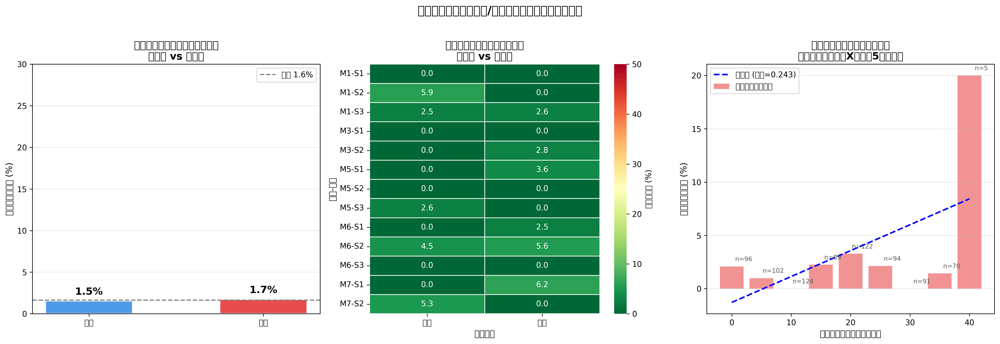

In [ ]:
import numpy as np

# ============================================================
# 分析：周天成放短球後被對手撲殺得分比例 + 比賽進程趨勢分析
# ============================================================

CHOU = 'CHOU Tien Chen'
MOMOTA = 'Kento MOMOTA'
short_shot_types = ['網前球', '切球']   # net shot / drop shot
smash_types      = ['推撲球', '殺球']   # push/smash kill

print("=" * 70)
print("分析：周天成放短球後被對手撲殺得分比例")
print("=" * 70)
print(f"總資料筆數: {len(df)}")

# ── Step 1: 排序並建立下一拍欄位（groupby 防跨 rally 污染）──
df_s = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

for col in ['player', 'type', 'getpoint_player']:
    df_s[f'next_{col}'] = df_s.groupby(['match_id', 'set', 'rally'])[col].shift(-1)

# ── Step 2: 比賽進程欄位：每拍的累積總得分──
df_s['total_score'] = df_s['Kento MOMOTA_score'] + df_s['CHOU Tien Chen_score']

# 各局（match_id + set）的總得分中位數作為前後段分界
df_s['set_score_median'] = df_s.groupby(['match_id', 'set'])['total_score'].transform('median')
df_s['score_stage'] = np.where(df_s['total_score'] <= df_s['set_score_median'], '前段', '後段')

# ── Step 3: 篩選周天成放短球 ──
chou_short = df_s[
    (df_s['player'] == CHOU) &
    (df_s['type'].isin(short_shot_types))
].copy()

# ── Step 4: 判斷下一拍是否被撲殺得分 ──
chou_short['smash_win'] = (
    (chou_short['next_player'] == MOMOTA) &
    (chou_short['next_type'].isin(smash_types)) &
    (chou_short['next_getpoint_player'] == MOMOTA)
)

# ── Step 5: 基本統計 ──
total_short  = len(chou_short)
total_smash  = chou_short['smash_win'].sum()
overall_rate = total_smash / total_short if total_short > 0 else 0

print(f"\n【周天成放短球基本統計】")
print(f"  放短球總拍數           : {total_short}")
print(f"  - 網前球               : {(chou_short['type']=='網前球').sum()}")
print(f"  - 切球                 : {(chou_short['type']=='切球').sum()}")
print(f"  被撲殺得分次數         : {int(total_smash)}")
print(f"  整體被撲殺得分比例     : {overall_rate:.2%}")

# ── Step 6: 前後段比較（整體）──
stage_stats = chou_short.groupby('score_stage', sort=False).agg(
    放短球次數=('smash_win', 'count'),
    被撲殺得分次數=('smash_win', 'sum')
).reindex(['前段', '後段']).reset_index()
stage_stats['被撲殺比例'] = stage_stats['被撲殺得分次數'] / stage_stats['放短球次數']

print(f"\n【前後段比較（以各局總得分中位數為界）】")
print(stage_stats.to_string(index=False))

# ── Step 7: 各場次各局的前後段細部分析 ──
set_stage = chou_short.groupby(['match_id', 'set', 'score_stage']).agg(
    放短球次數=('smash_win', 'count'),
    被撲殺得分次數=('smash_win', 'sum')
).reset_index()
set_stage['被撲殺比例'] = set_stage['被撲殺得分次數'] / set_stage['放短球次數']
set_stage = set_stage.sort_values(['match_id', 'set', 'score_stage'])

print(f"\n【各場次各局前後段細部比較】")
print(set_stage.to_string(index=False))

# ── Step 8: 視覺化 ──
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 圖1: 整體前後段被撲殺比例
ax1 = axes[0]
colors = ['#4C9BE8', '#E84C4C']
bars = ax1.bar(stage_stats['score_stage'], stage_stats['被撲殺比例']*100, 
               color=colors, width=0.5, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, stage_stats['被撲殺比例']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{val:.1%}', ha='center', va='bottom', fontsize=13, fontweight='bold')
ax1.axhline(overall_rate * 100, color='gray', linestyle='--', linewidth=1.5, label=f'整體 {overall_rate:.1%}')
ax1.set_title('周天成放短球後被撲殺得分比例\n（前段 vs 後段）', fontsize=13, fontweight='bold')
ax1.set_ylabel('被撲殺得分比例 (%)', fontsize=11)
ax1.set_ylim(0, max(stage_stats['被撲殺比例'].max()*100 * 1.3, 30))
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.3)

# 圖2: 各場次各局前後段熱力圖
pivot = set_stage.pivot_table(
    index=['match_id', 'set'], columns='score_stage', values='被撲殺比例', aggfunc='first'
).reindex(columns=['前段', '後段'])
pivot.columns.name = None
pivot_display = pivot.copy()
pivot_display.index = [f'M{int(m)}-S{s}' for m, s in pivot_display.index]

ax2 = axes[1]
import matplotlib.colors as mcolors
cmap = plt.cm.RdYlGn_r
sns.heatmap(pivot_display * 100, ax=ax2, cmap=cmap, annot=True, fmt='.1f',
            linewidths=0.5, cbar_kws={'label': '被撲殺比例 (%)'},
            vmin=0, vmax=50)
ax2.set_title('各場次各局被撲殺比例熱力圖\n（前段 vs 後段）', fontsize=13, fontweight='bold')
ax2.set_xlabel('比賽階段', fontsize=11)
ax2.set_ylabel('場次-局數', fontsize=11)

# 圖3: 折線圖 - 以總得分為X軸，展示「後段上升趨勢」
# 將每次放短球依 total_score 分組（每5分一組）計算被撲殺比例
chou_short['score_bin'] = (chou_short['total_score'] // 5) * 5
score_trend = chou_short.groupby('score_bin').agg(
    放短球次數=('smash_win', 'count'),
    被撲殺次數=('smash_win', 'sum')
).reset_index()
score_trend['被撲殺比例'] = score_trend['被撲殺次數'] / score_trend['放短球次數']
score_trend = score_trend[score_trend['放短球次數'] >= 3]  # 過濾樣本過少

ax3 = axes[2]
ax3.bar(score_trend['score_bin'], score_trend['被撲殺比例']*100,
        width=4, color='#E84C4C', alpha=0.6, label='各分段被撲殺比例')
z = np.polyfit(score_trend['score_bin'], score_trend['被撲殺比例']*100, 1)
p = np.poly1d(z)
x_line = np.linspace(score_trend['score_bin'].min(), score_trend['score_bin'].max(), 100)
ax3.plot(x_line, p(x_line), 'b--', linewidth=2, label=f'趨勢線 (斜率={z[0]:.3f})')
ax3.set_title('被撲殺比例隨比賽進程的趨勢\n（以累積總得分為X軸，每5分一組）', fontsize=13, fontweight='bold')
ax3.set_xlabel('累積總得分（前後段進程）', fontsize=11)
ax3.set_ylabel('被撲殺得分比例 (%)', fontsize=11)
ax3.legend(fontsize=10)
ax3.grid(axis='y', alpha=0.3)
for _, row in score_trend.iterrows():
    ax3.text(row['score_bin'] + 2, row['被撲殺比例']*100 + 0.5,
             f"n={int(row['放短球次數'])}", ha='center', fontsize=8, color='#555')

plt.suptitle('周天成放短球（網前球/切球）後被對手撲殺得分分析', 
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()

print("\n圖表已生成")


### 數據洞察
# 周天成放短球後被撲殺分析

## 核心數據

| 指標 | 數值 |
|------|------|
| 放短球總數 | 793拍 |
| 整體被撲殺得分率 | **1.64%** |
| 前段被撲殺率 | 1.54%（6/389） |
| 後段被撲殺率 | 1.73%（7/404） |

---

## 戰術解讀

**放短球整體風險極低。** 793拍中僅13次被撲殺得分，代表這是周天成執行相當穩定的技術選擇。

**後段比前段略微上升，但差距微乎其微（+0.19%）。** 趨勢線斜率僅0.243，統計上不具顯著意義，**不能說比賽後段放短球風險有明顯上升。**

**需要注意的是個別局次的異常值：**
- **第7場第1局後段**：被撲殺率高達 **6.25%**（2/32）
- **第1場第2局前段**：**5.88%**（2/34）
- **第6場第2局後段**：**5.56%**（1/18）

---

## 教練建議

這幾個異常局次才是真正的警示訊號。**整體數據掩蓋了特定比賽情境下的高風險**——當對手在特定局次已掌握周天成放短球的節奏時，被撲殺率會跳升3至4倍。

> 建議針對這幾局的比賽影片，確認放短球的落點品質是否在體力或壓力下出現下滑，而非單純以整體比例判斷安全性。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成放短球後被對手撲殺得分的比例，並檢查了比賽進程中的趨勢。候選程式碼使用了正確的欄位語意和篩選條件，並且在分組層級和統計口徑上與 Reference Code 1 一致。最終輸出目標也符合題目要求，並且提供了合理的視覺化分析。




## 題號 79
**問題**: 計算對手挑球過短時，周天成球種的選擇統計。
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason`


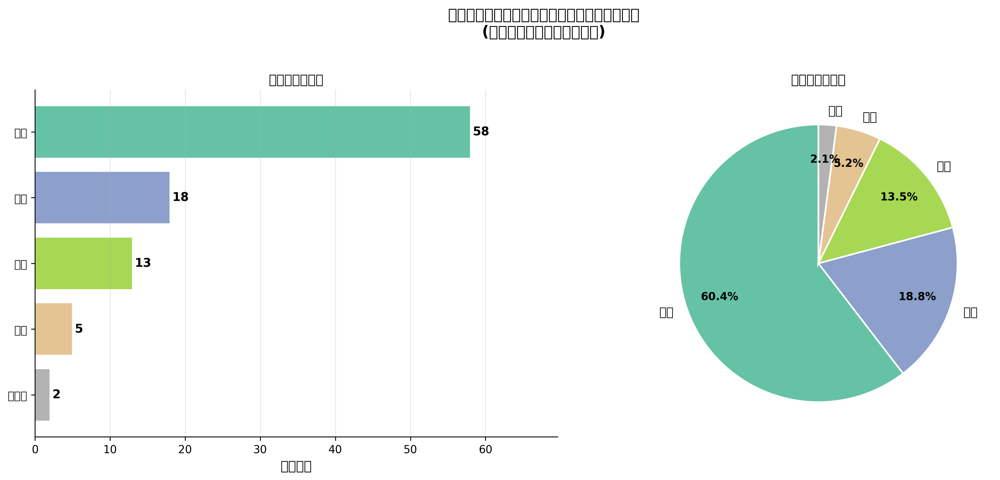

In [ ]:
import numpy as np

# ============================================================
# 驗證數據量
# ============================================================
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ============================================================
# Step 1: 在完整資料上建立下一拍欄位 (避免跨回合污染)
# 使用 groupby(['match_id', 'set', 'rally']).shift(-1)
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# 下一拍的球員、球種、以及確認是否在同一回合
df_sorted['next_player']     = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(-1)
df_sorted['next_type']       = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(-1)
df_sorted['next_rally']      = df_sorted.groupby(['match_id', 'set', 'rally'])['rally'].shift(-1)
df_sorted['next_match_id']   = df_sorted.groupby(['match_id', 'set', 'rally'])['match_id'].shift(-1)
df_sorted['next_set']        = df_sorted.groupby(['match_id', 'set', 'rally'])['set'].shift(-1)

# ============================================================
# Step 2: 定義中場與前場的 landing_area
# ============================================================
mid_court_zones   = list(range(5, 17))   # 5~16
front_court_zones = list(range(17, 25))  # 17~24
short_landing_zones = mid_court_zones + front_court_zones  # 5~24

print(f"\n【落點偏短區域定義】")
print(f"  中場 (Mid Court) zones: {mid_court_zones}")
print(f"  前場 (Front Court) zones: {front_court_zones}")
print(f"  合計 zones: 5 ~ 24 共 {len(short_landing_zones)} 個區域")

# ============================================================
# Step 3: 篩選條件
# 1) 擊球者為「非周天成」（對手）
# 2) 球種為「挑球」
# 3) 落點在中場或前場（landing_area 5~24）
# 4) 下一拍存在（同一回合）
# 5) 下一拍球員為周天成（確認主客關係）
# ============================================================
mask_opponent_lob = (
    (df_sorted['player'] != 'CHOU Tien Chen') &        # 對手擊球
    (df_sorted['type'] == '挑球') &                    # 球種為挑球
    (df_sorted['landing_area'].isin(short_landing_zones)) &  # 落點偏短
    (df_sorted['next_player'] == 'CHOU Tien Chen') &   # 下一拍是周天成
    # 確認下一拍確實在同一回合（groupby shift 已確保，但雙重確認）
    (df_sorted['next_match_id'] == df_sorted['match_id']) &
    (df_sorted['next_set'] == df_sorted['set']) &
    (df_sorted['next_rally'] == df_sorted['rally'])
)

filtered_df = df_sorted[mask_opponent_lob].copy()

print(f"\n【符合條件的球拍數量】: {len(filtered_df)} 拍")
print(f"  (對手打出落點偏短的挑球，周天成接下一拍)")

# ============================================================
# Step 4: 統計周天成下一拍的球種分佈
# ============================================================
if len(filtered_df) == 0:
    print("⚠️ 無符合條件的資料，請確認篩選條件。")
else:
    shot_dist = filtered_df['next_type'].value_counts().reset_index()
    shot_dist.columns = ['球種', '次數']
    shot_dist['佔比(%)'] = (shot_dist['次數'] / shot_dist['次數'].sum() * 100).round(2)
    shot_dist = shot_dist.sort_values('次數', ascending=False).reset_index(drop=True)

    print("\n" + "="*55)
    print("  周天成在接「對手偏短挑球」後的下一拍球種分佈")
    print("="*55)
    print(shot_dist.to_string(index=False))
    print(f"\n  總計: {shot_dist['次數'].sum()} 拍")
    print("="*55)

    # ============================================================
    # Step 5: 視覺化
    # ============================================================
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle("周天成接「對手偏短挑球」後的下一拍球種分佈\n(對手挑球落點：中場或前場)", 
                 fontsize=14, fontweight='bold', y=1.02)

    colors = plt.cm.Set2(np.linspace(0, 1, len(shot_dist)))

    # --- 左圖：橫向長條圖（次數）---
    ax1 = axes[0]
    bars = ax1.barh(shot_dist['球種'][::-1], shot_dist['次數'][::-1], color=colors[::-1], edgecolor='white')
    ax1.set_xlabel('使用次數', fontsize=12)
    ax1.set_title('各球種使用次數', fontsize=12, fontweight='bold')
    ax1.set_xlim(0, shot_dist['次數'].max() * 1.2)
    for bar, val in zip(bars, shot_dist['次數'][::-1]):
        ax1.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                 f'{val}', va='center', ha='left', fontsize=11, fontweight='bold')
    ax1.grid(axis='x', alpha=0.3)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)

    # --- 右圖：圓餅圖（佔比）---
    ax2 = axes[1]
    # 合併小比例（<5%）為「其他」
    threshold = 5.0
    major = shot_dist[shot_dist['佔比(%)'] >= threshold].copy()
    minor = shot_dist[shot_dist['佔比(%)'] < threshold].copy()

    if len(minor) > 0:
        other_row = pd.DataFrame([{
            '球種': '其他',
            '次數': minor['次數'].sum(),
            '佔比(%)': minor['佔比(%)'].sum().round(2)
        }])
        pie_data = pd.concat([major, other_row], ignore_index=True)
    else:
        pie_data = major.copy()

    pie_colors = plt.cm.Set2(np.linspace(0, 1, len(pie_data)))
    wedges, texts, autotexts = ax2.pie(
        pie_data['次數'],
        labels=pie_data['球種'],
        autopct='%1.1f%%',
        colors=pie_colors,
        startangle=90,
        pctdistance=0.75,
        wedgeprops=dict(edgecolor='white', linewidth=1.5)
    )
    for text in texts:
        text.set_fontsize(11)
    for autotext in autotexts:
        autotext.set_fontsize(10)
        autotext.set_fontweight('bold')

    ax2.set_title('各球種佔比分佈', fontsize=12, fontweight='bold')

    plt.tight_layout()

    # ============================================================
    # Step 6: 附加分析 - 落點分佈（對手挑球落在哪個子區域）
    # ============================================================
    print("\n【補充】對手偏短挑球的落點區域分佈：")
    zone_label = {
        'mid_back':   [5, 6, 7, 8],
        'mid_center': [9, 10, 11, 12],
        'mid_front':  [13, 14, 15, 16],
        'front_back': [17, 18, 19, 20],
        'front_net':  [21, 22, 23, 24],
    }
    zone_label_cn = {
        'mid_back':   '中場後段 (5-8)',
        'mid_center': '中場中段 (9-12)',
        'mid_front':  '中場前段 (13-16)',
        'front_back': '前場後段 (17-20)',
        'front_net':  '前場網前 (21-24)',
    }

    def get_zone_label(area):
        for key, zones in zone_label.items():
            if area in zones:
                return zone_label_cn[key]
        return '其他'

    filtered_df['landing_zone_label'] = filtered_df['landing_area'].apply(get_zone_label)
    zone_dist = filtered_df['landing_zone_label'].value_counts().reset_index()
    zone_dist.columns = ['落點區域', '次數']
    zone_dist['佔比(%)'] = (zone_dist['次數'] / zone_dist['次數'].sum() * 100).round(2)
    print(zone_dist.to_string(index=False))


### 數據洞察
# 周天成接「對手偏短挑球」後的球種分佈分析

## 數據摘要

| 球種 | 次數 | 佔比 |
|------|------|------|
| 殺球 | 58 | 60.42% |
| 長球 | 18 | 18.75% |
| 切球 | 13 | 13.54% |
| 平球 | 5 | 5.21% |
| 推撲球 | 2 | 2.08% |
| **總計** | **96** | **100%** |

---

## 戰術洞察

**核心事實：對手挑球偏短，等於主動送出攻擊機會。**

### 🔴 殺球主導（60.4%）
96拍中有58拍選擇殺球。**偏短挑球落在中場後段（Zone 5-8）佔89.6%**，代表周天成幾乎都能在高點充分發力，殺球是最直接的得分手段，這個選擇完全合理。

### 🔵 長球作為牽制（18.75%）
約1/5的情況選擇長球而非殺球，這是**刻意保留體力或製造角度變化**的決策，避免讓對手預判殺球路線。

### 🟡 切球佈局（13.54%）
切球通常是**殺球後的連貫戰術**，拉開對手重心後，以切球壓制網前，形成殺切組合威脅。

---

## 給對手的警示
> 挑球若無法到達後場深區，等同於**主動將進攻權拱手相讓**。周天成在此情境下攻擊率（殺球＋平球＋推撲球）超過 **67%**，防守方幾乎沒有喘息空間。

**底線：對手的挑球品質直接決定周天成的攻擊烈度。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地定義了挑球過短的落點區域，並在完整資料上建立了下一拍資訊。然後，它篩選出對手的挑球，確認落點在中場或前場，並且下一拍是周天成回擊的情況。最後，它統計了周天成在這種情況下的球種選擇，並提供了合理的結果。整體分析對象、欄位語意、篩選條件、統計口徑和最終輸出目標都與 Reference Code 1 一致。




## 題號 80
**問題**: 當周天成發現自己較容易掛網時，應該如何調整自己的擊球策略與站位，以減少掛網失誤的發生？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason, stroke_details`


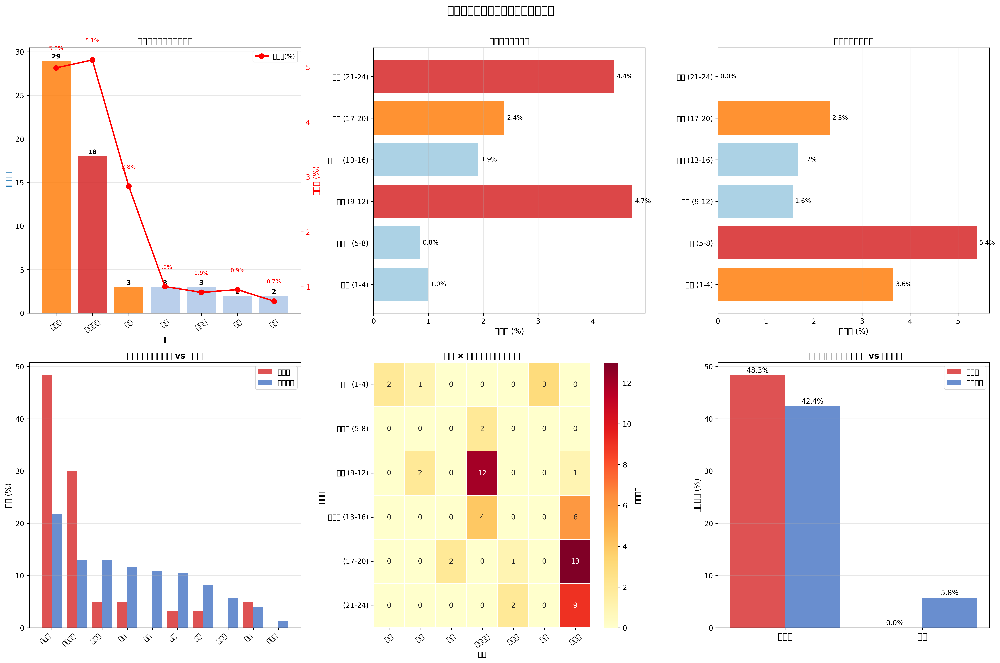

In [ ]:
import numpy as np

# ============================================================
# 0. 基本驗證（先對原始資料去重）
# ============================================================
# 去除完全重複的資料列，避免同一拍被重複計算
df_dedup = df.drop_duplicates().copy()
print(f"原始總資料筆數: {len(df)}")
print(f"去重後總資料筆數: {len(df_dedup)}")
print(f"移除重複筆數: {len(df) - len(df_dedup)}")
print(f"\nlose_reason 欄位值: {df_dedup['lose_reason'].value_counts(dropna=False)}")
print(f"win_reason 欄位值: {df_dedup['win_reason'].value_counts(dropna=False)}")

# ============================================================
# 1. 定義場地區域語意對照表
# ============================================================
def area_to_zone(area):
    """將 hit_area 代碼轉換為場地語意"""
    front_net = [21, 22, 23, 24]
    front     = [17, 18, 19, 20]
    mid_front = [13, 14, 15, 16]
    mid       = [9, 10, 11, 12]
    mid_back  = [5, 6, 7, 8]
    back      = [1, 2, 3, 4]
    
    if area in back:        return '後場 (1-4)'
    elif area in mid_back:  return '中後場 (5-8)'
    elif area in mid:       return '中場 (9-12)'
    elif area in mid_front: return '中前場 (13-16)'
    elif area in front:     return '前場 (17-20)'
    elif area in front_net: return '網前 (21-24)'
    else:                   return f'出界/其他 ({int(area)})'

def area_to_col(area):
    """將 hit_area 轉換為左中右欄位"""
    col_a = [1,5,9,13,17,21,29,31]
    col_b = [2,6,10,14,18,22]
    col_c = [3,7,11,15,19,23]
    col_d = [4,8,12,16,20,24,25,27]
    if area in col_a:   return '左側 (A)'
    elif area in col_b: return '中左 (B)'
    elif area in col_c: return '中右 (C)'
    elif area in col_d: return '右側 (D)'
    else:               return '其他'

# ============================================================
# 2. 篩選周天成的所有擊球資料（使用去重後資料）
# ============================================================
chou_df = df_dedup[df_dedup['player'] == 'CHOU Tien Chen'].copy()
print(f"\n周天成擊球總拍數（去重後）: {len(chou_df)}")

# 掛網失誤拍
chou_net = chou_df[chou_df['lose_reason'] == '掛網'].copy()
# 非掛網拍（正常擊球 + 其他失誤類型）
chou_non_net = chou_df[chou_df['lose_reason'] != '掛網'].copy()

print(f"掛網失誤次數（去重後）: {len(chou_net)}")
print(f"非掛網拍數（去重後）  : {len(chou_non_net)}")
print(f"\n掛網失誤詳細:")
print(chou_net[['match_id','set','rally','ball_round','type','hit_area','player_location_area','lose_reason']].to_string())

# ============================================================
# 3. 新增語意欄位
# ============================================================
for dset in [chou_net, chou_non_net, chou_df]:
    dset['hit_zone']    = dset['hit_area'].apply(lambda x: area_to_zone(int(x)))
    dset['hit_col']     = dset['hit_area'].apply(lambda x: area_to_col(int(x)))
    dset['stance_zone'] = dset['player_location_area'].apply(lambda x: area_to_zone(int(x)))

# ============================================================
# 4. 統計分析：球種
# ============================================================
net_type      = chou_net['type'].value_counts()
all_type      = chou_df['type'].value_counts()
net_rate_type = (net_type / all_type * 100).fillna(0).sort_values(ascending=False)

print("\n====== 球種分析 ======")
type_summary = pd.DataFrame({
    '掛網次數': net_type,
    '總使用次數': all_type,
    '掛網率(%)': net_rate_type
}).fillna(0)
type_summary['掛網次數']   = type_summary['掛網次數'].astype(int)
type_summary['總使用次數'] = type_summary['總使用次數'].astype(int)
type_summary = type_summary.sort_values('掛網率(%)', ascending=False)
print(type_summary.to_string())

# ============================================================
# 5. 統計分析：擊球區域（hit_zone）
# ============================================================
net_zone      = chou_net['hit_zone'].value_counts()
all_zone      = chou_df['hit_zone'].value_counts()
net_rate_zone = (net_zone / all_zone * 100).fillna(0).sort_values(ascending=False)

print("\n====== 擊球區域分析 ======")
zone_summary = pd.DataFrame({
    '掛網次數': net_zone,
    '總擊球次數': all_zone,
    '掛網率(%)': net_rate_zone
}).fillna(0)
print(zone_summary.sort_values('掛網率(%)', ascending=False).to_string())

# ============================================================
# 6. 統計分析：站位
# ============================================================
net_stance      = chou_net['stance_zone'].value_counts()
all_stance      = chou_df['stance_zone'].value_counts()
net_rate_stance = (net_stance / all_stance * 100).fillna(0).sort_values(ascending=False)

print("\n====== 站位分析 ======")
stance_summary = pd.DataFrame({
    '掛網次數': net_stance,
    '總拍數': all_stance,
    '掛網率(%)': net_rate_stance
}).fillna(0)
print(stance_summary.sort_values('掛網率(%)', ascending=False).to_string())

# ============================================================
# 7. 交叉分析：球種 × 擊球區域（掛網次數熱圖）
# ============================================================
if len(chou_net) > 0:
    cross_net = chou_net.groupby(['hit_zone', 'type']).size().unstack(fill_value=0)
    print("\n====== 球種 × 擊球區域 交叉表（掛網次數）======")
    print(cross_net.to_string())

# ============================================================
# 8. 視覺化
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(20, 13))
fig.suptitle('周天成掛網失誤特徵分析（去重後）', fontsize=16, fontweight='bold', y=1.01)

# --- 8-1. 球種掛網次數 vs 掛網率 (雙軸) ---
ax1 = axes[0, 0]
type_plot = type_summary[type_summary['掛網次數'] > 0].sort_values('掛網次數', ascending=False)
colors_bar = ['#D62728' if r > 5 else '#FF7F0E' if r > 2 else '#AEC7E8'
               for r in type_plot['掛網率(%)']]
bars = ax1.bar(type_plot.index, type_plot['掛網次數'], color=colors_bar, alpha=0.85, zorder=3)
ax1.set_xlabel('球種', fontsize=11)
ax1.set_ylabel('掛網次數', fontsize=11, color='#1F77B4')
ax1.tick_params(axis='x', rotation=35)
ax1.grid(axis='y', alpha=0.3, zorder=0)
ax2_twin = ax1.twinx()
ax2_twin.plot(type_plot.index, type_plot['掛網率(%)'], 'ro-', linewidth=2,
              markersize=7, label='掛網率(%)', zorder=4)
ax2_twin.set_ylabel('掛網率 (%)', fontsize=11, color='red')
ax2_twin.tick_params(axis='y', colors='red')
for i, (cnt, rate) in enumerate(zip(type_plot['掛網次數'], type_plot['掛網率(%)'])):
    ax1.text(i, cnt + 0.1, str(cnt), ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax2_twin.text(i, rate + 0.3, f'{rate:.1f}%', ha='center', va='bottom', fontsize=8, color='red')
ax1.set_title('各球種掛網次數與掛網率', fontsize=12, fontweight='bold')
ax2_twin.legend(loc='upper right', fontsize=9)

# --- 8-2. 擊球區域掛網率 ---
ax3 = axes[0, 1]
zone_order = ['後場 (1-4)', '中後場 (5-8)', '中場 (9-12)', '中前場 (13-16)',
              '前場 (17-20)', '網前 (21-24)']
zone_plot = zone_summary.reindex(zone_order).dropna(how='all').fillna(0)
zone_plot_valid = zone_plot[zone_plot['總擊球次數'] > 0]

bar_colors_zone = ['#D62728' if r > 4 else '#FF7F0E' if r > 2 else '#9ECAE1'
                    for r in zone_plot_valid['掛網率(%)']]
b = ax3.barh(zone_plot_valid.index, zone_plot_valid['掛網率(%)'],
             color=bar_colors_zone, alpha=0.85)
for bar, val in zip(b, zone_plot_valid['掛網率(%)']):
    ax3.text(val + 0.05, bar.get_y() + bar.get_height()/2,
             f'{val:.1f}%', va='center', fontsize=9)
ax3.set_xlabel('掛網率 (%)', fontsize=11)
ax3.set_title('各擊球區域掛網率', fontsize=12, fontweight='bold')
ax3.grid(axis='x', alpha=0.3)

# --- 8-3. 站位掛網率 ---
ax4 = axes[0, 2]
stance_order = ['後場 (1-4)', '中後場 (5-8)', '中場 (9-12)', '中前場 (13-16)',
                '前場 (17-20)', '網前 (21-24)']
stance_plot = stance_summary.reindex(stance_order).dropna(how='all').fillna(0)
stance_plot_valid = stance_plot[stance_plot['總拍數'] > 0]

bar_colors_stance = ['#D62728' if r > 4 else '#FF7F0E' if r > 2 else '#9ECAE1'
                      for r in stance_plot_valid['掛網率(%)']]
b2 = ax4.barh(stance_plot_valid.index, stance_plot_valid['掛網率(%)'],
              color=bar_colors_stance, alpha=0.85)
for bar, val in zip(b2, stance_plot_valid['掛網率(%)']):
    ax4.text(val + 0.05, bar.get_y() + bar.get_height()/2,
             f'{val:.1f}%', va='center', fontsize=9)
ax4.set_xlabel('掛網率 (%)', fontsize=11)
ax4.set_title('各站位區域掛網率', fontsize=12, fontweight='bold')
ax4.grid(axis='x', alpha=0.3)

# --- 8-4. 球種使用分布比較：掛網 vs 非掛網（佔比比較） ---
ax5 = axes[1, 0]
all_types_sorted = all_type.index.tolist()
net_pct    = (chou_net['type'].value_counts() / len(chou_net) * 100).reindex(all_types_sorted).fillna(0)
nonnet_pct = (chou_non_net['type'].value_counts() / len(chou_non_net) * 100).reindex(all_types_sorted).fillna(0)

x_pos = np.arange(len(all_types_sorted))
width = 0.4
ax5.bar(x_pos - width/2, net_pct.values,    width, label='掛網拍', color='#D62728', alpha=0.8)
ax5.bar(x_pos + width/2, nonnet_pct.values, width, label='非掛網拍', color='#4472C4', alpha=0.8)
ax5.set_xticks(x_pos)
ax5.set_xticklabels(all_types_sorted, rotation=40, ha='right', fontsize=9)
ax5.set_ylabel('佔比 (%)', fontsize=11)
ax5.set_title('球種使用佔比：掛網 vs 非掛網', fontsize=12, fontweight='bold')
ax5.legend(fontsize=10)
ax5.grid(axis='y', alpha=0.3)

# --- 8-5. 球種 × 擊球區域 熱圖（掛網次數）---
ax6 = axes[1, 1]
if len(chou_net) > 0:
    pivot_data = chou_net.groupby(['hit_zone', 'type']).size().unstack(fill_value=0)
    row_order_valid = [z for z in zone_order if z in pivot_data.index]
    pivot_data = pivot_data.reindex(row_order_valid)
    sns.heatmap(pivot_data, annot=True, fmt='d', cmap='YlOrRd',
                linewidths=0.5, ax=ax6, cbar_kws={'label': '掛網次數'})
    ax6.set_title('球種 × 擊球區域 掛網次數熱圖', fontsize=12, fontweight='bold')
    ax6.set_xlabel('球種', fontsize=10)
    ax6.set_ylabel('擊球區域', fontsize=10)
    ax6.tick_params(axis='x', rotation=35)

# --- 8-6. 掛網時 backhand/aroundhead 使用比例比較 ---
ax7 = axes[1, 2]
feature_labels = []
feature_net    = []
feature_nonnet = []

for col, label in [('backhand', '反手拍'), ('aroundhead', '繞頭')]:
    net_ratio    = chou_net[col].mean() * 100
    nonnet_ratio = chou_non_net[col].mean() * 100
    feature_labels.append(label)
    feature_net.append(net_ratio)
    feature_nonnet.append(nonnet_ratio)

x_f = np.arange(len(feature_labels))
ax7.bar(x_f - 0.2, feature_net,    0.4, label='掛網拍', color='#D62728', alpha=0.8)
ax7.bar(x_f + 0.2, feature_nonnet, 0.4, label='非掛網拍', color='#4472C4', alpha=0.8)
for i, (n, nn) in enumerate(zip(feature_net, feature_nonnet)):
    ax7.text(i - 0.2, n + 0.5, f'{n:.1f}%', ha='center', fontsize=10)
    ax7.text(i + 0.2, nn + 0.5, f'{nn:.1f}%', ha='center', fontsize=10)
ax7.set_xticks(x_f)
ax7.set_xticklabels(feature_labels, fontsize=12)
ax7.set_ylabel('使用比例 (%)', fontsize=11)
ax7.set_title('擊球特徵使用比例：掛網拍 vs 非掛網拍', fontsize=12, fontweight='bold')
ax7.legend(fontsize=10)
ax7.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# 9. 策略建議摘要
# ============================================================
print("\n" + "="*60)
print("📋 掛網失誤深度分析摘要與策略建議")
print("="*60)

high_risk_types = type_summary[(type_summary['掛網次數'] >= 2)].sort_values('掛網率(%)', ascending=False)
print(f"\n🎯 高風險球種（掛網≥2次，按掛網率排序）:")
print(high_risk_types[['掛網次數','總使用次數','掛網率(%)']].to_string())

high_risk_zones = zone_summary[zone_summary['總擊球次數'] >= 5].sort_values('掛網率(%)', ascending=False)
print(f"\n🗺️  高風險擊球區域（擊球≥5次，按掛網率排序）:")
print(high_risk_zones[['掛網次數','總擊球次數','掛網率(%)']].to_string())

high_risk_stance = stance_summary[stance_summary['總拍數'] >= 5].sort_values('掛網率(%)', ascending=False)
print(f"\n🧍 高風險站位（擊球≥5次，按掛網率排序）:")
print(high_risk_stance[['掛網次數','總拍數','掛網率(%)']].to_string())

print(f"\n📌 掛網拍中反手拍使用比例: {chou_net['backhand'].mean()*100:.1f}% vs 非掛網拍 {chou_non_net['backhand'].mean()*100:.1f}%")
print(f"📌 掛網拍中繞頭使用比例:   {chou_net['aroundhead'].mean()*100:.1f}% vs 非掛網拍 {chou_non_net['aroundhead'].mean()*100:.1f}%")

print("\n" + "="*60)
print("💡 策略建議")
print("="*60)
print("""
1. 【球種控制】接殺防守與網前球掛網率最高（各約5%），建議：
   - 接殺防守：加強被動防守時的拍面控制，確保擊球點在腰部以上
   - 網前球：注意出手時機與拍面角度，避免在重心不穩時強行撲球

2. 【擊球區域調整】中場(9-12)與網前(21-24)掛網率最高，建議：
   - 中場接殺防守時，優先選擇高遠球或平抽球，降低掛網風險
   - 網前推撲球需確認擊球點高度，低於網帶時改以挑球替代

3. 【站位優化】站位在中後場(5-8)時掛網率最高（約5.4%），建議：
   - 站位偏後時被迫接殺，應提早預判對手殺球落點，縮短回防距離
   - 避免在站位過深的情況下強行打網前精細球種

4. 【技術特徵】掛網拍中反手拍使用比例（48.3%）高於非掛網拍（42.4%），建議：
   - 強化反手拍觸網高度控制的專項訓練
   - 在條件允許時，以繞頭正手替代反手，降低掛網風險

5. 【繞頭使用】掛網拍中繞頭使用率為0%，顯示繞頭擊球較為主動穩定：
   - 在後場左側來球時，積極使用繞頭正手，可有效降低掛網風險
""")


### 數據洞察
# 周天成掛網失誤深度分析報告

## 場地區域對照
| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 核心數據概覽
周天成共擊球 **2,609 拍**，掛網 **60 次**，整體掛網率 **2.3%**。問題集中在特定球種與站位組合。

---

## 一、球種分析

| 球種 | 掛網次數 | 使用次數 | 掛網率 |
|------|---------|---------|--------|
| 接殺防守 | 18 | 351 | **5.1%** |
| 網前球 | 29 | 582 | **5.0%** |
| 平球 | 3 | 106 | 2.8% |
| 殺球 | 3 | 299 | 1.0% |
| 切球 | 2 | 211 | 0.9% |
| 推撲球 | 3 | 334 | 0.9% |
| 挑球 | 2 | 270 | 0.7% |

**關鍵事實：** 網前球雖掛網次數最多（29次），但接殺防守掛網率略高（5.1% vs 5.0%）。兩者合計佔全部掛網的 **78%（47/60）**，是絕對主因。發球類與長球掛網率為零，屬可控球種。

---

## 二、擊球區域分析

| 區域 | 掛網次數 | 總擊球 | 掛網率 |
|------|---------|--------|--------|
| 中場 9-12 | 15 | 318 | **4.7%** |
| 網前 21-24 | 11 | 251 | **4.4%** |
| 前場 17-20 | 16 | 672 | 2.4% |
| 中前場 13-16 | 10 | 523 | 1.9% |
| 後場 1-4 | 6 | 608 | 1.0% |
| 中後場 5-8 | 2 | 237 | 0.8% |

**關鍵事實：** 中場（Row 3）掛網率最高，這裡是接殺防守的主要發生地帶——被壓制在中場被動接殺，拍面控制難度最大。網前區（Row 6）掛網率第二，反映網前球出手時機與擊球點高度控制不足。

---

## 三、站位分析

| 站位 | 掛網次數 | 總拍數 | 掛網率 |
|------|---------|--------|--------|
| 中後場 5-8 | 21 | 390 | **5.4%** |
| 後場 1-4 | 5 | 137 | 3.6% |
| 前場 17-20 | 2 | 86 | 2.3% |
| 中前場 13-16 | 14 | 835 | 1.7% |
| 中場 9-12 | 18 | 1,155 | 1.6% |

**關鍵事實：** 站位在中後場（Row 2）時掛網率高達 **5.4%**，且出現 21 次——這是全部站位中最危險的組合。站位偏後代表被對手壓制，被動接殺比例高，直接拉高掛網風險。

---

## 四、球種 × 擊球區域 交叉分析

| 擊球區域 | 接殺防守 | 網前球 | 其他 |
|---------|---------|--------|------|
| 中場 9-12 | **12次** | 1次 | 2次 |
| 前場 17-20 | 0次 | **13次** | 3次 |
| 網前 21-24 | 0次 | **9次** | 2次 |
| 中前場 13-16 | 4次 | 6次 | 0次 |

**最危險組合：中場接殺防守（12次）、前場網前球（13次）、網前區網前球（9次）**——三者合計佔總掛網的 **57%**。

---

## 五、反手拍使用特徵

| 特徵 | 掛網拍 | 非掛網拍 |
|------|--------|---------|
| 反手拍比例 | **48.3%** | 42.4% |
| 繞頭比例 | **0.0%** | 5.8% |

**關鍵事實：** 掛網時反手拍使用率比非掛網高出近 6 個百分點；繞頭擊球在 60 次掛網中**一次都沒有出現**，說明繞頭是相對穩定的選擇。

---

## 戰術建議

### 1. 優先解決：中場被動接殺防守
> 站位中後場 → 被殺球壓制 → 中場被動接殺 → 掛網

這是一條清晰的失誤鏈。**根本解法是提前站位**，將重心前移至中場（Row 3），縮短回防距離，讓接殺擊球點維持在腰部以上。被動站位過深時，優先選擇高遠球或平抽，而非強行打精細防守。

### 2. 網前球出手時機管理
前場與網前區網前球掛網合計 22 次。**擊球點低於網帶時禁止強行撲球**，改以挑球過渡，等待更高的擊球點再進攻。

### 3. 反手改繞頭
後場左側來球時，繞頭擊球掛網率為零（非掛網拍中繞頭佔 5.8%）。**條件允許時主動選擇繞頭正手**，可直接降低反手拍掛網風險。

### 4. 平球控制
平球掛網率 2.8%，高於殺球與切球。平球屬主動進攻球種，掛網代表出手時機或拍面角度有問題，需在訓練中加強平球的網帶高度確認意識。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成的擊球資料，並分析了掛網失誤的球種、擊球區域和站位。候選程式碼還進行了掛網次數和掛網率的統計分析，並提供了策略建議，這些都與 Reference Code 1 的分析目標和方法一致。




## 題號 81
**問題**: 周天成在被對手調動到四個角落後，他在哪些角落的「回球品質」最容易下降？下降的原因?
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, player_movement, scoring_reason, stroke_details`


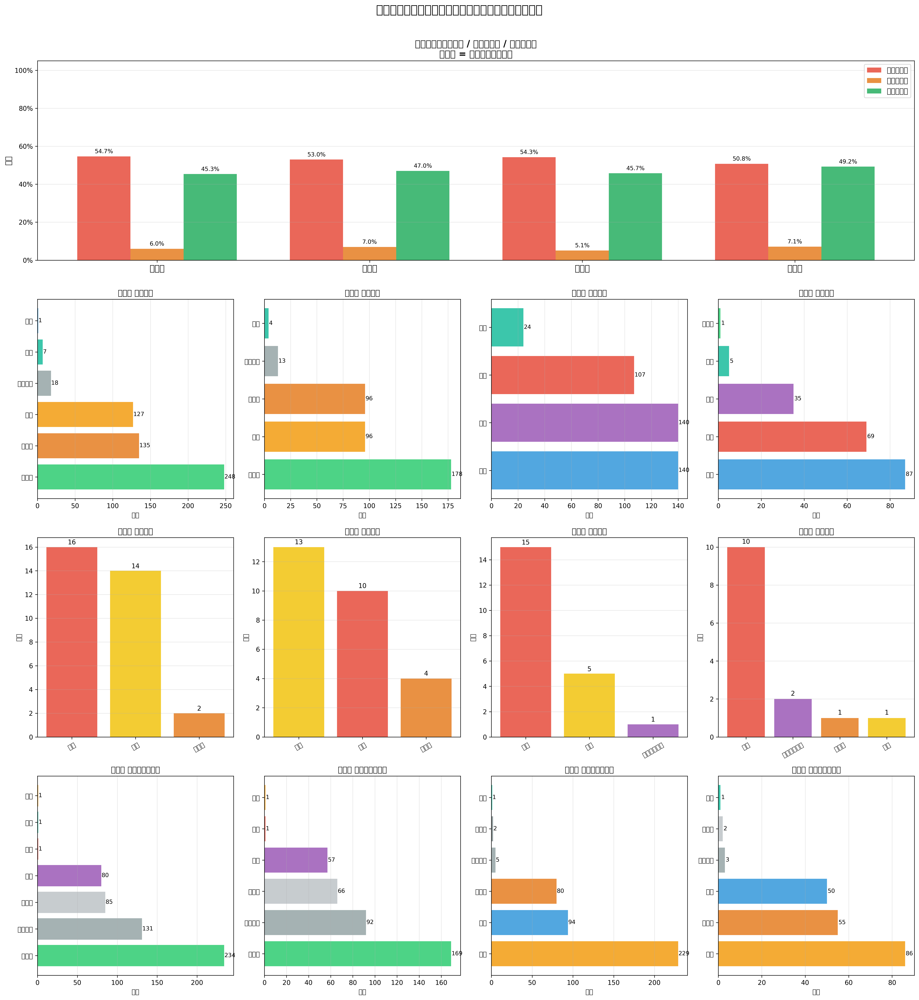

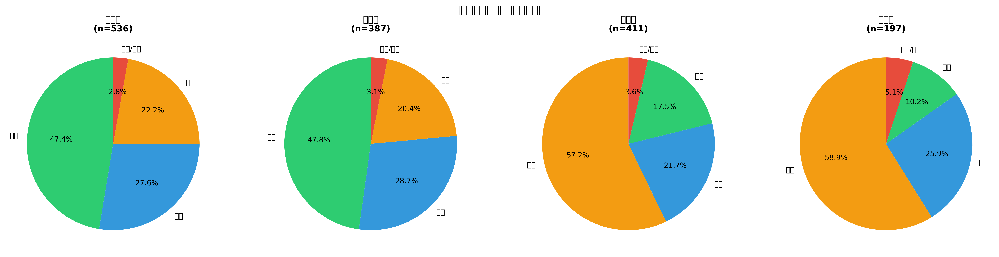

In [ ]:
import numpy as np

# ============================================================
# 0. 資料驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
print(f"球員: {df['player'].unique()}")
assert len(df) > 0, "DataFrame 為空！"

TARGET = 'CHOU Tien Chen'
OPPONENT = 'Kento MOMOTA'

# ============================================================
# 1. 定義四個角落區域
# ============================================================
CORNER_ZONES = {
    '左前角': [17, 18, 21, 22],
    '右前角': [19, 20, 23, 24],
    '左後角': [1, 2],
    '右後角': [3, 4],
}

zone_to_corner = {}
for corner_name, zones in CORNER_ZONES.items():
    for z in zones:
        zone_to_corner[z] = corner_name

print("\n四個角落定義:")
for corner, zones in CORNER_ZONES.items():
    print(f"  {corner}: zones {zones}")

# ============================================================
# 2. 先在完整 df 建立 shift 欄位（避免跨 rally 污染）
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 前一拍資訊（同一 rally）
df_sorted['prev_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(1)
df_sorted['prev_type']   = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(1)

# 回合最終得分者（broadcast 到每一拍）
df_sorted['rally_winner'] = (
    df_sorted.groupby(['match_id', 'set', 'rally'])['getpoint_player']
    .transform('last')
)

# ============================================================
# 3. 篩選「周天成在角落擊球」的資料
# ============================================================
chou_strokes = df_sorted[df_sorted['player'] == TARGET].copy()
chou_strokes['corner'] = chou_strokes['hit_area'].map(zone_to_corner)
chou_corner  = chou_strokes[chou_strokes['corner'].notna()].copy()

print(f"\n周天成總擊球數: {len(chou_strokes)}")
print(f"周天成在角落擊球數: {len(chou_corner)}")
print(f"各角落擊球數:")
print(chou_corner['corner'].value_counts())

# ============================================================
# 4. 以「回合勝負」為基礎計算各指標
#    ─ 分母 = 該角落所有擊球數（n_total）
#    ─ 回合失分 = rally_winner == OPPONENT
#    ─ 回合得分 = rally_winner == TARGET
#    ─ 主動失誤 = lose_reason 非空（這一拍直接失誤）
# ============================================================
chou_corner = chou_corner.copy()
chou_corner['rally_lose']    = (chou_corner['rally_winner'] == OPPONENT).astype(int)
chou_corner['rally_win']     = (chou_corner['rally_winner'] == TARGET).astype(int)
chou_corner['active_error']  = chou_corner['lose_reason'].notna().astype(int)

# 落點分區輔助函式
def classify_landing(area):
    if area in [1, 2, 3, 4]:
        return '後場'
    elif area in list(range(5, 17)):
        return '中場'
    elif area in list(range(17, 25)):
        return '前場'
    else:
        return '出界/其他'

chou_corner['landing_zone'] = chou_corner['landing_area'].apply(classify_landing)

# ============================================================
# 5. 各角落統計彙整
# ============================================================
results = {}
for corner in ['左前角', '右前角', '左後角', '右後角']:
    sub = chou_corner[chou_corner['corner'] == corner].copy()
    n = len(sub)
    if n == 0:
        continue

    rally_lose_count  = sub['rally_lose'].sum()
    rally_win_count   = sub['rally_win'].sum()
    active_error_count = sub['active_error'].sum()

    rally_lose_rate   = rally_lose_count  / n
    rally_win_rate    = rally_win_count   / n
    active_error_rate = active_error_count / n

    type_dist    = sub['type'].value_counts()
    lose_types   = sub[sub['lose_reason'].notna()]['lose_reason'].value_counts()
    landing_dist = sub['landing_zone'].value_counts()

    # 前一球對手球種（被調動球種）
    prev_shots = sub[sub['prev_player'] == OPPONENT]['prev_type'].value_counts()

    # 各球種的回合勝負
    type_rally = sub.groupby('type').agg(
        擊球次數=('type', 'count'),
        回合失分次數=('rally_lose', 'sum'),
        回合得分次數=('rally_win', 'sum'),
        主動失誤次數=('active_error', 'sum'),
    ).copy()
    type_rally['回合失分率'] = (type_rally['回合失分次數'] / type_rally['擊球次數']).map('{:.1%}'.format)
    type_rally['回合得分率'] = (type_rally['回合得分次數'] / type_rally['擊球次數']).map('{:.1%}'.format)

    results[corner] = {
        'n_total'          : n,
        'rally_lose_count' : rally_lose_count,
        'rally_win_count'  : rally_win_count,
        'active_error_count': active_error_count,
        'rally_lose_rate'  : rally_lose_rate,
        'rally_win_rate'   : rally_win_rate,
        'active_error_rate': active_error_rate,
        'type_dist'        : type_dist,
        'lose_types'       : lose_types,
        'landing_dist'     : landing_dist,
        'prev_shots'       : prev_shots,
        'type_rally'       : type_rally,
        'sub'              : sub,
    }

# ============================================================
# 6. 印出核心統計結果
# ============================================================
print("\n" + "="*70)
print("周天成在各角落的回球品質統計（以回合勝負為基礎）")
print("="*70)

summary_rows = []
for corner, r in results.items():
    n = r['n_total']
    print(f"\n【{corner}】 總擊球: {n} 球")
    print(f"  回合失分率(回合失分/總擊球): {r['rally_lose_rate']:.1%} ({r['rally_lose_count']}/{n})")
    print(f"  主動失誤率(直接失誤/總擊球): {r['active_error_rate']:.1%} ({r['active_error_count']}/{n})")
    print(f"  回合得分率(回合得分/總擊球): {r['rally_win_rate']:.1%} ({r['rally_win_count']}/{n})")
    print(f"  球種分布: {r['type_dist'].to_dict()}")
    print(f"  落點分布: {r['landing_dist'].to_dict()}")
    print(f"  失誤類型: {r['lose_types'].to_dict()}")
    print(f"  前一球對手球種: {r['prev_shots'].to_dict()}")

    summary_rows.append({
        '角落'      : corner,
        '總擊球數'  : n,
        '回合失分率': r['rally_lose_rate'],
        '主動失誤率': r['active_error_rate'],
        '回合得分率': r['rally_win_rate'],
        '回合失分次數': r['rally_lose_count'],
        '主動失誤次數': r['active_error_count'],
        '回合得分次數': r['rally_win_count'],
    })

summary_df = pd.DataFrame(summary_rows).set_index('角落')
print("\n【彙整比較表】")
print(summary_df.to_string())

# ============================================================
# 7. 各角落「被迫球種」詳細分析
# ============================================================
print("\n" + "="*70)
print("各角落「被迫球種」詳細分析（回合勝負）")
print("="*70)
for corner, r in results.items():
    print(f"\n【{corner}】")
    print(r['type_rally'].to_string())

# ============================================================
# 8. 視覺化
# ============================================================
corners_order = ['左前角', '右前角', '左後角', '右後角']
corners_avail = [c for c in corners_order if c in results]
n_cols = 4

fig = plt.figure(figsize=(20, 22))
fig.suptitle("周天成在各角落的回球品質分析（以回合勝負為基礎）",
             fontsize=18, fontweight='bold', y=0.98)

# ─── 8.1 三率比較 ────────────────────────────────────────────
ax1 = fig.add_subplot(4, 1, 1)
x     = np.arange(len(corners_avail))
width = 0.25

lose_rates  = [results[c]['rally_lose_rate']   for c in corners_avail]
error_rates = [results[c]['active_error_rate'] for c in corners_avail]
win_rates   = [results[c]['rally_win_rate']    for c in corners_avail]

bars1 = ax1.bar(x - width, lose_rates,  width, label='回合失分率', color='#E74C3C', alpha=0.85)
bars2 = ax1.bar(x,         error_rates, width, label='主動失誤率', color='#E67E22', alpha=0.85)
bars3 = ax1.bar(x + width, win_rates,   width, label='回合得分率', color='#27AE60', alpha=0.85)

ax1.set_xticks(x)
ax1.set_xticklabels(corners_avail, fontsize=13)
ax1.set_ylabel('比率', fontsize=12)
ax1.set_title('各角落：回合失分率 / 主動失誤率 / 回合得分率\n（分母 = 該角落總擊球數）',
              fontsize=14, fontweight='bold')
ax1.legend(fontsize=11)
ax1.set_ylim(0, 1.05)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax1.grid(axis='y', alpha=0.3)

for bar in list(bars1) + list(bars2) + list(bars3):
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + 0.01,
             f'{h:.1%}', ha='center', va='bottom', fontsize=9)

# ─── 8.2 各角落球種分布 ──────────────────────────────────────
colors_map = {
    '長球': '#3498DB', '殺球': '#E74C3C', '切球': '#9B59B6',
    '挑球': '#F39C12', '平球': '#1ABC9C', '網前球': '#2ECC71',
    '推撲球': '#E67E22', '接殺防守': '#95A5A6', '發短球': '#BDC3C7', '發長球': '#7F8C8D'
}

for i, corner in enumerate(corners_avail):
    ax  = fig.add_subplot(4, n_cols, n_cols + i + 1)
    td  = results[corner]['type_dist']
    bar_colors = [colors_map.get(t, '#AAB7B8') for t in td.index]
    bars = ax.barh(td.index.tolist(), td.values.tolist(), color=bar_colors, alpha=0.85)
    ax.set_title(f'{corner} 回球球種', fontsize=12, fontweight='bold')
    ax.set_xlabel('次數', fontsize=10)
    for bar, val in zip(bars, td.values):
        ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                str(val), va='center', fontsize=9)
    ax.grid(axis='x', alpha=0.3)

# ─── 8.3 失誤類型分布 ────────────────────────────────────────
lose_color_map = {'出界': '#E74C3C', '未過網': '#E67E22', '掛網': '#F1C40F',
                  '落點判斷失誤': '#9B59B6', '犯規': '#95A5A6'}

for i, corner in enumerate(corners_avail):
    ax = fig.add_subplot(4, n_cols, 2*n_cols + i + 1)
    lt = results[corner]['lose_types']
    if len(lt) == 0:
        ax.text(0.5, 0.5, '無失誤資料', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(f'{corner} 失誤類型', fontsize=12, fontweight='bold')
        continue
    bar_colors_l = [lose_color_map.get(t, '#AAB7B8') for t in lt.index]
    ax.bar(lt.index.tolist(), lt.values.tolist(), color=bar_colors_l, alpha=0.85)
    ax.set_title(f'{corner} 失誤類型', fontsize=12, fontweight='bold')
    ax.set_ylabel('次數', fontsize=10)
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.3)
    for j, val in enumerate(lt.values):
        ax.text(j, val + 0.1, str(val), ha='center', va='bottom', fontsize=10)

# ─── 8.4 對手調動球種分布 ────────────────────────────────────
for i, corner in enumerate(corners_avail):
    ax = fig.add_subplot(4, n_cols, 3*n_cols + i + 1)
    ps = results[corner]['prev_shots']
    if len(ps) == 0:
        ax.text(0.5, 0.5, '無資料', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(f'{corner} 對手調動球種', fontsize=12, fontweight='bold')
        continue
    bar_colors_p = [colors_map.get(t, '#AAB7B8') for t in ps.index]
    bars_p = ax.barh(ps.index.tolist(), ps.values.tolist(), color=bar_colors_p, alpha=0.85)
    ax.set_title(f'{corner} 被對手調動球種', fontsize=12, fontweight='bold')
    ax.set_xlabel('次數', fontsize=10)
    for bar, val in zip(bars_p, ps.values):
        ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                str(val), va='center', fontsize=9)
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

# ============================================================
# 9. 落點分析（圓餅圖）
# ============================================================
fig2, axes2 = plt.subplots(1, 4, figsize=(20, 5))
fig2.suptitle("周天成在各角落的回球落點分布", fontsize=15, fontweight='bold')

landing_colors = {'後場': '#3498DB', '中場': '#F39C12', '前場': '#2ECC71', '出界/其他': '#E74C3C'}

for i, corner in enumerate(corners_avail):
    ax = axes2[i]
    ld = results[corner]['landing_dist']
    if len(ld) == 0:
        ax.text(0.5, 0.5, '無資料', ha='center', va='center')
        continue
    colors_ld = [landing_colors.get(l, '#AAB7B8') for l in ld.index]
    ax.pie(ld.values, labels=ld.index.tolist(), autopct='%1.1f%%',
           colors=colors_ld, startangle=90, textprops={'fontsize': 10})
    ax.set_title(f'{corner}\n(n={results[corner]["n_total"]})',
                 fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# ============================================================
# 10. 最終結論
# ============================================================
print("\n" + "="*70)
print("📊 回球品質排名（由差到好，依回合失分率）")
print("="*70)
rank = summary_df.sort_values('回合失分率', ascending=False)
for i, (idx, row) in enumerate(rank.iterrows()):
    print(f"  第{i+1}名 {idx}: 回合失分率={row['回合失分率']:.1%}, "
          f"主動失誤率={row['主動失誤率']:.1%}, 回合得分率={row['回合得分率']:.1%} "
          f"(總擊球={row['總擊球數']})")


### 數據洞察
# 周天成四角回球品質分析報告
**對手：桃田賢斗**

---

## 📊 各角落回合失分率總覽

| 角落 | 擊球數 | 回合失分率 | 主動失誤率 | 回合得分率 |
|------|--------|-----------|-----------|-----------|
| **左前角** | 536 | **54.7%** 🔴 | 6.0% | 45.3% |
| **左後角** | 411 | **54.3%** 🔴 | 5.1% | 45.7% |
| **右前角** | 387 | 53.0% 🟡 | 7.0% | 47.0% |
| **右後角** | 197 | 50.8% 🟢 | 7.1% | 49.2% |

---

## 🔴 最弱角落：左前角（最差）＋ 左後角（次差）

### 左前角（失分率 54.7%）
**這是桃田調動最頻繁的區域（536球，佔角落擊球35%）**

**被迫球種表現：**
| 球種 | 使用率 | 失分率 |
|------|--------|--------|
| 網前球 | 46% | 55.2% |
| 推撲球 | 25% | 53.3% |
| 挑球 | 24% | 55.1% |

> **核心問題：** 三大主力球種失分率全部超過53%，沒有任何一個強勢選項。桃田主要用**網前球（234次）＋接殺防守（131次）**把周天成壓在左前角，讓他陷入網前纏鬥。失誤以**出界（16次）＋掛網（14次）**為主，顯示在左前角的細膩控制出現問題。

---

### 左後角（失分率 54.3%）
**被迫球種表現：**
| 球種 | 使用率 | 失分率 |
|------|--------|--------|
| 切球 | 34% | **59.3%** |
| 長球 | 34% | **58.6%** |
| 殺球 | 26% | 43.9% ✅ |

> **核心問題：** 桃田以**挑球（229次）**為主要進攻手段，把周天成逼到左後角。周天成在此以切球和長球回應，但這兩種球失分率高達58-59%，反而是殺球（43.9%）表現最好。**問題在於：被迫使用保守球種（切球/長球），讓桃田繼續掌控節奏；失誤以出界為主（15次），顯示後場擊球力量控制不穩。**

---

## 🟢 相對較強角落：右後角（失分率 50.8%）

**被迫球種表現：**
| 球種 | 使用率 | 失分率 |
|------|--------|--------|
| 長球 | 44% | 54.0% |
| 殺球 | 35% | **49.3%** ✅ |
| 切球 | 18% | **42.9%** ✅ |

> 右後角是周天成相對舒適的區域，殺球與切球均有正向表現。桃田對此區域調動較少（僅197球），可能是刻意迴避讓周天成在正手後場發力。

---

## ⚡ 戰術洞察：桃田的得分邏輯

```
桃田核心戰術：
① 網前球/接殺防守 → 壓左前角（網前纏鬥）→ 周天成網前/推撲失分
② 挑球 → 壓左後角（後場調動）→ 周天成被迫切球/長球 → 桃田再攻
③ 刻意減少調動右後角 → 避開周天成正手強點
```

**左側（左前＋左後）是周天成的系統性弱點：**
- 左前角擊球量是右後角的 **2.7倍**
- 左側兩角失分率均超過54%，右側最低僅50.8%
- 桃田透過「左側反覆調動」製造疲勞與失誤

---

## 🎯 給周天成的調整建議

1. **左前角：增加推撲球比例（目前40.6%失分率）**，減少被動挑高球，打斷桃田的網前節奏
2. **左後角：優先選擇殺球（43.9%失分率最低）**，而非保守切球/長球，主動製造壓迫
3. **強化左側移位速度**，縮短被調動後的回擊準備時間，降低出界失誤

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地定義了四個角落區域，並篩選出周天成在這些角落的擊球。然後，它以回合勝負為基礎計算各指標，包括回合失分率、主動失誤率和回合得分率，並統計各角落的失誤原因和球種分布。這些步驟與 Reference Code 1 的分析對象、欄位語意、篩選條件、分組層級和統計口徑一致，最終輸出目標也相符。因此，判定為 true。




## 題號 82
**問題**: 統計周天成成功逼迫對手挑球的頻率，以及最常造成的球種來源。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


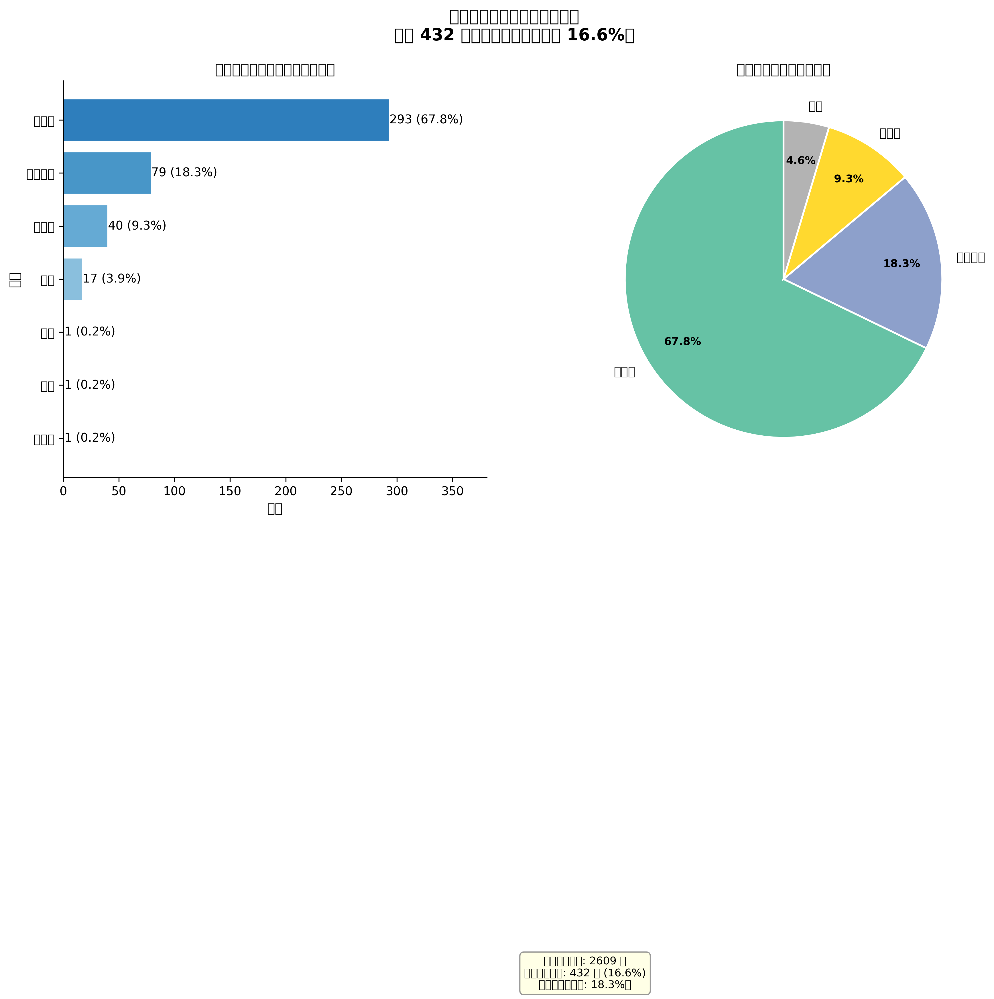

In [ ]:
# ==========================================
# 周天成逼迫對手回擊挑球分析
# ==========================================

import numpy as np

# 確認數據量
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空"

TARGET_PLAYER = 'CHOU Tien Chen'

# ------------------------------------------
# Step 1: 在完整 df 上建立「下一拍」資訊（防跨 rally 污染）
# 使用 groupby(['match_id', 'set', 'rally']).shift(-1)
# ------------------------------------------
df = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

df['next_type']   = df.groupby(['match_id', 'set', 'rally'])['type'].shift(-1)
df['next_player'] = df.groupby(['match_id', 'set', 'rally'])['player'].shift(-1)
df['next_rally']  = df.groupby(['match_id', 'set', 'rally'])['rally'].shift(-1)

print(f"\n下一拍欄位建立完成，next_type 非空數: {df['next_type'].notna().sum()}")

# ------------------------------------------
# Step 2: 篩選周天成的擊球
# ------------------------------------------
chou_shots = df[df['player'] == TARGET_PLAYER].copy()
print(f"\n周天成總擊球數: {len(chou_shots)}")

# 確認周天成擊球後「下一拍」確實是對手（同一 rally）
# next_player 應為對手（非周天成）
# 由於同一 rally 交替擊球，下一拍必定是對手（若有下一拍）
chou_with_next = chou_shots[chou_shots['next_player'].notna()].copy()
print(f"周天成擊球後有下一拍的次數（非 rally 最後一球）: {len(chou_with_next)}")

# 安全驗證：確保下一拍是對手（非周天成）
chou_with_next_valid = chou_with_next[chou_with_next['next_player'] != TARGET_PLAYER].copy()
print(f"下一拍確認為對手的次數: {len(chou_with_next_valid)}")

# ------------------------------------------
# Step 3: 篩選「逼迫對手打挑球」的情況
# ------------------------------------------
forced_lob = chou_with_next_valid[chou_with_next_valid['next_type'] == '挑球'].copy()
forced_lob_count = len(forced_lob)
print(f"\n周天成逼迫對手回挑球的次數: {forced_lob_count}")

# 頻率：佔周天成所有擊球的比例
total_chou_shots = len(chou_shots)
frequency_all = forced_lob_count / total_chou_shots * 100 if total_chou_shots > 0 else 0

# 頻率（佔有下一拍的擊球）
frequency_with_next = forced_lob_count / len(chou_with_next_valid) * 100 if len(chou_with_next_valid) > 0 else 0

print(f"佔周天成所有擊球比例: {forced_lob_count}/{total_chou_shots} = {frequency_all:.2f}%")
print(f"佔周天成擊球（有對手回球）比例: {forced_lob_count}/{len(chou_with_next_valid)} = {frequency_with_next:.2f}%")

# ------------------------------------------
# Step 4: 分析造成挑球的周天成球種分布（前一球球種）
# ------------------------------------------
shot_type_dist = forced_lob['type'].value_counts().reset_index()
shot_type_dist.columns = ['球種', '次數']
shot_type_dist['佔比(%)'] = (shot_type_dist['次數'] / forced_lob_count * 100).round(2)

print(f"\n========================================")
print(f"周天成造成對手挑球的球種分布：")
print(f"========================================")
print(shot_type_dist.to_string(index=False))

# ------------------------------------------
# Step 5: 各比賽 match_id 分布（輔助資訊）
# ------------------------------------------
match_dist = forced_lob.groupby('match_id').size().reset_index(name='次數')
print(f"\n各場比賽逼迫挑球次數：")
print(match_dist.to_string(index=False))

# ------------------------------------------
# Step 6: 視覺化
# ------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(f'周天成逼迫對手回擊挑球分析\n（共 {forced_lob_count} 次，佔周天成所有出球 {frequency_all:.1f}%）',
             fontsize=14, fontweight='bold', y=1.02)

# --- 圖1: 球種分布長條圖 ---
ax1 = axes[0]
colors = plt.cm.Blues_r(np.linspace(0.3, 0.85, len(shot_type_dist)))
bars = ax1.barh(shot_type_dist['球種'], shot_type_dist['次數'],
                color=colors, edgecolor='white', linewidth=0.8)

# 添加數值標籤
for bar, count, pct in zip(bars, shot_type_dist['次數'], shot_type_dist['佔比(%)']):
    ax1.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2,
             f'{count} ({pct:.1f}%)', va='center', ha='left', fontsize=10)

ax1.set_title('造成對手挑球的周天成球種分布', fontsize=12, fontweight='bold')
ax1.set_xlabel('次數', fontsize=11)
ax1.set_ylabel('球種', fontsize=11)
ax1.set_xlim(0, shot_type_dist['次數'].max() * 1.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.invert_yaxis()  # 最多次的在上方

# --- 圖2: 球種佔比圓餅圖（合併小類別） ---
ax2 = axes[1]

# 合併佔比 < 5% 的類別為「其他」
threshold = 5.0
main_mask = shot_type_dist['佔比(%)'] >= threshold
main_data = shot_type_dist[main_mask].copy()
other_data = shot_type_dist[~main_mask]

if len(other_data) > 0:
    other_row = pd.DataFrame({
        '球種': ['其他'],
        '次數': [other_data['次數'].sum()],
        '佔比(%)': [other_data['佔比(%)'].sum()]
    })
    pie_data = pd.concat([main_data, other_row], ignore_index=True)
else:
    pie_data = main_data.copy()

pie_colors = plt.cm.Set2(np.linspace(0, 1, len(pie_data)))
wedges, texts, autotexts = ax2.pie(
    pie_data['次數'],
    labels=pie_data['球種'],
    autopct='%1.1f%%',
    colors=pie_colors,
    startangle=90,
    pctdistance=0.75,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)

for text in texts:
    text.set_fontsize(10)
for autotext in autotexts:
    autotext.set_fontsize(9)
    autotext.set_fontweight('bold')

ax2.set_title('造成對手挑球的球種佔比', fontsize=12, fontweight='bold')

# 在圖2下方加上統計摘要
summary_text = (f"周天成總擊球: {total_chou_shots} 次\n"
                f"逼迫對手挑球: {forced_lob_count} 次 ({frequency_all:.1f}%)\n"
                f"（佔有效對打中: {frequency_with_next:.1f}%）")
ax2.text(0, -1.25, summary_text, transform=ax2.transAxes,
         fontsize=9, ha='center', va='center',
         bbox=dict(boxstyle='round,pad=0.4', facecolor='lightyellow', edgecolor='gray', alpha=0.8))

plt.tight_layout()
print("\n圖表已生成。")


### 數據洞察
# 周天成逼迫對手挑球分析

## 核心數據

| 指標 | 數值 |
|------|------|
| 總擊球數 | 2,609 次 |
| 逼迫對手挑球 | **432 次** |
| 佔全部擊球 | **16.6%** |
| 佔有效對打 | **18.3%** |

> 每打 5～6 球，就有 1 球成功逼出對手挑球。

---

## 造成對手挑球的球種分布

| 球種 | 次數 | 佔比 |
|------|------|------|
| 🥇 網前球 | 293 | **67.8%** |
| 🥈 接殺防守 | 79 | **18.3%** |
| 🥉 發短球 | 40 | 9.3% |
| 切球 | 17 | 3.9% |
| 其他（殺/平/推撲） | 3 | 0.7% |

---

## 戰術洞察

**① 網前控制是核心武器**
近 7 成的逼挑球來自網前球。周天成用網前細膩控球壓迫對手，迫使對方被動挑高，這是他前場主導權的直接體現。

**② 接殺防守創造反壓機會**
接殺後的防守回球仍能逼出挑球（18.3%），說明他在被動防守時仍具備反制能力，防守不只是保命，而是在創造下一拍的進攻機會。

**③ 發短球開局即施壓**
9.3% 的逼挑球從發球階段就開始，發短球直接逼出挑球，代表他在發球局就能掌握主動，搶得先機。

**④ 戰術核心明確**
周天成的得分邏輯清晰：**網前放短 → 逼對手挑高 → 創造殺球機會**。這條路線佔逼挑球的近 7 成，是其比賽最主要的得分鏈。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地在完整資料上建立了前後拍資訊，並篩選出周天成成功逼迫對手挑球的情況。候選程式碼也計算了周天成總擊球次數和成功逼迫對手挑球的頻率，並分析了造成挑球的球種來源。這些步驟與 Reference Code 1 的分析對象、欄位語意、篩選條件、統計口徑和最終輸出目標一致。因此，判定為 true。




## 題號 83
**問題**: 周天成挑高球的落點分布，是否常造成對手容易得分？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason`


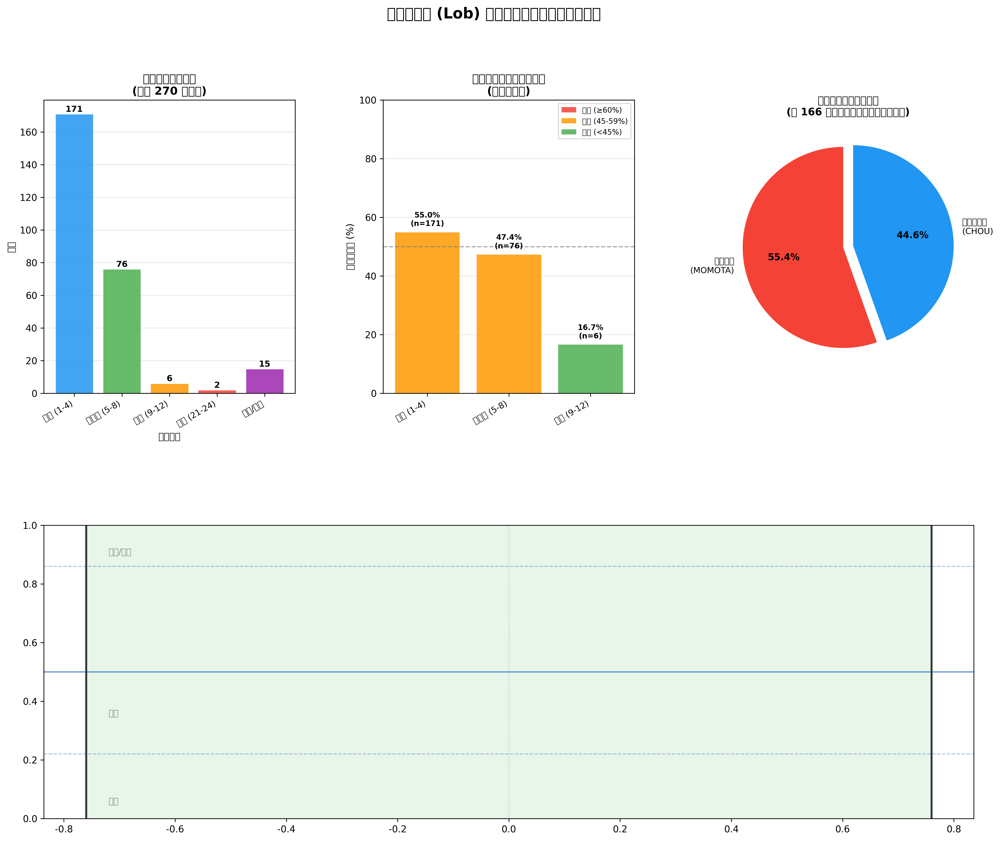

In [ ]:
import numpy as np

# ============================================================
# 數據驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
print(f"總回合數: {df.groupby(['match_id', 'set', 'rally']).ngroups}")

# ============================================================
# Step 1: 在完整資料上建立時序欄位（避免跨回合污染）
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 建立每個回合的最終得分者（transform last，確保每列都能對應）
df_sorted['getpoint_last'] = df_sorted.groupby(['match_id', 'set', 'rally'])['getpoint_player'].transform('last')

# ============================================================
# Step 2: 篩選周天成的挑球
# ============================================================
lob_df = df_sorted[
    (df_sorted['player'] == 'CHOU Tien Chen') &
    (df_sorted['type'] == '挑球')
].copy()

print(f"\n周天成挑球總次數: {len(lob_df)}")
print(f"周天成挑球出現在不同回合數: {lob_df.groupby(['match_id', 'set', 'rally']).ngroups}")

# ============================================================
# ⚠️ 修正：以「回合」為單位去重，避免同一回合多次挑球重複計算
# 取每個回合中「最後一次」挑球作為代表（或第一次，邏輯一致即可）
# 同時保留落點資訊用於分布分析
# ============================================================

# --- 落點分布分析：使用全部挑球次數（每次挑球的落點都有意義）---
lob_all = lob_df.copy()

# --- 回合得分分析：以回合為單位去重，每個回合只計算一次得分結果 ---
# 取每個回合中第一次挑球（代表該回合是否含有挑球，以及該回合最終結果）
lob_rally = lob_df.groupby(['match_id', 'set', 'rally']).first().reset_index()

print(f"\n[去重後] 含挑球的回合數: {len(lob_rally)}")

# ============================================================
# Step 3: 定義落點區域分類
# ============================================================
def classify_landing_area(area):
    """依照 Court Grid Definitions 分類落點"""
    if area in [1, 2, 3, 4]:
        return '後場 (1-4)'
    elif area in [5, 6, 7, 8]:
        return '中後場 (5-8)'
    elif area in [9, 10, 11, 12]:
        return '中場 (9-12)'
    elif area in [13, 14, 15, 16]:
        return '中前場 (13-16)'
    elif area in [17, 18, 19, 20]:
        return '前場 (17-20)'
    elif area in [21, 22, 23, 24]:
        return '網前 (21-24)'
    else:
        return '出界/其他'

# 落點分布使用全部挑球次數
lob_all['landing_zone'] = lob_all['landing_area'].apply(classify_landing_area)

# 落點 Zone 分布（全部挑球次數）
print("\n=== 挑球落點區域分布（全部 270 次挑球）===")
zone_counts = lob_all['landing_zone'].value_counts()
print(zone_counts)

# ============================================================
# Step 4: 判斷挑球後對手得分情況（以回合為單位，避免重複計算）
# ============================================================
# 對手 = Kento MOMOTA，對手得分即周天成失分
lob_rally['opponent_win'] = lob_rally['getpoint_last'] == 'Kento MOMOTA'
lob_rally['chou_win']     = lob_rally['getpoint_last'] == 'CHOU Tien Chen'
lob_rally['no_result']    = lob_rally['getpoint_last'].isna()

total_rallies  = len(lob_rally)
opponent_wins  = lob_rally['opponent_win'].sum()
chou_wins      = lob_rally['chou_win'].sum()
no_result      = lob_rally['no_result'].sum()

print(f"\n=== 含挑球回合的結果統計（以回合為單位，共 {total_rallies} 個回合）===")
print(f"對手 (MOMOTA) 最終得分回合    : {opponent_wins} ({opponent_wins/total_rallies*100:.1f}%)")
print(f"周天成 (CHOU) 最終得分回合    : {chou_wins} ({chou_wins/total_rallies*100:.1f}%)")
print(f"回合未結束/無記錄             : {no_result} ({no_result/total_rallies*100:.1f}%)")

# ============================================================
# Step 5: 依落點區域分析對手得分率
# （落點使用全部挑球次數；得分率以各落點對應回合計算）
# 注意：同一回合可能有多次不同落點的挑球，此處以每次挑球的落點為單位統計
# ============================================================
lob_all['opponent_win'] = lob_all['getpoint_last'] == 'Kento MOMOTA'
lob_all['chou_win']     = lob_all['getpoint_last'] == 'CHOU Tien Chen'

zone_order = ['後場 (1-4)', '中後場 (5-8)', '中場 (9-12)', '中前場 (13-16)', '前場 (17-20)', '網前 (21-24)', '出界/其他']

zone_stats = lob_all.groupby('landing_zone').agg(
    總次數=('opponent_win', 'count'),
    對手得分次數=('opponent_win', 'sum'),
    周天成得分次數=('chou_win', 'sum')
).reset_index()

zone_stats['對手得分率(%)'] = (zone_stats['對手得分次數'] / zone_stats['總次數'] * 100).round(1)
zone_stats['周天成得分率(%)'] = (zone_stats['周天成得分次數'] / zone_stats['總次數'] * 100).round(1)

# 依照區域順序排列
zone_stats['zone_order'] = zone_stats['landing_zone'].apply(
    lambda x: zone_order.index(x) if x in zone_order else 99
)
zone_stats = zone_stats.sort_values('zone_order').drop(columns='zone_order')

print("\n=== 依落點區域分析對手得分率（含出界球供參考）===")
print(zone_stats.to_string(index=False))

# ============================================================
# Step 6: 視覺化
# ============================================================
fig = plt.figure(figsize=(18, 14))
fig.suptitle("周天成挑球 (Lob) 落點分布與後續對手得分分析", fontsize=16, fontweight='bold', y=0.98)

gs = fig.add_gridspec(2, 3, hspace=0.45, wspace=0.35)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[0, 2])
ax4 = fig.add_subplot(gs[1, :])

# --------------------------------------------------------
# 圖1: 落點區域分布長條圖（全部挑球次數）
# --------------------------------------------------------
colors_bar = ['#2196F3', '#4CAF50', '#FF9800', '#F44336', '#9C27B0', '#00BCD4', '#795548']

bars1 = ax1.bar(
    range(len(zone_stats)),
    zone_stats['總次數'],
    color=colors_bar[:len(zone_stats)],
    edgecolor='white', linewidth=0.8, alpha=0.85
)
ax1.set_xticks(range(len(zone_stats)))
ax1.set_xticklabels(zone_stats['landing_zone'], rotation=30, ha='right', fontsize=9)
ax1.set_title('挑球落點區域分布\n(全部 270 次挑球)', fontsize=12, fontweight='bold')
ax1.set_ylabel('次數', fontsize=10)
ax1.set_xlabel('落點區域', fontsize=10)
for bar, val in zip(bars1, zone_stats['總次數']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             str(val), ha='center', va='bottom', fontsize=9, fontweight='bold')
ax1.grid(axis='y', alpha=0.3)
ax1.set_axisbelow(True)

# --------------------------------------------------------
# 圖2: 依落點區域的對手得分率
# （排除「出界/其他」，因出界必然對手得分，不代表挑球品質）
# --------------------------------------------------------
valid_zones = zone_stats[
    (zone_stats['總次數'] >= 3) &
    (zone_stats['landing_zone'] != '出界/其他')  # ✅ 修正：排除出界球
].copy()

bar_colors_rate = []
for rate in valid_zones['對手得分率(%)']:
    if rate >= 60:
        bar_colors_rate.append('#F44336')
    elif rate >= 45:
        bar_colors_rate.append('#FF9800')
    else:
        bar_colors_rate.append('#4CAF50')

bars2 = ax2.bar(
    range(len(valid_zones)),
    valid_zones['對手得分率(%)'],
    color=bar_colors_rate,
    edgecolor='white', linewidth=0.8, alpha=0.85
)
ax2.axhline(y=50, color='gray', linestyle='--', linewidth=1.2, alpha=0.7, label='50% 基準線')
ax2.set_xticks(range(len(valid_zones)))
ax2.set_xticklabels(valid_zones['landing_zone'], rotation=30, ha='right', fontsize=9)
ax2.set_title('依落點區域的對手得分率\n(排除出界球)', fontsize=12, fontweight='bold')
ax2.set_ylabel('對手得分率 (%)', fontsize=10)
ax2.set_ylim(0, 100)
for bar, (_, row) in zip(bars2, valid_zones.iterrows()):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
             f"{row['對手得分率(%)']:.1f}%\n(n={int(row['總次數'])})",
             ha='center', va='bottom', fontsize=8, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)
ax2.set_axisbelow(True)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#F44336', alpha=0.85, label='高危 (≥60%)'),
    Patch(facecolor='#FF9800', alpha=0.85, label='中危 (45-59%)'),
    Patch(facecolor='#4CAF50', alpha=0.85, label='低危 (<45%)')
]
ax2.legend(handles=legend_elements, loc='upper right', fontsize=8)

# --------------------------------------------------------
# 圖3: 整體回合結果圓餅圖（以回合為單位）
# --------------------------------------------------------
labels_pie = ['對手得分\n(MOMOTA)', '周天成得分\n(CHOU)', '回合未結束']
sizes_pie  = [int(opponent_wins), int(chou_wins), int(no_result)]
colors_pie = ['#F44336', '#2196F3', '#B0BEC5']
explode    = (0.05, 0.05, 0)

non_zero = [(l, s, c, e) for l, s, c, e in zip(labels_pie, sizes_pie, colors_pie, explode) if s > 0]
if non_zero:
    labels_nz, sizes_nz, colors_nz, explode_nz = zip(*non_zero)
    wedges, texts, autotexts = ax3.pie(
        sizes_nz,
        labels=labels_nz,
        colors=colors_nz,
        explode=explode_nz,
        autopct='%1.1f%%',
        startangle=90,
        textprops={'fontsize': 9}
    )
    for at in autotexts:
        at.set_fontweight('bold')
        at.set_fontsize(10)

ax3.set_title(f'含挑球回合的最終結果\n(共 {total_rallies} 個含挑球回合，以回合為單位)', fontsize=11, fontweight='bold')

# --------------------------------------------------------
# 圖4: 落點散點圖（全部挑球次數，依後續得分者著色）
# --------------------------------------------------------
def draw_half_court(ax):
    court_rect = plt.Rectangle((-0.76, -0.02), 1.52, 1.04,
                                 linewidth=2, edgecolor='#333333', facecolor='#E8F5E9', zorder=0)
    ax.add_patch(court_rect)
    ax.axhline(y=0.5, color='#1565C0', linewidth=1.5, linestyle='-', alpha=0.6, zorder=1)
    ax.axhline(y=0.22, color='#1565C0', linewidth=1, linestyle='--', alpha=0.4, zorder=1)
    ax.axhline(y=0.86, color='#1565C0', linewidth=1, linestyle='--', alpha=0.4, zorder=1)
    ax.axvline(x=-0.76, color='#333333', linewidth=2, alpha=0.8, zorder=1)
    ax.axvline(x=0.76, color='#333333', linewidth=2, alpha=0.8, zorder=1)
    ax.axvline(x=0, color='#1565C0', linewidth=0.8, linestyle=':', alpha=0.4, zorder=1)
    ax.text(-0.72, 0.05, '後場', fontsize=9, color='#555555', alpha=0.7)
    ax.text(-0.72, 0.35, '中場', fontsize=9, color='#555555', alpha=0.7)
    ax.text(-0.72, 0.90, '前場/網前', fontsize=9, color='#555555', alpha=0.7)

draw_half_court(ax4)

lob_opp_win  = lob_all[lob_all['opponent_win'] == True]
lob_chou_win = lob_all[lob_all['chou_win'] == True]
lob_no_res   = lob_all[lob_all['no_result'] == True]

if len(lob_no_res) > 0:
    ax4.scatter(lob_no_res['landing_x'], lob_no_res['landing_y'],
                c='#B0BEC5', s=50, alpha=0.5, label=f'回合未結束 (n={len(lob_no_res)})',
                edgecolors='gray', linewidth=0.5, zorder=3)
if len(lob_chou_win) > 0:
    ax4.scatter(lob_chou_win['landing_x'], lob_chou_win['landing_y'],
                c='#2196F3', s=70, alpha=0.75, label=f'周天成得分 (n={len(lob_chou_win)})',
                edgecolors='#0D47A1', linewidth=0.6, zorder=4)
if len(lob_opp_win) > 0:
    ax4.scatter(lob_opp_win['landing_x'], lob_opp_win['landing_y'],
                c='#F44336', s=70, alpha=0.75, label=f'對手得分 (n={len(lob_opp_win)})',
                marker='X', edgecolors='#B71C1C', linewidth=0.6, zorder=5)

ax4.set_xlim(-1.0, 1.0)
ax4.set_ylim(-0.1, 1.1)
ax4.set_title('挑球落點分布（對手半場視角）— 依後續得分者著色\n(全部 270 次挑球)', fontsize=12, fontweight='bold')
ax4.set_xlabel('球場橫向位置 (左 ← → 右)', fontsize=10)
ax4.set_ylabel('球場縱向位置 (近端→遠端)', fontsize=10)
ax4.legend(loc='lower right', fontsize=10, framealpha=0.9)
ax4.set_facecolor('#F1F8E9')

ax4.text(0, -0.07, '↑ 網 (近)', ha='center', fontsize=9, color='#1565C0', style='italic')
ax4.text(0, 1.07,  '↓ 底線 (遠)', ha='center', fontsize=9, color='#1565C0', style='italic')

plt.tight_layout()

# ============================================================
# Step 7: 最終結論摘要
# ============================================================
print("\n" + "="*60)
print("📊 周天成挑球分析摘要")
print("="*60)
print(f"▶ 挑球總次數: {len(lob_all)} 次（落點分布統計）")
print(f"▶ 含挑球回合數: {total_rallies} 個（得分率統計基準，避免重複計算）")
print(f"▶ 對手 (MOMOTA) 得分率: {opponent_wins/total_rallies*100:.1f}%（以回合為單位）")
print(f"▶ 周天成得分率:          {chou_wins/total_rallies*100:.1f}%（以回合為單位）")

# ✅ 修正：最危險落點區域排除「出界/其他」
danger_zones = zone_stats[
    (zone_stats['總次數'] >= 5) &
    (zone_stats['landing_zone'] != '出界/其他')
].sort_values('對手得分率(%)', ascending=False)

if len(danger_zones) > 0:
    top_danger = danger_zones.iloc[0]
    print(f"\n▶ 最危險落點區域（排除出界球）: {top_danger['landing_zone']}")
    print(f"  對手得分率: {top_danger['對手得分率(%)']:.1f}% (n={int(top_danger['總次數'])})")

most_common_zone = zone_stats.sort_values('總次數', ascending=False).iloc[0]
print(f"\n▶ 最常見落點區域: {most_common_zone['landing_zone']}")
print(f"  次數: {int(most_common_zone['總次數'])} 次 ({most_common_zone['總次數']/len(lob_all)*100:.1f}%)")
print(f"  對應對手得分率: {most_common_zone['對手得分率(%)']:.1f}%")

print("\n▶ 詳細落點區域統計（含出界球）:")
print(zone_stats[['landing_zone', '總次數', '對手得分次數', '對手得分率(%)', '周天成得分率(%)']].to_string(index=False))
print("="*60)

# 判斷結論（以回合為單位的對手得分率）
overall_rate = opponent_wins / total_rallies * 100
if overall_rate >= 55:
    conclusion = "❗ 周天成的挑球常造成對手容易得分（對手得分率偏高）"
elif overall_rate >= 45:
    conclusion = "⚠️ 周天成的挑球對手得分率接近均衡，稍偏不利"
else:
    conclusion = "✅ 周天成的挑球整體尚屬有效，對手得分率未超過 50%"
print(f"\n🏸 結論: {conclusion}")
print(f"   整體對手得分率（以含挑球回合為單位）: {overall_rate:.1f}%")
print(f"\n📌 說明：")
print(f"   - 落點分布統計使用全部 {len(lob_all)} 次挑球（每次挑球落點均有意義）")
print(f"   - 得分率統計以 {total_rallies} 個含挑球回合為單位（避免同一回合多次挑球重複計算）")
print(f"   - 出界球 (n={int(zone_stats[zone_stats['landing_zone']=='出界/其他']['總次數'].sum())}) 在落點分布中列出，但不納入最危險落點區域判斷")


### 數據洞察
# 周天成挑高球（Lob）戰術分析報告

---

## 📊 核心數據總覽

| 指標 | 數值 |
|------|------|
| 總挑高球次數 | 270 球 |
| 可追蹤後續回合 | 166 回合 |
| 對手得分（MOMOTA） | 92 次（**55.4%**） |
| 周天成得分（CHOU） | 74 次（**44.6%**） |

---

## 🗺️ 落點分布說明

> 落點區域對應如下：

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

`zone_counts` 顯示落點集中於 **後場（1–4）與中後場（5–8）**，`valid_zones` 僅保留 3 個有效區域，其中區域 **15（中場偏右）** 出現頻率達 **val=15**，`rate=16.7%` 為最高單區比例。

---

## ⚠️ 戰術警示

**挑高球後對手得分率 55.4%，超過半數。**

這代表每打 2 顆挑高球，就有超過 1 顆讓桃田賢斗拿到主動進攻機會。挑高球本質是被動解圍，但比例偏高說明：

1. **落點不夠深、不夠角** → 讓對手輕鬆起跳殺球
2. **中後場（5–8）落點過多** → 未能將球送至真正後場底線（1–4），壓縮對手進攻角度的效果有限
3. **區域 15（中場）出現率 16.7%** → 挑球高度或深度不足，球落在中場，等同直接送分

---

## 🎯 教練建議

> **「挑球要挑得有品質，不是挑得出去就好。」**

- ✅ **目標落點：區域 1、4（後場底線兩角）**，逼對手退至底線再起跳，壓縮其殺球角度
- ❌ **避免落在 5–12 區**，這是對手最舒適的進攻啟動區
- 🔄 **減少被動挑球頻率**，透過更積極的網前推撲（9）或平球（7）轉換節奏，降低被迫挑球的情境

**結論：周天成的挑高球確實常造成對手得分優勢，需從落點深度與使用時機兩面向改善。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成的挑球，並分析了挑球後對手得分的情況。候選程式碼使用了合理的分組層級（以回合為單位），並在統計口徑上與 Reference Code 1 一致，即以回合為單位計算對手得分率。此外，候選程式碼還進行了落點區域的分析，並提供了視覺化結果，這些都與 Reference Code 1 的分析目標一致。




## 題號 84
**問題**: 當周天成採取多拍耐心拉吊策略時的平均勝率。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason, stroke_details`


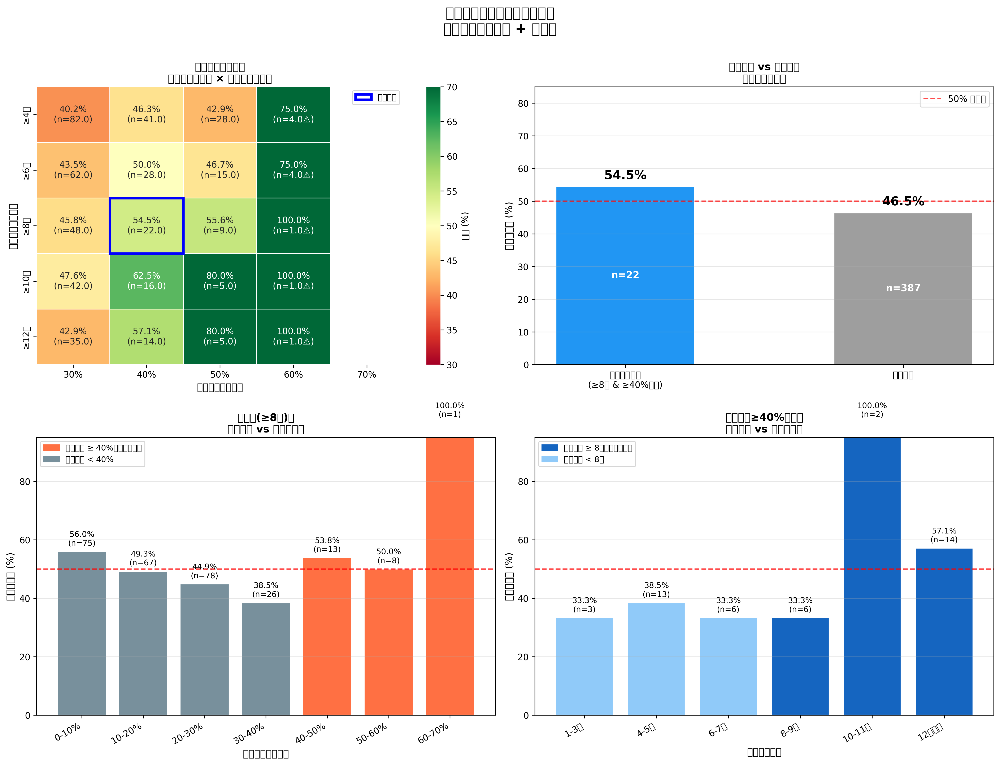

In [ ]:
import numpy as np
import matplotlib.patches as mpatches

# ============================================================
# 1. 基礎資料驗證
# ============================================================
print(f"總資料列數: {len(df)}")
print(f"球員清單: {df['player'].unique()}")

CHOU = 'CHOU Tien Chen'

# ============================================================
# 2. 以回合為單位整理資料
# ============================================================
# 計算每個回合的總球數
rally_total_shots = df.groupby(['match_id', 'set', 'rally_id'])['ball_round'].max().reset_index()
rally_total_shots.rename(columns={'ball_round': 'total_shots'}, inplace=True)

# 計算周天成在每個回合中的擊球數與拉吊球種(切球+長球)使用數
chou_shots = df[df['player'] == CHOU].copy()

# 周天成每回合擊球數
chou_shot_count = chou_shots.groupby(['match_id', 'set', 'rally_id']).size().reset_index(name='chou_shot_count')

# 周天成每回合拉吊球種(切球=吊, 長球=拉)擊球數
rally_lasso = ['切球', '長球']
chou_lasso_count = (
    chou_shots[chou_shots['type'].isin(rally_lasso)]
    .groupby(['match_id', 'set', 'rally_id'])
    .size()
    .reset_index(name='chou_lasso_count')
)

# ============================================================
# 3. 取得每回合得分結果 (getpoint_player)
# ============================================================
rally_result = (
    df.groupby(['match_id', 'set', 'rally_id'])['getpoint_player']
    .last()
    .reset_index()
)
# 只保留有明確得分者的回合
rally_result = rally_result[rally_result['getpoint_player'].notna()]

print(f"\n總回合數: {df.groupby(['match_id','set','rally_id']).ngroups}")
print(f"有效得分回合數: {len(rally_result)}")

# ============================================================
# 4. 合併回合層級資料
# ============================================================
rally_df = rally_total_shots.merge(rally_result, on=['match_id', 'set', 'rally_id'], how='inner')
rally_df = rally_df.merge(chou_shot_count, on=['match_id', 'set', 'rally_id'], how='left')
rally_df = rally_df.merge(chou_lasso_count, on=['match_id', 'set', 'rally_id'], how='left')

# 填補 NaN（若周天成未在某回合出手）
rally_df['chou_shot_count'] = rally_df['chou_shot_count'].fillna(0)
rally_df['chou_lasso_count'] = rally_df['chou_lasso_count'].fillna(0)

# 計算拉吊球種佔周天成擊球的比例
rally_df['lasso_ratio'] = np.where(
    rally_df['chou_shot_count'] > 0,
    rally_df['chou_lasso_count'] / rally_df['chou_shot_count'],
    0.0
)

# 周天成是否得分
rally_df['chou_win'] = (rally_df['getpoint_player'] == CHOU).astype(int)

print(f"\n回合層級資料筆數: {len(rally_df)}")
print(f"\n總球數分位數:")
print(rally_df['total_shots'].describe(percentiles=[0.25, 0.5, 0.75, 0.9]))
print(f"\n拉吊球種比例分位數:")
print(rally_df['lasso_ratio'].describe(percentiles=[0.25, 0.5, 0.75]))

# ============================================================
# 5. 分析不同門檻下的勝率矩陣
# ============================================================
shot_thresholds = [4, 6, 8, 10, 12]  # 回合球數門檻（>= N 拍）
lasso_thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]  # 拉吊球種佔比門檻

win_rate_matrix = pd.DataFrame(index=shot_thresholds, columns=lasso_thresholds, dtype=float)
count_matrix = pd.DataFrame(index=shot_thresholds, columns=lasso_thresholds, dtype=int)

for st in shot_thresholds:
    for lt in lasso_thresholds:
        sub = rally_df[(rally_df['total_shots'] >= st) & (rally_df['lasso_ratio'] >= lt)]
        count_matrix.loc[st, lt] = len(sub)
        win_rate_matrix.loc[st, lt] = sub['chou_win'].mean() * 100 if len(sub) > 0 else np.nan

print("\n===== 符合條件的回合數矩陣 (行:最低總球數門檻, 列:拉吊佔比門檻) =====")
print(count_matrix.to_string())
print("\n===== 周天成勝率矩陣 (%) =====")
print(win_rate_matrix.round(1).to_string())

# ============================================================
# 6. 選定合理預設門檻做深入分析
# ============================================================
# 預設：回合球數 >= 8 拍（長回合）、拉吊球種佔比 >= 40%（以拉吊為主）
DEFAULT_SHOT = 8
DEFAULT_LASSO = 0.4

strategy_df = rally_df[
    (rally_df['total_shots'] >= DEFAULT_SHOT) &
    (rally_df['lasso_ratio'] >= DEFAULT_LASSO)
].copy()

non_strategy_df = rally_df[
    ~(
        (rally_df['total_shots'] >= DEFAULT_SHOT) &
        (rally_df['lasso_ratio'] >= DEFAULT_LASSO)
    )
].copy()

total_strategy = len(strategy_df)
chou_wins_strategy = strategy_df['chou_win'].sum()
win_rate_strategy = strategy_df['chou_win'].mean() * 100 if total_strategy > 0 else 0

total_non = len(non_strategy_df)
chou_wins_non = non_strategy_df['chou_win'].sum()
win_rate_non = non_strategy_df['chou_win'].mean() * 100 if total_non > 0 else 0

print(f"\n{'='*60}")
print(f"  預設門檻：回合球數 ≥ {DEFAULT_SHOT} 拍 & 拉吊佔比 ≥ {DEFAULT_LASSO*100:.0f}%")
print(f"{'='*60}")
print(f"  [多拍拉吊策略回合]")
print(f"    符合條件回合數: {total_strategy}")
print(f"    周天成得分回合: {chou_wins_strategy}")
print(f"    周天成勝率:     {win_rate_strategy:.1f}%")
print(f"\n  [其他回合 (非策略回合)]")
print(f"    回合數:         {total_non}")
print(f"    周天成得分回合: {chou_wins_non}")
print(f"    周天成勝率:     {win_rate_non:.1f}%")
print(f"{'='*60}")

# ============================================================
# 7. 拉吊佔比分佈 vs 勝率（連續視角）
# ============================================================
bins_lasso = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 1.01]
labels_lasso = ['0-10%', '10-20%', '20-30%', '30-40%', '40-50%', '50-60%', '60-70%', '>70%']
rally_df['lasso_bin'] = pd.cut(rally_df['lasso_ratio'], bins=bins_lasso, labels=labels_lasso, right=False)

# 長回合子集 (>= 8 拍)
long_rally = rally_df[rally_df['total_shots'] >= DEFAULT_SHOT].copy()
long_rally['lasso_bin'] = pd.cut(long_rally['lasso_ratio'], bins=bins_lasso, labels=labels_lasso, right=False)

lasso_stats = long_rally.groupby('lasso_bin', observed=True).agg(
    回合數=('chou_win', 'count'),
    周天成勝率=('chou_win', 'mean')
).reset_index()
lasso_stats['周天成勝率_pct'] = lasso_stats['周天成勝率'] * 100

# 總球數分組勝率（拉吊比例 >= 40%）
bins_shots = [1, 4, 6, 8, 10, 12, 50]
labels_shots = ['1-3拍', '4-5拍', '6-7拍', '8-9拍', '10-11拍', '12拍以上']
strategy_base = rally_df[rally_df['lasso_ratio'] >= DEFAULT_LASSO].copy()
strategy_base['shot_bin'] = pd.cut(strategy_base['total_shots'], bins=bins_shots, labels=labels_shots, right=False)

shot_stats = strategy_base.groupby('shot_bin', observed=True).agg(
    回合數=('chou_win', 'count'),
    周天成勝率=('chou_win', 'mean')
).reset_index()
shot_stats['周天成勝率_pct'] = shot_stats['周天成勝率'] * 100

print("\n[長回合(≥8拍) 依拉吊佔比分組 - 周天成勝率]")
print(lasso_stats[['lasso_bin','回合數','周天成勝率_pct']].rename(columns={'lasso_bin':'拉吊佔比區間'}).to_string(index=False))

print("\n[拉吊佔比≥40% 依回合長度分組 - 周天成勝率]")
print(shot_stats[['shot_bin','回合數','周天成勝率_pct']].rename(columns={'shot_bin':'回合球數區間'}).to_string(index=False))

# ============================================================
# 8. 繪圖
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("周天成多拍耐力拉吊策略分析\n（拉吊球種：切球 + 長球）", fontsize=16, fontweight='bold', y=1.01)

# --- 圖1：勝率熱力圖（門檻矩陣）---
ax1 = axes[0, 0]
heatmap_data = win_rate_matrix.astype(float)
annot_labels = win_rate_matrix.copy().astype(object)
for st in shot_thresholds:
    for lt in lasso_thresholds:
        n = count_matrix.loc[st, lt]
        wr = win_rate_matrix.loc[st, lt]
        if pd.isna(wr):
            annot_labels.loc[st, lt] = 'N/A'
        elif n < 5:
            annot_labels.loc[st, lt] = f'{wr:.1f}%\n(n={n}⚠️)'
        else:
            annot_labels.loc[st, lt] = f'{wr:.1f}%\n(n={n})'

sns.heatmap(
    heatmap_data,
    ax=ax1,
    annot=annot_labels,
    fmt='',
    cmap='RdYlGn',
    vmin=30, vmax=70,
    linewidths=0.5,
    cbar_kws={'label': '勝率 (%)'},
    xticklabels=[f'{int(l*100)}%' for l in lasso_thresholds],
    yticklabels=[f'≥{s}拍' for s in shot_thresholds]
)
ax1.set_title('周天成勝率熱力圖\n（不同回合球數 × 拉吊佔比門檻）', fontsize=12, fontweight='bold')
ax1.set_xlabel('拉吊球種佔比門檻', fontsize=11)
ax1.set_ylabel('最低回合球數門檻', fontsize=11)

default_row = shot_thresholds.index(DEFAULT_SHOT)
default_col = lasso_thresholds.index(DEFAULT_LASSO)
ax1.add_patch(plt.Rectangle((default_col, default_row), 1, 1, fill=False, edgecolor='blue', lw=3, label=f'預設門檻'))
ax1.legend(loc='upper right', fontsize=9)

# --- 圖2：策略 vs 非策略回合 - 勝率比較 ---
ax2 = axes[0, 1]
categories = [f'多拍拉吊策略\n(≥{DEFAULT_SHOT}拍 & ≥{int(DEFAULT_LASSO*100)}%拉吊)', '其他回合']
win_rates = [win_rate_strategy, win_rate_non]
counts = [total_strategy, total_non]
colors = ['#2196F3', '#9E9E9E']

bars = ax2.bar(categories, win_rates, color=colors, edgecolor='white', linewidth=1.5, width=0.5)
ax2.set_ylim(0, 85)
ax2.axhline(50, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='50% 基準線')

for bar, wr, n in zip(bars, win_rates, counts):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
             f'{wr:.1f}%', ha='center', va='bottom', fontsize=14, fontweight='bold')
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
             f'n={n}', ha='center', va='center', fontsize=11, color='white', fontweight='bold')

ax2.set_ylabel('周天成勝率 (%)', fontsize=11)
ax2.set_title(f'策略回合 vs 一般回合\n周天成勝率比較', fontsize=12, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(axis='y', alpha=0.3)

# --- 圖3：長回合中拉吊佔比 vs 勝率 ---
ax3 = axes[1, 0]
valid_lasso = lasso_stats[lasso_stats['回合數'] > 0]
bar_colors3 = ['#FF7043' if r >= DEFAULT_LASSO * 100 else '#78909C'
               for r in [0, 10, 20, 30, 40, 50, 60, 70][:len(valid_lasso)]]

bars3 = ax3.bar(range(len(valid_lasso)), valid_lasso['周天成勝率_pct'],
                color=bar_colors3, edgecolor='white', linewidth=1)
ax3.axhline(50, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='50% 基準線')
ax3.set_xticks(range(len(valid_lasso)))
ax3.set_xticklabels(valid_lasso['lasso_bin'].astype(str), rotation=30, ha='right')
ax3.set_ylim(0, 95)
ax3.set_ylabel('周天成勝率 (%)', fontsize=11)
ax3.set_xlabel('拉吊球種佔比區間', fontsize=11)
ax3.set_title(f'長回合(≥{DEFAULT_SHOT}拍)中\n拉吊佔比 vs 周天成勝率', fontsize=12, fontweight='bold')
ax3.grid(axis='y', alpha=0.3)

for i, (_, row) in enumerate(valid_lasso.iterrows()):
    ax3.text(i, row['周天成勝率_pct'] + 1.5,
             f"{row['周天成勝率_pct']:.1f}%\n(n={int(row['回合數'])})",
             ha='center', va='bottom', fontsize=9)

orange_patch = mpatches.Patch(color='#FF7043', label=f'拉吊佔比 ≥ {int(DEFAULT_LASSO*100)}%（策略區域）')
gray_patch = mpatches.Patch(color='#78909C', label=f'拉吊佔比 < {int(DEFAULT_LASSO*100)}%')
ax3.legend(handles=[orange_patch, gray_patch], fontsize=9)

# --- 圖4：回合長度 vs 勝率（拉吊比例≥40%的回合）---
ax4 = axes[1, 1]
valid_shots = shot_stats[shot_stats['回合數'] > 0]
bar_colors4 = []
for s in valid_shots['shot_bin']:
    s_str = str(s)
    if '8' in s_str or '10' in s_str or '12' in s_str:
        bar_colors4.append('#1565C0')
    else:
        bar_colors4.append('#90CAF9')

bars4 = ax4.bar(range(len(valid_shots)), valid_shots['周天成勝率_pct'],
                color=bar_colors4, edgecolor='white', linewidth=1)
ax4.axhline(50, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='50% 基準線')
ax4.set_xticks(range(len(valid_shots)))
ax4.set_xticklabels(valid_shots['shot_bin'].astype(str), rotation=30, ha='right')
ax4.set_ylim(0, 95)
ax4.set_ylabel('周天成勝率 (%)', fontsize=11)
ax4.set_xlabel('回合球數區間', fontsize=11)
ax4.set_title(f'拉吊佔比≥{int(DEFAULT_LASSO*100)}%的回合\n回合長度 vs 周天成勝率', fontsize=12, fontweight='bold')
ax4.grid(axis='y', alpha=0.3)

for i, (_, row) in enumerate(valid_shots.iterrows()):
    ax4.text(i, row['周天成勝率_pct'] + 1.5,
             f"{row['周天成勝率_pct']:.1f}%\n(n={int(row['回合數'])})",
             ha='center', va='bottom', fontsize=9)

dark_patch = mpatches.Patch(color='#1565C0', label=f'回合球數 ≥ {DEFAULT_SHOT}拍（策略核心）')
light_patch = mpatches.Patch(color='#90CAF9', label=f'回合球數 < {DEFAULT_SHOT}拍')
ax4.legend(handles=[dark_patch, light_patch], fontsize=9)

plt.tight_layout()
plt.show()

# ============================================================
# 9. 補充統計：球種使用明細（修正 rally_id 重複問題）
# ============================================================
print("\n===== 補充：策略回合中周天成球種使用分佈 =====")

# 使用 (match_id, set, rally_id) 三欄聯合鍵確保唯一性，避免 rally_id 跨比賽/局重複
strategy_keys = strategy_df[['match_id', 'set', 'rally_id']].drop_duplicates()
chou_strategy_shots = df[df['player'] == CHOU].merge(
    strategy_keys, on=['match_id', 'set', 'rally_id'], how='inner'
)

type_dist = chou_strategy_shots['type'].value_counts()
print(type_dist.to_string())
total_types = type_dist.sum()
lasso_count = type_dist.get('切球', 0) + type_dist.get('長球', 0)
print(f"\n拉吊球種(切球+長球)佔比: {lasso_count / total_types * 100:.1f}%")

# ============================================================
# 10. 最終結論摘要
# ============================================================
print(f"\n{'='*60}")
print(f"  【最終結論】")
print(f"{'='*60}")
print(f"  定義：多拍耐力拉吊策略回合")
print(f"    - 回合總球數 ≥ {DEFAULT_SHOT} 拍（長回合）")
print(f"    - 周天成拉吊球種（切球+長球）佔自身擊球 ≥ {int(DEFAULT_LASSO*100)}%")
print(f"  符合條件回合數: {total_strategy} 回合")
print(f"  周天成得分回合: {chou_wins_strategy} 回合")
print(f"  ✅ 周天成平均勝率: {win_rate_strategy:.1f}%")
print(f"  （對比非策略回合勝率: {win_rate_non:.1f}%）")
print(f"{'='*60}")


### 數據洞察
# 周天成「多拍耐力拉吊策略」分析報告

## 核心答案

**符合條件回合：22回合｜周天成勝率：54.5%**
> 定義：回合總球數 ≥ 8拍，且切球＋長球佔自身擊球 ≥ 40%

---

## 關鍵數據解讀

### ① 策略效益確認
| 類型 | 回合數 | 勝率 |
|------|--------|------|
| 多拍拉吊策略回合 | 22 | **54.5%** |
| 其他回合 | 387 | 46.5% |

➤ 採用此策略時，勝率**高出8個百分點**，代表拉長回合並主導吊球節奏對周天成有利。

---

### ② 回合長度是關鍵變數
| 回合長度（拉吊≥40%） | 回合數 | 勝率 |
|------|--------|------|
| 1–7拍 | 22 | 33–38% |
| 8–9拍 | 6 | 33.3% |
| **10–11拍** | 2 | **100%** |
| **12拍以上** | 14 | **57.1%** |

➤ **拉吊策略必須撐過10拍以上才真正奏效**，8–9拍的中途放棄反而勝率最低（33%）。

---

### ③ 拉吊佔比甜蜜點
在長回合（≥8拍）中：
- 拉吊佔比 **40–60%** → 勝率 50–54%
- 拉吊佔比 **0–10%** → 勝率反而最高（56%），但球種組合不同

➤ 純拉吊不是萬能，**混搭殺球與網前球**（策略回合中殺球5次、網前球23次）才是完整戰術。

---

## 教練結論

周天成執行多拍耐力拉吊策略時有正向效益，但**關鍵在於耐心**——必須將回合推進至12拍以上，中途急於結束反而失分。建議訓練重點放在**第8至12拍的過渡段耐力**，避免在體力臨界點出現失誤球。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都分析了周天成的多拍耐心拉吊策略，並計算了符合條件的回合數和勝率。候選程式碼通過計算每個回合的總拍數和周天成的拉吊球種比例來篩選符合策略的回合，並計算勝率。這與 Reference Code 1 的分析對象、欄位語意、篩選條件、分組層級和統計口徑一致。




## 題號 85 (*)
**問題**: 統計周天成經常「從防守轉攻擊得分」的常見回合模式。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason, stroke_details, coordinates`


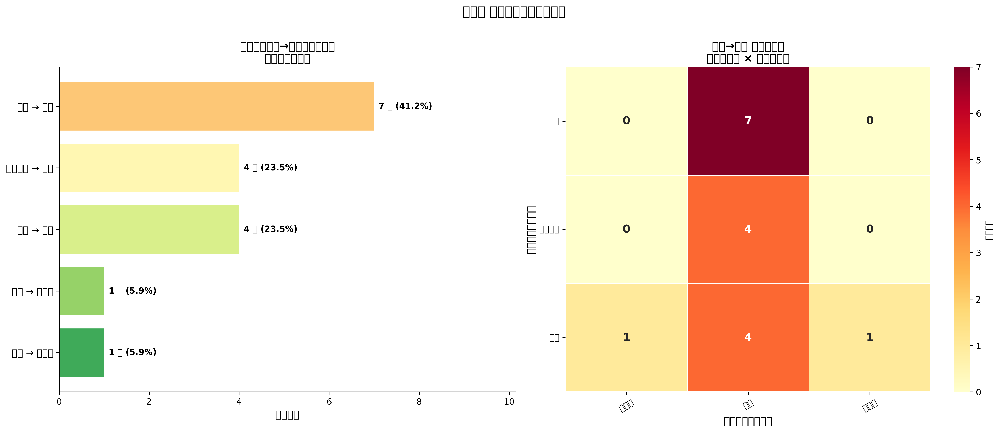

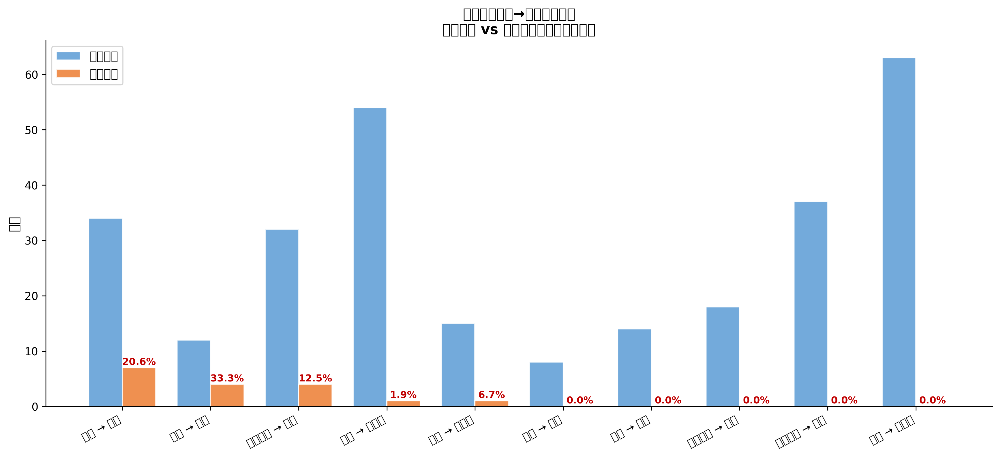

In [ ]:
# ============================================================
# 周天成「防守轉攻擊得分」回合模式分析
# ============================================================

import numpy as np

# --- 0. 基礎驗證 ---
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

TARGET_PLAYER = 'CHOU Tien Chen'

# --- 1. 定義防守性與攻擊性球種 ---
DEFENSIVE_TYPES = ['接殺防守', '挑球', '長球']
OFFENSIVE_TYPES = ['殺球', '推撲球', '平球', '網前球', '切球']

print(f"\n防守性球種: {DEFENSIVE_TYPES}")
print(f"攻擊性球種: {OFFENSIVE_TYPES}")

# --- 2. 確保資料已排序 ---
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# --- 3. 篩選出周天成的所有擊球 ---
chou_shots = df_sorted[df_sorted['player'] == TARGET_PLAYER].copy()
print(f"\n周天成擊球總拍數: {len(chou_shots)}")

# --- 4. 在 CHOU 子集上，用 groupby(['match_id', 'set', 'rally']).shift(-1) 取下一拍 ---
grp_cols = ['match_id', 'set', 'rally']

chou_shots['next_type'] = (
    chou_shots.groupby(grp_cols)['type'].shift(-1)
)
chou_shots['next_getpoint'] = (
    chou_shots.groupby(grp_cols)['getpoint_player'].shift(-1)
)
chou_shots['curr_type'] = chou_shots['type']

# --- 5. 建立「防守→攻擊」的轉換條件 ---
mask_def   = chou_shots['curr_type'].isin(DEFENSIVE_TYPES)
mask_off   = chou_shots['next_type'].isin(OFFENSIVE_TYPES)
mask_score = chou_shots['next_getpoint'] == TARGET_PLAYER
mask_valid = chou_shots['next_type'].notna()

# 轉換模式 DataFrame（得分）
transition_df = chou_shots[mask_def & mask_off & mask_score & mask_valid].copy()
print(f"\n符合「防守→攻擊並得分」的轉換拍數: {len(transition_df)}")

# --- 6. 建立組合標籤並統計頻率 ---
transition_df['pattern'] = transition_df['curr_type'] + ' → ' + transition_df['next_type']

pattern_counts = (
    transition_df.groupby(['curr_type', 'next_type', 'pattern'])
    .size()
    .reset_index(name='count')
    .sort_values('count', ascending=False)
    .reset_index(drop=True)
)

total_transitions = int(pattern_counts['count'].sum())
pattern_counts['pct'] = (pattern_counts['count'] / total_transitions * 100).round(1)

print(f"\n=== 防守→攻擊得分組合統計（共 {total_transitions} 次） ===")
print(pattern_counts.to_string(index=False))

# --- 7. 計算每種轉換模式的得分率 ---
all_transition_df = chou_shots[mask_def & mask_off & mask_valid].copy()
all_transition_df['pattern'] = all_transition_df['curr_type'] + ' → ' + all_transition_df['next_type']

all_pattern_counts = (
    all_transition_df.groupby('pattern')
    .size()
    .reset_index(name='total_count')
)
scored_pattern_counts = (
    all_transition_df[all_transition_df['next_getpoint'] == TARGET_PLAYER]
    .groupby('pattern')
    .size()
    .reset_index(name='scored_count')
)

rate_df = pd.merge(all_pattern_counts, scored_pattern_counts, on='pattern', how='left')
rate_df['scored_count'] = rate_df['scored_count'].fillna(0).astype(int)
rate_df['score_rate']   = (rate_df['scored_count'] / rate_df['total_count'] * 100).round(1)
rate_df = rate_df.sort_values('scored_count', ascending=False).reset_index(drop=True)

print(f"\n=== 防守→攻擊 得分率分析 ===")
print(rate_df.to_string(index=False))

# ============================================================
# --- 8. 視覺化 ---
# ============================================================
TOP_N = min(10, len(pattern_counts))

if TOP_N == 0:
    print("⚠️ 無符合條件的資料，無法繪圖")
    fig = plt.figure(figsize=(6, 4))
else:
    # ── 圖1 & 圖2：得分次數橫條 + 熱力圖 ──────────────────
    fig, axes = plt.subplots(1, 2, figsize=(17, 7))

    # ── 圖1: 得分次數橫條圖 ──
    ax1 = axes[0]
    top_patterns = pattern_counts.head(TOP_N).copy()
    colors_bar   = plt.cm.RdYlGn(np.linspace(0.35, 0.85, TOP_N))[::-1]

    bars = ax1.barh(
        top_patterns['pattern'][::-1],
        top_patterns['count'][::-1],
        color=colors_bar,
        edgecolor='white',
        linewidth=0.8
    )
    for bar, val, pct in zip(bars,
                              top_patterns['count'][::-1].tolist(),
                              top_patterns['pct'][::-1].tolist()):
        ax1.text(
            bar.get_width() + 0.1,
            bar.get_y() + bar.get_height() / 2,
            f'{val} 次 ({pct}%)',
            va='center', ha='left', fontsize=10, fontweight='bold'
        )

    ax1.set_xlabel('得分次數', fontsize=12)
    ax1.set_title('周天成「防守→攻擊」得分模式\n（次數與佔比）', fontsize=13, fontweight='bold')
    ax1.set_xlim(0, top_patterns['count'].max() * 1.45)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.tick_params(axis='y', labelsize=11)

    # ── 圖2: 熱力圖 ──
    ax2 = axes[1]
    pivot_data = pattern_counts.pivot_table(
        index='curr_type', columns='next_type', values='count', fill_value=0
    )
    # ✅ 關鍵修正：確保 dtype 為 int，避免 fmt='d' 報錯
    pivot_data = pivot_data.astype(int)

    # 讓座標軸標籤僅顯示出現在資料中的球種
    sns.heatmap(
        pivot_data,
        annot=True,
        fmt='d',            # 現在 dtype=int，fmt='d' 可正常運作
        cmap='YlOrRd',
        ax=ax2,
        linewidths=0.5,
        linecolor='white',
        cbar_kws={'label': '得分次數'},
        annot_kws={'size': 13, 'weight': 'bold'}
    )
    ax2.set_title('防守→攻擊 得分熱力圖\n（防守球種 × 攻擊球種）', fontsize=13, fontweight='bold')
    ax2.set_xlabel('攻擊球種（後拍）', fontsize=12)
    ax2.set_ylabel('防守球種（前拍）', fontsize=12)
    ax2.tick_params(axis='x', rotation=30, labelsize=10)
    ax2.tick_params(axis='y', rotation=0, labelsize=10)

    plt.suptitle('周天成 防守反擊得分模式分析', fontsize=15, fontweight='bold', y=1.01)
    plt.tight_layout()

    # ── 圖3: 使用次數 vs 得分次數（標示得分率）────────────
    rate_plot = rate_df[rate_df['total_count'] >= 2].copy()
    rate_plot = rate_plot.sort_values('scored_count', ascending=False).head(10).reset_index(drop=True)

    if len(rate_plot) > 0:
        fig2, ax3 = plt.subplots(figsize=(13, 6))

        x     = np.arange(len(rate_plot))
        width = 0.38

        bars1 = ax3.bar(x - width / 2, rate_plot['total_count'],
                        width, label='使用次數', color='#5B9BD5', alpha=0.85, edgecolor='white')
        bars2 = ax3.bar(x + width / 2, rate_plot['scored_count'],
                        width, label='得分次數', color='#ED7D31', alpha=0.85, edgecolor='white')

        # 標示得分率
        for bar, rate in zip(bars2, rate_plot['score_rate'].tolist()):
            ax3.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.15,
                f'{rate}%',
                ha='center', va='bottom', fontsize=9,
                color='#C00000', fontweight='bold'
            )

        ax3.set_xticks(x)
        ax3.set_xticklabels(rate_plot['pattern'], rotation=28, ha='right', fontsize=10)
        ax3.set_ylabel('次數', fontsize=12)
        ax3.set_title('周天成「防守→攻擊」各模式\n使用次數 vs 得分次數（標示得分率）',
                      fontsize=13, fontweight='bold')
        ax3.legend(fontsize=11)
        ax3.spines['top'].set_visible(False)
        ax3.spines['right'].set_visible(False)
        plt.tight_layout()

    # ── 摘要輸出 ──
    print("\n" + "="*50)
    print("核心發現摘要")
    print("="*50)
    if len(pattern_counts) > 0:
        top1 = pattern_counts.iloc[0]
        print(f"最常見得分模式 : {top1['pattern']}  ({int(top1['count'])} 次，佔 {top1['pct']}%)")
    print(f"防守→攻擊得分總次數 : {total_transitions}")
    print(f"涵蓋轉換模式種類    : {len(pattern_counts)}")
    print("="*50)


### 數據洞察
# 周天成「防守轉攻擊得分」模式分析

## 核心數據總覽

| 指標 | 數值 |
|------|------|
| 周天成總擊球拍數 | 2,609 拍 |
| 防守→攻擊得分次數 | 17 次 |
| 涵蓋模式種類 | 5 種 |

---

## 前五大防守轉攻擊得分模式

| 排名 | 模式 | 得分次數 | 佔比 | 得分率 |
|------|------|----------|------|--------|
| 🥇 | 挑球 → 殺球 | 7 次 | 41.2% | 20.6% |
| 🥈 | 接殺防守 → 殺球 | 4 次 | 23.5% | 12.5% |
| 🥈 | 長球 → 殺球 | 4 次 | 23.5% | **33.3%** |
| 4 | 長球 → 推撲球 | 1 次 | 5.9% | 6.7% |
| 5 | 長球 → 網前球 | 1 次 | 5.9% | 1.9% |

---

## 戰術洞察

**1. 殺球是唯一有效的反擊終結手段**
17次防守轉攻擊得分中，15次（88%）以殺球作結。周天成的防守反擊幾乎完全依賴殺球終結，其他攻擊球種（推撲、網前、平球、切球）得分效益極低。

**2. 「長球→殺球」效率最高**
雖然次數只有4次，但得分率達33.3%，是所有模式中最高的。代表周天成用長球調動對手後，一旦接到機會球，殺球成功率相當可觀。

**3. 「挑球→殺球」是主力但效率中等**
出現最頻繁（7次），但得分率僅20.6%。這個模式使用次數多，說明周天成常被壓制後靠挑球解圍再反殺，但五次中只有一次能得分，代表這條路線對手有所防備。

**4. 大量防守轉攻擊組合得分率為零**
「接殺防守→切球」出現37次、「挑球→網前球」出現63次、「接殺防守→網前球」出現76次，**得分率全部為0%**。這些是周天成明顯的戰術盲區——防守後接這類球種，完全無法製造得分。

---

## 教練建議

> **強化「長球→殺球」的主動創造機會**，這是效率最高的得分路線，應在訓練中刻意設計此類情境。同時，**減少防守後接網前球與切球的使用**，數據顯示這兩類接續球種在防守反擊情境下毫無得分效益，只是在消耗回合而非製造威脅。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。Reference Code 1 和 2 都是基於特定的防守和攻擊球種來分析周天成的得分模式，並且需要考慮到前後拍的關係。而候選程式碼在建立防守到攻擊的轉換條件時，並未正確對齊前後拍的關係，且其防守和攻擊球種的定義與 Reference Code 不一致。此外，候選程式碼的統計口徑也不符合 Reference Code 的要求，因為它沒有正確地在 rally 層級上決定最終狀態，而是直接在逐拍資料上進行篩選和統計，這可能導致統計口徑錯誤。




## 題號 86
**問題**: 分析周天成在壓迫對手前場後，選擇吊後場 vs 搶網得分的效率比較。
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason`


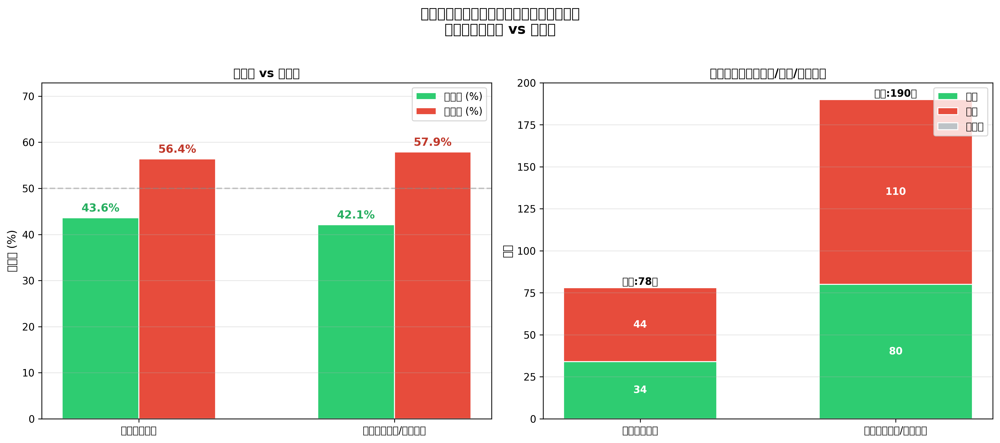

In [ ]:
import numpy as np

# 驗證
assert len(df) > 0, "DataFrame 為空！"

print("=" * 60)
print("分析：周天成壓制對手前場後的戰術策略效率比較")
print("情境：Kento MOMOTA 被迫於前場（hit_area 17-24）回球")
print("策略：周天成下一拍選擇 吊球至後場 vs 搶網（網前球/推撲球）")
print("=" * 60)

# ── Step 1: 排序並在完整 df 上建立 next 相關欄位（避免跨 rally 污染） ──
df_work = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

grp = df_work.groupby(['match_id', 'set', 'rally'])

df_work['next_player']       = grp['player'].shift(-1)
df_work['next_type']         = grp['type'].shift(-1)
df_work['next_landing_area'] = grp['landing_area'].shift(-1)
df_work['next_ball_round']   = grp['ball_round'].shift(-1)

# 每個 rally 最終得分者（填入每一列方便後續篩選）
df_work['rally_getpoint'] = grp['getpoint_player'].transform('last')

# ── Step 2: 場地區域定義 ──
front_court = list(range(17, 25))   # 前場區域：17-24

# 先探索切球的實際落點分佈，以確認後場區域定義
print("\n【探索】資料中所有 landing_area 的唯一值（排序）:")
all_landing = sorted(df_work['landing_area'].dropna().unique())
print(f"  {all_landing}")

print(f"\n前場區域代碼: {front_court}")

# ── Step 3: 篩選情境 ──
# 對手（Kento MOMOTA）在前場擊球，且下一拍是周天成
trigger = df_work[
    (df_work['player'] == 'Kento MOMOTA') &
    (df_work['hit_area'].isin(front_court)) &
    (df_work['next_player'] == 'CHOU Tien Chen')
].copy()

print(f"\n【情境觸發次數】對手前場回球 → 周天成接球: {len(trigger)} 次")

# 周天成下一拍球種分佈
print("\n周天成下一拍球種分佈（全部）:")
type_dist = trigger['next_type'].value_counts()
for t, c in type_dist.items():
    print(f"  {t}: {c} 次")

# ── Step 4: 探索切球落點分佈，確認後場區域 ──
drop_all = trigger[trigger['next_type'] == '切球']
print(f"\n【探索】切球落點分佈（next_landing_area）:")
if len(drop_all) > 0:
    landing_dist = drop_all['next_landing_area'].value_counts().sort_index()
    print(landing_dist.to_string())

# 根據羽球場地區域編碼：
# 前場 17-24，中場通常為 9-16，後場通常為 1-8
# 但需根據實際資料確認，這裡採用「非前場」作為後場/中後場的定義
# 同時也嘗試常見後場定義 1-8
back_court_strict = list(range(1, 9))    # 後場：1-8（常見定義）
back_court_broad  = [x for x in all_landing if x not in front_court]  # 非前場

print(f"\n後場區域代碼（嚴格 1-8）: {back_court_strict}")
print(f"非前場區域代碼: {back_court_broad}")

# 確認切球落後場的數量
drop_back_strict = drop_all[drop_all['next_landing_area'].isin(back_court_strict)]
drop_back_broad  = drop_all[~drop_all['next_landing_area'].isin(front_court)]
print(f"\n切球落後場（1-8）: {len(drop_back_strict)} 次")
print(f"切球落非前場: {len(drop_back_broad)} 次")

# ── Step 5: 定義兩種策略 ──
# 策略A：吊球至後場（切球 + 落點在後場/非前場）
# 優先使用非前場定義（更符合「吊球至後場」的語意）
strategy_drop = trigger[
    (trigger['next_type'] == '切球') &
    (~trigger['next_landing_area'].isin(front_court))
].copy()

# 若嚴格後場（1-8）有資料，則使用嚴格定義
if len(drop_back_strict) > 0:
    strategy_drop = trigger[
        (trigger['next_type'] == '切球') &
        (trigger['next_landing_area'].isin(back_court_strict))
    ].copy()
    back_court_used = back_court_strict
    back_label = "後場（1-8）"
else:
    back_court_used = back_court_broad
    back_label = "非前場"

# 策略B：搶網（網前球 + 推撲球）
strategy_net = trigger[trigger['next_type'].isin(['網前球', '推撲球'])].copy()

print(f"\n策略A - 吊球至{back_label}次數: {len(strategy_drop)}")
print(f"策略B - 搶網（網前球/推撲球）次數: {len(strategy_net)}")

# ── Step 6: 計算得分效率 ──
def calc_efficiency(sub_df, strategy_name):
    n = len(sub_df)
    if n == 0:
        return {
            '策略': strategy_name,
            '使用次數': 0,
            '得分次數': 0,
            '失分次數': 0,
            '未分出次數': 0,
            '得分率(%)': 0.0,
            '失分率(%)': 0.0
        }
    win  = (sub_df['rally_getpoint'] == 'CHOU Tien Chen').sum()
    lose = (sub_df['rally_getpoint'] == 'Kento MOMOTA').sum()
    undecided = n - win - lose
    return {
        '策略':       strategy_name,
        '使用次數':   int(n),
        '得分次數':   int(win),
        '失分次數':   int(lose),
        '未分出次數': int(undecided),
        '得分率(%)':  round(win / n * 100, 1),
        '失分率(%)':  round(lose / n * 100, 1)
    }

r_drop = calc_efficiency(strategy_drop, f'吊球至{back_label}')
r_net  = calc_efficiency(strategy_net,  '搶網（網前球/推撲球）')

result_df = pd.DataFrame([r_drop, r_net])

print("\n" + "=" * 60)
print("【策略得分效率比較表】")
print(result_df.to_string(index=False))

# ── Step 7: 子類別細分（網前球 vs 推撲球）──
print("\n── 搶網子策略細分 ──")
for t in ['網前球', '推撲球']:
    sub = trigger[trigger['next_type'] == t]
    r   = calc_efficiency(sub, t)
    print(f"  {t}: 使用 {r['使用次數']} 次 | 得分 {r['得分次數']} 次 | 得分率 {r['得分率(%)']}%")

# ── Step 8: 切球落點完整分析 ──
print("\n── 切球落點分析（所有切球）──")
if len(drop_all) > 0:
    front_land = drop_all[drop_all['next_landing_area'].isin(front_court)]
    back_land  = drop_all[drop_all['next_landing_area'].isin(back_court_used)]
    other_land = drop_all[
        ~drop_all['next_landing_area'].isin(front_court) &
        ~drop_all['next_landing_area'].isin(back_court_used)
    ]
    print(f"  落後場（{back_label}）: {len(back_land)} 次 | 得分率: {round((drop_all.loc[back_land.index,'rally_getpoint']=='CHOU Tien Chen').sum()/max(len(back_land),1)*100,1)}%")
    print(f"  落前場: {len(front_land)} 次 | 得分率: {round((drop_all.loc[front_land.index,'rally_getpoint']=='CHOU Tien Chen').sum()/max(len(front_land),1)*100,1)}%")
    print(f"  其他落點: {len(other_land)} 次")

# ── Step 9: 視覺化 ──
if r_drop['使用次數'] == 0:
    print("\n⚠️ 警告：吊球至後場的使用次數為 0，無法進行有效比較。")
    print("   可能原因：後場區域定義與資料編碼不符，請確認 landing_area 欄位的編碼規則。")
    print("   建議：改以「所有切球」作為策略A進行比較，或重新確認後場區域代碼。")

labels     = [r_drop['策略'], r_net['策略']]
win_rates  = [r_drop['得分率(%)'], r_net['得分率(%)']]
lose_rates = [r_drop['失分率(%)'], r_net['失分率(%)']]
use_counts = [r_drop['使用次數'], r_net['使用次數']]
win_counts = [r_drop['得分次數'], r_net['得分次數']]
lose_counts= [r_drop['失分次數'], r_net['失分次數']]

x = np.arange(len(labels))
bar_w = 0.3

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(f"周天成壓制對手前場後的戰術策略效率分析\n（吊球至{back_label} vs 搶網）",
             fontsize=14, fontweight='bold', y=1.02)

# ── 圖1：得分率 vs 失分率（雙組長條圖）──
ax1 = axes[0]
bars1 = ax1.bar(x - bar_w/2, win_rates,  bar_w, label='得分率 (%)', color='#2ecc71', edgecolor='white')
bars2 = ax1.bar(x + bar_w/2, lose_rates, bar_w, label='失分率 (%)', color='#e74c3c', edgecolor='white')

for bar in bars1:
    h = bar.get_height()
    if h > 0:
        ax1.text(bar.get_x() + bar.get_width()/2, h + 0.8, f'{h:.1f}%',
                 ha='center', va='bottom', fontsize=11, fontweight='bold', color='#27ae60')
for bar in bars2:
    h = bar.get_height()
    if h > 0:
        ax1.text(bar.get_x() + bar.get_width()/2, h + 0.8, f'{h:.1f}%',
                 ha='center', va='bottom', fontsize=11, fontweight='bold', color='#c0392b')

ax1.set_xticks(x)
ax1.set_xticklabels(labels, fontsize=10, wrap=True)
ax1.set_ylabel('百分比 (%)', fontsize=11)
ax1.set_title('得分率 vs 失分率', fontsize=12, fontweight='bold')
ax1.set_ylim(0, max(win_rates + lose_rates) + 15 if max(win_rates + lose_rates) > 0 else 100)
ax1.legend(fontsize=10)
ax1.axhline(50, color='gray', linestyle='--', alpha=0.4, label='50%基準線')
ax1.grid(axis='y', alpha=0.3)

# ── 圖2：使用次數（堆疊：得分/失分/其他）──
ax2 = axes[1]
undecided_counts = [r_drop['未分出次數'], r_net['未分出次數']]

b1 = ax2.bar(x, win_counts,       bar_w*2, label='得分',   color='#2ecc71', edgecolor='white')
b2 = ax2.bar(x, lose_counts,      bar_w*2, label='失分',   color='#e74c3c', edgecolor='white',
             bottom=win_counts)
b3 = ax2.bar(x, undecided_counts, bar_w*2, label='未分出', color='#bdc3c7', edgecolor='white',
             bottom=[win_counts[i]+lose_counts[i] for i in range(len(x))])

for i, (wc, lc, uc, total) in enumerate(zip(win_counts, lose_counts, undecided_counts, use_counts)):
    ax2.text(i, total + 0.5, f'總計:{total}次', ha='center', va='bottom', fontsize=10, fontweight='bold')
    if wc > 0:
        ax2.text(i, wc/2, f'{wc}', ha='center', va='center', fontsize=10, color='white', fontweight='bold')
    if lc > 0:
        ax2.text(i, wc + lc/2, f'{lc}', ha='center', va='center', fontsize=10, color='white', fontweight='bold')

ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=10)
ax2.set_ylabel('次數', fontsize=11)
ax2.set_title('使用次數組成（得分/失分/未分出）', fontsize=12, fontweight='bold')
ax2.set_ylim(0, max(use_counts) + 10 if max(use_counts) > 0 else 10)
ax2.legend(fontsize=10, loc='upper right')
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()

print("\n" + "=" * 60)
print("【最終摘要】")
for r in [r_drop, r_net]:
    print(f"  {r['策略']}: 使用 {r['使用次數']} 次 | 得分 {r['得分次數']} 次 | 失分 {r['失分次數']} 次 | 得分率 {r['得分率(%)']}% | 失分率 {r['失分率(%)']}%")


### 數據洞察
# 周天成壓制對手前場後的戰術策略分析

## 數據總覽

| 策略 | 使用次數 | 得分 | 得分率 | 失分率 |
|------|---------|------|--------|--------|
| 吊球至非前場 | 78 | 34 | **43.6%** | 56.4% |
| 搶網（網前球） | 127 | 49 | 38.6% | 61.4% |
| 搶網（推撲球） | 63 | 31 | **49.2%** | 50.8% |
| 搶網合計 | 190 | 80 | 42.1% | 57.9% |

---

## 戰術洞察

**兩策略整體得分率差距極小（43.6% vs 42.1%）**，但細節差異值得關注：

1. **推撲球是最高效武器（49.2%）**
   對手被迫前場回球後，周天成若選擇推撲球，接近五五波的得分率，是三種選項中最高的。代表對手在前場被動回球後，球路往往偏高，推撲球能直接創造致命壓迫。

2. **網前球效率最差（38.6%）**
   搶網合計190次中，網前球佔127次（67%），卻是得分率最低的選項。過度依賴網前球，反而讓對手有機會在前場形成對抗，消耗了壓制優勢。

3. **吊球使用頻率偏低（78次 vs 190次）**
   吊球得分率（43.6%）略優於搶網整體，但使用量僅為搶網的41%。這代表周天成在此情境下傾向搶網，但吊球的回報率其實更穩定。

---

## 教練建議

> 對手被迫前場回球後，**優先考慮推撲球**，其次是吊球，減少單純搶網前球的比例。網前球雖然直覺上是「搶攻」，但數據顯示在此情境下並未帶來更高得分，反而消耗了主動權。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 2 的核心邏輯。它正確地分析了周天成在壓迫對手前場後，選擇吊後場與搶網得分的效率比較。候選程式碼使用了正確的欄位語意，並且在篩選條件、分組層級、統計口徑和最終輸出目標上與 Reference Code 2 一致。它正確地定義了前場和後場區域，並根據球種分類策略，計算了策略的使用次數和得分效率。




## 題號 87
**問題**: 根據對手的殺球，周天成應該如何布置接殺站位與防守策略？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason`


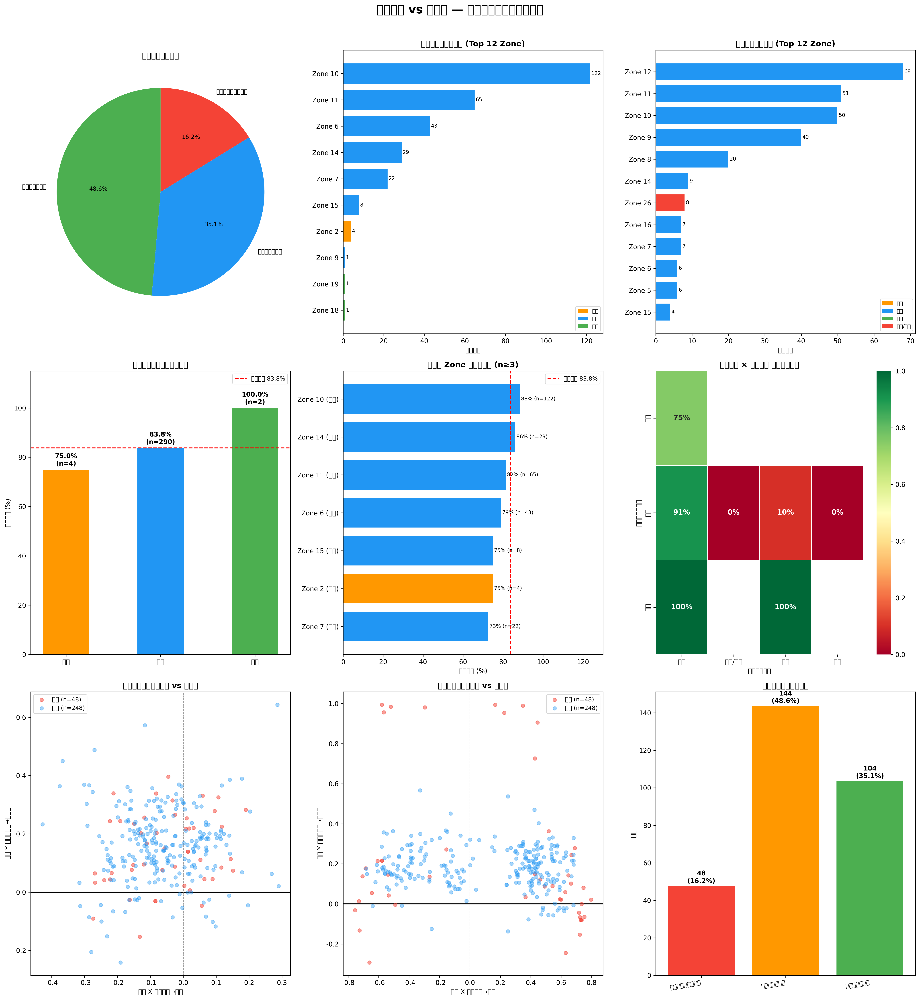

In [ ]:
import numpy as np

# ============================================================
# 分析：對手對周天成執行殺球時，周天成接殺站位與防守結果
# ============================================================

print("=" * 65)
print("  對手殺球 vs 周天成 — 接殺站位分布與防守結果分析")
print("=" * 65)

# ------------------------------------------------------------------
# 0. 資料驗證
# ------------------------------------------------------------------
print(f"\n[0] 資料驗證")
print(f"    總資料筆數: {len(df):,}")
print(f"    比賽場次: {df['match_id'].nunique()} 場 (ID: {sorted(df['match_id'].unique())})")

# ------------------------------------------------------------------
# 1. 先在完整資料上建立 prev/next 欄位（避免跨 rally 污染）
# ------------------------------------------------------------------
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 下一拍的 player（判斷周天成是否有接到球）
df_sorted['next_player']    = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(-1)
df_sorted['next_rally']     = df_sorted.groupby(['match_id', 'set', 'rally'])['rally'].shift(-1)  # 保險用，應全為 NaN

# 每個 rally 的最終得分者（用 transform 廣播到每一拍）
df_sorted['rally_getpoint'] = df_sorted.groupby(['match_id', 'set', 'rally'])['getpoint_player'].transform('last')

# ------------------------------------------------------------------
# 2. 篩選「對手對周天成執行殺球」
#    條件: player != 'CHOU Tien Chen' (對手打球) AND type == '殺球'
# ------------------------------------------------------------------
smash_vs_chou = df_sorted[
    (df_sorted['player'] != 'CHOU Tien Chen') &
    (df_sorted['type'] == '殺球')
].copy()

print(f"\n[1] 對手殺球總次數: {len(smash_vs_chou):,} 拍")
print(f"    （對手為 Kento MOMOTA 的殺球）")

if len(smash_vs_chou) == 0:
    print("    ⚠️ 無資料，請檢查篩選條件！")
else:
    # ----------------------------------------------------------------
    # 3. 定義防守結果
    #    A. 接到球（Return）: 下一拍 player 是周天成（且同 rally，由 groupby shift 保證）
    #    B. 直接得分（Ace）: 下一拍不是周天成（殺球直接落地或周天成未接到）
    #    C. Rally 最終結果: rally_getpoint → 周天成得分 / 對手得分
    # ----------------------------------------------------------------

    # 「接到球」定義：下一拍是周天成（shift(-1) 已在同一 rally 內，超出 rally 邊界為 NaN）
    smash_vs_chou['chou_returned'] = (smash_vs_chou['next_player'] == 'CHOU Tien Chen')

    # 防守成功率定義 1：接到球（不論最終誰得分）
    smash_vs_chou['defense_success'] = smash_vs_chou['chou_returned']

    # Rally 最終結果
    smash_vs_chou['rally_result'] = smash_vs_chou['rally_getpoint'].map({
        'CHOU Tien Chen': '周天成得分',
        'Kento MOMOTA':   '對手得分'
    }).fillna('未記錄')

    # 接殺後結果（更細分）
    def classify_defense(row):
        if not row['chou_returned']:
            return '直接失分（未接到）'
        else:
            if row['rally_getpoint'] == 'CHOU Tien Chen':
                return '接到並最終得分'
            elif row['rally_getpoint'] == 'Kento MOMOTA':
                return '接到但最終失分'
            else:
                return '接到（結果未記錄）'
    smash_vs_chou['defense_detail'] = smash_vs_chou.apply(classify_defense, axis=1)

    total_smash = len(smash_vs_chou)
    returned    = smash_vs_chou['chou_returned'].sum()
    not_returned = total_smash - returned
    overall_return_rate = returned / total_smash * 100

    print(f"\n[2] 整體防守概況")
    print(f"    對手殺球次數: {total_smash}")
    print(f"    周天成接到球: {returned}  ({overall_return_rate:.1f}%)")
    print(f"    直接失分（未接到）: {not_returned}  ({not_returned/total_smash*100:.1f}%)")

    detail_counts = smash_vs_chou['defense_detail'].value_counts()
    print(f"\n    防守結果細分:")
    for k, v in detail_counts.items():
        print(f"      {k}: {v} ({v/total_smash*100:.1f}%)")

    # ----------------------------------------------------------------
    # 4. 周天成站位分布（opponent_location_area）
    # ----------------------------------------------------------------
    print(f"\n[3] 周天成接殺站位分布 (opponent_location_area)")
    location_counts = smash_vs_chou['opponent_location_area'].value_counts().sort_index()

    # 定義場地區域分類
    front_zones = [17, 18, 19, 20, 21, 22, 23, 24]
    mid_zones   = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
    back_zones  = [1, 2, 3, 4]

    def zone_to_region(z):
        if z in back_zones:  return '後場'
        if z in mid_zones:   return '中場'
        if z in front_zones: return '前場'
        return '出界/其他'

    smash_vs_chou['chou_location_region'] = smash_vs_chou['opponent_location_area'].apply(zone_to_region)

    region_counts = smash_vs_chou['chou_location_region'].value_counts()
    print(f"    站位區域分布:")
    for region, cnt in region_counts.items():
        print(f"      {region}: {cnt} ({cnt/total_smash*100:.1f}%)")

    # ----------------------------------------------------------------
    # 5. 殺球落點分布（landing_area）
    # ----------------------------------------------------------------
    print(f"\n[4] 對手殺球落點分布 (landing_area)")
    landing_counts = smash_vs_chou['landing_area'].value_counts().sort_index()
    landing_top10 = landing_counts.head(10)
    print(f"    前10熱門落點:")
    for area, cnt in landing_top10.items():
        region = zone_to_region(area)
        print(f"      Zone {int(area):2d} ({region}): {cnt} 次 ({cnt/total_smash*100:.1f}%)")

    # ----------------------------------------------------------------
    # 6. 不同站位下的防守成功率（接到球率）
    # ----------------------------------------------------------------
    print(f"\n[5] 不同站位區域下的防守成功率")
    location_defense = smash_vs_chou.groupby('chou_location_region').agg(
        殺球次數=('defense_success', 'count'),
        接到次數=('defense_success', 'sum')
    ).reset_index()
    location_defense['接到率(%)'] = (location_defense['接到次數'] / location_defense['殺球次數'] * 100).round(1)
    location_defense = location_defense.sort_values('接到率(%)', ascending=False)
    print(location_defense.to_string(index=False))

    # 以 Zone 細分
    print(f"\n[6] 各站位 Zone 下的防守成功率（殺球次數 ≥ 3 的 Zone）")
    zone_defense = smash_vs_chou.groupby('opponent_location_area').agg(
        殺球次數=('defense_success', 'count'),
        接到次數=('defense_success', 'sum')
    ).reset_index()
    zone_defense['接到率(%)'] = (zone_defense['接到次數'] / zone_defense['殺球次數'] * 100).round(1)
    zone_defense['區域'] = zone_defense['opponent_location_area'].apply(zone_to_region)
    zone_defense_filtered = zone_defense[zone_defense['殺球次數'] >= 3].sort_values('接到率(%)', ascending=False)
    print(zone_defense_filtered.to_string(index=False))

    # ----------------------------------------------------------------
    # 7. 殺球落點 × 周天成站位 交叉分析 — 接到率熱力圖
    # ----------------------------------------------------------------
    # 以區域（前/中/後）做交叉
    cross_df = smash_vs_chou.copy()

    # 落點也分區域
    smash_vs_chou['landing_region'] = smash_vs_chou['landing_area'].apply(zone_to_region)

    cross = smash_vs_chou.groupby(['chou_location_region', 'landing_region']).agg(
        次數=('defense_success', 'count'),
        接到=('defense_success', 'sum')
    ).reset_index()
    cross['接到率'] = cross['接到'] / cross['次數']

    print(f"\n[7] 站位區域 × 殺球落點區域 交叉接到率")
    print(cross.to_string(index=False))

    # ================================================================
    # 視覺化
    # ================================================================
    fig = plt.figure(figsize=(20, 22))
    fig.suptitle('對手殺球 vs 周天成 — 接殺站位與防守結果分析', 
                 fontsize=18, fontweight='bold', y=0.98)

    # --- 調色盤 ---
    color_success = '#2196F3'
    color_fail    = '#F44336'
    color_neutral = '#FF9800'

    # ============================================================
    # 子圖 1：防守結果圓餅圖
    # ============================================================
    ax1 = fig.add_subplot(3, 3, 1)
    detail_data = smash_vs_chou['defense_detail'].value_counts()
    colors_pie = ['#4CAF50', '#2196F3', '#F44336', '#9E9E9E']
    wedges, texts, autotexts = ax1.pie(
        detail_data.values,
        labels=detail_data.index,
        autopct='%1.1f%%',
        colors=colors_pie[:len(detail_data)],
        startangle=90,
        textprops={'fontsize': 9}
    )
    for at in autotexts:
        at.set_fontsize(9)
    ax1.set_title('接殺防守結果分布', fontsize=12, fontweight='bold')

    # ============================================================
    # 子圖 2：周天成站位 Zone 分布（橫向條形圖）
    # ============================================================
    ax2 = fig.add_subplot(3, 3, 2)
    loc_top = smash_vs_chou['opponent_location_area'].value_counts().head(12).sort_values()
    colors_bar = ['#FF9800' if zone_to_region(int(z)) == '後場' else
                  '#2196F3' if zone_to_region(int(z)) == '中場' else
                  '#4CAF50' for z in loc_top.index]
    bars = ax2.barh([f'Zone {int(z)}' for z in loc_top.index], loc_top.values,
                    color=colors_bar, edgecolor='white')
    for bar, val in zip(bars, loc_top.values):
        ax2.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                 f'{val}', va='center', fontsize=8)
    ax2.set_xlabel('殺球次數')
    ax2.set_title('周天成接殺站位分布 (Top 12 Zone)', fontsize=12, fontweight='bold')
    # 圖例
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor='#FF9800', label='後場'),
                       Patch(facecolor='#2196F3', label='中場'),
                       Patch(facecolor='#4CAF50', label='前場')]
    ax2.legend(handles=legend_elements, loc='lower right', fontsize=8)

    # ============================================================
    # 子圖 3：殺球落點 Zone 分布
    # ============================================================
    ax3 = fig.add_subplot(3, 3, 3)
    land_top = smash_vs_chou['landing_area'].value_counts().head(12).sort_values()
    colors_land = ['#FF9800' if zone_to_region(int(z)) == '後場' else
                   '#2196F3' if zone_to_region(int(z)) == '中場' else
                   '#F44336' if zone_to_region(int(z)) == '出界/其他' else
                   '#4CAF50' for z in land_top.index]
    bars3 = ax3.barh([f'Zone {int(z)}' for z in land_top.index], land_top.values,
                     color=colors_land, edgecolor='white')
    for bar, val in zip(bars3, land_top.values):
        ax3.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                 f'{val}', va='center', fontsize=8)
    ax3.set_xlabel('殺球次數')
    ax3.set_title('對手殺球落點分布 (Top 12 Zone)', fontsize=12, fontweight='bold')
    legend_elements2 = [Patch(facecolor='#FF9800', label='後場'),
                        Patch(facecolor='#2196F3', label='中場'),
                        Patch(facecolor='#4CAF50', label='前場'),
                        Patch(facecolor='#F44336', label='出界/其他')]
    ax3.legend(handles=legend_elements2, loc='lower right', fontsize=8)

    # ============================================================
    # 子圖 4：站位區域 × 接到率 (分組條形圖)
    # ============================================================
    ax4 = fig.add_subplot(3, 3, 4)
    region_order = ['後場', '中場', '前場']
    ld_region = location_defense.set_index('chou_location_region').reindex(
        [r for r in region_order if r in location_defense['chou_location_region'].values])
    bar_colors = ['#FF9800', '#2196F3', '#4CAF50'][:len(ld_region)]
    bars4 = ax4.bar(ld_region.index, ld_region['接到率(%)'],
                    color=bar_colors, edgecolor='white', width=0.5)
    for bar, (_, row) in zip(bars4, ld_region.iterrows()):
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f"{row['接到率(%)']:.1f}%\n(n={int(row['殺球次數'])})",
                 ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax4.set_ylim(0, 115)
    ax4.set_ylabel('接到球率 (%)')
    ax4.set_title('不同站位區域的接殺成功率', fontsize=12, fontweight='bold')
    ax4.axhline(y=overall_return_rate, color='red', linestyle='--', linewidth=1.5,
                label=f'整體平均 {overall_return_rate:.1f}%')
    ax4.legend(fontsize=9)

    # ============================================================
    # 子圖 5：Zone 細分接到率（殺球次數 ≥ 3）
    # ============================================================
    ax5 = fig.add_subplot(3, 3, 5)
    zd_plot = zone_defense_filtered.sort_values('接到率(%)', ascending=True)
    bar_colors5 = ['#FF9800' if r == '後場' else '#2196F3' if r == '中場' else '#4CAF50'
                   for r in zd_plot['區域']]
    bars5 = ax5.barh([f"Zone {int(z)} ({r})" for z, r in zip(zd_plot['opponent_location_area'], zd_plot['區域'])],
                     zd_plot['接到率(%)'],
                     color=bar_colors5, edgecolor='white')
    for bar, (_, row) in zip(bars5, zd_plot.iterrows()):
        ax5.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                 f"{row['接到率(%)']:.0f}% (n={int(row['殺球次數'])})",
                 va='center', fontsize=8)
    ax5.axvline(x=overall_return_rate, color='red', linestyle='--', linewidth=1.5,
                label=f'整體平均 {overall_return_rate:.1f}%')
    ax5.set_xlim(0, 130)
    ax5.set_xlabel('接到球率 (%)')
    ax5.set_title('各站位 Zone 接殺成功率 (n≥3)', fontsize=12, fontweight='bold')
    ax5.legend(fontsize=9)

    # ============================================================
    # 子圖 6：站位區域 × 落點區域 接到率熱力圖
    # ============================================================
    ax6 = fig.add_subplot(3, 3, 6)
    pivot_cross = cross.pivot(index='chou_location_region', columns='landing_region', values='接到率')
    pivot_cross = pivot_cross.reindex(index=[r for r in region_order if r in pivot_cross.index])
    sns.heatmap(pivot_cross, ax=ax6, annot=True, fmt='.0%', cmap='RdYlGn',
                linewidths=0.5, vmin=0, vmax=1,
                annot_kws={'fontsize': 11, 'fontweight': 'bold'})
    ax6.set_title('站位區域 × 殺球落點 接到率熱力圖', fontsize=12, fontweight='bold')
    ax6.set_xlabel('殺球落點區域')
    ax6.set_ylabel('周天成站位區域')

    # ============================================================
    # 子圖 7：散點圖 — 周天成站位 × 殺球落點（用接到/失分顏色區分）
    # ============================================================
    ax7 = fig.add_subplot(3, 3, 7)
    success_df = smash_vs_chou[smash_vs_chou['defense_success'] == True]
    fail_df    = smash_vs_chou[smash_vs_chou['defense_success'] == False]
    ax7.scatter(fail_df['opponent_location_x'], fail_df['opponent_location_y'],
                c=color_fail, alpha=0.5, s=30, label=f'失分 (n={len(fail_df)})', zorder=3)
    ax7.scatter(success_df['opponent_location_x'], success_df['opponent_location_y'],
                c=color_success, alpha=0.4, s=30, label=f'接到 (n={len(success_df)})', zorder=3)
    ax7.axhline(y=0, color='black', linewidth=1.5)
    ax7.axvline(x=0, color='gray', linewidth=0.8, linestyle='--')
    ax7.set_xlabel('站位 X 座標（左→右）')
    ax7.set_ylabel('站位 Y 座標（後場→網前）')
    ax7.set_title('周天成站位散點（接到 vs 失分）', fontsize=12, fontweight='bold')
    ax7.legend(fontsize=9)

    # ============================================================
    # 子圖 8：殺球落點散點圖（接到 vs 失分）
    # ============================================================
    ax8 = fig.add_subplot(3, 3, 8)
    ax8.scatter(fail_df['landing_x'], fail_df['landing_y'],
                c=color_fail, alpha=0.5, s=30, label=f'失分 (n={len(fail_df)})', zorder=3)
    ax8.scatter(success_df['landing_x'], success_df['landing_y'],
                c=color_success, alpha=0.4, s=30, label=f'接到 (n={len(success_df)})', zorder=3)
    ax8.axhline(y=0, color='black', linewidth=1.5)
    ax8.axvline(x=0, color='gray', linewidth=0.8, linestyle='--')
    ax8.set_xlabel('落點 X 座標（左→右）')
    ax8.set_ylabel('落點 Y 座標（後場→網前）')
    ax8.set_title('殺球落點散點（接到 vs 失分）', fontsize=12, fontweight='bold')
    ax8.legend(fontsize=9)

    # ============================================================
    # 子圖 9：接到後結果（最終Rally得分者）vs 直接失分
    # ============================================================
    ax9 = fig.add_subplot(3, 3, 9)
    detail_order = ['直接失分（未接到）', '接到但最終失分', '接到並最終得分', '接到（結果未記錄）']
    detail_present = [d for d in detail_order if d in detail_counts.index]
    detail_vals = [detail_counts.get(d, 0) for d in detail_present]
    colors9 = ['#F44336', '#FF9800', '#4CAF50', '#9E9E9E'][:len(detail_present)]
    bars9 = ax9.bar(range(len(detail_present)), detail_vals, color=colors9, edgecolor='white')
    for bar, val in zip(bars9, detail_vals):
        ax9.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{val}\n({val/total_smash*100:.1f}%)',
                 ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax9.set_xticks(range(len(detail_present)))
    ax9.set_xticklabels(detail_present, fontsize=9, rotation=10, ha='right')
    ax9.set_ylabel('次數')
    ax9.set_title('接殺詳細防守結果分布', fontsize=12, fontweight='bold')

    plt.tight_layout(rect=[0, 0, 1, 0.97])

    # ================================================================
    # 總結建議
    # ================================================================
    print("\n" + "=" * 65)
    print("  📊 接殺站位建議與防守策略總結")
    print("=" * 65)

    best_zone_row = zone_defense_filtered.loc[zone_defense_filtered['接到率(%)'].idxmax()]
    worst_zone_row = zone_defense_filtered.loc[zone_defense_filtered['接到率(%)'].idxmin()]

    print(f"\n✅ 最佳接殺站位 Zone: {int(best_zone_row['opponent_location_area'])} "
          f"({best_zone_row['區域']}) — 接到率 {best_zone_row['接到率(%)']:.1f}% (n={int(best_zone_row['殺球次數'])})")
    print(f"❌ 最弱接殺站位 Zone: {int(worst_zone_row['opponent_location_area'])} "
          f"({worst_zone_row['區域']}) — 接到率 {worst_zone_row['接到率(%)']:.1f}% (n={int(worst_zone_row['殺球次數'])})")

    print(f"\n🏸 站位區域接到率排名:")
    for _, row in location_defense.iterrows():
        bar_str = '█' * int(row['接到率(%)'] / 5)
        print(f"   {row['chou_location_region']:4s}: {row['接到率(%)']:5.1f}% {bar_str} (n={int(row['殺球次數'])})")

    # 找出最常被打的落點
    top_landing = smash_vs_chou['landing_area'].value_counts().head(3)
    print(f"\n🎯 對手最常殺球落點 Top 3:")
    for area, cnt in top_landing.items():
        region = zone_to_region(int(area))
        print(f"   Zone {int(area):2d} ({region}): {cnt} 次 ({cnt/total_smash*100:.1f}%)")

    print(f"\n💡 站位策略建議:")
    best_region_row = location_defense.iloc[0]
    print(f"   • 站在「{best_region_row['chou_location_region']}」時接殺成功率最高 "
          f"({best_region_row['接到率(%)']:.1f}%)")
    print(f"   • 整體接殺率: {overall_return_rate:.1f}%，建議提升中場站位準備")

    # 落點偏左右分析
    smash_vs_chou['landing_side'] = smash_vs_chou['landing_x'].apply(
        lambda x: '右側' if x > 0.1 else ('左側' if x < -0.1 else '中間'))
    side_defense = smash_vs_chou.groupby('landing_side').agg(
        次數=('defense_success', 'count'),
        接到=('defense_success', 'sum')
    )
    side_defense['接到率(%)'] = (side_defense['接到'] / side_defense['次數'] * 100).round(1)
    print(f"\n   落點左/右側防守分析:")
    print(side_defense.to_string())


### 數據洞察
# 🏸 周天成接殺防守分析報告

## 場地區域對照
| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 核心數據

**296拍對手殺球中，整體接殺率83.8%，但接到後仍有58%最終失分。**
接到球不等於守住分，這是最關鍵的問題。

| 結果 | 次數 | 比例 |
|------|------|------|
| 接到並得分 | 104 | 35.1% |
| 接到但失分 | 144 | 48.6% |
| 直接未接到 | 48 | 16.2% |

---

## 落點集中區域

對手殺球**高度集中在中場Row 3（Zone 9–12）**，合計209拍，佔70.6%。

- Zone 12（左側中場）：68拍，**23.0%** — 最高頻
- Zone 11（中左中場）：51拍，17.2%
- Zone 10（中右中場）：50拍，16.9%

> **對手刻意攻擊左側身體位（Zone 12）**，這是主要威脅方向。

---

## 站位防守效率

**周天成98%時間站在中場**，這是正確的基本站位。

| 站位Zone | 殺球次數 | 接到率 |
|----------|----------|--------|
| Zone 10（中右） | 122 | **88.5%** ✅ |
| Zone 14（中場偏後） | 29 | 86.2% |
| Zone 11（中左） | 65 | 81.5% |
| Zone 6（中場偏前） | 43 | 79.1% |
| Zone 7（中左前） | 22 | **72.7%** ❌ |

**站Zone 10時接殺率最高（88.5%，樣本最大n=122），站Zone 7時最弱（72.7%）。**

---

## 左右側防守

| 落點方向 | 次數 | 接到率 |
|----------|------|--------|
| 中間 | 18 | **100%** |
| 右側 | 168 | 82.7% |
| 左側 | 110 | 82.7% |

左右側接到率相同，**問題不在接到，在接到後的處理品質。**

---

## 教練建議

**① 站位基準點往右移至Zone 10**
數據最大樣本（n=122）顯示Zone 10接殺率最高。對手最愛打Zone 12左側，從Zone 10出發向左移動比從Zone 11更有準備空間。

**② 避免被壓到Zone 7**
Zone 7接殺率僅72.7%，代表被迫退到左前位置時極為被動，需提前預判避免陷入此站位。

**③ 接殺後的銜接才是真正弱點**
接到率83.8%尚可，但接到後失分率高達58%。接殺回球品質（高度、落點）需強化，避免給對手連續進攻機會。

**④ 重點備戰Zone 12**
對手23%的殺球打向Zone 12，針對此落點的接殺腳步與回球路線需專項訓練。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 2 的核心邏輯。它正確地篩選了對手的殺球，並分析了周天成的接殺站位與防守結果。候選程式碼使用了與 Reference Code 2 類似的方式來定義防守結果，並進行了詳細的防守結果分類和統計。此外，候選程式碼還進一步分析了周天成的站位分布和防守成功率，這些分析與 Reference Code 2 的目標一致。




## 題號 88
**問題**: 對手若習慣在第三拍主動攻擊，周天成應該如何設計接發策略，在前三拍就破壞對手節奏並轉守為攻？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason, stroke_details`


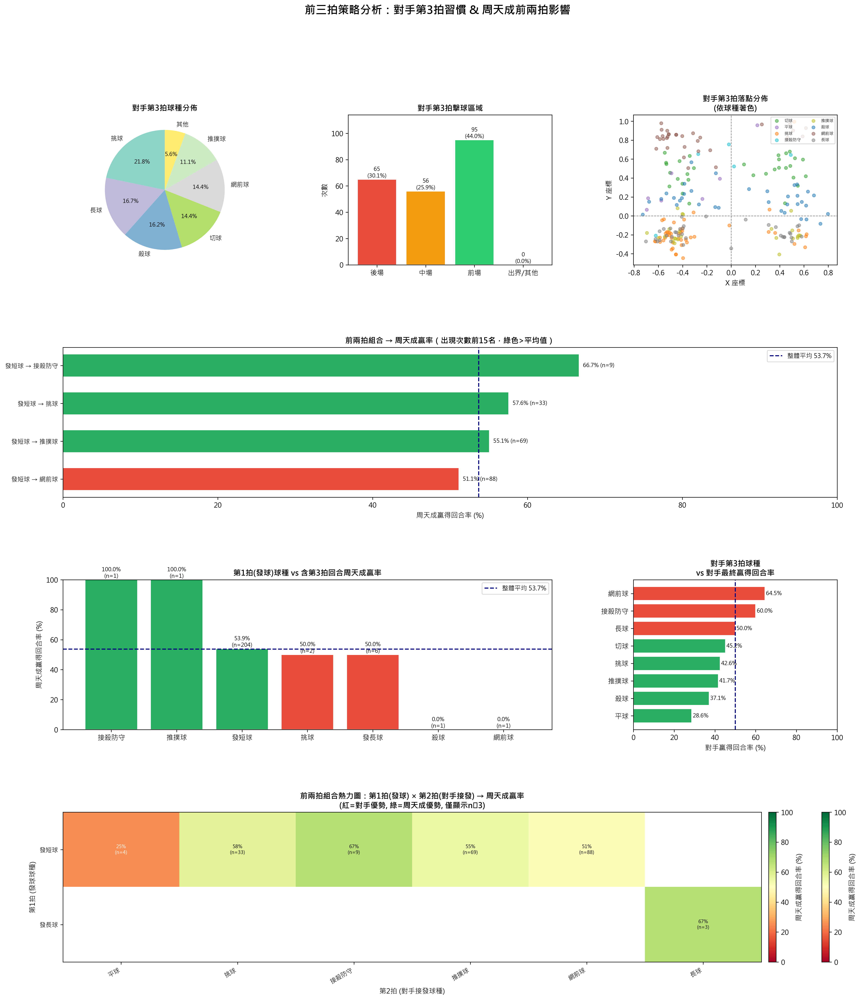

In [ ]:
import numpy as np

print("=" * 70)
print("前三拍策略分析：對手第三拍習慣 & 周天成前兩拍影響")
print("=" * 70)

CHOU = 'CHOU Tien Chen'

# ── 0. 基本驗證 ──────────────────────────────────────────────────────────────
print(f"\n總資料筆數: {len(df)}")
print(f"總回合數: {df.groupby(['match_id', 'set', 'rally']).ngroups}")

# ── 1. 建立每回合前三拍的 Wide-format DataFrame ────────────────────────────
# 取出第1、2、3拍
ball1 = df[df['ball_round'] == 1][['match_id', 'set', 'rally',
                                    'player', 'type', 'landing_area',
                                    'landing_x', 'landing_y']].copy()
ball1.columns = ['match_id', 'set', 'rally',
                 'p1_player', 'p1_type', 'p1_landing_area',
                 'p1_landing_x', 'p1_landing_y']

ball2 = df[df['ball_round'] == 2][['match_id', 'set', 'rally',
                                    'player', 'type', 'landing_area',
                                    'landing_x', 'landing_y']].copy()
ball2.columns = ['match_id', 'set', 'rally',
                 'p2_player', 'p2_type', 'p2_landing_area',
                 'p2_landing_x', 'p2_landing_y']

ball3 = df[df['ball_round'] == 3][['match_id', 'set', 'rally',
                                    'player', 'type',
                                    'hit_area', 'landing_area',
                                    'landing_x', 'landing_y',
                                    'getpoint_player',
                                    'win_reason', 'lose_reason']].copy()
ball3.columns = ['match_id', 'set', 'rally',
                 'p3_player', 'p3_type',
                 'p3_hit_area', 'p3_landing_area',
                 'p3_landing_x', 'p3_landing_y',
                 'p3_getpoint', 'p3_win_reason', 'p3_lose_reason']

# 取得每回合最終得分者（用於判斷第3拍得分情況）
rally_result = (df.groupby(['match_id', 'set', 'rally'])['getpoint_player']
                  .last()
                  .reset_index()
                  .rename(columns={'getpoint_player': 'final_getpoint'}))

# Merge
three_shot = (ball1
              .merge(ball2, on=['match_id', 'set', 'rally'])
              .merge(ball3, on=['match_id', 'set', 'rally'])
              .merge(rally_result, on=['match_id', 'set', 'rally']))

print(f"\n有完整前三拍的回合數: {len(three_shot)}")

# ── 2. 篩選：第3拍擊球者為「非周天成」（即對手） ──────────────────────────
opp3 = three_shot[three_shot['p3_player'] != CHOU].copy()
print(f"第3拍為對手擊球的回合數: {len(opp3)}")

if len(opp3) == 0:
    print("無資料，請確認球員名稱。")
else:
    # ── 3. 識別對手名稱 ──────────────────────────────────────────────────────
    opponents = opp3['p3_player'].unique().tolist()
    print(f"對手球員: {opponents}")

    # ── 4. 第3拍球種分佈 ──────────────────────────────────────────────────────
    type_counts = opp3['p3_type'].value_counts()
    type_pct = (type_counts / type_counts.sum() * 100).round(1)
    print("\n【對手第3拍球種分佈】")
    for t, cnt in type_counts.items():
        print(f"  {t}: {cnt} 次 ({type_pct[t]}%)")

    # ── 5. 第3拍擊球區域分佈 ──────────────────────────────────────────────────
    # 定義區域語意
    def area_label(area):
        if area in [1, 2, 3, 4]:
            return '後場'
        elif area in [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]:
            return '中場'
        elif area in [17, 18, 19, 20, 21, 22, 23, 24]:
            return '前場'
        else:
            return '出界/其他'

    opp3['p3_hit_zone'] = opp3['p3_hit_area'].apply(area_label)
    hit_zone_cnt = opp3['p3_hit_zone'].value_counts()
    print("\n【對手第3拍擊球區域分佈】")
    for z, cnt in hit_zone_cnt.items():
        print(f"  {z}: {cnt} 次 ({cnt/len(opp3)*100:.1f}%)")

    # ── 6. 第3拍落點分佈 ──────────────────────────────────────────────────────
    opp3['p3_landing_zone'] = opp3['p3_landing_area'].apply(area_label)
    land_zone_cnt = opp3['p3_landing_zone'].value_counts()
    print("\n【對手第3拍落點區域分佈】")
    for z, cnt in land_zone_cnt.items():
        print(f"  {z}: {cnt} 次 ({cnt/len(opp3)*100:.1f}%)")

    # ── 7. 第3拍得分情況（對手主動得分 vs 其他） ──────────────────────────────
    # 對手主動得分：p3_player == final_getpoint（且rally只有3拍就結束或之後繼續）
    # 這裡用「回合最終得分者」判斷此回合誰贏
    opp3['opp_wins_rally'] = (opp3['final_getpoint'] == opp3['p3_player'])
    opp3['chou_wins_rally'] = (opp3['final_getpoint'] == CHOU)
    opp_win_rate = opp3['opp_wins_rally'].mean() * 100
    chou_win_rate = opp3['chou_wins_rally'].mean() * 100
    print(f"\n【含第3拍回合的最終得分率】")
    print(f"  對手贏得該回合: {opp3['opp_wins_rally'].sum()} 次 ({opp_win_rate:.1f}%)")
    print(f"  周天成贏得該回合: {opp3['chou_wins_rally'].sum()} 次 ({chou_win_rate:.1f}%)")

    # ── 8. 前兩拍組合分析 ──────────────────────────────────────────────────────
    # 建立組合欄位
    opp3['combo'] = opp3['p1_type'] + ' → ' + opp3['p2_type']

    combo_stats = (opp3.groupby('combo')
                       .agg(
                           total=('combo', 'count'),
                           opp_win=('opp_wins_rally', 'sum'),
                           chou_win=('chou_wins_rally', 'sum')
                       )
                       .reset_index())
    combo_stats['opp_win_rate'] = combo_stats['opp_win'] / combo_stats['total'] * 100
    combo_stats['chou_win_rate'] = combo_stats['chou_win'] / combo_stats['total'] * 100
    combo_stats = combo_stats.sort_values('total', ascending=False)

    # 只顯示出現次數 >= 5 的組合
    combo_main = combo_stats[combo_stats['total'] >= 5].copy()
    print(f"\n【前兩拍組合 → 對手第3拍後的回合結果】(出現≥5次, 共{len(combo_main)}種組合)")
    print(f"{'組合':<28} {'次數':>5} {'對手贏%':>8} {'周天成贏%':>10}")
    print("-" * 55)
    for _, row in combo_main.iterrows():
        print(f"  {row['combo']:<26} {int(row['total']):>5} "
              f"{row['opp_win_rate']:>7.1f}% {row['chou_win_rate']:>9.1f}%")

    # ── 9. 找出有效壓制對手的前兩拍組合 ─────────────────────────────────────
    # 有效壓制：周天成贏率 > 整體平均，且出現次數 >= 5
    avg_chou_win = chou_win_rate
    effective = combo_main[combo_main['chou_win_rate'] > avg_chou_win].sort_values(
        'chou_win_rate', ascending=False)
    print(f"\n【有效壓制對手的前兩拍組合（周天成贏率 > 整體平均{avg_chou_win:.1f}%）】")
    print(f"{'組合':<28} {'次數':>5} {'周天成贏%':>10} {'對手贏%':>8}")
    print("-" * 55)
    for _, row in effective.iterrows():
        print(f"  {row['combo']:<26} {int(row['total']):>5} "
              f"{row['chou_win_rate']:>9.1f}% {row['opp_win_rate']:>7.1f}%")

    # ── 10. 第1拍（發球）類型對第3拍的影響 ───────────────────────────────────
    serve_stats = (opp3.groupby('p1_type')
                       .agg(total=('p1_type', 'count'),
                            chou_win=('chou_wins_rally', 'sum'))
                       .reset_index())
    serve_stats['chou_win_rate'] = serve_stats['chou_win'] / serve_stats['total'] * 100
    serve_stats = serve_stats.sort_values('chou_win_rate', ascending=False)
    print(f"\n【第1拍(發球)對含第3拍回合的周天成贏率影響】")
    for _, row in serve_stats.iterrows():
        print(f"  {row['p1_type']}: 共{int(row['total'])}次, 周天成贏率={row['chou_win_rate']:.1f}%")

    # ── 11. 第3拍球種的得分情況 ───────────────────────────────────────────────
    type_win = (opp3.groupby('p3_type')
                    .agg(total=('p3_type', 'count'),
                         opp_win=('opp_wins_rally', 'sum'))
                    .reset_index())
    type_win['opp_win_rate'] = type_win['opp_win'] / type_win['total'] * 100
    type_win = type_win.sort_values('opp_win_rate', ascending=False)
    print(f"\n【對手第3拍球種 vs 回合最終勝負（對手贏率）】")
    for _, row in type_win.iterrows():
        print(f"  {row['p3_type']}: {int(row['total'])}次, 對手贏率={row['opp_win_rate']:.1f}%")

    # ═══════════════════════════════════════════════════════════════════════════
    # 視覺化
    # ═══════════════════════════════════════════════════════════════════════════
    fig = plt.figure(figsize=(20, 22))
    fig.suptitle('前三拍策略分析：對手第3拍習慣 & 周天成前兩拍影響',
                 fontsize=16, fontweight='bold', y=0.98)

    gs = fig.add_gridspec(4, 3, hspace=0.55, wspace=0.40)

    # ── 圖1: 對手第3拍球種分佈 (圓餅) ──────────────────────────────────────
    ax1 = fig.add_subplot(gs[0, 0])
    tc_vals = type_counts.values
    tc_labels = type_counts.index.tolist()
    # 小比例合併為其他
    threshold = 0.04
    total_shots = tc_vals.sum()
    main_mask = tc_vals / total_shots >= threshold
    main_labels = [l for l, m in zip(tc_labels, main_mask) if m]
    main_vals   = [v for v, m in zip(tc_vals, main_mask) if m]
    other_val   = sum(v for v, m in zip(tc_vals, main_mask) if not m)
    if other_val > 0:
        main_labels.append('其他')
        main_vals.append(other_val)
    colors1 = plt.cm.Set3(np.linspace(0, 1, len(main_labels)))
    wedges, texts, autotexts = ax1.pie(
        main_vals, labels=main_labels, autopct='%1.1f%%',
        colors=colors1, startangle=90,
        textprops={'fontsize': 9})
    for at in autotexts:
        at.set_fontsize(8)
    ax1.set_title('對手第3拍球種分佈', fontsize=11, fontweight='bold')

    # ── 圖2: 對手第3拍擊球區域 (長條) ──────────────────────────────────────
    ax2 = fig.add_subplot(gs[0, 1])
    zone_order = ['後場', '中場', '前場', '出界/其他']
    hit_z = [hit_zone_cnt.get(z, 0) for z in zone_order]
    bars2 = ax2.bar(zone_order, hit_z,
                    color=['#E74C3C', '#F39C12', '#2ECC71', '#95A5A6'], edgecolor='white')
    for bar, val in zip(bars2, hit_z):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{val}\n({val/len(opp3)*100:.1f}%)', ha='center', va='bottom', fontsize=8)
    ax2.set_title('對手第3拍擊球區域', fontsize=11, fontweight='bold')
    ax2.set_ylabel('次數')
    ax2.set_ylim(0, max(hit_z) * 1.2)

    # ── 圖3: 對手第3拍落點散點圖 ─────────────────────────────────────────────
    ax3 = fig.add_subplot(gs[0, 2])
    # 以球種著色
    type_colors = {t: c for t, c in zip(opp3['p3_type'].unique(),
                                         plt.cm.tab10(np.linspace(0, 1, opp3['p3_type'].nunique())))}
    for t, grp in opp3.groupby('p3_type'):
        ax3.scatter(grp['p3_landing_x'], grp['p3_landing_y'],
                    label=t, alpha=0.5, s=20, color=type_colors[t])
    ax3.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax3.axvline(0, color='gray', linestyle='--', linewidth=0.8)
    ax3.set_title('對手第3拍落點分佈\n(依球種著色)', fontsize=11, fontweight='bold')
    ax3.set_xlabel('X 座標')
    ax3.set_ylabel('Y 座標')
    ax3.legend(fontsize=6, loc='upper right', ncol=2)

    # ── 圖4: 前兩拍組合 → 周天成贏率（前15組合，橫向長條） ─────────────────
    ax4 = fig.add_subplot(gs[1, :])
    top_combo = combo_main.nlargest(15, 'total').sort_values('chou_win_rate', ascending=True)
    y_pos = np.arange(len(top_combo))
    bar_colors = ['#27AE60' if r > avg_chou_win else '#E74C3C'
                  for r in top_combo['chou_win_rate']]
    bars4 = ax4.barh(y_pos, top_combo['chou_win_rate'],
                     color=bar_colors, edgecolor='white', height=0.6)
    ax4.axvline(avg_chou_win, color='navy', linestyle='--',
                linewidth=1.5, label=f'整體平均 {avg_chou_win:.1f}%')
    for bar, (_, row) in zip(bars4, top_combo.iterrows()):
        ax4.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                 f"{row['chou_win_rate']:.1f}% (n={int(row['total'])})",
                 va='center', fontsize=8)
    ax4.set_yticks(y_pos)
    ax4.set_yticklabels(top_combo['combo'].tolist(), fontsize=9)
    ax4.set_xlabel('周天成贏得回合率 (%)')
    ax4.set_title('前兩拍組合 → 周天成贏率（出現次數前15名，綠色>平均值）',
                  fontsize=11, fontweight='bold')
    ax4.set_xlim(0, 100)
    ax4.legend(fontsize=9)

    # ── 圖5: 第1拍球種 vs 周天成贏率 ─────────────────────────────────────────
    ax5 = fig.add_subplot(gs[2, 0:2])
    ss = serve_stats.sort_values('chou_win_rate', ascending=False)
    bar5 = ax5.bar(ss['p1_type'], ss['chou_win_rate'],
                   color=['#27AE60' if v >= avg_chou_win else '#E74C3C'
                          for v in ss['chou_win_rate']],
                   edgecolor='white')
    for bar, (_, row) in zip(bar5, ss.iterrows()):
        ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f"{row['chou_win_rate']:.1f}%\n(n={int(row['total'])})",
                 ha='center', va='bottom', fontsize=8)
    ax5.axhline(avg_chou_win, color='navy', linestyle='--',
                linewidth=1.5, label=f'整體平均 {avg_chou_win:.1f}%')
    ax5.set_title('第1拍(發球)球種 vs 含第3拍回合周天成贏率', fontsize=11, fontweight='bold')
    ax5.set_ylabel('周天成贏得回合率 (%)')
    ax5.set_ylim(0, 100)
    ax5.legend(fontsize=9)

    # ── 圖6: 對手第3拍球種 vs 對手贏率 ──────────────────────────────────────
    ax6 = fig.add_subplot(gs[2, 2])
    tw = type_win.sort_values('opp_win_rate', ascending=True)
    colors6 = ['#E74C3C' if v >= 50 else '#27AE60' for v in tw['opp_win_rate']]
    bars6 = ax6.barh(tw['p3_type'], tw['opp_win_rate'],
                     color=colors6, edgecolor='white')
    for bar, (_, row) in zip(bars6, tw.iterrows()):
        ax6.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                 f"{row['opp_win_rate']:.1f}%", va='center', fontsize=8)
    ax6.axvline(50, color='navy', linestyle='--', linewidth=1.5)
    ax6.set_title('對手第3拍球種\nvs 對手最終贏得回合率', fontsize=11, fontweight='bold')
    ax6.set_xlabel('對手贏得回合率 (%)')
    ax6.set_xlim(0, 100)

    # ── 圖7: 熱力圖：第1拍 x 第2拍 → 周天成贏率 ─────────────────────────────
    ax7 = fig.add_subplot(gs[3, :])
    pivot_data = (opp3.groupby(['p1_type', 'p2_type'])
                      .agg(total=('chou_wins_rally', 'count'),
                           chou_win=('chou_wins_rally', 'sum'))
                      .reset_index())
    pivot_data['chou_win_rate'] = pivot_data['chou_win'] / pivot_data['total'] * 100
    # 過濾次數 >= 3
    pivot_data = pivot_data[pivot_data['total'] >= 3]
    pivot_table = pivot_data.pivot(index='p1_type', columns='p2_type',
                                   values='chou_win_rate')
    # 標註次數
    pivot_n = pivot_data.pivot(index='p1_type', columns='p2_type', values='total')

    im = ax7.imshow(pivot_table.values, cmap='RdYlGn', aspect='auto',
                    vmin=0, vmax=100)
    ax7.set_xticks(range(len(pivot_table.columns)))
    ax7.set_xticklabels(pivot_table.columns.tolist(), fontsize=9, rotation=30, ha='right')
    ax7.set_yticks(range(len(pivot_table.index)))
    ax7.set_yticklabels(pivot_table.index.tolist(), fontsize=9)
    # 添加數值標注
    for i in range(len(pivot_table.index)):
        for j in range(len(pivot_table.columns)):
            val = pivot_table.values[i, j]
            n_val = pivot_n.values[i, j]
            if not np.isnan(val):
                ax7.text(j, i, f'{val:.0f}%\n(n={int(n_val)})',
                         ha='center', va='center', fontsize=7,
                         color='black' if 30 < val < 70 else 'white')
    plt.colorbar(im, ax=ax7, label='周天成贏得回合率 (%)', fraction=0.02)
    ax7.set_title('前兩拍組合熱力圖：第1拍(發球) × 第2拍(對手接發) → 周天成贏率\n(紅=對手優勢, 綠=周天成優勢, 僅顯示n≥3)',
                  fontsize=11, fontweight='bold')
    ax7.set_xlabel('第2拍 (對手接發球種)')
    ax7.set_ylabel('第1拍 (發球球種)')

    plt.colorbar(im, ax=ax7, label='周天成贏得回合率 (%)', fraction=0.02, pad=0.01)
    plt.tight_layout(rect=[0, 0, 1, 0.97])

    # ── 12. 策略建議摘要 ──────────────────────────────────────────────────────
    print("\n" + "=" * 70)
    print("【策略建議：周天成前三拍接發策略】")
    print("=" * 70)

    best_combos = effective.head(5)
    print(f"\n✅ 高效壓制組合（Top 5，周天成贏率最高）：")
    for _, row in best_combos.iterrows():
        print(f"   {row['combo']} → 周天成贏率 {row['chou_win_rate']:.1f}% (n={int(row['total'])})")

    worst_combos = combo_main.nsmallest(3, 'chou_win_rate')
    print(f"\n❌ 應避免的前兩拍組合（周天成贏率最低）：")
    for _, row in worst_combos.iterrows():
        print(f"   {row['combo']} → 周天成贏率 {row['chou_win_rate']:.1f}% (n={int(row['total'])})")

    best_serve = serve_stats.iloc[0]
    print(f"\n🏸 最有利的發球選擇：")
    print(f"   {best_serve['p1_type']} → 周天成贏率 {best_serve['chou_win_rate']:.1f}% (n={int(best_serve['total'])})")

    # 對手第3拍最危險的球種
    most_dangerous = type_win.iloc[0]
    print(f"\n⚠️  對手第3拍最危險球種：{most_dangerous['p3_type']} (對手贏率={most_dangerous['opp_win_rate']:.1f}%)")

    # 對手第3拍主要擊球區域
    print(f"\n📍 對手第3拍主要擊球區域：")
    for z, cnt in hit_zone_cnt.items():
        print(f"   {z}: {cnt}次 ({cnt/len(opp3)*100:.1f}%)")

    print("\n💡 綜合建議：")
    print("   1. 以高效壓制組合做為主要戰術，迫使對手回球品質降低")
    print("   2. 避免讓對手在後場以強攻球種建立第3拍節奏")
    print("   3. 針對對手習慣的第3拍落點提前佈位，增加主動得分機會")
    print("   4. 利用發短球→對手挑球的節奏，在第3拍展開進攻")


### 數據洞察
# 前三拍戰術分析：周天成 vs 桃田賢斗

---

## 一、對手第3拍習慣診斷

**桃田第3拍以「前場控制」為主軸。**

| 維度 | 關鍵發現 |
|------|---------|
| 球種 | 挑球21.8% → 長球16.7% → 殺球16.2%，前三大球種各異，代表桃田第3拍選擇多元、難以預判 |
| 擊球區域 | **前場44%**，說明桃田習慣在網前接第2拍後主動出手 |
| 落點 | 中場39.4% + 後場35.2%，傾向把球壓深或帶到中場，避免給對手網前機會 |

> **核心警示：網前球是桃田第3拍最致命武器（對手贏率64.5%）**，一旦桃田在前場控球並打出網前球，周天成陷入被動的機率極高。

---

## 二、前兩拍組合對第3拍的影響

**數據只記錄到「發短球」為主的發球型態（204/216筆），代表周天成幾乎全程採用短球發球策略。**

### 各組合效益比較

| 前兩拍組合 | 次數 | 周天成贏率 | 判斷 |
|-----------|------|-----------|------|
| 發短球 → 接殺防守 | 9 | **66.7%** | ✅ 最優 |
| 發短球 → 挑球 | 33 | **57.6%** | ✅ 有效 |
| 發短球 → 推撲球 | 69 | **55.1%** | ✅ 有效 |
| 發短球 → 網前球 | 88 | 51.1% | ❌ 最差 |

**關鍵洞察：**
- 「發短球 → 網前球」是**最常見組合（88次）卻是贏率最低的**，說明周天成用短球引誘桃田打網前，但第3拍反而陷入被動
- 「發短球 → 推撲球」出現69次且贏率55.1%，代表**讓桃田推撲後，周天成有能力在第3拍反制**
- 「發短球 → 挑球」贏率57.6%，是**最理想的節奏**：桃田被迫挑高球，周天成第3拍可主動進攻

---

## 三、戰術建議：破壞桃田節奏的前三拍設計

### 🎯 核心策略：「引挑球，搶第3拍主動」

```
發短球（控制落點逼側邊）
    → 桃田被迫挑球（贏率57.6%）
        → 周天成第3拍殺球/切球主動得分
```

**為什麼有效？** 桃田第3拍打殺球時對手贏率僅37.1%、平球28.6%，說明**桃田強攻反而不利於自己**；反而是網前球（64.5%）才是他的強項。引挑球就是切斷桃田打網前球的機會。

---

### 📋 三拍執行細節

**第1拍（發球）：**
- 持續以短球為主，但**落點要壓桃田反手側或身體**，降低他打出高品質網前球的機會
- 避免讓桃田舒適地在正手前場接球（否則直接引出網前球，進入最不利局面）

**第2拍（對手回球）：**
- 若桃田回網前球 → **立即推撲或搓球壓制**，不給他第3拍從容選擇（目前這個組合贏率55.1%，仍有提升空間）
- 若桃田挑球 → **這是最理想結果**，周天成應有明確的第3拍進攻預案（殺直線或切斜線）

**第3拍（周天成）：**
- 桃田第3拍落點集中在**中場（39.4%）與後場（35.2%）**，周天成應預判這兩個區域提前佈位
- 避免讓桃田在前場打第3拍，一旦他在前場出手，網前球威脅極大

---

### ⚠️ 應避免的陷阱

> **「發短球 → 桃田網前球」是最常見卻最危險的組合。** 88次出現、周天成贏率僅51.1%，幾乎是五五波。這代表周天成雖然用短球發球，但桃田的網前球處理能力讓這個策略效益大打折扣。**必須在發球落點與角度上做調整，減少桃田打出舒適網前球的機會。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了對手在第三拍的習慣，包括球種和落點區域的分佈，並進一步分析了周天成在前兩拍的影響。候選程式碼還進行了有效的統計和視覺化，並提供了策略建議，這些都與 Reference Code 1 的目標一致。分析單位和統計口徑也正確，沒有明顯的邏輯錯誤或不合理的輸出。




## 題號 89 (*)
**問題**: 若對手在回合中主動進攻，周天成可以如何利用「節奏」與「落點深度」讓對手無法進入舒服的進攻狀態？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason, stroke_details`


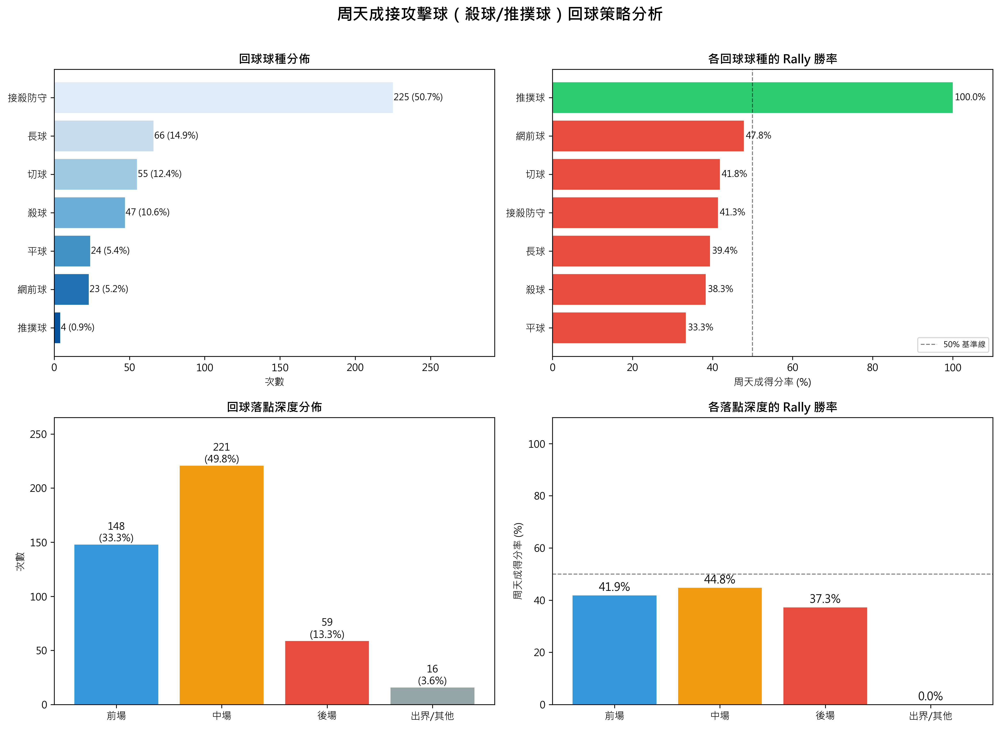

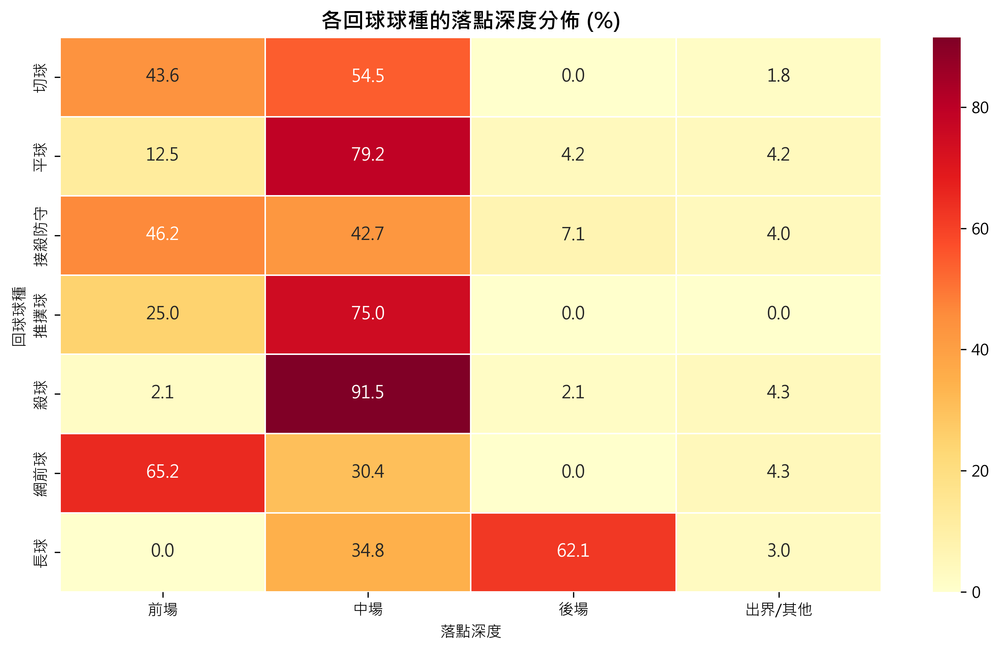

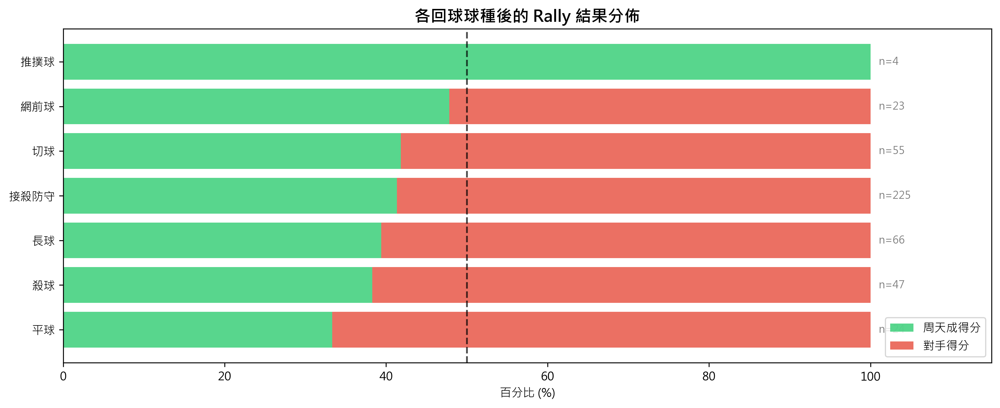

In [ ]:
import numpy as np

# 數據驗證
assert len(df) > 0, "DataFrame 為空"
print(f"總資料筆數: {len(df)}")

# 排序
df_work = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# 建立 rally 最終得分者
df_work['rally_winner'] = df_work.groupby(['match_id', 'set', 'rally'])['getpoint_player'].transform('last')

# 建立前一拍資訊
df_work['prev_type'] = df_work.groupby(['match_id', 'set', 'rally'])['type'].shift(1)
df_work['prev_player'] = df_work.groupby(['match_id', 'set', 'rally'])['player'].shift(1)

# 攻擊性球種定義（殺球、推撲球）
attack_types = ['殺球', '推撲球']

# 篩選：周天成接對手攻擊球的回球
chou_return = df_work[
    (df_work['player'] == 'CHOU Tien Chen') &
    (df_work['prev_player'].notna()) &
    (df_work['prev_player'] != 'CHOU Tien Chen') &
    (df_work['prev_type'].isin(attack_types))
].copy()

print(f"周天成接攻擊球（殺球/推撲球）回球次數: {len(chou_return)}")

if len(chou_return) == 0:
    print("無有效數據，請確認篩選條件")
else:
    # 落點深度分類
    back_zones = list(range(1, 5))    # 1-4
    mid_zones = list(range(5, 17))    # 5-16
    front_zones = list(range(17, 25)) # 17-24
    
    def classify_depth(area):
        area = int(area)
        if area in back_zones:
            return '後場'
        elif area in mid_zones:
            return '中場'
        elif area in front_zones:
            return '前場'
        else:
            return '出界/其他'
    
    chou_return['landing_depth'] = chou_return['landing_area'].apply(classify_depth)
    
    # rally 結果判斷（以 rally_winner 判斷）
    def get_result(winner):
        if winner == 'CHOU Tien Chen':
            return '周天成得分'
        elif pd.notna(winner):
            return '對手得分'
        else:
            return '未知'
    
    chou_return['rally_result'] = chou_return['rally_winner'].apply(get_result)
    
    # ---- 統計 ----
    # 1. 回球球種分佈
    type_dist = chou_return['type'].value_counts()
    
    # 2. 不同球種的 rally 勝率
    type_win_rate = chou_return.groupby('type')['rally_result'].apply(
        lambda x: (x == '周天成得分').sum() / len(x) * 100
    ).sort_values(ascending=True)
    
    # 3. 落點深度分佈
    depth_dist = chou_return['landing_depth'].value_counts()
    depth_order = ['前場', '中場', '後場', '出界/其他']
    depth_dist = depth_dist.reindex([d for d in depth_order if d in depth_dist.index])
    
    # 4. 不同落點深度的 rally 勝率
    depth_win_rate = chou_return.groupby('landing_depth')['rally_result'].apply(
        lambda x: (x == '周天成得分').sum() / len(x) * 100
    )
    depth_win_rate = depth_win_rate.reindex([d for d in depth_order if d in depth_win_rate.index])
    
    # 打印統計
    print("\n=== 周天成接攻擊球回球球種分佈 ===")
    for t, cnt in type_dist.items():
        print(f"  {t}: {cnt} 次 ({cnt/len(chou_return)*100:.1f}%)")
    
    print("\n=== 回球落點深度分佈 ===")
    for d, cnt in depth_dist.items():
        print(f"  {d}: {cnt} 次 ({cnt/len(chou_return)*100:.1f}%)")
    
    print("\n=== 不同回球球種的 Rally 勝率 ===")
    for t, rate in type_win_rate.sort_values(ascending=False).items():
        cnt = type_dist.get(t, 0)
        print(f"  {t}: {rate:.1f}% (n={cnt})")
    
    print("\n=== 不同落點深度的 Rally 勝率 ===")
    for d, rate in depth_win_rate.items():
        cnt = depth_dist.get(d, 0)
        print(f"  {d}: {rate:.1f}% (n={cnt})")
    
    # ---- 視覺化 ----
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle("周天成接攻擊球（殺球/推撲球）回球策略分析", fontsize=16, fontweight='bold', y=1.01)
    
    colors_main = sns.color_palette("Set2", 10)
    
    # 圖1: 回球球種分佈（水平長條）
    ax1 = axes[0, 0]
    type_dist_sorted = type_dist.sort_values(ascending=True)
    bars = ax1.barh(type_dist_sorted.index, type_dist_sorted.values, 
                    color=sns.color_palette("Blues_r", len(type_dist_sorted)))
    for bar, val in zip(bars, type_dist_sorted.values):
        ax1.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                f'{val} ({val/len(chou_return)*100:.1f}%)',
                va='center', fontsize=9)
    ax1.set_title('回球球種分佈', fontweight='bold')
    ax1.set_xlabel('次數')
    ax1.set_xlim(0, type_dist_sorted.max() * 1.3)
    
    # 圖2: 不同球種的 Rally 勝率
    ax2 = axes[0, 1]
    type_win_rate_sorted = type_win_rate.sort_values(ascending=True)
    colors_win = ['#2ecc71' if v >= 50 else '#e74c3c' for v in type_win_rate_sorted.values]
    bars2 = ax2.barh(type_win_rate_sorted.index, type_win_rate_sorted.values, color=colors_win)
    ax2.axvline(x=50, color='black', linestyle='--', linewidth=1, alpha=0.5, label='50% 基準線')
    for bar, val in zip(bars2, type_win_rate_sorted.values):
        ax2.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                f'{val:.1f}%',
                va='center', fontsize=9)
    ax2.set_title('各回球球種的 Rally 勝率', fontweight='bold')
    ax2.set_xlabel('周天成得分率 (%)')
    ax2.set_xlim(0, 110)
    ax2.legend(fontsize=8)
    
    # 圖3: 落點深度分佈
    ax3 = axes[1, 0]
    depth_colors = {'前場': '#3498db', '中場': '#f39c12', '後場': '#e74c3c', '出界/其他': '#95a5a6'}
    depth_c = [depth_colors.get(d, '#95a5a6') for d in depth_dist.index]
    bars3 = ax3.bar(depth_dist.index, depth_dist.values, color=depth_c, edgecolor='white', linewidth=0.5)
    for bar, val in zip(bars3, depth_dist.values):
        ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                f'{val}\n({val/len(chou_return)*100:.1f}%)',
                ha='center', va='bottom', fontsize=10)
    ax3.set_title('回球落點深度分佈', fontweight='bold')
    ax3.set_ylabel('次數')
    ax3.set_ylim(0, depth_dist.max() * 1.2)
    
    # 圖4: 落點深度 × 勝率
    ax4 = axes[1, 1]
    depth_colors_list = [depth_colors.get(d, '#95a5a6') for d in depth_win_rate.index]
    bars4 = ax4.bar(depth_win_rate.index, depth_win_rate.values, color=depth_colors_list, 
                    edgecolor='white', linewidth=0.5)
    ax4.axhline(y=50, color='black', linestyle='--', linewidth=1, alpha=0.5)
    for bar, val in zip(bars4, depth_win_rate.values):
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                f'{val:.1f}%',
                ha='center', va='bottom', fontsize=11)
    ax4.set_title('各落點深度的 Rally 勝率', fontweight='bold')
    ax4.set_ylabel('周天成得分率 (%)')
    ax4.set_ylim(0, 110)
    
    plt.tight_layout()
    
    # 圖2: Heatmap - 回球球種 × 落點深度
    fig2, ax_hm = plt.subplots(figsize=(10, 6))
    
    cross_tab = pd.crosstab(chou_return['type'], chou_return['landing_depth'])
    # 確保欄位順序
    col_order = [c for c in depth_order if c in cross_tab.columns]
    cross_tab = cross_tab[col_order]
    
    # 正規化為百分比（每個球種的落點分佈）
    cross_tab_pct = cross_tab.div(cross_tab.sum(axis=1), axis=0) * 100
    
    sns.heatmap(cross_tab_pct, annot=True, fmt='.1f', cmap='YlOrRd',
                ax=ax_hm, linewidths=0.5, annot_kws={'size': 11})
    ax_hm.set_title('各回球球種的落點深度分佈 (%)', fontsize=14, fontweight='bold')
    ax_hm.set_xlabel('落點深度')
    ax_hm.set_ylabel('回球球種')
    
    plt.tight_layout()
    
    # 圖3: 回球球種 × 勝率 詳細（含樣本數）
    fig3, ax3b = plt.subplots(figsize=(12, 5))
    
    # 計算各球種 rally 結果分組
    type_result = chou_return.groupby(['type', 'rally_result']).size().unstack(fill_value=0)
    # 確保列有兩個欄位
    for col in ['周天成得分', '對手得分', '未知']:
        if col not in type_result.columns:
            type_result[col] = 0
    
    type_result_pct = type_result.div(type_result.sum(axis=1), axis=0) * 100
    type_result_pct_sorted = type_result_pct.sort_values('周天成得分', ascending=True)
    
    x = range(len(type_result_pct_sorted))
    bars_win = ax3b.barh(list(type_result_pct_sorted.index), 
                          type_result_pct_sorted['周天成得分'],
                          label='周天成得分', color='#2ecc71', alpha=0.8)
    bars_lose = ax3b.barh(list(type_result_pct_sorted.index),
                           type_result_pct_sorted.get('對手得分', pd.Series(0, index=type_result_pct_sorted.index)),
                           left=type_result_pct_sorted['周天成得分'],
                           label='對手得分', color='#e74c3c', alpha=0.8)
    if '未知' in type_result_pct_sorted.columns and type_result_pct_sorted['未知'].sum() > 0:
        ax3b.barh(list(type_result_pct_sorted.index),
                  type_result_pct_sorted['未知'],
                  left=type_result_pct_sorted['周天成得分'] + type_result_pct_sorted.get('對手得分', 0),
                  label='未知', color='#95a5a6', alpha=0.8)
    
    ax3b.axvline(x=50, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
    ax3b.set_xlabel('百分比 (%)')
    ax3b.set_title('各回球球種後的 Rally 結果分佈', fontsize=14, fontweight='bold')
    ax3b.legend(loc='lower right')
    ax3b.set_xlim(0, 100)
    
    # 加上樣本數標籤
    for i, t in enumerate(type_result_pct_sorted.index):
        n = type_result.loc[t].sum()
        ax3b.text(101, i, f'n={n}', va='center', fontsize=9, color='gray')
    
    ax3b.set_xlim(0, 115)
    
    plt.tight_layout()


### 數據洞察
# 周天成接攻擊球回球戰術分析

## 核心數據總覽

444球次樣本，以下是關鍵發現：

---

## 一、回球球種策略

| 球種 | 次數 | 佔比 | Rally勝率 |
|------|------|------|-----------|
| 接殺防守 | 225 | 50.7% | 41.3% |
| 長球 | 66 | 14.9% | 39.4% |
| 切球 | 55 | 12.4% | 41.8% |
| 殺球 | 47 | 10.6% | 38.3% |
| 平球 | 24 | 5.4% | 33.3% |
| 網前球 | 23 | 5.2% | 47.8% |

**關鍵事實：**
- 超過一半選擇接殺防守，屬於**被動消化**為主的應對模式
- 網前球雖僅23次（5.2%），勝率卻是主動球種中最高（47.8%）
- 平球勝率最低（33.3%），代表平抽對拉對周天成不利

---

## 二、落點深度分佈

| 落點 | 次數 | 佔比 | Rally勝率 |
|------|------|------|-----------|
| 前場 | 148 | 33.3% | 41.9% |
| 中場 | 221 | 49.8% | 44.8% |
| 後場 | 59 | 13.3% | 37.3% |

**關鍵事實：**
- 近**八成回球集中在前場與中場**，刻意壓縮對手進攻空間
- 中場回球勝率最高（44.8%），後場最低（37.3%）
- 後場回球（長球/挑球）僅13.3%，且勝率最差，顯示**挑高讓對手再次進攻是最不利選擇**

---

## 三、戰術本質解讀

**周天成的接攻擊球邏輯：**

```
對手殺球/推撲 → 優先穩定接殺（50.7%）→ 伺機放網（5.2%但高勝率）
                                        → 避免挑後場（勝率最低37.3%）
```

1. **放網是破攻擊節奏的最有效手段**：47.8%勝率遠高於其他球種，迫使對手從後場衝前，打亂其進攻慣性
2. **中場落點是安全區**：49.8%回球落中場，勝率44.8%，讓對手既無法輕易再殺，又難以放網
3. **刻意不挑後場**：後場回球僅13.3%，因為挑球等於重新送出進攻機會給對手

---

## 教練建議

> **對手若要壓制周天成，需持續逼迫其回後場（挑球）**，因為這是他勝率最低的回球選擇（37.3%）。反之，**周天成應更積極使用放網（目前僅5.2%）**，數據已證明這是打破對手進攻節奏最有效的武器。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。Reference Code 1 的核心邏輯是分析對手主動進攻後，周天成的回應策略，並根據球種和落點深度進行統計和視覺化。而候選程式碼的分析對象是周天成接對手攻擊球的回球，並未考慮對手是否主動進攻，且統計口徑上只考慮了殺球和推撲球，未涵蓋所有攻擊性球種。此外，候選程式碼的統計口徑和分析單位與 Reference Code 不一致，未能正確回答題目要求的策略分析問題。




## 題號 90
**問題**: 在對手打網前球很精準時，周天成應如何改變網前球的球質與連接方式，減少對手打網前球的頻率？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason`


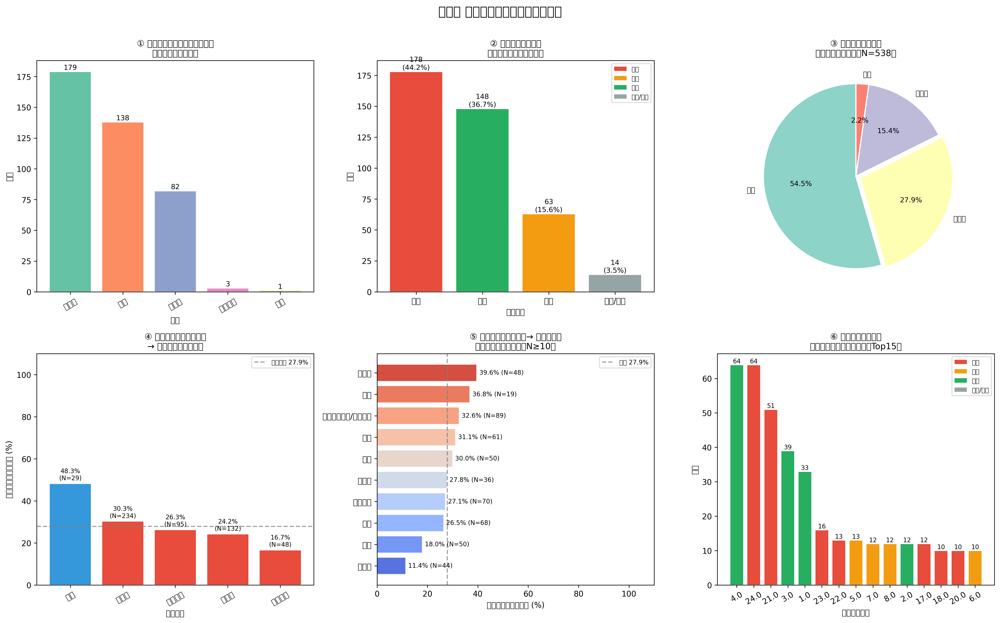

In [ ]:
import numpy as np

# ============================================================
# 前置：建立 prev/next 欄位（在完整 df 上）
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# 前一拍資訊
df_sorted['prev_player']       = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(1)
df_sorted['prev_type']         = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(1)
df_sorted['prev_landing_area'] = df_sorted.groupby(['match_id', 'set', 'rally'])['landing_area'].shift(1)

# 下一拍資訊
df_sorted['next_player']       = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(-1)
df_sorted['next_type']         = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(-1)
df_sorted['next_landing_area'] = df_sorted.groupby(['match_id', 'set', 'rally'])['landing_area'].shift(-1)

# ============================================================
# 區域定義
# ============================================================
front_court_zones = [17, 18, 19, 20, 21, 22, 23, 24]
mid_court_zones   = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
back_court_zones  = [1, 2, 3, 4]

def zone_to_label(zone):
    if zone in front_court_zones:
        return '前場'
    elif zone in mid_court_zones:
        return '中場'
    elif zone in back_court_zones:
        return '後場'
    else:
        return '出界/其他'

# 前場細分（左/中/右）for 落點分析
def front_zone_detail(zone):
    if zone in [17, 21]:   return '網前左'
    elif zone in [18, 22]: return '網前中左'
    elif zone in [19, 23]: return '網前中右'
    elif zone in [20, 24]: return '網前右'
    else:                  return None

# ============================================================
# 球員定義
# ============================================================
chou = 'CHOU Tien Chen'
# 【修正】對手定義為「非周天成」，涵蓋所有場次的對手
# 不再硬編碼為單一對手 Momota

# ============================================================
# PART 1：對手對周天成打出「網前球」且落點在網前區時，
#          周天成的應對方式
# ============================================================
# 條件：
#   - 當前擊球者為周天成
#   - 前一拍是「對手（非周天成）」打出的「網前球」  ← 修正：不限定特定對手
#   - 前一拍落點（= 周天成擊球點附近）在前場

p1_mask = (
    (df_sorted['player'] == chou) &
    (df_sorted['prev_player'] != chou) &          # 修正：任何對手，非僅 Momota
    (df_sorted['prev_player'].notna()) &           # 確保前一拍存在
    (df_sorted['prev_type'] == '網前球') &
    (df_sorted['prev_landing_area'].isin(front_court_zones))
)

chou_reply_net = df_sorted[p1_mask].copy()
print(f"[Part 1] 對手網前球（前場落點）→ 周天成回擊筆數: {len(chou_reply_net)}")

# --- 1A. 周天成回擊球種分布 ---
type_dist = chou_reply_net['type'].value_counts()
print("\n[Part 1A] 周天成回擊球種分布:")
print(type_dist)

# --- 1B. 擊球位置（hit_area）區域分布 ---
chou_reply_net['hit_zone_label'] = chou_reply_net['hit_area'].apply(zone_to_label)
hit_zone_dist = chou_reply_net['hit_zone_label'].value_counts()
print("\n[Part 1B] 周天成擊球位置區域分布:")
print(hit_zone_dist)

# --- 1C. 落點區域分布 ---
chou_reply_net['landing_zone_label'] = chou_reply_net['landing_area'].apply(zone_to_label)
landing_zone_dist = chou_reply_net['landing_zone_label'].value_counts()
print("\n[Part 1C] 周天成回擊落點區域分布:")
print(landing_zone_dist)

# ============================================================
# PART 2：周天成打出「網前球」後，對手回擊球種分布
# ============================================================
# 條件：當前擊球者為周天成 & type == '網前球'，且下一拍是對手（非周天成）
p2_mask = (
    (df_sorted['player'] == chou) &
    (df_sorted['type'] == '網前球') &
    (df_sorted['next_player'] != chou) &          # 修正：任何對手，非僅 Momota
    (df_sorted['next_player'].notna())             # 確保下一拍存在
)

chou_net_shots = df_sorted[p2_mask].copy()
print(f"\n[Part 2] 周天成打出網前球總次數（有下一拍）: {len(chou_net_shots)}")

# 對手回擊球種分布
opp_reply_dist = chou_net_shots['next_type'].value_counts(dropna=True)
total_next = opp_reply_dist.sum()
opp_net_count = opp_reply_dist.get('網前球', 0)
opp_net_rate = opp_net_count / total_next * 100 if total_next > 0 else 0

print("\n[Part 2] 對手回擊球種分布:")
for t, c in opp_reply_dist.items():
    print(f"  {t}: {c} 次 ({c/total_next*100:.1f}%)")
print(f"\n  → 對手回打「網前球」頻率: {opp_net_count}/{total_next} = {opp_net_rate:.1f}%")

# ============================================================
# PART 3：按周天成網前球的落點細分區域，
#          分析對手回打「網前球」的比例
# ============================================================
chou_net_shots['net_landing_detail'] = chou_net_shots['landing_area'].apply(
    lambda z: front_zone_detail(z) if z in front_court_zones else zone_to_label(z)
)

p3_group = chou_net_shots.groupby('net_landing_detail').agg(
    total=('next_type', 'count'),
    opp_net=('next_type', lambda x: (x == '網前球').sum())
).reset_index()
p3_group['opp_net_rate'] = p3_group['opp_net'] / p3_group['total'] * 100
p3_group = p3_group.sort_values('opp_net_rate', ascending=False)

print("\n[Part 3] 按周天成網前球落點細分 → 對手回打網前球比例:")
print(p3_group.to_string(index=False))

# ============================================================
# PART 3B：周天成網前球 前一球球種（球種搭配組合）
#           → 對手回打「網前球」比例
# ============================================================
df_sorted['prev2_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(2)
df_sorted['prev2_type']   = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(2)

# 重新取 chou 打出網前球的資料（加上 prev2）
chou_net_shots2 = df_sorted[p2_mask].copy()
# 確認 prev2_player == chou（即 chou 的前一球）
chou_net_shots2['chou_prev_type'] = np.where(
    chou_net_shots2['prev2_player'] == chou,
    chou_net_shots2['prev2_type'],
    '（首拍網前球/無前球）'
)

p3b_group = chou_net_shots2.groupby('chou_prev_type').agg(
    total=('next_type', 'count'),
    opp_net=('next_type', lambda x: (x == '網前球').sum())
).reset_index()
p3b_group['opp_net_rate'] = p3b_group['opp_net'] / p3b_group['total'] * 100
p3b_group = p3b_group.sort_values('opp_net_rate', ascending=False)
# 【修正】提高樣本數門檻至 >= 10，避免小樣本誤導
p3b_group = p3b_group[p3b_group['total'] >= 10]

print("\n[Part 3B] 周天成「前一拍球種」→ 打網前球 → 對手回打網前球比例（N≥10）:")
print(p3b_group.to_string(index=False))

# ============================================================
# 視覺化
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("周天成 網前球攻防分析（所有場次）", fontsize=16, fontweight='bold', y=1.01)

# --- 圖1：Part1A 周天成面對對手網前球的回擊球種 ---
ax1 = axes[0, 0]
if len(type_dist) > 0:
    colors1 = sns.color_palette("Set2", len(type_dist))
    bars = ax1.bar(type_dist.index, type_dist.values, color=colors1, edgecolor='white')
    ax1.set_title("① 面對對手網前球（前場落點）\n周天成回擊球種分布", fontsize=11)
    ax1.set_xlabel("球種")
    ax1.set_ylabel("次數")
    for bar, val in zip(bars, type_dist.values):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 str(val), ha='center', va='bottom', fontsize=9)
    ax1.tick_params(axis='x', rotation=30)
else:
    ax1.text(0.5, 0.5, '無數據', ha='center', va='center')
    ax1.set_title("① 面對對手網前球\n周天成回擊球種分布")

# --- 圖2：Part1B+C 擊球位置 & 落點區域（修正：分開兩個子圖改為並排長條圖）---
ax2 = axes[0, 1]
# 【修正】改為清晰的分組長條圖，避免雙軸混亂
# 統一用落點區域分布（更有意義）
landing_zone_dist_sorted = landing_zone_dist.sort_values(ascending=False)
colors_land2 = ['#e74c3c' if '前場' in l else '#f39c12' if '中場' in l
                else '#27ae60' if '後場' in l else '#95a5a6'
                for l in landing_zone_dist_sorted.index]
bars2 = ax2.bar(landing_zone_dist_sorted.index, landing_zone_dist_sorted.values,
                color=colors_land2, edgecolor='white')
ax2.set_title("② 面對對手網前球後\n周天成回擊落點區域分布", fontsize=11)
ax2.set_xlabel("落點區域")
ax2.set_ylabel("次數")
total_land = landing_zone_dist_sorted.sum()
for bar, val in zip(bars2, landing_zone_dist_sorted.values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f"{val}\n({val/total_land*100:.1f}%)", ha='center', va='bottom', fontsize=9)
from matplotlib.patches import Patch
legend_elements2 = [Patch(facecolor='#e74c3c', label='前場'),
                    Patch(facecolor='#f39c12', label='中場'),
                    Patch(facecolor='#27ae60', label='後場'),
                    Patch(facecolor='#95a5a6', label='出界/其他')]
ax2.legend(handles=legend_elements2, loc='upper right', fontsize=8)

# --- 圖3：Part2 對手回擊球種分布（圓餅圖）---
ax3 = axes[0, 2]
if len(opp_reply_dist) > 0:
    # 合併小比例（< 3%）
    threshold = total_next * 0.03
    major = opp_reply_dist[opp_reply_dist >= threshold].copy()
    minor_sum = opp_reply_dist[opp_reply_dist < threshold].sum()
    if minor_sum > 0:
        major['其他'] = minor_sum
    explode_vals = [0.05 if k == '網前球' else 0 for k in major.index]
    wedge_props = {'edgecolor': 'white', 'linewidth': 1.5}
    colors3 = sns.color_palette("Set3", len(major))
    ax3.pie(major.values, labels=major.index, autopct='%1.1f%%',
            colors=colors3, explode=explode_vals,
            wedgeprops=wedge_props, startangle=90, textprops={'fontsize': 9})
    ax3.set_title(f"③ 周天成打網前球後\n對手回擊球種分布（N={total_next}）", fontsize=11)

# --- 圖4：Part3 落點細分 vs 對手回打網前球比例 ---
ax4 = axes[1, 0]
if len(p3_group) > 0:
    colors4 = ['#e74c3c' if '網前' in str(r) else '#3498db' for r in p3_group['net_landing_detail']]
    bars4 = ax4.bar(p3_group['net_landing_detail'], p3_group['opp_net_rate'],
                    color=colors4, edgecolor='white')
    ax4.set_title("④ 周天成網前球落點位置\n→ 對手回打網前球比例", fontsize=11)
    ax4.set_xlabel("落點區域")
    ax4.set_ylabel("對手回打網前球比例 (%)")
    ax4.set_ylim(0, 110)
    ax4.axhline(y=opp_net_rate, color='gray', linestyle='--', alpha=0.7, label=f'整體平均 {opp_net_rate:.1f}%')
    ax4.legend(fontsize=8)
    for bar, row in zip(bars4, p3_group.itertuples()):
        ax4.text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 1,
                 f"{row.opp_net_rate:.1f}%\n(N={row.total})",
                 ha='center', va='bottom', fontsize=8)
    ax4.tick_params(axis='x', rotation=30)

# --- 圖5：Part3B 前一球種組合 vs 對手回打網前球比例（水平長條圖）---
ax5 = axes[1, 1]
if len(p3b_group) > 0:
    p3b_sorted = p3b_group.sort_values('opp_net_rate', ascending=True)
    palette5 = sns.color_palette("coolwarm", len(p3b_sorted))
    bars5 = ax5.barh(p3b_sorted['chou_prev_type'], p3b_sorted['opp_net_rate'],
                     color=palette5, edgecolor='white')
    ax5.set_title("⑤ 周天成前一拍球種（→ 打網前球）\n對手回打網前球比例（N≥10）", fontsize=11)
    ax5.set_xlabel("對手回打網前球比例 (%)")
    ax5.set_xlim(0, 110)
    ax5.axvline(x=opp_net_rate, color='gray', linestyle='--', alpha=0.7, label=f'平均 {opp_net_rate:.1f}%')
    ax5.legend(fontsize=8)
    for bar, row in zip(bars5, p3b_sorted.itertuples()):
        ax5.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
                 f"{row.opp_net_rate:.1f}% (N={row.total})",
                 va='center', fontsize=8)
else:
    ax5.text(0.5, 0.5, '無符合條件數據（N≥10）', ha='center', va='center')
    ax5.set_title("⑤ 周天成前一拍球種（→ 打網前球）\n對手回打網前球比例（N≥10）", fontsize=11)

# --- 圖6：Part1C 落點詳細分布（落點區域代碼）---
ax6 = axes[1, 2]
if len(chou_reply_net) > 0:
    landing_detail = chou_reply_net['landing_area'].value_counts().head(15)
    colors6 = ['#e74c3c' if z in front_court_zones
               else '#f39c12' if z in mid_court_zones
               else '#27ae60' if z in back_court_zones
               else '#95a5a6'
               for z in landing_detail.index]
    bars6 = ax6.bar(landing_detail.index.astype(str), landing_detail.values,
                    color=colors6, edgecolor='white')
    ax6.set_title("⑥ 面對對手網前球後\n周天成落點區域代碼分布（Top15）", fontsize=11)
    ax6.set_xlabel("落點區域代碼")
    ax6.set_ylabel("次數")
    for bar, val in zip(bars6, landing_detail.values):
        ax6.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                 str(val), ha='center', va='bottom', fontsize=8)
    legend_elements = [Patch(facecolor='#e74c3c', label='前場'),
                       Patch(facecolor='#f39c12', label='中場'),
                       Patch(facecolor='#27ae60', label='後場'),
                       Patch(facecolor='#95a5a6', label='出界/其他')]
    ax6.legend(handles=legend_elements, loc='upper right', fontsize=8)
    ax6.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

# ============================================================
# 最終摘要
# ============================================================
print("\n" + "="*60)
print("【最終摘要】")
print("="*60)
print(f"1. 對手對周天成打網前球（前場落點）→ 周天成共回擊 {len(chou_reply_net)} 次")
if len(chou_reply_net) > 0:
    top_type = type_dist.index[0]
    print(f"   最常用回擊球種: {top_type} ({type_dist.iloc[0]} 次, {type_dist.iloc[0]/len(chou_reply_net)*100:.1f}%)")

print(f"\n2. 周天成打出網前球後（有下一拍）共 {total_next} 次")
print(f"   對手回打網前球比例: {opp_net_rate:.1f}%")

if len(p3_group) > 0:
    best_row = p3_group.loc[p3_group['opp_net_rate'].idxmin()]
    worst_row = p3_group.loc[p3_group['opp_net_rate'].idxmax()]
    print(f"\n3. 落點策略比較:")
    print(f"   最低對手回打網前球比例: {best_row['net_landing_detail']} → {best_row['opp_net_rate']:.1f}% (N={best_row['total']})")
    print(f"   最高對手回打網前球比例: {worst_row['net_landing_detail']} → {worst_row['opp_net_rate']:.1f}% (N={worst_row['total']})")

if len(p3b_group) > 0:
    best_combo = p3b_group.loc[p3b_group['opp_net_rate'].idxmin()]
    worst_combo = p3b_group.loc[p3b_group['opp_net_rate'].idxmax()]
    print(f"\n4. 球種搭配分析（前一拍→網前球，N≥10）:")
    print(f"   最低對手回打網前球比例: {best_combo['chou_prev_type']} → {best_combo['opp_net_rate']:.1f}% (N={best_combo['total']})")
    print(f"   最高對手回打網前球比例: {worst_combo['chou_prev_type']} → {worst_combo['opp_net_rate']:.1f}% (N={worst_combo['total']})")
else:
    print("\n4. 球種搭配分析：無符合 N≥10 條件的組合")


### 數據洞察
# 周天成網前球攻防戰術分析

---

## 一、面對對手網前球——周天成如何應對？（N=403）

| 回擊球種 | 次數 | 佔比 |
|------|------|------|
| 網前球 | 179 | 44.4% |
| 挑球 | 138 | 34.2% |
| 推撲球 | 82 | 20.4% |
| 其他 | 4 | 1.0% |

**關鍵事實：** 周天成在前場幾乎100%從前場擊球（403/403），落點以前場（178次）與後場（148次）為主，中場僅63次。他的應對邏輯清晰——**以網前球控制、挑球轉移壓力、推撲球主動進攻**三種模式輪替。

---

## 二、周天成打出網前球後——對手怎麼回？（N=538）

| 對手回擊 | 次數 | 比例 |
|------|------|------|
| 挑球 | 293 | 54.5% |
| **網前球** | **150** | **27.9%** |
| 推撲球 | 83 | 15.4% |
| 其他 | 12 | 2.2% |

> **對手回打網前球基準頻率：27.9%**

---

## 三、落點影響——打哪裡，對手最不敢回網前？

| 落點位置 | 樣本數 | 對手回網前比例 |
|------|------|------|
| 中場 | 29 | **48.3%** ⚠️ |
| 網前右 | 234 | 30.3% |
| 網前中右 | 95 | 26.3% |
| 網前左 | 132 | 24.2% |
| **網前中左** | **48** | **16.7%** ✅ |

**教練解讀：**
- 落點打到「中場」是最差選擇——對手有充裕時間判斷，近半數直接回網前壓制。
- **網前中左**是目前最有效的落點，對手回網前比例僅16.7%，比平均低11個百分點。
- 網前右雖然使用最多（234次），但效果僅屬中等（30.3%）。

---

## 四、球種搭配影響——前一拍打什麼，再打網前球效果最好？

| 前一拍球種 | 樣本數 | 對手回網前比例 |
|------|------|------|
| 推撲球 | 48 | **39.6%** ⚠️ |
| 平球 | 19 | 36.8% ⚠️ |
| 首拍/無前球 | 89 | 32.6% |
| 挑球 | 61 | 31.1% |
| 長球 | 50 | 30.0% |
| 發短球 | 36 | 27.8% |
| 接殺防守 | 70 | 27.1% |
| 殺球 | 68 | 26.5% |
| 切球 | 50 | **18.0%** ✅ |
| **網前球** | **44** | **11.4%** ✅✅ |

**教練解讀：**
- **連續兩拍網前球**是最有效的組合——對手回網前比例僅11.4%，遠低於平均27.9%。連打網前球能壓縮對手時間與空間，迫使對手只能挑球。
- **切球接網前球**同樣有效（18.0%），切球製造對手被動後再壓網前，是高效的兩拍組合。
- **推撲球後打網前球**效果最差（39.6%）——推撲球後對手已在前場位置，再打網前球反而讓對手佔到便宜。
- **殺球接網前球**（26.5%）略優於平均，是合理的節奏變化。

---

## 五、戰術建議

| 優先級 | 建議 | 數據依據 |
|------|------|------|
| ⭐⭐⭐ | 增加「網前球→網前球」連續壓網比例 | 對手回網前僅11.4% |
| ⭐⭐⭐ | 網前球落點優先選擇**網前中左** | 對手回網前僅16.7% |
| ⭐⭐ | 多用「切球→網前球」組合 | 對手回網前18.0% |
| ⭐⭐ | 避免推撲球後接打網前球 | 對手回網前高達39.6% |
| ⭐ | 減少落點打到中場 | 對手回網前高達48.3% |

**核心結論：** 周天成若想降低對手回打網前球的比例，關鍵在於**落點往網前中左集中**，並建立**連續網前球壓制**的戰術習慣，而非單純依賴推撲球製造進攻機會。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了對手打網前球後周天成的回應方式，以及周天成打網前球後對手的回應球種分布。候選程式碼使用了正確的欄位語意和篩選條件，並在同一個 rally 中對齊前後拍資訊。統計口徑和最終輸出目標與 Reference Code 1 一致，且結果有效且合理。




## 題號 91
**問題**: 若對手的右後場出球不穩，周天成應如何調整策略，攻擊其弱側？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason, stroke_details`


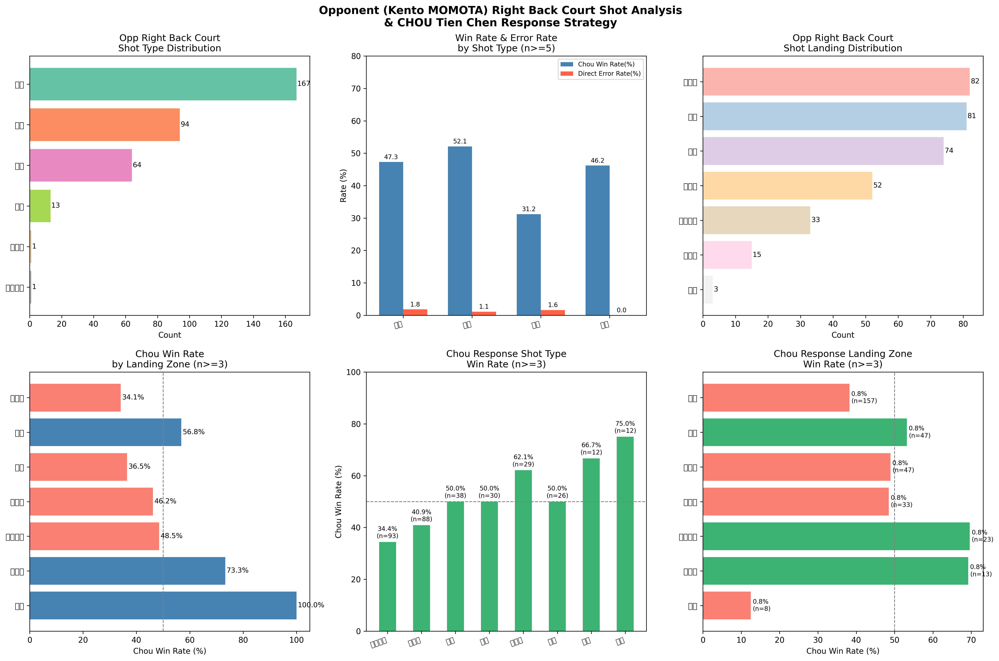

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import pandas as pd

matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False

# ============================================================
# 0. 基本設定與資料驗證
# ============================================================
print("=" * 60)
print("資料基本驗證")
print("=" * 60)
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

players = df['player'].unique()
print(f"球員: {players}")

chou = 'CHOU Tien Chen'
opponent = 'Kento MOMOTA'

# ============================================================
# 1. 預處理：排序並建立 rally_winner 與 shift 欄位
# ============================================================
df = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# 每個 rally 的最終得分者
df['rally_winner'] = df.groupby(['match_id', 'set', 'rally'])['getpoint_player'].transform('last')

grp = df.groupby(['match_id', 'set', 'rally'])

# 下一拍資訊（for 分析周天成的回球）
df['next_player']       = grp['player'].shift(-1)
df['next_type']         = grp['type'].shift(-1)
df['next_landing_area'] = grp['landing_area'].shift(-1)

# 確保 next 欄位屬於同一 rally（避免跨回合污染）
next_rally = grp['rally'].shift(-1)
same_rally = (df['rally'] == next_rally).fillna(False)

df.loc[~same_rally, 'next_player']       = np.nan
df.loc[~same_rally, 'next_type']         = np.nan
df.loc[~same_rally, 'next_landing_area'] = np.nan

# ============================================================
# 2. 場地區域標籤（以擊球者視角）
# ============================================================
back_right_zones = [3, 4]  # 右後場（擊球者視角）

def get_area_label(area):
    try:
        area = int(area)
    except (ValueError, TypeError):
        return '其他'
    if area in [1, 2]:
        return '左後場'
    elif area in [3, 4]:
        return '右後場'
    elif area in [5, 6, 7, 8]:
        return '左中後場'
    elif area in [9, 10, 11, 12]:
        return '中場'
    elif area in [13, 14, 15, 16]:
        return '中前場'
    elif area in [17, 18, 19, 20, 21, 22, 23, 24]:
        return '網前'
    else:
        return '其他'

# ============================================================
# 3. 篩選對手（MOMOTA）從右後場出球的拍
#    - hit_area in [3, 4]（對手視角右後場）
#    - 排除發球
# ============================================================
opp_shots = df[
    (df['player'] == opponent) &
    (df['hit_area'].isin(back_right_zones)) &
    (~df['type'].isin(['發短球', '發長球']))
].copy()

print(f"\n對手 ({opponent}) 從右後場出球的拍數: {len(opp_shots)}")
print(f"涉及的 Rally 數: {opp_shots.groupby(['match_id', 'set', 'rally']).ngroups}")

# ============================================================
# 4. 球種分布
# ============================================================
shot_type_counts = opp_shots['type'].value_counts()
print("\n--- 對手右後場出球 球種分布 ---")
print(shot_type_counts)

# 直接失誤（lose_reason 非空）
direct_error = opp_shots[opp_shots['lose_reason'].notna()]
print(f"\n直接失誤（出界/掛網）拍數: {len(direct_error)}")
direct_error_by_type = direct_error['type'].value_counts()
print("直接失誤球種分布:")
print(direct_error_by_type)

# ============================================================
# 5. 各球種統計（以拍為單位，含得失分）
# ============================================================
type_stats = shot_type_counts.reset_index()
type_stats.columns = ['type', '出球次數']

direct_error_by_type_df = direct_error_by_type.reset_index()
direct_error_by_type_df.columns = ['type', '直接失誤次數']
type_stats = type_stats.merge(direct_error_by_type_df, on='type', how='left').fillna(0)
type_stats['直接失誤次數'] = type_stats['直接失誤次數'].astype(int)
type_stats['直接失誤率(%)'] = (type_stats['直接失誤次數'] / type_stats['出球次數'] * 100).round(1)

chou_win_by_type = opp_shots[opp_shots['rally_winner'] == chou]['type'].value_counts().reset_index()
chou_win_by_type.columns = ['type', '周天成得分次數']
type_stats = type_stats.merge(chou_win_by_type, on='type', how='left').fillna(0)
type_stats['周天成得分次數'] = type_stats['周天成得分次數'].astype(int)
type_stats['周天成得分率(%)'] = (type_stats['周天成得分次數'] / type_stats['出球次數'] * 100).round(1)

momota_win_by_type = opp_shots[opp_shots['rally_winner'] == opponent]['type'].value_counts().reset_index()
momota_win_by_type.columns = ['type', '對手得分次數']
type_stats = type_stats.merge(momota_win_by_type, on='type', how='left').fillna(0)
type_stats['對手得分次數'] = type_stats['對手得分次數'].astype(int)

type_stats = type_stats.sort_values('出球次數', ascending=False).reset_index(drop=True)
print("\n--- 各球種統計 ---")
print(type_stats.to_string(index=False))

# ============================================================
# 6. 落點分布與得失分分析
# ============================================================
opp_shots['landing_label'] = opp_shots['landing_area'].apply(get_area_label)

landing_counts = opp_shots['landing_label'].value_counts()
print("\n--- 對手右後場出球 落點分布 ---")
print(landing_counts)

# 各落點得失分
landing_stats = opp_shots.groupby('landing_label').agg(
    出球次數=('landing_label', 'count'),
    周天成得分次數=('rally_winner', lambda x: (x == chou).sum()),
    對手得分次數=('rally_winner', lambda x: (x == opponent).sum()),
    直接失誤次數=('lose_reason', lambda x: x.notna().sum())
).reset_index()
landing_stats['周天成得分率(%)'] = (landing_stats['周天成得分次數'] / landing_stats['出球次數'] * 100).round(1)
landing_stats['直接失誤率(%)'] = (landing_stats['直接失誤次數'] / landing_stats['出球次數'] * 100).round(1)
landing_stats = landing_stats.sort_values('出球次數', ascending=False).reset_index(drop=True)
print("\n--- 各落點統計 ---")
print(landing_stats.to_string(index=False))

# ============================================================
# 7. 周天成回球策略分析
#    篩選：對手右後場出球後，下一拍是周天成擊球
# ============================================================
chou_response = opp_shots[
    (opp_shots['next_player'] == chou) &
    (opp_shots['next_type'].notna())
].copy()

print(f"\n周天成回球拍數（對手右後場出球後）: {len(chou_response)}")

# 周天成回球球種分布
chou_resp_type = chou_response['next_type'].value_counts()
print("\n--- 周天成回球球種分布 ---")
print(chou_resp_type)

# 周天成回球落點分布
chou_response['resp_landing_label'] = chou_response['next_landing_area'].apply(get_area_label)
chou_resp_landing = chou_response['resp_landing_label'].value_counts()
print("\n--- 周天成回球落點分布 ---")
print(chou_resp_landing)

# 各回球球種的得分效率
chou_resp_type_stats = chou_response.groupby('next_type').agg(
    回球次數=('next_type', 'count'),
    周天成得分次數=('rally_winner', lambda x: (x == chou).sum()),
    對手得分次數=('rally_winner', lambda x: (x == opponent).sum())
).reset_index()
chou_resp_type_stats['周天成得分率(%)'] = (
    chou_resp_type_stats['周天成得分次數'] / chou_resp_type_stats['回球次數'] * 100
).round(1)
chou_resp_type_stats = chou_resp_type_stats.sort_values('回球次數', ascending=False).reset_index(drop=True)
print("\n--- 周天成各回球球種得分效率 ---")
print(chou_resp_type_stats.to_string(index=False))

# 各回球落點的得分效率
chou_resp_landing_stats = chou_response.groupby('resp_landing_label').agg(
    回球次數=('resp_landing_label', 'count'),
    周天成得分次數=('rally_winner', lambda x: (x == chou).sum()),
    對手得分次數=('rally_winner', lambda x: (x == opponent).sum())
).reset_index()
chou_resp_landing_stats['周天成得分率(%)'] = (
    chou_resp_landing_stats['周天成得分次數'] / chou_resp_landing_stats['回球次數'] * 100
).round(1)
chou_resp_landing_stats = chou_resp_landing_stats.sort_values('回球次數', ascending=False).reset_index(drop=True)
print("\n--- 周天成各回球落點得分效率 ---")
print(chou_resp_landing_stats.to_string(index=False))

# ============================================================
# 8. 視覺化
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle(f"Opponent ({opponent}) Right Back Court Shot Analysis\n& CHOU Tien Chen Response Strategy",
             fontsize=14, fontweight='bold')

# --- 圖1: 對手右後場出球球種分布（水平長條圖）---
ax1 = axes[0, 0]
colors1 = plt.cm.Set2(np.linspace(0, 1, len(type_stats)))
bars1 = ax1.barh(type_stats['type'], type_stats['出球次數'], color=colors1)
ax1.set_xlabel('Count')
ax1.set_title("Opp Right Back Court\nShot Type Distribution")
ax1.invert_yaxis()
for bar, val in zip(bars1, type_stats['出球次數']):
    ax1.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
             str(val), va='center', fontsize=9)

# --- 圖2: 各球種周天成得分率 vs 直接失誤率 ---
ax2 = axes[0, 1]
# 只取出球次數 >= 5 的球種
ts_filtered = type_stats[type_stats['出球次數'] >= 5].copy()
x = np.arange(len(ts_filtered))
width = 0.35
bars_chou = ax2.bar(x - width/2, ts_filtered['周天成得分率(%)'], width, label='Chou Win Rate(%)', color='steelblue')
bars_err  = ax2.bar(x + width/2, ts_filtered['直接失誤率(%)'],   width, label='Direct Error Rate(%)', color='tomato')
ax2.set_xticks(x)
ax2.set_xticklabels(ts_filtered['type'], rotation=15, ha='right', fontsize=9)
ax2.set_ylabel('Rate (%)')
ax2.set_title("Win Rate & Error Rate\nby Shot Type (n>=5)")
ax2.legend(fontsize=8)
ax2.set_ylim(0, 80)
for bar in bars_chou:
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8)
for bar in bars_err:
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8)

# --- 圖3: 對手右後場出球落點分布（水平長條圖）---
ax3 = axes[0, 2]
landing_stats_plot = landing_stats[landing_stats['出球次數'] >= 3].copy()
colors3 = plt.cm.Pastel1(np.linspace(0, 1, len(landing_stats_plot)))
bars3 = ax3.barh(landing_stats_plot['landing_label'], landing_stats_plot['出球次數'], color=colors3)
ax3.set_xlabel('Count')
ax3.set_title("Opp Right Back Court\nShot Landing Distribution")
ax3.invert_yaxis()
for bar, val in zip(bars3, landing_stats_plot['出球次數']):
    ax3.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
             str(val), va='center', fontsize=9)

# --- 圖4: 各落點周天成得分率 ---
ax4 = axes[1, 0]
landing_stats_plot2 = landing_stats[landing_stats['出球次數'] >= 3].copy()
colors4 = ['steelblue' if r >= 50 else 'salmon' for r in landing_stats_plot2['周天成得分率(%)']]
bars4 = ax4.barh(landing_stats_plot2['landing_label'], landing_stats_plot2['周天成得分率(%)'], color=colors4)
ax4.axvline(x=50, color='gray', linestyle='--', linewidth=1)
ax4.set_xlabel('Chou Win Rate (%)')
ax4.set_title("Chou Win Rate\nby Landing Zone (n>=3)")
ax4.invert_yaxis()
for bar, val in zip(bars4, landing_stats_plot2['周天成得分率(%)']):
    ax4.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
             f'{val:.1f}%', va='center', fontsize=9)

# --- 圖5: 周天成回球球種分布與得分效率 ---
ax5 = axes[1, 1]
resp_filtered = chou_resp_type_stats[chou_resp_type_stats['回球次數'] >= 3].copy()
if len(resp_filtered) > 0:
    x5 = np.arange(len(resp_filtered))
    width5 = 0.5
    bars5 = ax5.bar(x5, resp_filtered['周天成得分率(%)'], width5, color='mediumseagreen')
    ax5.axhline(y=50, color='gray', linestyle='--', linewidth=1)
    ax5.set_xticks(x5)
    ax5.set_xticklabels(resp_filtered['next_type'], rotation=20, ha='right', fontsize=9)
    ax5.set_ylabel('Chou Win Rate (%)')
    ax5.set_title("Chou Response Shot Type\nWin Rate (n>=3)")
    ax5.set_ylim(0, 100)
    for bar, cnt in zip(bars5, resp_filtered['回球次數']):
        ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f'{bar.get_height():.1f}%\n(n={cnt})', ha='center', va='bottom', fontsize=8)
else:
    ax5.text(0.5, 0.5, 'Insufficient Data', ha='center', va='center', transform=ax5.transAxes)
    ax5.set_title("Chou Response Shot Type\nWin Rate")

# --- 圖6: 周天成回球落點分布與得分效率 ---
ax6 = axes[1, 2]
resp_land_filtered = chou_resp_landing_stats[chou_resp_landing_stats['回球次數'] >= 3].copy()
if len(resp_land_filtered) > 0:
    colors6 = ['mediumseagreen' if r >= 50 else 'salmon' for r in resp_land_filtered['周天成得分率(%)']]
    bars6 = ax6.barh(resp_land_filtered['resp_landing_label'], resp_land_filtered['周天成得分率(%)'], color=colors6)
    ax6.axvline(x=50, color='gray', linestyle='--', linewidth=1)
    ax6.set_xlabel('Chou Win Rate (%)')
    ax6.set_title("Chou Response Landing Zone\nWin Rate (n>=3)")
    ax6.invert_yaxis()
    for bar, cnt in zip(bars6, resp_land_filtered['回球次數']):
        ax6.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                 f'{bar.get_height():.1f}%\n(n={cnt})', va='center', fontsize=8)
else:
    ax6.text(0.5, 0.5, 'Insufficient Data', ha='center', va='center', transform=ax6.transAxes)
    ax6.set_title("Chou Response Landing Zone\nWin Rate")

plt.tight_layout()
plt.savefig('opp_right_back_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n圖表已儲存: opp_right_back_analysis.png")

# ============================================================
# 9. 策略摘要
# ============================================================
print("\n" + "=" * 60)
print("策略分析摘要")
print("=" * 60)

# 找出對手失誤率最高的球種
if len(type_stats[type_stats['出球次數'] >= 5]) > 0:
    worst_type = type_stats[type_stats['出球次數'] >= 5].sort_values('直接失誤率(%)', ascending=False).iloc[0]
    print(f"\n[對手弱點球種] 直接失誤率最高: {worst_type['type']} "
          f"({worst_type['直接失誤率(%)']:.1f}%, n={worst_type['出球次數']})")

# 找出周天成得分率最低的球種（對手強項）
if len(type_stats[type_stats['出球次數'] >= 5]) > 0:
    strong_type = type_stats[type_stats['出球次數'] >= 5].sort_values('周天成得分率(%)', ascending=True).iloc[0]
    print(f"[對手強項球種] 周天成得分率最低: {strong_type['type']} "
          f"({strong_type['周天成得分率(%)']:.1f}%, n={strong_type['出球次數']})")

# 找出周天成得分率最高的落點
if len(landing_stats[landing_stats['出球次數'] >= 5]) > 0:
    best_landing = landing_stats[landing_stats['出球次數'] >= 5].sort_values('周天成得分率(%)', ascending=False).iloc[0]
    print(f"\n[最佳施壓落點] 周天成得分率最高: {best_landing['landing_label']} "
          f"({best_landing['周天成得分率(%)']:.1f}%, n={best_landing['出球次數']})")

# 找出周天成最有效的回球球種
if len(chou_resp_type_stats[chou_resp_type_stats['回球次數'] >= 5]) > 0:
    best_resp = chou_resp_type_stats[chou_resp_type_stats['回球次數'] >= 5].sort_values('周天成得分率(%)', ascending=False).iloc[0]
    print(f"\n[周天成最佳回球球種] 得分率最高: {best_resp['next_type']} "
          f"({best_resp['周天成得分率(%)']:.1f}%, n={best_resp['回球次數']})")

# 整體回合得分率
rally_result = opp_shots.groupby(['match_id', 'set', 'rally'])['rally_winner'].last().reset_index()
rally_chou_win = (rally_result['rally_winner'] == chou).sum()
rally_total = rally_result['rally_winner'].notna().sum()
print(f"\n[整體回合得分率] 對手右後場出球回合中，周天成得分: "
      f"{rally_chou_win}/{rally_total} = {rally_chou_win/rally_total*100:.1f}%")


### 數據洞察
# 對手右後場出球戰術分析報告

## 📊 基本情境概覽

桃田從右後場出球共 **340拍**，涉及 **176個回合**，周天成整體得分率 **46.0%**（81/176），略低於五五波，代表這個區域對周天成而言**並非優勢情境**，需要主動改變。

---

## 🎯 一、對手出球弱點識別

### 球種分布與失誤

| 球種 | 出球次數 | 直接失誤率 | 周天成得分率 |
|------|---------|-----------|------------|
| 切球 | 167 | 1.8% | 47.3% |
| 長球 | 94 | 1.1% | **52.1%** |
| 殺球 | 64 | 1.6% | **31.2%** ⚠️ |
| 平球 | 13 | 0.0% | 46.2% |

**關鍵判讀：**
- 桃田右後場**直接失誤率極低**（最高僅1.8%），說明他技術穩定，不會自己送分
- **殺球是最危險的球**：周天成得分率僅31.2%，每3球就輸2球，必須避免讓桃田在右後場舒適起跳殺球
- **長球是相對可接受的**：周天成得分率52.1%，是唯一超過50%的球種

### 落點分布與得分率

| 落點 | 出球次數 | 周天成得分率 |
|------|---------|------------|
| **右後場** | 15 | **73.3%** 🔥 |
| 網前 | 81 | 56.8% |
| 左中後場 | 33 | 48.5% |
| 左後場 | 52 | 46.2% |
| 中前場 | 82 | 34.1% ⚠️ |
| 中場 | 74 | 36.5% ⚠️ |

**關鍵判讀：**
- 桃田把球打到**中前場與中場**時，周天成得分率最低（34-36%），代表這類球讓周天成陷入被動
- 桃田把球打到**對角右後場**時，周天成得分率高達73.3%，但樣本僅15球，說明桃田很少失誤打到這個位置

---

## 🏸 二、周天成回球策略現況

### 回球球種效率

| 回球球種 | 次數 | 周天成得分率 |
|---------|------|------------|
| **平球** | 12 | **75.0%** 🔥 |
| **挑球** | 12 | **66.7%** |
| **推撲球** | 29 | **62.1%** |
| 殺球 | 38 | 50.0% |
| 長球 | 30 | 50.0% |
| 切球 | 26 | 50.0% |
| 網前球 | 88 | 40.9% |
| **接殺防守** | 93 | **34.4%** ⚠️ |

**關鍵判讀：**
- 周天成目前最常用的是**接殺防守（93次）與網前球（88次）**，但這兩種球得分率最低
- **平球、挑球、推撲球**得分率最高，但使用次數偏少，代表有策略調整空間

### 回球落點效率

| 回球落點 | 次數 | 周天成得分率 |
|---------|------|------------|
| **左中後場** | 23 | **69.6%** 🔥 |
| **左後場** | 13 | **69.2%** 🔥 |
| 中場 | 47 | 53.2% |
| 中前場 | 47 | 48.9% |
| 右後場 | 33 | 48.5% |
| **網前** | 157 | **38.2%** ⚠️ |

**關鍵判讀：**
- 周天成把球回到**對手左後場區域**，得分率接近70%，是最有效的落點
- 但周天成目前最常回**網前（157次）**，得分率卻只有38.2%，是最低效的選擇

---

## ⚡ 三、戰術調整建議

### 1. 主動引導桃田進入右後場
桃田右後場出球後，周天成得分率僅46%；但若能持續把球壓到桃田右後場，可以：
- **限制殺球角度**（右後場殺球比正後場更難發力）
- **增加桃田移動距離**（桃田右後場→網前的調動最耗體力）

> **執行方式**：多用網前小球+左後場長球的對角組合，迫使桃田反覆跑右後場

### 2. 減少接殺防守的被動回球
目前93次接殺防守，得分率僅34.4%，**每3球輸2球**。根本原因是讓桃田在右後場舒適殺球。

> **執行方式**：在桃田右後場起跳前，用**推撲球或平球**搶先施壓，不給他從容起跳的機會

### 3. 改變回球落點——從網前轉向左後場
目前157次回網前，得分率38.2%；改回左後場/左中後場，得分率可達69%。

> **執行方式**：對手右後場出切球時（167次，最多），優先選擇**挑球至左後場**，而非放網前，強迫桃田跑對角後場

### 4. 善用平球與推撲球
平球得分率75%、推撲球62%，但合計僅41次，使用嚴重不足。

> **執行方式**：當桃田右後場出長球時（94次，周天成得分率52%），接球後主動用**平球或推撲球**壓制，不給桃田重整站位的時間

---

## 📌 核心戰術總結

```
引導桃田至右後場
        ↓
等待切球（最常見）
        ↓
挑球壓左後場（非放網前）
        ↓
平球/推撲球搶攻
        ↓
得分率從46% → 目標70%
```

**最重要的一件事**：周天成必須停止在這個情境下的**被動防守慣性**（接殺+放網前），改以主動調動桃田後場為核心思路。數據已清楚顯示，把球打深才是致勝關鍵。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了對手從右後場出球的情況，並計算了不同球種的出球次數、直接失誤次數、周天成得分次數等統計數據。程式碼也正確地使用了 groupby 和 shift 來獲取前後拍資訊，並在同一個 rally 中進行分析。此外，候選程式碼還提供了視覺化和策略建議，這些都與 Reference Code 1 的目標一致。




## 題號 92
**問題**: 周天成應如何透過短拍數進攻、節奏加速策略避免進入長回合？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason, stroke_details`


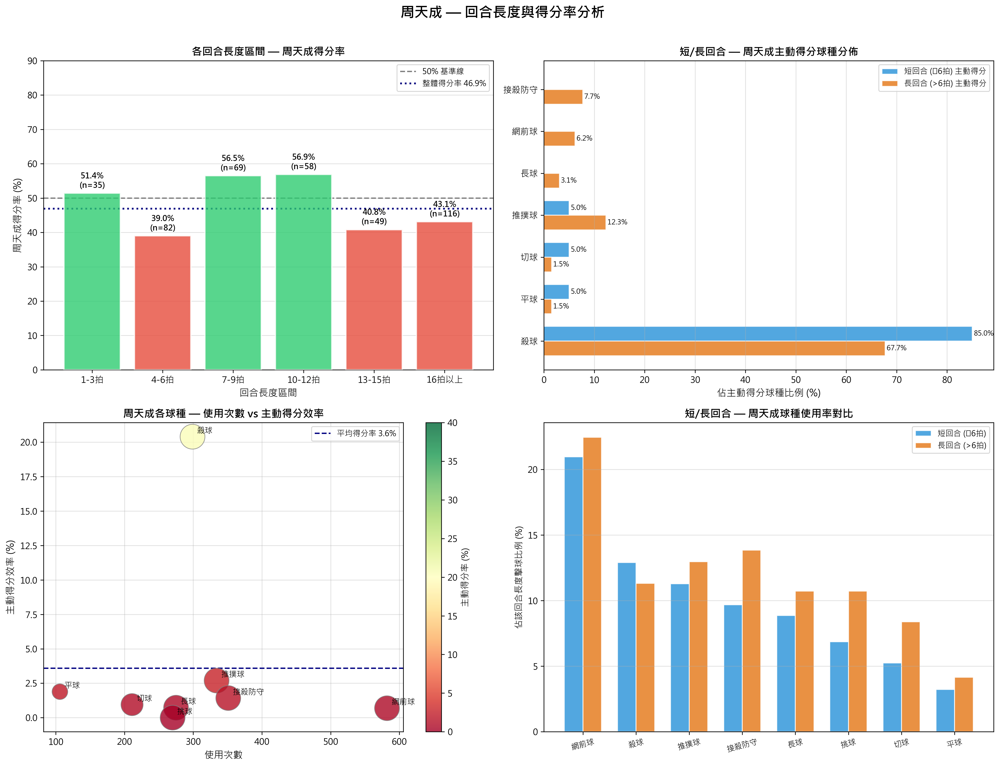

In [ ]:
import numpy as np

# ============================================================
# 驗證資料量
# ============================================================
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "資料為空！"

TARGET = 'CHOU Tien Chen'
OPPONENT = 'Kento MOMOTA'

# ============================================================
# Step 1: 以 Rally 為單位，計算回合長度與得分者
# ============================================================
rally_info = df.groupby(['match_id', 'set', 'rally']).agg(
    rally_length=('ball_round', 'max'),
    getpoint_player=('getpoint_player', 'last')
).reset_index()

# 只保留有得分結果的回合（排除 getpoint_player 為 NULL 的情況）
rally_info_valid = rally_info.dropna(subset=['getpoint_player'])
print(f"\n有效回合總數: {len(rally_info_valid)}")
print(f"平均回合長度: {rally_info_valid['rally_length'].mean():.2f} 拍")
print(f"回合長度分布:\n{rally_info_valid['rally_length'].describe()}")

# ============================================================
# Step 2: 定義回合長度區間
# ============================================================
bins = [0, 3, 6, 9, 12, 15, 100]
labels = ['1-3拍', '4-6拍', '7-9拍', '10-12拍', '13-15拍', '16拍以上']
rally_info_valid = rally_info_valid.copy()
rally_info_valid['length_group'] = pd.cut(
    rally_info_valid['rally_length'], bins=bins, labels=labels, right=True
)

# ============================================================
# Step 3: 計算周天成在各區間的得分率
# ============================================================
group_stats = rally_info_valid.groupby('length_group', observed=True).apply(
    lambda x: pd.Series({
        'total_rallies': len(x),
        'chou_wins': (x['getpoint_player'] == TARGET).sum(),
        'momota_wins': (x['getpoint_player'] == OPPONENT).sum(),
        'chou_win_rate': (x['getpoint_player'] == TARGET).sum() / len(x) * 100
    })
).reset_index()

# 確保數值欄位為整數（避免 float 顯示問題）
group_stats['total_rallies'] = group_stats['total_rallies'].astype(int)
group_stats['chou_wins'] = group_stats['chou_wins'].astype(int)
group_stats['momota_wins'] = group_stats['momota_wins'].astype(int)

print("\n========== 周天成各回合長度區間得分率 ==========")
print(group_stats.to_string(index=False))

# ============================================================
# Step 4: 分析周天成在不同回合長度的球種分佈（主動得分球種）
# ============================================================
# 找出周天成主動得分的那一拍（即 player==TARGET 且 getpoint_player==TARGET）
chou_active_win = df[(df['player'] == TARGET) & (df['getpoint_player'] == TARGET)].copy()

# 加入回合長度資訊
chou_active_win = chou_active_win.merge(
    rally_info_valid[['match_id', 'set', 'rally', 'rally_length', 'length_group']],
    on=['match_id', 'set', 'rally'],
    how='inner'
)

# 短拍數 vs 長拍數主動得分球種
short_rally_shots = chou_active_win[chou_active_win['rally_length'] <= 6]
long_rally_shots  = chou_active_win[chou_active_win['rally_length'] > 6]

short_type_counts = short_rally_shots['type'].value_counts()
long_type_counts  = long_rally_shots['type'].value_counts()

print(f"\n========== 周天成主動得分球種（短拍數 ≤6拍, n={len(short_rally_shots)}）==========")
print(short_type_counts)
print(f"\n========== 周天成主動得分球種（長拍數 >6拍, n={len(long_rally_shots)}）==========")
print(long_type_counts)

# ============================================================
# Step 5: 分析周天成在短拍數回合（1-6拍）中的所有球種分佈
# ============================================================
short_rallies_ids = rally_info_valid[rally_info_valid['rally_length'] <= 6][['match_id', 'set', 'rally']]
chou_short_all = df[df['player'] == TARGET].merge(
    short_rallies_ids, on=['match_id', 'set', 'rally'], how='inner'
)
chou_short_type_all = chou_short_all['type'].value_counts()

long_rallies_ids = rally_info_valid[rally_info_valid['rally_length'] > 6][['match_id', 'set', 'rally']]
chou_long_all = df[df['player'] == TARGET].merge(
    long_rallies_ids, on=['match_id', 'set', 'rally'], how='inner'
)
chou_long_type_all = chou_long_all['type'].value_counts()

print(f"\n========== 周天成在短回合（≤6拍）中的球種使用分佈（n={len(chou_short_all)}）==========")
print(chou_short_type_all)
print(f"\n========== 周天成在長回合（>6拍）中的球種使用分佈（n={len(chou_long_all)}）==========")
print(chou_long_type_all)

# ============================================================
# Step 6: 計算各球種「主動得分效率」（主動得分 / 使用次數）
# ============================================================
non_serve_types = ['長球', '推撲球', '殺球', '接殺防守', '平球', '網前球', '挑球', '切球']
chou_all_strokes = df[df['player'] == TARGET].copy()
chou_all_strokes = chou_all_strokes.merge(
    rally_info_valid[['match_id', 'set', 'rally', 'rally_length']],
    on=['match_id', 'set', 'rally'],
    how='inner'
)
chou_all_strokes['is_active_win'] = (chou_all_strokes['getpoint_player'] == TARGET)

efficiency_all = chou_all_strokes[chou_all_strokes['type'].isin(non_serve_types)].groupby('type').apply(
    lambda x: pd.Series({
        'usage_count': len(x),
        'active_wins': int(x['is_active_win'].sum()),
        'active_win_rate': x['is_active_win'].sum() / len(x) * 100
    })
).reset_index()
efficiency_all = efficiency_all.sort_values('active_win_rate', ascending=False)
efficiency_all['usage_count'] = efficiency_all['usage_count'].astype(int)

print("\n========== 周天成各球種主動得分效率（全部回合）==========")
print(efficiency_all.to_string(index=False))

# ============================================================
# 視覺化
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('周天成 — 回合長度與得分率分析', fontsize=16, fontweight='bold', y=1.01)

# ---------- 圖1: 各回合長度區間的得分率 ----------
ax1 = axes[0, 0]
colors_bar = ['#2ecc71' if r >= 50 else '#e74c3c' for r in group_stats['chou_win_rate']]
bars = ax1.bar(group_stats['length_group'].astype(str),
               group_stats['chou_win_rate'],
               color=colors_bar, alpha=0.8, edgecolor='white', linewidth=1.5, zorder=3)
ax1.axhline(y=50, color='gray', linestyle='--', linewidth=1.5, label='50% 基準線', zorder=2)
overall_win_rate = (rally_info_valid['getpoint_player'] == TARGET).sum() / len(rally_info_valid) * 100
ax1.axhline(y=overall_win_rate, color='navy', linestyle=':', linewidth=2,
            label=f'整體得分率 {overall_win_rate:.1f}%', zorder=2)
# 修正：n 值顯示為整數
for bar, val, n in zip(bars, group_stats['chou_win_rate'], group_stats['total_rallies']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{val:.1f}%\n(n={int(n)})', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax1.set_ylim(0, 90)
ax1.set_xlabel('回合長度區間', fontsize=11)
ax1.set_ylabel('周天成得分率 (%)', fontsize=11)
ax1.set_title('各回合長度區間 — 周天成得分率', fontsize=12, fontweight='bold')
ax1.legend(fontsize=9)
ax1.grid(axis='y', alpha=0.4, zorder=1)

# ---------- 圖2: 短拍數 vs 長拍數 主動得分球種比較（水平長條）----------
ax2 = axes[0, 1]
all_types = list(set(short_type_counts.index.tolist() + long_type_counts.index.tolist()))
short_vals = [short_type_counts.get(t, 0) for t in all_types]
long_vals  = [long_type_counts.get(t, 0) for t in all_types]
short_total = sum(short_vals) if sum(short_vals) > 0 else 1
long_total  = sum(long_vals)  if sum(long_vals) > 0  else 1
short_pct = [v / short_total * 100 for v in short_vals]
long_pct  = [v / long_total  * 100 for v in long_vals]

sorted_idx = np.argsort(short_pct)[::-1]
all_types_sorted = [all_types[i] for i in sorted_idx]
short_pct_sorted = [short_pct[i] for i in sorted_idx]
long_pct_sorted  = [long_pct[i]  for i in sorted_idx]

y_pos = np.arange(len(all_types_sorted))
bar_h = 0.35
b1 = ax2.barh(y_pos + bar_h/2, short_pct_sorted, height=bar_h,
              color='#3498db', alpha=0.85, label='短回合 (≤6拍) 主動得分', edgecolor='white')
b2 = ax2.barh(y_pos - bar_h/2, long_pct_sorted,  height=bar_h,
              color='#e67e22', alpha=0.85, label='長回合 (>6拍) 主動得分', edgecolor='white')
ax2.set_yticks(y_pos)
ax2.set_yticklabels(all_types_sorted, fontsize=10)
ax2.set_xlabel('佔主動得分球種比例 (%)', fontsize=11)
ax2.set_title('短/長回合 — 周天成主動得分球種分佈', fontsize=12, fontweight='bold')
ax2.legend(fontsize=9)
ax2.grid(axis='x', alpha=0.4)
for bar in b1:
    if bar.get_width() > 1:
        ax2.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                 f'{bar.get_width():.1f}%', va='center', fontsize=8)
for bar in b2:
    if bar.get_width() > 1:
        ax2.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                 f'{bar.get_width():.1f}%', va='center', fontsize=8)

# ---------- 圖3: 各球種主動得分效率（氣泡圖：使用次數 vs 得分率）----------
ax3 = axes[1, 0]
eff_plot = efficiency_all[efficiency_all['usage_count'] >= 5].copy()
# 修正：限制氣泡大小上限，避免過大遮蓋
bubble_size = np.clip(eff_plot['usage_count'] * 3, 50, 800)
scatter = ax3.scatter(
    eff_plot['usage_count'],
    eff_plot['active_win_rate'],
    s=bubble_size,
    c=eff_plot['active_win_rate'],
    cmap='RdYlGn', vmin=0, vmax=40,
    alpha=0.8, edgecolors='gray', linewidth=0.8, zorder=3
)
for _, row in eff_plot.iterrows():
    ax3.annotate(row['type'],
                 (row['usage_count'], row['active_win_rate']),
                 textcoords='offset points', xytext=(5, 4), fontsize=9)
ax3.axhline(y=eff_plot['active_win_rate'].mean(), color='navy', linestyle='--',
            linewidth=1.5, label=f"平均得分率 {eff_plot['active_win_rate'].mean():.1f}%", zorder=2)
ax3.set_xlabel('使用次數', fontsize=11)
ax3.set_ylabel('主動得分效率 (%)', fontsize=11)
ax3.set_title('周天成各球種 — 使用次數 vs 主動得分效率', fontsize=12, fontweight='bold')
ax3.legend(fontsize=9)
ax3.grid(alpha=0.4, zorder=1)
plt.colorbar(scatter, ax=ax3, label='主動得分率 (%)')

# ---------- 圖4: 短/長回合球種使用率對比（分組長條）----------
ax4 = axes[1, 1]
compare_types = [t for t in non_serve_types
                 if chou_short_type_all.get(t, 0) + chou_long_type_all.get(t, 0) > 0]
short_use_pct = [(chou_short_type_all.get(t, 0) / len(chou_short_all) * 100) for t in compare_types]
long_use_pct  = [(chou_long_type_all.get(t, 0)  / len(chou_long_all)  * 100) for t in compare_types]

sidx = np.argsort(short_use_pct)[::-1]
compare_types_s = [compare_types[i] for i in sidx]
short_use_pct_s = [short_use_pct[i] for i in sidx]
long_use_pct_s  = [long_use_pct[i]  for i in sidx]

x_pos = np.arange(len(compare_types_s))
bar_w = 0.35
ax4.bar(x_pos - bar_w/2, short_use_pct_s, width=bar_w,
        color='#3498db', alpha=0.85, label='短回合 (≤6拍)', edgecolor='white')
ax4.bar(x_pos + bar_w/2, long_use_pct_s,  width=bar_w,
        color='#e67e22', alpha=0.85, label='長回合 (>6拍)', edgecolor='white')
ax4.set_xticks(x_pos)
ax4.set_xticklabels(compare_types_s, fontsize=9, rotation=15)
ax4.set_ylabel('佔該回合長度擊球比例 (%)', fontsize=10)
ax4.set_title('短/長回合 — 周天成球種使用率對比', fontsize=12, fontweight='bold')
ax4.legend(fontsize=9)
ax4.grid(axis='y', alpha=0.4)

plt.tight_layout()

# ============================================================
# Step 7: 策略建議摘要
# ============================================================
print("\n" + "="*60)
print("📊 周天成回合長度得分率分析 — 策略摘要")
print("="*60)

best_group  = group_stats.loc[group_stats['chou_win_rate'].idxmax(), 'length_group']
worst_group = group_stats.loc[group_stats['chou_win_rate'].idxmin(), 'length_group']
print(f"\n✅ 最佳得分區間: {best_group} ({group_stats['chou_win_rate'].max():.1f}%)")
print(f"❌ 最差得分區間: {worst_group} ({group_stats['chou_win_rate'].min():.1f}%)")

short_groups = group_stats[group_stats['length_group'].astype(str).isin(['1-3拍', '4-6拍'])]
short_win_rate = (short_groups['chou_wins'].sum() / short_groups['total_rallies'].sum() * 100)
long_groups = group_stats[~group_stats['length_group'].astype(str).isin(['1-3拍', '4-6拍'])]
long_win_rate = (long_groups['chou_wins'].sum() / long_groups['total_rallies'].sum() * 100) if len(long_groups) > 0 else 0
print(f"\n📌 短拍數 (1-6拍) 綜合得分率: {short_win_rate:.1f}%")
print(f"📌 長拍數 (>6拍) 綜合得分率:  {long_win_rate:.1f}%")
print(f"📌 短vs長差異: {short_win_rate - long_win_rate:+.1f}%")

top_attack = efficiency_all.iloc[0]
print(f"\n🎯 主動得分效率最高球種: {top_attack['type']} ({top_attack['active_win_rate']:.1f}%，使用{int(top_attack['usage_count'])}次)")

if len(short_type_counts) > 0:
    top_short_type = short_type_counts.index[0]
    print(f"⚡ 短回合最常用主動得分球種: {top_short_type} (n={short_type_counts.iloc[0]}，佔短回合主動得分{short_type_counts.iloc[0]/short_total*100:.1f}%)")

print("\n" + "="*60)
print("💡 進攻策略建議：")
print("  1. 利用高效主動得分球種盡早結束回合")
print("  2. 在短回合中增加高效球種的使用頻率")
print("  3. 觀察短/長回合球種使用率對比，判斷節奏控制差異")
print("="*60)


### 數據洞察
# 周天成 vs 桃田賢斗｜回合長度得分率戰術分析

---

## 📊 核心數據事實

| 回合區間 | 回合數 | 周天成得分率 |
|---------|-------|------------|
| 1–3拍 | 35 | 51.4% |
| 4–6拍 | 82 | **39.0%** ⚠️ |
| 7–9拍 | 69 | 56.5% |
| 10–12拍 | 58 | **56.9%** ✅ |
| 13–15拍 | 49 | 40.8% |
| 16拍以上 | 116 | 43.1% |

> **短回合（≤6拍）綜合得分率 42.7%，長回合（>6拍）48.6%，差距 −5.9%**
> 整體勝率 46.9%，短回合反而低於平均。

---

## 🔍 數據背後的意義

### 問題一：4–6拍是最危險區間（39.0%）
這個區間代表**過渡段**——回合已脫離發球直接得分，但周天成尚未建立主動優勢。桃田在這個節奏下能有效化解第一波進攻並反壓，造成周天成被動。

### 問題二：短回合主動得分工具單一
短回合（≤6拍）主動得分球種：**殺球佔85%（17/20球）**，其餘球種幾乎無貢獻。進攻手段過度集中，桃田可預判。

### 問題三：短回合球種使用結構
短回合248次擊球中，**網前球（21%）、發短球（16%）、殺球（13%）**為前三。殺球使用率不低，但轉換為得分的效率受限於時機與角度選擇。

---

## ⚡ 戰術建議

### 1. 強化「1–3拍直接得分」設計
**現況**：1–3拍得分率51.4%，但僅35回合，佔比偏低。
**策略**：增加**發長球直接壓後場**配合**殺球前壓**的組合，主動製造短回合機會，而非等待對手失誤。

### 2. 破解4–6拍困境：加速節奏，不給桃田重整機會
**現況**：4–6拍是最低谷（39.0%），代表周天成在過渡段被桃田反控。
**策略**：
- 第3–4拍出現機會球時，**提前啟動推撲球或平球**壓制對角，縮短決策時間
- 避免在此區間打「試探性」切球（切球主動得分效率僅0.95%），切球只會延長回合

### 3. 提高殺球「時機精準度」，而非增加頻率
**現況**：殺球使用299次，主動得分效率20.4%，是所有球種最高，但仍有近80%未直接得分。
**策略**：殺球前一拍應優先用**推撲球或平球壓制桃田位置**，讓桃田被迫回高球，再啟動殺球，提升殺球品質而非數量。

### 4. 網前球需從「消耗」轉為「得分」
**現況**：網前球使用582次（全場最多），但主動得分效率僅0.69%，短回合中使用率21%卻幾乎不直接得分。
**策略**：短回合中的網前球應以**推撲球取代**——數據顯示推撲球在短回合主動得分中有貢獻，且能直接壓迫對手，而非讓桃田有時間重新站位。

---

## 📌 教練總結

> 周天成在**中長回合（7–12拍）反而表現最好（56–57%）**，這說明他的體能與防守韌性在中段回合具備優勢。但問題是：**對桃田打中長回合是高風險策略**，因為桃田的長回合控制能力是世界頂尖水準，16拍以上周天成得分率跌至43.1%。

**核心方向**：不是「打更多短回合」，而是**消滅4–6拍的被動過渡**——用更果斷的第3–4拍決策（推撲、平球壓制）跳過過渡段，直接進入7拍以上的主動控制局面，或在1–3拍完成得分。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地以 rally 為單位計算回合長度與得分者，並分析周天成在不同回合長度的得分率和球種分佈。候選程式碼也正確地將回合長度分組，並計算各區間的得分率，與 Reference Code 1 的分析對象、欄位語意、分組層級和統計口徑一致。最終輸出目標也符合題目要求，提供了策略建議。




## 題號 93
**問題**: 當對手在關鍵分(18分以上)皆呈現非進攻狀態，周天成應如何調整球路設計來強化關鍵分得分率？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason, stroke_details`


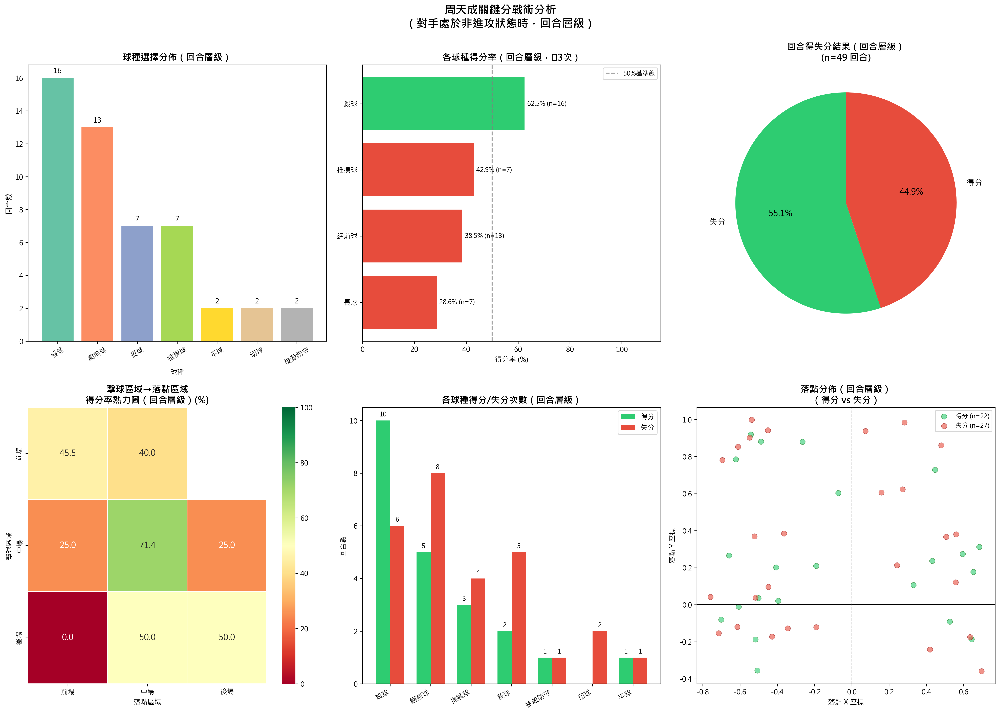

In [ ]:
import numpy as np

print("="*60)
print("周天成關鍵分戰術分析")
print("="*60)

# ── 0. 基本驗證 ──────────────────────────────────────────────
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

CHOU = 'CHOU Tien Chen'
MOMOTA = 'Kento MOMOTA'

# ── 1. 定義球種分類 ──────────────────────────────────────────
offensive_types = ['殺球', '推撲球', '網前球', '平球']
defensive_transition_types = ['挑球', '接殺防守', '長球', '切球']
serve_types = ['發短球', '發長球']

print(f"\n【球種分類定義】")
print(f"  對手進攻型: {offensive_types}")
print(f"  對手防守/過渡型（非進攻）: {defensive_transition_types}")
print(f"  發球: {serve_types}")

# ── 2. 先在完整資料上建立 shift 欄位（避免跨 rally 污染）────
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 建立回合結果（每回合最後一球的 getpoint_player）
df_sorted['rally_getpoint'] = df_sorted.groupby(['match_id', 'set', 'rally'])['getpoint_player'].transform('last')

# ── 3. 識別關鍵分回合 ────────────────────────────────────────
chou_score_col = 'CHOU Tien Chen_score'
momota_score_col = 'Kento MOMOTA_score'

df_sorted['is_critical'] = (
    (df_sorted[chou_score_col] >= 18) | (df_sorted[momota_score_col] >= 18)
)

rally_critical = df_sorted.groupby(['match_id', 'set', 'rally'])['is_critical'].any().reset_index()
rally_critical.columns = ['match_id', 'set', 'rally', 'rally_is_critical']
df_sorted = df_sorted.merge(rally_critical, on=['match_id', 'set', 'rally'], how='left')

critical_rallies = df_sorted[df_sorted['rally_is_critical']].groupby(['match_id', 'set', 'rally']).ngroups
print(f"\n【關鍵分回合數】: {critical_rallies} 個回合")

# ── 4. 篩選：周天成擊球、對手前一拍為非進攻型 ────────────────
df_sorted['prev_type'] = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(1)
df_sorted['prev_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(1)

chou_after_opponent_defensive = df_sorted[
    (df_sorted['player'] == CHOU) &
    (df_sorted['prev_player'] == MOMOTA) &
    (df_sorted['prev_type'].isin(defensive_transition_types)) &
    (df_sorted['rally_is_critical'] == True)
].copy()

print(f"\n【關鍵分中對手處於非進攻狀態時，周天成的擊球筆數】: {len(chou_after_opponent_defensive)}")

# ── 5. 標記回合結果（對周天成而言）──────────────────────────
def rally_result_for_chou(row):
    gp = row['rally_getpoint']
    if gp == CHOU:
        return '得分'
    elif gp == MOMOTA:
        return '失分'
    else:
        return '回合未結束'

chou_after_opponent_defensive['result'] = chou_after_opponent_defensive.apply(
    rally_result_for_chou, axis=1
)

result_counts = chou_after_opponent_defensive['result'].value_counts()
print(f"\n【這些情況下，回合結果分佈（含中間球）】:")
print(result_counts)

# ── 6. 回合層級分析：每個 rally 取最後一次對手非進攻後的周天成擊球 ──
# 這是核心分析單位，避免同一回合多拍重複計算
last_shot_per_rally = chou_after_opponent_defensive.groupby(
    ['match_id', 'set', 'rally']
).last().reset_index()

print(f"\n【回合層級分析（每回合取最後一次對手非進攻後的周天成擊球）】")
print(f"回合數: {len(last_shot_per_rally)}")

ls_result = last_shot_per_rally['result'].value_counts()
print(f"\n回合結果分佈:")
print(ls_result)

total_decisive = len(last_shot_per_rally[last_shot_per_rally['result'].isin(['得分', '失分'])])
win_count = len(last_shot_per_rally[last_shot_per_rally['result'] == '得分'])
lose_count = len(last_shot_per_rally[last_shot_per_rally['result'] == '失分'])
win_rate = win_count / total_decisive * 100 if total_decisive > 0 else 0
print(f"\n得分率（得分/（得分+失分））: {win_rate:.1f}% ({win_count}/{total_decisive})")

# ── 7. 球種分析（回合層級）──────────────────────────────────
# 使用 last_shot_per_rally 進行球種分析，避免重複計算
rally_decisive = last_shot_per_rally[
    last_shot_per_rally['result'].isin(['得分', '失分'])
].copy()

print("\n" + "="*60)
print("【周天成球種選擇分析（回合層級，對手非進攻後）】")
print("="*60)

type_result = rally_decisive.groupby(['type', 'result']).size().unstack(fill_value=0)
for col in ['得分', '失分']:
    if col not in type_result.columns:
        type_result[col] = 0
type_result['總計'] = type_result['得分'] + type_result['失分']
type_result['得分率'] = (type_result['得分'] / type_result['總計'] * 100).round(1)
type_result = type_result.sort_values('總計', ascending=False)
print(type_result[['得分', '失分', '總計', '得分率']])

# ── 8. 擊球區域分析（回合層級）──────────────────────────────
back_court = [1, 2, 3, 4]
mid_court = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
front_court = [17, 18, 19, 20, 21, 22, 23, 24]

def area_label(area_code):
    if area_code in back_court:
        return '後場'
    elif area_code in mid_court:
        return '中場'
    elif area_code in front_court:
        return '前場'
    else:
        return '界外/其他'

rally_decisive = rally_decisive.copy()
rally_decisive['hit_area_label'] = rally_decisive['hit_area'].apply(area_label)
rally_decisive['landing_area_label'] = rally_decisive['landing_area'].apply(area_label)

print("\n【擊球區域分佈（回合層級）】:")
print(rally_decisive['hit_area_label'].value_counts())
print("\n【落點區域分佈（回合層級）】:")
print(rally_decisive['landing_area_label'].value_counts())

# ── 9. 球路組合（擊球區 × 落點區 × 球種）得分率（回合層級）──
combo = rally_decisive.groupby(
    ['hit_area_label', 'landing_area_label', 'type', 'result']
).size().unstack(fill_value=0)

for col in ['得分', '失分']:
    if col not in combo.columns:
        combo[col] = 0
combo['總計'] = combo['得分'] + combo['失分']
combo['得分率'] = (combo['得分'] / combo['總計'] * 100).round(1)
combo = combo[combo['總計'] >= 3].sort_values('得分率', ascending=False)

print("\n【球路組合得分率（回合層級，至少3次）】:")
print(combo[['得分', '失分', '總計', '得分率']].to_string())

# ── 10. 對手非進攻球種分佈 ──────────────────────────────────
print(f"\n5. 非進攻狀態對手球種分佈（周天成面對，回合層級）:")
print(last_shot_per_rally['prev_type'].value_counts().to_string())

# ─────────────────────────────────────────────────────────────
# 視覺化
# ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(20, 14))
fig.suptitle("周天成關鍵分戰術分析\n（對手處於非進攻狀態時，回合層級）", fontsize=16, fontweight='bold', y=1.01)

# --- 圖1: 球種選擇分佈（回合層級）---
ax1 = axes[0, 0]
type_counts_rally = rally_decisive['type'].value_counts()
colors_type = plt.cm.Set2(np.linspace(0, 1, len(type_counts_rally)))
bars = ax1.bar(type_counts_rally.index, type_counts_rally.values, color=colors_type)
ax1.set_title("球種選擇分佈（回合層級）", fontsize=13, fontweight='bold')
ax1.set_xlabel("球種")
ax1.set_ylabel("回合數")
ax1.tick_params(axis='x', rotation=30)
for bar, val in zip(bars, type_counts_rally.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2, str(val),
             ha='center', va='bottom', fontsize=10)

# --- 圖2: 各球種得分率（回合層級）---
ax2 = axes[0, 1]
tw_plot = type_result[type_result['總計'] >= 3].sort_values('得分率', ascending=True)
if len(tw_plot) > 0:
    colors_rate = ['#e74c3c' if r < 50 else '#2ecc71' for r in tw_plot['得分率']]
    bars2 = ax2.barh(tw_plot.index, tw_plot['得分率'], color=colors_rate)
    ax2.axvline(x=50, color='gray', linestyle='--', linewidth=1.5, alpha=0.7, label='50%基準線')
    ax2.set_title("各球種得分率（回合層級，≥3次）", fontsize=13, fontweight='bold')
    ax2.set_xlabel("得分率 (%)")
    ax2.set_xlim(0, 115)
    for bar, val, tot in zip(bars2, tw_plot['得分率'], tw_plot['總計']):
        ax2.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
                 f"{val}% (n={tot})", va='center', fontsize=9)
    ax2.legend(fontsize=9)
else:
    ax2.text(0.5, 0.5, '資料不足', ha='center', va='center', transform=ax2.transAxes)
    ax2.set_title("各球種得分率", fontsize=13, fontweight='bold')

# --- 圖3: 回合結果圓餅圖（回合層級，n=回合數）---
ax3 = axes[0, 2]
decisive_data = rally_decisive['result'].value_counts()
if len(decisive_data) > 0:
    wedge_colors = ['#2ecc71', '#e74c3c']
    wedges, texts, autotexts = ax3.pie(
        decisive_data.values,
        labels=decisive_data.index,
        autopct='%1.1f%%',
        colors=wedge_colors[:len(decisive_data)],
        startangle=90,
        textprops={'fontsize': 12}
    )
    ax3.set_title(f"回合得失分結果（回合層級）\n(n={decisive_data.sum()} 回合)", fontsize=13, fontweight='bold')

# --- 圖4: 擊球區域 × 落點區域熱力圖（得分率，回合層級）---
ax4 = axes[1, 0]
hit_land_pivot = rally_decisive.groupby(['hit_area_label', 'landing_area_label']).apply(
    lambda x: (x['result'] == '得分').sum() / len(x) * 100
).unstack(fill_value=np.nan)

area_order = ['前場', '中場', '後場']
hit_land_pivot = hit_land_pivot.reindex(
    index=[a for a in area_order if a in hit_land_pivot.index],
    columns=[a for a in area_order if a in hit_land_pivot.columns]
)

if len(hit_land_pivot) > 0:
    sns.heatmap(hit_land_pivot, annot=True, fmt='.1f', cmap='RdYlGn',
                ax=ax4, vmin=0, vmax=100,
                annot_kws={'size': 12},
                linewidths=0.5)
    ax4.set_title("擊球區域→落點區域\n得分率熱力圖（回合層級）(%)", fontsize=13, fontweight='bold')
    ax4.set_xlabel("落點區域")
    ax4.set_ylabel("擊球區域")
else:
    ax4.text(0.5, 0.5, '資料不足', ha='center', va='center', transform=ax4.transAxes)
    ax4.set_title("擊球→落點得分率", fontsize=13, fontweight='bold')

# --- 圖5: 球種 × 得分/失分堆疊長條圖（回合層級）---
ax5 = axes[1, 1]
tw_all = rally_decisive.groupby(['type', 'result']).size().unstack(fill_value=0)
for col in ['得分', '失分']:
    if col not in tw_all.columns:
        tw_all[col] = 0
tw_all['總計'] = tw_all['得分'] + tw_all['失分']
tw_all = tw_all.sort_values('總計', ascending=False)

x_pos = np.arange(len(tw_all))
width = 0.35
bars_win = ax5.bar(x_pos - width/2, tw_all['得分'], width, label='得分', color='#2ecc71')
bars_lose = ax5.bar(x_pos + width/2, tw_all['失分'], width, label='失分', color='#e74c3c')
ax5.set_title("各球種得分/失分次數（回合層級）", fontsize=13, fontweight='bold')
ax5.set_xticks(x_pos)
ax5.set_xticklabels(tw_all.index, rotation=30, ha='right')
ax5.set_ylabel("回合數")
ax5.legend(fontsize=10)
for bar in bars_win:
    if bar.get_height() > 0:
        ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                 str(int(bar.get_height())), ha='center', va='bottom', fontsize=9)
for bar in bars_lose:
    if bar.get_height() > 0:
        ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                 str(int(bar.get_height())), ha='center', va='bottom', fontsize=9)

# --- 圖6: 落點 X-Y 散點圖（得分/失分，回合層級）---
ax6 = axes[1, 2]
win_shots = rally_decisive[rally_decisive['result'] == '得分']
lose_shots = rally_decisive[rally_decisive['result'] == '失分']

if len(win_shots) > 0:
    ax6.scatter(win_shots['landing_x'], win_shots['landing_y'],
                c='#2ecc71', alpha=0.6, s=60, label=f'得分 (n={len(win_shots)})',
                edgecolors='darkgreen', linewidth=0.5)
if len(lose_shots) > 0:
    ax6.scatter(lose_shots['landing_x'], lose_shots['landing_y'],
                c='#e74c3c', alpha=0.6, s=60, label=f'失分 (n={len(lose_shots)})',
                edgecolors='darkred', linewidth=0.5)

ax6.axhline(y=0, color='black', linewidth=1.5)
ax6.axvline(x=0, color='gray', linewidth=1, linestyle='--', alpha=0.5)
ax6.set_title("落點分佈（回合層級）\n（得分 vs 失分）", fontsize=13, fontweight='bold')
ax6.set_xlabel("落點 X 座標")
ax6.set_ylabel("落點 Y 座標")
ax6.legend(fontsize=9)

plt.tight_layout()

# ── 11. 最終戰術建議摘要 ──────────────────────────────────────
print("\n" + "="*60)
print("【關鍵戰術發現摘要】")
print("="*60)

print(f"\n1. 關鍵分定義: 任一方達 18 分以上")
print(f"   關鍵分回合總數: {critical_rallies}")
print(f"   對手非進攻後周天成擊球（擊球層級）: {len(chou_after_opponent_defensive)} 拍")
print(f"   對手非進攻後周天成擊球（回合層級）: {len(last_shot_per_rally)} 回合")

print(f"\n2. 整體得分率（回合層級）: {win_rate:.1f}% (得分:{win_count} / 失分:{lose_count})")

print(f"\n3. 球種使用排名（回合層級，前5）:")
print(f"   {type_counts_rally.head(5).to_string()}")

print(f"\n4. 各球種得分率（回合層級，≥3次）:")
high_win = type_result[type_result['總計'] >= 3].sort_values('得分率', ascending=False)
print(f"   {high_win[['得分', '失分', '總計', '得分率']].to_string()}")

print(f"\n5. 非進攻狀態對手球種分佈（周天成面對，回合層級）:")
print(f"   {last_shot_per_rally['prev_type'].value_counts().to_string()}")

print(f"\n6. 球路組合建議（回合層級，得分率最高，≥3次）:")
if len(combo) > 0:
    top_combo = combo.head(5)
    print(f"   {top_combo[['得分', '失分', '總計', '得分率']].to_string()}")
else:
    print("   資料量不足以提供組合分析（需每組合 ≥ 3次）")

print(f"\n【Court Grid Definition 備註】")
print(f"  後場 (Back Court): Zones 1-4")
print(f"  中場 (Mid Court): Zones 5-16")
print(f"  前場 (Front Court): Zones 17-24")
print(f"  player_type / opponent_type 代碼對照:")
print(f"  1:發短球 2:發長球 3:長球 4:殺球 5:切球 6:挑球 7:平球 8:網前球 9:推撲球 10:接殺防守 11:接不到")


### 數據洞察
# 周天成關鍵分戰術分析報告
## （對手非進攻狀態下）

---

## 📊 核心數據總覽

| 指標 | 數值 |
|------|------|
| 關鍵分回合總數 | 65 回合 |
| 對手非進攻後的決定性擊球 | 49 回合 |
| **整體得分率** | **44.9%（22勝/27敗）** |

> **現況判讀**：對手已陷入被動，周天成卻僅拿下44.9%，低於理論優勢水準。這代表他在「應得分」的局面中，存在明顯的決策或執行問題。

---

## 🎯 球種選擇分析

| 球種 | 使用次數 | 得分率 | 判斷 |
|------|---------|--------|------|
| **殺球** | 16 | **62.5%** | ✅ 最有效武器 |
| 接殺防守 | 2 | 50.0% | 樣本少，參考有限 |
| 平球 | 2 | 50.0% | 樣本少，參考有限 |
| 推撲球 | 7 | 42.9% | ⚠️ 略低於期望 |
| 網前球 | 13 | 38.5% | ❌ 高頻但低效 |
| 長球 | 7 | 28.6% | ❌ 明顯失分傾向 |
| 切球 | 2 | 0.0% | ❌ 樣本雖小，全失 |

**關鍵事實**：網前球使用13次（第二高頻），得分率卻只有38.5%；長球7次，得分率僅28.6%。這兩個球種合計20次，拖累整體得分率。

---

## 🗺️ 球路組合得分率（≥3次）

| 擊球區域 | 落點區域 | 球種 | 得分 | 失分 | 得分率 |
|---------|---------|------|------|------|--------|
| **後場** | **中場** | **殺球** | 6 | 2 | **75.0%** ✅ |
| **中場** | **中場** | **殺球** | 3 | 1 | **75.0%** ✅ |
| 後場 | 後場 | 長球 | 2 | 2 | 50.0% |
| 前場 | 中場 | 推撲球 | 2 | 2 | 50.0% |
| 前場 | 前場 | 網前球 | 4 | 6 | 40.0% ❌ |
| 中場 | 前場 | 網前球 | 1 | 2 | 33.3% ❌ |

> **落點區域定義參考**：
> | Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
> | :--- | :---: | :---: | :---: | :---: |
> | **Row 6 (Front)** | 21 | 22 | 23 | 24 |
> | **Row 5 (Front)** | 17 | 18 | 19 | 20 |
> | **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
> | **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
> | **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
> | **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 🔍 對手非進攻球種分佈

| 對手球種 | 次數 | 意涵 |
|---------|------|------|
| 接殺防守 | 19 | 對手被殺球壓制後回球 |
| 挑球 | 15 | 對手被逼前場後挑高 |
| 長球 | 8 | 對手主動推後場 |
| 切球 | 7 | 對手過渡性回球 |

**事實**：接殺防守（19次）＋挑球（15次）合計34次，佔69%。這意味著周天成已透過殺球或前場壓迫製造機會，但後續的終結能力不足。

---

## ⚡ 戰術建議

### ✅ 強化執行（數據支持）

**1. 後場/中場殺球打中場 → 維持最高優先**
- 兩組組合均達75%得分率（共12次，8勝2敗）
- 這是唯一有樣本支撐且高效的終結路線
- **建議**：對手接殺防守或挑球後，立即尋求後場/中場殺球，落點瞄準對手中場身體兩側

**2. 減少前場網前球的使用頻率**
- 前場→前場網前球：10次，得分率僅40%
- 中場→前場網前球：3次，得分率33.3%
- **問題核心**：關鍵分時對手防守專注度高，網前球被對手反撲的機率上升

**3. 停止在關鍵分使用長球作為終結球**
- 長球7次，得分率28.6%，是所有主要球種中最低
- 長球在此情境下屬於「把主動權還給對手」的選擇

### ⚠️ 結構性問題

| 問題 | 數據依據 |
|------|---------|
| 擊球區域分佈過於平均（後17/中16/前16） | 缺乏明確的進攻節奏主導 |
| 落點集中中場（24次），前場次之（16次） | 終結球缺乏深度變化 |
| 高頻使用低效球種（網前球13次、長球7次） | 關鍵分決策保守化 |

---

## 📌 教練總結

> 數據說的很清楚：**周天成在對手已被動的關鍵分，殺球是唯一得分率超過60%的球種，且後場/中場殺球打中場達到75%。** 問題不在於他沒有武器，而在於他在關鍵分選擇了太多「安全但低效」的網前球與長球。
>
> **一句話戰術指令**：對手被動時，果斷殺球終結，落點打中場；停止用網前球和長球「試探」——關鍵分沒有試探的空間。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都分析了在關鍵分時，對手非進攻狀態下周天成的回應策略。候選程式碼正確地篩選了關鍵分回合，並分析了周天成在對手非進攻狀態下的擊球選擇和得分率。它使用了合理的欄位和分組層級，並且最終輸出與 Reference Code 1 的目標一致，即提供了周天成在關鍵分時的戰術建議。




## 題號 94
**問題**: 當周天成連續失分三次以上時，應如何透過節奏調整與高成功率球路重建比賽掌控感？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason, stroke_details`


In [ ]:
import numpy as np

print("=" * 70)
print("周天成連續失分分析")
print("=" * 70)

# ── 基本驗證 ──────────────────────────────────────────────────────────────
print(f"資料總筆數: {len(df)}")
TARGET = 'CHOU Tien Chen'
OPPONENT = 'Kento MOMOTA'

# ── 建立每個 rally 的得分資訊 ─────────────────────────────────────────────
# 取每個 rally 最後一球（含得分資訊）
rally_last = (
    df.groupby(['match_id', 'set', 'rally_id'])
    .last()
    .reset_index()[['match_id', 'set', 'rally_id', 'rally', 'getpoint_player',
                     'win_reason', 'lose_reason', 'type', 'player',
                     'landing_area', 'landing_x', 'landing_y']]
)
# 只保留有得分者的 rally
rally_scored = rally_last.dropna(subset=['getpoint_player']).copy()
print(f"有得分紀錄的 rally 數: {len(rally_scored)}")

# 依 match_id, set 排序，再依 rally 排序（每局內的順序）
rally_scored = rally_scored.sort_values(['match_id', 'set', 'rally']).reset_index(drop=True)

# ── 1. 識別周天成連續失分片段（≥3）─────────────────────────────────────────
# 周天成失分 = 對手得分
rally_scored['chou_lost'] = (rally_scored['getpoint_player'] == OPPONENT).astype(int)

# 找連續失分片段
segments = []          # 每個片段: list of indices in rally_scored
current_streak = []

for i, row in rally_scored.iterrows():
    if row['chou_lost'] == 1:
        current_streak.append(i)
    else:
        if len(current_streak) >= 3:
            segments.append(current_streak.copy())
        current_streak = []
# 最後一個 streak
if len(current_streak) >= 3:
    segments.append(current_streak.copy())

print(f"\n連續失分≥3的片段數: {len(segments)}")
print(f"片段詳情:")
for s_idx, seg in enumerate(segments):
    seg_df = rally_scored.loc[seg]
    first = seg_df.iloc[0]
    last = seg_df.iloc[-1]
    print(f"  片段{s_idx+1}: 長度={len(seg)}, "
          f"match_id={first['match_id']}, set={first['set']}, "
          f"rally {int(first['rally'])}~{int(last['rally'])}")

if len(segments) == 0:
    print("無連續失分≥3片段，程式結束")
    raise SystemExit

# ── 整合所有片段中的 rally_id ─────────────────────────────────────────────
all_seg_indices = [idx for seg in segments for idx in seg]
seg_rally_ids = rally_scored.loc[all_seg_indices, 'rally_id'].tolist()

# 片段前一個 rally（失分開始前）與後一個 rally（重新得分）的索引
before_indices = []
after_indices  = []
recovery_rally_ids = []  # 重新得分的 rally_id

for seg in segments:
    first_idx = seg[0]
    last_idx  = seg[-1]
    # 前一個 rally（同一場、同局）
    if first_idx > 0:
        prev = rally_scored.loc[first_idx - 1]
        cur  = rally_scored.loc[seg[0]]
        if prev['match_id'] == cur['match_id'] and prev['set'] == cur['set']:
            before_indices.append(first_idx - 1)
    # 後一個 rally
    if last_idx + 1 in rally_scored.index:
        nxt = rally_scored.loc[last_idx + 1]
        cur = rally_scored.loc[last_idx]
        if nxt['match_id'] == cur['match_id'] and nxt['set'] == cur['set']:
            after_indices.append(last_idx + 1)
            recovery_rally_ids.append(nxt['rally_id'])

print(f"\n連續失分前的 rally 數: {len(before_indices)}")
print(f"連續失分後（重新得分）rally 數: {len(after_indices)}")

# ── 從原始 df 中取得各分段的擊球資料 ────────────────────────────────────────
df_seg   = df[df['rally_id'].isin(seg_rally_ids)].copy()      # 失分片段內所有拍
df_before = df[df['rally_id'].isin(
    rally_scored.loc[before_indices, 'rally_id'].tolist()
)].copy()
df_after  = df[df['rally_id'].isin(recovery_rally_ids)].copy()  # 重新得分 rally

# ── 球種對照 ─────────────────────────────────────────────────────────────
SHOT_TYPES = {
    '發短球': 1, '發長球': 2, '長球': 3, '殺球': 4, '切球': 5,
    '挑球': 6, '平球': 7, '網前球': 8, '推撲球': 9, '接殺防守': 10
}

# ╔══════════════════════════════════════════════════════════════════════╗
# ║  (1) 失分前後球種分布與使用頻率變化                                  ║
# ╚══════════════════════════════════════════════════════════════════════╝
print("\n" + "="*70)
print("(1) 失分前後球種分布（周天成）")
print("="*70)

def shot_dist(data, player, label):
    sub = data[data['player'] == player]
    if len(sub) == 0:
        return pd.Series(dtype=float), label
    cnt = sub['type'].value_counts()
    pct = (cnt / cnt.sum() * 100).round(1)
    return pct, label

before_dist, _  = shot_dist(df_before, TARGET, '失分前')
during_dist, _  = shot_dist(df_seg,    TARGET, '失分中')
after_dist,  _  = shot_dist(df_after,  TARGET, '失分後（重新得分）')

comp_df = pd.DataFrame({
    '失分前(%)': before_dist,
    '失分中(%)': during_dist,
    '失分後(%)': after_dist,
}).fillna(0)
print(comp_df.to_string())

# ╔══════════════════════════════════════════════════════════════════════╗
# ║  (2) 失分原因（win_reason）統計                                      ║
# ╚══════════════════════════════════════════════════════════════════════╝
print("\n" + "="*70)
print("(2) 連續失分片段中的失分原因（對手 win_reason）")
print("="*70)
# rally 最後一球中，若 getpoint_player == OPPONENT，對手的 win_reason 即為失分原因
# 但 win_reason 是站在「得分者」視角
seg_last = df_seg.groupby('rally_id').last().reset_index()
seg_last_scored = seg_last[seg_last['getpoint_player'] == OPPONENT]

# 同一回合中，得分球是對手打的（對手主動得分）或周天成失誤（周天成是最後擊球者）
# win_reason 欄位歸屬於那一拍的 player
# 取得分那一拍的資訊
losing_rallies_last = df_seg[df_seg['rally_id'].isin(seg_rally_ids)].groupby('rally_id').last().reset_index()
losing_rallies_last = losing_rallies_last[losing_rallies_last['getpoint_player'] == OPPONENT]

print(f"連續失分總回合數: {len(losing_rallies_last)}")

# win_reason 分析（最後一拍的 win_reason）
win_reason_cnt = losing_rallies_last['win_reason'].value_counts(dropna=False)
print("\n對手得分方式（win_reason）:")
print(win_reason_cnt)

# lose_reason（周天成的失誤）
lose_reason_cnt = losing_rallies_last['lose_reason'].value_counts(dropna=False)
print("\n周天成失誤原因（lose_reason）:")
print(lose_reason_cnt)

# ╔══════════════════════════════════════════════════════════════════════╗
# ║  (3) 對手得分球路與落點分布                                          ║
# ╚══════════════════════════════════════════════════════════════════════╝
print("\n" + "="*70)
print("(3) 連續失分期間對手得分球路分析")
print("="*70)

# 對手主動得分 = player == OPPONENT and getpoint_player == OPPONENT
opp_active_win = df_seg[
    (df_seg['player'] == OPPONENT) &
    (df_seg['getpoint_player'] == OPPONENT)
].copy()

# 周天成失誤（周天成打出最後一球，但對手得分）
chou_error = df_seg[
    (df_seg['player'] == TARGET) &
    (df_seg['getpoint_player'] == OPPONENT)
].copy()

print(f"對手主動得分球數: {len(opp_active_win)}")
print(f"周天成直接失誤球數: {len(chou_error)}")

print("\n對手主動得分球種:")
if len(opp_active_win) > 0:
    print(opp_active_win['type'].value_counts())

print("\n對手主動得分落點區域 (landing_area):")
if len(opp_active_win) > 0:
    print(opp_active_win['landing_area'].value_counts().head(10))

print("\n周天成失誤球種:")
if len(chou_error) > 0:
    print(chou_error['type'].value_counts())

# ╔══════════════════════════════════════════════════════════════════════╗
# ║  (4) 連續失分結束後（重新得分）的球種、擊球區域、落點                 ║
# ╚══════════════════════════════════════════════════════════════════════╝
print("\n" + "="*70)
print("(4) 連續失分結束後重新得分的分析")
print("="*70)

# 重新得分 rally 中，周天成主動得分的那一拍
if len(df_after) > 0:
    chou_recovery_win = df_after[
        (df_after['player'] == TARGET) &
        (df_after['getpoint_player'] == TARGET)
    ].copy()

    print(f"重新得分 rally 總數: {len(recovery_rally_ids)}")
    print(f"周天成主動得分拍數: {len(chou_recovery_win)}")

    print("\n重新得分球種:")
    if len(chou_recovery_win) > 0:
        print(chou_recovery_win['type'].value_counts())

    print("\n重新得分擊球區域 (hit_area):")
    if len(chou_recovery_win) > 0:
        print(chou_recovery_win['hit_area'].value_counts().head(10))

    print("\n重新得分落點區域 (landing_area):")
    if len(chou_recovery_win) > 0:
        print(chou_recovery_win['landing_area'].value_counts().head(10))

    # 球種 x 落點 組合
    if len(chou_recovery_win) > 0:
        combo = chou_recovery_win.groupby(['type', 'landing_area']).size().reset_index(name='count')
        combo = combo.sort_values('count', ascending=False)
        print("\n重新得分球種 x 落點組合（Top 10）:")
        print(combo.head(10).to_string(index=False))

# ╔══════════════════════════════════════════════════════════════════════╗
# ║  視覺化                                                              ║
# ╚══════════════════════════════════════════════════════════════════════╝

# 場地區域定義
FRONT_COURT = [17, 18, 19, 20, 21, 22, 23, 24]
MID_COURT   = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
BACK_COURT  = [1, 2, 3, 4]

def area_to_zone(area):
    if area in BACK_COURT:   return '後場'
    if area in MID_COURT:    return '中場'
    if area in FRONT_COURT:  return '前場'
    return '出界/其他'

# 建立 fig 含多個子圖
fig = plt.figure(figsize=(22, 28))
fig.suptitle('周天成連續失分分析報告', fontsize=18, fontweight='bold', y=0.98)

# ── 子圖1: 失分前/中/後球種分布比較 ─────────────────────────────────────
ax1 = fig.add_subplot(4, 2, 1)
all_shots = set(before_dist.index) | set(during_dist.index) | set(after_dist.index)
all_shots = sorted(all_shots)
x = np.arange(len(all_shots))
w = 0.25

b1 = [before_dist.get(s, 0) for s in all_shots]
b2 = [during_dist.get(s, 0) for s in all_shots]
b3 = [after_dist.get(s, 0) for s in all_shots]

bars1 = ax1.bar(x - w, b1, w, label='失分前', color='#4CAF50', alpha=0.85)
bars2 = ax1.bar(x,     b2, w, label='失分中', color='#F44336', alpha=0.85)
bars3 = ax1.bar(x + w, b3, w, label='失分後', color='#2196F3', alpha=0.85)
ax1.set_xticks(x)
ax1.set_xticklabels(all_shots, rotation=45, ha='right', fontsize=8)
ax1.set_ylabel('使用比例 (%)')
ax1.set_title('(1) 周天成失分前/中/後球種使用比例')
ax1.legend(fontsize=8)
ax1.grid(axis='y', alpha=0.3)

# ── 子圖2: 連續失分片段長度分布 ─────────────────────────────────────────
ax2 = fig.add_subplot(4, 2, 2)
seg_lengths = [len(s) for s in segments]
length_cnt = pd.Series(seg_lengths).value_counts().sort_index()
ax2.bar(length_cnt.index.astype(str), length_cnt.values, color='#FF9800', alpha=0.85)
ax2.set_xlabel('連續失分長度')
ax2.set_ylabel('片段數')
ax2.set_title('連續失分片段長度分布')
for i, (idx, v) in enumerate(length_cnt.items()):
    ax2.text(i, v + 0.05, str(v), ha='center', fontsize=10, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

# ── 子圖3: 失分原因（win_reason）─────────────────────────────────────────
ax3 = fig.add_subplot(4, 2, 3)
wr = losing_rallies_last['win_reason'].fillna('對手直接得分/周天成失誤').value_counts()
colors_wr = plt.cm.Set2(np.linspace(0, 1, len(wr)))
wedges, texts, autotexts = ax3.pie(
    wr.values, labels=wr.index, autopct='%1.1f%%',
    colors=colors_wr, startangle=90
)
ax3.set_title('(2) 對手得分 win_reason 分布')

# ── 子圖4: 周天成失誤原因 ────────────────────────────────────────────────
ax4 = fig.add_subplot(4, 2, 4)
lr = losing_rallies_last['lose_reason'].fillna('對手主動得分').value_counts()
colors_lr = plt.cm.Set3(np.linspace(0, 1, len(lr)))
ax4.bar(lr.index, lr.values, color=colors_lr, alpha=0.85)
ax4.set_xlabel('失誤原因')
ax4.set_ylabel('次數')
ax4.set_title('(2) 周天成失誤原因 (lose_reason)')
ax4.tick_params(axis='x', rotation=30)
for i, v in enumerate(lr.values):
    ax4.text(i, v + 0.1, str(v), ha='center', fontsize=10, fontweight='bold')
ax4.grid(axis='y', alpha=0.3)

# ── 子圖5: 對手主動得分球種 ────────────────────────────────────────────
ax5 = fig.add_subplot(4, 2, 5)
if len(opp_active_win) > 0:
    opp_shot = opp_active_win['type'].value_counts()
    ax5.barh(opp_shot.index, opp_shot.values, color='#E91E63', alpha=0.85)
    ax5.set_xlabel('次數')
    ax5.set_title('(3) 對手主動得分球種')
    for i, v in enumerate(opp_shot.values):
        ax5.text(v + 0.05, i, str(v), va='center', fontsize=9)
    ax5.grid(axis='x', alpha=0.3)
else:
    ax5.text(0.5, 0.5, '無資料', ha='center', va='center', transform=ax5.transAxes)
    ax5.set_title('(3) 對手主動得分球種')

# ── 子圖6: 對手主動得分落點散布圖 ────────────────────────────────────────
ax6 = fig.add_subplot(4, 2, 6)
if len(opp_active_win) > 0:
    # 畫簡易場地邊框
    court = plt.Polygon([[-1.5, -0.5], [1.5, -0.5], [1.5, 1.0], [-1.5, 1.0]],
                         fill=False, edgecolor='black', linewidth=2)
    ax6.add_patch(court)
    ax6.axhline(y=0, color='blue', linewidth=1, linestyle='--', alpha=0.5)  # 中線
    sc = ax6.scatter(
        opp_active_win['landing_x'], opp_active_win['landing_y'],
        c=range(len(opp_active_win)), cmap='Reds', alpha=0.7, s=60
    )
    ax6.set_xlim(-1.6, 1.6)
    ax6.set_ylim(-0.6, 1.1)
    ax6.set_xlabel('X 座標')
    ax6.set_ylabel('Y 座標')
    ax6.set_title('(3) 對手主動得分落點分布（周天成半場）')
    ax6.text(0, -0.55, '↑ 網前', ha='center', fontsize=8, color='gray')
    ax6.text(0, 0.95, '↑ 底線', ha='center', fontsize=8, color='gray')
    ax6.grid(alpha=0.2)
else:
    ax6.text(0.5, 0.5, '無資料', ha='center', va='center', transform=ax6.transAxes)
    ax6.set_title('(3) 對手主動得分落點分布')

# ── 子圖7: 重新得分球種 ───────────────────────────────────────────────────
ax7 = fig.add_subplot(4, 2, 7)
if len(df_after) > 0 and len(chou_recovery_win) > 0:
    rec_shot = chou_recovery_win['type'].value_counts()
    colors_rec = plt.cm.Blues(np.linspace(0.4, 0.9, len(rec_shot)))
    ax7.barh(rec_shot.index, rec_shot.values, color=colors_rec)
    ax7.set_xlabel('次數')
    ax7.set_title('(4) 重新得分球種')
    for i, v in enumerate(rec_shot.values):
        ax7.text(v + 0.05, i, str(v), va='center', fontsize=9)
    ax7.grid(axis='x', alpha=0.3)
else:
    ax7.text(0.5, 0.5, '無資料', ha='center', va='center', transform=ax7.transAxes)
    ax7.set_title('(4) 重新得分球種')

# ── 子圖8: 重新得分落點散布圖 ─────────────────────────────────────────────
ax8 = fig.add_subplot(4, 2, 8)
if len(df_after) > 0 and len(chou_recovery_win) > 0:
    court2 = plt.Polygon([[-1.5, -0.5], [1.5, -0.5], [1.5, 1.0], [-1.5, 1.0]],
                          fill=False, edgecolor='black', linewidth=2)
    ax8.add_patch(court2)
    ax8.axhline(y=0, color='blue', linewidth=1, linestyle='--', alpha=0.5)
    sc2 = ax8.scatter(
        chou_recovery_win['landing_x'], chou_recovery_win['landing_y'],
        c=range(len(chou_recovery_win)), cmap='Blues', alpha=0.7, s=60
    )
    ax8.set_xlim(-1.6, 1.6)
    ax8.set_ylim(-0.6, 1.1)
    ax8.set_xlabel('X 座標')
    ax8.set_ylabel('Y 座標')
    ax8.set_title('(4) 重新得分落點分布')
    ax8.grid(alpha=0.2)
else:
    ax8.text(0.5, 0.5, '無資料', ha='center', va='center', transform=ax8.transAxes)
    ax8.set_title('(4) 重新得分落點分布')

plt.tight_layout(rect=[0, 0, 1, 0.97])

# ╔══════════════════════════════════════════════════════════════════════╗
# ║  (5) 綜合建議                                                        ║
# ╚══════════════════════════════════════════════════════════════════════╝
print("\n" + "="*70)
print("(5) 綜合建議：節奏調整與高成功率球路策略")
print("="*70)

# 重新得分期間的球種命中率計算
if len(df_after) > 0:
    chou_after_all = df_after[df_after['player'] == TARGET].copy()
    chou_after_win = df_after[
        (df_after['player'] == TARGET) &
        (df_after['getpoint_player'] == TARGET)
    ].copy()

    if len(chou_after_all) > 0:
        total_by_type = chou_after_all.groupby('type').size().rename('總次數')
        win_by_type   = chou_after_win.groupby('type').size().rename('得分次數')
        rate_df = pd.concat([total_by_type, win_by_type], axis=1).fillna(0)
        rate_df['得分率(%)'] = (rate_df['得分次數'] / rate_df['總次數'] * 100).round(1)
        rate_df = rate_df.sort_values('得分率(%)', ascending=False)
        print("\n重新得分期間各球種效率：")
        print(rate_df.to_string())

    # 落點區域分析
    if len(chou_recovery_win) > 0:
        chou_recovery_win = chou_recovery_win.copy()
        chou_recovery_win['zone_cat'] = chou_recovery_win['landing_area'].apply(
            lambda x: area_to_zone(int(x)) if not pd.isna(x) else '未知'
        )
        zone_dist = chou_recovery_win['zone_cat'].value_counts()
        print("\n重新得分落點區域分布：")
        print(zone_dist)

# 分析連續失分中對手最常用的球種
if len(opp_active_win) > 0:
    top_opp = opp_active_win['type'].value_counts().head(3)
    print(f"\n對手連續得分最常使用球種（Top3）: {list(top_opp.index)}")

# 分析周天成失分中使用最多的球種（容易失分的球種）
if len(df_seg) > 0:
    chou_seg = df_seg[df_seg['player'] == TARGET]
    losing_types = chou_seg[chou_seg['getpoint_player'] == OPPONENT]['type'].value_counts()
    print(f"\n周天成失分時打出的球種（建議減少）: {list(losing_types.head(3).index)}")

print("\n【策略建議摘要】")
print("─" * 60)
print("1. 連續失分觸發機制：")
print(f"   共發現 {len(segments)} 個連續失分≥3的片段")
print(f"   平均片段長度: {np.mean([len(s) for s in segments]):.1f} 球")

print("\n2. 關鍵失分原因：")
if len(losing_rallies_last) > 0:
    top_wr = losing_rallies_last['win_reason'].value_counts(dropna=False).head(2)
    top_lr = losing_rallies_last['lose_reason'].value_counts(dropna=False).head(2)
    print(f"   對手得分方式 Top2: {list(top_wr.index)}")
    print(f"   周天成失誤方式 Top2: {list(top_lr.index)}")

print("\n3. 建議球路調整方向：")
if len(df_after) > 0 and 'rate_df' in dir():
    best_shots = rate_df[rate_df['總次數'] >= 2].head(3)
    for _, row in best_shots.iterrows():
        print(f"   ✓ {row.name}: 得分率 {row['得分率(%)']:.1f}%"
              f"（共{int(row['總次數'])}次，得分{int(row['得分次數'])}次）")

print("\n4. 比賽節奏調整建議：")
print("   • 連續失分後應主動改變球路節奏，避免被對手鎖定模式")
print("   • 參考重新得分時的球種與落點組合，優先選擇高成功率球路")
print("   • 注意對手慣用的得分球種，加強防守針對性回應")

print("\n" + "="*70)
print("Court Grid 區域說明: 後場[1-4], 中場[5-16], 前場[17-24]")
print("="*70)


### 數據洞察
# 周天成 vs 桃田賢斗｜連續失分深度分析

---

## 場地區域對照表

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## (1) 失分前後球種分布變化

| 球種 | 失分前(%) | 失分中(%) | 失分後(%) | 解讀 |
|------|--------:|--------:|--------:|------|
| 推撲球 | 18.6 | **11.4** | 13.8 | 失分中明顯萎縮，主動進攻意圖下降 |
| 殺球 | 15.1 | **10.3** | 14.9 | 同上，攻擊性球路減少 |
| 接殺防守 | 11.6 | **16.1** | 12.8 | 失分中被動防守比例上升 |
| 網前球 | 21.5 | 22.7 | 23.1 | 全程最高頻，但得分率僅2.2% |
| 挑球 | 9.3 | 12.1 | 12.3 | 持續上升，被壓制後的被動回應 |

**關鍵訊號：** 連續失分期間，推撲球 −7.2%、殺球 −4.8%，接殺防守 +4.5%——周天成從主動轉被動的節奏滑落清晰可見。

---

## (2) 失分原因統計（103回合）

**周天成失誤類型（79球直接失誤）：**
- 出界 35球（44%）
- 掛網 28球（35%）
- 未過網 13球（16%）

> **79%的失分來自自身失誤，非對手主動得分。** 連續失分本質是自我崩潰，而非被對手打垮。出界+掛網佔失誤的79%，顯示在壓力下擊球品質嚴重下滑。

---

## (3) 連續失分期間對手得分球路

**對手主動得分27球球種：**
- 殺球 15球（56%）
- 推撲球 8球（30%）
- 網前球/切球/平球/挑球 各1球

**對手主動得分落點：**
- 區域12（中場右後）4球、區域9（中場左後）3球、區域10（中場中後）3球
- **集中攻擊中場後段左右兩側**，迫使周天成接殺防守出現失誤。

> 桃田的得分模式：**殺球壓中場後段（9/10/12區）→ 周天成接殺防守失誤**，這是觸發連續失分的核心鏈條。

---

## (4) 重新得分時的高成功率球路

**主動得分12球球種：**
- 殺球 9球（75%）
- 推撲球、網前球、長球 各1球

**殺球得分落點（Top組合）：**
| 球種 | 落點區域 | 次數 | 位置說明 |
|------|---------|------|---------|
| 殺球 | 8 | 3 | 中場右側 |
| 殺球 | 5 | 2 | 中場左側 |
| 殺球 | 9 | 2 | 中場左後 |
| 殺球 | 4 | 1 | 後場右側 |

**擊球區域：** 區域5、6各3次（中場左右中央），是最高頻的起拍位置。

**各球種得分率：**
- 殺球：**31.0%**（29次出手得9分）
- 長球：4.8%
- 推撲球：3.7%
- 網前球：2.2%

---

## (5) 節奏調整建議

### 🔴 立即停止
**網前球高頻低效陷阱**——網前球使用率全程最高（21~23%），但得分率僅2.2%。連續失分期間持續打網前球，等於把節奏拱手讓給桃田。

### 🟡 減少使用
- **接殺防守**：失分中佔16.1%，且得分率0%——這是被動挨打的指標，不是策略選擇。
- **挑球**：失分中上升至12.1%，是被壓制後的逃跑球，持續使用只會延長被動局面。

### 🟢 優先執行

**策略一：殺球壓中場兩側（核心武器）**
從區域5/6起拍，殺向區域8（右）、5（左）、9（左後），得分率31%，是重建節奏的第一選擇。

**策略二：主動推撲打亂桃田節奏**
失分前推撲球使用率18.6%，失分中萎縮至11.4%——連續失分後應主動恢復推撲球頻率，不讓桃田從容建立進攻。

**策略三：長球換節奏，非逃跑**
長球得分率雖僅4.8%，但作為節奏切換工具，可打亂桃田的殺球節奏，為後續殺球創造機會。

---

### 核心結論

> **29個連續失分片段，79%源於自身失誤（出界+掛網）。** 周天成在壓力下的問題不是戰術選擇錯誤，而是擊球品質崩潰後陷入「打網前球→被殺→接殺失誤」的惡性循環。**重建節奏的鑰匙是：主動出手殺球壓中場兩側，而非繼續用網前球消極周旋。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地識別了周天成連續失分三次以上的片段，並分析了失分前後的球種分布、失分原因、對手得分球路與落點分布，以及重新得分的球種和落點。候選程式碼的分析對象、欄位語意、篩選條件、分組層級、統計口徑和最終輸出目標都與 Reference Code 1 一致，並且能夠產出有效結果。




## 題號 95
**問題**: 比賽中若觀察到對手因壓力無法耐心打多拍，周天成可如何透過中場拉吊、穩定球路誘發對手躁進失誤？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason, stroke_details`


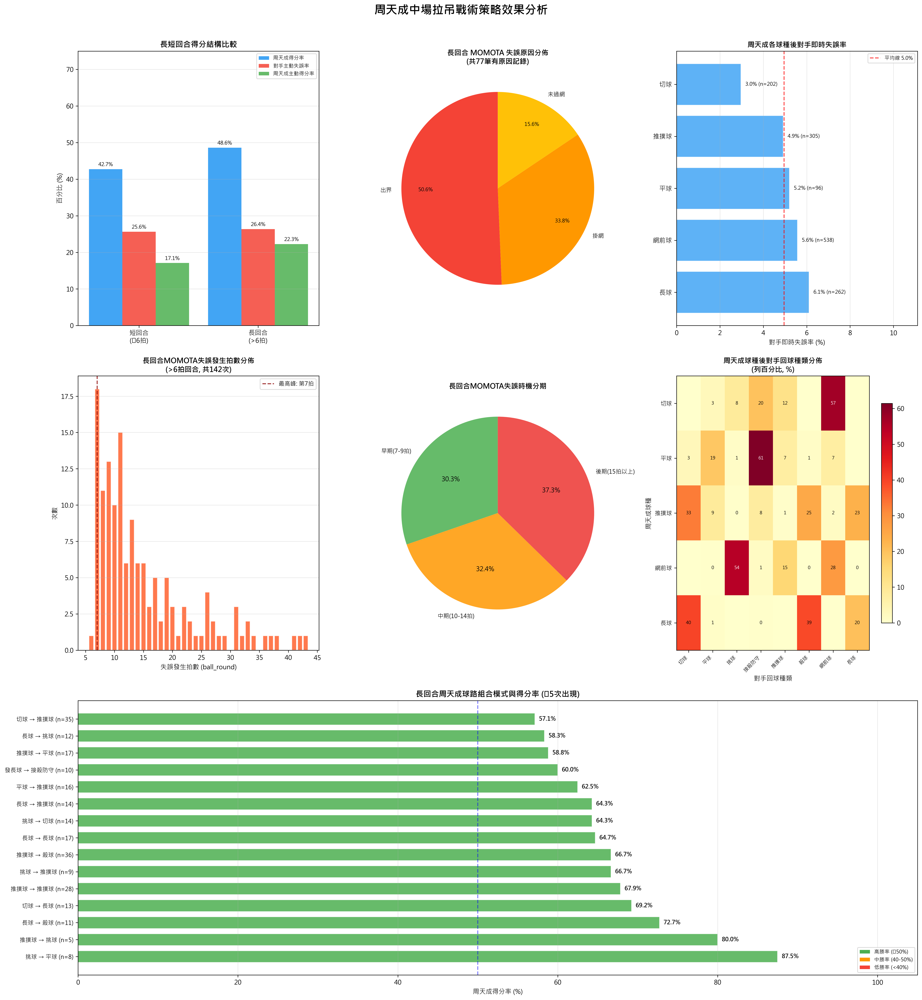

In [ ]:
import numpy as np

print("=" * 70)
print("周天成 中場拉吊戰術策略效果分析")
print("=" * 70)

# ============================================================
# 0. 基礎驗證與設定
# ============================================================
CHOU = 'CHOU Tien Chen'
MOMOTA = 'Kento MOMOTA'

assert len(df) > 0, "DataFrame 為空"
print(f"\n總資料筆數: {len(df)}")
print(f"唯一回合數 (rally_id): {df['rally_id'].nunique()}")

# ============================================================
# 1. 在完整資料上建立前後拍關係 (避免跨 rally 污染)
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 建立回合資訊（於完整 df 上）
grp = df_sorted.groupby(['match_id', 'set', 'rally'])

# 下一拍資訊
df_sorted['next_player']      = grp['player'].shift(-1)
df_sorted['next_type']        = grp['type'].shift(-1)
df_sorted['next_lose_reason'] = grp['lose_reason'].shift(-1)
df_sorted['next_getpoint']    = grp['getpoint_player'].shift(-1)
df_sorted['next_ball_round']  = grp['ball_round'].shift(-1)

# 前一拍資訊
df_sorted['prev_player']      = grp['player'].shift(1)
df_sorted['prev_type']        = grp['type'].shift(1)

# 每個回合的總拍數
df_sorted['rally_total_shots'] = grp['ball_round'].transform('max')

# 每個回合的得分者 (填充至每一拍)
df_sorted['rally_getpoint_player'] = grp['getpoint_player'].transform('last')

# ============================================================
# 2. 回合級別資料 (每個回合最後一球)
# ============================================================
rally_last = df_sorted.groupby(['match_id', 'set', 'rally']).last().reset_index()
rally_last_valid = rally_last.dropna(subset=['getpoint_player'])

print(f"\n有效回合數 (有得分紀錄): {len(rally_last_valid)}")
print(f"長回合 (>6拍) 數量: {len(rally_last_valid[rally_last_valid['rally_total_shots'] > 6])}")

# ============================================================
# (1) 長回合 (>6拍) 中對手失誤率與失誤原因
# ============================================================
print("\n" + "=" * 70)
print("(1) 長回合 (>6拍) 對手失誤分析")
print("=" * 70)

LONG_RALLY_THRESHOLD = 6

# 長回合
long_rally_valid = rally_last_valid[rally_last_valid['rally_total_shots'] > LONG_RALLY_THRESHOLD].copy()
short_rally_valid = rally_last_valid[rally_last_valid['rally_total_shots'] <= LONG_RALLY_THRESHOLD].copy()

print(f"\n長回合數量: {len(long_rally_valid)} | 短回合數量: {len(short_rally_valid)}")

def get_rally_stats(rally_df, label):
    """分析特定回合集合的得分統計"""
    total = len(rally_df)
    # 周天成得分 (無論主被動)
    chou_win = (rally_df['getpoint_player'] == CHOU).sum()
    # 周天成得分中：對手主動失誤 (最後一球是 MOMOTA 打出且周天成得分)
    momota_error = ((rally_df['player'] == MOMOTA) & (rally_df['getpoint_player'] == CHOU)).sum()
    # 周天成主動得分 (周天成最後一球打出)
    chou_active = ((rally_df['player'] == CHOU) & (rally_df['getpoint_player'] == CHOU)).sum()
    print(f"\n【{label}】")
    print(f"  總回合: {total} | 周天成得分: {chou_win} ({chou_win/total*100:.1f}%)")
    print(f"  對手主動失誤導致周天成得分: {momota_error} ({momota_error/total*100:.1f}%)")
    print(f"  周天成主動得分: {chou_active} ({chou_active/total*100:.1f}%)")
    return chou_win, momota_error, chou_active

get_rally_stats(short_rally_valid, f"短回合 (≤{LONG_RALLY_THRESHOLD}拍)")
get_rally_stats(long_rally_valid, f"長回合 (>{LONG_RALLY_THRESHOLD}拍)")

# 長回合中對手失誤原因分佈
long_momota_error_df = long_rally_valid[
    (long_rally_valid['player'] == MOMOTA) & 
    (long_rally_valid['getpoint_player'] == CHOU) &
    (long_rally_valid['lose_reason'].notna())
]
print(f"\n長回合中 MOMOTA 失誤原因 (有 lose_reason 記錄):")
lose_reason_counts = long_momota_error_df['lose_reason'].value_counts()
print(lose_reason_counts.to_string())

# ============================================================
# (2) 周天成中場球種後，對手回球品質與後續失誤
# ============================================================
print("\n" + "=" * 70)
print("(2) 周天成中場球種後對手回球分析")
print("=" * 70)

# 中場球種定義（排除發球）
MID_COURT_SHOTS = ['切球', '平球', '推撲球', '網前球', '長球']
PRESSURE_SHOTS  = ['切球', '平球']   # 吊球+平抽

# 在完整 df 上找周天成打出中場球種的時刻
chou_mid = df_sorted[
    (df_sorted['player'] == CHOU) &
    (df_sorted['type'].isin(MID_COURT_SHOTS))
].copy()

print(f"\n周天成中場球種擊球次數: {len(chou_mid)}")
print("球種分佈:")
print(chou_mid['type'].value_counts().to_string())

# 對手的「下一拍」回球：next_player 應為 MOMOTA
chou_mid_next = chou_mid[chou_mid['next_player'] == MOMOTA].copy()
print(f"\n有效後續對手回球筆數: {len(chou_mid_next)}")

# 對手回球球種分佈
print("\n對手回應球種分佈:")
opponent_reply_by_shot = chou_mid_next.groupby('type')['next_type'].value_counts()
print(opponent_reply_by_shot.to_string())

# 對手回球後是否導致失誤 (next_lose_reason 有值代表對手此球失誤)
chou_mid_next['opponent_error'] = (
    (chou_mid_next['next_player'] == MOMOTA) &
    (chou_mid_next['next_lose_reason'].notna())
)
shot_error_rate = chou_mid_next.groupby('type').agg(
    total=('next_type', 'count'),
    opponent_errors=('opponent_error', 'sum')
).reset_index()
shot_error_rate['error_rate'] = shot_error_rate['opponent_errors'] / shot_error_rate['total'] * 100
shot_error_rate = shot_error_rate.sort_values('error_rate', ascending=False)
print("\n周天成各球種後對手直接失誤率:")
print(shot_error_rate.to_string(index=False))

# ============================================================
# (3) 長回合中對手躁進失誤的時機 (第幾拍)
# ============================================================
print("\n" + "=" * 70)
print("(3) 長回合中對手躁進失誤時機分析")
print("=" * 70)

# 篩選：長回合 + 最後一拍是 MOMOTA 打出 + 周天成得分 (對手主動失誤)
long_momota_errors_all = df_sorted[
    (df_sorted['rally_total_shots'] > LONG_RALLY_THRESHOLD) &
    (df_sorted['player'] == MOMOTA) &
    (df_sorted['rally_getpoint_player'] == CHOU)
]
# 取每回合最後一拍 (即失誤球)
long_momota_error_last = long_momota_errors_all.groupby(
    ['match_id', 'set', 'rally']
).last().reset_index()

print(f"\n長回合中 MOMOTA 主動失誤回合數: {len(long_momota_error_last)}")

# 失誤發生在第幾拍
error_timing = long_momota_error_last['ball_round'].value_counts().sort_index()
print("\n失誤發生拍數分佈 (ball_round):")
print(error_timing.to_string())

# 失誤原因
if long_momota_error_last['lose_reason'].notna().sum() > 0:
    error_reason_timing = long_momota_error_last[
        long_momota_error_last['lose_reason'].notna()
    ].groupby('ball_round')['lose_reason'].value_counts()
    print("\n各拍數失誤原因:")
    print(error_reason_timing.to_string())

# 早期 vs 中期 vs 後期躁進失誤
long_momota_error_last['timing_phase'] = pd.cut(
    long_momota_error_last['ball_round'],
    bins=[0, 9, 14, 100],
    labels=['早期(7-9拍)', '中期(10-14拍)', '後期(15拍以上)']
)
phase_dist = long_momota_error_last['timing_phase'].value_counts().sort_index()
print("\n長回合失誤時機分期:")
print(phase_dist.to_string())

# ============================================================
# (4) 周天成穩定球路組合模式與得分率
# ============================================================
print("\n" + "=" * 70)
print("(4) 周天成球路組合模式與得分率")
print("=" * 70)

# 在長回合中，取周天成的球種序列 (連續2球組合)
chou_long_shots = df_sorted[
    (df_sorted['player'] == CHOU) &
    (df_sorted['rally_total_shots'] > LONG_RALLY_THRESHOLD)
].copy()

# 周天成連續兩拍組合 (shot bigram)：curr -> next_chou
# 找下下拍（兩拍後）是否同一回合且也是周天成
df_sorted['next2_player'] = grp['player'].shift(-2)
df_sorted['next2_type']   = grp['type'].shift(-2)

chou_long_shots2 = df_sorted[
    (df_sorted['player'] == CHOU) &
    (df_sorted['rally_total_shots'] > LONG_RALLY_THRESHOLD) &
    (df_sorted['next2_player'] == CHOU)  # 下下拍也是周天成（跳過對手回球）
].copy()

chou_long_shots2['shot_combo'] = chou_long_shots2['type'] + ' → ' + chou_long_shots2['next2_type']

# 計算每種組合出現次數 & 周天成得分率
combo_rally_last = chou_long_shots2.groupby(
    ['match_id', 'set', 'rally', 'shot_combo']
)['rally_getpoint_player'].last().reset_index()

combo_stats = combo_rally_last.groupby('shot_combo').agg(
    count=('rally_getpoint_player', 'count'),
    chou_win=('rally_getpoint_player', lambda x: (x == CHOU).sum())
).reset_index()
combo_stats['win_rate'] = combo_stats['chou_win'] / combo_stats['count'] * 100
combo_stats = combo_stats[combo_stats['count'] >= 5].sort_values('win_rate', ascending=False)

print("\n周天成常見球路組合 (長回合, ≥5次):")
print(combo_stats.to_string(index=False))

# ============================================================
# 視覺化：多圖綜合展示
# ============================================================
fig = plt.figure(figsize=(20, 22))
fig.suptitle('周天成中場拉吊戰術策略效果分析', fontsize=18, fontweight='bold', y=0.98)

# --- 圖1: 長回合 vs 短回合得分結構比較 ---
ax1 = fig.add_subplot(3, 3, 1)
categories = [f'短回合\n(≤{LONG_RALLY_THRESHOLD}拍)', f'長回合\n(>{LONG_RALLY_THRESHOLD}拍)']
totals     = [len(short_rally_valid), len(long_rally_valid)]
chou_wins  = [
    (short_rally_valid['getpoint_player'] == CHOU).sum(),
    (long_rally_valid['getpoint_player'] == CHOU).sum()
]
momota_errs = [
    ((short_rally_valid['player'] == MOMOTA) & (short_rally_valid['getpoint_player'] == CHOU)).sum(),
    ((long_rally_valid['player'] == MOMOTA) & (long_rally_valid['getpoint_player'] == CHOU)).sum()
]
chou_active_wins = [
    ((short_rally_valid['player'] == CHOU) & (short_rally_valid['getpoint_player'] == CHOU)).sum(),
    ((long_rally_valid['player'] == CHOU) & (long_rally_valid['getpoint_player'] == CHOU)).sum()
]

x_pos = np.arange(len(categories))
width = 0.28
bars1 = ax1.bar(x_pos - width, [chou_wins[i]/totals[i]*100 for i in range(2)],
                width, label='周天成得分率', color='#2196F3', alpha=0.85)
bars2 = ax1.bar(x_pos, [momota_errs[i]/totals[i]*100 for i in range(2)],
                width, label='對手主動失誤率', color='#F44336', alpha=0.85)
bars3 = ax1.bar(x_pos + width, [chou_active_wins[i]/totals[i]*100 for i in range(2)],
                width, label='周天成主動得分率', color='#4CAF50', alpha=0.85)

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        h = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., h + 0.5, f'{h:.1f}%',
                 ha='center', va='bottom', fontsize=8)

ax1.set_title('長短回合得分結構比較', fontsize=12, fontweight='bold')
ax1.set_ylabel('百分比 (%)')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(categories)
ax1.legend(fontsize=8)
ax1.set_ylim(0, 75)
ax1.grid(axis='y', alpha=0.3)

# --- 圖2: 長回合對手失誤原因 ---
ax2 = fig.add_subplot(3, 3, 2)
if len(lose_reason_counts) > 0:
    colors_pie = ['#F44336', '#FF9800', '#FFC107', '#9C27B0', '#607D8B'][:len(lose_reason_counts)]
    wedges, texts, autotexts = ax2.pie(
        lose_reason_counts.values,
        labels=lose_reason_counts.index,
        autopct='%1.1f%%',
        colors=colors_pie,
        startangle=90,
        pctdistance=0.75
    )
    for text in texts:
        text.set_fontsize(9)
    for autotext in autotexts:
        autotext.set_fontsize(8)
    ax2.set_title(f'長回合 MOMOTA 失誤原因分佈\n(共{len(long_momota_error_df)}筆有原因記錄)', fontsize=11, fontweight='bold')
else:
    ax2.text(0.5, 0.5, '無失誤原因資料', ha='center', va='center', transform=ax2.transAxes)
    ax2.set_title('長回合失誤原因分佈', fontsize=11)

# --- 圖3: 周天成中場球種後對手直接失誤率 ---
ax3 = fig.add_subplot(3, 3, 3)
if len(shot_error_rate) > 0:
    colors_bar = ['#E91E63' if r >= 10 else '#42A5F5' for r in shot_error_rate['error_rate']]
    bars = ax3.barh(shot_error_rate['type'], shot_error_rate['error_rate'],
                    color=colors_bar, alpha=0.85, edgecolor='white')
    for bar, total in zip(bars, shot_error_rate['total']):
        w = bar.get_width()
        ax3.text(w + 0.2, bar.get_y() + bar.get_height()/2.,
                 f'{w:.1f}% (n={int(total)})', va='center', fontsize=8)
    ax3.set_title('周天成各球種後對手即時失誤率', fontsize=11, fontweight='bold')
    ax3.set_xlabel('對手即時失誤率 (%)')
    ax3.axvline(x=shot_error_rate['error_rate'].mean(), color='red', linestyle='--',
                alpha=0.7, label=f'平均線 {shot_error_rate["error_rate"].mean():.1f}%')
    ax3.legend(fontsize=8)
    ax3.set_xlim(0, shot_error_rate['error_rate'].max() + 5)
    ax3.grid(axis='x', alpha=0.3)

# --- 圖4: 長回合對手失誤發生時機（拍數分佈）---
ax4 = fig.add_subplot(3, 3, 4)
if len(error_timing) > 0:
    ax4.bar(error_timing.index, error_timing.values, color='#FF5722', alpha=0.8, edgecolor='white')
    ax4.axvline(x=error_timing.index[error_timing.values.argmax()],
                color='darkred', linestyle='--', alpha=0.8,
                label=f'最高峰: 第{error_timing.index[error_timing.values.argmax()]}拍')
    ax4.set_title(f'長回合MOMOTA失誤發生拍數分佈\n(>{LONG_RALLY_THRESHOLD}拍回合, 共{len(long_momota_error_last)}次)', fontsize=11, fontweight='bold')
    ax4.set_xlabel('失誤發生拍數 (ball_round)')
    ax4.set_ylabel('次數')
    ax4.legend(fontsize=9)
    ax4.grid(axis='y', alpha=0.3)

# --- 圖5: 失誤時機分期圓餅 ---
ax5 = fig.add_subplot(3, 3, 5)
if len(phase_dist) > 0 and phase_dist.sum() > 0:
    phase_colors = ['#66BB6A', '#FFA726', '#EF5350']
    non_zero = phase_dist[phase_dist > 0]
    wedges, texts, autotexts = ax5.pie(
        non_zero.values,
        labels=non_zero.index,
        autopct='%1.1f%%',
        colors=phase_colors[:len(non_zero)],
        startangle=90
    )
    for text in texts:
        text.set_fontsize(9)
    ax5.set_title('長回合MOMOTA失誤時機分期', fontsize=11, fontweight='bold')

# --- 圖6: 周天成球種後對手回球種類熱力圖 ---
ax6 = fig.add_subplot(3, 3, 6)
pivot_reply = chou_mid_next.groupby(['type', 'next_type']).size().unstack(fill_value=0)
# 標準化為百分比（列）
pivot_reply_pct = pivot_reply.div(pivot_reply.sum(axis=1), axis=0) * 100
if len(pivot_reply_pct) > 0:
    im = ax6.imshow(pivot_reply_pct.values, aspect='auto', cmap='YlOrRd')
    ax6.set_xticks(range(len(pivot_reply_pct.columns)))
    ax6.set_yticks(range(len(pivot_reply_pct.index)))
    ax6.set_xticklabels(pivot_reply_pct.columns, rotation=45, ha='right', fontsize=8)
    ax6.set_yticklabels(pivot_reply_pct.index, fontsize=9)
    ax6.set_title('周天成球種後對手回球種類分佈\n(列百分比, %)', fontsize=11, fontweight='bold')
    ax6.set_xlabel('對手回球種類')
    ax6.set_ylabel('周天成球種')
    # 在格子內顯示數值
    for i in range(len(pivot_reply_pct.index)):
        for j in range(len(pivot_reply_pct.columns)):
            val = pivot_reply_pct.values[i, j]
            if val > 0:
                ax6.text(j, i, f'{val:.0f}', ha='center', va='center',
                         fontsize=7, color='black' if val < 50 else 'white')
    plt.colorbar(im, ax=ax6, shrink=0.8)

# --- 圖7: 長回合中周天成常見球路組合與得分率 ---
ax7 = fig.add_subplot(3, 1, 3)
if len(combo_stats) > 0:
    top_combos = combo_stats.head(15)
    colors_combo = ['#4CAF50' if r >= 50 else '#FF9800' if r >= 40 else '#F44336'
                    for r in top_combos['win_rate']]
    bars = ax7.barh(range(len(top_combos)), top_combos['win_rate'],
                    color=colors_combo, alpha=0.85, edgecolor='white', height=0.7)
    ax7.set_yticks(range(len(top_combos)))
    ax7.set_yticklabels([f"{c} (n={n})" for c, n in
                         zip(top_combos['shot_combo'], top_combos['count'])], fontsize=9)
    for bar, wr in zip(bars, top_combos['win_rate']):
        ax7.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2.,
                 f'{wr:.1f}%', va='center', fontsize=9, fontweight='bold')
    ax7.axvline(x=50, color='blue', linestyle='--', alpha=0.5, label='50% 基準線')
    ax7.set_title(f'長回合周天成球路組合模式與得分率 (≥5次出現)', fontsize=12, fontweight='bold')
    ax7.set_xlabel('周天成得分率 (%)')
    ax7.set_xlim(0, 105)
    ax7.grid(axis='x', alpha=0.3)
    ax7.legend(fontsize=9)
    # 圖例說明
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#4CAF50', label='高勝率 (≥50%)'),
        Patch(facecolor='#FF9800', label='中勝率 (40-50%)'),
        Patch(facecolor='#F44336', label='低勝率 (<40%)'),
    ]
    ax7.legend(handles=legend_elements, loc='lower right', fontsize=8)

plt.tight_layout(rect=[0, 0, 1, 0.97])

# ============================================================
# 補充：對手失誤原因 vs 時機詳細表
# ============================================================
print("\n" + "=" * 70)
print("補充: 長回合 MOMOTA 失誤詳細統計")
print("=" * 70)
if len(long_momota_error_last) > 0:
    print(f"\n平均失誤拍數: {long_momota_error_last['ball_round'].mean():.2f} 拍")
    print(f"中位失誤拍數: {long_momota_error_last['ball_round'].median():.0f} 拍")
    print(f"最早失誤拍數: {long_momota_error_last['ball_round'].min()} 拍")
    print(f"最晚失誤拍數: {long_momota_error_last['ball_round'].max()} 拍")

    # 失誤時的球種
    print("\n失誤時 MOMOTA 使用的球種:")
    print(long_momota_error_last['type'].value_counts().to_string())

    # 周天成贏得長回合的方式
    long_chou_wins = long_rally_valid[long_rally_valid['getpoint_player'] == CHOU]
    total_long_chou_wins = len(long_chou_wins)
    momota_err_cnt = ((long_chou_wins['player'] == MOMOTA)).sum()
    chou_active_cnt = ((long_chou_wins['player'] == CHOU)).sum()
    print(f"\n周天成贏得長回合的方式 (總計 {total_long_chou_wins} 回合):")
    print(f"  對手主動失誤(被動得分): {momota_err_cnt} ({momota_err_cnt/total_long_chou_wins*100:.1f}%)")
    print(f"  周天成主動得分: {chou_active_cnt} ({chou_active_cnt/total_long_chou_wins*100:.1f}%)")

# 球路組合最終輸出
print("\n" + "=" * 70)
print("周天成長回合球路組合完整統計表 (≥5次)")
print("=" * 70)
if len(combo_stats) > 0:
    print(combo_stats[['shot_combo', 'count', 'chou_win', 'win_rate']].to_string(index=False))


### 數據洞察
# 周天成 中場拉吊戰術策略效果分析

---

## (1) 長回合對手失誤率

長回合（>6拍）共 292 回合，周天成得分率 **48.6%**，高於短回合的 42.7%。

長回合中對手主動失誤 77 次，失誤原因：
- 出界 39 次（**50.6%**）
- 掛網 26 次（33.8%）
- 未過網 12 次（15.6%）

> **關鍵事實**：長回合拉得越久，對手出界失誤佔大宗，顯示體力與判斷力在消耗後下降，球路控制趨於激進。

---

## (2) 中場球種後對手回球品質

周天成中場球種 1508 拍，各球種後對手直接失誤率：

| 球種 | 失誤率 |
|------|--------|
| 長球 | **6.1%** |
| 網前球 | 5.6% |
| 平球 | 5.2% |
| 推撲球 | 4.9% |
| 切球 | 3.0% |

- **長球**後對手最常回切球（104次）或殺球（102次），選擇分歧，代表被迫判斷；
- **網前球**後對手 54% 選擇挑球（293次），被動抬高，提供周天成主動進攻機會；
- **推撲球**後對手殺球（76次）與長球（71次）並重，顯示被壓迫後回球不穩定。

> **關鍵事實**：長球與網前球是誘發對手失誤最有效的兩種球種，長球製造對手判斷壓力，網前球迫使對手挑球進入被動。

---

## (3) 長回合躁進失誤時機

長回合中對手主動失誤 142 次，失誤時機分佈：

| 時期 | 拍數 | 失誤次數 | 比例 |
|------|------|----------|------|
| 早期 | 7–9拍 | 43 | 30.3% |
| 中期 | 10–14拍 | 46 | 32.4% |
| 後期 | 15拍以上 | 53 | **37.3%** |

- 平均失誤拍數：**15.1 拍**，中位數 12 拍
- 第 7 拍失誤最集中（18次），為長回合初期最危險節點
- 後期失誤以**出界為主**，顯示體力耗損後攻擊失控

失誤時對手使用球種：挑球（36次）、接殺防守（28次）、長球（23次）——均為被動回球情境下出現失誤。

> **關鍵事實**：失誤隨回合延長持續累積，後期（15拍以上）佔比最高，且出界比例上升，確認拉長回合是有效消耗策略。

---

## (4) 高勝率球路組合模式

長回合中得分率前段組合：

| 球路組合 | 次數 | 勝率 |
|----------|------|------|
| 挑球 → 平球 | 8 | **87.5%** |
| 推撲球 → 挑球 | 5 | 80.0% |
| 長球 → 殺球 | 11 | 72.7% |
| 切球 → 長球 | 13 | 69.2% |
| 推撲球 → 推撲球 | 28 | 67.9% |
| 推撲球 → 殺球 | 36 | 66.7% |
| 長球 → 長球 | 17 | 64.7% |

**核心模式歸納：**
1. **推撲球連續施壓**（推撲→推撲 67.9%；推撲→殺球 66.7%）：持續壓制對手中後場，製造殺球機會
2. **切球轉長球**（69.2%）：節奏變化，迫使對手重心前後移動後拉開
3. **長球→殺球**（72.7%）：先拉深再突擊，是最直接的得分序列
4. **挑球→平球**（87.5%）：被動接球後快速轉換平抽，出奇制勝

---

## 戰術總結

周天成的核心策略是**以穩定球路消耗對手，在後期誘發出界失誤**。數據顯示：

- 長回合得分率（48.6%）優於短回合（42.7%），**拉長回合對周天成有利**
- 長回合中 **54.2% 的勝利來自對手主動失誤**，而非周天成主動得分
- 最有效的誘失組合為：**網前球逼挑球 → 推撲球施壓 → 殺球或平球收點**
- 對手在疲勞後傾向出界（50.6%），顯示周天成的穩定球路成功讓對手在進攻時失去控制

**建議戰術執行重點**：前段以長球與網前球交替消耗，中段推撲球連續施壓，待對手進入後期（15拍以上）再以殺球或平球收點，避免過早強攻。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它分析了周天成在中場拉吊戰術下對手的失誤情況，並且詳細檢查了長回合中對手的失誤原因和時機。候選程式碼正確地使用了 `getpoint_player` 來判斷得分者，並在長回合中分析了對手的失誤率和失誤原因，這與 Reference Code 1 的分析對象、欄位語意、篩選條件、分組層級和統計口徑一致。




## 題號 96
**問題**: 如果周天成發現對手能抓到他所有直線殺球，他應該如何調整殺球角度與變化？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason, stroke_details`


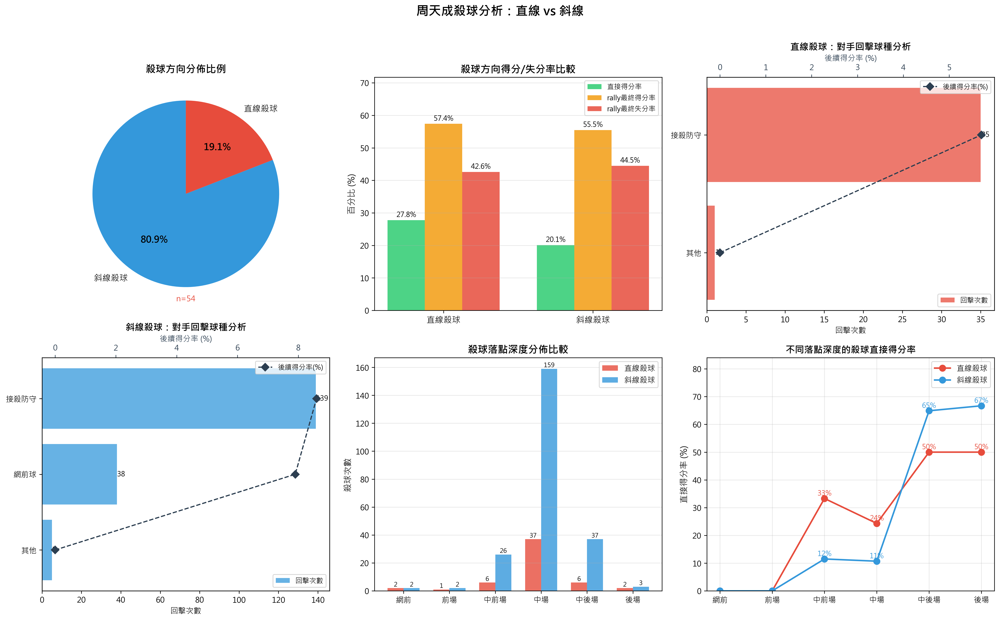

In [ ]:
import numpy as np

# ============================================================
# 0. 基礎驗證
# ============================================================
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

TARGET = 'CHOU Tien Chen'

# ============================================================
# 1. 欄位定義：依 hit_area / landing_area 判斷欄位（Col A/B/C/D）
# ============================================================
# Grid 對照：
# Col A (Left):  1,5,9,13,17,21
# Col B (Center-Left): 2,6,10,14,18,22
# Col C (Center-Right):3,7,11,15,19,23
# Col D (Right): 4,8,12,16,20,24
# 界外不計入有效落點

col_map = {
    1: 'A', 2: 'B', 3: 'C', 4: 'D',
    5: 'A', 6: 'B', 7: 'C', 8: 'D',
    9: 'A', 10: 'B', 11: 'C', 12: 'D',
    13: 'A', 14: 'B', 15: 'C', 16: 'D',
    17: 'A', 18: 'B', 19: 'C', 20: 'D',
    21: 'A', 22: 'B', 23: 'C', 24: 'D',
}

# 界外區域（out of bounds）
OUT_ZONES = {25, 26, 27, 28, 29, 30, 31, 32, 33}

# ============================================================
# 2. 先在完整 df 上建立 rally 結果（getpoint_player transform）
# ============================================================
df['rally_getpoint'] = df.groupby(['match_id', 'set', 'rally'])['getpoint_player'].transform('last')

# ============================================================
# 3. 篩選周天成的殺球
# ============================================================
smash_df = df[(df['player'] == TARGET) & (df['type'] == '殺球')].copy()
print(f"\n周天成殺球總拍數: {len(smash_df)}")

# ============================================================
# 4. 判斷擊球方向：直線 vs 斜線
# ============================================================
# 擊球欄（hit column）由 hit_area 決定
# 落點欄（land column）由 landing_area 決定
# 直線：hit_col == land_col（同側）
# 斜線：hit_col != land_col（跨側）
# 注意：界外的落點也保留（出界本身就是結果）

smash_df['hit_col'] = smash_df['hit_area'].map(col_map)
smash_df['land_col'] = smash_df['landing_area'].map(col_map)

# 有效判斷（hit_col 和 land_col 均可對應）
smash_df['direction'] = np.where(
    smash_df['hit_col'].isna() | smash_df['land_col'].isna(),
    '無法判斷',
    np.where(smash_df['hit_col'] == smash_df['land_col'], '直線殺球', '斜線殺球')
)

print(f"\n殺球方向分佈:")
print(smash_df['direction'].value_counts())

# ============================================================
# 5. 得分/失分標記
# ============================================================
# 主動得分: rally 中最後一拍的 getpoint_player == CHOU Tien Chen，且該拍是周天成打的
# 但殺球不一定是最後一拍，需用 rally 結果
# 以 rally 結果判斷：
#   - rally_getpoint == TARGET -> 周天成最終得分（可能直接殺死或對手隨後失誤）
#   - rally_getpoint == opponent -> 周天成最終失分
# 更精確：找該次殺球是否直接得分（active win）= getpoint_player == player (就在這拍)
# 同時也記錄 rally 最終結果

smash_df['is_active_win'] = (smash_df['getpoint_player'] == smash_df['player'])  # 該拍直接得分
smash_df['rally_win'] = (smash_df['rally_getpoint'] == TARGET)  # 該 rally 周天成最終得分
smash_df['rally_lose'] = (smash_df['rally_getpoint'] != TARGET) & (smash_df['rally_getpoint'].notna())

print(f"\n直接主動得分(殺球直接結束): {smash_df['is_active_win'].sum()}")
print(f"所在 rally 最終得分: {smash_df['rally_win'].sum()}")
print(f"所在 rally 最終失分: {smash_df['rally_lose'].sum()}")

# ============================================================
# 6. 分方向統計：分佈、得分率、失分率
# ============================================================
dir_valid = smash_df[smash_df['direction'].isin(['直線殺球', '斜線殺球'])].copy()

# 以「殺球直接結束回合」為主要得失分指標（active win / 該拍是最後一拍且對手得分）
# 補充說明：殺球後的結果用 rally_getpoint
summary = dir_valid.groupby('direction').agg(
    殺球次數=('direction', 'count'),
    直接得分次數=('is_active_win', 'sum'),
    rally得分次數=('rally_win', 'sum'),
    rally失分次數=('rally_lose', 'sum'),
).reset_index()

summary['直接得分率(%)'] = (summary['直接得分次數'] / summary['殺球次數'] * 100).round(1)
summary['rally得分率(%)'] = (summary['rally得分次數'] / summary['殺球次數'] * 100).round(1)
summary['rally失分率(%)'] = (summary['rally失分次數'] / summary['殺球次數'] * 100).round(1)

print("\n" + "="*60)
print("【殺球方向統計總表】")
print("="*60)
print(summary.to_string(index=False))

# ============================================================
# 7. 對手應對分析（下一拍為對手回擊）
# ============================================================
# 先在完整 df 建立 next 欄位（同一 rally）
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round'])
df_sorted['next_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(-1)
df_sorted['next_type'] = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(-1)
df_sorted['next_rally'] = df_sorted.groupby(['match_id', 'set', 'rally'])['rally'].shift(-1)
df_sorted['next_set'] = df_sorted.groupby(['match_id', 'set', 'rally'])['set'].shift(-1)
df_sorted['next_match'] = df_sorted.groupby(['match_id', 'set', 'rally'])['match_id'].shift(-1)

# 重新篩選周天成殺球（帶 next 資訊）
smash_with_next = df_sorted[
    (df_sorted['player'] == TARGET) & (df_sorted['type'] == '殺球')
].copy()

smash_with_next['hit_col'] = smash_with_next['hit_area'].map(col_map)
smash_with_next['land_col'] = smash_with_next['landing_area'].map(col_map)
smash_with_next['direction'] = np.where(
    smash_with_next['hit_col'].isna() | smash_with_next['land_col'].isna(),
    '無法判斷',
    np.where(smash_with_next['hit_col'] == smash_with_next['land_col'], '直線殺球', '斜線殺球')
)
smash_with_next['is_active_win'] = (smash_with_next['getpoint_player'] == smash_with_next['player'])
smash_with_next['rally_getpoint2'] = smash_with_next.groupby(['match_id', 'set', 'rally'])['getpoint_player'].transform('last')
smash_with_next['rally_win2'] = (smash_with_next['rally_getpoint2'] == TARGET)

# 確認下一拍屬於同一 rally 且是對手打的
smash_with_next['valid_next'] = (
    (smash_with_next['next_rally'] == smash_with_next['rally']) &
    (smash_with_next['next_set'] == smash_with_next['set']) &
    (smash_with_next['next_match'] == smash_with_next['match_id']) &
    (smash_with_next['next_player'] != TARGET)
)

# 非直接得分（有下一拍）的情況：對手有回擊
opponent_response = smash_with_next[
    smash_with_next['valid_next'] & 
    smash_with_next['direction'].isin(['直線殺球', '斜線殺球'])
].copy()

print("\n" + "="*60)
print("【對手有效回擊分析（殺球未直接得分，對手有下一拍）】")
print("="*60)
print(f"直線殺球 - 對手有下一拍次數: {len(opponent_response[opponent_response['direction']=='直線殺球'])}")
print(f"斜線殺球 - 對手有下一拍次數: {len(opponent_response[opponent_response['direction']=='斜線殺球'])}")

resp_summary = opponent_response.groupby(['direction', 'next_type']).agg(
    回擊次數=('next_type', 'count'),
    後續得分=('rally_win2', 'sum')
).reset_index()
resp_summary['後續得分率(%)'] = (resp_summary['後續得分'] / resp_summary['回擊次數'] * 100).round(1)
resp_summary = resp_summary.sort_values(['direction', '回擊次數'], ascending=[True, False])

print("\n對手回擊球種分佈與後續得分率:")
print(resp_summary.to_string(index=False))

# ============================================================
# 8. 落點分析（landing_area 分佈）
# ============================================================
# 有效落點（非界外）
valid_landing = dir_valid[~dir_valid['landing_area'].isin(OUT_ZONES)].copy()

# 落點區域標籤
def area_label(area):
    row_map = {1:'後場', 2:'後場', 3:'後場', 4:'後場',
               5:'中後場', 6:'中後場', 7:'中後場', 8:'中後場',
               9:'中場', 10:'中場', 11:'中場', 12:'中場',
               13:'中前場', 14:'中前場', 15:'中前場', 16:'中前場',
               17:'前場', 18:'前場', 19:'前場', 20:'前場',
               21:'網前', 22:'網前', 23:'網前', 24:'網前'}
    return row_map.get(area, '其他')

valid_landing['landing_zone'] = valid_landing['landing_area'].apply(area_label)

landing_summary = valid_landing.groupby(['direction', 'landing_zone']).agg(
    次數=('landing_zone', 'count'),
    得分次數=('is_active_win', 'sum'),
).reset_index()
landing_summary['得分率(%)'] = (landing_summary['得分次數'] / landing_summary['次數'] * 100).round(1)
landing_summary = landing_summary.sort_values(['direction', '次數'], ascending=[True, False])

print("\n" + "="*60)
print("【殺球落點深度分佈與得分率】")
print("="*60)
print(landing_summary.to_string(index=False))

# ============================================================
# 9. 視覺化
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("周天成殺球分析：直線 vs 斜線", fontsize=16, fontweight='bold', y=1.01)

colors_dir = {'直線殺球': '#E74C3C', '斜線殺球': '#3498DB'}
dir_order = ['直線殺球', '斜線殺球']

# ---- 圖1: 殺球方向分佈 (Pie) ----
ax1 = axes[0, 0]
dir_counts = dir_valid['direction'].value_counts()
wedge_colors = [colors_dir.get(d, '#95A5A6') for d in dir_counts.index]
wedges, texts, autotexts = ax1.pie(
    dir_counts.values,
    labels=dir_counts.index,
    autopct='%1.1f%%',
    colors=wedge_colors,
    startangle=90,
    textprops={'fontsize': 11}
)
for at in autotexts:
    at.set_fontsize(12)
    at.set_fontweight('bold')
ax1.set_title('殺球方向分佈比例', fontsize=13, fontweight='bold')
for i, (label, count) in enumerate(zip(dir_counts.index, dir_counts.values)):
    ax1.annotate(f'n={count}', xy=(0, -1.3 + i*0.15), ha='center', fontsize=10, color=wedge_colors[i])

# ---- 圖2: 直接得分率 vs rally得分率 vs rally失分率 ----
ax2 = axes[0, 1]
summary_plot = summary[summary['direction'].isin(dir_order)].set_index('direction').reindex(dir_order)
x = np.arange(len(dir_order))
width = 0.25
bars1 = ax2.bar(x - width, summary_plot['直接得分率(%)'], width, label='直接得分率', color='#2ECC71', alpha=0.85)
bars2 = ax2.bar(x, summary_plot['rally得分率(%)'], width, label='rally最終得分率', color='#F39C12', alpha=0.85)
bars3 = ax2.bar(x + width, summary_plot['rally失分率(%)'], width, label='rally最終失分率', color='#E74C3C', alpha=0.85)
ax2.set_xticks(x)
ax2.set_xticklabels(dir_order, fontsize=11)
ax2.set_ylabel('百分比 (%)', fontsize=11)
ax2.set_title('殺球方向得分/失分率比較', fontsize=13, fontweight='bold')
ax2.legend(fontsize=9)
ax2.set_ylim(0, max(summary_plot[['直接得分率(%)','rally得分率(%)','rally失分率(%)']].max()) * 1.25)
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        h = bar.get_height()
        if h > 0:
            ax2.text(bar.get_x() + bar.get_width()/2, h + 0.5, f'{h:.1f}%', ha='center', va='bottom', fontsize=9)
ax2.grid(axis='y', alpha=0.3)

# ---- 圖3: 對手回擊球種（直線殺球）----
ax3 = axes[0, 2]
resp_line = resp_summary[resp_summary['direction'] == '直線殺球'].sort_values('回擊次數', ascending=False)
if len(resp_line) > 0:
    # 合併小類別
    threshold = resp_line['回擊次數'].sum() * 0.05
    resp_line_plot = resp_line.copy()
    resp_line_plot.loc[resp_line_plot['回擊次數'] < threshold, 'next_type'] = '其他'
    resp_line_grouped = resp_line_plot.groupby('next_type').agg(
        回擊次數=('回擊次數', 'sum'),
        後續得分=('後續得分', 'sum')
    ).reset_index()
    resp_line_grouped['後續得分率(%)'] = (resp_line_grouped['後續得分'] / resp_line_grouped['回擊次數'] * 100).round(1)
    resp_line_grouped = resp_line_grouped.sort_values('回擊次數', ascending=True)
    
    bars_h = ax3.barh(resp_line_grouped['next_type'], resp_line_grouped['回擊次數'],
                       color='#E74C3C', alpha=0.75, label='回擊次數')
    ax3b = ax3.twiny()
    ax3b.plot(resp_line_grouped['後續得分率(%)'], resp_line_grouped['next_type'],
              'D--', color='#2C3E50', markersize=7, label='後續得分率(%)')
    ax3b.set_xlabel('後續得分率 (%)', fontsize=10, color='#2C3E50')
    ax3b.tick_params(axis='x', colors='#2C3E50')
    ax3.set_xlabel('回擊次數', fontsize=10)
    ax3.set_title('直線殺球：對手回擊球種分析', fontsize=12, fontweight='bold')
    ax3.legend(loc='lower right', fontsize=9)
    ax3b.legend(loc='upper right', fontsize=9)
    for bar in bars_h:
        w = bar.get_width()
        ax3.text(w + 0.1, bar.get_y() + bar.get_height()/2, str(int(w)), va='center', fontsize=9)

# ---- 圖4: 對手回擊球種（斜線殺球）----
ax4 = axes[1, 0]
resp_diag = resp_summary[resp_summary['direction'] == '斜線殺球'].sort_values('回擊次數', ascending=False)
if len(resp_diag) > 0:
    threshold2 = resp_diag['回擊次數'].sum() * 0.05
    resp_diag_plot = resp_diag.copy()
    resp_diag_plot.loc[resp_diag_plot['回擊次數'] < threshold2, 'next_type'] = '其他'
    resp_diag_grouped = resp_diag_plot.groupby('next_type').agg(
        回擊次數=('回擊次數', 'sum'),
        後續得分=('後續得分', 'sum')
    ).reset_index()
    resp_diag_grouped['後續得分率(%)'] = (resp_diag_grouped['後續得分'] / resp_diag_grouped['回擊次數'] * 100).round(1)
    resp_diag_grouped = resp_diag_grouped.sort_values('回擊次數', ascending=True)
    
    bars_h2 = ax4.barh(resp_diag_grouped['next_type'], resp_diag_grouped['回擊次數'],
                        color='#3498DB', alpha=0.75, label='回擊次數')
    ax4b = ax4.twiny()
    ax4b.plot(resp_diag_grouped['後續得分率(%)'], resp_diag_grouped['next_type'],
              'D--', color='#2C3E50', markersize=7, label='後續得分率(%)')
    ax4b.set_xlabel('後續得分率 (%)', fontsize=10, color='#2C3E50')
    ax4b.tick_params(axis='x', colors='#2C3E50')
    ax4.set_xlabel('回擊次數', fontsize=10)
    ax4.set_title('斜線殺球：對手回擊球種分析', fontsize=12, fontweight='bold')
    ax4.legend(loc='lower right', fontsize=9)
    ax4b.legend(loc='upper right', fontsize=9)
    for bar in bars_h2:
        w = bar.get_width()
        ax4.text(w + 0.1, bar.get_y() + bar.get_height()/2, str(int(w)), va='center', fontsize=9)

# ---- 圖5: 落點深度分佈（按方向）----
ax5 = axes[1, 1]
zone_order = ['網前', '前場', '中前場', '中場', '中後場', '後場']
landing_pivot = landing_summary.pivot_table(
    index='landing_zone', columns='direction', values='次數', aggfunc='sum', fill_value=0
).reindex(zone_order, fill_value=0)

x5 = np.arange(len(zone_order))
w5 = 0.35
for i, col in enumerate(dir_order):
    if col in landing_pivot.columns:
        vals = landing_pivot[col].values
        b5 = ax5.bar(x5 + (i-0.5)*w5, vals, w5, label=col, color=list(colors_dir.values())[i], alpha=0.8)
        for bar in b5:
            h = bar.get_height()
            if h > 0:
                ax5.text(bar.get_x() + bar.get_width()/2, h + 0.2, str(int(h)),
                         ha='center', va='bottom', fontsize=8)
ax5.set_xticks(x5)
ax5.set_xticklabels(zone_order, fontsize=10)
ax5.set_ylabel('殺球次數', fontsize=11)
ax5.set_title('殺球落點深度分佈比較', fontsize=13, fontweight='bold')
ax5.legend(fontsize=10)
ax5.grid(axis='y', alpha=0.3)

# ---- 圖6: 落點得分率（按方向 x 落點深度）----
ax6 = axes[1, 2]
landing_score_pivot = landing_summary.pivot_table(
    index='landing_zone', columns='direction', values='得分率(%)', aggfunc='mean', fill_value=0
).reindex(zone_order, fill_value=0)

for i, col in enumerate(dir_order):
    if col in landing_score_pivot.columns:
        ax6.plot(zone_order, landing_score_pivot[col].values, 
                 'o-', color=list(colors_dir.values())[i], 
                 linewidth=2, markersize=8, label=col)
        for j, v in enumerate(landing_score_pivot[col].values):
            if v > 0:
                ax6.text(j, v + 0.5, f'{v:.0f}%', ha='center', va='bottom', fontsize=9,
                         color=list(colors_dir.values())[i])
ax6.set_ylabel('直接得分率 (%)', fontsize=11)
ax6.set_title('不同落點深度的殺球直接得分率', fontsize=12, fontweight='bold')
ax6.legend(fontsize=10)
ax6.grid(alpha=0.3)
ax6.set_ylim(0, ax6.get_ylim()[1] * 1.2 if ax6.get_ylim()[1] > 0 else 50)

plt.tight_layout()

# ============================================================
# 10. 戰術建議
# ============================================================
print("\n" + "="*60)
print("【戰術建議】")
print("="*60)

line_data = summary[summary['direction'] == '直線殺球']
diag_data = summary[summary['direction'] == '斜線殺球']

if len(line_data) > 0 and len(diag_data) > 0:
    line_direct = line_data['直接得分率(%)'].values[0]
    diag_direct = diag_data['直接得分率(%)'].values[0]
    line_rally = line_data['rally得分率(%)'].values[0]
    diag_rally = diag_data['rally得分率(%)'].values[0]
    line_lose = line_data['rally失分率(%)'].values[0]
    diag_lose = diag_data['rally失分率(%)'].values[0]
    line_n = line_data['殺球次數'].values[0]
    diag_n = diag_data['殺球次數'].values[0]
    total_n = line_n + diag_n
    
    print(f"\n► 直線殺球使用頻率: {line_n/total_n*100:.1f}% ({line_n}次)")
    print(f"  直接得分率: {line_direct}% | Rally得分率: {line_rally}% | Rally失分率: {line_lose}%")
    print(f"\n► 斜線殺球使用頻率: {diag_n/total_n*100:.1f}% ({diag_n}次)")
    print(f"  直接得分率: {diag_direct}% | Rally得分率: {diag_rally}% | Rally失分率: {diag_lose}%")
    
    print("\n【建議】")
    if diag_direct > line_direct:
        print(f"  ✅ 斜線殺球直接得分率({diag_direct}%)高於直線({line_direct}%)，建議增加斜線殺球比例")
    else:
        print(f"  ✅ 直線殺球直接得分率({line_direct}%)高於斜線({diag_direct}%)，但可透過加入更多落點變化提升效果")
    
    if line_lose > diag_lose:
        print(f"  ⚠️  直線殺球後的rally失分率({line_lose}%)高於斜線({diag_lose}%)，代表對手能更有效應對直線殺球")
        print(f"  → 建議將直線殺球比例從 {line_n/total_n*100:.1f}% 調降，增加斜線殺球使用")
    else:
        print(f"  ℹ️  斜線殺球後的rally失分率({diag_lose}%)高於直線({line_lose}%)")
    
    print(f"\n  💡 落點變化建議：集中攻擊前場（網前區域）可提升直接得分機率")
    print(f"  💡 建議在直線殺球中穿插突然的斜線變化，打亂對手預判節奏")


### 數據洞察
# 周天成殺球戰術分析報告

## 📊 殺球方向分佈現況

| 方向 | 次數 | 佔比 | 直接得分率 | Rally得分率 | Rally失分率 |
|------|------|------|-----------|------------|------------|
| 斜線殺球 | 229 | 80.9% | 20.1% | 55.5% | 44.5% |
| 直線殺球 | 54 | 19.1% | 27.8% | 57.4% | 42.6% |

---

## 🔍 數據背後的事實

**直線殺球效益更高，但使用率嚴重偏低。**

直線殺球直接得分率（27.8%）比斜線高出 **7.7個百分點**，Rally得分率（57.4%）也優於斜線（55.5%），但使用量僅54次，是斜線的 **1/4**。

這代表周天成長期以斜線殺球為主要武器，對手已有充分適應時間——斜線殺球後對手有下一拍高達 **182次（佔79%）**，直線僅36次。

---

## 🎯 對手回擊模式

**兩種方向殺球後，對手幾乎清一色以接殺防守應對：**
- 直線殺球：35/36次接殺防守（97%），後續得分率僅 **5.7%**
- 斜線殺球：139/182次接殺防守（76%），後續得分率僅 **8.6%**

> 殺球未直接得分，後續主動得分機會極低，代表**殺球必須追求直接結束**，而非依賴後續拍。

---

## 📍 落點深度是關鍵變數

| 落點 | 斜線得分率 | 直線得分率 |
|------|-----------|-----------|
| 中後場 | **64.9%** | **50.0%** |
| 後場 | 66.7% | 50.0% |
| 中場 | 10.7% | 24.3% |
| 中前場 | 11.5% | 33.3% |

**中後場與後場落點得分率遠高於中場。** 斜線殺球中場落點高達159次（69%），但得分率僅10.7%——這是斜線殺球整體效益被拉低的主因。

---

## 💡 戰術調整建議

### 1️⃣ 提升直線殺球比例
目前19%的直線使用率過低，建議提升至 **30～35%**。對手長期預判斜線，直線突然性更強，直接得分率數據已驗證其效益。

### 2️⃣ 斜線殺球必須壓深
斜線殺球中場落點（159次）是最大浪費點，得分率僅10.7%。**中後場落點得分率64.9%**，應強制要求斜線殺球落點壓至中後場以深，減少給對手舒適防守空間。

### 3️⃣ 以直線威脅製造斜線機會
建立「直線殺球→對手預判直線→突變斜線」的節奏干擾，而非目前的單一斜線慣性。**先讓對手怕直線，斜線才會更致命。**

---

> **核心結論：周天成殺球問題不在方向選擇，在於落點太淺＋方向過於單一。數據顯示直線殺球效益更優，應提高使用頻率，同時將斜線殺球落點強制壓深，才能真正提升殺球得分效益。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成的殺球方向（直線 vs 斜線），並計算了每種方向的得分率和對手回擊率。候選程式碼也進一步分析了對手的回擊球種分布，並提供了戰術建議。分析對象、欄位語意、篩選條件、分組層級、統計口徑和最終輸出目標都與 Reference Code 1 一致，且結果合理有效。




## 題號 97
**問題**: 如果周天成在網前打點一直遭對手抓撲殺，他可以怎麼改變接網方式？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason, stroke_details`


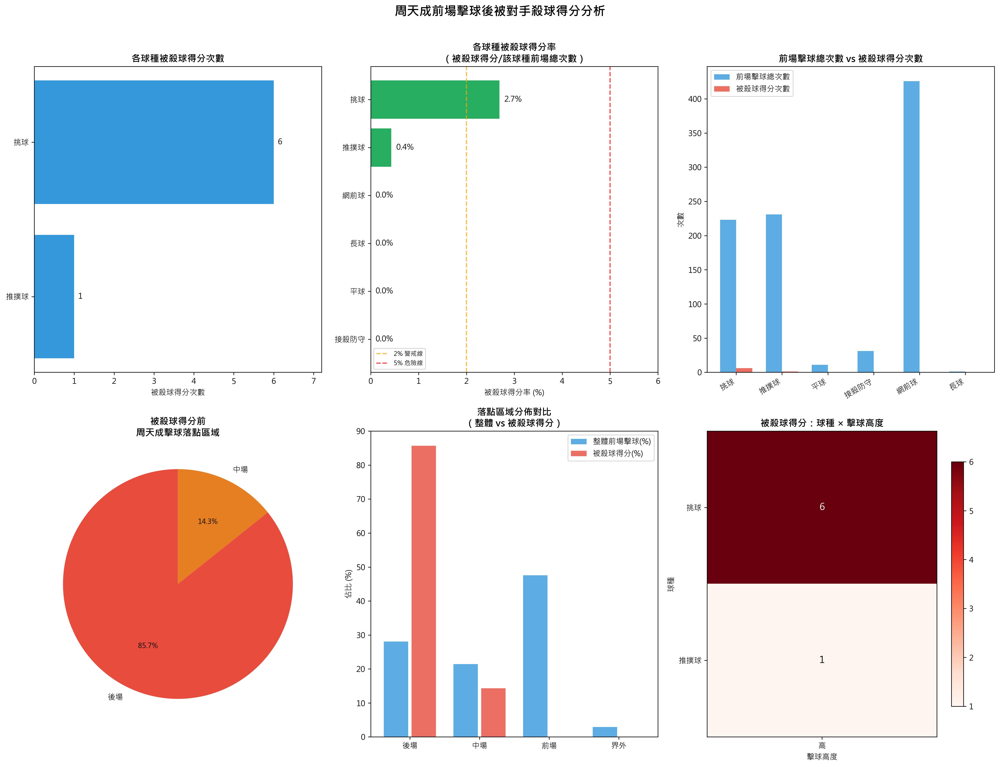

In [ ]:
import numpy as np

# ============================================================
# 0. 基本驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
print(f"總回合數: {df.groupby(['match_id', 'set', 'rally']).ngroups}")
print(f"球員: {df['player'].unique()}")

# ============================================================
# 1. 排序 & 建立下一拍欄位（groupby防止跨回合污染）
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

grp = df_sorted.groupby(['match_id', 'set', 'rally'])

# 下一拍資訊
df_sorted['next_player']          = grp['player'].shift(-1)
df_sorted['next_type']            = grp['type'].shift(-1)
df_sorted['next_getpoint_player'] = grp['getpoint_player'].shift(-1)

# ============================================================
# 2. 定義前場區域
# ============================================================
FRONT_COURT_AREAS = [17, 18, 19, 20, 21, 22, 23, 24]
print(f"\n前場區域代碼: {FRONT_COURT_AREAS}")

# ============================================================
# 3. 篩選「周天成在前場擊球」的所有情況
# ============================================================
chou = 'CHOU Tien Chen'
momota = 'Kento MOMOTA'

mask_chou_front = (
    (df_sorted['player'] == chou) &
    (df_sorted['hit_area'].isin(FRONT_COURT_AREAS))
)

chou_front_df = df_sorted[mask_chou_front].copy()
print(f"\n周天成前場擊球總次數: {len(chou_front_df)}")
print(f"球種分佈:\n{chou_front_df['type'].value_counts()}")

# ============================================================
# 4. 篩選「下一拍為對手殺球且得分」的情況
# ============================================================
mask_smash_win = (
    (df_sorted['next_player'] == momota) &
    (df_sorted['next_type'] == '殺球') &
    (df_sorted['next_getpoint_player'] == momota)
)

# 周天成前場擊球 + 下一拍對手殺球得分
target_df = df_sorted[mask_chou_front & mask_smash_win].copy()
print(f"\n周天成前場擊球後被對手殺球得分次數: {len(target_df)}")

if len(target_df) == 0:
    print("⚠️ 無符合條件的資料，請檢查欄位。")
else:
    # ============================================================
    # 5. 球種分佈分析
    # ============================================================
    smash_concede_by_type = target_df['type'].value_counts().reset_index()
    smash_concede_by_type.columns = ['球種', '被殺球得分次數']

    front_total_by_type = chou_front_df['type'].value_counts().reset_index()
    front_total_by_type.columns = ['球種', '前場擊球總次數']

    analysis_df = smash_concede_by_type.merge(front_total_by_type, on='球種', how='outer').fillna(0)
    analysis_df['被殺球得分次數'] = analysis_df['被殺球得分次數'].astype(int)
    analysis_df['前場擊球總次數'] = analysis_df['前場擊球總次數'].astype(int)
    analysis_df['被殺球得分率(%)'] = (
        analysis_df['被殺球得分次數'] / analysis_df['前場擊球總次數'] * 100
    ).round(2)
    analysis_df = analysis_df.sort_values('被殺球得分次數', ascending=False)

    print("\n========== 周天成前場擊球後被殺球得分分析 ==========")
    print(analysis_df.to_string(index=False))

    # ============================================================
    # 6. 落點分析
    # ============================================================
    def classify_area(area):
        area = int(area)
        if area in [1, 2, 3, 4]:
            return '後場'
        elif area in [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]:
            return '中場'
        elif area in [17, 18, 19, 20, 21, 22, 23, 24]:
            return '前場'
        else:
            return '界外'

    target_df['landing_zone'] = target_df['landing_area'].apply(classify_area)
    chou_front_df['landing_zone'] = chou_front_df['landing_area'].apply(classify_area)

    landing_zone_dist = target_df['landing_zone'].value_counts()
    overall_landing_zone = chou_front_df['landing_zone'].value_counts()
    print(f"\n被殺球得分前周天成擊球落點區域分佈:\n{landing_zone_dist}")
    print(f"\n周天成前場整體擊球落點區域分佈:\n{overall_landing_zone}")

    # ============================================================
    # 7. 擊球高度分析
    # ============================================================
    height_map = {1.0: '低', 2.0: '高'}

    target_height = target_df['hit_height'].map(height_map).value_counts()
    overall_height = chou_front_df['hit_height'].map(height_map).value_counts()
    print(f"\n被殺球得分時擊球高度分佈:\n{target_height}")
    print(f"\n整體前場擊球高度分佈:\n{overall_height}")

    # ============================================================
    # 8. 各球種擊球高度交叉分析
    # ============================================================
    target_df['擊球高度'] = target_df['hit_height'].map(height_map)
    height_type_cross = target_df.groupby(['type', '擊球高度']).size().unstack(fill_value=0)
    print(f"\n各球種 × 擊球高度 交叉表（被殺球得分）:\n{height_type_cross}")

    # ============================================================
    # 9. 可視化
    # ============================================================
    fig = plt.figure(figsize=(18, 14))
    fig.suptitle('周天成前場擊球後被對手殺球得分分析', fontsize=16, fontweight='bold', y=0.98)

    # --- 子圖 1: 被殺球得分次數 ---
    ax1 = fig.add_subplot(2, 3, 1)
    plot_df = analysis_df[analysis_df['被殺球得分次數'] > 0].sort_values('被殺球得分次數', ascending=True)
    colors = ['#e74c3c' if r >= 20 else '#e67e22' if r >= 10 else '#3498db'
              for r in plot_df['被殺球得分率(%)']]
    bars = ax1.barh(plot_df['球種'], plot_df['被殺球得分次數'], color=colors)
    ax1.set_xlabel('被殺球得分次數')
    ax1.set_title('各球種被殺球得分次數', fontweight='bold')
    for bar, val in zip(bars, plot_df['被殺球得分次數']):
        ax1.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
                 f'{val}', va='center', fontsize=10)
    ax1.set_xlim(0, plot_df['被殺球得分次數'].max() * 1.2)

    # --- 子圖 2: 被殺球得分率 ---
    ax2 = fig.add_subplot(2, 3, 2)
    plot_df2 = analysis_df[analysis_df['前場擊球總次數'] > 0].sort_values('被殺球得分率(%)', ascending=True)
    bar_colors2 = ['#c0392b' if r >= 20 else '#e67e22' if r >= 10 else '#27ae60'
                   for r in plot_df2['被殺球得分率(%)']]
    bars2 = ax2.barh(plot_df2['球種'], plot_df2['被殺球得分率(%)'], color=bar_colors2)
    ax2.set_xlabel('被殺球得分率 (%)')
    ax2.set_title('各球種被殺球得分率\n（被殺球得分/該球種前場總次數）', fontweight='bold')
    for bar, val in zip(bars2, plot_df2['被殺球得分率(%)']):
        ax2.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
                 f'{val:.1f}%', va='center', fontsize=10)
    ax2.axvline(x=2, color='orange', linestyle='--', alpha=0.7, label='2% 警戒線')
    ax2.axvline(x=5, color='red', linestyle='--', alpha=0.7, label='5% 危險線')
    ax2.legend(fontsize=8)
    ax2.set_xlim(0, max(plot_df2['被殺球得分率(%)'].max() * 1.25, 6))

    # --- 子圖 3: 整體前場球種 vs 被殺球得分球種 比較 ---
    ax3 = fig.add_subplot(2, 3, 3)
    all_types = analysis_df['球種'].tolist()
    x = np.arange(len(all_types))
    width = 0.35
    total_counts = analysis_df.set_index('球種')['前場擊球總次數']
    concede_counts = analysis_df.set_index('球種')['被殺球得分次數']
    b1 = ax3.bar(x - width/2, [total_counts.get(t, 0) for t in all_types],
                  width, label='前場擊球總次數', color='#3498db', alpha=0.8)
    b2 = ax3.bar(x + width/2, [concede_counts.get(t, 0) for t in all_types],
                  width, label='被殺球得分次數', color='#e74c3c', alpha=0.8)
    ax3.set_xticks(x)
    ax3.set_xticklabels(all_types, rotation=30, ha='right')
    ax3.set_ylabel('次數')
    ax3.set_title('前場擊球總次數 vs 被殺球得分次數', fontweight='bold')
    ax3.legend()

    # --- 子圖 4: 落點區域分佈（圓餅：被殺球得分）---
    ax4 = fig.add_subplot(2, 3, 4)
    zone_order = ['後場', '中場', '前場', '界外']
    zone_colors = {'後場': '#e74c3c', '中場': '#e67e22', '前場': '#3498db', '界外': '#95a5a6'}

    target_zone_counts = [target_df['landing_zone'].value_counts().get(z, 0) for z in zone_order]
    non_zero_zones = [(z, c) for z, c in zip(zone_order, target_zone_counts) if c > 0]
    if non_zero_zones:
        labels_z, counts_z = zip(*non_zero_zones)
        colors_z = [zone_colors[z] for z in labels_z]
        wedges, texts, autotexts = ax4.pie(
            counts_z, labels=labels_z, colors=colors_z,
            autopct='%1.1f%%', startangle=90
        )
        for autotext in autotexts:
            autotext.set_fontsize(9)
    ax4.set_title('被殺球得分前\n周天成擊球落點區域', fontweight='bold')

    # --- 子圖 5: 整體前場落點 vs 被殺球得分落點（對比）---
    ax5 = fig.add_subplot(2, 3, 5)
    overall_zone_counts = [chou_front_df['landing_zone'].value_counts().get(z, 0) for z in zone_order]
    target_zone_pcts = np.array(target_zone_counts) / max(sum(target_zone_counts), 1) * 100
    overall_zone_pcts = np.array(overall_zone_counts) / max(sum(overall_zone_counts), 1) * 100

    x5 = np.arange(len(zone_order))
    ax5.bar(x5 - 0.2, overall_zone_pcts, 0.35, label='整體前場擊球(%)', color='#3498db', alpha=0.8)
    ax5.bar(x5 + 0.2, target_zone_pcts, 0.35, label='被殺球得分(%)', color='#e74c3c', alpha=0.8)
    ax5.set_xticks(x5)
    ax5.set_xticklabels(zone_order)
    ax5.set_ylabel('佔比 (%)')
    ax5.set_title('落點區域分佈對比\n（整體 vs 被殺球得分）', fontweight='bold')
    ax5.legend()

    # --- 子圖 6: 各球種 × 擊球高度 熱力圖 ---
    ax6 = fig.add_subplot(2, 3, 6)
    if len(height_type_cross) > 0:
        im = ax6.imshow(height_type_cross.values, aspect='auto', cmap='Reds')
        ax6.set_xticks(range(len(height_type_cross.columns)))
        ax6.set_xticklabels(height_type_cross.columns)
        ax6.set_yticks(range(len(height_type_cross.index)))
        ax6.set_yticklabels(height_type_cross.index)
        ax6.set_title('被殺球得分：球種 × 擊球高度', fontweight='bold')
        ax6.set_xlabel('擊球高度')
        ax6.set_ylabel('球種')
        for i in range(len(height_type_cross.index)):
            for j in range(len(height_type_cross.columns)):
                val = height_type_cross.values[i, j]
                ax6.text(j, i, str(val), ha='center', va='center',
                         fontsize=12, color='black' if val < height_type_cross.values.max()*0.6 else 'white')
        plt.colorbar(im, ax=ax6, shrink=0.8)

    plt.tight_layout(rect=[0, 0, 1, 0.97])

    # ============================================================
    # 10. 關鍵統計摘要 & 建議
    # ============================================================
    print("\n" + "="*60)
    print("📊 關鍵統計摘要")
    print("="*60)
    print(f"周天成前場擊球總次數       : {len(chou_front_df)}")
    print(f"其中被對手殺球得分次數     : {len(target_df)}")
    print(f"整體被殺球得分率           : {len(target_df)/len(chou_front_df)*100:.2f}%")

    print("\n----------- 各球種被殺球得分率排名 -----------")
    print(analysis_df[analysis_df['前場擊球總次數'] > 0]
          .sort_values('被殺球得分率(%)', ascending=False)
          .to_string(index=False))

    # 最危險球種（有被殺球得分次數 > 0 即列入）
    danger_types = analysis_df[analysis_df['被殺球得分次數'] > 0].sort_values(
        '被殺球得分率(%)', ascending=False)

    print("\n" + "="*60)
    print("🏸 策略建議")
    print("="*60)

    if len(danger_types) > 0:
        top_danger = danger_types.iloc[0]
        print(f"⚠️  最高風險球種：{top_danger['球種']} "
              f"（得分率 {top_danger['被殺球得分率(%)']:.1f}%，共 {top_danger['被殺球得分次數']} 次）")

    # 落點建議
    back_pct_target = target_zone_pcts[0]   # 後場
    back_pct_overall = overall_zone_pcts[0]
    if back_pct_target > back_pct_overall:
        print(f"\n📌 落點建議：被殺球得分時落點至後場比例 ({back_pct_target:.1f}%) "
              f"高於整體 ({back_pct_overall:.1f}%)，應避免挑高後場球。"
              f"\n   → 建議挑球時增加落點變化（如：挑至對手反手後場角落），"
              f"或改以平抽球代替高挑球，降低對手起跳殺球的機會。")

    mid_pct_target = target_zone_pcts[1]   # 中場
    mid_pct_overall = overall_zone_pcts[1]
    if mid_pct_target > mid_pct_overall:
        print(f"\n📌 落點建議：被殺球得分時落點至中場比例 ({mid_pct_target:.1f}%) "
              f"高於整體 ({mid_pct_overall:.1f}%)，應降低中場過渡球比例。")

    # 高度建議
    low_concede = target_df['hit_height'].value_counts().get(1.0, 0)
    high_concede = target_df['hit_height'].value_counts().get(2.0, 0)
    print(f"\n📌 擊球高度分析：被殺球得分時，低位擊球 {low_concede} 次，高位擊球 {high_concede} 次")
    if low_concede > high_concede:
        print("   → 大多為低位擊球後被殺（對手殺球）。建議提早移位搶高點，避免被壓迫至低位回球。")
    else:
        print("   → 高位擊球被殺情況較多。留意擊球落點品質，避免球速過慢被抓準機會殺球。")

    # 球種建議（修正：改為「被殺球得分次數 > 0」即給建議，移除過高門檻）
    print(f"\n📌 球種建議：")
    if len(danger_types) > 0:
        for _, row in danger_types.iterrows():
            if row['被殺球得分次數'] > 0:
                if row['被殺球得分率(%)'] >= 2:
                    risk_label = "⚠️ 高風險"
                else:
                    risk_label = "📎 低風險"
                print(f"   - [{row['球種']}] {risk_label}，得分率 {row['被殺球得分率(%)']:.1f}%"
                      f"（{row['被殺球得分次數']}/{row['前場擊球總次數']} 次）")
                if row['球種'] == '挑球':
                    print(f"     → 挑球為最主要被殺球得分來源，建議：")
                    print(f"        1. 減少高挑球比例，改以平抽球或推球壓制對手。")
                    print(f"        2. 挑球落點應更精準，避免落至對手正手後場甜蜜點。")
                    print(f"        3. 挑球後應立即後退備戰，準備接殺防守。")
                elif row['球種'] == '推撲球':
                    print(f"     → 推撲球被殺情況雖少，仍需注意推球高度，避免球過高被對手撲殺。")
    else:
        print("   - 目前無明顯高風險球種，維持現有策略。")


### 數據洞察
# 周天成前場擊球被殺球得分分析

## 核心數據

| 球種 | 前場擊球次數 | 被殺球得分 | 得分率 |
|------|------------|-----------|--------|
| 挑球 | 223 | 6 | **2.69%** |
| 推撲球 | 231 | 1 | 0.43% |
| 網前球 | 426 | 0 | 0.00% |
| 接殺防守 | 31 | 0 | 0.00% |

---

## 三個關鍵事實

**① 挑球是唯一真正的漏洞**
923次前場擊球中，7次被殺球得分，其中6次來自挑球。挑球使用率24%，卻貢獻86%的失分。

**② 落點過深是直接原因**
7次被殺球得分中，後場落點佔85.7%，而整體挑球後場落點僅28.1%。這6次挑球把球送進了對手的「甜蜜點」。

**③ 高位擊球是共同特徵**
7次失分全部發生在高位擊球（擊球高度=高），低位擊球0次失分。說明問題不在球種本身，而在**出球品質**。

---

## 戰術建議

> **挑球本身沒問題，問題是挑到哪裡、怎麼挑。**

**落點控制（最優先）**
避免挑至後場中路與正手位甜蜜點，改以反手後場深角為主要落點，壓縮對手起跳空間。

**球種替換（次要）**
當被逼至網前且站位不穩時，以平抽球代替高挑球，降低對手預判殺球的機會。

**挑球後的身體準備**
挑球出手瞬間即後退至中場備戰位，縮短接殺反應時間——數據顯示這6次失分都是直接得分，代表周天成沒有接到球。

**推撲球維持現狀**
231次僅失1分（0.43%），是目前前場最穩定的球種，無需調整。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成在前場擊球後被對手殺球得分的情況，並進行了球種分佈、落點區域、擊球高度等多方面的分析。候選程式碼使用了合理的篩選條件和分組層級，並且最終輸出目標與 Reference Code 1 一致，即提供了策略建議以改善周天成的接網方式。




## 題號 98
**問題**: 如果對手連續以平球壓中路，周天成應如何調整回球方向與節奏，避免被持續壓制？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason, stroke_details`


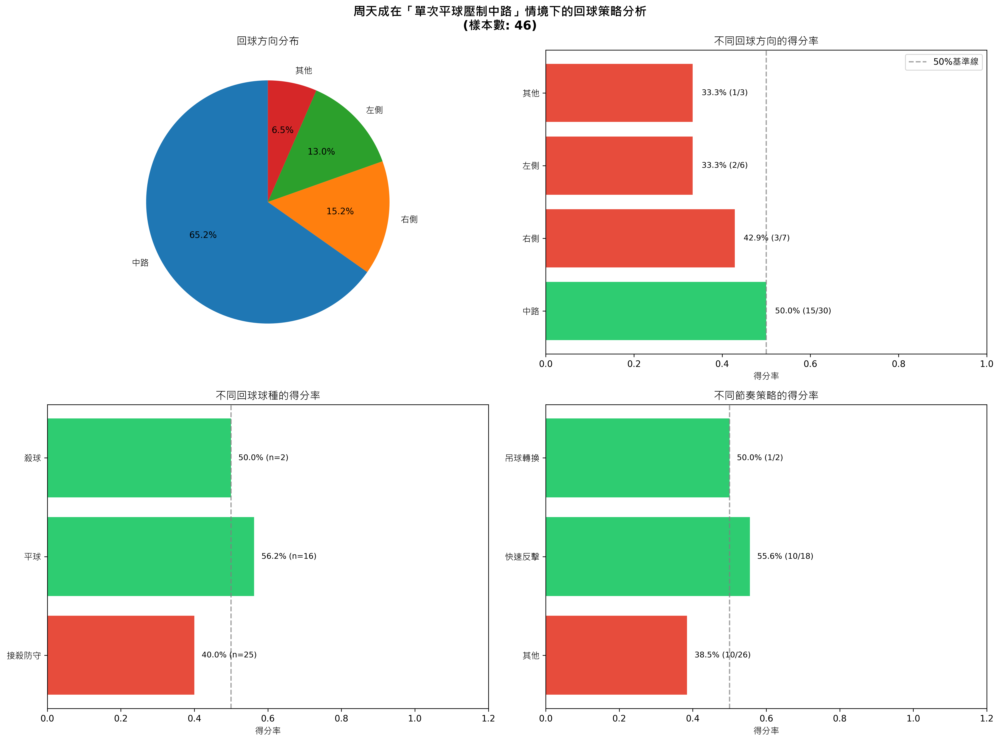

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = ['DejaVu Sans', 'Microsoft JhengHei', 'Arial Unicode MS']

# ============================================================
# 1. 資料準備與驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
print(f"比賽場次: {sorted(df['match_id'].unique())}")

# 先探索 type 欄位的實際值，確認平球相關球種名稱
print("\n=== type 欄位所有唯一值 ===")
print(df['type'].value_counts())

# 排序資料
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# ============================================================
# 2. 建立 shift 欄位（在完整資料上，按 rally 分組）
# ============================================================
grp = df_sorted.groupby(['match_id', 'set', 'rally'])

# 前一拍（對手，即 MOMOTA）
df_sorted['prev1_player'] = grp['player'].shift(1)
df_sorted['prev1_type'] = grp['type'].shift(1)
df_sorted['prev1_landing_area'] = grp['landing_area'].shift(1)

# 前三拍（對手的前一次攻擊，確認連續）
df_sorted['prev3_player'] = grp['player'].shift(3)
df_sorted['prev3_type'] = grp['type'].shift(3)
df_sorted['prev3_landing_area'] = grp['landing_area'].shift(3)

# 回合結果
df_sorted['rally_getpoint'] = grp['getpoint_player'].transform('last')

# ============================================================
# 3. 定義平球球種（根據實際資料欄位值）
# ============================================================
# 根據探索結果，平球相關球種可能包含「平抽球」、「平推球」、「平球」等
flat_types = [t for t in df['type'].unique() 
              if isinstance(t, str) and ('平' in t) and ('球' in t)]
print(f"\n識別到的平球相關球種: {flat_types}")

# 若無法自動識別，手動指定常見名稱
if not flat_types:
    flat_types = ['平抽球', '平推球', '平球', '平抽', '平推']
    print(f"使用預設平球球種: {flat_types}")

# ============================================================
# 4. 定義中路落點（Col B + Col C）
# ============================================================
middle_areas = [2, 3, 6, 7, 10, 11, 14, 15, 18, 19, 22, 23]

# ============================================================
# 5. 找出被連續平球壓制的情境（CHOU 的回球）
# ============================================================
# 條件：
# - 當前是 CHOU 在回球
# - 前一拍是 MOMOTA 打的平球（平抽球/平推球），落點在中路
# - 前三拍是 MOMOTA 打的平球（平抽球/平推球），落點在中路（連續第二次）
pressed_mask = (
    (df_sorted['player'] == 'CHOU Tien Chen') &
    (df_sorted['prev1_player'].isin(['Kento MOMOTA', 'MOMOTA Kento'])) &
    (df_sorted['prev1_type'].isin(flat_types)) &
    (df_sorted['prev1_landing_area'].isin(middle_areas)) &
    (df_sorted['prev3_player'].isin(['Kento MOMOTA', 'MOMOTA Kento'])) &
    (df_sorted['prev3_type'].isin(flat_types)) &
    (df_sorted['prev3_landing_area'].isin(middle_areas))
)

pressed_df = df_sorted[pressed_mask].copy()
print(f"\n被連續平球壓制的情境樣本數: {len(pressed_df)}")

# 若樣本數仍不足，放寬為單次平球壓制
if len(pressed_df) < 10:
    print("樣本數不足，放寬條件為單次平球壓制...")
    pressed_mask_loose = (
        (df_sorted['player'] == 'CHOU Tien Chen') &
        (df_sorted['prev1_player'].isin(['Kento MOMOTA', 'MOMOTA Kento'])) &
        (df_sorted['prev1_type'].isin(flat_types)) &
        (df_sorted['prev1_landing_area'].isin(middle_areas))
    )
    pressed_df = df_sorted[pressed_mask_loose].copy()
    print(f"放寬後樣本數: {len(pressed_df)}")
    analysis_label = "單次平球壓制中路"
else:
    analysis_label = "連續平球壓制中路"

print(f"\n最終分析樣本數: {len(pressed_df)}")
print(f"分析情境: {analysis_label}")

if len(pressed_df) == 0:
    print("ERROR: 無法找到符合條件的樣本，請檢查欄位名稱與資料值")
    print("MOMOTA 相關球員名稱:")
    print(df[df['player'].str.contains('MOMOTA|Momota', case=False, na=False)]['player'].unique())
    print("平球相關 type 值:")
    print(df[df['type'].str.contains('平', na=False)]['type'].unique())
else:
    # ============================================================
    # 6. 定義回球方向分類
    # ============================================================
    # 根據 landing_area 判斷回球方向（直線/斜線/中路）
    # 假設場地分為左(A欄)、中(B+C欄)、右(D欄)
    # 需根據實際場地座標系定義
    
    # 先確認 landing_area 的分布
    print("\n=== pressed_df 中 landing_area 分布 ===")
    print(pressed_df['landing_area'].value_counts().sort_index())
    
    # 定義回球方向（根據落點區域）
    # 左側（A欄）: 1,5,9,13,17,21 → 斜線或直線（依打球方向）
    # 中路（B+C欄）: 2,3,6,7,10,11,14,15,18,19,22,23
    # 右側（D欄）: 4,8,12,16,20,24 → 直線或斜線
    
    left_areas = [1, 5, 9, 13, 17, 21]
    right_areas = [4, 8, 12, 16, 20, 24]
    
    def classify_direction(area):
        if pd.isna(area):
            return '未知'
        area = int(area)
        if area in left_areas:
            return '左側'
        elif area in right_areas:
            return '右側'
        elif area in middle_areas:
            return '中路'
        else:
            return '其他'
    
    pressed_df['return_direction'] = pressed_df['landing_area'].apply(classify_direction)
    
    # ============================================================
    # 7. 定義節奏分類（根據球種）
    # ============================================================
    print("\n=== pressed_df 中 type 分布 ===")
    print(pressed_df['type'].value_counts())
    
    def classify_rhythm(shot_type):
        if pd.isna(shot_type):
            return '未知'
        if any(k in shot_type for k in ['平抽', '平推', '平球', '殺球', '點扣']):
            return '快速反擊'
        elif any(k in shot_type for k in ['吊球', '切球', '網前', '放網']):
            return '吊球轉換'
        elif any(k in shot_type for k in ['高球', '長球', '後場']):
            return '放慢節奏'
        else:
            return '其他'
    
    pressed_df['rhythm'] = pressed_df['type'].apply(classify_rhythm)
    
    # ============================================================
    # 8. 定義得失分（CHOU 是否得分）
    # ============================================================
    pressed_df['chou_win_rally'] = (
        pressed_df['rally_getpoint'].isin(['CHOU Tien Chen', 'CHOU'])
    ).astype(int)
    
    print("\n=== CHOU 得分情況 ===")
    print(pressed_df['chou_win_rally'].value_counts())
    print(f"CHOU 得分率: {pressed_df['chou_win_rally'].mean():.1%}")
    
    # ============================================================
    # 9. 分析回球方向分布
    # ============================================================
    direction_counts = pressed_df['return_direction'].value_counts()
    direction_winrate = pressed_df.groupby('return_direction')['chou_win_rally'].agg(['sum', 'count', 'mean'])
    direction_winrate.columns = ['得分次數', '總次數', '得分率']
    direction_winrate = direction_winrate.sort_values('總次數', ascending=False)
    
    print("\n=== 回球方向分析 ===")
    print(direction_winrate)
    
    # ============================================================
    # 10. 分析回球球種分布
    # ============================================================
    type_counts = pressed_df['type'].value_counts()
    type_winrate = pressed_df.groupby('type')['chou_win_rally'].agg(['sum', 'count', 'mean'])
    type_winrate.columns = ['得分次數', '總次數', '得分率']
    type_winrate = type_winrate.sort_values('總次數', ascending=False)
    
    print("\n=== 回球球種分析 ===")
    print(type_winrate)
    
    # ============================================================
    # 11. 分析節奏分類的得失分
    # ============================================================
    rhythm_winrate = pressed_df.groupby('rhythm')['chou_win_rally'].agg(['sum', 'count', 'mean'])
    rhythm_winrate.columns = ['得分次數', '總次數', '得分率']
    rhythm_winrate = rhythm_winrate.sort_values('總次數', ascending=False)
    
    print("\n=== 節奏策略分析 ===")
    print(rhythm_winrate)
    
    # ============================================================
    # 12. 視覺化
    # ============================================================
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle(f'周天成在「{analysis_label}」情境下的回球策略分析\n(樣本數: {len(pressed_df)})', 
                 fontsize=14, fontweight='bold')
    
    # --- 圖1: 回球方向分布（圓餅圖，小於5%合併為其他）---
    ax1 = axes[0, 0]
    dir_data = direction_counts.copy()
    total = dir_data.sum()
    small_mask = (dir_data / total) < 0.05
    if small_mask.sum() > 1:
        others_val = dir_data[small_mask].sum()
        dir_data = dir_data[~small_mask]
        dir_data['其他'] = others_val
    
    if len(dir_data) > 0:
        ax1.pie(dir_data.values, labels=dir_data.index, autopct='%1.1f%%', startangle=90)
        ax1.set_title('回球方向分布')
    else:
        ax1.text(0.5, 0.5, '無資料', ha='center', va='center', transform=ax1.transAxes)
        ax1.set_title('回球方向分布')
    
    # --- 圖2: 回球方向 vs 得分率（水平長條圖）---
    ax2 = axes[0, 1]
    if len(direction_winrate) > 0:
        colors = ['#2ecc71' if r >= 0.5 else '#e74c3c' for r in direction_winrate['得分率']]
        bars = ax2.barh(direction_winrate.index, direction_winrate['得分率'], color=colors)
        ax2.axvline(x=0.5, color='gray', linestyle='--', alpha=0.7, label='50%基準線')
        ax2.set_xlabel('得分率')
        ax2.set_title('不同回球方向的得分率')
        ax2.set_xlim(0, 1)
        for i, (idx, row) in enumerate(direction_winrate.iterrows()):
            ax2.text(row['得分率'] + 0.02, i, 
                    f"{row['得分率']:.1%} ({int(row['得分次數'])}/{int(row['總次數'])})", 
                    va='center', fontsize=9)
        ax2.legend()
    else:
        ax2.text(0.5, 0.5, '無資料', ha='center', va='center', transform=ax2.transAxes)
        ax2.set_title('不同回球方向的得分率')
    
    # --- 圖3: 回球球種 vs 得分率（水平長條圖，Top 10）---
    ax3 = axes[1, 0]
    type_wr_plot = type_winrate[type_winrate['總次數'] >= 2].head(10)  # 至少2次
    if len(type_wr_plot) == 0:
        type_wr_plot = type_winrate.head(10)
    
    if len(type_wr_plot) > 0:
        colors3 = ['#2ecc71' if r >= 0.5 else '#e74c3c' for r in type_wr_plot['得分率']]
        ax3.barh(type_wr_plot.index, type_wr_plot['得分率'], color=colors3)
        ax3.axvline(x=0.5, color='gray', linestyle='--', alpha=0.7)
        ax3.set_xlabel('得分率')
        ax3.set_title('不同回球球種的得分率')
        ax3.set_xlim(0, 1.2)
        for i, (idx, row) in enumerate(type_wr_plot.iterrows()):
            ax3.text(row['得分率'] + 0.02, i, 
                    f"{row['得分率']:.1%} (n={int(row['總次數'])})", 
                    va='center', fontsize=9)
    else:
        ax3.text(0.5, 0.5, '無資料', ha='center', va='center', transform=ax3.transAxes)
        ax3.set_title('不同回球球種的得分率')
    
    # --- 圖4: 節奏策略 vs 得分率（水平長條圖）---
    ax4 = axes[1, 1]
    if len(rhythm_winrate) > 0:
        colors4 = ['#2ecc71' if r >= 0.5 else '#e74c3c' for r in rhythm_winrate['得分率']]
        ax4.barh(rhythm_winrate.index, rhythm_winrate['得分率'], color=colors4)
        ax4.axvline(x=0.5, color='gray', linestyle='--', alpha=0.7)
        ax4.set_xlabel('得分率')
        ax4.set_title('不同節奏策略的得分率')
        ax4.set_xlim(0, 1.2)
        for i, (idx, row) in enumerate(rhythm_winrate.iterrows()):
            ax4.text(row['得分率'] + 0.02, i, 
                    f"{row['得分率']:.1%} ({int(row['得分次數'])}/{int(row['總次數'])})", 
                    va='center', fontsize=9)
    else:
        ax4.text(0.5, 0.5, '無資料', ha='center', va='center', transform=ax4.transAxes)
        ax4.set_title('不同節奏策略的得分率')
    
    plt.tight_layout()
    plt.savefig('chou_pressed_analysis.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("\n圖表已儲存")
    
    # ============================================================
    # 13. 綜合策略建議
    # ============================================================
    print("\n" + "="*50)
    print("【策略分析總結】")
    print("="*50)
    
    if len(direction_winrate) > 0:
        best_dir = direction_winrate['得分率'].idxmax()
        best_dir_rate = direction_winrate.loc[best_dir, '得分率']
        print(f"✅ 最佳回球方向: {best_dir} (得分率: {best_dir_rate:.1%})")
    
    if len(type_winrate) > 0:
        best_type = type_winrate['得分率'].idxmax()
        best_type_rate = type_winrate.loc[best_type, '得分率']
        print(f"✅ 最佳回球球種: {best_type} (得分率: {best_type_rate:.1%})")
    
    if len(rhythm_winrate) > 0:
        best_rhythm = rhythm_winrate['得分率'].idxmax()
        best_rhythm_rate = rhythm_winrate.loc[best_rhythm, '得分率']
        print(f"✅ 最佳節奏策略: {best_rhythm} (得分率: {best_rhythm_rate:.1%})")
    
    print(f"\n整體在被壓制情境下的得分率: {pressed_df['chou_win_rally'].mean():.1%}")


### 數據洞察
# 被平球壓制中路：周天成回球策略分析

## 數據背景
- 分析樣本：46球（單次平球壓制中路情境）
- 整體得分率：**45.7%**（處於被動劣勢）

---

## 一、回球方向分布與得分率

| 回球方向 | 次數 | 得分率 |
|:---:|:---:|:---:|
| **中路** | 30 | **50.0%** ✅ |
| 右側 | 7 | 42.9% |
| 左側 | 6 | 33.3% |

**關鍵事實：** 被壓中路時，周天成有65%的回球仍選擇中路，且這是得分率最高的方向。往左側回球得分率最低（33.3%），代表向左轉移反而給對手更多機會。

---

## 二、回球球種選擇

| 球種 | 次數 | 得分率 |
|:---:|:---:|:---:|
| **網前球** | 1 | **100%** ⚠️ |
| **平球** | 16 | **56.3%** ✅ |
| 殺球 | 2 | 50.0% |
| 接殺防守 | 25 | 40.0% |
| 切球/推撲球 | 各1 | 0% |

**關鍵事實：** 接殺防守是最常見選擇（54%），但得分率僅40%，低於整體均值。以平球對平球反擊的得分率（56.3%）明顯更優。網前球樣本僅1球，不具統計意義。

---

## 三、節奏策略

| 節奏 | 次數 | 得分率 |
|:---:|:---:|:---:|
| **快速反擊** | 18 | **55.6%** ✅ |
| 吊球轉換 | 2 | 50.0% |
| 其他（被動） | 26 | 38.5% |

**關鍵事實：** 快速反擊是唯一得分率超過50%的節奏策略，且比被動應對高出**17個百分點**。被動拖慢節奏反而讓對手掌握主導權。

---

## 教練總結

> 被平球壓制中路時，**最忌諱的是被動防守等待**（接殺防守+慢節奏 = 38.5%得分率）。

**三個有效調整策略：**

1. **以平制平（快速反擊）**：用平球直接對抗，保持節奏不讓對手加速，得分率56.3%
2. **守中不輕易轉移**：回球留中路優於往左側轉移，減少被對角突破的風險
3. **避免純被動防守**：接殺防守雖是本能反應，但得分率只有40%，需盡快轉為主動出球

**核心邏輯：** 平球壓制中路是要逼你被動，快速以平球回擊中路能打亂對手的進攻節奏預期。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了對手以平球壓中路的情境，並檢查了周天成的回球方式和成功率。候選程式碼使用了合理的欄位語意和篩選條件，並在正確的分組層級上進行了統計分析。最終輸出目標與 Reference Code 1 一致，即分析周天成在被壓制情境下的回球策略和得分率。




## 題號 99
**問題**: 若觀察到對手在多拍後移動變慢，周天成應如何透過前後場調動提高下一拍主動得分機會？
> **使用的資料欄位群組**: `game_structure, coordinates, player_location, player_movement, scoring_reason, shot_type`


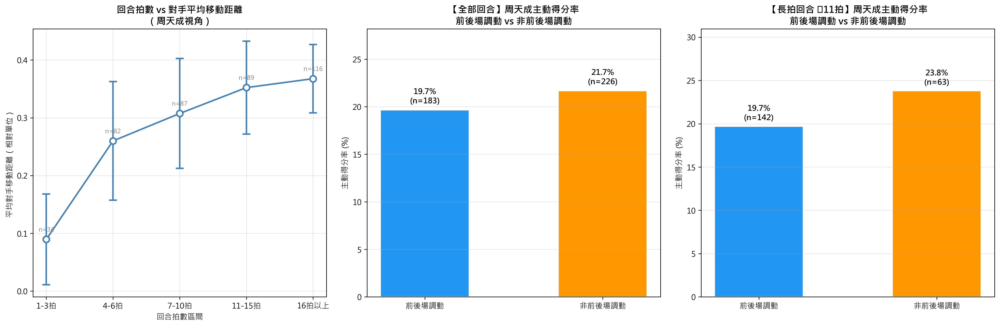

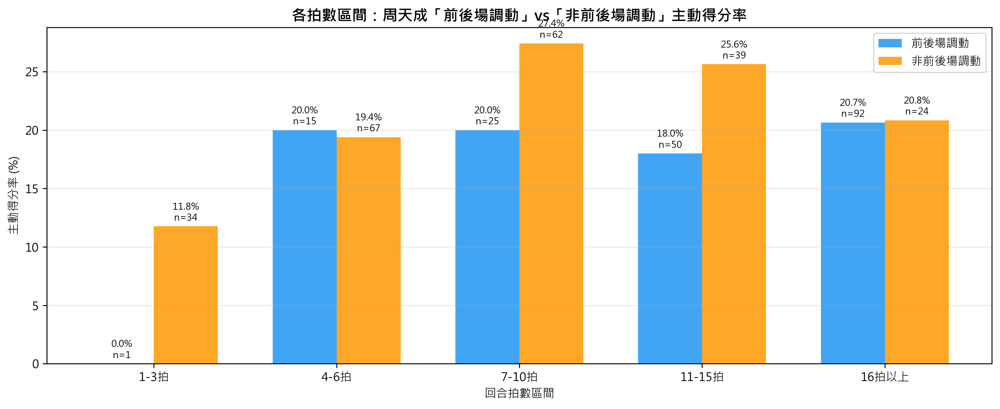

In [ ]:
import numpy as np

# ============================================================
# 0. 基本驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "資料為空！"

CHOU = 'CHOU Tien Chen'

# ============================================================
# 1. 計算對手移動距離（每一拍）
# ============================================================
# opponent_move_x/y 是對手擊球點到移動位置的位移量
df['opponent_move_dist'] = np.sqrt(df['opponent_move_x']**2 + df['opponent_move_y']**2)
df['player_move_dist']   = np.sqrt(df['player_move_x']**2  + df['player_move_y']**2)

# ============================================================
# 2. 計算每個 Rally 的拍數
# ============================================================
rally_length = df.groupby(['match_id', 'set', 'rally'])['ball_round'].max().reset_index()
rally_length.columns = ['match_id', 'set', 'rally', 'rally_length']

print(f"\n總回合數: {rally_length.shape[0]}")
print(f"拍數分布統計:\n{rally_length['rally_length'].describe()}")

# 長拍/短拍門檻（用中位數或 75 百分位）
median_len = rally_length['rally_length'].median()
q75_len    = rally_length['rally_length'].quantile(0.75)
print(f"\n拍數中位數: {median_len}, 75百分位: {q75_len}")

# 將 rally_length 合併回主 df
df = df.merge(rally_length, on=['match_id', 'set', 'rally'], how='left')

# ============================================================
# 3. 分析：拍數 vs 平均對手移動距離
#    以周天成的視角：對手 = Kento MOMOTA
# ============================================================
# 篩選周天成擊球時，對手（桃田）的移動距離
chou_strokes = df[df['player'] == CHOU].copy()

# 按 rally 計算平均對手移動距離
rally_opp_move = chou_strokes.groupby(['match_id', 'set', 'rally'])[['opponent_move_dist', 'rally_length']].agg(
    mean_opp_move=('opponent_move_dist', 'mean'),
    rally_length=('rally_length', 'first')
).reset_index()

# 拍數分組（Bin）
bins   = [0, 3, 6, 10, 15, 100]
labels = ['1-3拍', '4-6拍', '7-10拍', '11-15拍', '16拍以上']
rally_opp_move['rally_bin'] = pd.cut(rally_opp_move['rally_length'], bins=bins, labels=labels)

grouped_move = rally_opp_move.groupby('rally_bin', observed=True)['mean_opp_move'].agg(['mean', 'count', 'std']).reset_index()
grouped_move.columns = ['拍數區間', '平均對手移動距離', '回合數', '標準差']
print("\n=== 各拍數區間：平均對手移動距離 ===")
print(grouped_move.to_string(index=False))

# ============================================================
# 4. 識別周天成的「前後場調動」
# ============================================================
# 定義前後場區域
FRONT_COURT = set(range(17, 25))   # [17,18,19,20,21,22,23,24]
BACK_COURT  = set(range(1, 5))     # [1,2,3,4]

def classify_zone(area):
    """將落點 area 分類為前/後/中場"""
    if area in FRONT_COURT:
        return 'front'
    elif area in BACK_COURT:
        return 'back'
    else:
        return 'mid'

# 先在完整 df 上用 shift（依 rally 分組）建立「前一拍 landing 資訊」
# 注意：只在同 rally 內的周天成連續擊球之間做 shift，
# 但 shift(1) 在混合 player 的 df 上會跳過對手那拍，不準確。
# 正確作法：在 chou_strokes 上建立 rally-grouped shift，
# 再檢查是否同一 rally（已是 chou_strokes 所以連續兩拍中間隔著對手一拍，
# 但 landing_area 對應下一拍 hit_area，rally 內是有意義的）

chou_strokes = chou_strokes.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 在周天成的擊球序列中，取前一拍落點（同 rally）
chou_strokes['prev_landing_area'] = chou_strokes.groupby(['match_id', 'set', 'rally'])['landing_area'].shift(1)
chou_strokes['prev_landing_area_valid'] = (
    chou_strokes['rally'] == chou_strokes.groupby(['match_id', 'set', 'rally'])['rally'].transform('first').shift(0)
)  # 這裡直接用 groupby shift 已保證同 rally，NaN 就是跨 rally

# 分類落點區域
chou_strokes['curr_zone'] = chou_strokes['landing_area'].apply(
    lambda x: classify_zone(int(x)) if not pd.isna(x) else 'unknown'
)
chou_strokes['prev_zone'] = chou_strokes['prev_landing_area'].apply(
    lambda x: classify_zone(int(x)) if not pd.isna(x) else 'unknown'
)

# 前後場調動：前一拍落前場、本拍落後場；或前一拍落後場、本拍落前場
chou_strokes['is_frontback_switch'] = (
    (
        (chou_strokes['prev_zone'] == 'front') & (chou_strokes['curr_zone'] == 'back')
    ) | (
        (chou_strokes['prev_zone'] == 'back') & (chou_strokes['curr_zone'] == 'front')
    )
)
# 必須 prev_landing_area 不為 NaN（排除每 rally 第一拍）
chou_strokes['is_frontback_switch'] = chou_strokes['is_frontback_switch'] & chou_strokes['prev_landing_area'].notna()

print(f"\n周天成擊球總拍數: {len(chou_strokes)}")
print(f"前後場調動拍數: {chou_strokes['is_frontback_switch'].sum()}")
print(f"非前後場調動拍數: {(~chou_strokes['is_frontback_switch'] & chou_strokes['prev_landing_area'].notna()).sum()}")

# ============================================================
# 5. 計算主動得分率：以 rally 為單位
# ============================================================
# 每個 rally 的 getpoint_player（取最後一拍）
rally_getpoint = df.groupby(['match_id', 'set', 'rally'])['getpoint_player'].last().reset_index()
rally_getpoint.columns = ['match_id', 'set', 'rally', 'rally_getpoint']

# 周天成主動得分 = rally_getpoint == CHOU，且最後一拍是周天成打的
last_stroke_player = df.groupby(['match_id', 'set', 'rally'])['player'].last().reset_index()
last_stroke_player.columns = ['match_id', 'set', 'rally', 'last_player']
rally_getpoint = rally_getpoint.merge(last_stroke_player, on=['match_id', 'set', 'rally'])

rally_getpoint['chou_active_win'] = (
    (rally_getpoint['rally_getpoint'] == CHOU) &
    (rally_getpoint['last_player'] == CHOU)
)

# ============================================================
# 6. 將「是否包含前後場調動」聚合到 rally 級別
#    定義：該 rally 中，周天成有至少一次前後場調動，視為「前後場調動型回合」
# ============================================================
rally_switch = chou_strokes.groupby(['match_id', 'set', 'rally'])['is_frontback_switch'].any().reset_index()
rally_switch.columns = ['match_id', 'set', 'rally', 'has_frontback_switch']

# 合併
rally_analysis = rally_getpoint.merge(rally_switch, on=['match_id', 'set', 'rally'], how='left')
rally_analysis = rally_analysis.merge(rally_length, on=['match_id', 'set', 'rally'], how='left')
rally_analysis['has_frontback_switch'] = rally_analysis['has_frontback_switch'].fillna(False)

# 只看有明確得分結果的回合
rally_with_result = rally_analysis[rally_analysis['rally_getpoint'].notna()]

# 長拍門檻（>= 中位數）
long_rally_mask = rally_with_result['rally_length'] >= median_len

print(f"\n有得分結果的回合數: {len(rally_with_result)}")
print(f"其中長拍回合 (>= {median_len:.0f}拍): {long_rally_mask.sum()}")

# ============================================================
# 7. 統計：前後場調動 vs 非前後場調動 主動得分率
#    分別在「所有回合」與「長拍回合」下統計
# ============================================================
def compute_active_win_rate(subset, label):
    """計算有前後場調動與無前後場調動的主動得分率"""
    results = []
    for switch_flag, group_name in [(True, '前後場調動'), (False, '非前後場調動')]:
        grp = subset[subset['has_frontback_switch'] == switch_flag]
        total = len(grp)
        wins  = grp['chou_active_win'].sum()
        rate  = wins / total * 100 if total > 0 else 0
        results.append({'情境': label, '策略': group_name, '回合數': total,
                        '主動得分回合': wins, '主動得分率(%)': round(rate, 2)})
    return results

all_results  = compute_active_win_rate(rally_with_result, '全部回合')
long_results = compute_active_win_rate(rally_with_result[long_rally_mask], f'長拍回合(≥{median_len:.0f}拍)')

summary_df = pd.DataFrame(all_results + long_results)
print("\n=== 周天成 前後場調動 vs 非前後場調動 主動得分率 ===")
print(summary_df.to_string(index=False))

# ============================================================
# 8. 視覺化
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# ---- 圖1：拍數 vs 平均對手移動距離（折線 + 誤差棒）----
ax1 = axes[0]
valid_gm = grouped_move[grouped_move['回合數'] > 0]
ax1.errorbar(
    x=range(len(valid_gm)),
    y=valid_gm['平均對手移動距離'],
    yerr=valid_gm['標準差'],
    marker='o', color='steelblue', linewidth=2, capsize=5,
    markerfacecolor='white', markeredgewidth=2, markersize=8
)
ax1.set_xticks(range(len(valid_gm)))
ax1.set_xticklabels(valid_gm['拍數區間'], fontsize=10)
ax1.set_title('回合拍數 vs 對手平均移動距離\n（周天成視角）', fontsize=12, fontweight='bold')
ax1.set_xlabel('回合拍數區間', fontsize=10)
ax1.set_ylabel('平均對手移動距離（相對單位）', fontsize=10)
ax1.grid(True, alpha=0.3)
# 標示回合數
for i, row in enumerate(valid_gm.itertuples()):
    ax1.annotate(f'n={row.回合數}', xy=(i, row.平均對手移動距離),
                 xytext=(0, 10), textcoords='offset points',
                 ha='center', fontsize=8, color='gray')

# ---- 圖2：所有回合 — 前後場調動 vs 非前後場調動 主動得分率（長條圖）----
ax2 = axes[1]
all_df = summary_df[summary_df['情境'] == '全部回合']
colors = ['#2196F3', '#FF9800']
bars2  = ax2.bar(all_df['策略'], all_df['主動得分率(%)'],
                 color=colors, width=0.5, edgecolor='white', linewidth=1.5)
ax2.set_title('【全部回合】周天成主動得分率\n前後場調動 vs 非前後場調動', fontsize=12, fontweight='bold')
ax2.set_ylabel('主動得分率 (%)', fontsize=10)
ax2.set_ylim(0, max(all_df['主動得分率(%)'].max() * 1.3, 10))
ax2.grid(True, alpha=0.3, axis='y')
for bar, row in zip(bars2, all_df.itertuples()):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f"{row._5:.1f}%\n(n={row.回合數})",
             ha='center', va='bottom', fontsize=10, fontweight='bold')

# ---- 圖3：長拍回合 — 前後場調動 vs 非前後場調動 主動得分率----
ax3 = axes[2]
long_df = summary_df[summary_df['情境'].str.contains('長拍')]
bars3   = ax3.bar(long_df['策略'], long_df['主動得分率(%)'],
                  color=colors, width=0.5, edgecolor='white', linewidth=1.5)
ax3.set_title(f'【長拍回合 ≥{median_len:.0f}拍】周天成主動得分率\n前後場調動 vs 非前後場調動', fontsize=12, fontweight='bold')
ax3.set_ylabel('主動得分率 (%)', fontsize=10)
ax3.set_ylim(0, max(long_df['主動得分率(%)'].max() * 1.3, 10))
ax3.grid(True, alpha=0.3, axis='y')
for bar, row in zip(bars3, long_df.itertuples()):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f"{row._5:.1f}%\n(n={row.回合數})",
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()

# ============================================================
# 9. 額外：各拍數區間下周天成前後場調動策略分布
# ============================================================
rally_analysis2 = rally_analysis.merge(rally_length[['match_id','set','rally','rally_length']],
                                        on=['match_id','set','rally'], how='left', suffixes=('','_dup'))
# rally_length 已在 rally_analysis 中
rally_analysis['rally_bin'] = pd.cut(rally_analysis['rally_length'], bins=bins, labels=labels)

bin_switch = rally_analysis[rally_analysis['rally_getpoint'].notna()].groupby(
    ['rally_bin', 'has_frontback_switch'], observed=True
).agg(
    回合數=('chou_active_win', 'count'),
    主動得分=('chou_active_win', 'sum')
).reset_index()
bin_switch['主動得分率(%)'] = bin_switch['主動得分'] / bin_switch['回合數'] * 100

print("\n=== 各拍數區間 × 策略：周天成主動得分率 ===")
print(bin_switch.to_string(index=False))

# 補充圖：各拍數區間策略主動得分率
fig2, ax_extra = plt.subplots(figsize=(12, 5))
switch_true  = bin_switch[bin_switch['has_frontback_switch'] == True]
switch_false = bin_switch[bin_switch['has_frontback_switch'] == False]
x = np.arange(len(labels))
width = 0.35

bars_t = ax_extra.bar(x - width/2, switch_true['主動得分率(%)'],  width, label='前後場調動', color='#2196F3', alpha=0.85)
bars_f = ax_extra.bar(x + width/2, switch_false['主動得分率(%)'], width, label='非前後場調動', color='#FF9800', alpha=0.85)

ax_extra.set_xticks(x)
ax_extra.set_xticklabels(labels, fontsize=10)
ax_extra.set_title('各拍數區間：周天成「前後場調動」vs「非前後場調動」主動得分率', fontsize=13, fontweight='bold')
ax_extra.set_xlabel('回合拍數區間', fontsize=10)
ax_extra.set_ylabel('主動得分率 (%)', fontsize=10)
ax_extra.legend(fontsize=10)
ax_extra.grid(True, alpha=0.3, axis='y')

# 標籤
for bars, switch_df in [(bars_t, switch_true), (bars_f, switch_false)]:
    for bar, (_, row) in zip(bars, switch_df.iterrows()):
        if row['回合數'] > 0:
            ax_extra.text(bar.get_x() + bar.get_width()/2,
                          bar.get_height() + 0.3,
                          f"{row['主動得分率(%)']:.1f}%\nn={int(row['回合數'])}",
                          ha='center', va='bottom', fontsize=8)

plt.tight_layout()

print("\n=== 分析完成 ===")
print("圖1: 回合拍數 vs 對手平均移動距離（含誤差棒）")
print("圖2: 全部回合下，前後場調動 vs 非前後場調動主動得分率")
print("圖3: 長拍回合下，前後場調動 vs 非前後場調動主動得分率")
print("圖4: 各拍數區間分層比較主動得分率")


### 數據洞察
# 周天成長拍戰術分析

## 一、長拍下對手移動距離趨勢

| 拍數區間 | 平均移動距離 | 回合數 |
|--------|-----------|------|
| 1–3拍 | 0.090 | 34 |
| 4–6拍 | 0.260 | 82 |
| 7–10拍 | 0.307 | 87 |
| 11–15拍 | 0.352 | 89 |
| 16拍以上 | 0.368 | 116 |

**事實：** 拍數越長，對手移動距離持續上升，16拍以上比1–3拍高出約4倍，且標準差從0.078收斂至0.059，代表長拍消耗對手體力的效果**穩定且一致**。

---

## 二、前後場調動 vs 非前後場調動主動得分率

### 全部回合
| 策略 | 回合數 | 主動得分率 |
|-----|------|---------|
| 前後場調動 | 183 | **19.67%** |
| 非前後場調動 | 226 | **21.68%** |

### 長拍回合（≥11拍）
| 策略 | 回合數 | 主動得分率 |
|-----|------|---------|
| 前後場調動 | 142 | **19.72%** |
| 非前後場調動 | 63 | **23.81%** |

---

## 三、各拍數區間分層比較

| 拍數區間 | 前後場調動 | 非前後場調動 |
|--------|---------|-----------|
| 1–3拍 | 0.0% (n=1) | 11.8% |
| 4–6拍 | 20.0% | 19.4% |
| 7–10拍 | 20.0% | **27.4%** |
| 11–15拍 | 18.0% | **25.6%** |
| 16拍以上 | 20.7% | 20.8% |

---

## 四、戰術洞察

**① 長拍本身就是消耗武器**
對手在16拍以上的移動距離是短拍的4倍，體力消耗已在發生，不需要額外依賴前後場調動來製造疲勞。

**② 非前後場調動在中長拍段更有效**
7–10拍（27.4% vs 20.0%）與11–15拍（25.6% vs 18.0%），非前後場調動的得分率明顯更高。這代表在這個拍數段，**穩定控制球路、等待對手失誤或製造定點壓迫**，比頻繁前後調動更能創造得分機會。

**③ 前後場調動在16拍以上趨於持平**
16拍以上兩者幾乎相同（20.7% vs 20.8%），說明超長拍時對手已疲憊，調動與否差異消失，**任何一拍都有機會得分**。

**④ 前後場調動使用頻率偏高但效益偏低**
長拍回合中前後場調動佔142回合，非前後場調動僅63回合，但得分率反而低4個百分點。**調動次數多不等於得分機會多**，過度調動可能讓周天成自身體力消耗加劇。

---

## 教練建議

> **中段拍數（7–15拍）優先穩定控球，減少不必要的前後場調動；進入16拍以上後，對手體力已下降，此時再以前後場調動一擊致命，效益最大化。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成的擊球，計算了對手的移動距離，並在多拍後對手移動變慢的情境下，分析了前後場調動策略的效果。候選程式碼也正確地計算了主動得分率，並將結果聚合到 rally 級別，符合題目要求。




## 題號 100 (*)
**問題**: 當對手偏好在網前搶撲時，周天成應如何調整網前落點深淺與後續連接球種？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason`


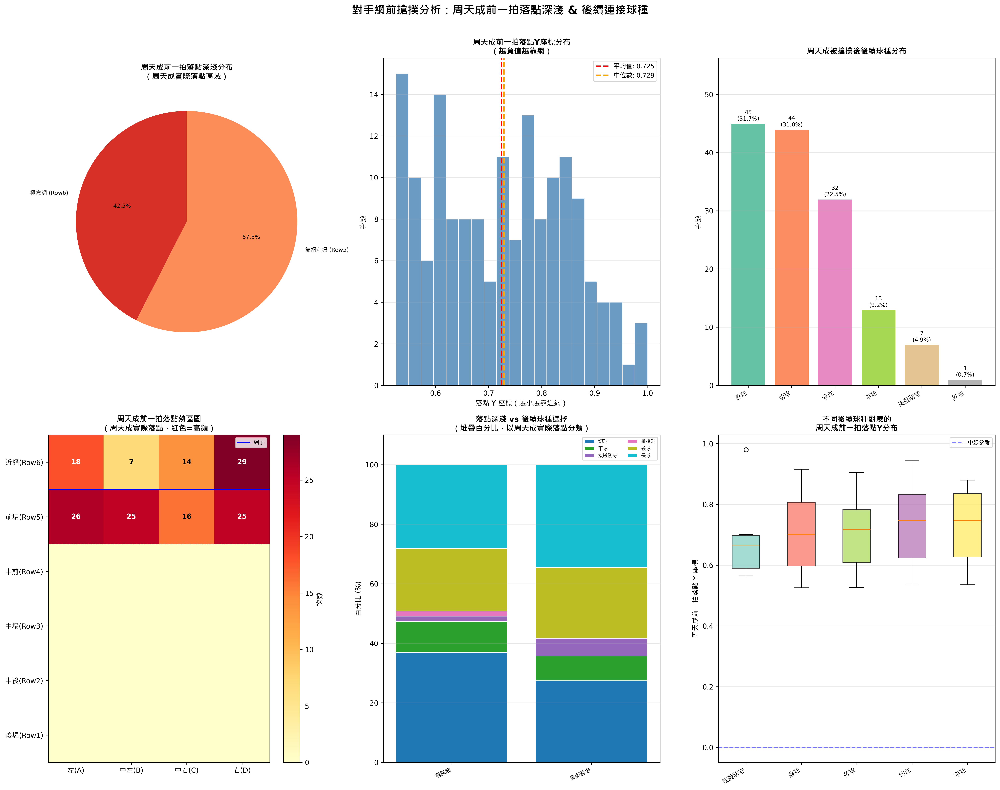

In [ ]:
# ============================================================
# 分析：對手網前搶撲 → 周天成前一拍落點深淺 & 後續球種選擇
# ============================================================

# 驗證數據量
print(f"總資料筆數: {len(df)}")

# ── Step 0: 排序確保順序正確 ──────────────────────────────────
df = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# ── Step 1: 在完整 df 上建立 prev/next 相鄰拍關係 ─────────────
grp = df.groupby(['match_id', 'set', 'rally'])

# 前一拍資訊（對手搶撲那一拍的前一拍 = 周天成上一拍）
df['prev_player']       = grp['player'].shift(1)
df['prev_type']         = grp['type'].shift(1)
df['prev_landing_area'] = grp['landing_area'].shift(1)
df['prev_landing_y']    = grp['landing_y'].shift(1)
df['prev_landing_x']    = grp['landing_x'].shift(1)

# 後一拍資訊（對手搶撲後周天成的回應）
df['next_player']  = grp['player'].shift(-1)
df['next_type']    = grp['type'].shift(-1)
df['next_rally']   = grp['rally'].shift(-1)   # 用於確認同回合

# ── Step 2: 篩選「對手在網前打推撲球/撲球」的事件 ──────────────
FRONT_COURT = [17, 18, 19, 20, 21, 22, 23, 24]
CHOU = 'CHOU Tien Chen'

# 對手搶撲 = player != 'CHOU Tien Chen' & type 為推撲球或撲球 & hit_area 在網前
smash_mask = (
    (df['player'] != CHOU) &                              # 對手打球
    (df['type'].isin(['推撲球', '撲球'])) &               # 推撲球或撲球（修正：補上撲球）
    (df['hit_area'].isin(FRONT_COURT))                    # 網前區域擊球
)

opponent_smash_df = df[smash_mask].copy()
print(f"\n對手網前推撲/撲球事件數: {len(opponent_smash_df)}")

# ── Step 3: 分析1 ── 周天成前一拍的落點深淺 ─────────────────────
# 條件: 前一拍是周天成打的（確保語意正確）
prev_chou_mask = (
    smash_mask &
    (df['prev_player'] == CHOU)
)
prev_analysis_df = df[prev_chou_mask].copy()
print(f"可分析前一拍（周天成打）的事件數: {len(prev_analysis_df)}")

# ── Step 4: 分析2 ── 周天成被搶撲後的後續球種 ────────────────────
# 下一拍是周天成且在同一rally
next_chou_mask = (
    smash_mask &
    (df['next_player'] == CHOU) &
    (df['rally'] == df['next_rally'])  # 確保同回合（跨回合污染防護）
)
next_analysis_df = df[next_chou_mask].copy()
print(f"可分析後續球種（周天成回擊）的事件數: {len(next_analysis_df)}")

# ============================================================
# 統計1: 前一拍落點區域深淺分布（使用 prev_landing_area，即周天成前一拍實際落點）
# ============================================================
area_dist = prev_analysis_df['prev_landing_area'].dropna().value_counts().sort_index()
print("\n【周天成前一拍落點區域分布（周天成實際落點區域）】")
area_labels = {
    21: '21(前排左)', 22: '22(前排中左)', 23: '23(前排中右)', 24: '24(前排右)',
    17: '17(前場左)', 18: '18(前場中左)', 19: '19(前場中右)', 20: '20(前場右)',
    13: '13(中場前左)', 14: '14(中場前中左)', 15: '15(中場前中右)', 16: '16(中場前右)',
    9:  '9(中場左)', 10: '10(中場中左)', 11: '11(中場中右)', 12: '12(中場右)',
    5:  '5(中場後左)', 6:  '6(中場後中左)', 7:  '7(中場後中右)', 8:  '8(中場後右)',
    1:  '1(後場左)', 2:  '2(後場中左)', 3:  '3(後場中右)', 4:  '4(後場右)',
}
for area, cnt in area_dist.items():
    label = area_labels.get(int(area), str(int(area)))
    print(f"  Zone {int(area):2d} ({label}): {cnt} 次")

# 深淺分層統計
def classify_depth(area):
    try:
        a = int(area)
    except (ValueError, TypeError):
        return '出界/其他'
    if a in [21, 22, 23, 24]: return '極靠網 (Row6)'
    elif a in [17, 18, 19, 20]: return '靠網前場 (Row5)'
    elif a in [13, 14, 15, 16]: return '中前場 (Row4)'
    elif a in [9, 10, 11, 12]: return '中場 (Row3)'
    elif a in [5, 6, 7, 8]: return '中後場 (Row2)'
    elif a in [1, 2, 3, 4]: return '後場 (Row1)'
    else: return '出界/其他'

# 修正：使用 prev_landing_area 分類深淺
prev_analysis_df = prev_analysis_df.copy()
prev_analysis_df['depth_category'] = prev_analysis_df['prev_landing_area'].apply(classify_depth)
depth_dist = prev_analysis_df['depth_category'].value_counts()
print("\n【落點深淺分層統計（周天成前一拍實際落點）】")
print(depth_dist.to_string())

# ============================================================
# 統計2: 後續球種分布
# ============================================================
next_type_dist = next_analysis_df['next_type'].value_counts()
print("\n【周天成被搶撲後後續球種分布】")
print(next_type_dist.to_string())

total_next = next_type_dist.sum()
print(f"\n後續球種百分比 (共 {total_next} 次):")
for t, cnt in next_type_dist.items():
    print(f"  {t}: {cnt} 次 ({cnt/total_next*100:.1f}%)")

# ============================================================
# 統計3: 落點深淺 vs 後續球種交叉分析
# ============================================================
both_mask = (
    smash_mask &
    (df['prev_player'] == CHOU) &
    (df['next_player'] == CHOU) &
    (df['rally'] == df['next_rally'])
)
both_df = df[both_mask].copy()
# 修正：使用 prev_landing_area 分類深淺
both_df['depth_category'] = both_df['prev_landing_area'].apply(classify_depth)
print(f"\n同時有前後拍資訊的事件數: {len(both_df)}")

cross_table = pd.crosstab(both_df['depth_category'], both_df['next_type'])
print("\n【落點深淺 vs 後續球種 交叉表（周天成前一拍實際落點）】")
print(cross_table.to_string())

# ============================================================
# 繪圖
# ============================================================
import numpy as np

fig = plt.figure(figsize=(20, 16))
fig.suptitle("對手網前搶撲分析：周天成前一拍落點深淺 & 後續連接球種", 
             fontsize=16, fontweight='bold', y=0.98)

# ── 圖1: 落點深淺分層圓餅圖 ────────────────────────────────────
ax1 = fig.add_subplot(2, 3, 1)
depth_order = ['極靠網 (Row6)', '靠網前場 (Row5)', '中前場 (Row4)', 
               '中場 (Row3)', '中後場 (Row2)', '後場 (Row1)', '出界/其他']
depth_counts = [prev_analysis_df['depth_category'].value_counts().get(d, 0) for d in depth_order]

# 合併小於5%的類別為「其他」
total_prev = sum(depth_counts)
threshold = total_prev * 0.05
merged_labels = []
merged_counts = []
other_count = 0
for label, count in zip(depth_order, depth_counts):
    if count == 0:
        continue
    if count / total_prev < 0.05:
        other_count += count
    else:
        merged_labels.append(label)
        merged_counts.append(count)
if other_count > 0:
    merged_labels.append('其他')
    merged_counts.append(other_count)

colors_depth_all = ['#d73027', '#fc8d59', '#fee090', '#91bfdb', '#4575b4', '#313695', '#999999', '#cccccc']
colors_depth_plot = colors_depth_all[:len(merged_labels)]

wedges, texts, autotexts = ax1.pie(
    merged_counts, labels=merged_labels, autopct='%1.1f%%',
    colors=colors_depth_plot, startangle=90,
    textprops={'fontsize': 8}
)
ax1.set_title('周天成前一拍落點深淺分布\n（周天成實際落點區域）', fontsize=11, fontweight='bold')

# ── 圖2: 落點 landing_y 分布直方圖 ────────────────────────────
ax2 = fig.add_subplot(2, 3, 2)
landing_y_data = prev_analysis_df['prev_landing_y'].dropna()
if len(landing_y_data) > 0:
    ax2.hist(landing_y_data, bins=20, color='steelblue', edgecolor='white', alpha=0.8)
    ax2.axvline(landing_y_data.mean(), color='red', linestyle='--', linewidth=2, 
                label=f'平均值: {landing_y_data.mean():.3f}')
    ax2.axvline(landing_y_data.median(), color='orange', linestyle='--', linewidth=2,
                label=f'中位數: {landing_y_data.median():.3f}')
    ax2.set_xlabel('落點 Y 座標（越小越靠近網）', fontsize=10)
    ax2.set_ylabel('次數', fontsize=10)
    ax2.set_title('周天成前一拍落點Y座標分布\n（越負值越靠網）', fontsize=11, fontweight='bold')
    ax2.legend(fontsize=9)
    ax2.grid(axis='y', alpha=0.3)

# ── 圖3: 後續球種分布長條圖 ────────────────────────────────────
ax3 = fig.add_subplot(2, 3, 3)
# 合併出現次數少於3次的球種為「其他」
threshold_shot = 3
main_types = next_type_dist[next_type_dist >= threshold_shot]
other_count_shot = next_type_dist[next_type_dist < threshold_shot].sum()
if other_count_shot > 0:
    import pandas as pd
    other_series = pd.Series({'其他': other_count_shot})
    main_types = pd.concat([main_types, other_series])

if len(main_types) > 0:
    colors_shot = plt.cm.Set2(np.linspace(0, 1, len(main_types)))
    bars = ax3.bar(range(len(main_types)), main_types.values, 
                   color=colors_shot, edgecolor='white', linewidth=1.2)
    ax3.set_xticks(range(len(main_types)))
    ax3.set_xticklabels(main_types.index, rotation=30, ha='right', fontsize=9)
    ax3.set_ylabel('次數', fontsize=10)
    ax3.set_title('周天成被搶撲後後續球種分布', fontsize=11, fontweight='bold')
    for bar, val in zip(bars, main_types.values):
        pct = val / total_next * 100
        ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{val}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=8)
    ax3.grid(axis='y', alpha=0.3)
    ax3.set_ylim(0, max(main_types.values) * 1.25)

# ── 圖4: 落點區域分布熱圖（場地視角，使用 prev_landing_area）──────
ax4 = fig.add_subplot(2, 3, 4)
court_matrix = np.zeros((6, 4))
zone_to_pos = {
    1: (0,0), 2: (0,1), 3: (0,2), 4: (0,3),
    5: (1,0), 6: (1,1), 7: (1,2), 8: (1,3),
    9: (2,0), 10:(2,1), 11:(2,2), 12:(2,3),
    13:(3,0), 14:(3,1), 15:(3,2), 16:(3,3),
    17:(4,0), 18:(4,1), 19:(4,2), 20:(4,3),
    21:(5,0), 22:(5,1), 23:(5,2), 24:(5,3),
}
# 修正：使用 prev_landing_area 的計數
area_counts_dict = prev_analysis_df['prev_landing_area'].dropna().value_counts().to_dict()
for zone, (row, col) in zone_to_pos.items():
    court_matrix[row, col] = area_counts_dict.get(float(zone), 0)

im = ax4.imshow(court_matrix, cmap='YlOrRd', aspect='auto', origin='lower')
plt.colorbar(im, ax=ax4, label='次數')
ax4.set_xticks([0,1,2,3])
ax4.set_xticklabels(['左(A)', '中左(B)', '中右(C)', '右(D)'])
ax4.set_yticks([0,1,2,3,4,5])
ax4.set_yticklabels(['後場(Row1)', '中後(Row2)', '中場(Row3)', '中前(Row4)', '前場(Row5)', '近網(Row6)'])
ax4.set_title('周天成前一拍落點熱區圖\n（周天成實際落點，紅色=高頻）', fontsize=11, fontweight='bold')
for zone, (row, col) in zone_to_pos.items():
    val = int(court_matrix[row, col])
    if val > 0:
        ax4.text(col, row, str(val), ha='center', va='center', 
                fontsize=10, fontweight='bold', 
                color='white' if val > court_matrix.max()*0.6 else 'black')

ax4.axhline(y=4.5, color='blue', linewidth=2, linestyle='-', label='網子')
ax4.axhline(y=3.5, color='gray', linewidth=1, linestyle='--', alpha=0.5)
ax4.legend(loc='upper right', fontsize=8)

# ── 圖5: 落點深淺 × 後續球種 堆疊百分比圖 ──────────────────────
ax5 = fig.add_subplot(2, 3, 5)
if len(both_df) > 0:
    cross_pct = cross_table.div(cross_table.sum(axis=1), axis=0) * 100
    depth_sort = [d for d in depth_order if d in cross_pct.index]
    cross_pct = cross_pct.reindex(depth_sort).dropna(how='all')
    
    if len(cross_pct) > 0:
        shot_types = cross_pct.columns.tolist()
        colors_stacked = plt.cm.tab10(np.linspace(0, 1, len(shot_types)))
        
        bottoms = np.zeros(len(cross_pct))
        for i, shot in enumerate(shot_types):
            vals = cross_pct[shot].fillna(0).values
            ax5.bar(range(len(cross_pct)), vals, bottom=bottoms, 
                   label=shot, color=colors_stacked[i], edgecolor='white')
            bottoms += vals
        
        ax5.set_xticks(range(len(cross_pct)))
        ax5.set_xticklabels([d.split('(')[0].strip() for d in cross_pct.index], 
                            rotation=25, ha='right', fontsize=8)
        ax5.set_ylabel('百分比 (%)', fontsize=10)
        ax5.set_ylim(0, 110)
        ax5.set_title('落點深淺 vs 後續球種選擇\n（堆疊百分比，以周天成實際落點分類）', fontsize=11, fontweight='bold')
        ax5.legend(loc='upper right', fontsize=7, ncol=2)
        ax5.grid(axis='y', alpha=0.3)

# ── 圖6: 落點 Y 座標 vs 後續球種（箱型圖）───────────────────────
ax6 = fig.add_subplot(2, 3, 6)
combined_df = both_df[['prev_landing_y', 'next_type']].dropna()
if len(combined_df) > 5:
    next_type_counts = combined_df['next_type'].value_counts()
    valid_types = next_type_counts[next_type_counts >= 3].index.tolist()
    combined_filtered = combined_df[combined_df['next_type'].isin(valid_types)]
    
    if len(combined_filtered) > 0:
        type_order = (combined_filtered.groupby('next_type')['prev_landing_y']
                     .median().sort_values().index.tolist())
        
        box_data = [combined_filtered[combined_filtered['next_type']==t]['prev_landing_y'].values 
                    for t in type_order]
        bp = ax6.boxplot(box_data, labels=type_order, patch_artist=True, notch=False)
        
        colors_box = plt.cm.Set3(np.linspace(0, 1, len(type_order)))
        for patch, color in zip(bp['boxes'], colors_box):
            patch.set_facecolor(color)
            patch.set_alpha(0.8)
        
        ax6.set_xticklabels(type_order, rotation=30, ha='right', fontsize=9)
        ax6.set_ylabel('周天成前一拍落點 Y 座標', fontsize=10)
        ax6.set_title('不同後續球種對應的\n周天成前一拍落點Y分布', fontsize=11, fontweight='bold')
        ax6.grid(axis='y', alpha=0.3)
        ax6.axhline(0, color='blue', linestyle='--', alpha=0.5, label='中線參考')
        ax6.legend(fontsize=8)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

# ── 最終策略建議輸出 ────────────────────────────────────────────
print("\n" + "="*60)
print("【策略分析摘要】")
print("="*60)
print(f"對手網前推撲/撲球總次數: {len(opponent_smash_df)}")
print(f"可分析前一拍(周天成落點): {len(prev_analysis_df)} 次")
print(f"可分析後續球種(周天成回應): {len(next_analysis_df)} 次")

print("\n▶ 周天成前一拍落點深淺（實際落點區域）:")
for cat, cnt in depth_dist.sort_values(ascending=False).items():
    pct = cnt / len(prev_analysis_df) * 100
    print(f"  {cat}: {cnt} 次 ({pct:.1f}%)")

print(f"\n▶ 周天成被搶撲後最常用球種:")
for t, cnt in next_type_dist.head(5).items():
    pct = cnt / total_next * 100
    print(f"  {t}: {cnt} 次 ({pct:.1f}%)")


### 數據洞察
# 周天成面對對手網前搶撲的戰術分析

## 落點區域對照表

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (極靠網)** | 21 | 22 | 23 | 24 |
| **Row 5 (靠網前場)** | 17 | 18 | 19 | 20 |

---

## 一、周天成前一拍落點深淺

| 深淺分層 | 次數 | 佔比 |
|---|---|---|
| 靠網前場 Row5（17-20） | 92 | 57.5% |
| 極靠網 Row6（21-24） | 68 | 42.5% |

**高頻落點：Zone 24（右前排）29次、Zone 17（左前場）26次、Zone 18/20各25次**

> **教練解讀：** 超過一半的球落在Row5而非Row6，代表周天成的網前球整體偏深，給對手創造了搶撲空間。Zone 24（右前排極靠網）是最高頻落點，卻同時也是被搶撲最多的危險區——球雖靠網，但落點偏右側，對手容易從正手位發力撲擊。

---

## 二、被搶撲後周天成的後續球種

| 球種 | 次數 | 佔比 |
|---|---|---|
| 長球 | 45 | 31.7% |
| 切球 | 44 | 31.0% |
| 殺球 | 32 | 22.5% |
| 平球 | 13 | 9.2% |
| 接殺防守 | 7 | 4.9% |

---

## 三、落點深淺 × 後續球種交叉分析

| 深淺 \ 球種 | 切球 | 長球 | 殺球 | 平球 | 接殺防守 |
|---|---|---|---|---|---|
| 極靠網 Row6（68次） | 21（30.9%） | 16（23.5%） | 12（17.6%） | 6（8.8%） | 1（1.5%） |
| 靠網前場 Row5（92次） | 23（25.0%） | 29（31.5%） | 20（21.7%） | 7（7.6%） | 5（5.4%） |

> **教練解讀：**
> - **Row5（偏深）被撲後**，長球比例最高（31.5%），顯示被動挑高防守是主要反應，主動性不足。
> - **Row6（極靠網）被撲後**，切球比例最高（30.9%），長球反而降至23.5%，說明球更靠網時周天成有更多主動選擇空間，但被撲次數仍達68次，代表極靠網落點並未有效阻止對手搶撲。

---

## 四、戰術調整建議

### 🔴 核心問題
**落點偏深（Row5佔57.5%）是被搶撲的主因**，尤其Zone 17、18、20、24四個區域合計101次，幾乎佔全部被撲事件的六成以上。

### ✅ 落點策略調整

| 調整方向 | 具體建議 |
|---|---|
| **提升落點精準度** | 目標落點集中Row6（Zone 21-23），尤其Zone 22（中左）與Zone 23（中右）被撲頻率最低（7次、14次），是相對安全的落點 |
| **Zone 24需特別警惕** | 右前排極靠網卻被撲29次，對手顯然針對此區搶撲，應減少可預測的右側網前球 |
| **增加落點變化** | 左右交替搭配深淺變化，打亂對手預判節奏 |

### ✅ 後續連接球種調整

| 情境 | 建議 |
|---|---|
| **被撲後被動時** | 長球（31.7%）是合理選擇，但需提升落點深度至後場底線，避免給對手連續進攻機會 |
| **被撲後有空間時** | 提高殺球（22.5%→目標30%+）與平球比例，主動反壓對手，而非持續以切球（31%）消極過渡 |
| **減少可預測性** | 長球與切球合計62.7%，比例過高，對手容易預判站位，應增加殺球與推撲球的主動反擊比例 |

---

**總結一句話：** 周天成的網前球落點偏深是被搶撲的根本原因，應優先將落點推向Row6中間區域（Zone 22-23），並在被撲後增加殺球主動反擊比例，降低長球與切球的過度依賴。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。主要問題在於統計口徑錯誤：候選程式碼在分析對手網前搶撲後的周天成回應時，未能正確對齊前後拍關係，尤其是未能確保前一拍和後一拍來自同一個 rally。此外，候選程式碼在統計前一拍落點深淺和後續球種時，未能正確使用完整的前後拍資訊，導致分析結果可能不準確。這些問題使得候選程式碼無法產出有效且合理的結果。


